# 이야기담 — 동작을 내 그림에 입히기 (15-joint RTMPose → GIF)
**위에서부터 순서대로 실행.** GPU 런타임 권장 (없으면 CPU로도 실행됨)

- 1번: Drive 마운트 + mmpose 환경 복원 (Drive `yiyagidam/deploy`의 내 모델·config 사용)
- 2번: 애니메이션 스크립트 생성
- 3번: 스크립트 패치 (CPU 대응, `--seq-fps`, 상대 동작 `--relative`, 제자리 `--no-root`, 절대 동작 + 서서히 전환 `--blend-in`, 그림을 따라 잰 거리 가중치 `--skin geo`)
- 4번: 배경 분리 (배경 제거 모델 IS-Net + 내 포즈 모델, 실패 시 기존 방식)
- 5-1번: 서비스 동작 15개 추가 (`cand.zip`)
- **5-2번: BVH 동작 변환** — 기존 6개(손 흔들기, 팔 벌려 뛰기, 댑, 점프, 춤, 좀비) + 서비스 동작 15개
- 6번: 그림 업로드 → 배경 분리 → 동작 입히기
- 7번: 결과 내려받기
- 평가: 동작 성능 확인 (재검출 PCK, 면적, 떨림)

## 1. Drive + 환경 복원

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"

# 학습 때 쓴 dataset_info / config를 Drive(deploy)에서 복원
D = '/content/drive/MyDrive/yiyagidam/deploy'
!cp {D}/drawing15.py /content/mmpose/configs/_base_/datasets/drawing15.py
!cp {D}/drawing15_full.py /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py
!ls -la {D}
!MPLBACKEND=Agg {E} python -c "import torch, mmpose; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available())"

Mounted at /content/drive
/content
accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: ...working... done
Channels:
 - defaults
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/mmpose_env

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.11.5  |       h59cdc77_0         113 KB
    libnsl-2.0.0               |       h5eee18b_0          31 KB
    packaging-26.3             |  py310h06a4308_0         329 KB
    pip-26.2.2                 |     pyhc872135_0         1.1 MB
    python-3.10.22             |       hd9cb797_1        24.4 MB
    setuptools-84.2.1          |  py310h06a4308_0         1.0 M

## 2. 애니메이션 스크립트 생성

In [2]:
%%writefile /content/animate_drawing.py
"""손그림 + 15-joint 예측 -> 움직이는 GIF.

사용 (Colab, mmpose_env 안에서):
  # 1) test set에서 랜덤 6장 (GT bbox 사용)
  python animate_drawing.py --from-test 6
  # 2) 내가 올린 그림 (bbox 생략 = 이미지 전체)
  python animate_drawing.py --src /content/test_imgs
  # 3) 모델 없이 합성 막대인간 데모
  python animate_drawing.py --demo
"""
import os, sys, glob, json, argparse, random
os.environ.setdefault('MPLBACKEND', 'Agg')
import numpy as np, cv2
from PIL import Image

D = '/content/drive/MyDrive/yiyagidam/deploy'
CFG = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py'
CKPT = f'{D}/rtmpose-m_drawing15_ep30.pth'

# 0 nose 1 neck 2 r_sho 3 r_elb 4 r_wri 5 l_sho 6 l_elb 7 l_wri 8 pelvis
# 9 r_hip 10 r_knee 11 r_ankle 12 l_hip 13 l_knee 14 l_ankle
PARENT = {1: 8, 0: 1, 2: 1, 3: 2, 4: 3, 5: 1, 6: 5, 7: 6,
          9: 8, 10: 9, 11: 10, 12: 8, 13: 12, 14: 13}
ORDER = [8, 1, 0, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14]   # 부모가 항상 먼저
BONES = [(p, c) for c, p in PARENT.items()]
TIPS = {0, 4, 7, 11, 14}      # 끝마디(머리/손/발)는 가중치 계산 때 조금 연장
SKEL = [(0, 1), (1, 2), (2, 3), (3, 4), (1, 5), (5, 6), (6, 7), (1, 8),
        (8, 9), (9, 10), (10, 11), (8, 12), (12, 13), (13, 14)]


# ---------------------------------------------------------------- motions
def _rot(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s], [s, c]])


def _toward(rest, a, b, vec=(0.0, -1.0)):
    """a->b 뼈대를 vec 방향으로 돌리기 위한 부호있는 각도(rad). 기본은 위쪽."""
    d = rest[b] - rest[a]
    ang = np.arctan2(d[1], d[0])           # 화면 좌표(y 아래)
    tgt = np.arctan2(vec[1], vec[0])
    return (tgt - ang + np.pi) % (2 * np.pi) - np.pi


def _to_up(rest, a, b):
    return _toward(rest, a, b)


def _out(rest, hip):
    """골반 기준 바깥(좌/우) 방향 부호."""
    return 1.0 if rest[hip][0] >= rest[8][0] else -1.0


def motion(name, t, rest):
    """t in [0,1) (한 사이클). 관절별 회전(rad) dict와 루트 이동(px) 반환."""
    th = {j: 0.0 for j in range(15)}
    tr = np.zeros(2)
    S = np.ptp(rest[:, 1]) + 1e-6          # 몸 높이
    w = 2 * np.pi * t
    deg = np.deg2rad
    if name == 'wave':                      # 오른팔 들고 흔들기 + 살짝 흔들
        th[2] = 0.85 * _to_up(rest, 2, 3)
        th[3] = deg(32) * np.sin(2 * w)
        th[1] = deg(3) * np.sin(w)
    elif name == 'dance':                   # 양팔 들썩 + 몸 바운스 + 다리 번갈아
        tr[1] = -0.04 * S * abs(np.sin(w))
        th[8] = deg(5) * np.sin(w)
        th[2] = 0.55 * _to_up(rest, 2, 3) * (0.5 + 0.5 * np.sin(w))
        th[5] = 0.55 * _to_up(rest, 5, 6) * (0.5 + 0.5 * np.sin(w + np.pi))
        th[3] = deg(20) * np.sin(2 * w); th[6] = deg(-20) * np.sin(2 * w)
        th[9] = deg(14) * np.sin(w);   th[12] = deg(-14) * np.sin(w)
        th[0 + 1] = deg(-6) * np.sin(w)
    elif name == 'walk':                    # 제자리 걷기: 팔다리 교차 스윙
        tr[1] = -0.015 * S * abs(np.sin(2 * w))
        a = deg(24) * np.sin(w)
        th[9], th[12] = a, -a
        th[10], th[13] = deg(18) * max(0, np.sin(w + 1.2)), deg(18) * max(0, -np.sin(w + 1.2))
        th[2], th[5] = -deg(22) * np.sin(w), deg(22) * np.sin(w)
    elif name == 'cheer':                   # 만세 + 손 흔들기 + 가벼운 바운스
        h = abs(np.sin(w))
        tr[1] = -0.03 * S * h
        th[2] = 0.9 * _to_up(rest, 2, 3); th[5] = 0.9 * _to_up(rest, 5, 6)
        th[3] = deg(18) * np.sin(2 * w); th[6] = -deg(18) * np.sin(2 * w)
    elif name == 'jump':                    # 점프: 몸 위로 + 팔 위로 + 다리 벌리기
        h = max(0.0, np.sin(w))
        tr[1] = -0.18 * S * h
        th[2] = 0.8 * _to_up(rest, 2, 3) * h; th[5] = 0.8 * _to_up(rest, 5, 6) * h
        th[9] = 0.35 * _toward(rest, 9, 10, (_out(rest, 9), 0.6)) * h
        th[12] = 0.35 * _toward(rest, 12, 13, (_out(rest, 12), 0.6)) * h
    elif name == 'kick':                    # 오른발 차기 (오른쪽 다리가 옆으로)
        h = max(0.0, np.sin(w))
        th[9] = 0.75 * _toward(rest, 9, 10, (_out(rest, 9), -0.1)) * h
        th[10] = 0.0
        th[2] = 0.5 * _toward(rest, 2, 3, (-_out(rest, 9), 0.0)) * h
        th[8] = deg(-6) * h * _out(rest, 9)
    elif name == 'squat':                   # 스쿼트: 몸 내려가며 다리 벌어짐, 팔 앞으로
        q = 0.5 - 0.5 * np.cos(w)
        tr[1] = 0.07 * S * q
        th[9] = 0.45 * _toward(rest, 9, 10, (_out(rest, 9), 0.5)) * q
        th[12] = 0.45 * _toward(rest, 12, 13, (_out(rest, 12), 0.5)) * q
        th[2] = 0.5 * _toward(rest, 2, 3, (_out(rest, 2), 0.0)) * q
        th[5] = 0.5 * _toward(rest, 5, 6, (_out(rest, 5), 0.0)) * q
    else:
        raise ValueError(name)
    return th, tr


def pose(rest, th, tr):
    """FK: 관절 회전 -> 뼈대별 (회전, 현재 부모위치)와 새 관절 좌표."""
    pos = rest.copy().astype(np.float64)
    cum = {}
    pos[8] = rest[8] + tr
    cum[8] = th[8]
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cum[p]) @ (rest[j] - rest[p])
        cum[j] = cum[p] + th[j]
    cb = {(PARENT[c], c): cum[PARENT[c]] for c in PARENT}      # 뼈대별 회전
    return pos, cb


def _wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def retarget(rest, kt, amount):
    """다른 그림의 관절 kt 자세를 따라가는 뼈대별 회전(rest->target, amount 0~1)."""
    cb = {}
    for c, p in PARENT.items():
        dr, dt = rest[c] - rest[p], kt[c] - kt[p]
        cb[(p, c)] = amount * _wrap(np.arctan2(dt[1], dt[0]) - np.arctan2(dr[1], dr[0]))
    return cb


def pose_from_bones(rest, cb, tr=np.zeros(2)):
    pos = rest.copy().astype(np.float64)
    pos[8] = rest[8] + tr
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cb[(p, j)]) @ (rest[j] - rest[p])
    return pos


# ---------------------------------------------------------------- warp
def seg_dist(P, a, b):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab + 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)


def extend(a, b, f=0.3):
    return b + (b - a) * f


def bind(crop, rest, S, up=2):
    """잉크 픽셀을 up배 확대해 뽑고, 휴식자세 기준 뼈대 가중치를 한 번만 계산."""
    big = cv2.resize(crop, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    g = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY).astype(np.int16)
    bgc = np.median(big.reshape(-1, 3)[::97], axis=0)
    bgg = int(np.median(g[::7, ::7]))
    ys, xs = np.nonzero(g < bgg - 30)
    P = np.stack([xs, ys], 1).astype(np.float64) / up        # crop 좌표계
    col = big[ys, xs]
    eps = (0.02 * S) ** 2
    Wt = np.zeros((len(P), len(BONES)))
    for k, (p, c) in enumerate(BONES):
        b = extend(rest[p], rest[c]) if c in TIPS else rest[c]
        Wt[:, k] = 1.0 / (seg_dist(P, rest[p], b) ** 2 + eps) ** 3
    Wt /= Wt.sum(1, keepdims=True)
    return dict(P=P, col=col, W=Wt, bg=tuple(int(v) for v in bgc), up=up, shape=big.shape)


def render(B, rest, pos, cum):
    up = B['up']; H, Wd = B['shape'][:2]
    new = np.zeros_like(B['P'])
    for k, (p, c) in enumerate(BONES):
        R = _rot(cum[(p, c)])
        new += B['W'][:, k:k + 1] * (pos[p] + (B['P'] - rest[p]) @ R.T)
    ix = np.round(new[:, 0] * up).astype(int); iy = np.round(new[:, 1] * up).astype(int)
    ok = (ix >= 0) & (ix < Wd) & (iy >= 0) & (iy < H)
    canvas = np.empty((H, Wd, 3), np.uint8); canvas[:] = B['bg']
    canvas[iy[ok], ix[ok]] = B['col'][ok]
    canvas = cv2.erode(canvas, np.ones((2, 2), np.uint8))        # 늘어난 틈 메우기
    return cv2.resize(canvas, (Wd // up, H // up), interpolation=cv2.INTER_AREA)


def prep(img, kp, bbox, out=512, pad=0.35):
    """bbox 주변을 잘라 long side=out 으로 맞추고 kp도 같이 변환."""
    H, W = img.shape[:2]
    x1, y1, x2, y2 = bbox
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    s = max(x2 - x1, y2 - y1) * (1 + pad * 2)
    bg = tuple(int(v) for v in np.median(img.reshape(-1, 3)[::97], axis=0))
    M = np.array([[out / s, 0, out / 2 - cx * out / s], [0, out / s, out / 2 - cy * out / s]], np.float32)
    crop = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_AREA, borderMode=cv2.BORDER_CONSTANT, borderValue=bg)
    kp2 = kp @ M[:, :2].T + M[:, 2]
    return crop, kp2, out * (np.ptp(kp2[:, 1]) + np.ptp(kp2[:, 0])) / 2 / out


def make_gif(img, kp, bbox, path, motions=('wave', 'dance', 'walk'), n=36, fps=25, out=512, targets=()):
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    frames = []
    for m in motions:
        for i in range(n):
            th, tr = motion(m, i / n, rest)
            pos, cum = pose(rest, th, tr)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cum), cv2.COLOR_BGR2RGB)))
    for kt in targets:                       # 다른 그림의 자세로 갔다가 돌아오기
        kt = _fit(np.asarray(kt, np.float64), rest)
        for i in range(n):
            a = 0.5 - 0.5 * np.cos(2 * np.pi * i / n)
            a = min(1.0, a * 1.15)
            cb = retarget(rest, kt, a)
            pos = pose_from_bones(rest, cb)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def overlay(img, kp, thr_pts=None):
    v = img.copy()
    for a, b in SKEL:
        cv2.line(v, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (0, 128, 255), 2)
    for x, y in kp:
        cv2.circle(v, (int(x), int(y)), 3, (0, 0, 255), -1)
    return v


def _fit(kt, rest):
    """자세만 쓰므로 위치/크기 무시(방향만 사용). 형태 그대로 반환."""
    return kt



def smooth_seq(seq, k=5):
    """프레임 방향 이동평균으로 떨림 제거. seq: (T,15,2)"""
    if k <= 1 or len(seq) < k:
        return seq
    pad = k // 2
    p = np.concatenate([np.repeat(seq[:1], pad, 0), seq, np.repeat(seq[-1:], pad, 0)])
    return np.stack([p[i:i + len(seq)] for i in range(k)]).mean(0)


def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True):
    """seq(T,15,2): 영상/모캡에서 얻은 관절 시퀀스를 그림에 입힌다 (뼈대 방향 retarget)."""
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    seq = np.asarray(seq, np.float64).copy()
    if mirror:
        seq[:, :, 0] *= -1
        sw = [0, 1, 5, 6, 7, 2, 3, 4, 8, 12, 13, 14, 9, 10, 11]      # 좌우 관절 교환
        seq = seq[:, sw]
    body = max(np.ptp(seq[0, :, 1]), 1.0)
    frames = []
    for t in range(len(seq)):
        cb = retarget(rest, seq[t], 1.0)
        tr = (seq[t, 8] - seq[0, 8]) * (np.ptp(rest[:, 1]) / body) if follow_root else np.zeros(2)
        pos = pose_from_bones(rest, cb, tr)
        frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def c17to15(k):
    m = lambda a, b: (k[a] + k[b]) / 2
    return np.stack([k[0], m(5, 6), k[6], k[8], k[10], k[5], k[7], k[9], m(11, 12),
                     k[12], k[14], k[16], k[11], k[13], k[15]])


def extract_seq(video, max_frames=150, stride=None):
    """영상 -> (T,15,2) 관절 시퀀스. COCO-17 사전학습 RTMPose + 이전 프레임 기반 bbox 추적."""
    from mmpose.apis import init_model, inference_topdown
    cfg = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/rtmpose-m_8xb256-420e_coco-256x192.py'
    ck = '/content/rtmpose-m_coco-256x192.pth'
    model = init_model(cfg, ck, device='cuda:0')
    cap = cv2.VideoCapture(video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    stride = stride or max(1, int(round(n / max_frames)))
    seq, bb, i = [], None, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if i % stride == 0:
            h, w = fr.shape[:2]
            box = bb if bb is not None else np.array([0, 0, w, h], np.float32)
            r = inference_topdown(model, fr, bboxes=box[None], bbox_format='xyxy')
            k = r[0].pred_instances.keypoints[0]
            seq.append(c17to15(k))
            x1, y1 = k.min(0); x2, y2 = k.max(0)
            cx, cy, sz = (x1 + x2) / 2, (y1 + y2) / 2, max(x2 - x1, y2 - y1) * 0.75 + 20
            bb = np.array([max(0, cx - sz), max(0, cy - sz), min(w, cx + sz), min(h, cy + sz)], np.float32)
        i += 1
    cap.release()
    return np.stack(seq), fps / stride


# ---------------------------------------------------------------- demo (모델 없이)
def synth():
    im = np.full((500, 400, 3), 250, np.uint8)
    kp = np.array([[200, 90], [200, 160], [160, 165], [120, 215], [90, 270], [240, 165], [280, 215], [310, 270],
                   [200, 290], [180, 292], [170, 370], [165, 450], [220, 292], [230, 370], [235, 450]], np.float64)
    for a, b in SKEL:
        cv2.line(im, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (200, 100), 40, (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (186, 92), 3, (30, 30, 30), -1); cv2.circle(im, (214, 92), 3, (30, 30, 30), -1)
    cv2.ellipse(im, (200, 112), (14, 7), 0, 0, 180, (30, 30, 30), 2, cv2.LINE_AA)
    return im, kp, (60, 40, 340, 470)


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--src'); ap.add_argument('--from-test', type=int, default=0)
    ap.add_argument('--demo', action='store_true')
    ap.add_argument('--out', default='/content/anim_out')
    ap.add_argument('--motions', default='wave,dance,walk')
    ap.add_argument('--seed', type=int, default=0)
    ap.add_argument('--pose-from-test', type=int, default=0, help='test set의 다른 그림 K개 자세를 따라 하기')
    ap.add_argument('--pose-img', help='이 이미지(들)의 예측 자세를 따라 하기 (파일/폴더)')
    ap.add_argument('--demo-poses', action='store_true')
    ap.add_argument('--video', help='이 영상의 동작을 그림에 입히기 (mp4 등)')
    ap.add_argument('--seq', help='(T,15,2) .npy 관절 시퀀스 (모캡을 2D로 투영한 것 등)')
    ap.add_argument('--mirror', action='store_true', help='좌우 반전')
    ap.add_argument('--save-seq', help='영상에서 뽑은 시퀀스를 .npy로 저장')
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    motions = a.motions.split(',')

    if a.demo:
        im, kp, bb = synth()
        if a.seq:
            print(make_gif_seq(im, kp, bb, f'{a.out}/demo_seq.gif', smooth_seq(np.load(a.seq)), mirror=a.mirror)); return
        tg = []
        if a.demo_poses:     # 합성 목표 자세 2개
            t1 = kp.copy(); t1[[3, 4]] = kp[2] + np.array([[0, -50], [0, -110]])      # 오른팔 들기
            t1[[6, 7]] = kp[5] + np.array([[60, -30], [110, -70]])
            t2 = kp.copy(); t2[[10, 11]] = kp[9] + np.array([[-70, 40], [-130, 60]])  # 다리 벌리기
            t2[[13, 14]] = kp[12] + np.array([[70, 40], [130, 60]])
            tg = [t1, t2]
        print(make_gif(im, kp, bb, f'{a.out}/demo.gif', motions if motions != [''] else [], targets=tg))
        return

    from mmpose.apis import init_model, inference_topdown
    SEQ, SFPS = None, 25
    if a.video:
        SEQ, SFPS = extract_seq(a.video)
        print('video seq', SEQ.shape, 'fps', SFPS)
        if a.save_seq: np.save(a.save_seq, SEQ)
    elif a.seq:
        SEQ = np.load(a.seq)
    if SEQ is not None:
        SEQ = smooth_seq(SEQ)
    model = init_model(CFG, CKPT, device='cuda:0')
    jobs = []   # (name, path, bbox or None)
    if a.from_test:
        coco = json.load(open('/content/test_coco.json'))
        files = {i['id']: i['file_name'] for i in coco['images']}
        random.Random(a.seed).shuffle(coco['annotations'])
        for an in coco['annotations'][:a.from_test]:
            x, y, w, h = an['bbox']
            jobs.append((f"test_{an['image_id']}", '/content/data_small/' + files[an['image_id']], [x, y, x + w, y + h]))
    if a.src:
        fs = sorted(sum([glob.glob(os.path.join(a.src, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.src) else [a.src]
        jobs += [(os.path.splitext(os.path.basename(f))[0], f, None) for f in fs]

    targets = []
    if a.pose_from_test:
        coco2 = json.load(open('/content/test_coco.json'))
        random.Random(a.seed + 1).shuffle(coco2['annotations'])
        for an in coco2['annotations'][:a.pose_from_test]:
            targets.append(np.array(an['keypoints']).reshape(15, 3)[:, :2])
    if a.pose_img:
        pf = sorted(sum([glob.glob(os.path.join(a.pose_img, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.pose_img) else [a.pose_img]
        for f in pf:
            h0, w0 = cv2.imread(f).shape[:2]
            r = inference_topdown(model, f, bboxes=np.array([[0, 0, w0, h0]], np.float32), bbox_format='xyxy')
            targets.append(r[0].pred_instances.keypoints[0])

    for name, f, bb in jobs:
        im = cv2.imread(f)
        h, w = im.shape[:2]
        bb = bb or [0, 0, w, h]
        res = inference_topdown(model, f, bboxes=np.array([bb], np.float32), bbox_format='xyxy')
        kp = res[0].pred_instances.keypoints[0]
        sc = float(res[0].pred_instances.keypoint_scores[0].mean())
        gif = make_gif(im, kp, bb, f'{a.out}/{name}.gif', [m for m in motions if m], targets=targets) if (motions != [''] or targets) else '-'
        if SEQ is not None:
            make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror)
        cv2.imwrite(f'{a.out}/{name}_pose.jpg', overlay(im, kp))
        print(f'{name}: mean score {sc:.2f} -> {gif}')


if __name__ == '__main__':
    main()

Writing /content/animate_drawing.py


## 3. 스크립트 패치
여러 번 실행해도 안전.

In [3]:
from pathlib import Path
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
# ① GPU 없으면 CPU로 (그림 몇 장 추론은 CPU도 충분)
if "DEV = " not in s:
    head = "D = '/content/drive/MyDrive/yiyagidam/deploy'"
    assert head in s
    s = s.replace(head, head + "\ntry:\n    import torch\n    DEV = 'cuda:0' if torch.cuda.is_available() else 'cpu'\n"
                              "except Exception:\n    DEV = 'cpu'", 1)
    s = s.replace("device='cuda:0'", "device=DEV")
# ② --seq 시퀀스의 fps 지정 (추출한 동작은 15fps, 기존 코드는 25fps로 가정)
if "--seq-fps" not in s:
    a, b = "    ap.add_argument('--mirror'", "    elif a.seq:\n        SEQ = np.load(a.seq)\n"
    assert a in s and b in s
    s = s.replace(a, "    ap.add_argument('--seq-fps', type=float, default=25, help='--seq 시퀀스 fps')\n" + a, 1)
    s = s.replace(b, "    elif a.seq:\n        SEQ, SFPS = np.load(a.seq), a.seq_fps\n", 1)
p.write_text(s, encoding="utf-8")
print("패치 완료 | 장치:", "DEV" in s, "| --seq-fps:", "--seq-fps" in s)

패치 완료 | 장치: True | --seq-fps: True


In [4]:
from pathlib import Path
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
if "relative=False" not in s:
    # ① 상대 동작: 첫 프레임 대비 각 뼈의 '회전량'만 입힘 (그림의 원래 자세에서 출발)
    # ② 루트 이동 끄기: 카메라 쪽으로 걸어오는 영상은 위치/크기가 원근으로 변해 그림이 화면 밖으로 나감
    a = "def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True):"
    b = "        cb = retarget(rest, seq[t], 1.0)\n"
    assert a in s and b in s
    s = s.replace(a, "def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True, relative=False):", 1)
    s = s.replace(b, "        cb = ({k: _wrap(v - cb0[k]) for k, v in retarget(rest, seq[t], 1.0).items()}\n"
                     "              if relative else retarget(rest, seq[t], 1.0))\n", 1)
    c = "    body = max(np.ptp(seq[0, :, 1]), 1.0)\n"
    assert c in s
    s = s.replace(c, c + "    cb0 = retarget(rest, seq[0], 1.0)\n", 1)
    d = "    ap.add_argument('--mirror'"
    s = s.replace(d, "    ap.add_argument('--relative', action='store_true', help='첫 프레임 대비 움직임만 입힘')\n"
                     "    ap.add_argument('--no-root', action='store_true', help='몸 이동 끄기 (제자리)')\n" + d, 1)
    e = "make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror)"
    assert e in s
    s = s.replace(e, "make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror,\n"
                     "                         follow_root=not a.no_root, relative=a.relative)", 1)
p.write_text(s, encoding="utf-8")
print("패치 완료 | --relative:", "--relative" in s, "| --no-root:", "--no-root" in s)

패치 완료 | --relative: True | --no-root: True


### 3-3. 추가 패치: 절대 동작 + 서서히 전환 (`--blend-in`)
상대 동작(`--relative`)은 그림의 원래 자세에 동작의 **회전량**만 더한다. 그래서 그림은 팔을 옆으로 뻗고 있는데 동작은 팔을 내린 자세에서 시작하면, 동작이 팔을 머리 위로 올릴 때(180° 회전) 그림의 팔은 **몸을 가로질러** 반대편을 가리키게 된다.
BVH처럼 깨끗한 모션캡처는 동작의 팔다리 **방향을 그대로** 따르게 하고(절대 방식), 첫 프레임에서 갑자기 자세가 바뀌지 않도록 처음 N프레임 동안 그림 원래 자세에서 서서히 전환한다.

In [5]:
from pathlib import Path
# ① animate_drawing.py: 절대 동작 + 처음 N프레임 동안 그림 원래 자세에서 동작 자세로 서서히 전환 (--blend-in N)
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
if "blend_in" not in s:
    a = "def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True, relative=False):"
    b = ("        cb = ({k: _wrap(v - cb0[k]) for k, v in retarget(rest, seq[t], 1.0).items()}\n"
         "              if relative else retarget(rest, seq[t], 1.0))\n")
    assert a in s and b in s, "3번 패치 셀(--relative)을 먼저 실행하세요"
    s = s.replace(a, a[:-2] + ", blend_in=0):", 1)
    s = s.replace(b, "        cb = blend_bones(retarget(rest, seq[t], 1.0), cb0, t, relative, blend_in)\n", 1)
    helper = '''
def blend_bones(cb, cb0, t, relative, blend_in):
    """relative: 첫 프레임 대비 회전량만 (그림의 원래 자세 유지)
    절대 + blend_in: 동작의 뼈 방향을 그대로 따르되, 처음 blend_in 프레임 동안 그림 원래 자세에서 서서히 전환"""
    if relative:
        return {k: _wrap(v - cb0[k]) for k, v in cb.items()}
    a = min(1.0, t / blend_in) if blend_in > 0 else 1.0
    return {k: _wrap(v - (1.0 - a) * cb0[k]) for k, v in cb.items()}


'''
    s = s.replace("def make_gif_seq(", helper + "def make_gif_seq(", 1)
    c = "    ap.add_argument('--mirror'"
    s = s.replace(c, "    ap.add_argument('--blend-in', type=int, default=0, help='절대 동작일 때 처음 N프레임 동안 서서히 전환')\n" + c, 1)
    d = "follow_root=not a.no_root, relative=a.relative)"
    assert d in s
    s = s.replace(d, "follow_root=not a.no_root, relative=a.relative, blend_in=a.blend_in)", 1)
    p.write_text(s, encoding="utf-8")
print("animate_drawing.py | blend_in:", "blend_in" in p.read_text(encoding="utf-8"))

animate_drawing.py | blend_in: True


### 3-4. 추가 패치: 그림을 따라 잰 거리로 뼈 가중치 (`--skin geo`, 기본)
기존에는 픽셀마다 **직선 거리**로 가장 가까운 뼈를 따라가게 했다. 그래서 양갈래 머리 끝처럼 손 근처에 그려진 부분이 **손에 붙어서** 팔을 움직이면 길게 늘어났다.
이제 **그림 선을 따라 잰 거리**로 정한다. 머리카락은 손과 가까워도 머리 외곽선에 이어져 있으므로 머리를 따라간다. 그림 영역을 작게 줄여 계산해서 그림 한 장당 0.2초 정도 더 걸린다. 평가 스크립트도 같은 방식을 자동으로 쓴다.

In [6]:
from pathlib import Path
# animate_drawing.py: 뼈 가중치를 '그림을 따라 잰 거리'로 (머리카락·옷자락이 근처 팔다리에 끌려가 늘어나는 문제 해결)
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
if "def bind_geo" not in s:
    GEO = r'''
def _geo_maps(mask, segs, max_steps):
    """mask 안에서만 이동하는 거리(그림을 따라 잰 거리)를 뼈마다 계산. 8방향 한 칸 = 1.
    뼈 선분이 지나는 mask 픽셀에서 출발. 도달 못 한 곳은 inf."""
    k3 = np.ones((3, 3), np.uint8)
    maps = []
    for a, b in segs:
        seed = np.zeros_like(mask)
        cv2.line(seed, (int(round(a[0])), int(round(a[1]))), (int(round(b[0])), int(round(b[1]))), 1, 1)
        seed &= mask
        dist = np.full(mask.shape, np.inf, np.float32)
        if seed.any():
            dist[seed > 0] = 0
            reached = seed.copy()
            for step in range(1, max_steps + 1):
                nxt = cv2.dilate(reached, k3) & mask & (1 - reached)
                if not nxt.any():
                    break
                dist[nxt > 0] = step
                reached |= nxt
        maps.append(dist)
    return maps


def bind_geo(crop, rest, S, up=2, work=256):
    """bind()와 같지만, 픽셀이 따라갈 뼈를 '직선 거리'가 아니라 '그림을 따라 잰 거리'로 정함.
    → 머리카락처럼 팔 근처에 있어도 머리에 이어진 부분은 머리를 따라감 (팔에 끌려가지 않음)."""
    big = cv2.resize(crop, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    g = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY).astype(np.int16)
    bgc = np.median(big.reshape(-1, 3)[::97], axis=0)
    bgg = int(np.median(g[::7, ::7]))
    ys, xs = np.nonzero(g < bgg - 30)
    P = np.stack([xs, ys], 1).astype(np.float64) / up
    col = big[ys, xs]
    # 그림 영역(잉크 + 닫힌 외곽선 안쪽)을 작은 해상도로 만들어 거리 계산
    h0, w0 = crop.shape[:2]
    sc = work / max(h0, w0)
    small = cv2.resize(crop, (max(1, round(w0 * sc)), max(1, round(h0 * sc))), interpolation=cv2.INTER_AREA)
    gs = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY).astype(np.int16)
    m = (gs < int(np.median(gs[::3, ::3])) - 30).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    ff = m.copy(); cv2.floodFill(ff, np.zeros((m.shape[0] + 2, m.shape[1] + 2), np.uint8), (0, 0), 1)
    m = (m | (1 - ff)).astype(np.uint8)
    segs = []
    for p, c in BONES:
        b = extend(rest[p], rest[c]) if c in TIPS else rest[c]
        segs.append((rest[p] * sc, b * sc))
    m = cv2.dilate(m, np.ones((3, 3), np.uint8))                     # 획 가장자리(옅은 픽셀)까지 포함
    maps = _geo_maps(m, segs, max_steps=2 * work)
    qx = np.clip(np.round(P[:, 0] * sc).astype(int), 0, m.shape[1] - 1)
    qy = np.clip(np.round(P[:, 1] * sc).astype(int), 0, m.shape[0] - 1)
    # 그림 영역 밖으로 살짝 벗어난 픽셀은 가장 가까운 그림 영역 픽셀의 값을 씀 (가장자리가 다른 뼈를 따라가 잔상이 생기는 것 방지)
    if (m[qy, qx] == 0).any():
        _, lbl = cv2.distanceTransformWithLabels((1 - m).astype(np.uint8), cv2.DIST_L2, 5, labelType=cv2.DIST_LABEL_PIXEL)
        zy, zx = np.nonzero(m)
        by_label = np.zeros((lbl.max() + 1, 2), int)
        by_label[lbl[zy, zx]] = np.stack([zy, zx], 1)
        out = m[qy, qx] == 0
        ny, nx = by_label[lbl[qy[out], qx[out]]].T
        qy, qx = qy.copy(), qx.copy()
        qy[out], qx[out] = ny, nx
    eps = (0.02 * S) ** 2
    Wt = np.zeros((len(P), len(BONES)))
    for k, (p, c) in enumerate(BONES):
        b = extend(rest[p], rest[c]) if c in TIPS else rest[c]
        d_geo = maps[k][qy, qx] / sc                                  # crop 좌표 단위로
        d_euc = seg_dist(P, rest[p], b)
        d = np.where(np.isfinite(d_geo), np.maximum(d_geo, d_euc), d_euc + 2 * S)   # 이어지지 않은 곳은 크게 불리하게
        Wt[:, k] = 1.0 / (d ** 2 + eps) ** 3
    Wt /= Wt.sum(1, keepdims=True)
    return dict(P=P, col=col, W=Wt, bg=tuple(int(v) for v in bgc), up=up, shape=big.shape)
'''
    a = "def render(B, rest, pos, cum):"
    b = "    a = ap.parse_args()\n"
    c = "    ap.add_argument('--mirror'"
    assert a in s and b in s and c in s, "animate_drawing.py가 예상과 다름 (2번 셀부터 다시 실행)"
    s = s.replace(a, GEO.strip("\n") + "\n\n\nbind_euclid = bind\nbind = bind_geo          # 기본: 그림을 따라 잰 거리 (--skin euclid 로 예전 방식)\n\n\n" + a, 1)
    s = s.replace(c, "    ap.add_argument('--skin', choices=['geo', 'euclid'], default='geo', help='뼈 가중치: geo=그림을 따라 잰 거리(기본), euclid=직선 거리(예전 방식)')\n" + c, 1)
    s = s.replace(b, b + "    if a.skin == 'euclid':\n        globals()['bind'] = bind_euclid\n", 1)
    p.write_text(s, encoding="utf-8")
print("animate_drawing.py | 그림을 따라 잰 거리 가중치:", "def bind_geo" in p.read_text(encoding="utf-8"))

animate_drawing.py | 그림을 따라 잰 거리 가중치: True


## 4. 배경 분리 (배경 제거 모델 + 내 포즈 모델)
1. **배경 제거 모델(IS-Net, `isnet-general-use`)**로 그림 잉크 영역을 찾는다 — 종이 질감, 조명 차이, 바닥 그림자가 빠진다
2. **내 포즈 모델**로 관절을 찾고, 관절에 이어진 잉크 덩어리만 인물로 고른다 — 글씨, 종이 가장자리 구멍처럼 떨어진 표시가 빠진다
3. 닫힌 외곽선 안쪽을 채운다 (인물 범위 안에서만) → 몸통 안쪽도 같이 움직임
4. 모델 파일이 없거나 모델이 인물을 제대로 못 잡으면(관절 근처 잉크가 60% 미만) **기존 밝기 기준 방식으로 자동 대체**. 배경 분리 출력의 `방식`에 `isnet` / `heuristic` 표시

모델: rembg 배포본(IS-Net, ONNX, 약 170MB). 처음 한 번만 Drive `yiyagidam/models/`에 받아 두고 이후 재사용.

In [7]:
import os, urllib.request
MODEL_DIR = "/content/drive/MyDrive/yiyagidam/models"
os.makedirs(MODEL_DIR, exist_ok=True)
ISNET = f"{MODEL_DIR}/isnet-general-use.onnx"
if not os.path.exists(ISNET):                     # 처음 한 번만 (약 170MB, 1~2분)
    urllib.request.urlretrieve("https://github.com/danielgatis/rembg/releases/download/v0.0.0/isnet-general-use.onnx", ISNET)
print("모델:", ISNET, f"{os.path.getsize(ISNET) / 1e6:.0f}MB")
# 배경 분리 스크립트는 mmpose_env에서 돌아가므로 거기에 onnxruntime 설치
!/usr/local/miniconda/bin/conda run -n mmpose_env pip install -q onnxruntime
!/usr/local/miniconda/bin/conda run -n mmpose_env python -c "import onnxruntime as o; print('onnxruntime', o.__version__)"

모델: /content/drive/MyDrive/yiyagidam/models/isnet-general-use.onnx 179MB
onnxruntime 1.23.2


In [8]:
%%writefile /content/segment_drawing.py
"""종이 그림 사진 → 배경 제거(흰 배경 + 인물만, 인물에 맞게 자르기).
① 배경 제거 모델(IS-Net, ONNX)로 그림 잉크 영역 추출 — 종이 질감, 조명, 바닥 그림자 제거
② 내 포즈 모델로 관절 추출 → 관절에 이어진 잉크 덩어리만 인물로 선택 — 글씨, 종이 가장자리 표시 제거
③ 닫힌 외곽선 안쪽 채우기 (인물 범위 안에서만), 작은 잡티 제거
모델 파일이 없거나 모델이 인물을 못 찾으면 기존 방식(밝기 기준)으로 자동 대체.
사용: python segment_drawing.py <입력 폴더> <출력 폴더> [isnet 모델 경로]"""
import os, sys, glob
os.environ.setdefault('MPLBACKEND', 'Agg')
import cv2
import numpy as np
sys.path.insert(0, '/content')
import animate_drawing as ad                      # 내 모델 경로(CFG, CKPT)와 장치(DEV)를 그대로 사용

ISNET_PATH = '/content/drive/MyDrive/yiyagidam/models/isnet-general-use.onnx'

BONES15 = [(1, 0), (1, 2), (2, 3), (3, 4), (1, 5), (5, 6), (6, 7), (1, 8),
           (8, 9), (9, 10), (10, 11), (8, 12), (12, 13), (13, 14)]


def load(path, max_side=1280):
    """jpg는 휴대폰 회전 정보(EXIF)를 반영해서 읽고, 투명 PNG는 흰 배경에 합성. 큰 사진은 긴 변 max_side로 축소."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED if path.lower().endswith('.png') else cv2.IMREAD_COLOR)
    if img is None:
        return None
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    if img.shape[2] == 4:
        a = img[:, :, 3:4].astype(np.float32) / 255
        img = (img[:, :, :3] * a + 255 * (1 - a)).astype(np.uint8)
    s = max_side / max(img.shape[:2])
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def normalize_paper(img):
    """조명 보정: 종이를 흰색으로 (그림자, 종이 색 제거). 종이 밝기는 작게 줄인 이미지에서 추정 (크기와 무관하게 동작)"""
    H, W = img.shape[:2]
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    s = 256 / max(H, W)
    small = cv2.resize(g, (max(1, round(W * s)), max(1, round(H * s))), interpolation=cv2.INTER_AREA)
    ck = max(3, int(min(small.shape) * 0.2) | 1)
    small = cv2.morphologyEx(small, cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))    # 선과 넓은 색칠 면 지우기 → 종이 밝기만 남김
    small = cv2.medianBlur(small, min(255, max(3, int(min(small.shape) * 0.15) | 1)))
    paper = cv2.resize(small, (W, H), interpolation=cv2.INTER_LINEAR).astype(np.float32) + 1
    return np.clip(img.astype(np.float32) / paper[..., None] * 255, 0, 255).astype(np.uint8)


def ink_mask(norm, ink_thr=215, sat_thr=40, close_frac=0.02):
    """잉크/색칠 픽셀 → 획 잇기 → 닫힌 외곽선 안쪽 채우기"""
    H, W = norm.shape[:2]
    ng = cv2.cvtColor(norm, cv2.COLOR_BGR2GRAY)
    sat = cv2.cvtColor(norm, cv2.COLOR_BGR2HSV)[..., 1]
    m = ((ng < ink_thr) | (sat > sat_thr)).astype(np.uint8)
    ck = max(3, int(min(H, W) * close_frac) | 1)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))
    ff = m.copy()
    cv2.floodFill(ff, np.zeros((H + 2, W + 2), np.uint8), (0, 0), 1)
    return m | (1 - ff)


def rough_box(m, margin=0.1):
    """잉크 덩어리 중 인물일 가능성이 큰 것(크고, 가운데, 테두리에 안 닿고, 가늘고 길지 않은 것)의 범위"""
    H, W = m.shape
    n, lab, st, cen = cv2.connectedComponentsWithStats(m)
    best, best_score = None, -1
    for i in range(1, n):
        x, y, w, h, a = st[i]
        touches = x <= 1 or y <= 1 or x + w >= W - 1 or y + h >= H - 1
        if a < 0.003 * H * W or touches or max(w, h) / max(1, min(w, h)) > 5:
            continue
        score = a * (1 - 0.5 * np.hypot(cen[i][0] / W - .5, cen[i][1] / H - .5))
        if score > best_score:
            best, best_score = i, score
    if best is None:
        return [0, 0, W, H]
    x, y, w, h = st[best][:4]
    p = int(max(w, h) * margin)
    return [max(0, x - p), max(0, y - p), min(W, x + w + p), min(H, y + h + p)]


def body_envelope(shape, kp, limb=0.13, torso=0.45, head=1.7, foot=None):
    """관절 주변의 몸 모양 영역: 팔다리 = 굵은 막대, 몸통 = 더 굵은 막대, 머리 = 코 중심 원 (크기는 그림 속 몸 크기 기준).
    foot이 주어지면 발목보다 (몸 높이 × foot) 아래는 자름."""
    env = np.zeros(shape[:2], np.uint8)
    body_h = np.ptp(kp[:, 1]) + 1
    neck_pelvis = np.linalg.norm(kp[1] - kp[8]) + 1
    for p, c in BONES15:
        if (p, c) == (1, 0):
            continue
        r = torso * neck_pelvis if (p, c) == (1, 8) else limb * body_h
        cv2.line(env, tuple(map(int, kp[p])), tuple(map(int, kp[c])), 1, max(2, int(2 * r)))
        cv2.circle(env, tuple(map(int, kp[c])), int(r), 1, -1)
    cv2.circle(env, tuple(map(int, kp[0])), int(head * np.linalg.norm(kp[0] - kp[1])), 1, -1)
    if foot is not None:
        cut = int(max(kp[11, 1], kp[14, 1]) + foot * body_h)
        env[min(max(cut, 0), env.shape[0]):] = 0
    return env


def ink_strokes(norm, ink_thr=215, sat_thr=40, close_frac=0.02):
    """잉크/색칠 픽셀 → 끊긴 획 잇기 (내부 채우기는 아직 안 함)"""
    H, W = norm.shape[:2]
    ng = cv2.cvtColor(norm, cv2.COLOR_BGR2GRAY)
    sat = cv2.cvtColor(norm, cv2.COLOR_BGR2HSV)[..., 1]
    m = ((ng < ink_thr) | (sat > sat_thr)).astype(np.uint8)
    ck = max(3, int(min(H, W) * close_frac) | 1)
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))


def fill_holes_inside(m, allowed):
    """닫힌 외곽선 안쪽을 채우되, 그 안쪽 영역이 대부분(80%) allowed 안에 있을 때만.
    (종이 테두리가 닫힌 선이 되어 종이 전체가 채워지는 것을 막음)"""
    H, W = m.shape
    ff = m.copy()
    cv2.floodFill(ff, np.zeros((H + 2, W + 2), np.uint8), (0, 0), 1)
    holes = (1 - ff).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(holes)
    out = m.copy()
    for i in range(1, n):
        reg = lab == i
        if allowed[reg].mean() >= 0.8:
            out[reg] = 1
    return out


def separate_with_pose(img, kp, margin=0.12):
    """① 관절 근처를 지나는 잉크 덩어리를 찾고 (글씨, 종이 가장자리 같은 떨어진 것은 제외)
    ② 그 덩어리는 몸 영역 밖으로 뻗은 부분(부리, 머리카락, 신발, 큰 손)도 넉넉한 범위 안이면 살림
    ③ 닫힌 외곽선 안쪽 채우기 (종이 전체가 채워지지 않게 범위 확인)"""
    H, W = img.shape[:2]
    norm = normalize_paper(img)
    ink = ink_strokes(norm)
    core = body_envelope(img.shape, kp, head=1.0)                                # 관절 바로 주변 (덩어리 고르기용). 머리는 얼굴 외곽선에 닿을 만큼만
    loose = body_envelope(img.shape, kp, limb=0.28, torso=0.8, head=2.6, foot=0.2)  # 넉넉한 안전 범위 (머리카락·부리까지)
    n, lab = cv2.connectedComponents(ink)
    ids = np.unique(lab[(core > 0) & (ink > 0)])
    keep = np.isin(lab, ids[ids > 0]).astype(np.uint8) & loose
    ng = cv2.cvtColor(norm, cv2.COLOR_BGR2GRAY)
    lk = max(5, int(min(H, W) * 0.03) | 1)
    line_like = cv2.morphologyEx(ng, cv2.MORPH_BLACKHAT, np.ones((lk, lk), np.uint8)) > 18   # 주변보다 확실히 어두운 선
    ank = int(max(kp[11, 1], kp[14, 1]))
    foot_zone = np.zeros_like(keep); foot_zone[max(ank, 0):] = 1
    bh = np.ptp(kp[:, 1]) + 1
    shoes = np.zeros_like(keep)                                                 # 신발이 있을 만한 범위: 각 발목 주변 타원
    for j in (11, 14):
        c = (int(kp[j, 0]), int(kp[j, 1] + 0.05 * bh))
        cv2.ellipse(shoes, c, (int(0.2 * bh), int(0.1 * bh)), 0, 0, 360, 1, -1)
    keep = np.where(foot_zone > 0, keep & line_like.astype(np.uint8) & shoes, keep).astype(np.uint8)  # 발목 아래: 신발 범위의 선만 (바닥 얼룩 제외)
    n, lab = cv2.connectedComponents(keep)                                      # 걸러낸 뒤 몸에서 떨어져 나간 조각은 다시 제외
    ids = np.unique(lab[(core > 0) & (keep > 0)])
    keep = np.isin(lab, ids[ids > 0]).astype(np.uint8)
    keep = fill_holes_inside(keep, loose)
    n, lab, st, _ = cv2.connectedComponentsWithStats(keep)                      # 아주 작은 잡티 제거
    big = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= 0.002 * keep.sum()]
    keep = np.isin(lab, big).astype(np.uint8)
    if keep.sum() == 0:
        return None, keep, (0, 0)
    x, y, w, h = cv2.boundingRect(keep)
    pad = int(max(w, h) * margin)
    x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
    out = np.full_like(norm, 255)
    out[keep > 0] = norm[keep > 0]
    return out[y0:y1, x0:x1], keep, (x0, y0)


_SESS = {}


def isnet_prob(img, model_path):
    """IS-Net 배경 제거 모델 → 전경 확률(0~1, 원본 크기). rembg와 같은 전처리."""
    import onnxruntime as ort
    if model_path not in _SESS:
        prov = [p for p in ('CUDAExecutionProvider', 'CPUExecutionProvider') if p in ort.get_available_providers()]
        _SESS[model_path] = ort.InferenceSession(model_path, providers=prov)
    s = _SESS[model_path]
    H, W = img.shape[:2]
    x = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (1024, 1024), interpolation=cv2.INTER_LANCZOS4).astype(np.float32)
    x = x / max(float(x.max()), 1e-6) - np.array([0.485, 0.456, 0.406], np.float32)
    y = s.run(None, {s.get_inputs()[0].name: x.transpose(2, 0, 1)[None]})[0][0, 0]
    y = (y - y.min()) / max(float(y.max() - y.min()), 1e-6)
    return cv2.resize(y, (W, H), interpolation=cv2.INTER_LINEAR)


def select_figure(fg, kp, close_frac=0.015):
    """잉크 영역(fg) 중 관절에 이어진 덩어리만 남기고, 닫힌 외곽선 안쪽을 채움.
    → (인물 마스크, 관절 근처 잉크 비율). 비율이 낮으면 잉크 영역이 인물을 못 잡은 것."""
    H, W = fg.shape
    ck = max(3, int(min(H, W) * close_frac) | 1)
    fg = cv2.morphologyEx(fg.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))   # 끊긴 획 잇기
    core = body_envelope(fg.shape, kp, head=1.0)                                    # 관절 바로 주변 (덩어리 고르기용)
    loose = body_envelope(fg.shape, kp, limb=0.28, torso=0.8, head=2.6, foot=0.2)   # 넉넉한 안전 범위
    n, lab = cv2.connectedComponents(fg)
    ids = np.unique(lab[(core > 0) & (fg > 0)])
    keep = np.isin(lab, ids[ids > 0]).astype(np.uint8) & loose
    n, lab = cv2.connectedComponents(keep)                                          # 범위로 잘린 뒤 떨어진 조각 제외
    ids = np.unique(lab[(core > 0) & (keep > 0)])
    keep = np.isin(lab, ids[ids > 0]).astype(np.uint8)
    keep = fill_holes_inside(keep, loose)
    n, lab, st, _ = cv2.connectedComponentsWithStats(keep)                          # 아주 작은 잡티 제거
    big = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= 0.002 * max(keep.sum(), 1)]
    keep = np.isin(lab, big).astype(np.uint8)
    # 관절 근처에 잉크가 있는 비율 (얼굴 가운데 같은 빈 곳이 있어 1이 될 필요는 없음)
    r = max(3, int(0.04 * np.ptp(kp[:, 1])))
    hit = [keep[max(0, int(y) - r):int(y) + r + 1, max(0, int(x) - r):int(x) + r + 1].any() for x, y in kp]
    return keep, float(np.mean(hit))


def separate(img, kp, model_path=None, margin=0.12):
    """배경 제거: 모델 방식 → (실패하면) 기존 밝기 방식. → (결과 이미지, 마스크, 사용한 방식)"""
    norm = normalize_paper(img)                     # 결과 색: 종이를 흰색으로 보정한 그림
    method = 'heuristic'
    keep = None
    if model_path and os.path.exists(model_path):
        fg = isnet_prob(img, model_path) > 0.5
        k, cover = select_figure(fg, kp)
        if cover >= 0.6 and k.sum() > 0:
            keep, method = k, 'isnet'
    if keep is None:                                # 모델이 없거나 인물을 못 잡으면 기존 방식
        _, keep, _ = separate_with_pose(img, kp, margin)
        if keep is None or keep.sum() == 0:
            return None, np.zeros(img.shape[:2], np.uint8), method
    H, W = img.shape[:2]
    x, y, w, h = cv2.boundingRect(keep)
    pad = int(max(w, h) * margin)
    x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
    out = np.full_like(norm, 255)
    out[keep > 0] = norm[keep > 0]
    return out[y0:y1, x0:x1], keep, method



def main():
    src, dst = sys.argv[1], sys.argv[2]
    model_path = sys.argv[3] if len(sys.argv) > 3 else ISNET_PATH
    print('배경 제거 모델:', model_path if os.path.exists(model_path) else '없음 → 기존 방식 사용')
    os.makedirs(f'{dst}/_debug', exist_ok=True)
    from mmpose.apis import init_model, inference_topdown
    model = init_model(ad.CFG, ad.CKPT, device=ad.DEV)
    files = sorted(f for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG') for f in glob.glob(os.path.join(src, e)))
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        img = load(f)
        if img is None:
            print(f'{name}: 읽기 실패'); continue
        box = rough_box(ink_mask(normalize_paper(img)))
        r = inference_topdown(model, img, bboxes=np.array([box], np.float32), bbox_format='xyxy')[0]
        kp, sc = r.pred_instances.keypoints[0], float(r.pred_instances.keypoint_scores[0].mean())
        clean, keep, method = separate(img, kp, model_path)
        if clean is None:
            print(f'{name}: 인물 영역을 못 찾음 → 원본 사용'); clean = img
        cv2.imwrite(f'{dst}/{name}.png', clean)
        ov = img.copy()
        t = max(2, max(img.shape[:2]) // 300)                     # 확인 이미지 선 굵기
        ov[keep > 0] = (0.5 * ov[keep > 0] + [0, 0, 127]).astype(np.uint8)
        cv2.rectangle(ov, tuple(map(int, box[:2])), tuple(map(int, box[2:])), (255, 160, 0), t)
        for p, c in BONES15:
            cv2.line(ov, tuple(map(int, kp[p])), tuple(map(int, kp[c])), (0, 200, 0), t)
        h = img.shape[0]
        cl = cv2.resize(clean, (max(1, int(clean.shape[1] * h / clean.shape[0])), h))
        cv2.imwrite(f'{dst}/_debug/{name}.jpg', np.concatenate([ov, cl], 1))
        print(f'{name}: 관절 점수 {sc:.2f} | 방식 {method} | 인물 영역 {int(keep.sum())}px | 잘라낸 크기 {clean.shape[1]}x{clean.shape[0]}')


if __name__ == '__main__':
    main()

Writing /content/segment_drawing.py


### 5-1. 서비스 동작 추가 (cand.zip)
팀원이 서비스용으로 고른 **15개 동작**(`cand.zip` 안 `work/*_front.bvh`: 앞뒤를 자르고 부드럽게 다듬은 2~4초 버전)을 기존 6개와 함께 쓴다.
아래 셀에서 `cand.zip`을 올리면 `/content/bvh_extra/`에 들어가고, 다음 5-2 셀이 함께 변환한다.

In [9]:
# 서비스 동작 추가: cand.zip 업로드 → 서비스용으로 다듬은 15개(work/*_front.bvh)를 /content/bvh_extra 로
#   (원본 32개는 길이가 2~55초로 제각각이고 서비스는 다듬은 15개(2~4초)를 씀)
import io, os, re, zipfile, shutil
from google.colab import files
INCLUDE_RAW = False      # True면 서비스용으로 고르지 않은 나머지 원본 BVH도 추가 (앞부분 MAX_SEC초만)
MAX_SEC = 4
EXTRA = '/content/bvh_extra'
shutil.rmtree(EXTRA, ignore_errors=True); os.makedirs(EXTRA)

def trim_bvh(text, max_sec):
    """BVH의 앞부분 max_sec초만 남김 (Frames 수와 동작 줄을 잘라냄)"""
    lines = text.splitlines(); i = next(n for n, l in enumerate(lines) if l.strip().startswith('Frames:'))
    dt = float(lines[i + 1].split(':')[1]); keep = [l for l in lines[i + 2:] if l.strip()][:max(1, int(max_sec / dt))]
    return '\n'.join(lines[:i] + [f'Frames: {len(keep)}', lines[i + 1]] + keep) + '\n'

for n, data in files.upload().items():
    z = zipfile.ZipFile(io.BytesIO(data)); names = z.namelist()
    front = {re.search(r'work/([a-z_]+)_front\.bvh$', p)[1]: p for p in names if re.search(r'work/([a-z_]+)_front\.bvh$', p)}
    for name, p in front.items():
        open(f'{EXTRA}/{name}.bvh', 'wb').write(z.read(p))
    if INCLUDE_RAW:
        for p in names:
            m = re.search(r'(?:^|/)([a-z_]+)\.bvh$', p)
            if m and '/work/' not in '/' + p and m[1] not in front:
                open(f'{EXTRA}/raw_{m[1]}.bvh', 'w').write(trim_bvh(z.read(p).decode('utf-8', 'ignore'), MAX_SEC))
print(f'추가 동작 {len(os.listdir(EXTRA))}개:', sorted(f[:-4] for f in os.listdir(EXTRA)))

Saving cand.zip to cand.zip
추가 동작 15개: ['bird', 'elephant', 'happy_walk', 'idle', 'kick_ball', 'laugh', 'march', 'monkey', 'point', 'reach_tiptoe', 'sad_walk', 'search_ground', 'stand_still', 'swim', 'very_happy']


## 5-2. 공개 모션 데이터(BVH) 불러오기
Animated Drawings 저장소(MIT 라이선스)의 예제 BVH 6개를 내려받아, **정면에서 본 2D 15관절 시퀀스**로 바꾼다. 5-1에서 올린 서비스 동작(`/content/bvh_extra/`)도 함께 변환해 목록에 넣는다.

| 동작 | 내용 | 비고 |
|---|---|---|
| `wave_hello` | 손 흔들기 | 팔 동작 ✓ |
| `jumping_jacks` | 팔 벌려 뛰기 | 팔·다리 동작 ✓ |
| `dab` | 댑 | 팔 동작 ✓ |
| `jumping` | 제자리 점프 | ✓ |
| `zombie` | 좀비 걷기 | 끝부분에 몸을 돌림 |
| `jesse_dance` | 춤 | 회전·복잡한 동작 |

변환 과정
1. BVH 회전값으로 모든 관절의 3D 위치 계산 (순운동학). 위쪽 방향은 동작 전체의 "발목 → 골반" 방향으로 판정 (몸을 숙이는 동작도 바르게 섬)
2. **매 프레임 캐릭터의 몸 방향 기준으로 정면 투영** (캐릭터 왼쪽이 화면 오른쪽). 몸을 돌리는 회전은 빠지고 팔다리 움직임만 남는다 → 좀비처럼 걷다가 도는 동작도 그림이 납작해지지 않음. 좌우 이동도 빼고 골반을 가운데에 둔다 (위아래 이동은 유지). 예전 방식(고정 정면)은 `bvh_to_j15(path, face_front=False)`
3. 뼈대 종류별 관절 이름 매칭 (fair1/rokoko/Mixamo: `*Arm`=어깨, CMU: `*Shoulder`=어깨)
4. 15fps로 다시 샘플링
5. 앞부분 **T자 자세(모션캡처 보정 자세)** 제거, 첫 프레임이 팔을 내린 자세가 아니면 **기본 서 있는 자세에서 이어지게** 앞에 붙임 (상대 동작은 첫 프레임이 기준이라서)

직접 구한 BVH(Mixamo, CMU 등)는 `/content/bvh_extra/`에 넣고 다시 실행하면 같이 변환된다.

In [10]:
%%writefile /content/bvh_j15.py
"""BVH 모션 파일 → 정면에서 본 2D 15관절 시퀀스 (동작 입히기·평가 노트북 입력 형식: (T, 15, 2))."""
import re
import cv2
import numpy as np

J15 = ['nose', 'neck', 'r_sho', 'r_elb', 'r_wri', 'l_sho', 'l_elb', 'l_wri',
       'pelvis', 'r_hip', 'r_knee', 'r_ank', 'l_hip', 'l_knee', 'l_ank']


def parse_bvh(path):
    """BVH → (관절 이름, 부모, offset, 채널, 프레임 데이터, 프레임 간격). 끝점(End Site)은 '<부모>_End'로 저장."""
    tok = open(path, encoding='utf-8', errors='ignore').read().split()
    names, parents, offsets, channels = [], [], [], []
    stack, i = [], 0
    while tok[i] != 'MOTION':
        t = tok[i]
        if t in ('ROOT', 'JOINT'):
            names.append(tok[i + 1]); parents.append(stack[-1] if stack else -1)
            offsets.append(None); channels.append([]); i += 2
        elif t == 'End':
            names.append(names[stack[-1]] + '_End'); parents.append(stack[-1])
            offsets.append(None); channels.append([]); i += 2
        elif t == '{':
            stack.append(len(names) - 1); i += 1
        elif t == '}':
            stack.pop(); i += 1
        elif t == 'OFFSET':
            offsets[stack[-1]] = np.array(tok[i + 1:i + 4], float); i += 4
        elif t == 'CHANNELS':
            n = int(tok[i + 1]); channels[stack[-1]] = tok[i + 2:i + 2 + n]; i += 2 + n
        else:
            i += 1
    i += 1
    n_frames = int(tok[i + 1]); i += 2                     # Frames: N
    dt = float(tok[i + 2]); i += 3                          # Frame Time: x
    n_ch = sum(len(c) for c in channels)
    data = np.array(tok[i:i + n_frames * n_ch], float).reshape(n_frames, n_ch)
    return names, parents, offsets, channels, data, dt


def _rot(axis, deg):
    a = np.radians(deg); c, s = np.cos(a), np.sin(a)
    if axis == 'X':
        return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
    if axis == 'Y':
        return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def forward_kinematics(names, parents, offsets, channels, data):
    """프레임별 모든 관절의 월드 좌표 (T, J, 3). 회전은 CHANNELS에 적힌 순서대로 곱함 (BVH 표준)."""
    T, J = len(data), len(names)
    pos = np.zeros((T, J, 3))
    col = []
    k = 0
    for ch in channels:
        col.append(list(range(k, k + len(ch)))); k += len(ch)
    for t in range(T):
        Rw = [None] * J
        for j in range(J):
            local_t = offsets[j].copy()
            R = np.eye(3)
            for c, ci in zip(channels[j], col[j]):
                v = data[t, ci]
                if c.endswith('position'):
                    local_t['XYZ'.index(c[0])] = v if parents[j] == -1 else local_t['XYZ'.index(c[0])] + v
                else:
                    R = R @ _rot(c[0], v)
            if parents[j] == -1:
                Rw[j] = R; pos[t, j] = local_t
            else:
                p = parents[j]
                Rw[j] = Rw[p] @ R
                pos[t, j] = pos[t, p] + Rw[p] @ local_t
    return pos


def _find(names, *cands):
    for c in cands:
        if c in names:
            return names.index(c)
    return None


def joint_map(names):
    """뼈대 종류별로 J15에 해당하는 BVH 관절 찾기.
    fair1/rokoko/Mixamo: *Shoulder = 쇄골, *Arm = 어깨, *ForeArm = 팔꿈치, *Hand = 손목, *UpLeg/*Leg/*Foot = 엉덩이/무릎/발목
    CMU: *Collar = 쇄골, *Shoulder = 어깨, *Elbow, *Wrist, *Hip/*Knee/*Ankle"""
    n = [re.sub(r'^mixamorig:', '', x) for x in names]
    if _find(n, 'RightArm') is not None:
        arm = dict(sho='Arm', elb='ForeArm', wri='Hand')
    else:
        arm = dict(sho='Shoulder', elb='Elbow', wri='Wrist')
    if _find(n, 'RightUpLeg') is not None:
        leg = dict(hip='UpLeg', knee='Leg', ank='Foot')
    else:
        leg = dict(hip='Hip', knee='Knee', ank='Ankle')
    m = {}
    for side, S in (('r', 'Right'), ('l', 'Left')):
        m[f'{side}_sho'] = _find(n, S + arm['sho']); m[f'{side}_elb'] = _find(n, S + arm['elb']); m[f'{side}_wri'] = _find(n, S + arm['wri'])
        m[f'{side}_hip'] = _find(n, S + leg['hip']); m[f'{side}_knee'] = _find(n, S + leg['knee']); m[f'{side}_ank'] = _find(n, S + leg['ank'])
    m['head'] = _find(n, 'Head'); m['head_end'] = _find(n, 'Head_End')
    m['hips'] = _find(n, 'Hips', 'Hip', 'pelvis')
    missing = [k for k, v in m.items() if v is None and k != 'head_end']
    if missing:
        raise ValueError(f'BVH에서 관절을 못 찾음: {missing}')
    return m


def bvh_to_j15(path, out_fps=15, face_front=True, smooth_frames=9):
    """BVH → 정면에서 본 2D 15관절 시퀀스 (T, 15, 2), 이미지 좌표계(x 오른쪽, y 아래).
    위쪽 = 골반→머리 방향, 좌우 = 캐릭터의 왼쪽(어깨·엉덩이 평균) 방향. 캐릭터의 왼쪽이 화면 오른쪽 (정면을 보는 사람과 같음)."""
    names, parents, offsets, channels, data, dt = parse_bvh(path)
    m = joint_map(names)
    P = forward_kinematics(names, parents, offsets, channels, data)
    g = lambda k: P[:, m[k]]
    # 위쪽 방향: 동작 전체 평균 "발목 → 골반" 방향 (몸을 숙이거나 엎드리는 동작에서도 다리는 대체로 아래를 향함)
    up_vec = ((g('l_hip') + g('r_hip')) / 2 - (g('l_ank') + g('r_ank')) / 2).mean(0)
    up = np.zeros(3); a = int(np.argmax(np.abs(up_vec))); up[a] = np.sign(up_vec[a])
    L = (g('l_sho') - g('r_sho')) + (g('l_hip') - g('r_hip'))          # 프레임별 캐릭터의 왼쪽 방향
    L = L - (L @ up)[:, None] * up
    if face_front:
        # 매 프레임 몸 방향 기준으로 정면에서 봄: 몸을 돌리는 회전은 빼고 팔다리 움직임만 남김 (그림은 옆·뒷모습을 못 보여 주므로)
        e1 = np.zeros(3); e1[(a + 1) % 3] = 1; e2 = np.cross(up, e1)      # 바닥 평면의 두 축
        ang = np.unwrap(np.arctan2(L @ e2, L @ e1))
        if smooth_frames > 1 and len(ang) > smooth_frames:             # 몸 방향 떨림 완화
            k = np.ones(smooth_frames) / smooth_frames
            ang = np.convolve(np.pad(ang, smooth_frames // 2, mode='edge'), k, mode='valid')[:len(L)]
        lat_t = np.cos(ang)[:, None] * e1 + np.sin(ang)[:, None] * e2
        proj = lambda X: np.stack([(X * lat_t).sum(-1) if X.ndim == 2 else (X * lat_t[:, None]).sum(-1), -(X @ up)], -1)
    else:
        lat = L.mean(0); lat /= np.linalg.norm(lat)
        proj = lambda X: np.stack([X @ lat, -(X @ up)], -1)
    nose = g('head') if m['head_end'] is None else (g('head') + g('head_end')) / 2
    K = np.stack([proj(nose), proj((g('l_sho') + g('r_sho')) / 2),
                  proj(g('r_sho')), proj(g('r_elb')), proj(g('r_wri')),
                  proj(g('l_sho')), proj(g('l_elb')), proj(g('l_wri')),
                  proj((g('l_hip') + g('r_hip')) / 2),
                  proj(g('r_hip')), proj(g('r_knee')), proj(g('r_ank')),
                  proj(g('l_hip')), proj(g('l_knee')), proj(g('l_ank'))], 1)
    if face_front:
        K[..., 0] -= K[:, 8:9, 0]                                      # 몸 방향 기준일 때는 좌우 이동을 빼고 골반을 가운데에 (위아래 이동은 유지)
    src_fps = 1.0 / dt
    idx = np.round(np.arange(0, len(K) * dt, 1.0 / out_fps) / dt).astype(int)
    idx = idx[idx < len(K)]
    # 정면 정도: 어깨 폭 / 몸통 길이 (3D 대비 2D에서 얼마나 보이는지)
    sw3 = np.linalg.norm(g('l_sho') - g('r_sho'), axis=1); sw2 = np.linalg.norm(K[:, 5] - K[:, 2], axis=1)
    planar = float(np.mean(sw2 / np.maximum(sw3, 1e-6) >= 0.6))
    return K[idx], dict(src_fps=round(src_fps, 2), src_frames=len(K), fps=out_fps, frames=len(idx),
                        up='XYZ'[a], planar_ratio=round(planar, 3))



def _upper_arm_drop(K):
    """위팔이 수평선 아래로 내려간 각도 (도), (오른팔, 왼팔)"""
    def elev(sh, el):
        d = K[:, el] - K[:, sh]
        return np.degrees(np.arctan2(d[:, 1], np.abs(d[:, 0])))
    return elev(2, 3), elev(5, 6)



def neutral_pose(k, arm_out_deg=12):
    """한 프레임(15,2)의 몸통은 그대로 두고, 팔은 살짝 벌려 내리고 다리는 곧게 편 '기본 서 있는 자세'.
    뼈 길이는 그 프레임 것을 그대로 사용."""
    n = k.copy()
    L = lambda a, b: np.linalg.norm(k[b] - k[a])
    for sh, el, wr, side in ((2, 3, 4, -1), (5, 6, 7, 1)):           # 오른팔은 화면 왼쪽, 왼팔은 화면 오른쪽으로 벌림
        a = np.radians(arm_out_deg); d = np.array([side * np.sin(a), np.cos(a)])
        n[el] = n[sh] + L(sh, el) * d
        n[wr] = n[el] + L(el, wr) * d
    for hp, kn, an in ((9, 10, 11), (12, 13, 14)):
        n[kn] = n[hp] + np.array([0, L(hp, kn)])
        n[an] = n[kn] + np.array([0, L(kn, an)])
    return n


def prepare_motion(K, t_deg=25, down_deg=50, blend=8):
    """앞부분 T자 자세(모션캡처 보정 자세)를 정리.
    ① T자 자세 구간을 잘라내고 동작이 시작되는 프레임(s0)부터 사용
    ② 상대 동작은 첫 프레임을 기준으로 삼으므로, 첫 프레임에 양팔이 내려와 있지 않으면
       맨 앞에 '기본 서 있는 자세'를 두고 blend 프레임 동안 동작 시작 자세로 이어 붙임"""
    er, el = _upper_arm_drop(K)
    tpose = (np.abs(er) < t_deg) & (np.abs(el) < t_deg)
    s0 = int(np.argmax(~tpose)) if tpose[0] and (~tpose).any() else 0
    M = K[s0:]
    if er[s0] > down_deg and el[s0] > down_deg:
        return M, dict(trimmed=s0, lead_in=0)
    neutral = neutral_pose(M[0])
    w = np.linspace(0, 1, blend + 1)[:-1][:, None, None]
    lead = (1 - w) * neutral[None] + w * M[0][None]
    return np.concatenate([lead, M]), dict(trimmed=s0, lead_in=blend)


BONES = [(8, 1, 'g'), (1, 0, 'g'), (1, 2, 'r'), (2, 3, 'r'), (3, 4, 'r'), (1, 5, 'b'), (5, 6, 'b'), (6, 7, 'b'),
         (8, 9, 'r'), (9, 10, 'r'), (10, 11, 'r'), (8, 12, 'b'), (12, 13, 'b'), (13, 14, 'b')]
_COL = {'r': (60, 60, 230), 'b': (230, 120, 40), 'g': (80, 180, 80)}       # BGR: 오른쪽 빨강, 왼쪽 파랑


def stick_frames(K, size=360, pad=0.12):
    """(T,15,2) → 같은 축척의 막대 인형 프레임 (BGR). 전체 동작 범위가 화면에 들어오게 맞춤."""
    lo, hi = K.reshape(-1, 2).min(0), K.reshape(-1, 2).max(0)
    s = (1 - 2 * pad) * size / max(hi - lo)
    off = (size - (hi - lo) * s) / 2 - lo * s
    out = []
    for k in K:
        img = np.full((size, size, 3), 255, np.uint8)
        p = k * s + off
        for a, b, c in BONES:
            cv2.line(img, tuple(map(int, p[a])), tuple(map(int, p[b])), _COL[c], 4, cv2.LINE_AA)
        cv2.circle(img, tuple(map(int, p[0])), 9, (80, 180, 80), 2, cv2.LINE_AA)
        out.append(img)
    return out

Writing /content/bvh_j15.py


In [11]:
import sys, re, importlib, urllib.request
import numpy as np
from pathlib import Path
sys.path.insert(0, "/content")
import bvh_j15; importlib.reload(bvh_j15)
from bvh_j15 import bvh_to_j15, prepare_motion, stick_frames

OUT_FPS = 15
BVH_DIR = Path("/content/bvh")              # Animated Drawings 예제 BVH 저장 위치
BVH_EXTRA = Path("/content/bvh_extra")      # 직접 구한 BVH(Mixamo, CMU 등)를 여기에 넣으면 같이 변환
AD_RAW = "https://raw.githubusercontent.com/facebookresearch/AnimatedDrawings/main/examples/bvh/"
AD_BVH = ["cmu1/jumping_jacks.bvh", "fair1/wave_hello.bvh", "fair1/dab.bvh",
          "fair1/jumping.bvh", "fair1/zombie.bvh", "rokoko/jesse_dance.bvh"]

BVH_DIR.mkdir(exist_ok=True); BVH_EXTRA.mkdir(exist_ok=True)
for rel in AD_BVH:
    dst = BVH_DIR / Path(rel).name
    if not dst.exists():
        urllib.request.urlretrieve(AD_RAW + rel, dst)

# 5번(추출한 동작)을 건너뛰었어도 동작하게
if "MOTION_ROOT" not in globals():
    MOTION_ROOT = Path("/content/motion_out")
if "motions" not in globals():
    motions = []
NPY_DIR = Path("/content/motion_npy"); NPY_DIR.mkdir(exist_ok=True)
(MOTION_ROOT / "previews").mkdir(parents=True, exist_ok=True)
motions = [m for m in motions if not m["seq"].startswith("bvh/")]   # 다시 실행해도 중복 안 되게

for f in sorted(list(BVH_DIR.glob("*.bvh")) + list(BVH_EXTRA.glob("*.bvh"))):
    try:
        K, info = bvh_to_j15(str(f), OUT_FPS)
        M, prep = prepare_motion(K)
    except Exception as e:
        print("건너뜀:", f.name, "-", e); continue
    stem = "bvh_" + re.sub(r"[^\w\-]+", "_", f.stem)
    np.save(NPY_DIR / f"{stem}.npy", M)
    try:                                       # 6번 셀에서 '원본 동작'으로 보여 줄 막대 인형 영상
        import imageio
        imageio.mimwrite(MOTION_ROOT / "previews" / f"{stem}_frames.mp4",
                         [fr[..., ::-1] for fr in stick_frames(M)], fps=OUT_FPS, macro_block_size=8)
    except Exception as e:
        print("  미리보기 영상 생략:", e)
    motions.append(dict(stem=stem, npy=str(NPY_DIR / f"{stem}.npy"), fps=OUT_FPS, frames=len(M),
                        seq=f"bvh/{f.stem}", planar=info["planar_ratio"]))
    print(f"{f.stem}: 원본 {info['src_frames']}프레임 @ {info['src_fps']}fps → {len(M)}프레임 @ {OUT_FPS}fps | "
          f"T자 자세 {prep['trimmed']}프레임 제거, 기본 자세 연결 {prep['lead_in']}프레임 | 평면 {info['planar_ratio']:.0%}")

print("\n=== 사용할 수 있는 동작 (6번 셀의 SELECT에 번호 입력) ===")
for i, m in enumerate(motions):
    print(f"[{i}] {m['seq']}  {m['frames']}프레임 / {m['frames'] / m['fps']:.1f}초")

dab: 원본 339프레임 @ 30.0fps → 152프레임 @ 15fps | T자 자세 26프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
jesse_dance: 원본 1007프레임 @ 100.0fps → 151프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 0프레임 | 평면 100%
jumping: 원본 654프레임 @ 119.88fps → 70프레임 @ 15fps | T자 자세 20프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
jumping_jacks: 원본 125프레임 @ 30.0fps → 63프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 0프레임 | 평면 100%
wave_hello: 원본 839프레임 @ 119.88fps → 75프레임 @ 15fps | T자 자세 38프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
zombie: 원본 779프레임 @ 30.0fps → 374프레임 @ 15fps | T자 자세 24프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
bird: 원본 81프레임 @ 30.0fps → 49프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
elephant: 원본 81프레임 @ 30.0fps → 49프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
happy_walk: 원본 95프레임 @ 30.0fps → 56프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
idle: 원본 61프레임 @ 30.0fps → 39프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
kick_ball: 원본 95프레임 @ 30.0fps → 56프레임 @ 15fps | T자 자세 0프레임 제거, 기본 자세 연결 8프레임 | 평면 100%
laugh: 원본 91프레임 @ 30.0fps → 54프레임 @ 15

## 6. 그림 업로드 → 배경 분리 → 동작 입히기
- 배경 분리 출력의 `방식`: `isnet` = 배경 제거 모델 사용, `heuristic` = 기존 방식으로 대체됨
- 배경 분리 확인 이미지: 왼쪽 빨강 = 남긴 영역, 초록 = 관절, 파란 박스 = 대략 위치 / 오른쪽 = 결과. 인물 일부가 잘리거나 다른 게 섞이면 알려 주세요
- `_pose.jpg`: 배경을 지운 그림에서 내 모델이 다시 뽑은 관절
- 원본 사람 영상과 그림 GIF가 같은 팔다리를 같은 방향으로 움직이는지 비교. 좌우 반대면 `MIRROR = True`
- `SELECT`: 5번·5-2번 셀이 마지막에 출력한 목록의 번호. 팔 동작 테스트는 `wave_hello`, `jumping_jacks`, `dab` 추천
- 입히기 방식: 사람 영상에서 뽑은 동작은 상대 방식(`rel`), BVH 동작은 절대 + 서서히 전환(`abs8`). 결과 제목 옆에 표시됨
- 기본값: **모든 동작 선택 + GIF 만들기 끔**(`MAKE_GIF = False`) → 평가에 필요한 배경 분리만 함. 동작 GIF를 보려면 `MAKE_GIF = True`

선택한 동작: ['bvh/dab', 'bvh/jesse_dance', 'bvh/jumping', 'bvh/jumping_jacks', 'bvh/wave_hello', 'bvh/zombie', 'bvh/bird', 'bvh/elephant', 'bvh/happy_walk', 'bvh/idle', 'bvh/kick_ball', 'bvh/laugh', 'bvh/march', 'bvh/monkey', 'bvh/point', 'bvh/reach_tiptoe', 'bvh/sad_walk', 'bvh/search_ground', 'bvh/stand_still', 'bvh/swim', 'bvh/very_happy']


Saving 1.png to 1.png
Saving 2.png to 2.png
Saving 3.png to 3.png
Saving 4.png to 4.png
Saving 5.png to 5.png
Saving 6.png to 6.png
Saving 7.png to 7.png
Saving 8.png to 8.png
Saving 9.png to 9.png
Saving 10.png to 10.png
Saving KakaoTalk_20261113_171159582.jpg to KakaoTalk_20261113_171159582.jpg
Saving KakaoTalk_20261113_171159582_01.jpg to KakaoTalk_20261113_171159582_01.jpg
Saving KakaoTalk_20261113_171159582_02.jpg to KakaoTalk_20261113_171159582_02.jpg
Saving KakaoTalk_20261113_171159582_03.jpg to KakaoTalk_20261113_171159582_03.jpg
Saving KakaoTalk_20261113_171159582_04.jpg to KakaoTalk_20261113_171159582_04.jpg
Saving KakaoTalk_20261113_171159582_05.jpg to KakaoTalk_20261113_171159582_05.jpg
Saving KakaoTalk_20261113_171159582_06.jpg to KakaoTalk_20261113_171159582_06.jpg
Saving KakaoTalk_20261113_171159582_07.jpg to KakaoTalk_20261113_171159582_07.jpg
Saving KakaoTalk_20261113_171159582_08.jpg to KakaoTalk_20261113_171159582_08.jpg
Saving KakaoTalk_20261113_171159582_09.jpg to 

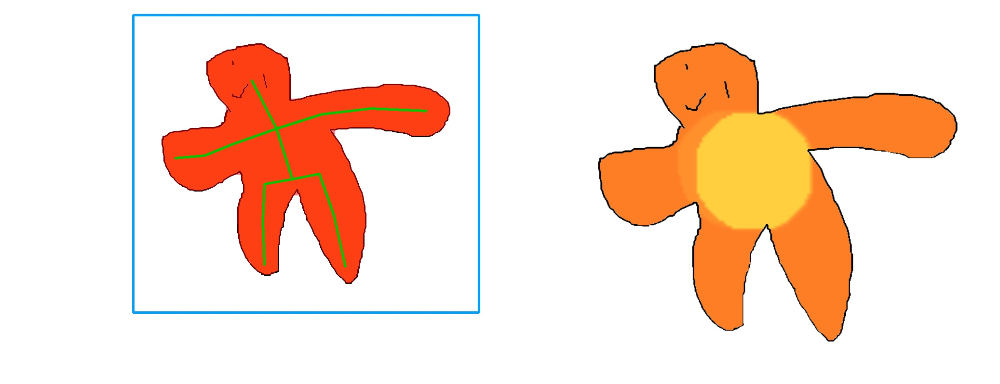

10.jpg


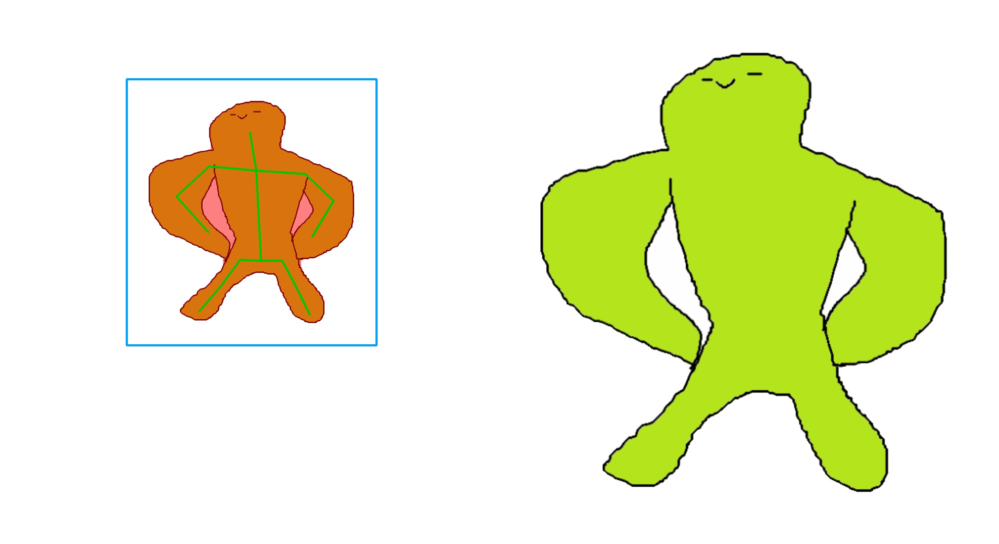

2.jpg


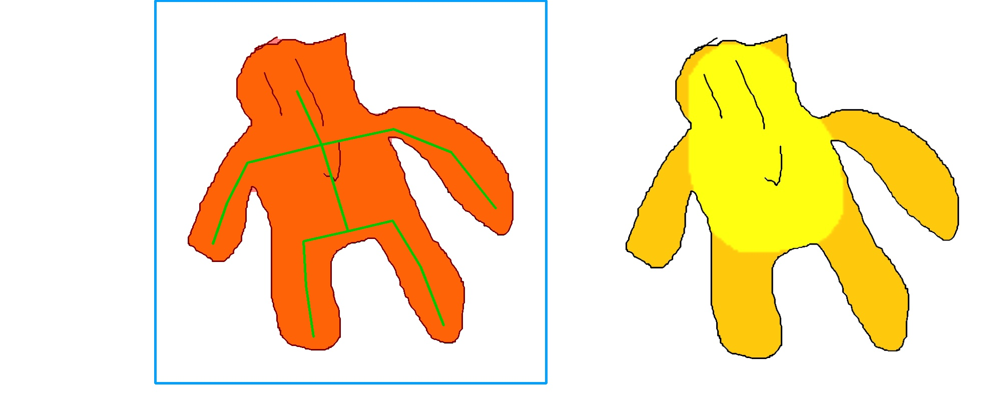

3.jpg


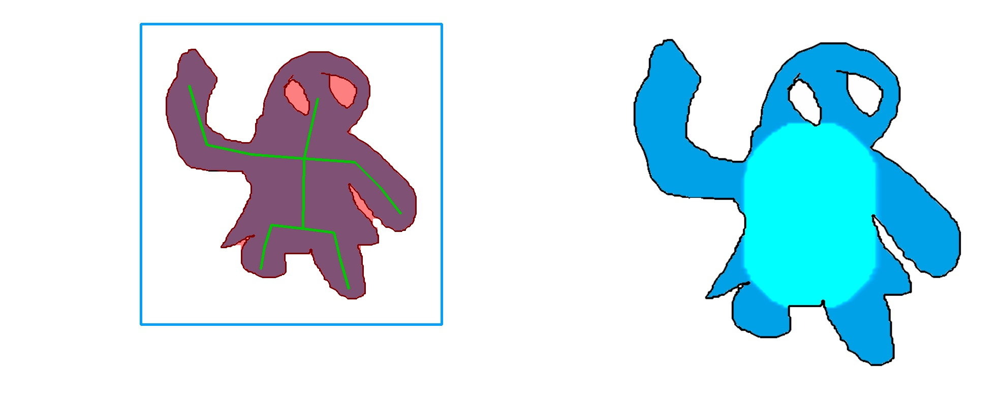

4.jpg


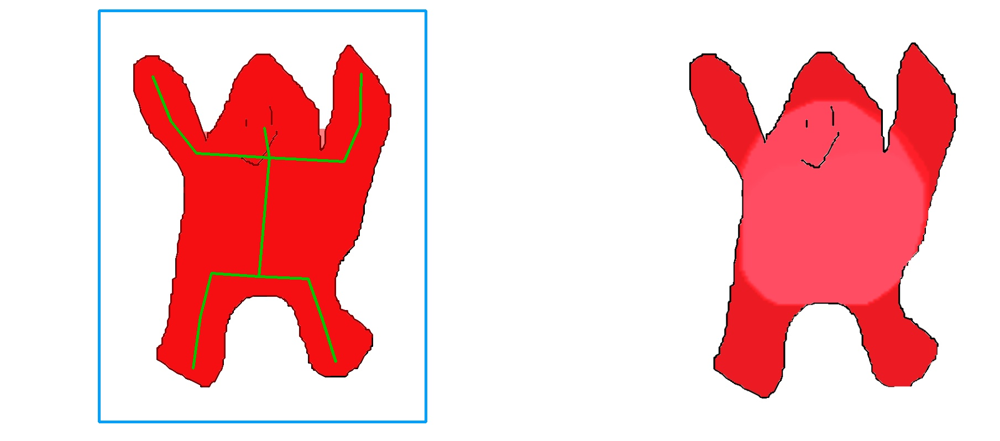

5.jpg


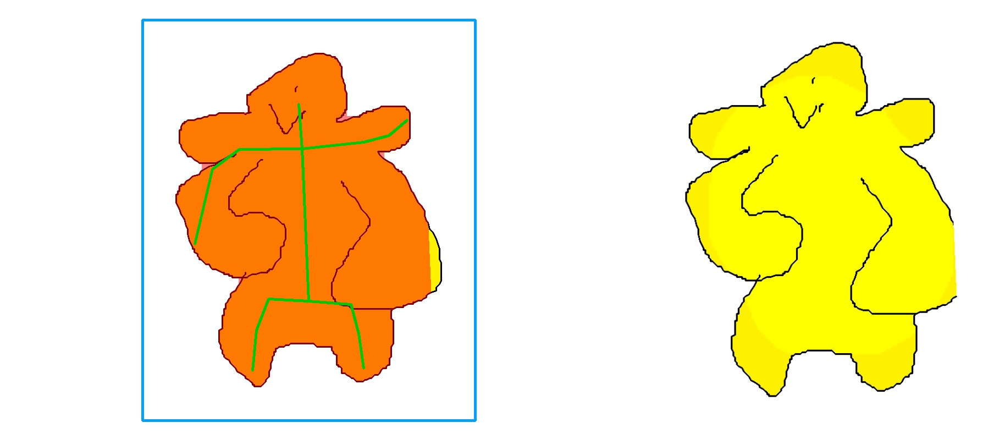

6.jpg


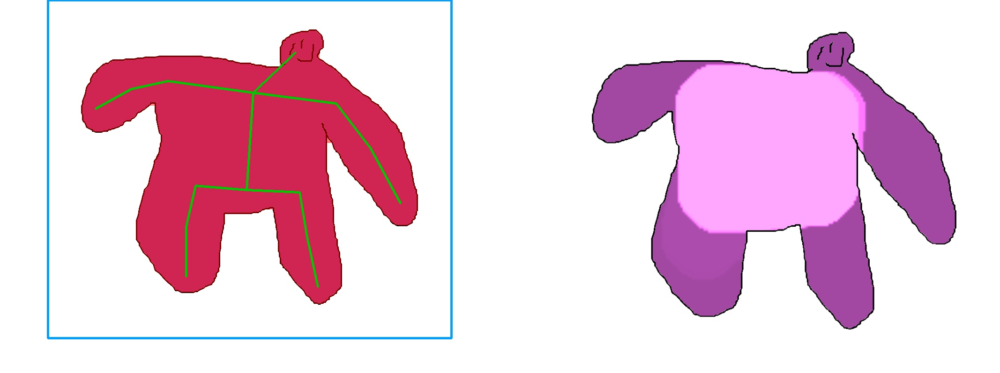

7.jpg


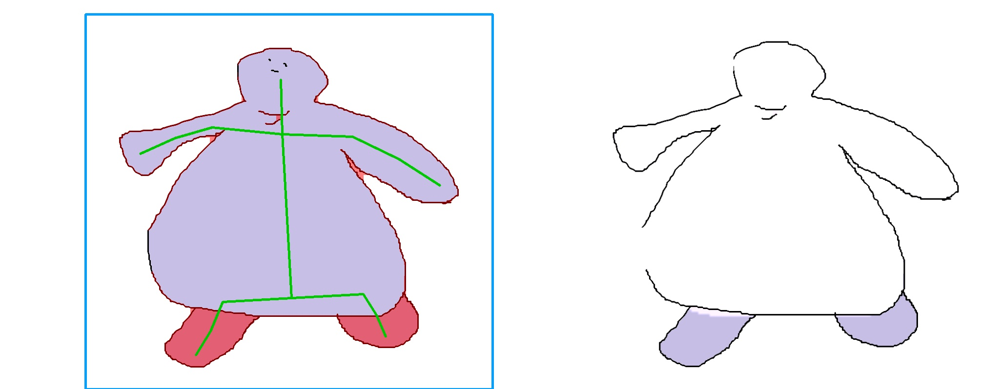

8.jpg


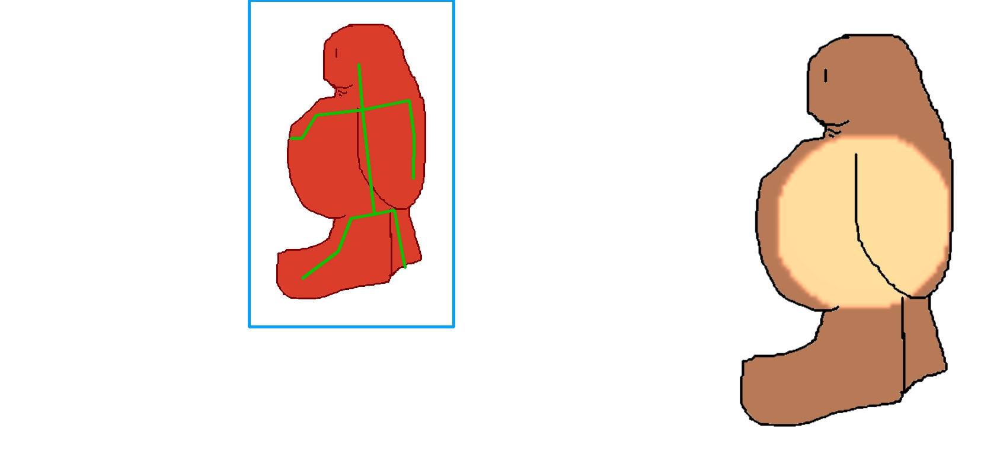

9.jpg


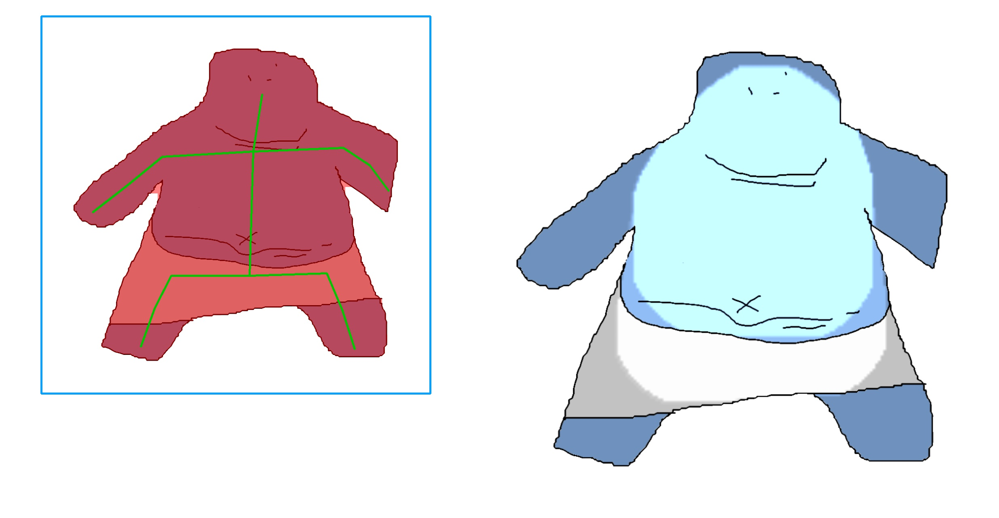

KakaoTalk_20261113_171159582.jpg


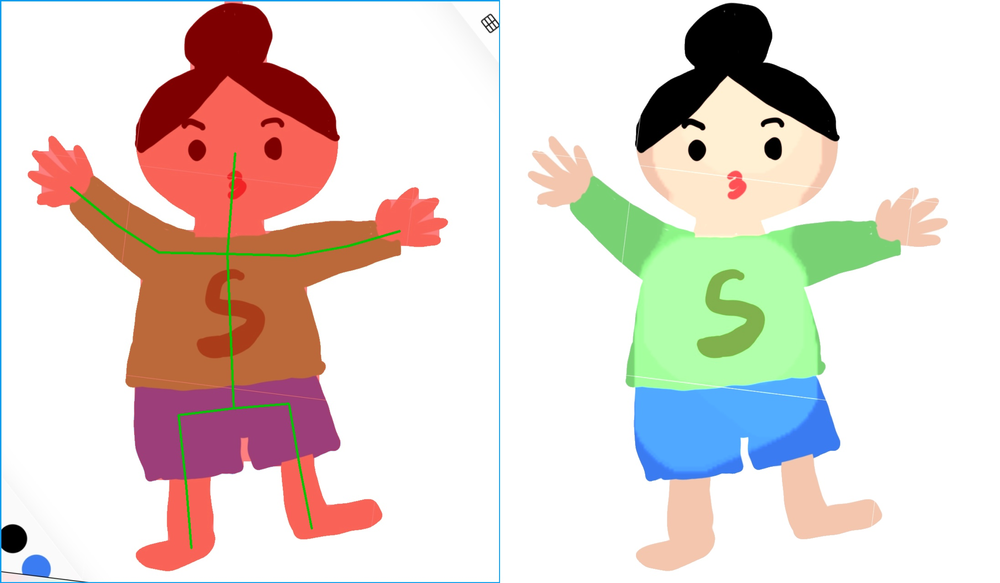

KakaoTalk_20261113_171159582_01.jpg


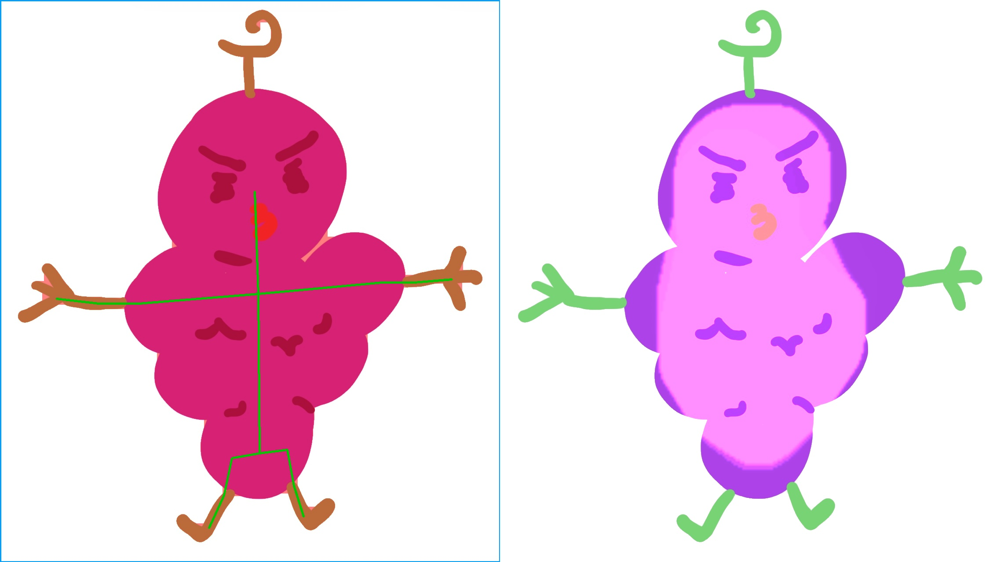

KakaoTalk_20261113_171159582_02.jpg


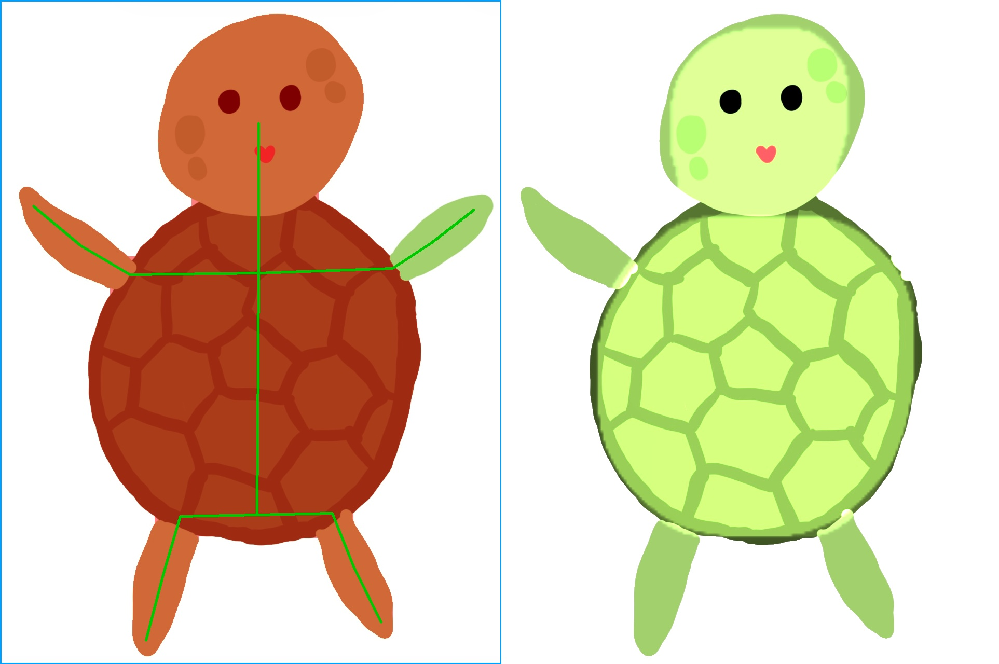

KakaoTalk_20261113_171159582_03.jpg


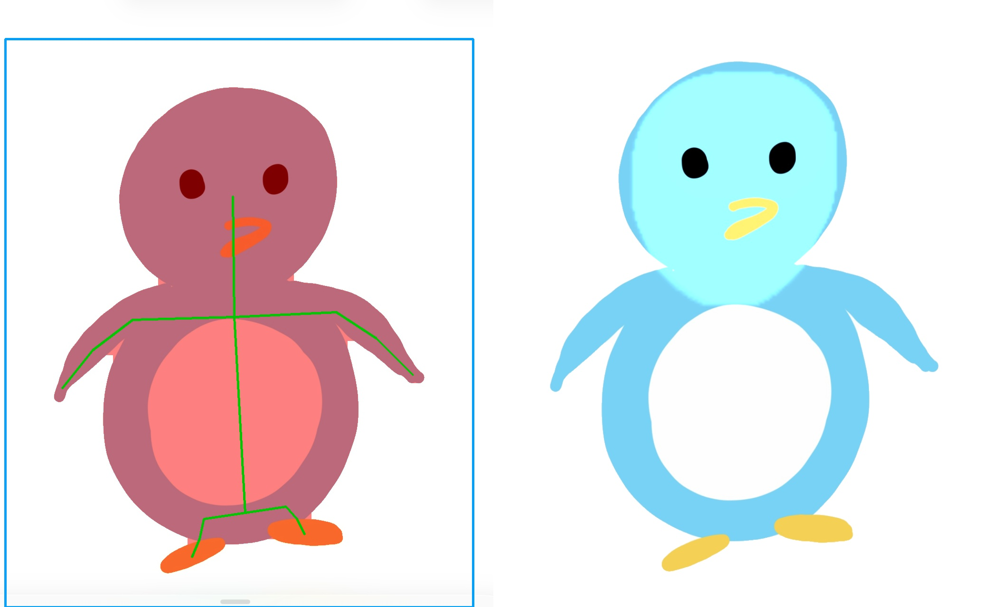

KakaoTalk_20261113_171159582_04.jpg


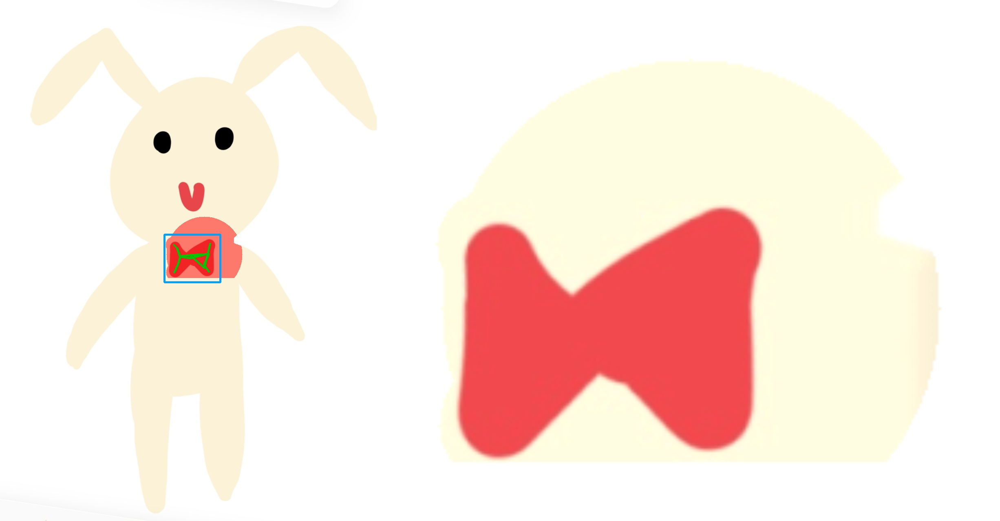

KakaoTalk_20261113_171159582_05.jpg


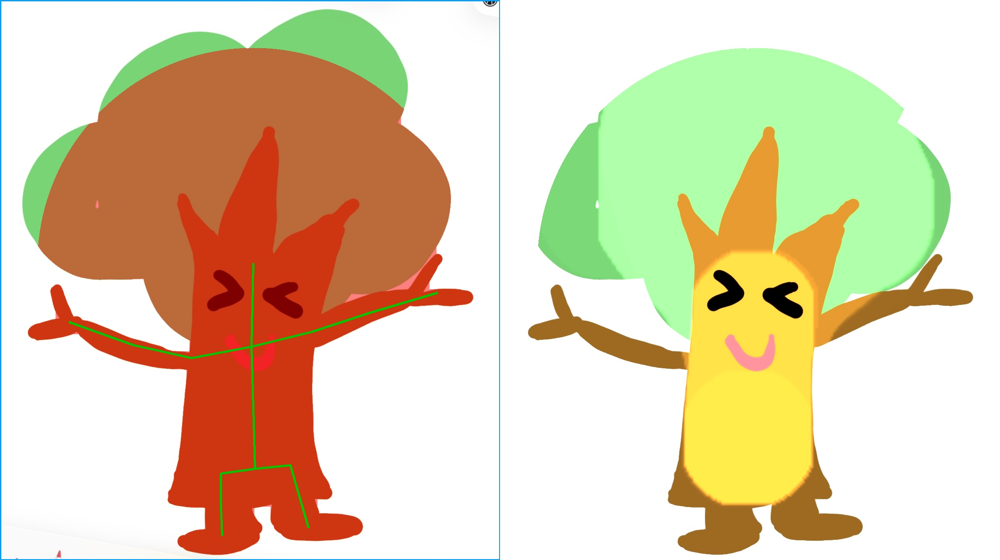

KakaoTalk_20261113_171159582_06.jpg


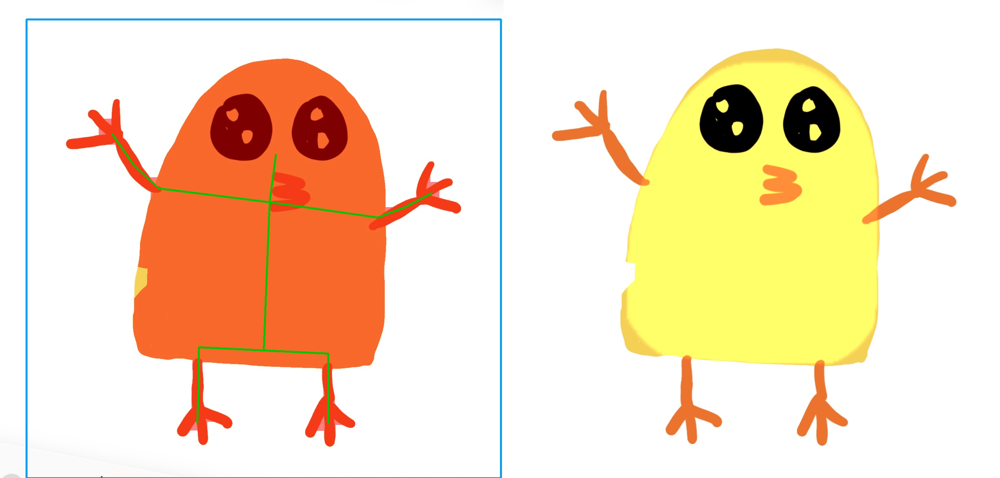

KakaoTalk_20261113_171159582_07.jpg


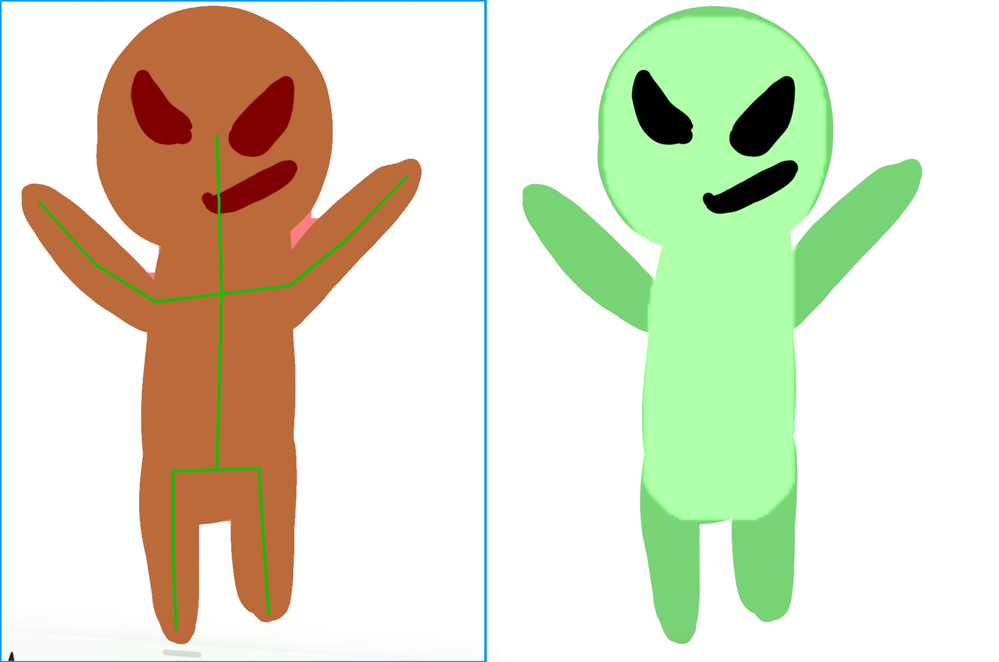

KakaoTalk_20261113_171159582_08.jpg


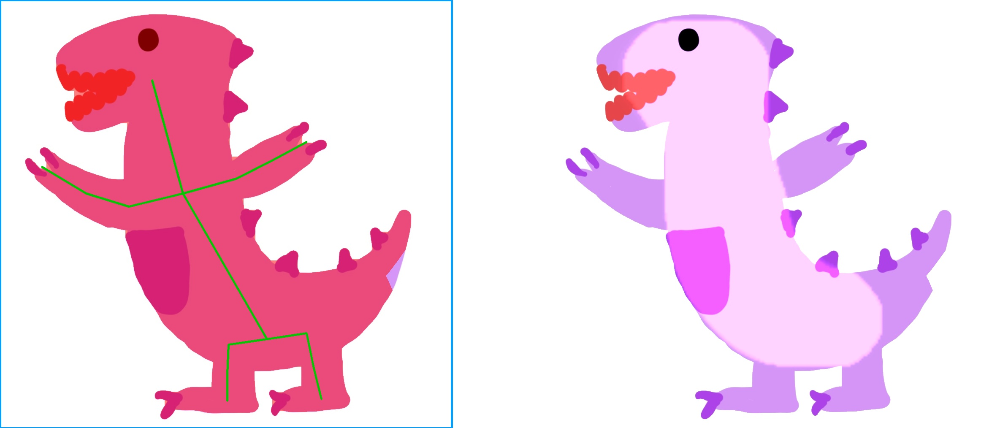

KakaoTalk_20261113_171159582_09.jpg


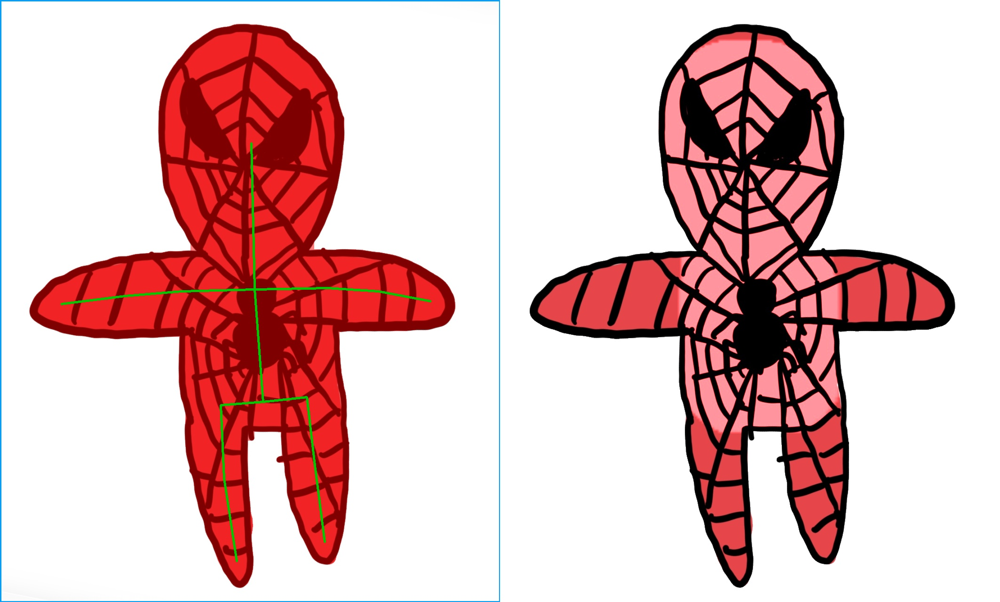

p1.jpg


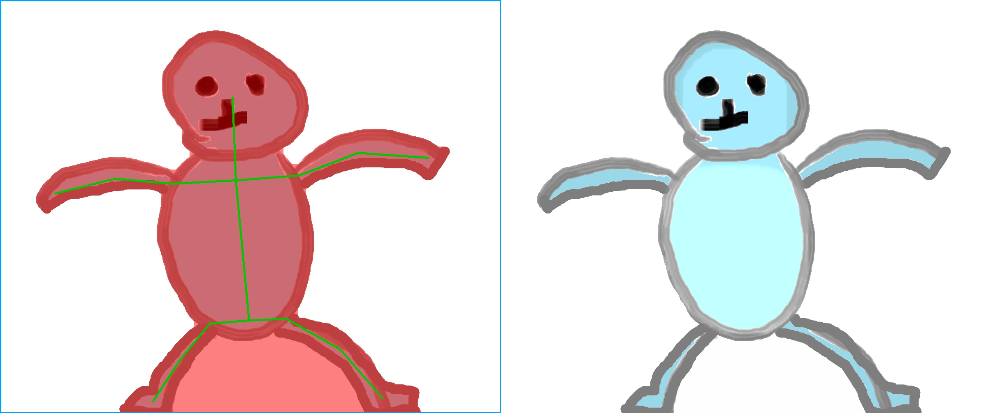

p10.jpg


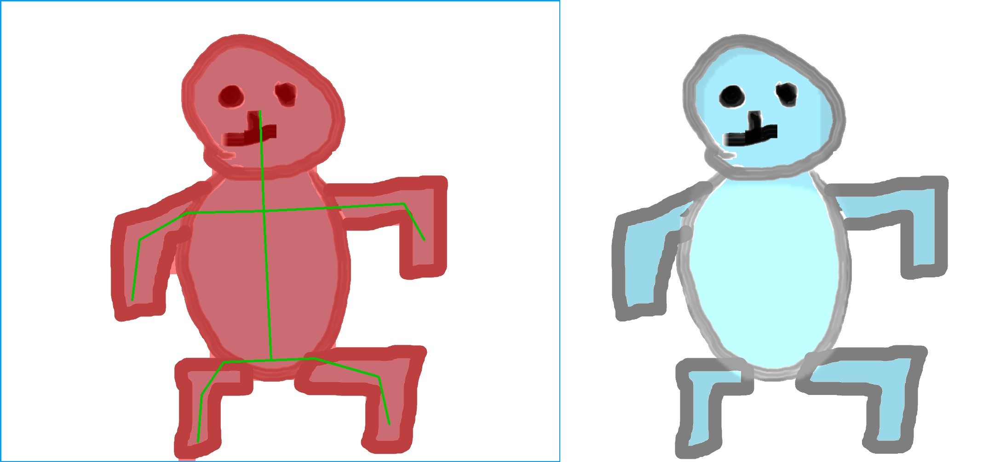

p2.jpg


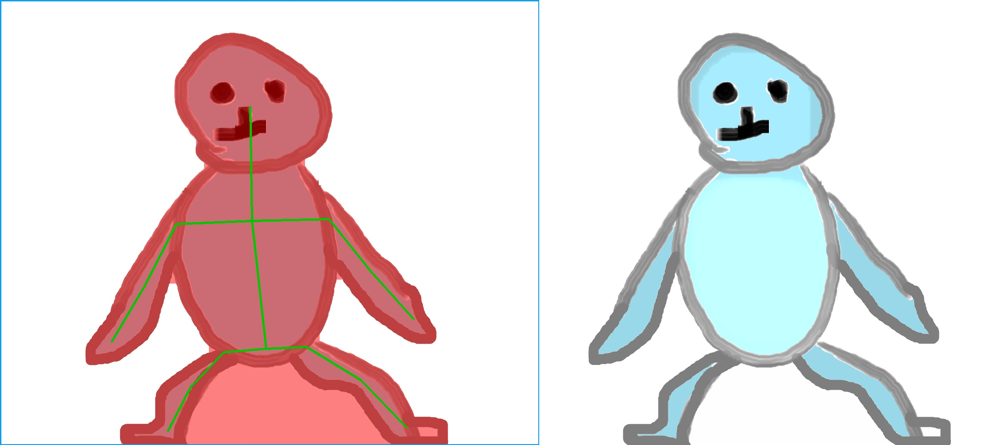

p3.jpg


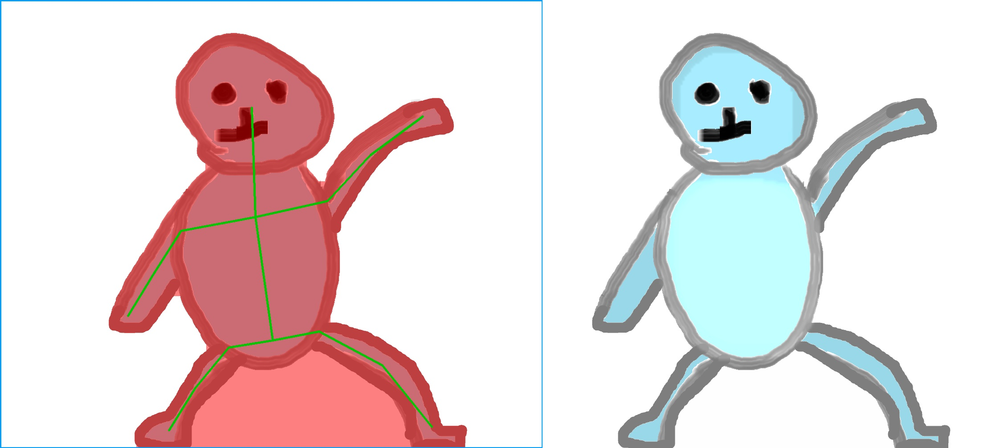

p4.jpg


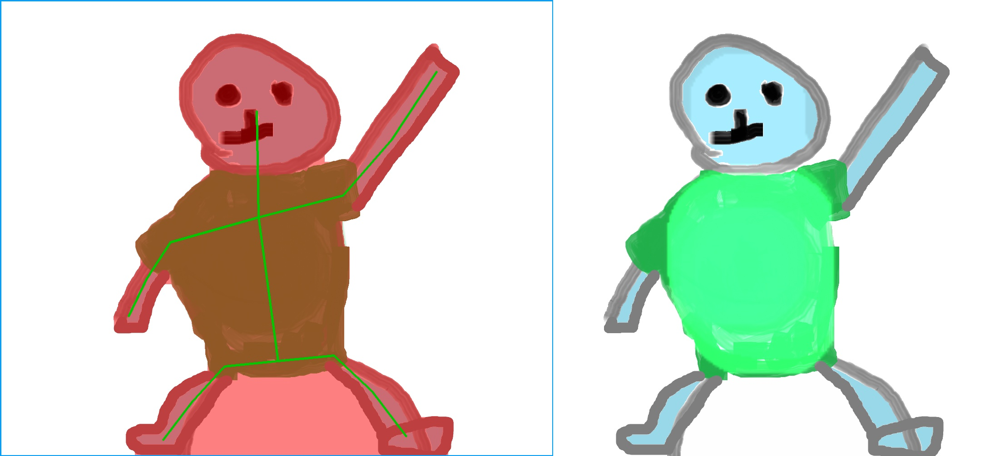

p5.jpg


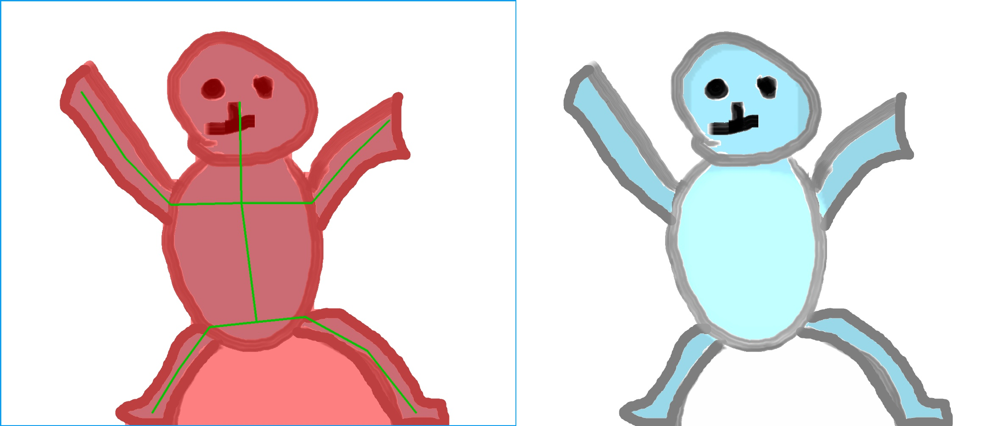

p6.jpg


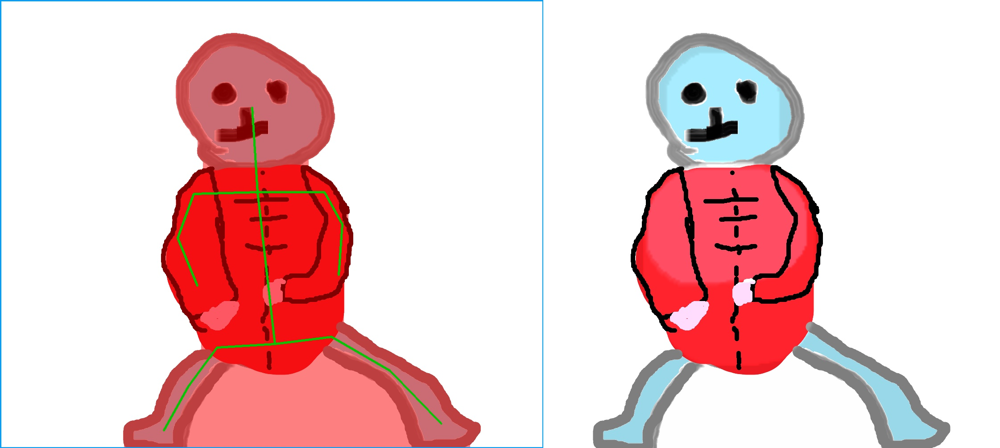

p7.jpg


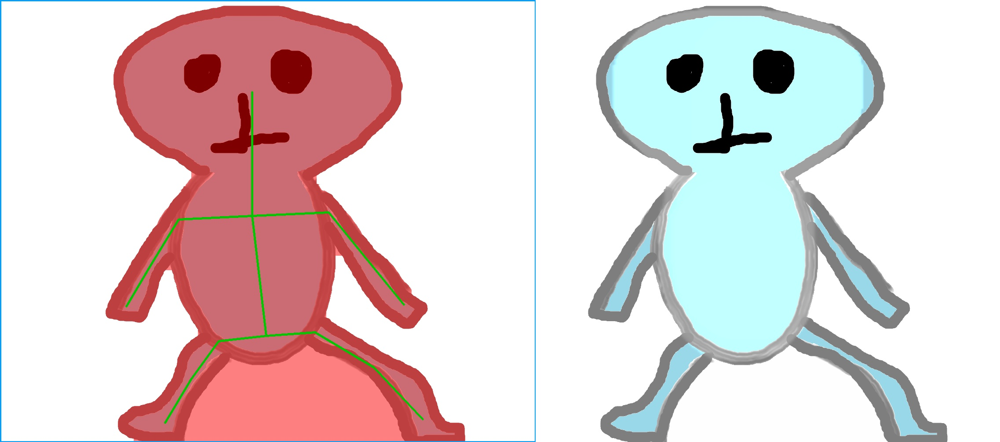

p8.jpg


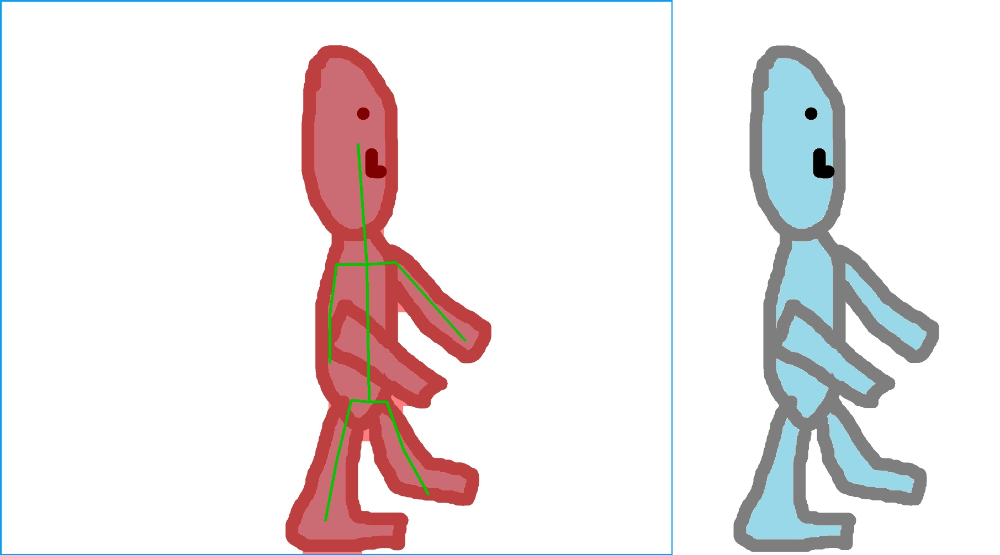

p9.jpg


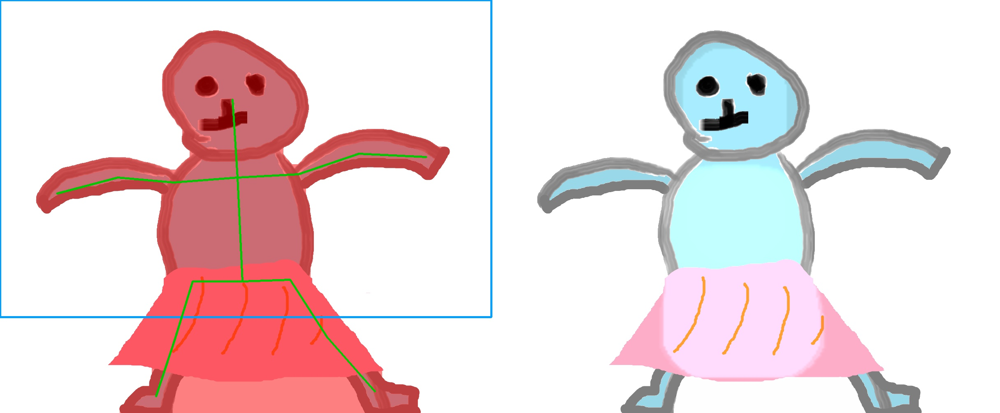

t1.jpg


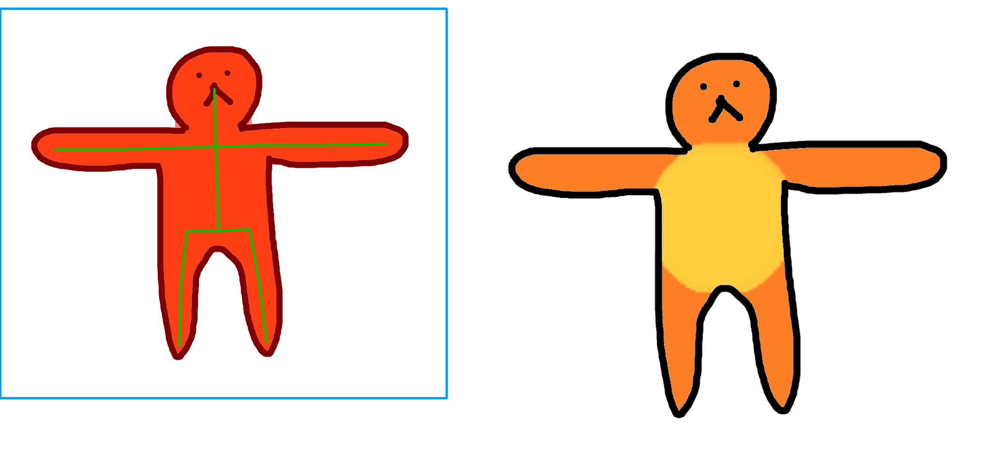

t10.jpg


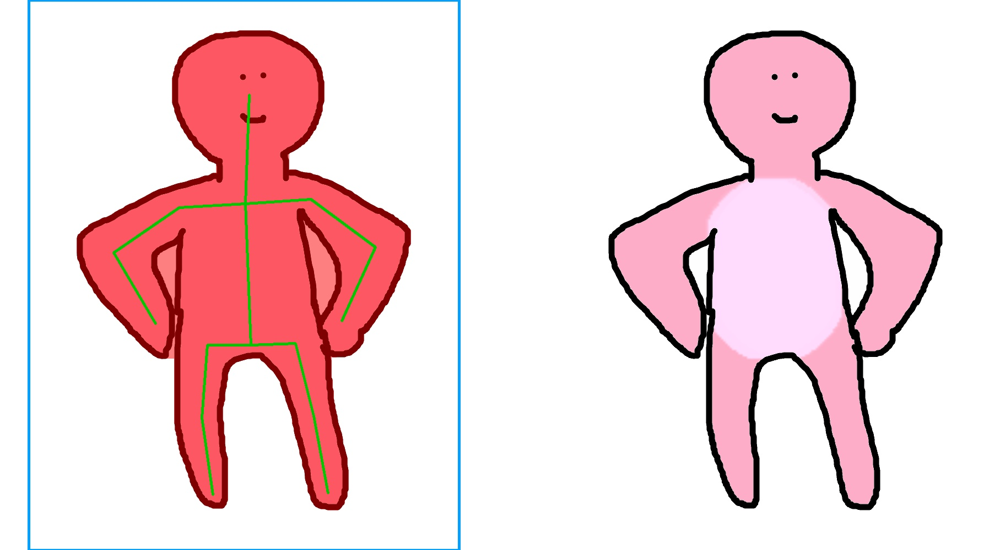

t2.jpg


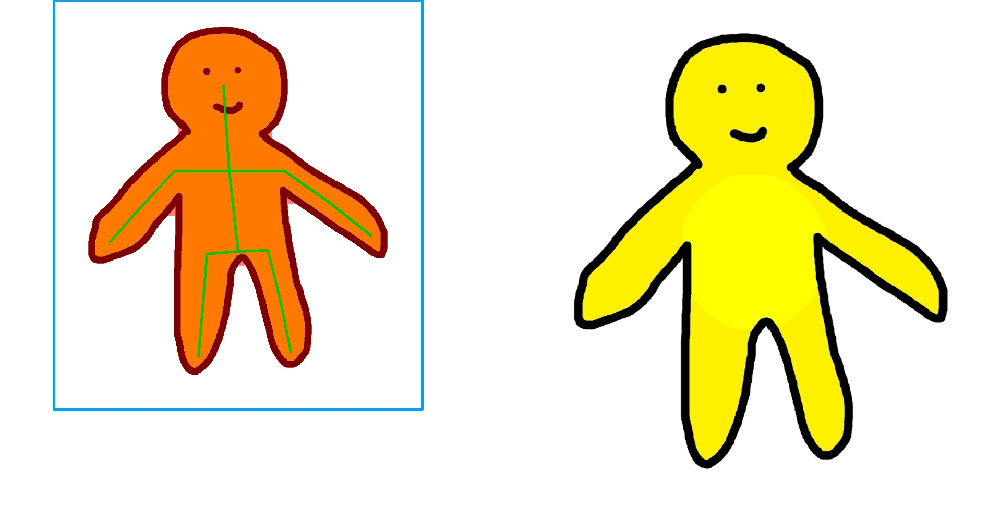

t3.jpg


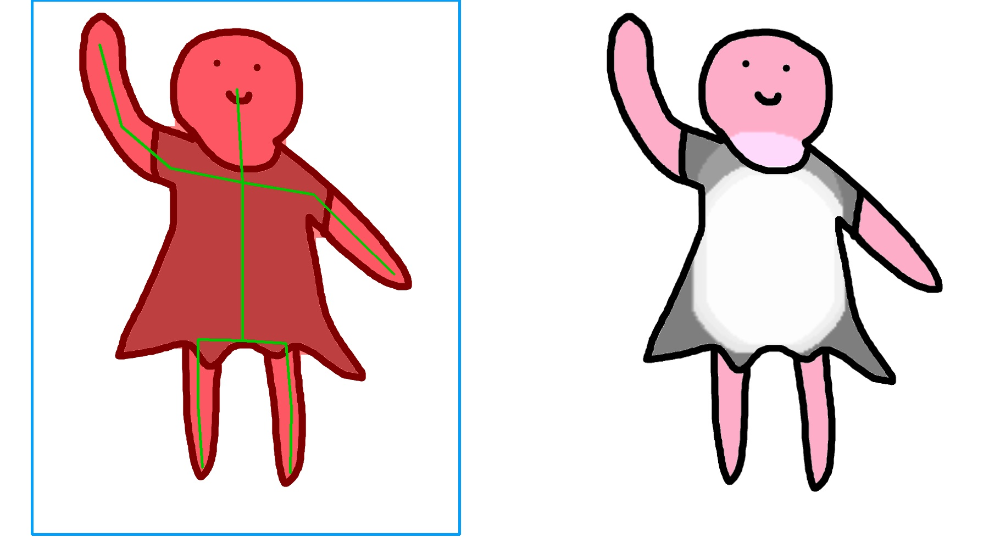

t4.jpg


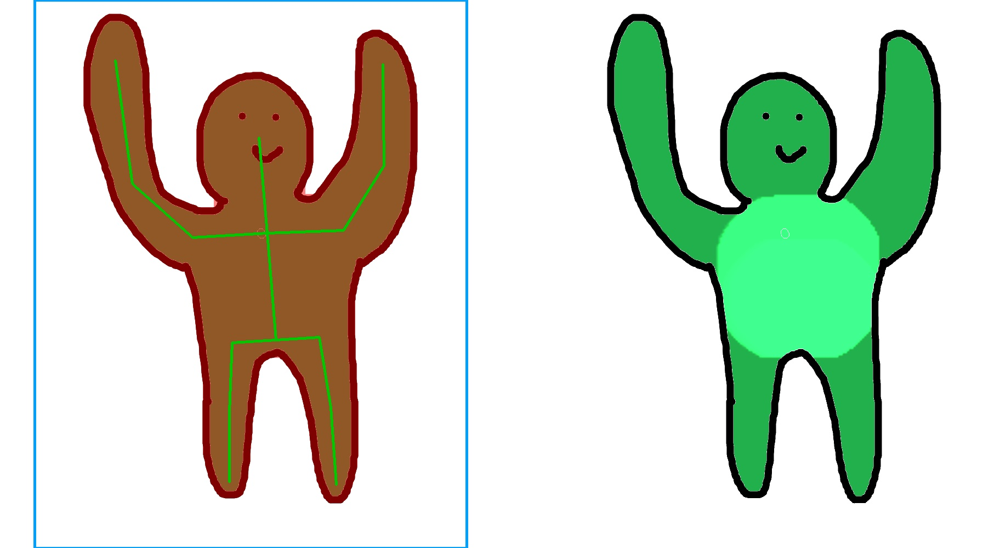

t5.jpg


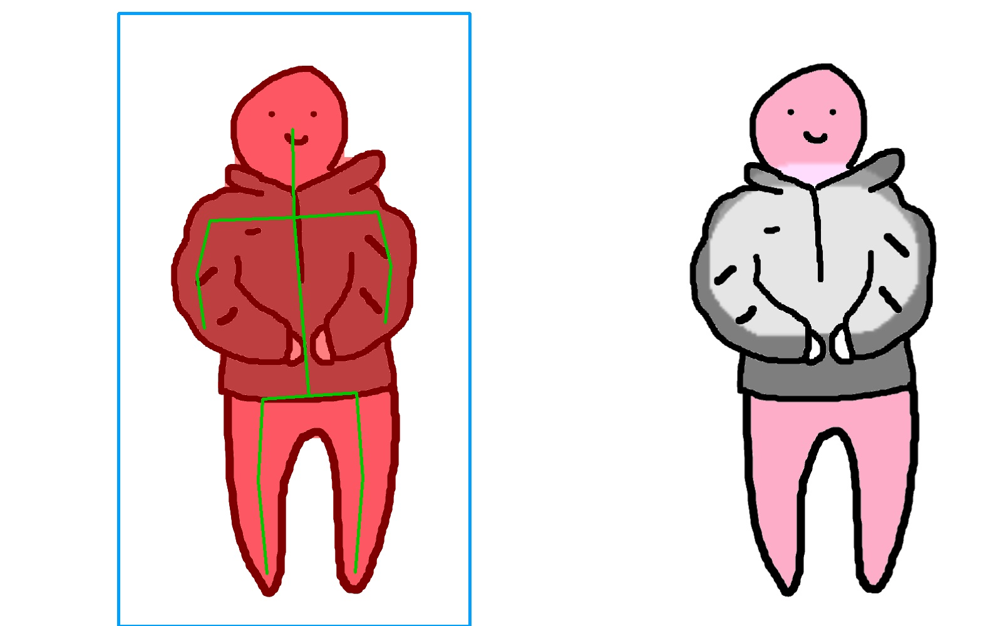

t6.jpg


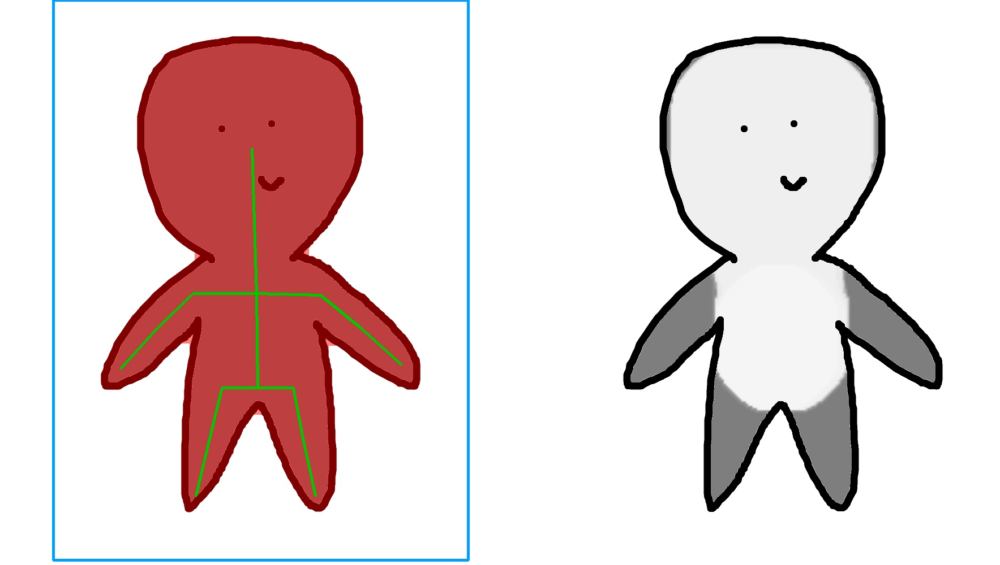

t7.jpg


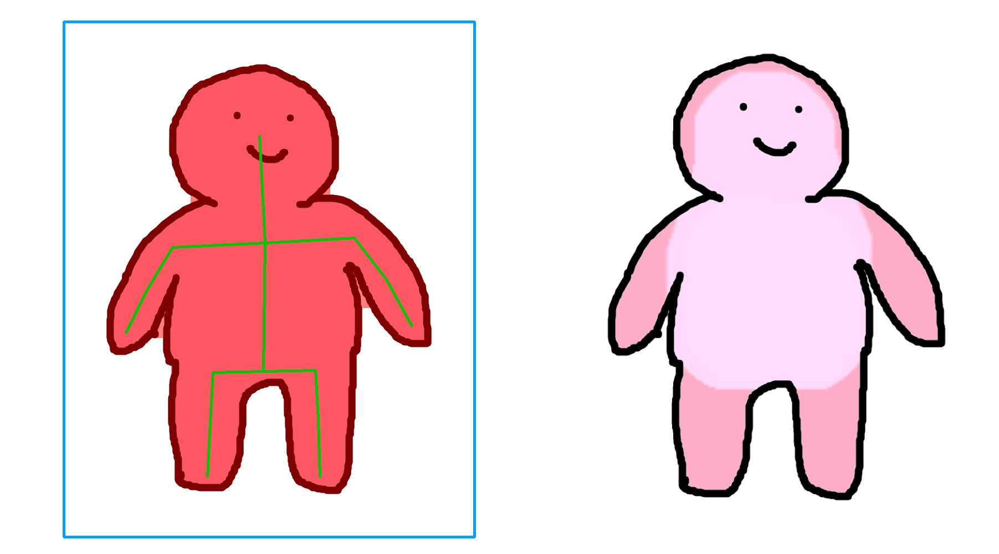

t8.jpg


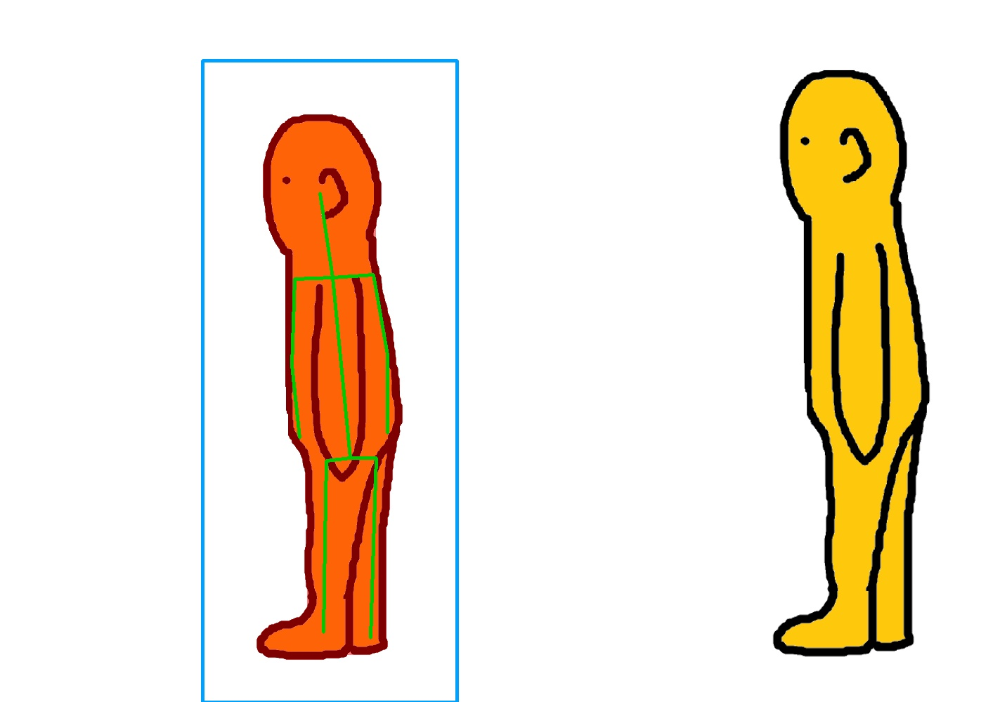

t9.jpg


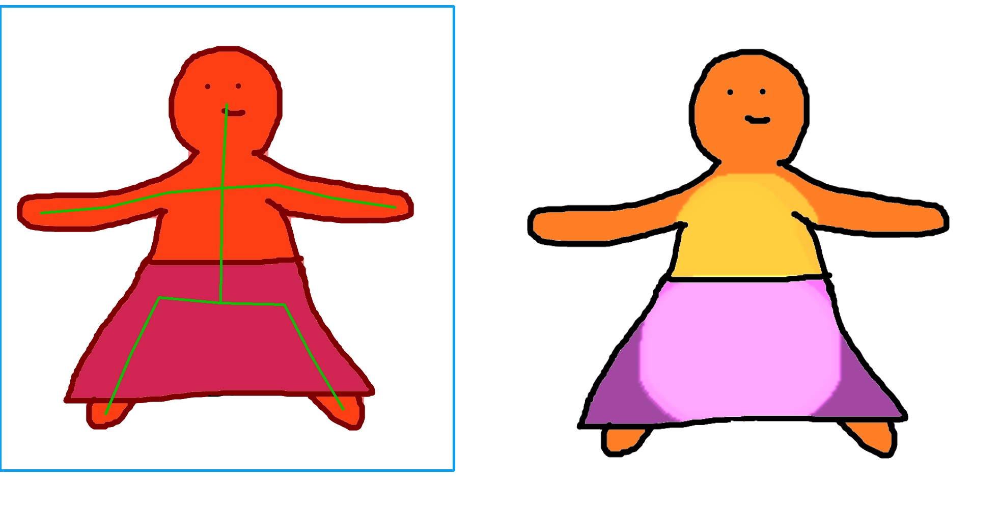

In [12]:
import os, glob, subprocess, shutil, zipfile
from google.colab import files
from IPython.display import Image as IImage, Video, display

SELECT_NAMES = [m["seq"] for m in motions]   # 전체 동작 (기존 6 + 서비스 15). 일부만: ["bvh/wave_hello", "bvh/laugh", ...]
SELECT = [i for i, m in enumerate(motions) if m["seq"] in SELECT_NAMES]
print("선택한 동작:", [motions[i]["seq"] for i in SELECT])
MAKE_GIF = False      # 동작 GIF 만들기 (평가만 할 거면 False: 배경 분리만 하고 GIF는 안 만듦)
SEPARATE_BG = True   # 종이 사진이면 True: 배경(종이, 글씨, 그림자)을 지우고 인물만 잘라서 사용
MIRROR = False       # 그림이 동작과 좌우 반대로 움직이면 True
RELATIVE = True      # 사람 영상에서 뽑은 동작: True = 그림의 원래 자세에서 움직인 만큼만
BVH_ABSOLUTE = True  # BVH 동작: 동작의 팔다리 방향을 그대로 따름 (상대 방식은 팔을 크게 들면 몸을 가로지름)
BLEND_IN = 8         # 절대 방식일 때 처음 몇 프레임 동안 그림 원래 자세에서 서서히 전환할지

def mode_args(m):
    """동작별 입히기 방식 → animate_drawing.py 옵션"""
    if BVH_ABSOLUTE and m["seq"].startswith("bvh/"):
        return ["--blend-in", str(BLEND_IN)]
    return ["--relative"] if RELATIVE else []

def mode_tag(m):
    """동작별 입히기 방식 → eval_motion.py 표기 (rel / abs8)"""
    if BVH_ABSOLUTE and m["seq"].startswith("bvh/"):
        return f"abs{BLEND_IN}"
    return "rel" if RELATIVE else "abs0"
FOLLOW_ROOT = False  # 몸 이동까지 따라 할지 (제자리 동작은 False)

ENV = {**os.environ, "MPLBACKEND": "Agg"}
PY = ["/usr/local/miniconda/bin/conda", "run", "--no-capture-output", "-n", "mmpose_env", "python", "-u"]
IMG_EXT = (".jpg", ".jpeg", ".png")

# 1) 그림 업로드 (jpg/png 여러 장, 또는 그것들을 묶은 zip)
shutil.rmtree("/content/my_imgs", ignore_errors=True); os.makedirs("/content/my_imgs")
def put(name, src_file):
    base, ext = os.path.splitext(os.path.basename(name)); dst = f"/content/my_imgs/{base}{ext}"; k = 1
    while os.path.exists(dst):                                   # 이름이 겹치면 _1, _2 …
        dst = f"/content/my_imgs/{base}_{k}{ext}"; k += 1
    with open(dst, "wb") as f:
        shutil.copyfileobj(src_file, f)
for n in files.upload():
    if n.lower().endswith(".zip"):
        with zipfile.ZipFile(n) as z:
            for info in z.infolist():
                name = info.filename
                if not info.flag_bits & 0x800:                   # Windows에서 만든 zip의 한글 이름(cp949) 복원
                    try:
                        name = name.encode("cp437").decode("cp949")
                    except (UnicodeEncodeError, UnicodeDecodeError):
                        pass
                b = os.path.basename(name)
                if info.is_dir() or "__MACOSX" in name or b.startswith(".") or not b.lower().endswith(IMG_EXT):
                    continue
                with z.open(info) as src:
                    put(b, src)
        os.remove(n)
    elif n.lower().endswith(IMG_EXT):
        with open(n, "rb") as src:
            put(n, src)
        os.remove(n)
imgs = sorted(os.listdir("/content/my_imgs"))
print(f"그림 {len(imgs)}장:", imgs[:5], "…" if len(imgs) > 5 else "")
if not imgs:
    raise SystemExit("그림이 없음: jpg/png 파일이나 그것들을 묶은 zip을 올려 주세요")

# 2) 배경 분리 (내 모델로 관절 → 관절 주변 몸 영역의 잉크만 남김)
SRC_DIR = "/content/my_imgs"
if SEPARATE_BG:
    shutil.rmtree("/content/my_imgs_clean", ignore_errors=True)
    r = subprocess.run(PY + ["/content/segment_drawing.py", "/content/my_imgs", "/content/my_imgs_clean"],
                       capture_output=True, text=True, env=ENV)
    print(r.stdout[-2000:])
    if r.returncode:
        print(r.stderr[-2000:]); raise SystemExit("배경 분리 실패")
    for d in sorted(glob.glob("/content/my_imgs_clean/_debug/*.jpg")):   # 왼쪽: 남긴 영역(빨강)/관절(초록), 오른쪽: 결과
        print(os.path.basename(d)); display(IImage(d, width=520))
    SRC_DIR = "/content/my_imgs_clean"

# 3) 동작 입히기
for k, i in enumerate(SELECT if MAKE_GIF else []):
    m = motions[i]
    out = f"/content/anim_motion/{m['stem']}"
    shutil.rmtree(out, ignore_errors=True)
    cmd = (PY + ["/content/animate_drawing.py", "--src", SRC_DIR, "--seq", m["npy"], "--seq-fps", str(m["fps"]),
                 "--motions", "", "--out", out]
           + (["--mirror"] if MIRROR else []) + mode_args(m)
           + ([] if FOLLOW_ROOT else ["--no-root"]))
    r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    if r.returncode:
        print("실패:", m["seq"]); print(r.stdout[-1500:]); print(r.stderr[-1500:]); continue
    print(f"\n===== 동작 [{i}] {m['seq']}  ({mode_tag(m)}) =====")
    print("\n".join(l for l in r.stdout.splitlines() if "mean score" in l))     # 그림별 관절 신뢰도
    src = MOTION_ROOT / "previews" / f"{m['stem']}_frames.mp4"                    # 원본 동작 (비교용)
    if src.exists():
        display(Video(str(src), embed=True, width=320))
    for g in sorted(glob.glob(f"{out}/*_video.gif")):
        name = os.path.basename(g)[:-len("_video.gif")]
        if k == 0:                                                                # 내 모델이 뽑은 관절 (첫 동작에서만)
            display(IImage(f"{out}/{name}_pose.jpg", width=320))
        print(name); display(IImage(g, width=320))

#평가

In [16]:
%%writefile /content/eval_motion.py
"""동작 입히기 성능 확인 (정답 관절 없이 측정).
① 재검출 일치도: 움직인 그림의 각 프레임을 내 모델로 다시 추정 → 뼈대가 의도한 관절 위치와 비교
   (그림이 찢어지거나 번지면 모델이 엉뚱한 곳을 찾음). 기준선 = 움직이기 전 그림의 같은 측정값
② 형태 유지: 프레임별 그림 면적 / 원래 면적 (찢어지면 줄고, 번지면 늘어남)
③ 떨림: 관절 가속도 평균 (몸 크기 대비)
사용: python eval_motion.py <그림 폴더> <출력 폴더> <npy:fps> [<npy:fps> ...] [--relative] [--no-root] [--mirror] [--stride N]"""
import os, sys, glob, json, csv
os.environ.setdefault('MPLBACKEND', 'Agg')
import cv2
import numpy as np
sys.path.insert(0, '/content')
import animate_drawing as ad

J15 = ['nose', 'neck', 'r_sho', 'r_elb', 'r_wri', 'l_sho', 'l_elb', 'l_wri',
       'pelvis', 'r_hip', 'r_knee', 'r_ank', 'l_hip', 'l_knee', 'l_ank']
ARMS = [3, 4, 6, 7]
SW = [0, 1, 5, 6, 7, 2, 3, 4, 8, 12, 13, 14, 9, 10, 11]


def ink(frame, bg):
    g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.int16)
    return g < int(np.mean(bg)) - 30


def redetect(model, frame, bg, infer):
    m = ink(frame, bg).astype(np.uint8)
    if m.sum() == 0:
        return None, None
    x, y, w, h = cv2.boundingRect(m)
    p = int(max(w, h) * 0.1)
    box = [max(0, x - p), max(0, y - p), min(frame.shape[1], x + w + p), min(frame.shape[0], y + h + p)]
    r = infer(model, frame, bboxes=np.array([box], np.float32), bbox_format='xyxy')[0]
    return np.asarray(r.pred_instances.keypoints[0], float), max(box[2] - box[0], box[3] - box[1])


def frames_for(img, kp, seq, relative, follow_root, mirror, stride):
    """animate_drawing.make_gif_seq와 같은 계산으로 (프레임, 의도한 관절 위치)를 만든다."""
    crop, rest, _ = ad.prep(img, np.asarray(kp, np.float64), [0, 0, img.shape[1], img.shape[0]], 512)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = ad.bind(crop, rest, S)
    seq = np.asarray(seq, np.float64).copy()
    if mirror:
        seq[:, :, 0] *= -1
        seq = seq[:, SW]
    body = max(np.ptp(seq[0, :, 1]), 1.0)
    cb0 = ad.retarget(rest, seq[0], 1.0)
    zero = {k: 0.0 for k in cb0}
    rest_frame = ad.render(B, rest, rest, zero)
    out = []
    for t in range(0, len(seq), stride):
        cb = ad.retarget(rest, seq[t], 1.0)
        if relative:
            cb = {k: ad._wrap(v - cb0[k]) for k, v in cb.items()}
        tr = (seq[t, 8] - seq[0, 8]) * (np.ptp(rest[:, 1]) / body) if follow_root else np.zeros(2)
        pos = ad.pose_from_bones(rest, cb, tr)
        out.append((t, ad.render(B, rest, pos, cb), pos))
    return rest_frame, rest, out, B['bg']


def overlay(frame, target, pred):
    v = frame.copy()
    for p, c in ad.SKEL:
        cv2.line(v, tuple(map(int, target[p])), tuple(map(int, target[c])), (0, 180, 0), 2)
        cv2.line(v, tuple(map(int, pred[p])), tuple(map(int, pred[c])), (0, 0, 230), 1)
    return v


def main():
    args = sys.argv[1:]
    flags = {a for a in args if a.startswith('--')}
    stride = 2
    if '--stride' in args:
        stride = int(args[args.index('--stride') + 1]); args.remove(args[args.index('--stride') + 1])
    pos_args = [a for a in args if not a.startswith('--')]
    src, dst, seqs = pos_args[0], pos_args[1], pos_args[2:]
    os.makedirs(f'{dst}/worst', exist_ok=True)
    from mmpose.apis import init_model, inference_topdown
    model = init_model(ad.CFG, ad.CKPT, device=ad.DEV)
    files = sorted(f for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG') for f in glob.glob(os.path.join(src, e)))
    rows, joint_err = [], {}
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        img = cv2.imread(f)
        h, w = img.shape[:2]
        r = inference_topdown(model, img, bboxes=np.array([[0, 0, w, h]], np.float32), bbox_format='xyxy')[0]
        kp = np.asarray(r.pred_instances.keypoints[0], float)
        for spec in seqs:
            npy, fps = spec.rsplit(':', 1)
            motion = os.path.splitext(os.path.basename(npy))[0]
            seq = ad.smooth_seq(np.load(npy))
            rest_frame, rest, fr, bg = frames_for(img, kp, seq, '--relative' in flags, '--no-root' not in flags,
                                                  '--mirror' in flags, stride)
            base_area = ink(rest_frame, bg).sum()
            p0, s0 = redetect(model, rest_frame, bg, inference_topdown)
            e0 = np.linalg.norm(p0 - rest, axis=1) / s0 if p0 is not None else np.full(15, np.nan)
            errs, areas, recs = [], [], []
            for t, frame, pos in fr:
                pred, size = redetect(model, frame, bg, inference_topdown)
                if pred is None:
                    errs.append(np.full(15, np.nan)); areas.append(0.0); continue
                e = np.linalg.norm(pred - pos, axis=1) / size          # 몸(bbox) 크기 대비 거리 = PCK 기준과 동일
                errs.append(e); areas.append(ink(frame, bg).sum() / max(base_area, 1))
                recs.append((float(np.nanmean(e)), t, frame, pos, pred))
            E = np.array(errs)
            P = np.array([p for _, _, p in fr])
            jitter = float(np.nanmean(np.linalg.norm(np.diff(P, 2, axis=0), axis=2)) / max(np.ptp(rest[:, 1]), 1)) if len(P) > 2 else 0.0
            row = dict(image=name, motion=motion, frames=len(fr),
                       rest_pck05=round(float(np.nanmean(e0 < 0.05)), 3), rest_pck10=round(float(np.nanmean(e0 < 0.10)), 3),
                       pck05=round(float(np.nanmean(E < 0.05)), 3), pck10=round(float(np.nanmean(E < 0.10)), 3),
                       arm_pck10=round(float(np.nanmean(E[:, ARMS] < 0.10)), 3),
                       worst_frame_pck10=round(float(np.nanmin(np.nanmean(E < 0.10, axis=1))), 3),
                       area_min=round(float(np.min(areas)), 3), area_max=round(float(np.max(areas)), 3),
                       jitter=round(jitter, 4))
            rows.append(row)
            for j in range(15):
                joint_err.setdefault(J15[j], []).extend(E[:, j][~np.isnan(E[:, j])].tolist())
            recs.sort(key=lambda r: -r[0])                           # 가장 많이 어긋난 프레임 3장 저장
            for k, (m, t, frame, pos, pred) in enumerate(recs[:3]):
                cv2.imwrite(f'{dst}/worst/{name}__{motion}__{k}_t{t}.jpg', overlay(frame, pos, pred))
            print(f"{name} | {motion} | 재검출 PCK@0.1 {row['pck10']:.2f} (움직이기 전 {row['rest_pck10']:.2f}) | "
                  f"팔 {row['arm_pck10']:.2f} | 최악 프레임 {row['worst_frame_pck10']:.2f} | "
                  f"면적 {row['area_min']:.2f}~{row['area_max']:.2f} | 떨림 {row['jitter']:.4f}", flush=True)
    with open(f'{dst}/summary.csv', 'w', newline='', encoding='utf-8-sig') as fo:
        w = csv.DictWriter(fo, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    jt = {j: dict(pck10=round(float(np.mean(np.array(v) < 0.1)), 3), mean_err=round(float(np.mean(v)), 4)) for j, v in joint_err.items()}
    json.dump(jt, open(f'{dst}/per_joint.json', 'w'), ensure_ascii=False, indent=1)


if __name__ == '__main__':
    main()

Writing /content/eval_motion.py


평가 스크립트 패치: 동작마다 방식 지정 (`경로:fps:rel` 또는 `경로:fps:abs8`), 그림이 없으면 바로 안내하고 멈춤. 여러 번 실행해도 안전.

In [18]:
from pathlib import Path
# ② eval_motion.py: 동작마다 방식 지정 (경로:fps:rel 또는 경로:fps:abs8 = 절대 + 8프레임 전환)
p = Path("/content/eval_motion.py")
s = p.read_text(encoding="utf-8")
if "blend_bones" not in s:
    a = "def frames_for(img, kp, seq, relative, follow_root, mirror, stride):"
    b = ("        cb = ad.retarget(rest, seq[t], 1.0)\n"
         "        if relative:\n"
         "            cb = {k: ad._wrap(v - cb0[k]) for k, v in cb.items()}\n")
    c = ("            npy, fps = spec.rsplit(':', 1)\n")
    d = ("            rest_frame, rest, fr, bg = frames_for(img, kp, seq, '--relative' in flags, '--no-root' not in flags,\n"
         "                                                  '--mirror' in flags, stride)\n")
    assert a in s and b in s and c in s and d in s, "eval_motion.py가 예상과 다름 (평가 스크립트 셀을 다시 실행)"
    s = s.replace(a, "def frames_for(img, kp, seq, relative, follow_root, mirror, stride, blend_in=0):", 1)
    s = s.replace(b, "        cb = ad.blend_bones(ad.retarget(rest, seq[t], 1.0), cb0, t, relative, blend_in)\n", 1)
    s = s.replace(c, ("            parts = spec.split(':')\n"
                      "            npy, fps = parts[0], parts[1]\n"
                      "            mode = parts[2] if len(parts) > 2 else ('rel' if '--relative' in flags else 'abs0')\n"
                      "            relative = mode == 'rel'\n"
                      "            blend_in = 0 if relative else int(mode[3:] or 0)\n"), 1)
    s = s.replace(d, ("            rest_frame, rest, fr, bg = frames_for(img, kp, seq, relative, '--no-root' not in flags,\n"
                      "                                                  '--mirror' in flags, stride, blend_in)\n"), 1)
    s = s.replace("rows.append(row)", "row['mode'] = mode\n            rows.append(row)", 1)
    e = "    rows, joint_err = [], {}\n"
    assert e in s
    s = s.replace(e, e + "    if not files:\n        sys.exit(f'평가할 그림이 없음: {src} (6번 셀에서 그림 업로드·배경 분리를 먼저 실행)')\n", 1)
    p.write_text(s, encoding="utf-8")
print("eval_motion.py | 동작별 방식:", "blend_bones" in p.read_text(encoding="utf-8"))

eval_motion.py | 동작별 방식: True


9 (움직이기 전 1.00) | 팔 0.97 | 최악 프레임 0.93 | 면적 1.00~1.25 | 떨림 0.0200
t8 | bvh_jumping_jacks | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 0.97~1.26 | 떨림 0.0322
t8 | bvh_wave_hello | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 1.00~1.26 | 떨림 0.0053
t8 | bvh_zombie | 재검출 PCK@0.1 0.95 (움직이기 전 1.00) | 팔 0.83 | 최악 프레임 0.67 | 면적 0.83~1.28 | 떨림 0.0228
t8 | bvh_bird | 재검출 PCK@0.1 0.99 (움직이기 전 1.00) | 팔 0.95 | 최악 프레임 0.87 | 면적 1.00~1.28 | 떨림 0.0128
t8 | bvh_elephant | 재검출 PCK@0.1 0.98 (움직이기 전 1.00) | 팔 0.91 | 최악 프레임 0.87 | 면적 1.00~1.26 | 떨림 0.0080
t8 | bvh_happy_walk | 재검출 PCK@0.1 0.94 (움직이기 전 1.00) | 팔 0.92 | 최악 프레임 0.67 | 면적 1.00~1.29 | 떨림 0.0328
t8 | bvh_idle | 재검출 PCK@0.1 0.91 (움직이기 전 1.00) | 팔 0.66 | 최악 프레임 0.87 | 면적 1.00~1.28 | 떨림 0.0058
t8 | bvh_kick_ball | 재검출 PCK@0.1 0.95 (움직이기 전 1.00) | 팔 0.87 | 최악 프레임 0.80 | 면적 1.00~1.28 | 떨림 0.0095
t8 | bvh_laugh | 재검출 PCK@0.1 0.96 (움직이기 전 1.00) | 팔 0.85 | 최악 프레임 0.87 | 면적 1.00~1.28 | 떨림 0.0109
t8 | bvh_march | 재검출 PCK@0.1

,image,motion,frames,rest_pck05,rest_pck10,pck05,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter,mode,재검출 하락
0,1,bvh_dab,76,1.0,1.0,0.927,0.972,0.895,0.800,0.858,1.005,0.0435,abs8,0.028
1,1,bvh_jesse_dance,76,1.0,1.0,0.700,0.913,0.766,0.733,0.807,1.015,0.0478,abs8,0.087
2,1,bvh_jumping,35,1.0,1.0,0.966,0.996,1.000,0.933,0.884,1.000,0.0240,abs8,0.004
3,1,bvh_jumping_jacks,32,1.0,1.0,0.979,1.000,1.000,1.000,0.852,1.000,0.0407,abs8,0.000
4,1,bvh_wave_hello,38,1.0,1.0,0.956,1.000,1.000,1.000,0.838,1.001,0.0063,abs8,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
835,t9,bvh_sad_walk,32,1.0,1.0,0.815,0.975,1.000,0.867,0.855,1.000,0.0171,abs8,0.025
836,t9,bvh_search_ground,31,1.0,1.0,0.944,1.000,1.000,1.000,0.932,1.000,0.0133,abs8,0.000
837,t9,bvh_stand_still,21,1.0,1.0,0.962,1.000,1.000,1.000,0.933,1.000,0.0069,abs8,0.000
838,t9,bvh_swim,23,1.0,1.0,0.881,0.988,1.000,0.933,0.964,1.000,0.0395,abs8,0.012



동작별 평균:


,,rest_pck10,pck10,arm_pck10,worst_frame_pck10,area_min,jitter
motion,mode,,,,,,
bvh_bird,abs8,0.983,0.974,0.961,0.958,0.985,0.015
bvh_dab,abs8,0.983,0.956,0.918,0.825,0.883,0.035
bvh_elephant,abs8,0.983,0.962,0.945,0.917,0.973,0.011
bvh_happy_walk,abs8,0.983,0.960,0.958,0.878,0.934,0.034
bvh_idle,abs8,0.983,0.975,0.958,0.970,0.987,0.007
bvh_jesse_dance,abs8,0.983,0.917,0.840,0.775,0.881,0.042
bvh_jumping,abs8,0.983,0.974,0.958,0.925,0.893,0.020
bvh_jumping_jacks,abs8,0.983,0.967,0.952,0.918,0.903,0.031
bvh_kick_ball,abs8,0.983,0.972,0.958,0.903,0.946,0.011



전체 평균:


,rest_pck10,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter
평균,0.983,0.963,0.941,0.905,0.941,1.041,0.019



관절별 재검출 PCK@0.1:


,pck10,mean_err
nose,0.937,0.0269
neck,0.953,0.0251
r_sho,0.953,0.0281
r_elb,0.948,0.0304
r_wri,0.891,0.0380
l_sho,0.949,0.0379
l_elb,0.930,0.0397
l_wri,0.888,0.0447
pelvis,0.972,0.0179
r_hip,0.991,0.0189



가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)
10__bvh_bird__0_t24.jpg


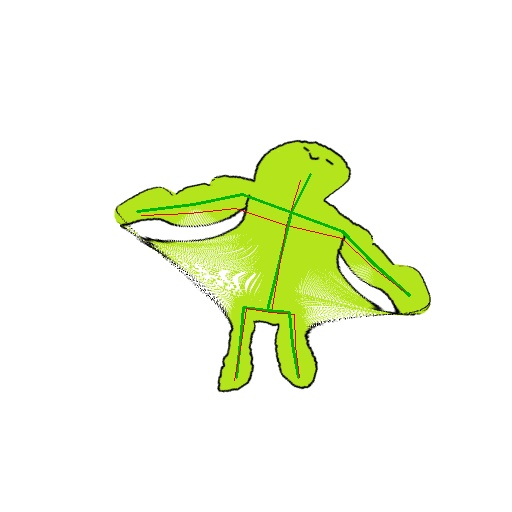

10__bvh_dab__0_t98.jpg


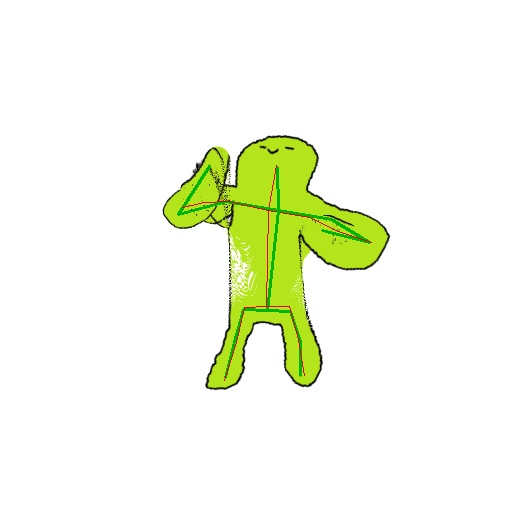

10__bvh_elephant__0_t10.jpg


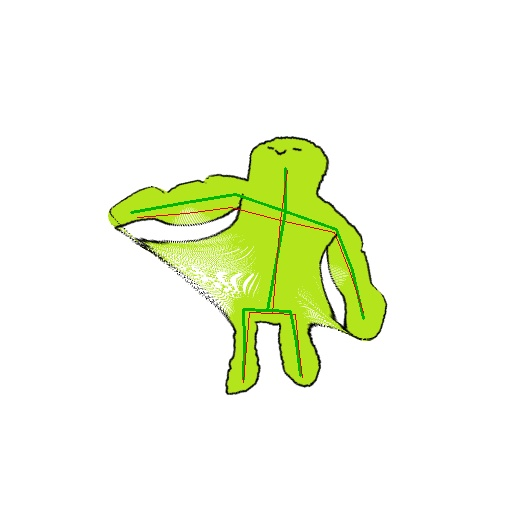

10__bvh_happy_walk__0_t50.jpg


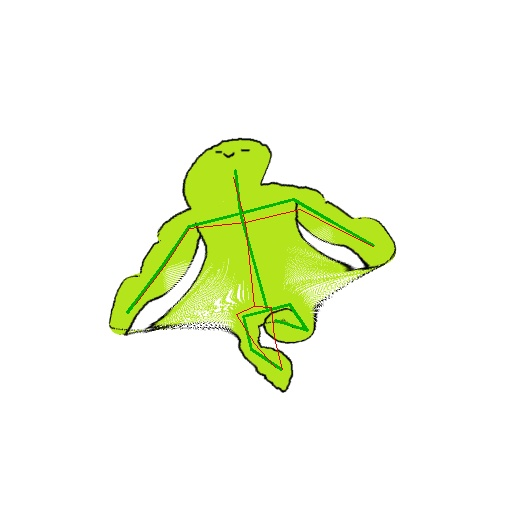

10__bvh_idle__0_t18.jpg


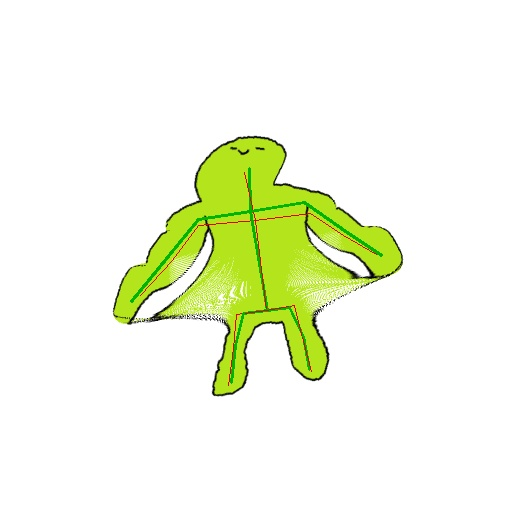

10__bvh_jesse_dance__0_t30.jpg


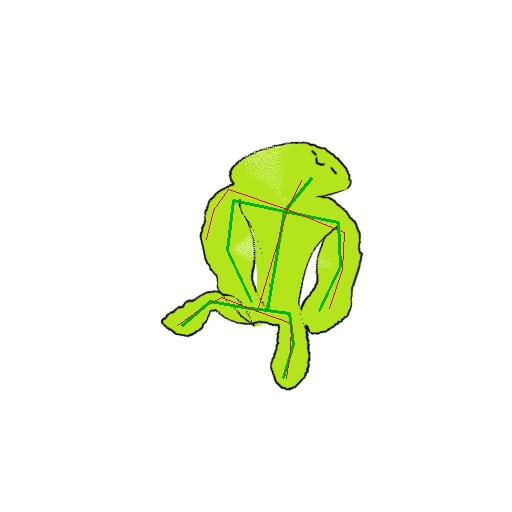

10__bvh_jumping__0_t24.jpg


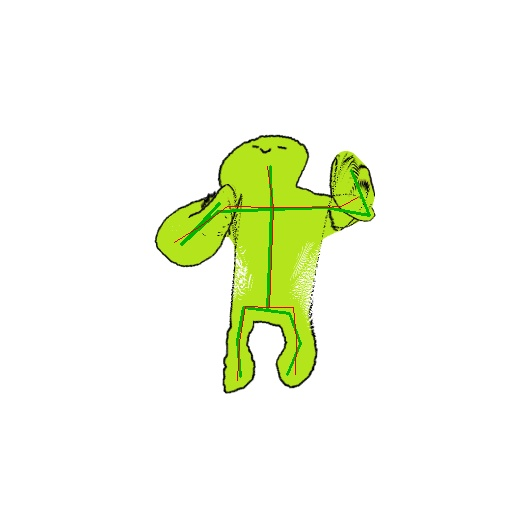

10__bvh_jumping_jacks__0_t54.jpg


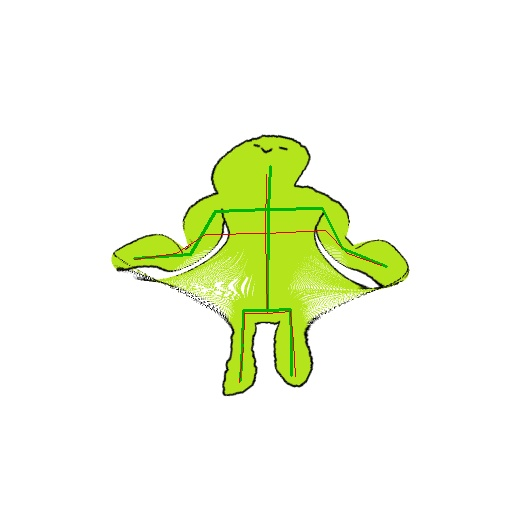

10__bvh_kick_ball__0_t48.jpg


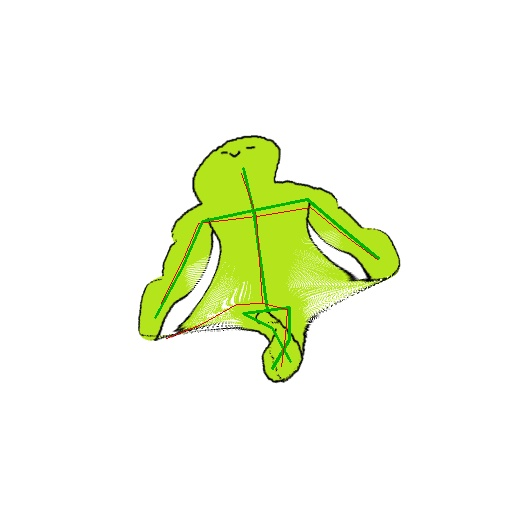

10__bvh_laugh__0_t16.jpg


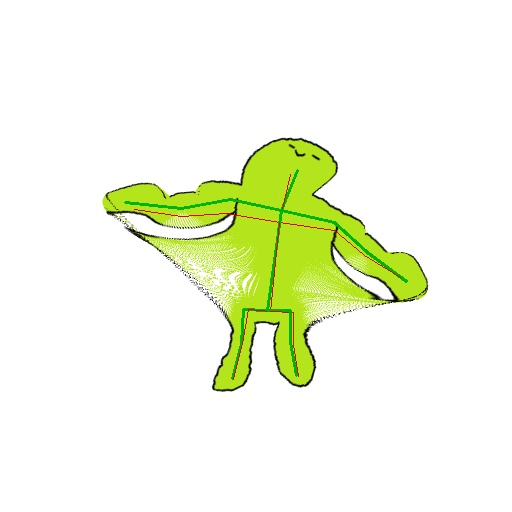

10__bvh_march__0_t24.jpg


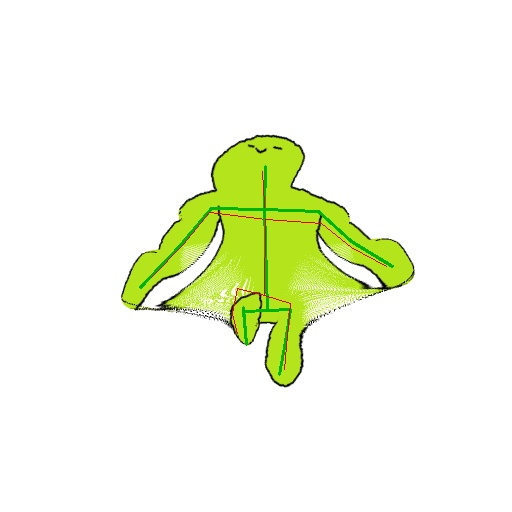

10__bvh_monkey__0_t8.jpg


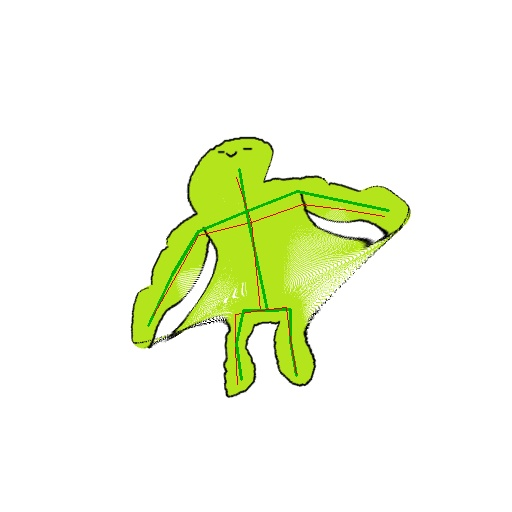

10__bvh_point__0_t40.jpg


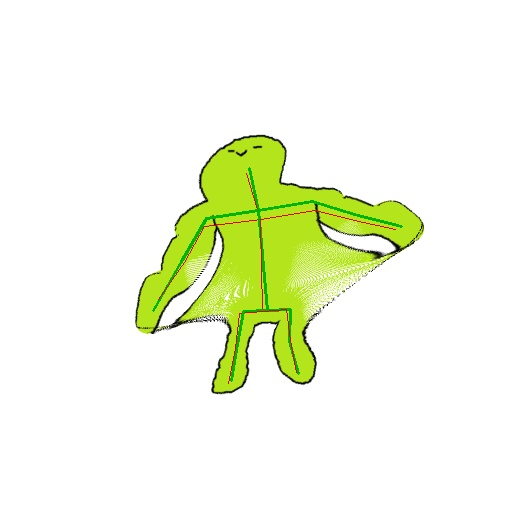

10__bvh_reach_tiptoe__0_t20.jpg


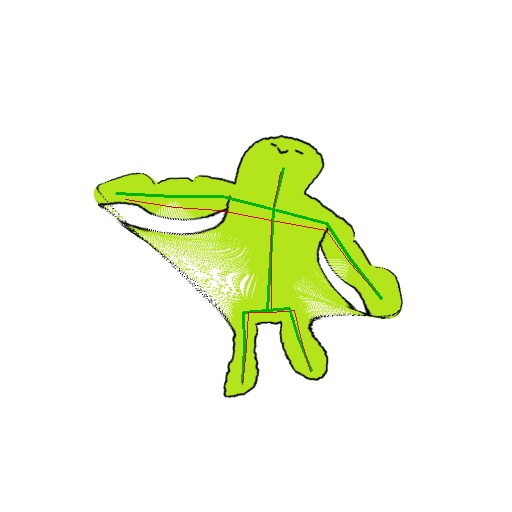

10__bvh_sad_walk__0_t40.jpg


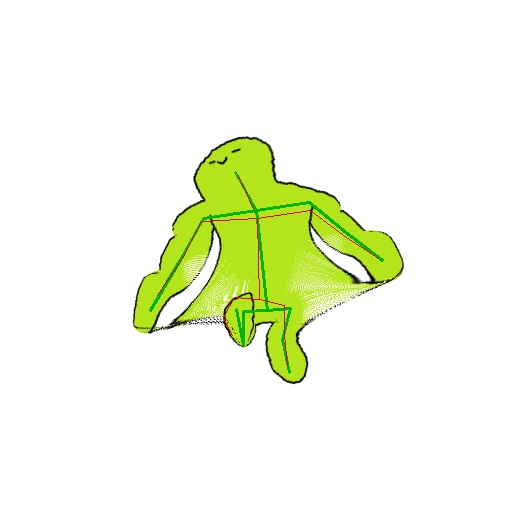

10__bvh_search_ground__0_t52.jpg


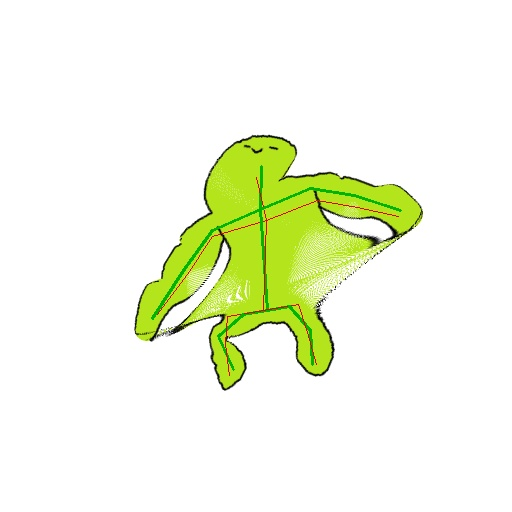

10__bvh_stand_still__0_t26.jpg


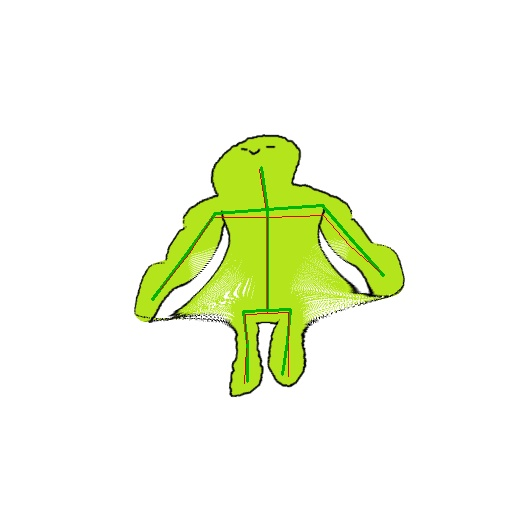

10__bvh_swim__0_t28.jpg


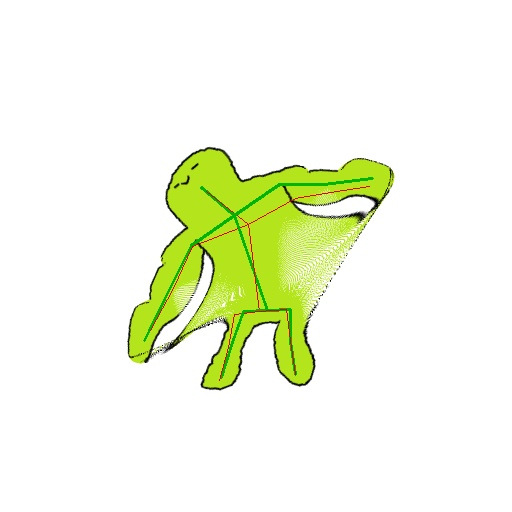

10__bvh_very_happy__0_t18.jpg


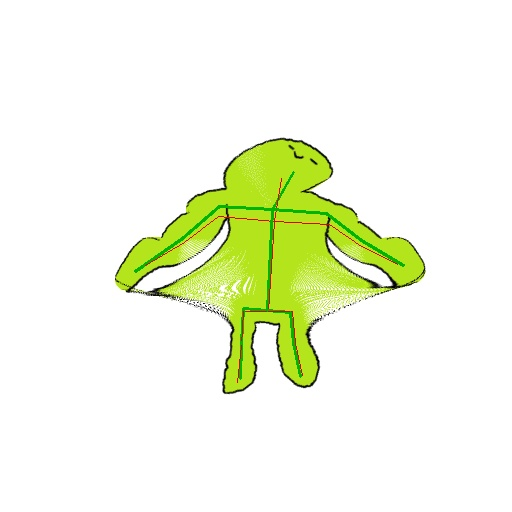

10__bvh_wave_hello__0_t40.jpg


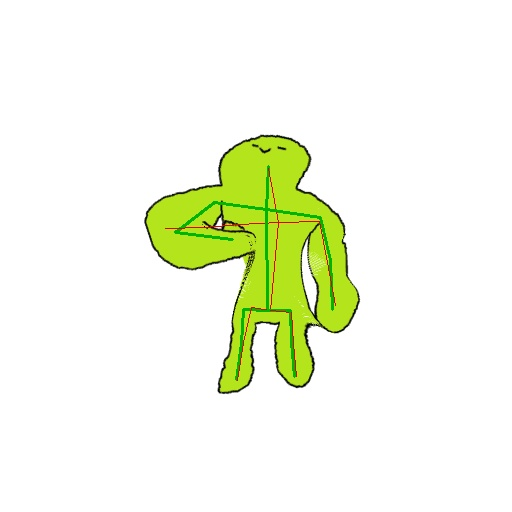

10__bvh_zombie__0_t46.jpg


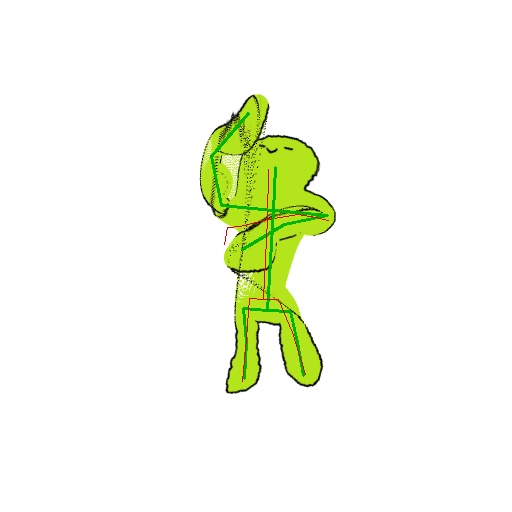

1__bvh_bird__0_t24.jpg


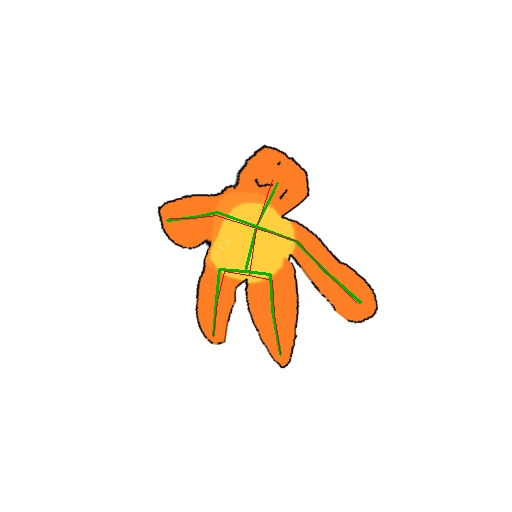

1__bvh_dab__0_t98.jpg


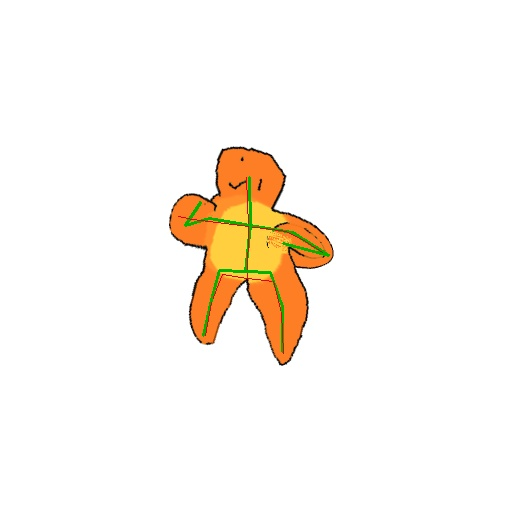

1__bvh_elephant__0_t42.jpg


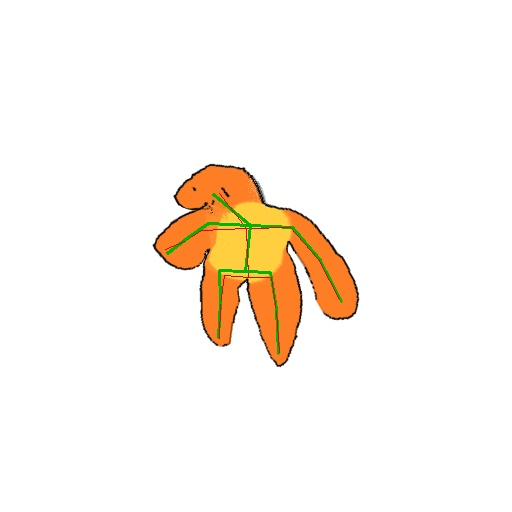

1__bvh_happy_walk__0_t30.jpg


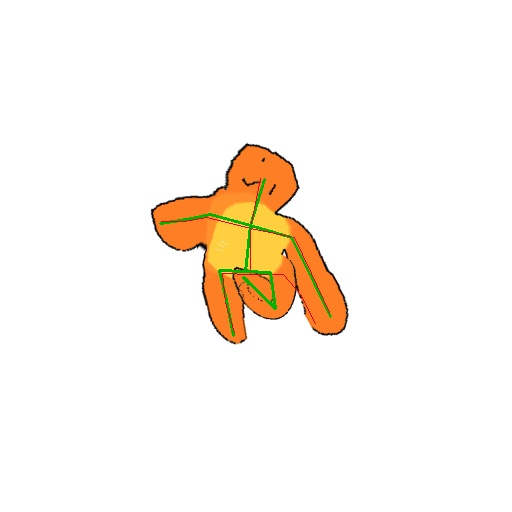

1__bvh_idle__0_t34.jpg


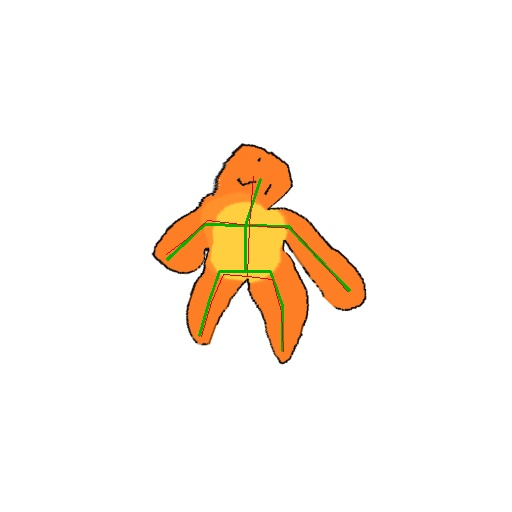

1__bvh_jesse_dance__0_t16.jpg


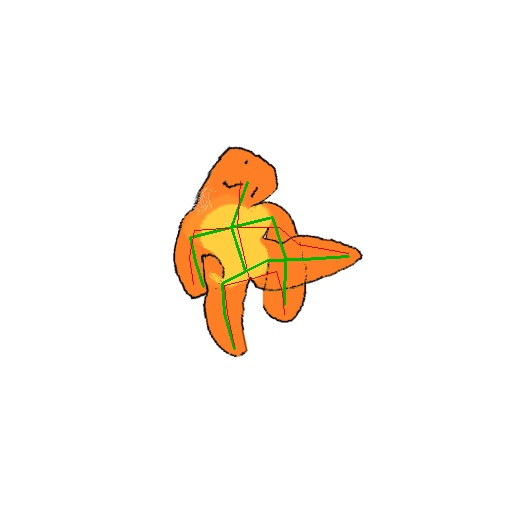

1__bvh_jumping__0_t32.jpg


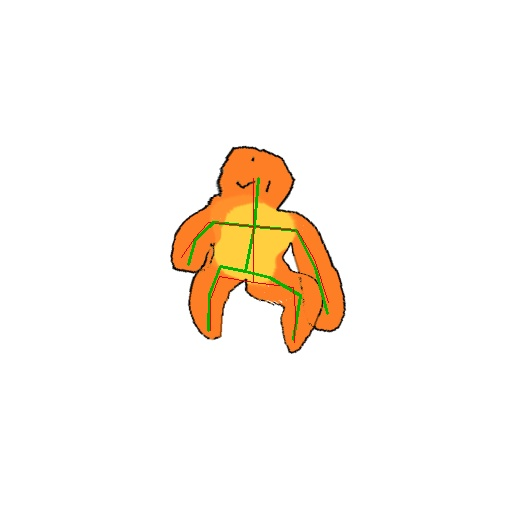

1__bvh_jumping_jacks__0_t58.jpg


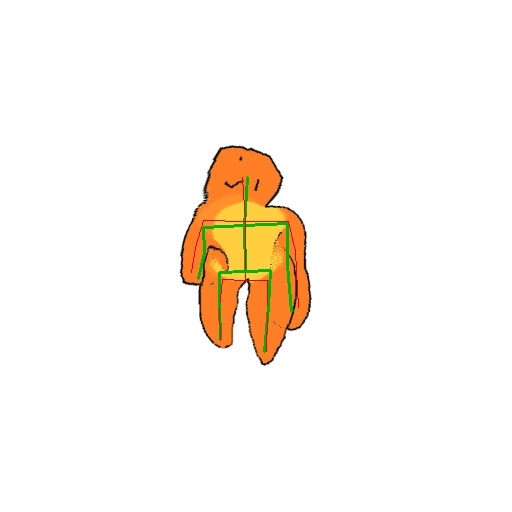

1__bvh_kick_ball__0_t48.jpg


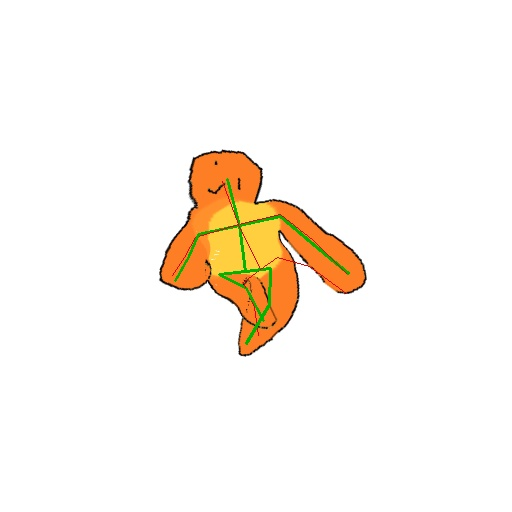

1__bvh_laugh__0_t24.jpg


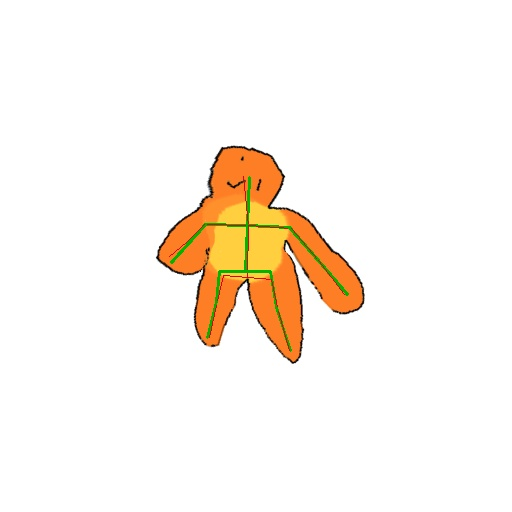

1__bvh_march__0_t34.jpg


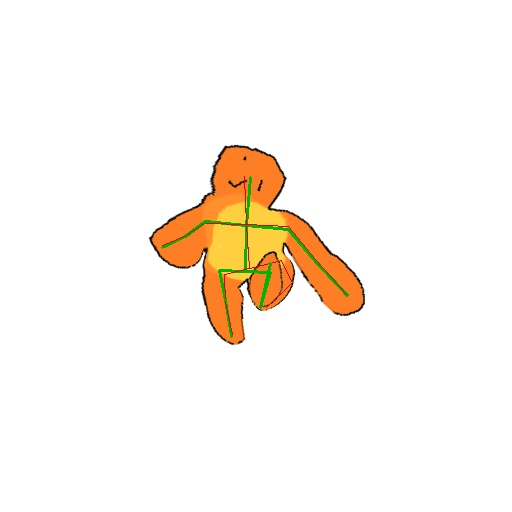

1__bvh_monkey__0_t54.jpg


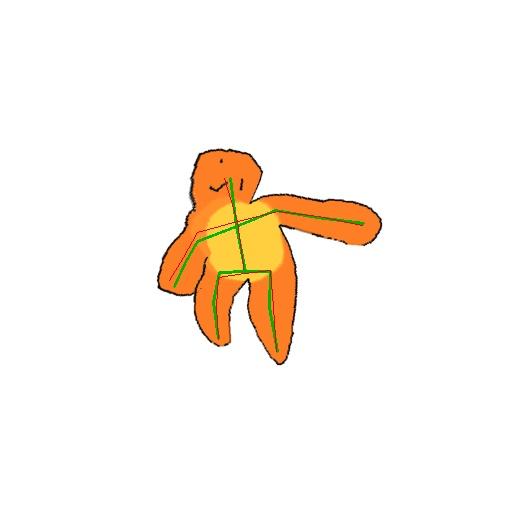

1__bvh_point__0_t24.jpg


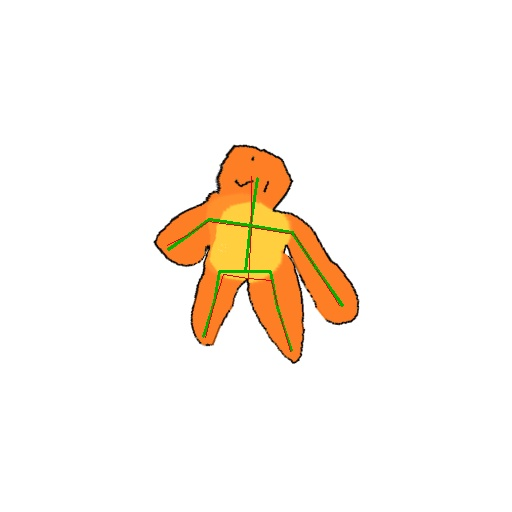

1__bvh_reach_tiptoe__0_t22.jpg


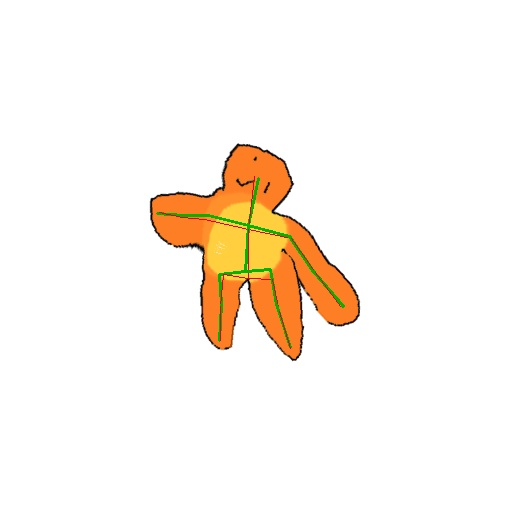

1__bvh_sad_walk__0_t40.jpg


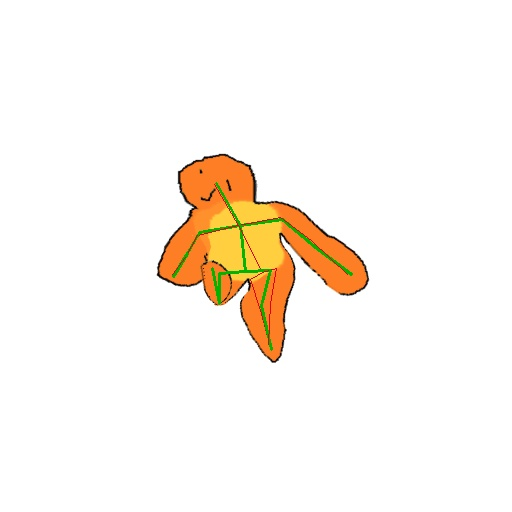

1__bvh_search_ground__0_t24.jpg


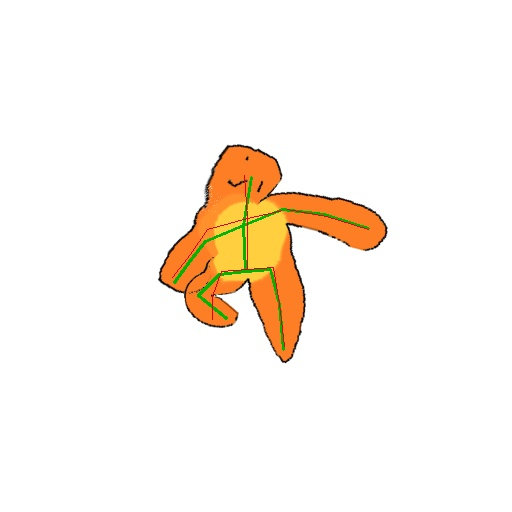

1__bvh_stand_still__0_t8.jpg


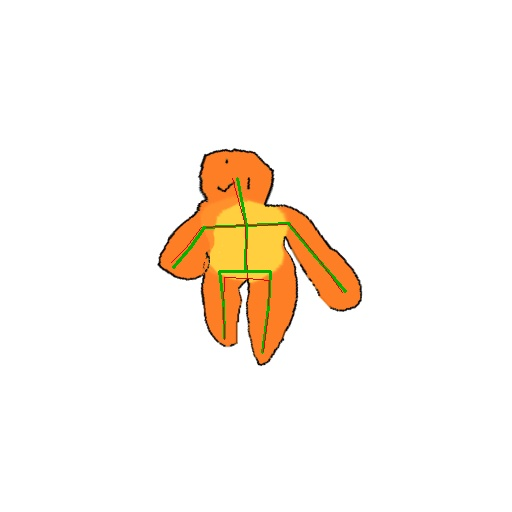

1__bvh_swim__0_t38.jpg


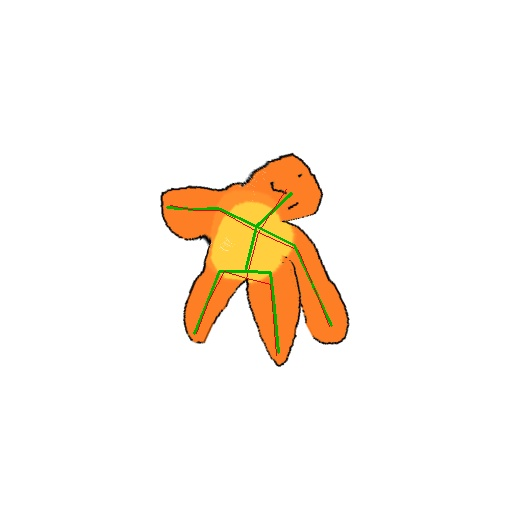

1__bvh_very_happy__0_t32.jpg


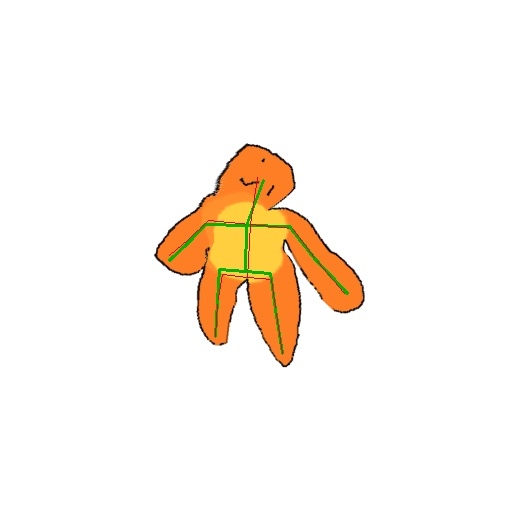

1__bvh_wave_hello__0_t34.jpg


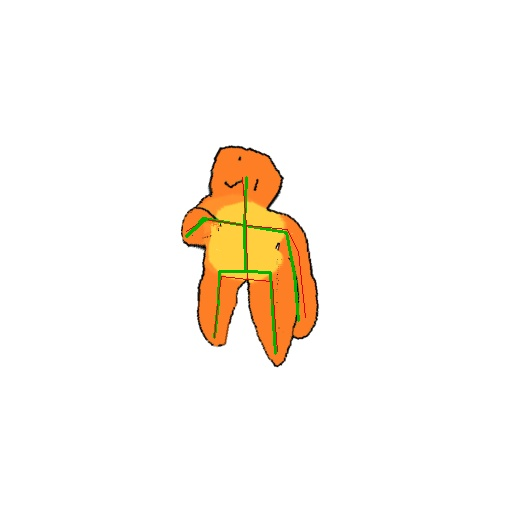

1__bvh_zombie__0_t46.jpg


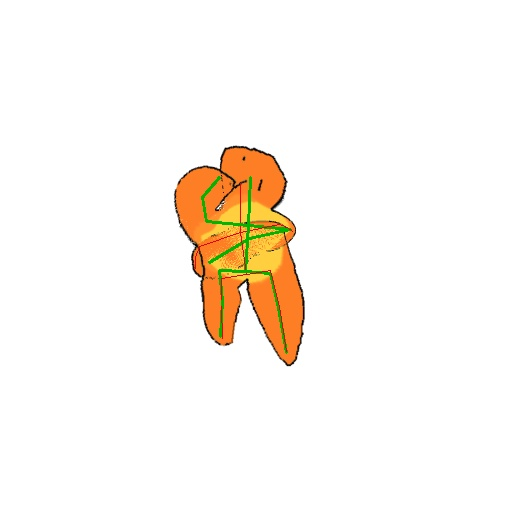

2__bvh_bird__0_t24.jpg


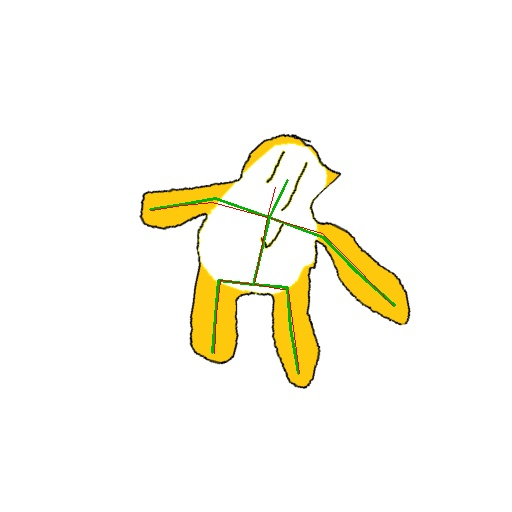

2__bvh_dab__0_t12.jpg


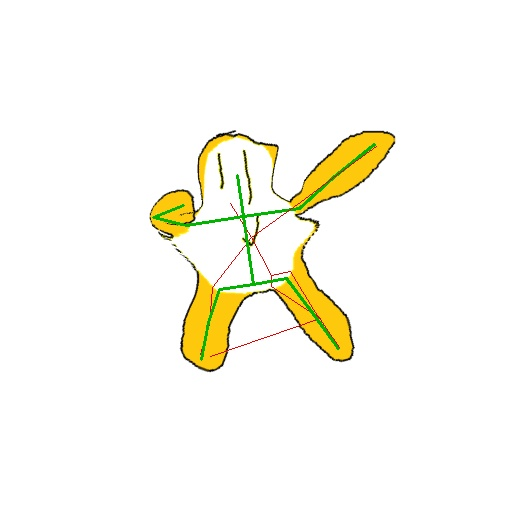

2__bvh_elephant__0_t42.jpg


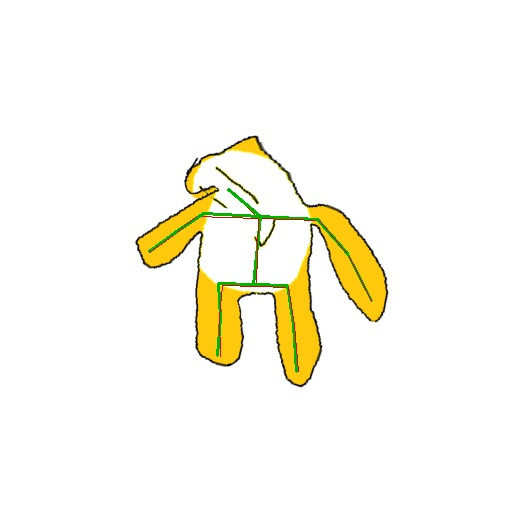

2__bvh_happy_walk__0_t32.jpg


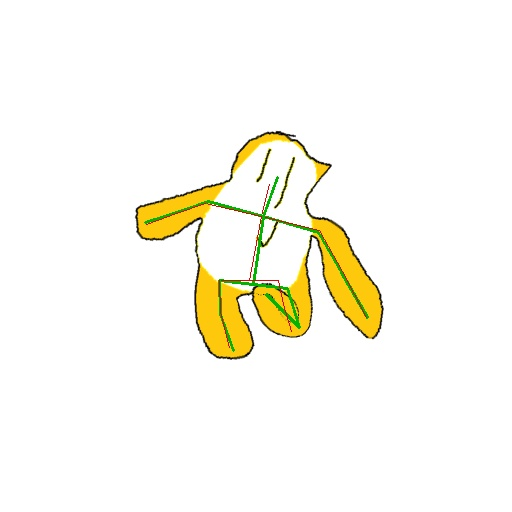

2__bvh_idle__0_t34.jpg


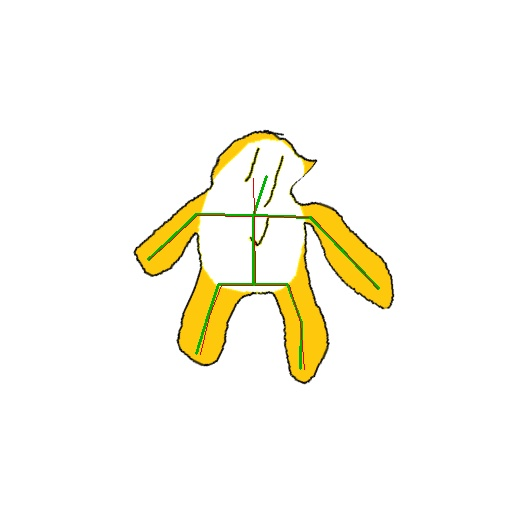

2__bvh_jesse_dance__0_t130.jpg


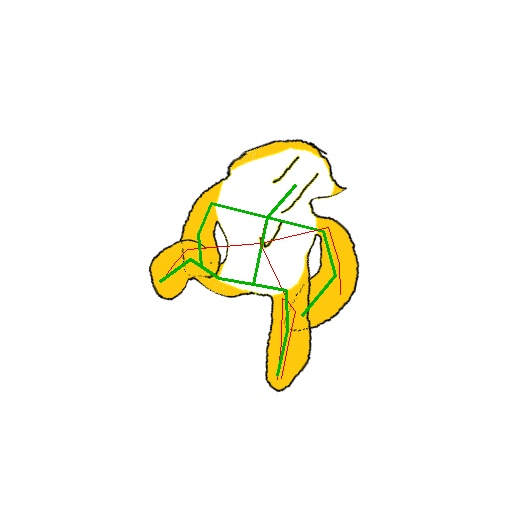

2__bvh_jumping__0_t24.jpg


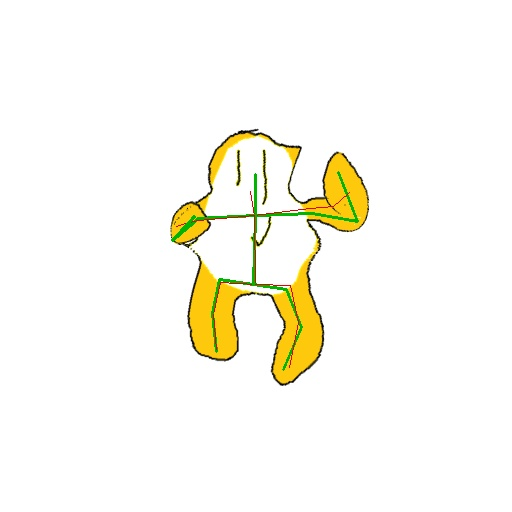

2__bvh_jumping_jacks__0_t24.jpg


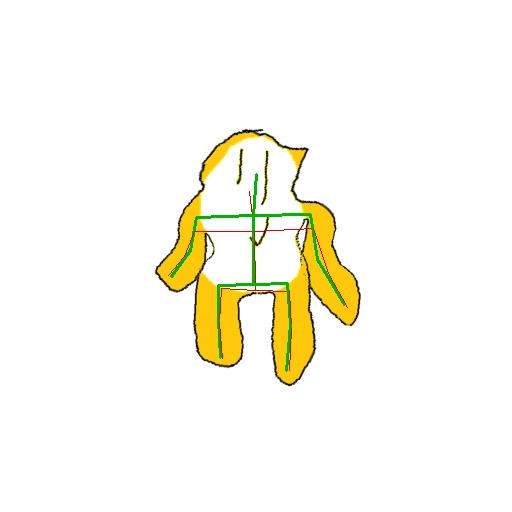

2__bvh_kick_ball__0_t48.jpg


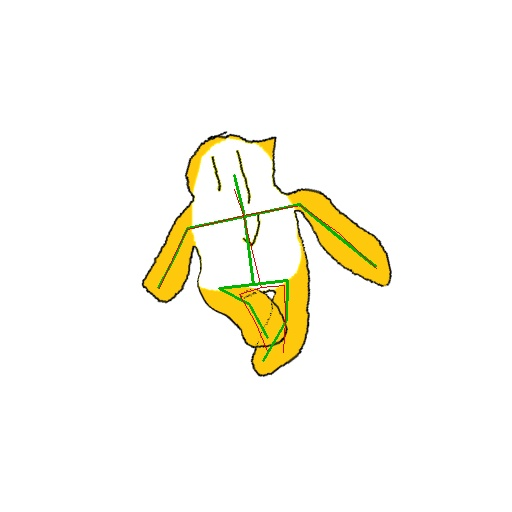

2__bvh_laugh__0_t36.jpg


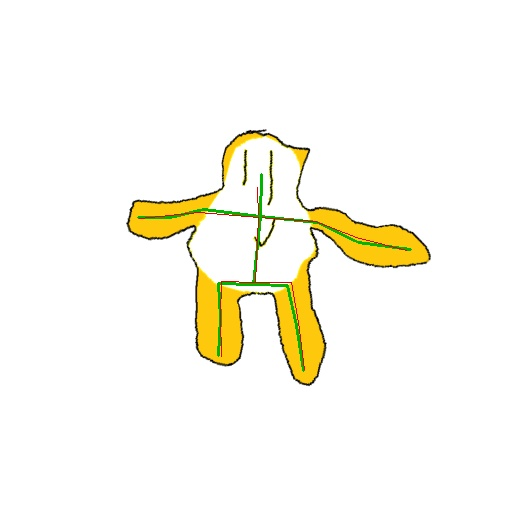

2__bvh_march__0_t12.jpg


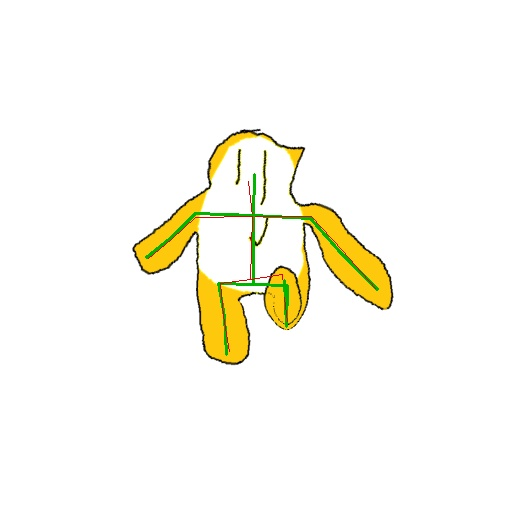

2__bvh_monkey__0_t44.jpg


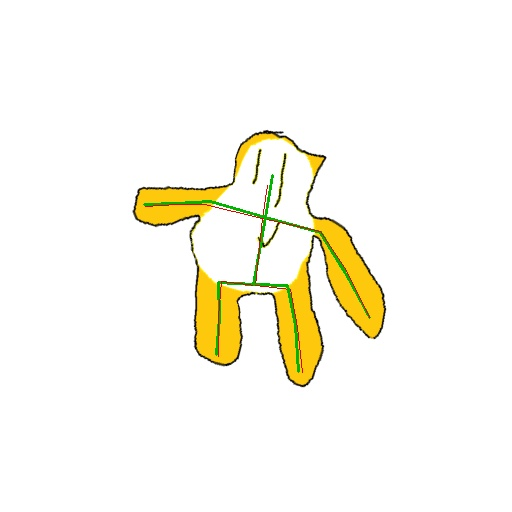

2__bvh_point__0_t28.jpg


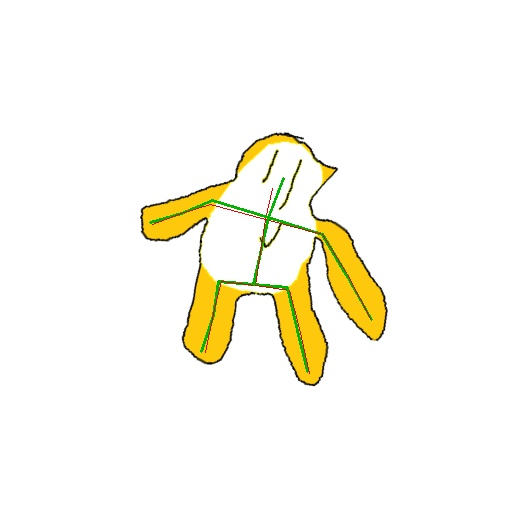

2__bvh_reach_tiptoe__0_t22.jpg


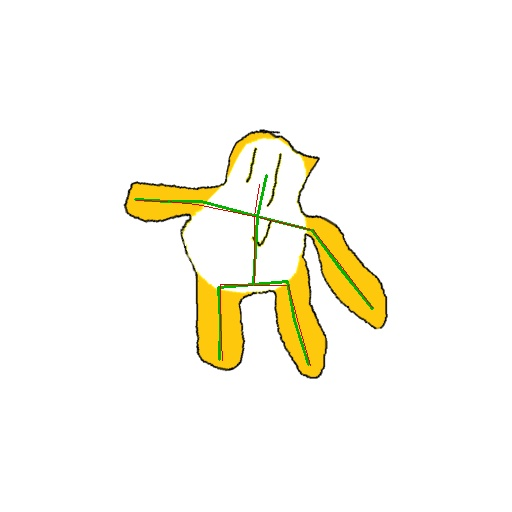

2__bvh_sad_walk__0_t54.jpg


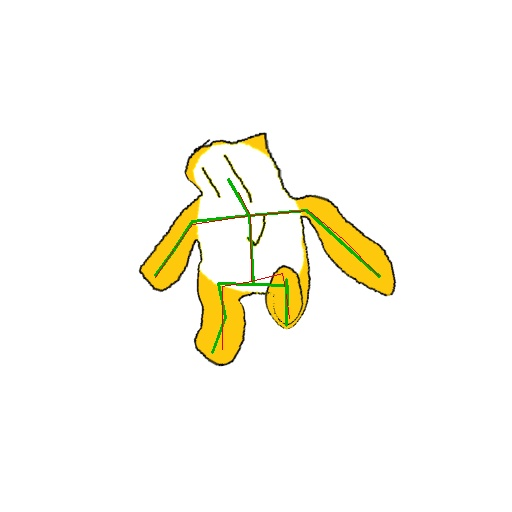

2__bvh_search_ground__0_t26.jpg


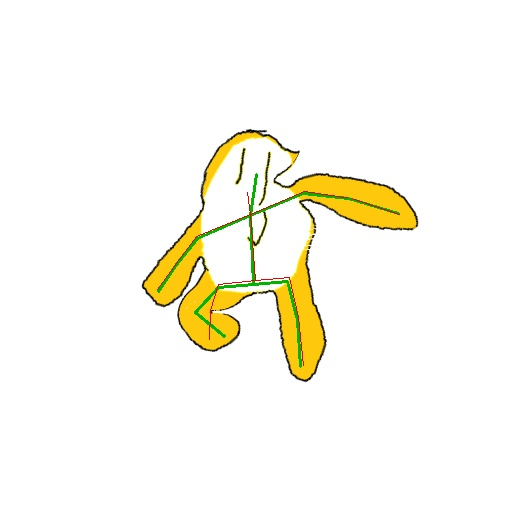

2__bvh_stand_still__0_t38.jpg


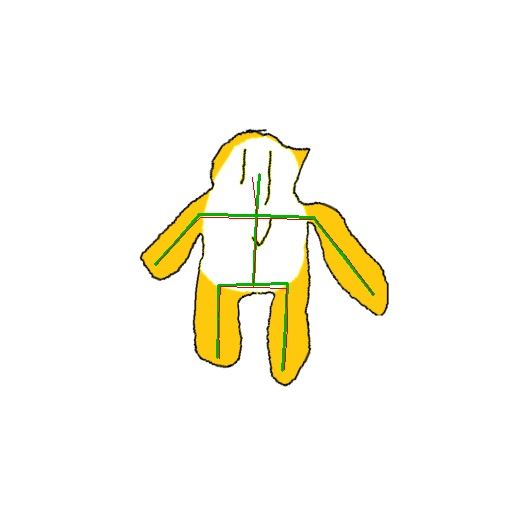

2__bvh_swim__0_t8.jpg


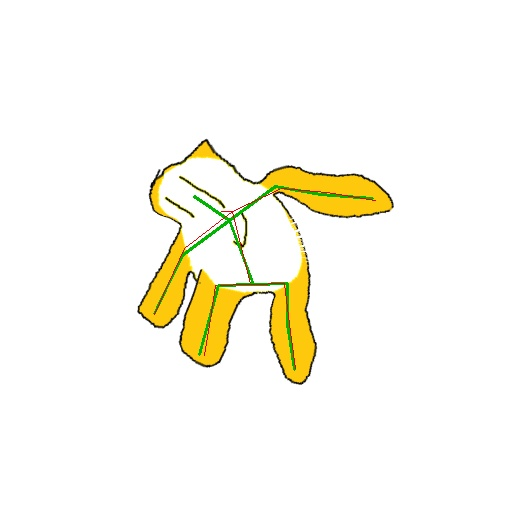

2__bvh_very_happy__0_t32.jpg


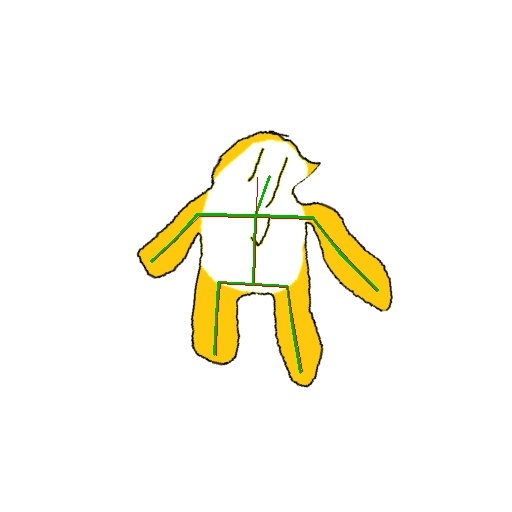

2__bvh_wave_hello__0_t34.jpg


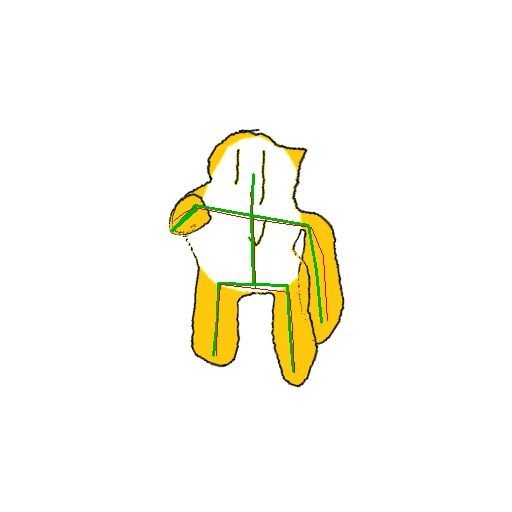

2__bvh_zombie__0_t28.jpg


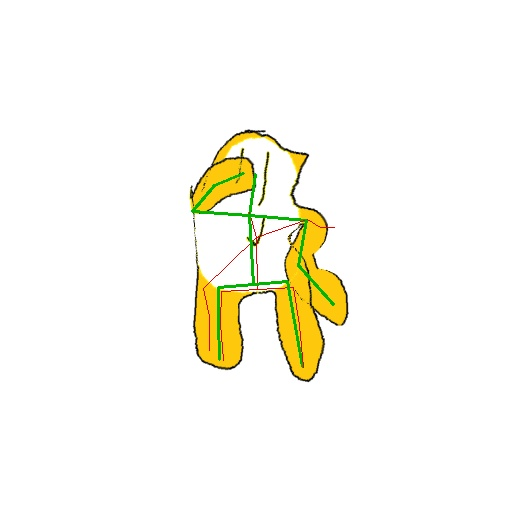

3__bvh_bird__0_t34.jpg


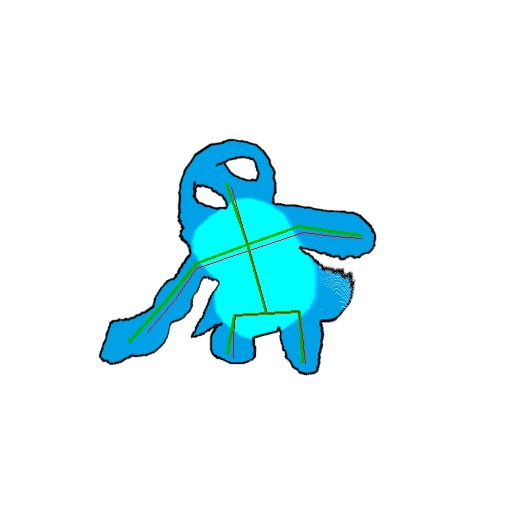

3__bvh_dab__0_t98.jpg


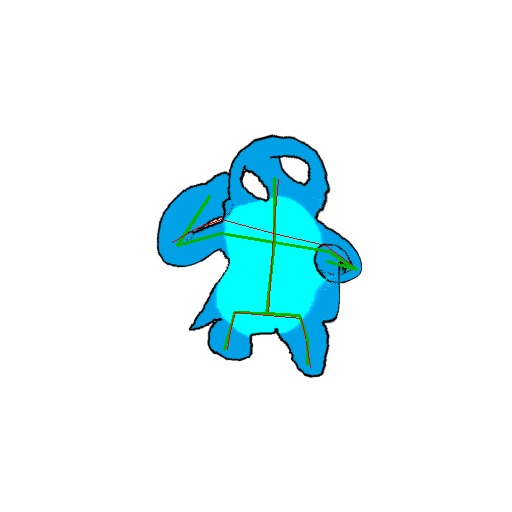

3__bvh_elephant__0_t36.jpg


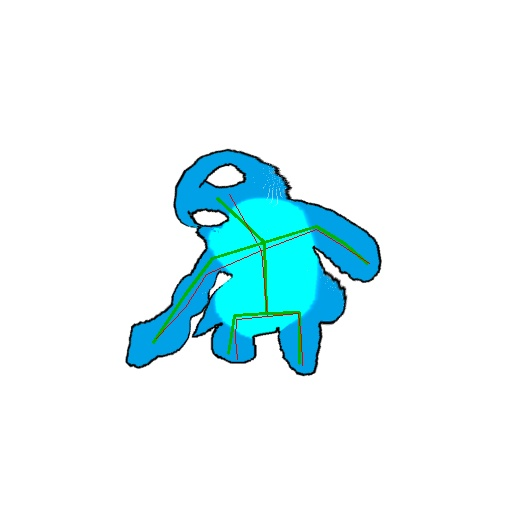

3__bvh_happy_walk__0_t30.jpg


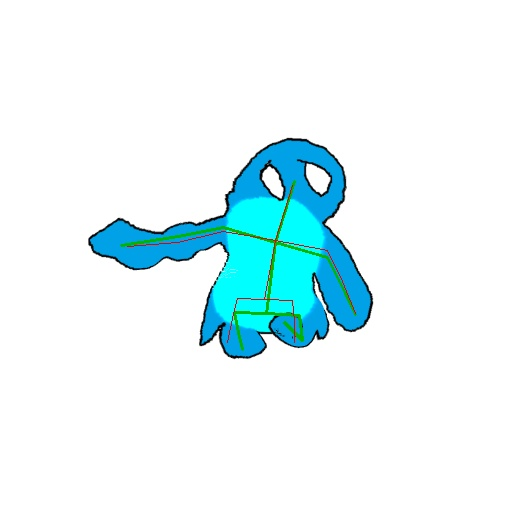

3__bvh_idle__0_t32.jpg


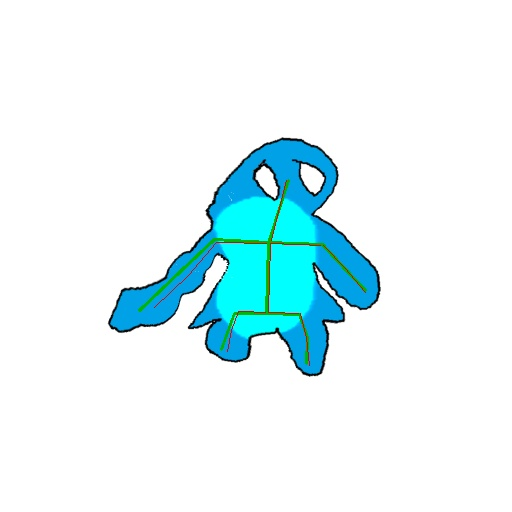

3__bvh_jesse_dance__0_t16.jpg


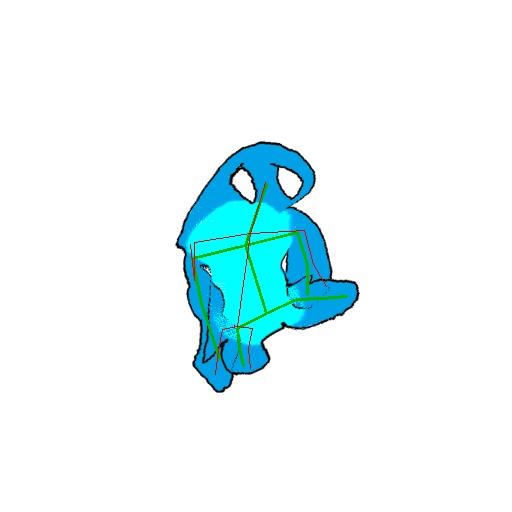

3__bvh_jumping__0_t24.jpg


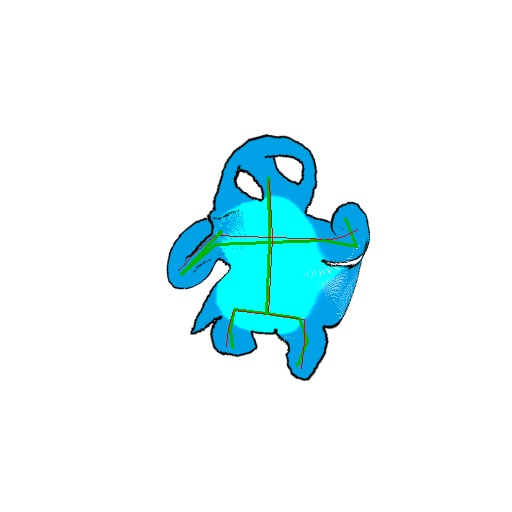

3__bvh_jumping_jacks__0_t58.jpg


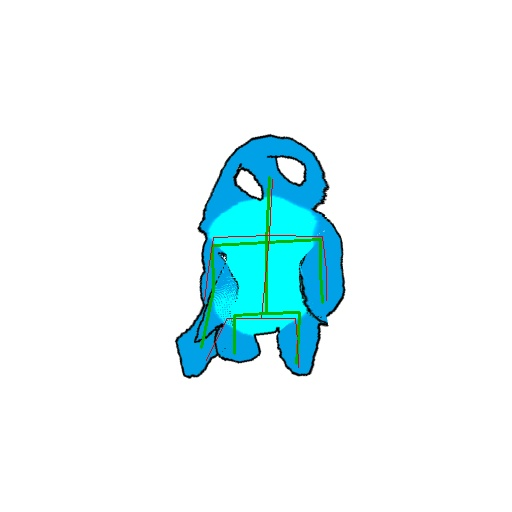

3__bvh_kick_ball__0_t48.jpg


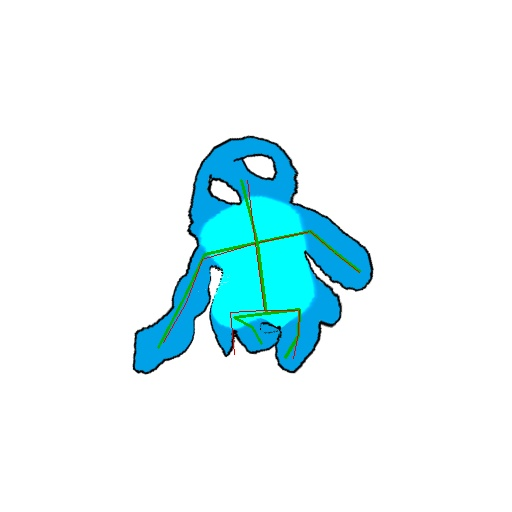

3__bvh_laugh__0_t44.jpg


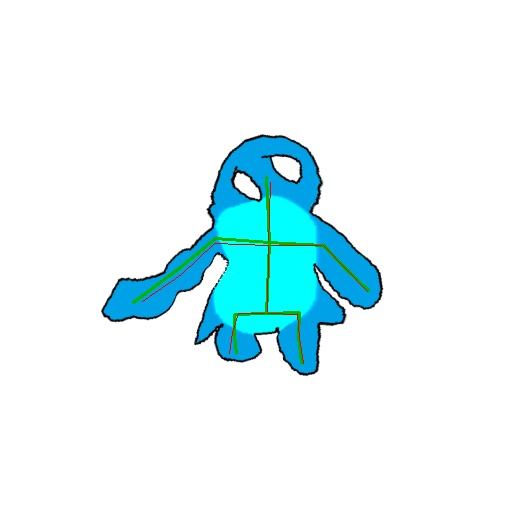

3__bvh_march__0_t30.jpg


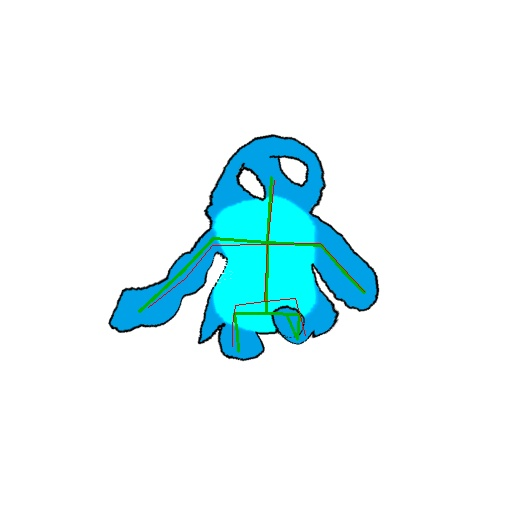

3__bvh_monkey__0_t54.jpg


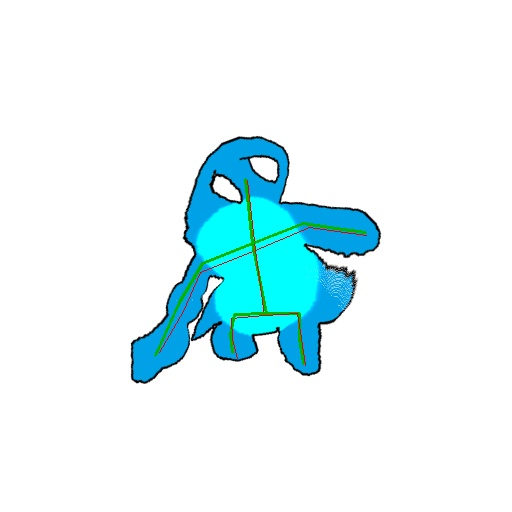

3__bvh_point__0_t40.jpg


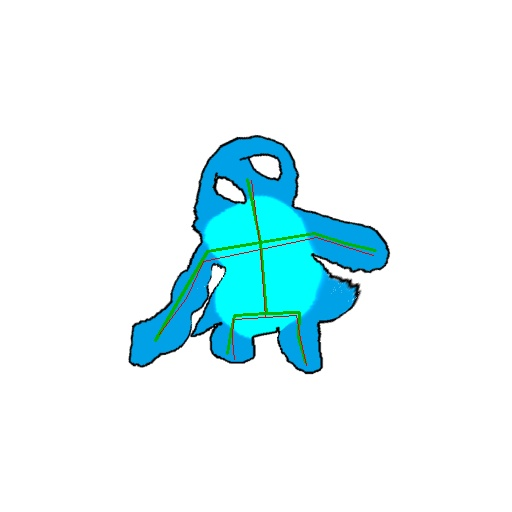

3__bvh_reach_tiptoe__0_t20.jpg


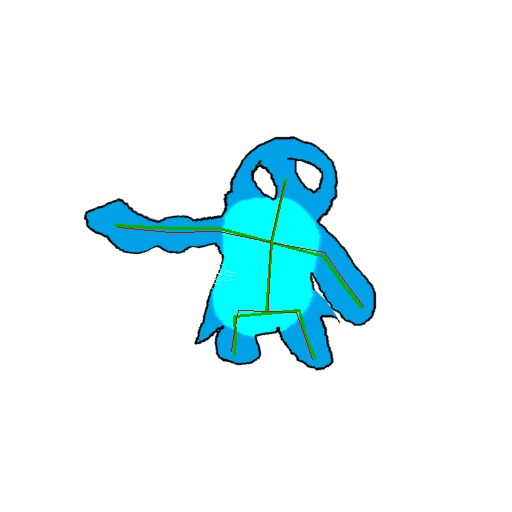

3__bvh_sad_walk__0_t40.jpg


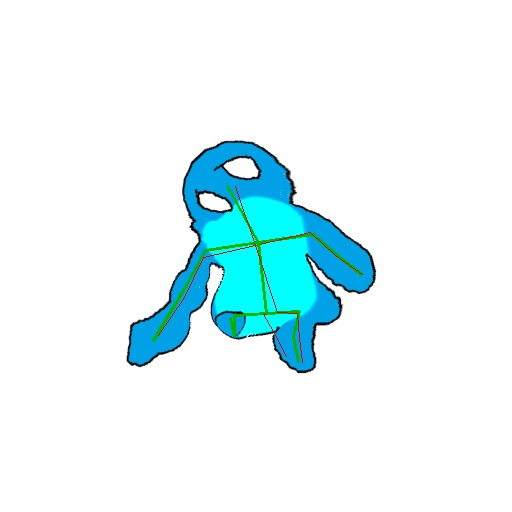

3__bvh_search_ground__0_t22.jpg


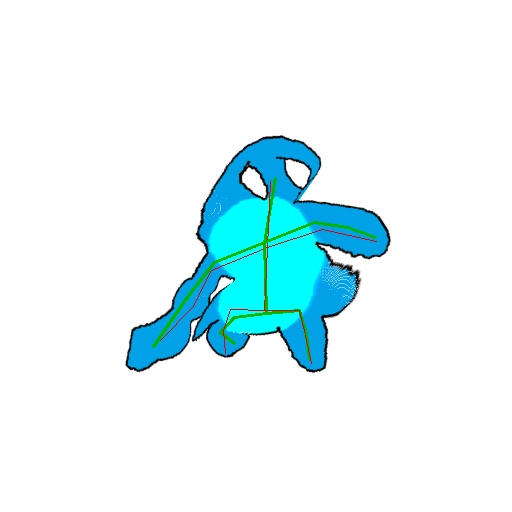

3__bvh_stand_still__0_t8.jpg


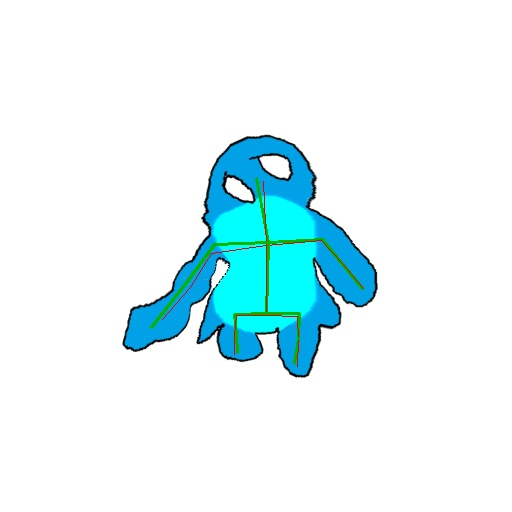

3__bvh_swim__0_t26.jpg


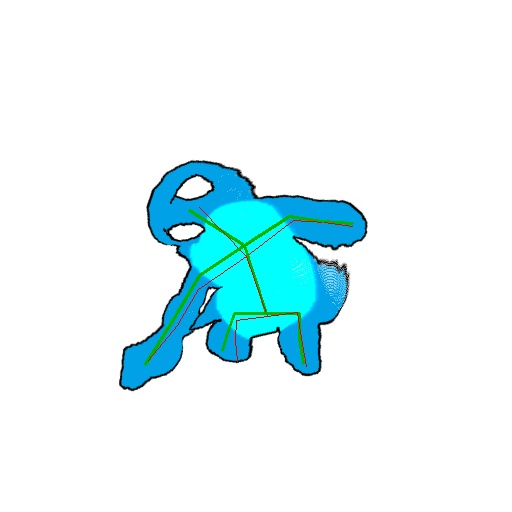

3__bvh_very_happy__0_t16.jpg


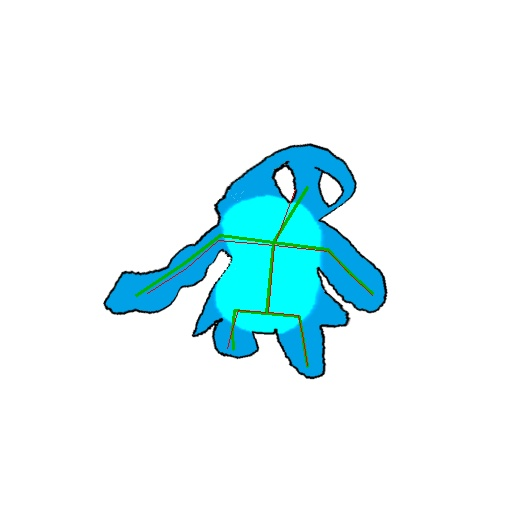

3__bvh_wave_hello__0_t30.jpg


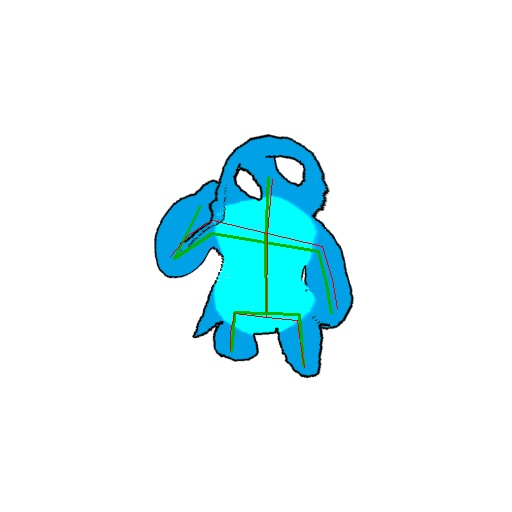

3__bvh_zombie__0_t48.jpg


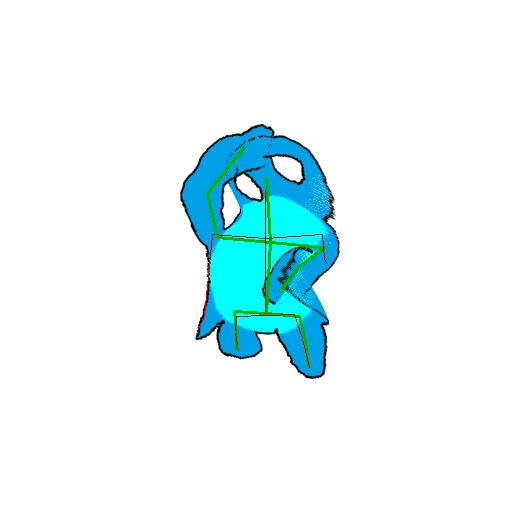

4__bvh_bird__0_t32.jpg


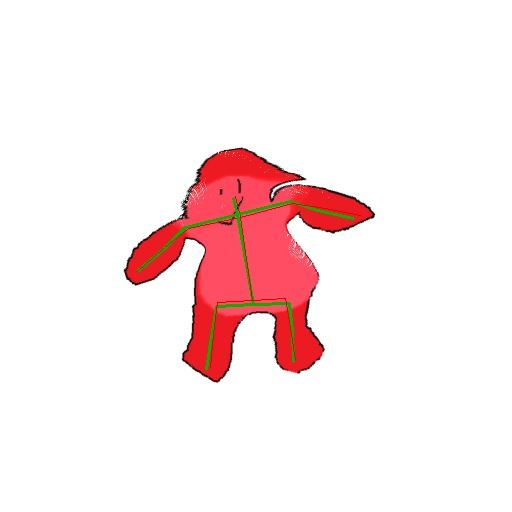

4__bvh_dab__0_t106.jpg


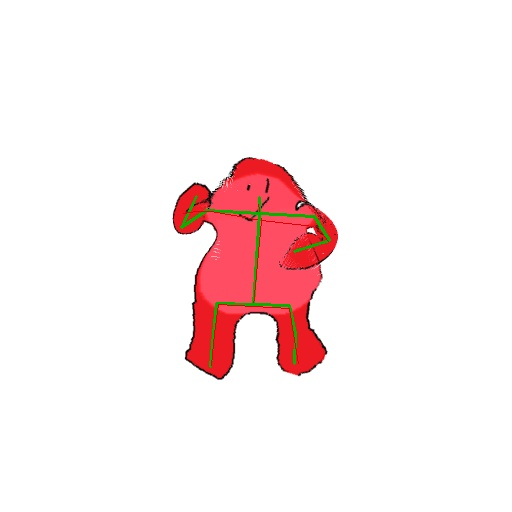

4__bvh_elephant__0_t40.jpg


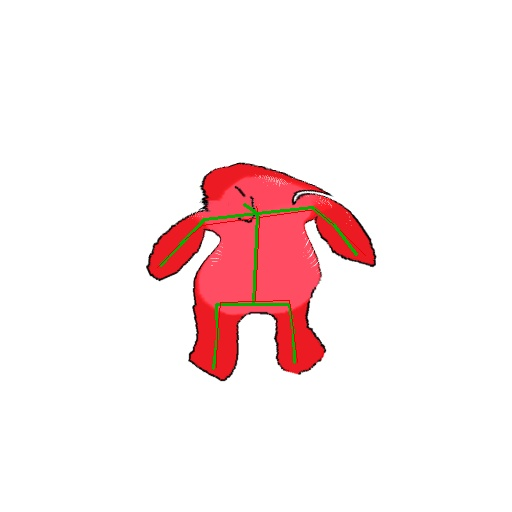

4__bvh_happy_walk__0_t8.jpg


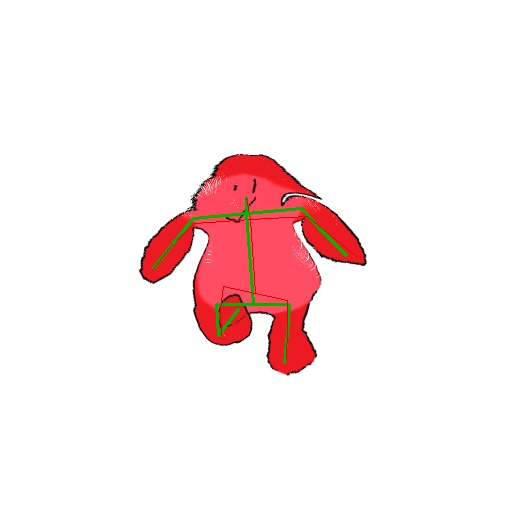

4__bvh_idle__0_t34.jpg


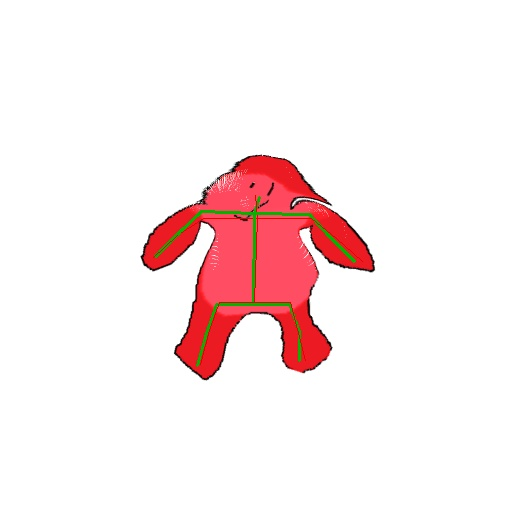

4__bvh_jesse_dance__0_t130.jpg


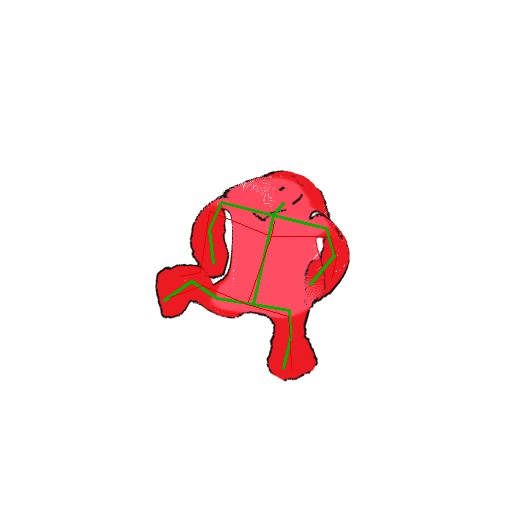

4__bvh_jumping__0_t24.jpg


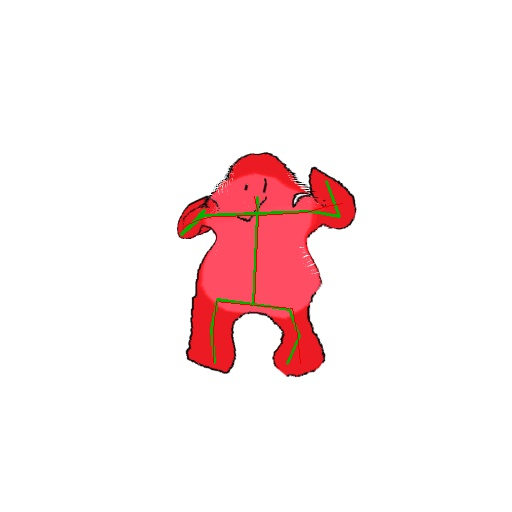

4__bvh_jumping_jacks__0_t40.jpg


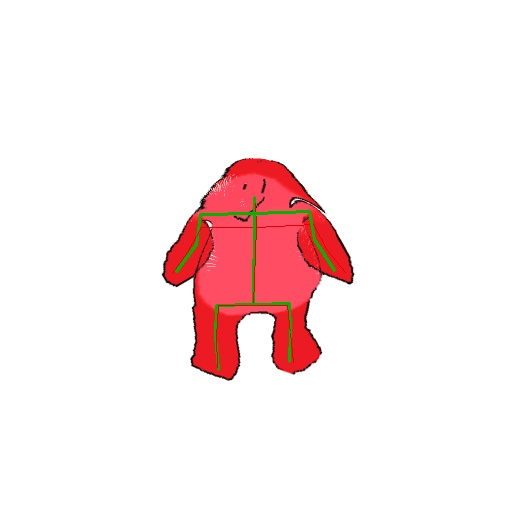

4__bvh_kick_ball__0_t48.jpg


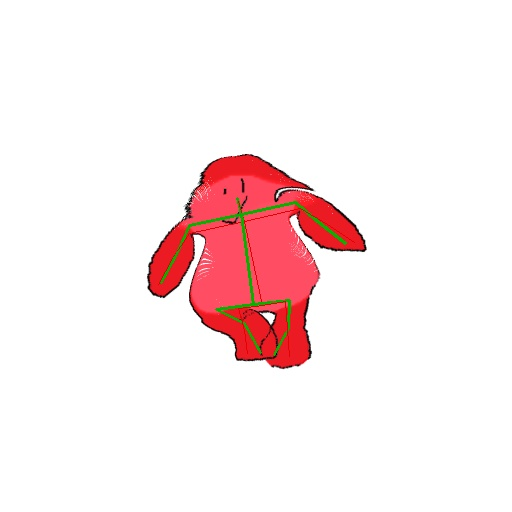

4__bvh_laugh__0_t24.jpg


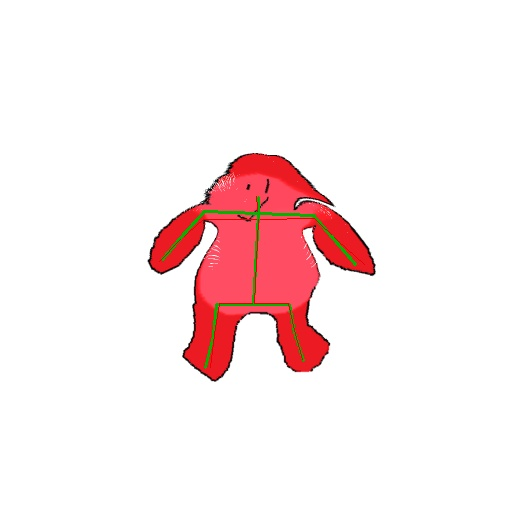

4__bvh_march__0_t30.jpg


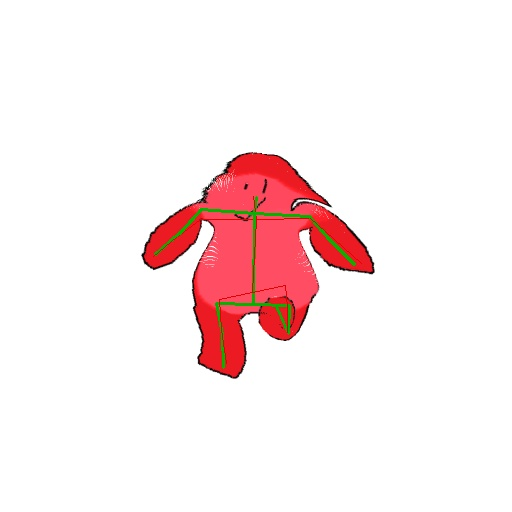

4__bvh_monkey__0_t40.jpg


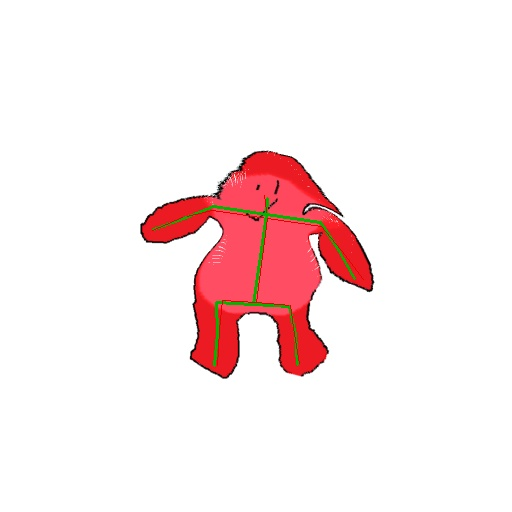

4__bvh_point__0_t8.jpg


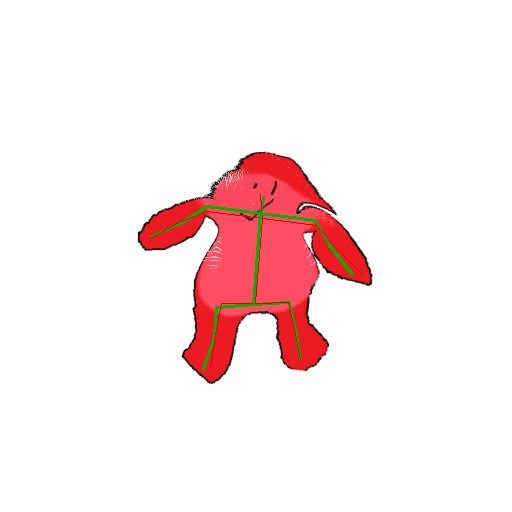

4__bvh_reach_tiptoe__0_t22.jpg


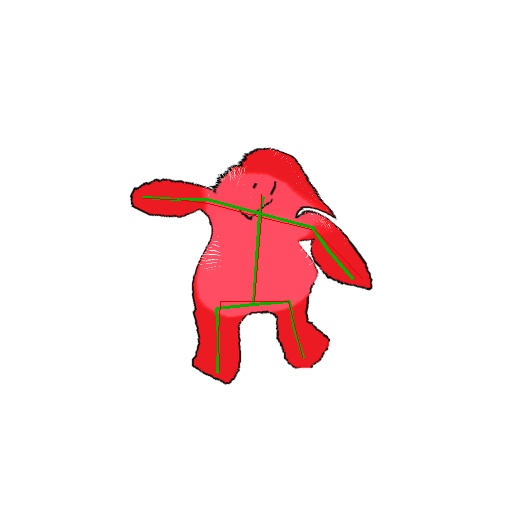

4__bvh_sad_walk__0_t8.jpg


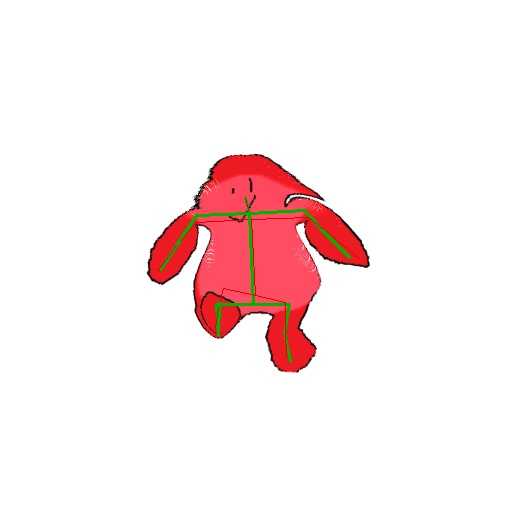

4__bvh_search_ground__0_t40.jpg


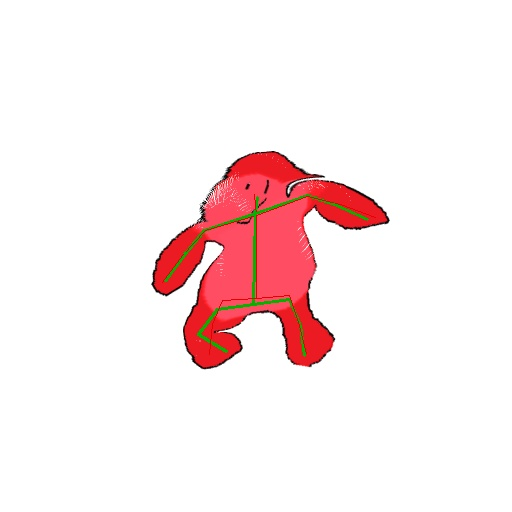

4__bvh_stand_still__0_t10.jpg


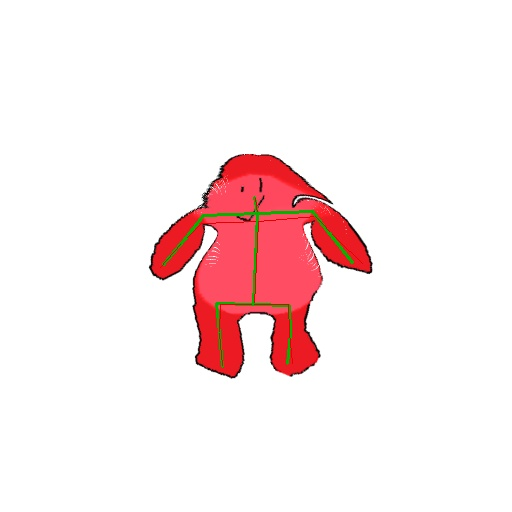

4__bvh_swim__0_t36.jpg


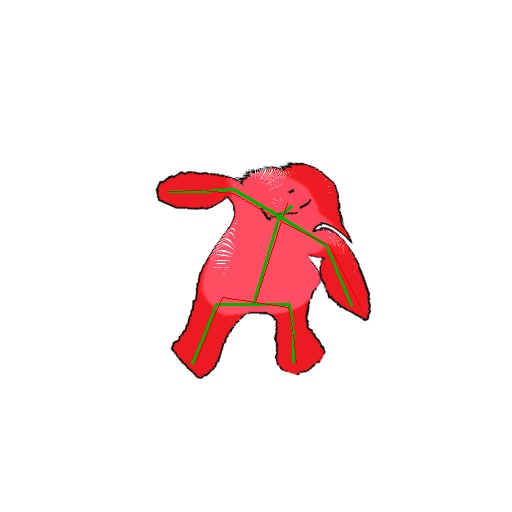

4__bvh_very_happy__0_t8.jpg


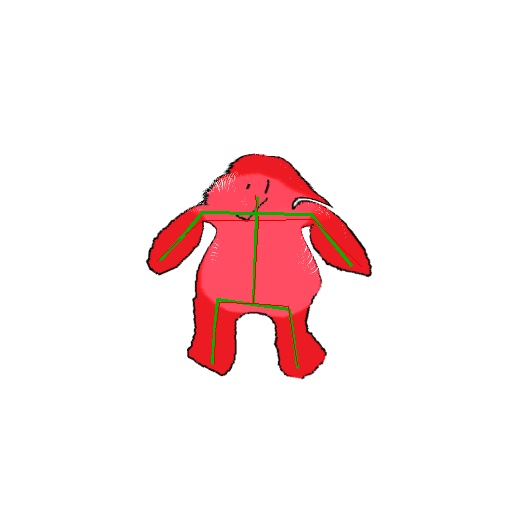

4__bvh_wave_hello__0_t40.jpg


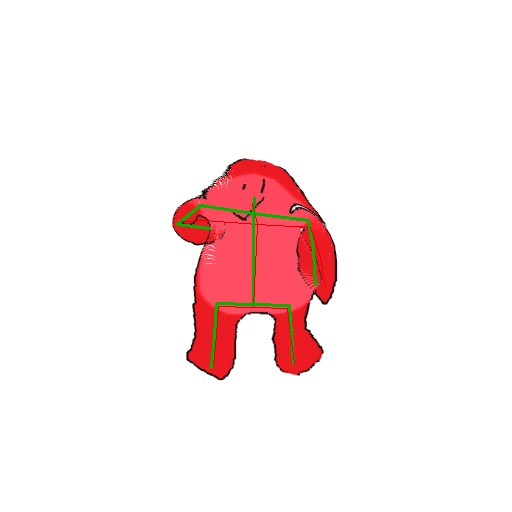

4__bvh_zombie__0_t26.jpg


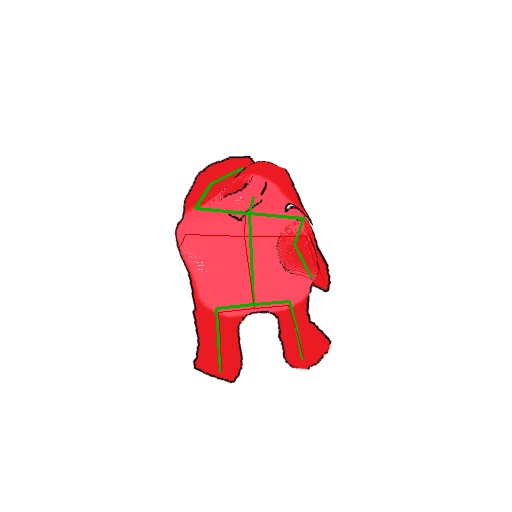

5__bvh_bird__0_t16.jpg


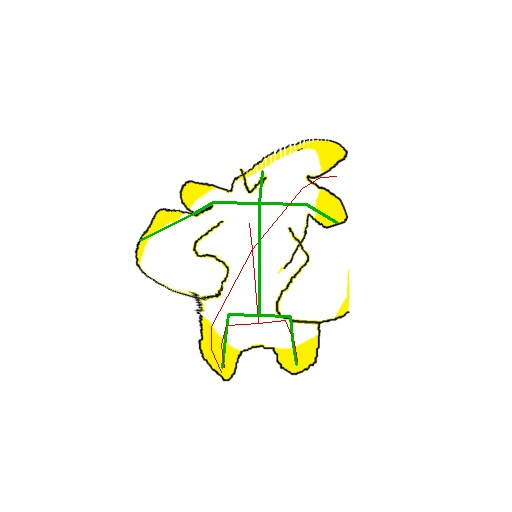

5__bvh_dab__0_t44.jpg


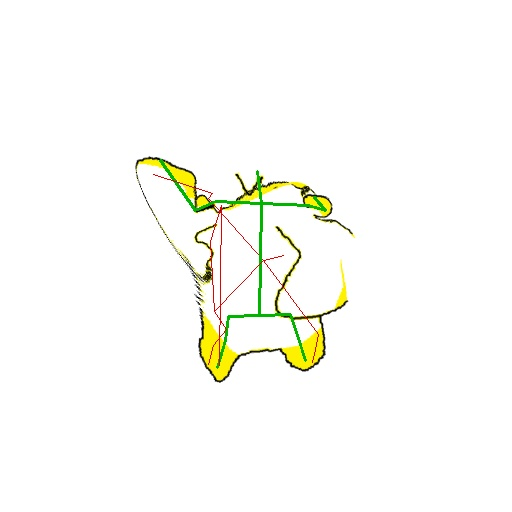

5__bvh_elephant__0_t28.jpg


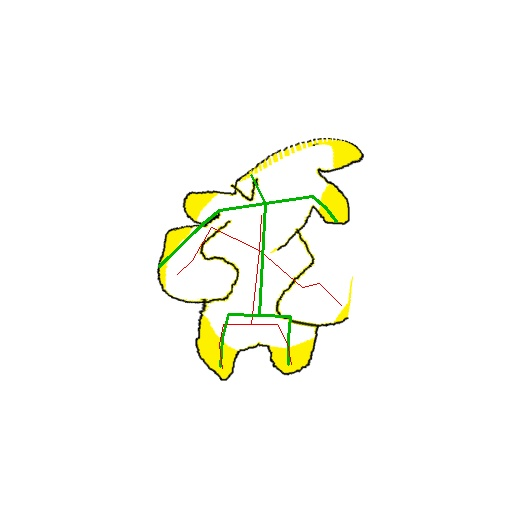

5__bvh_happy_walk__0_t40.jpg


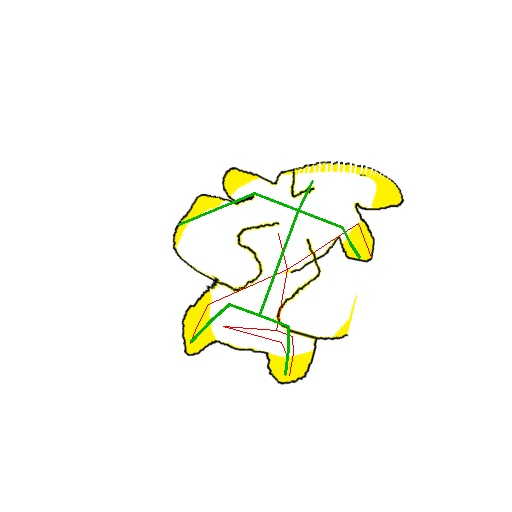

5__bvh_idle__0_t32.jpg


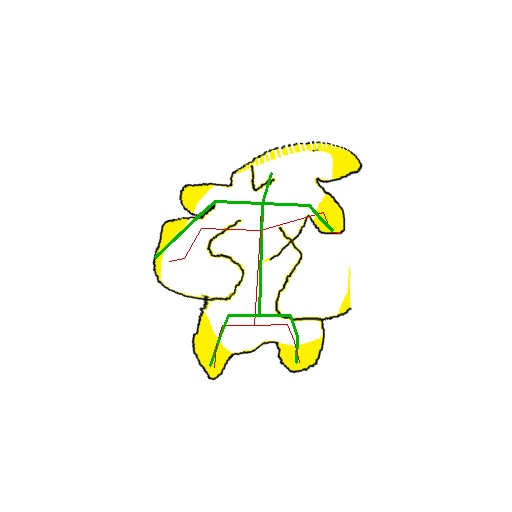

5__bvh_jesse_dance__0_t148.jpg


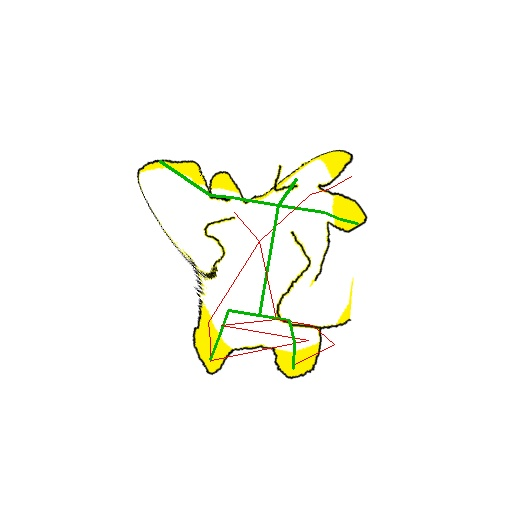

5__bvh_jumping__0_t6.jpg


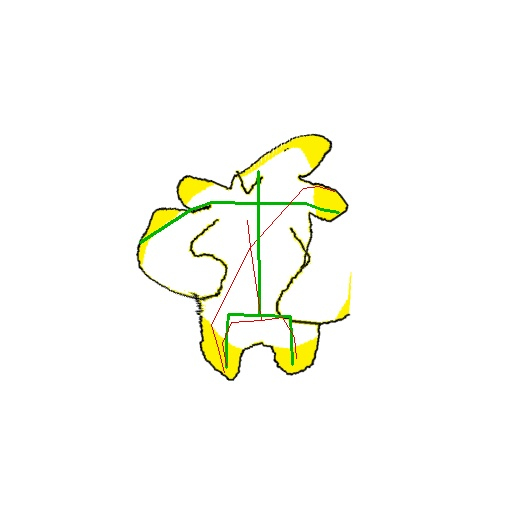

5__bvh_jumping_jacks__0_t20.jpg


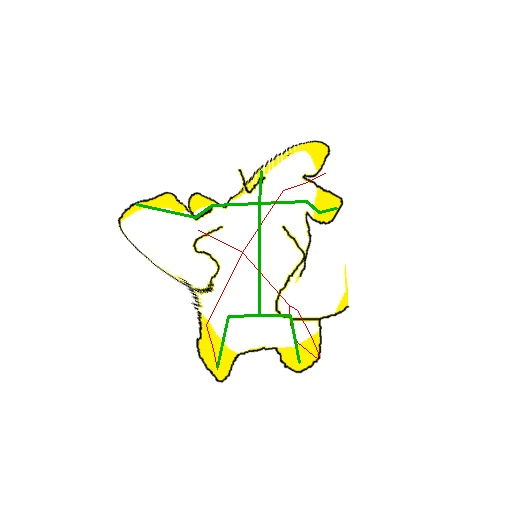

5__bvh_kick_ball__0_t38.jpg


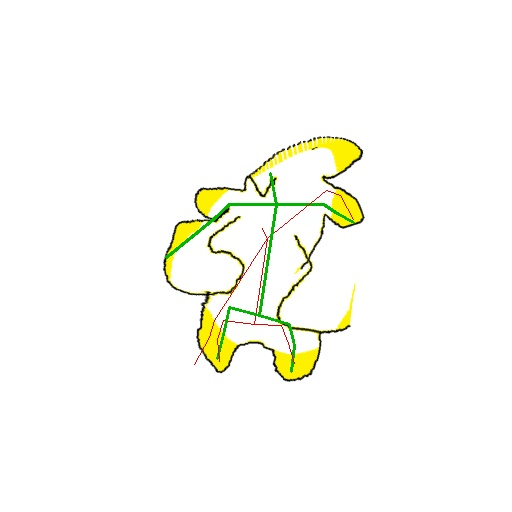

5__bvh_laugh__0_t34.jpg


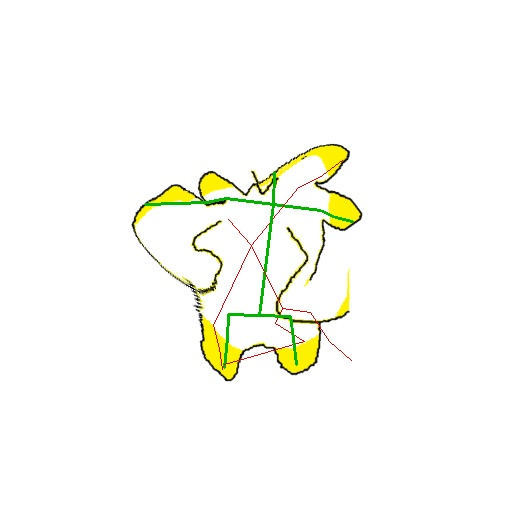

5__bvh_march__0_t34.jpg


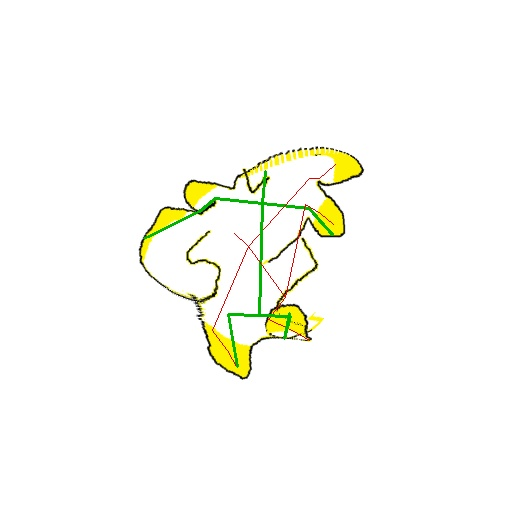

5__bvh_monkey__0_t48.jpg


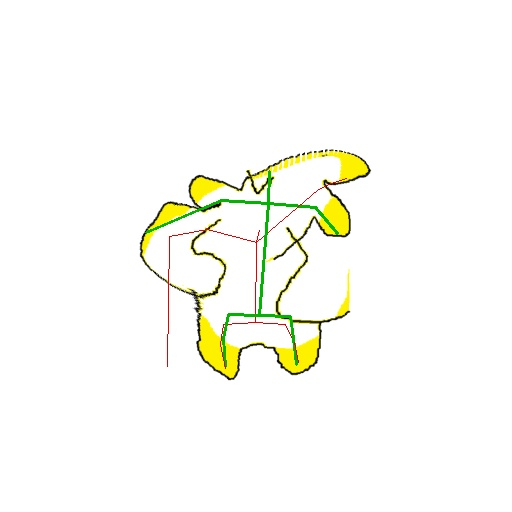

5__bvh_point__0_t50.jpg


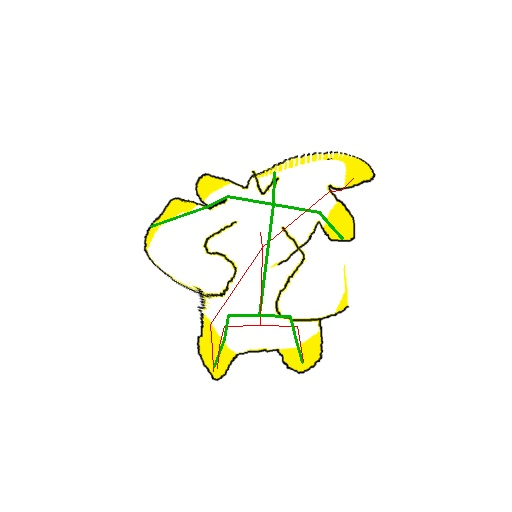

5__bvh_reach_tiptoe__0_t40.jpg


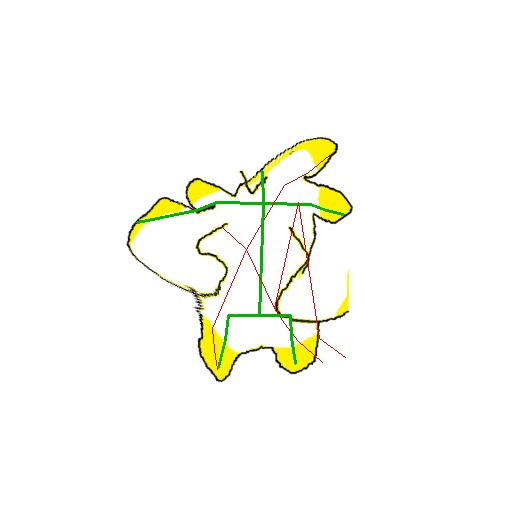

5__bvh_sad_walk__0_t50.jpg


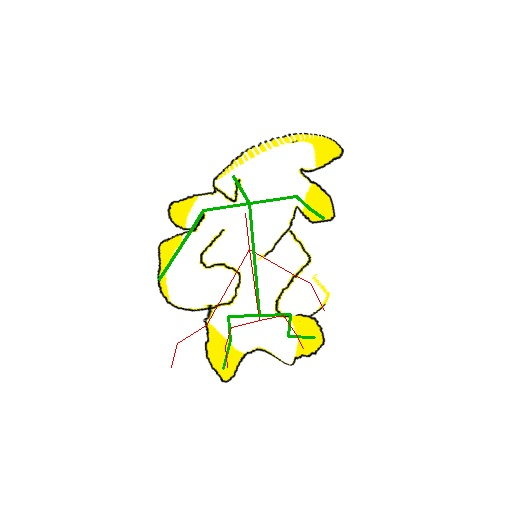

5__bvh_search_ground__0_t52.jpg


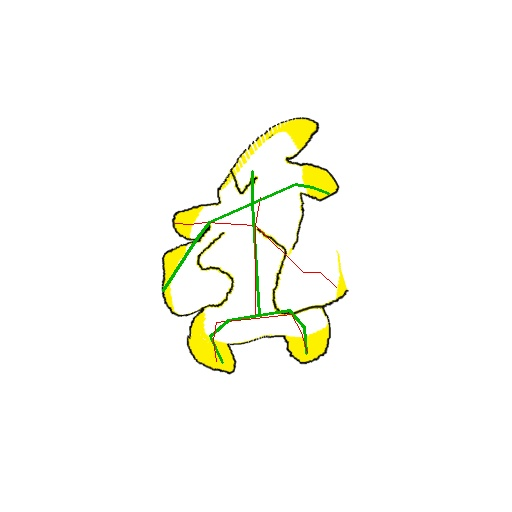

5__bvh_stand_still__0_t12.jpg


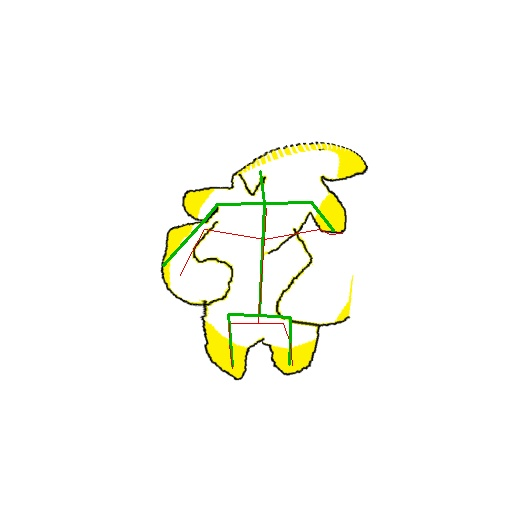

5__bvh_swim__0_t22.jpg


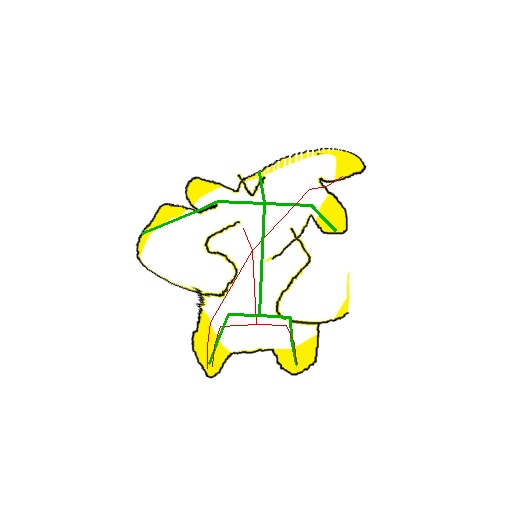

5__bvh_very_happy__0_t24.jpg


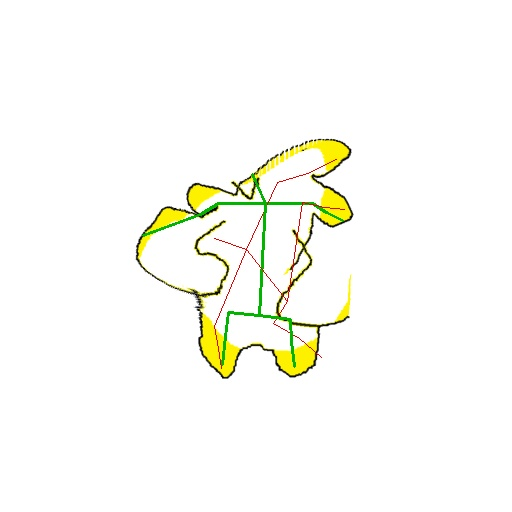

5__bvh_wave_hello__0_t10.jpg


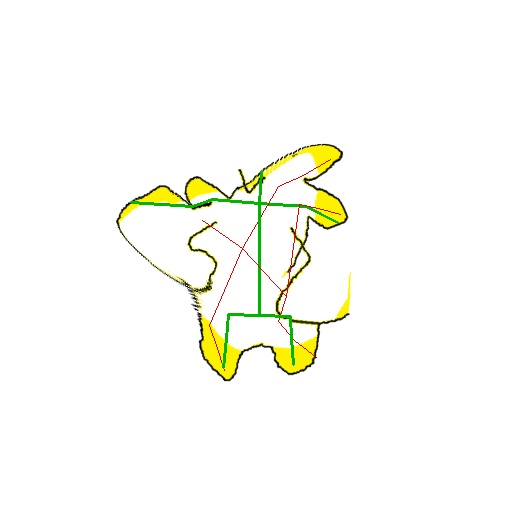

5__bvh_zombie__0_t62.jpg


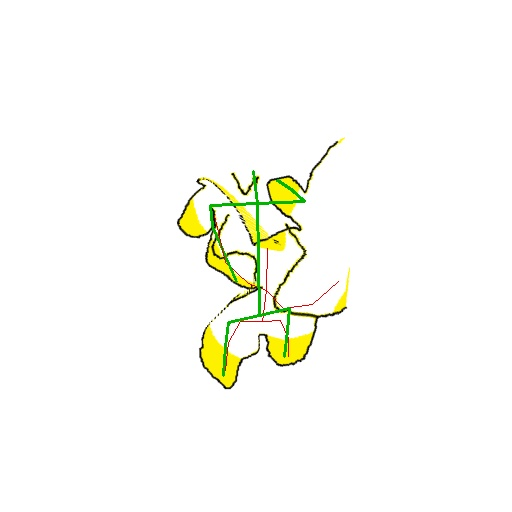

6__bvh_bird__0_t34.jpg


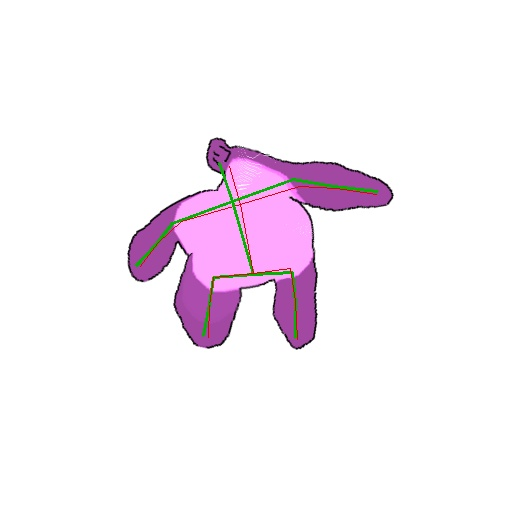

6__bvh_dab__0_t126.jpg


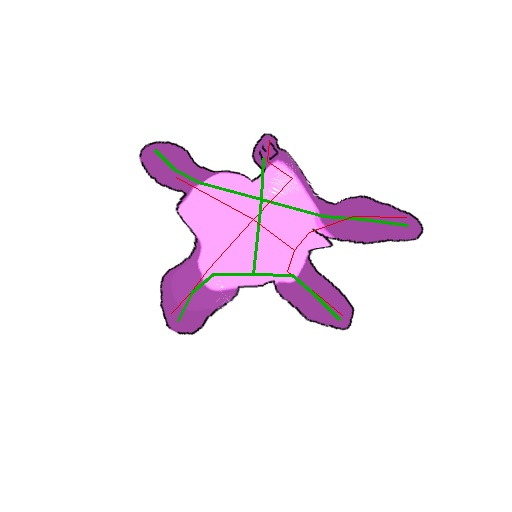

6__bvh_elephant__0_t40.jpg


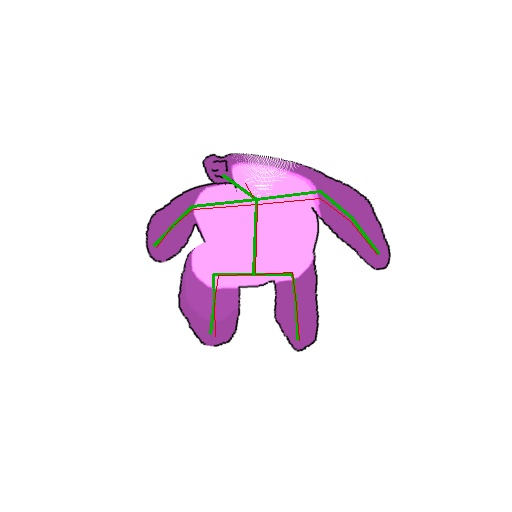

6__bvh_happy_walk__0_t8.jpg


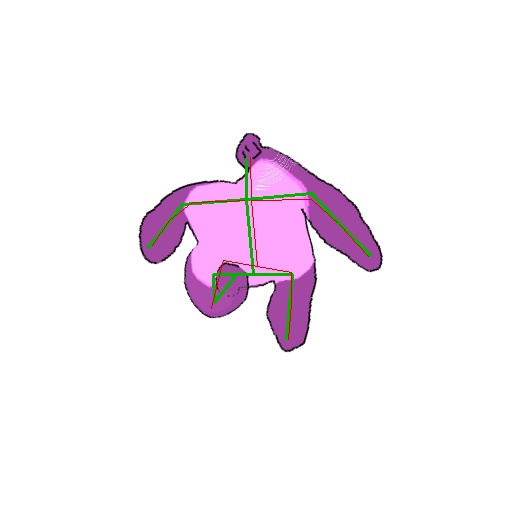

6__bvh_idle__0_t30.jpg


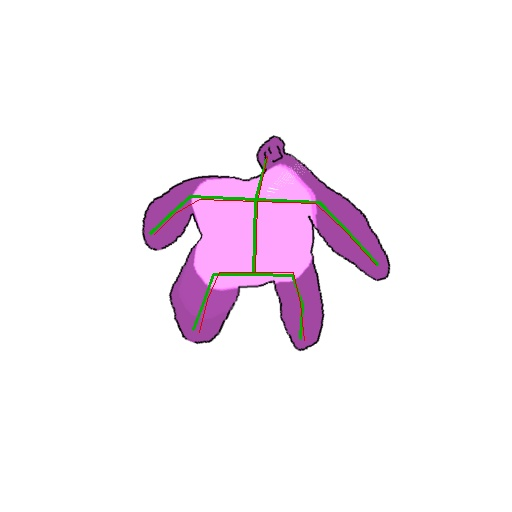

6__bvh_jesse_dance__0_t10.jpg


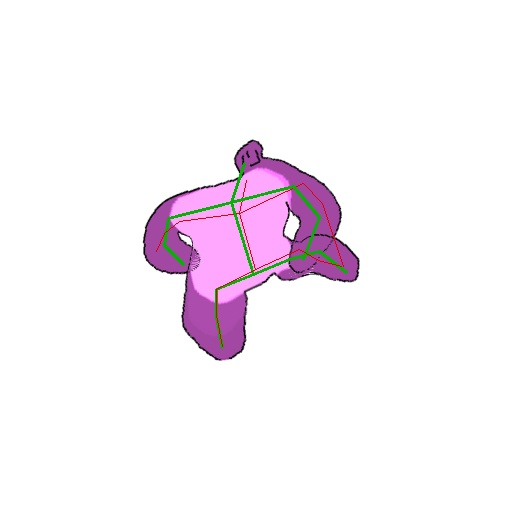

6__bvh_jumping__0_t24.jpg


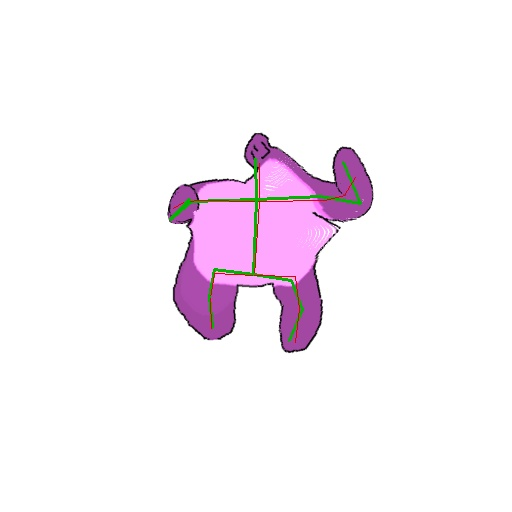

6__bvh_jumping_jacks__0_t16.jpg


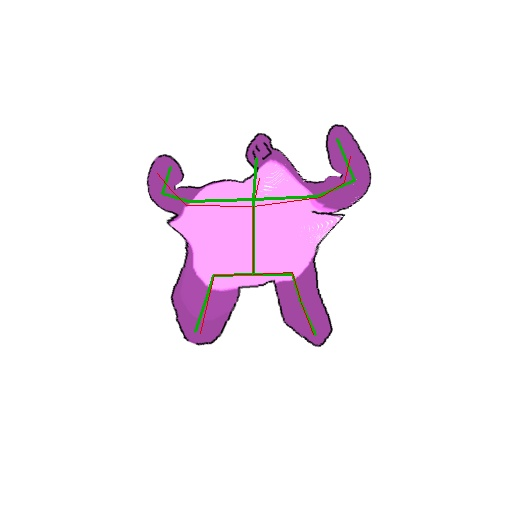

6__bvh_kick_ball__0_t48.jpg


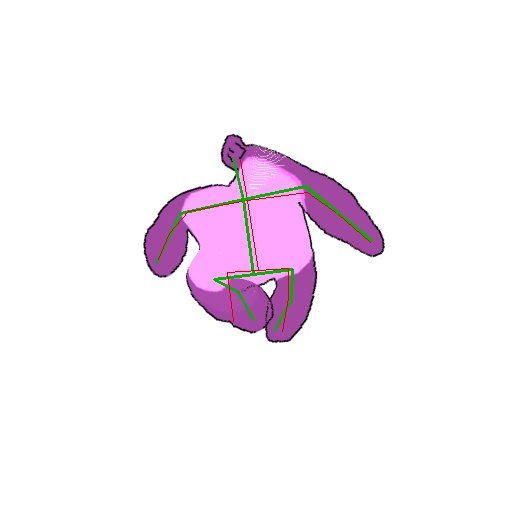

6__bvh_laugh__0_t26.jpg


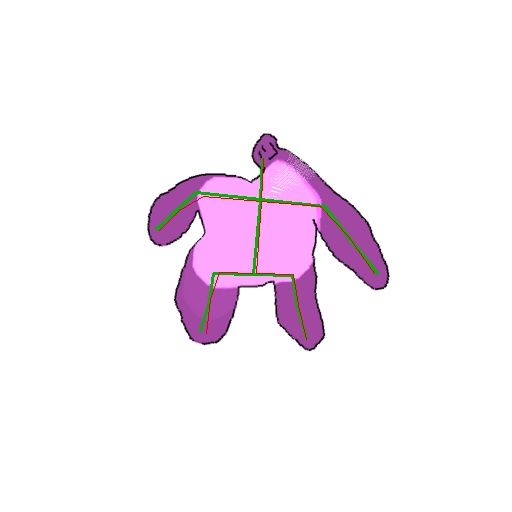

6__bvh_march__0_t30.jpg


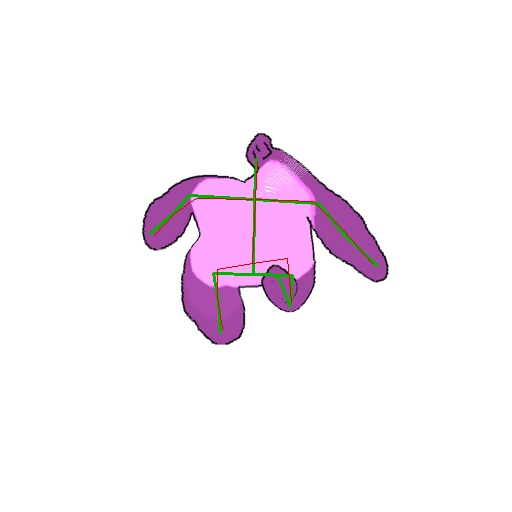

6__bvh_monkey__0_t54.jpg


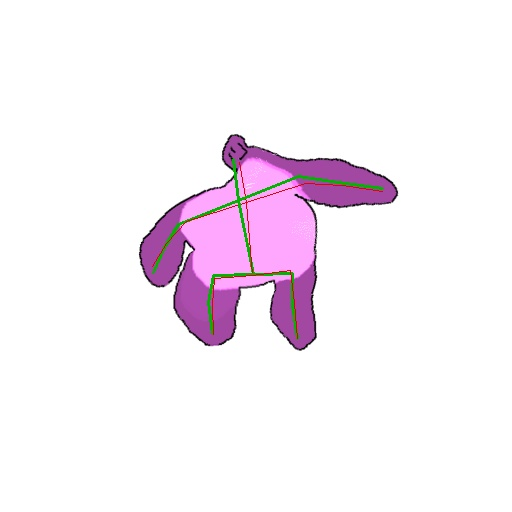

6__bvh_point__0_t40.jpg


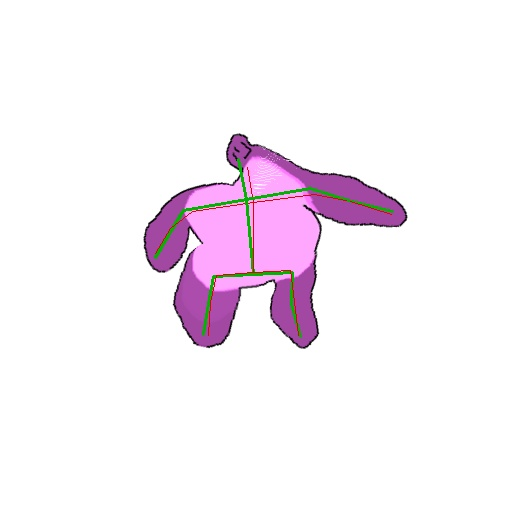

6__bvh_reach_tiptoe__0_t40.jpg


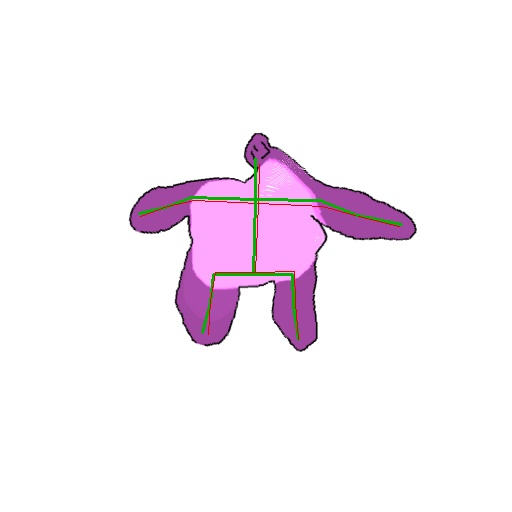

6__bvh_sad_walk__0_t10.jpg


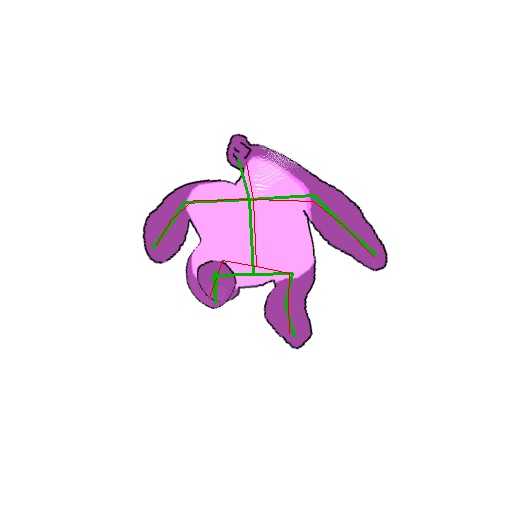

6__bvh_search_ground__0_t38.jpg


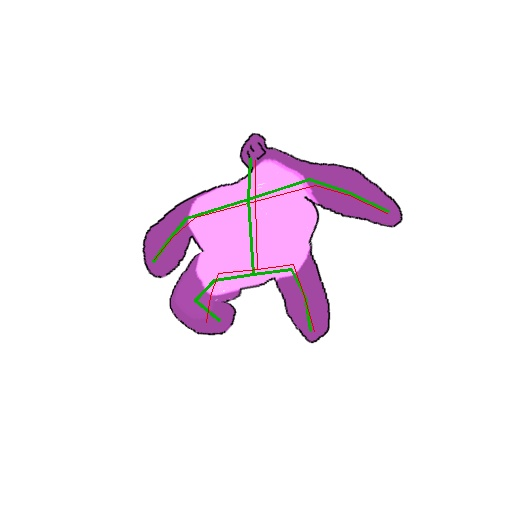

6__bvh_stand_still__0_t40.jpg


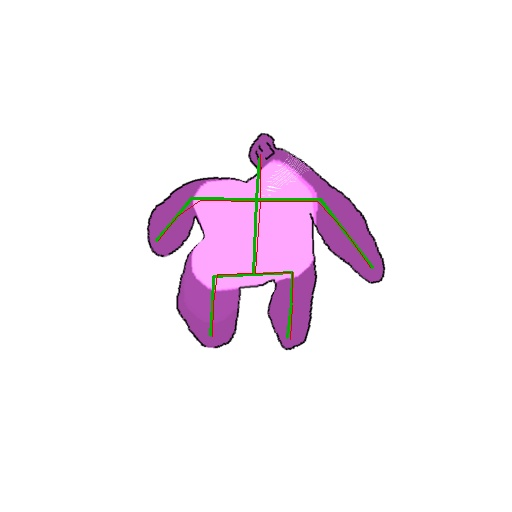

6__bvh_swim__0_t8.jpg


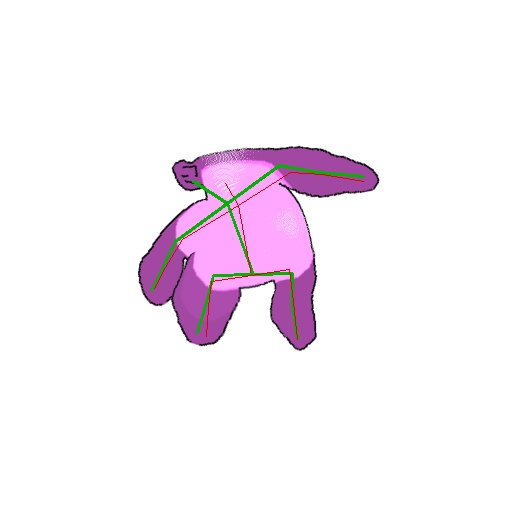

6__bvh_very_happy__0_t24.jpg


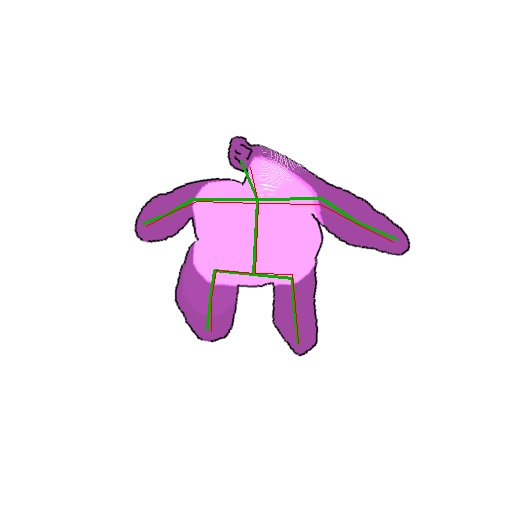

6__bvh_wave_hello__0_t40.jpg


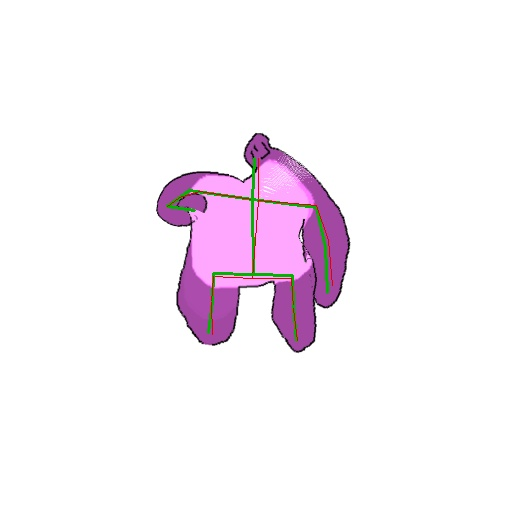

6__bvh_zombie__0_t38.jpg


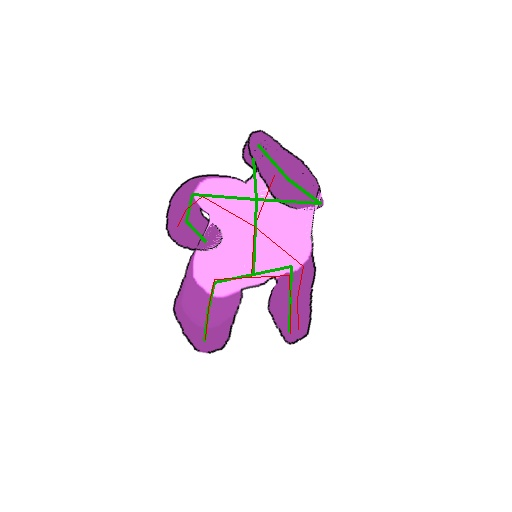

7__bvh_bird__0_t22.jpg


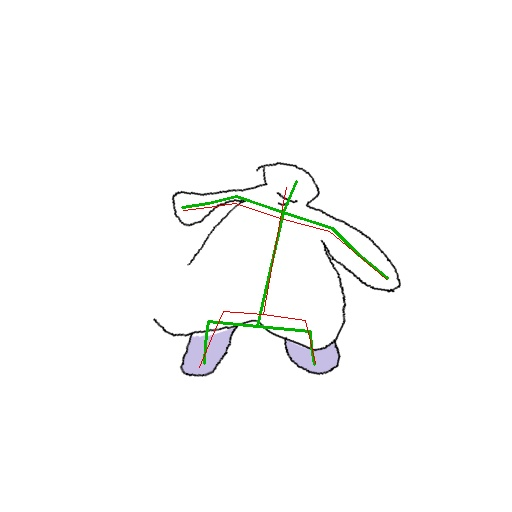

7__bvh_dab__0_t50.jpg


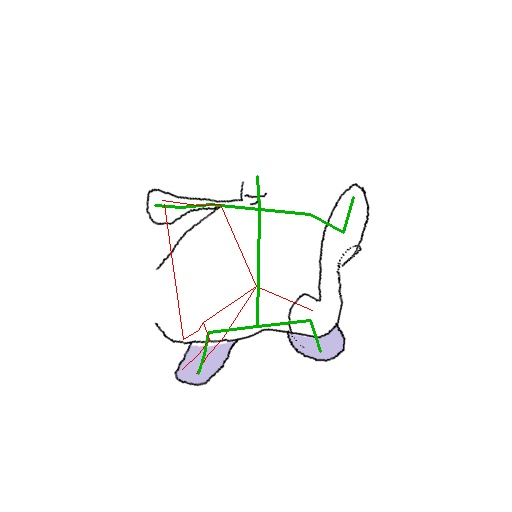

7__bvh_elephant__0_t44.jpg


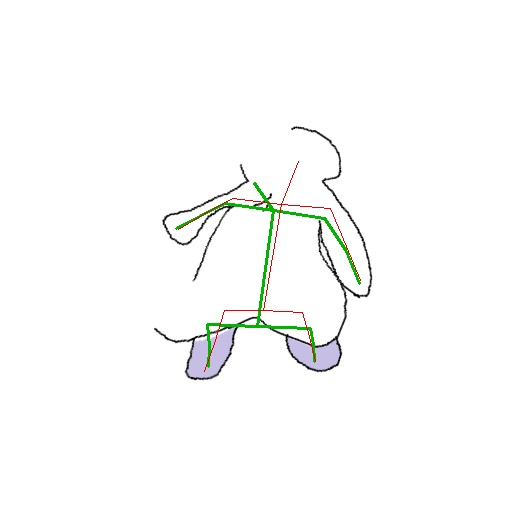

7__bvh_happy_walk__0_t28.jpg


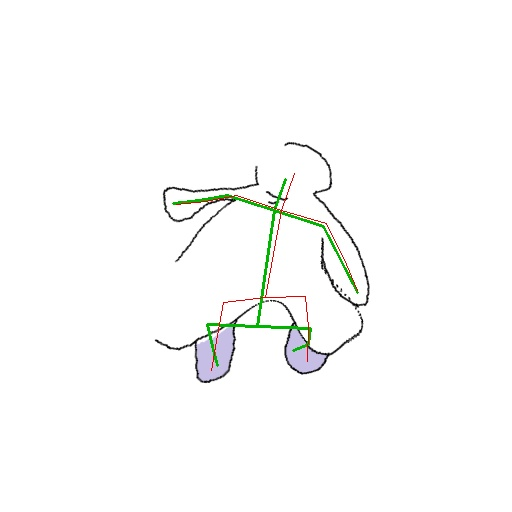

7__bvh_idle__0_t30.jpg


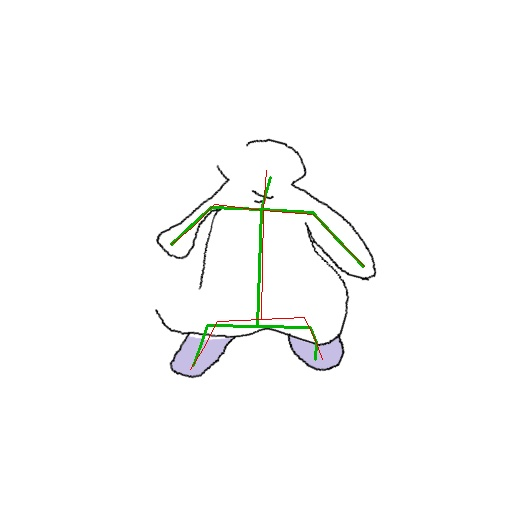

7__bvh_jesse_dance__0_t18.jpg


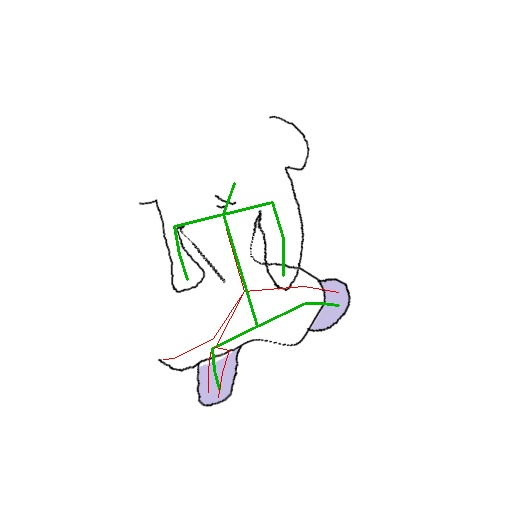

7__bvh_jumping__0_t24.jpg


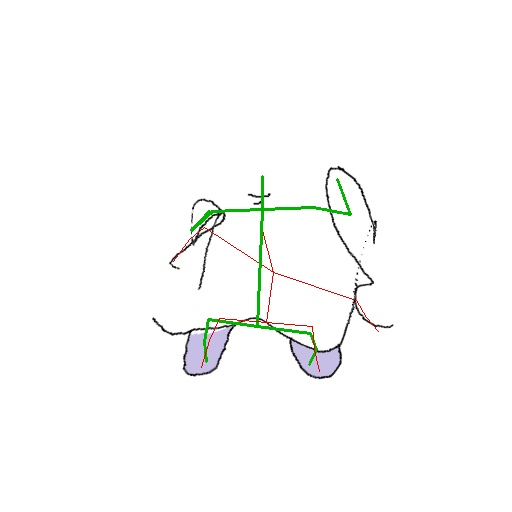

7__bvh_jumping_jacks__0_t48.jpg


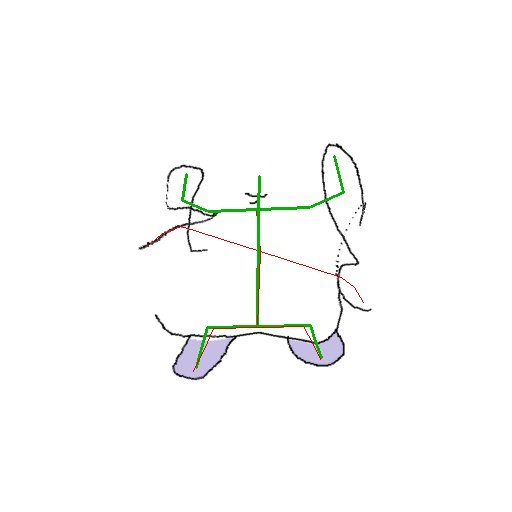

7__bvh_kick_ball__0_t50.jpg


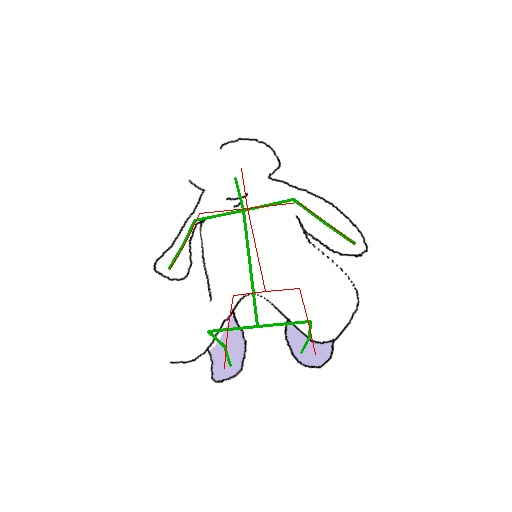

7__bvh_laugh__0_t38.jpg


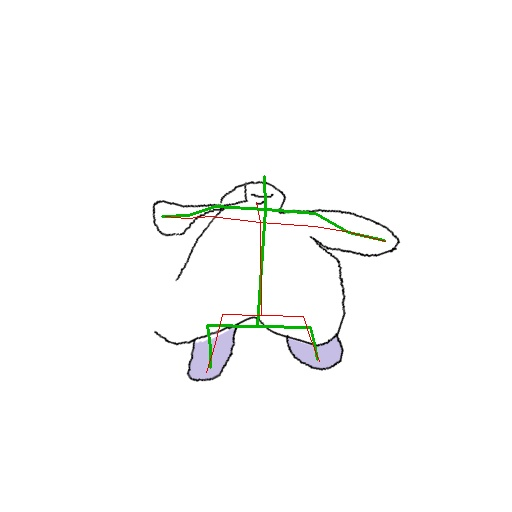

7__bvh_march__0_t24.jpg


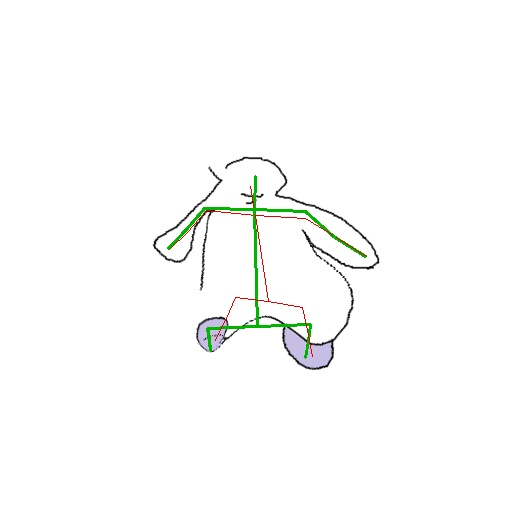

7__bvh_monkey__0_t42.jpg


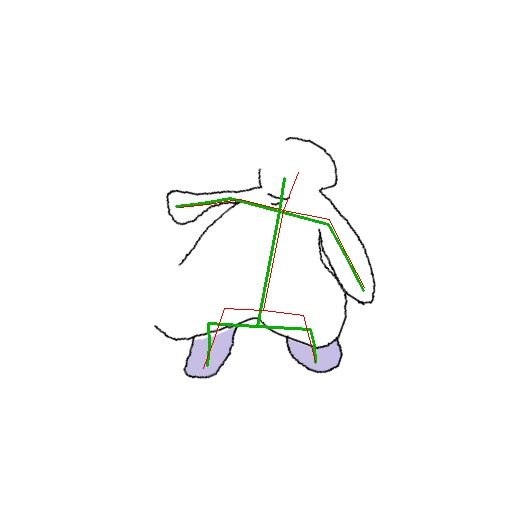

7__bvh_point__0_t42.jpg


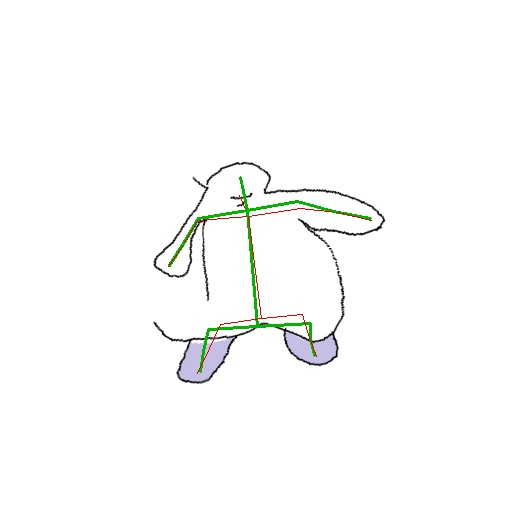

7__bvh_reach_tiptoe__0_t8.jpg


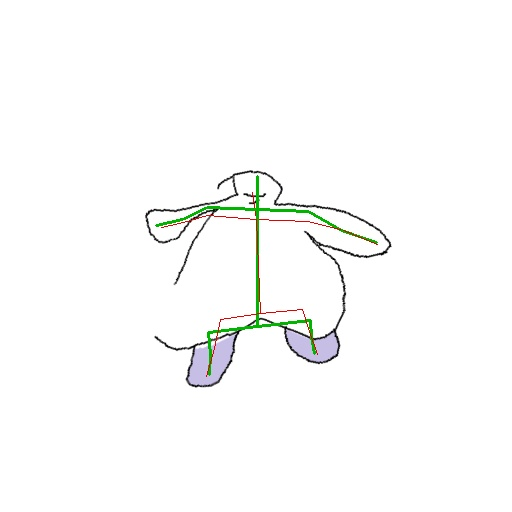

7__bvh_sad_walk__0_t40.jpg


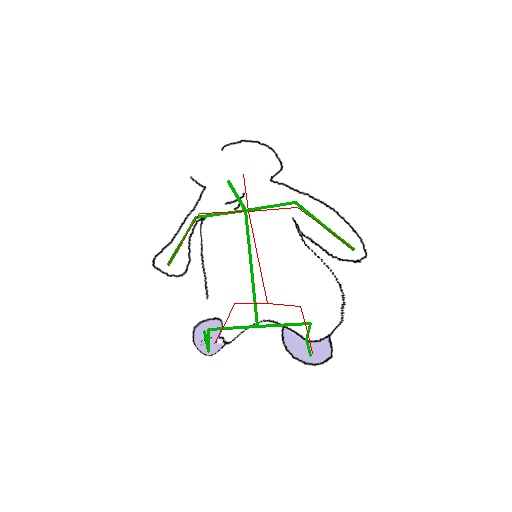

7__bvh_search_ground__0_t42.jpg


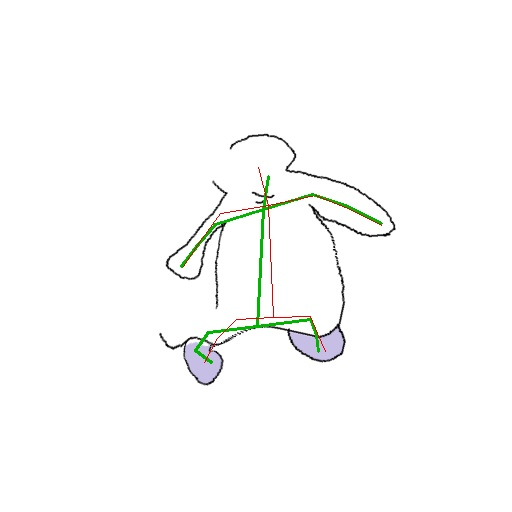

7__bvh_stand_still__0_t8.jpg


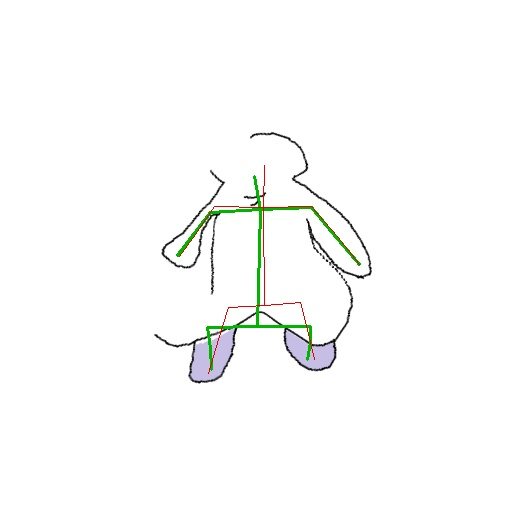

7__bvh_swim__0_t8.jpg


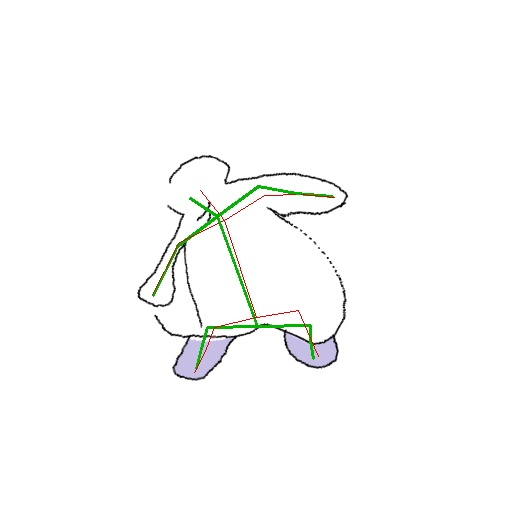

7__bvh_very_happy__0_t18.jpg


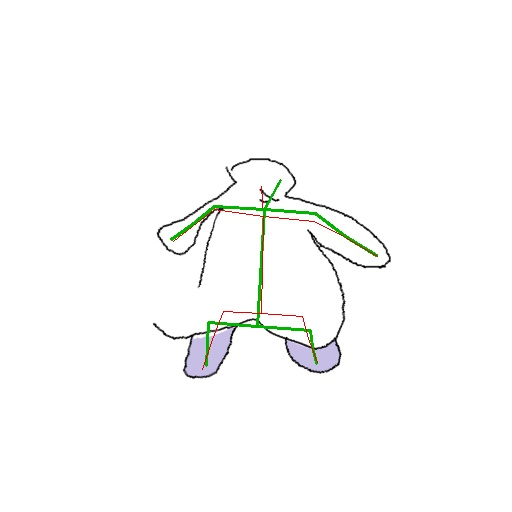

7__bvh_wave_hello__0_t40.jpg


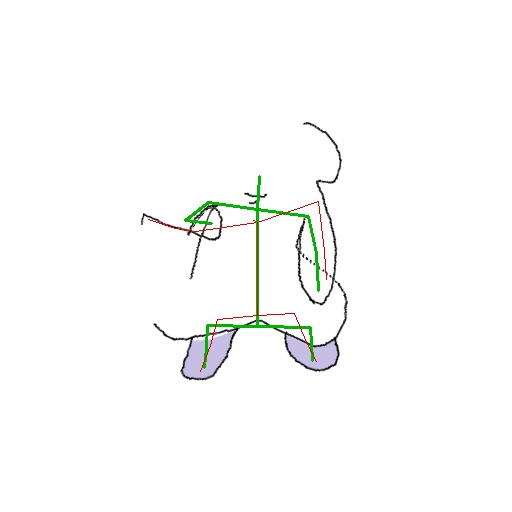

7__bvh_zombie__0_t38.jpg


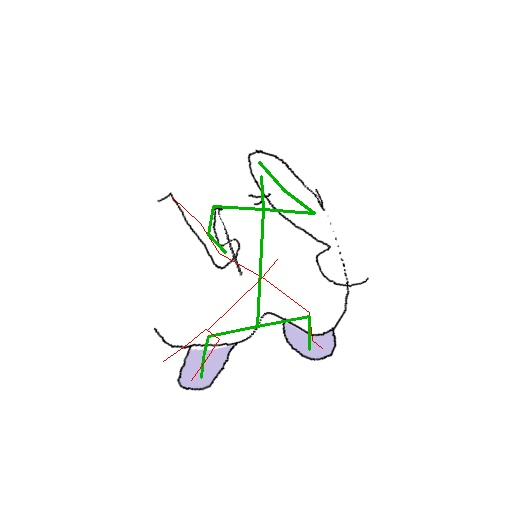

8__bvh_bird__0_t24.jpg


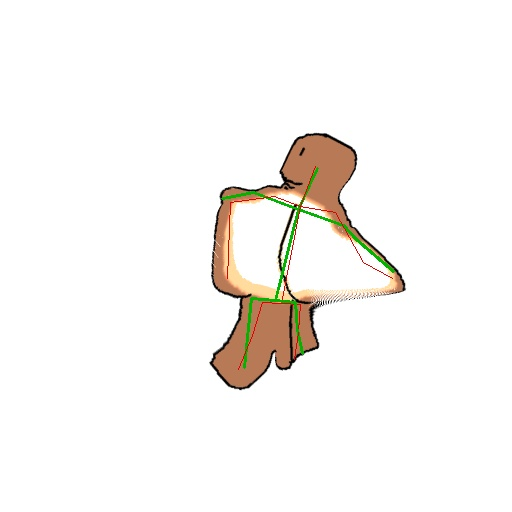

8__bvh_dab__0_t138.jpg


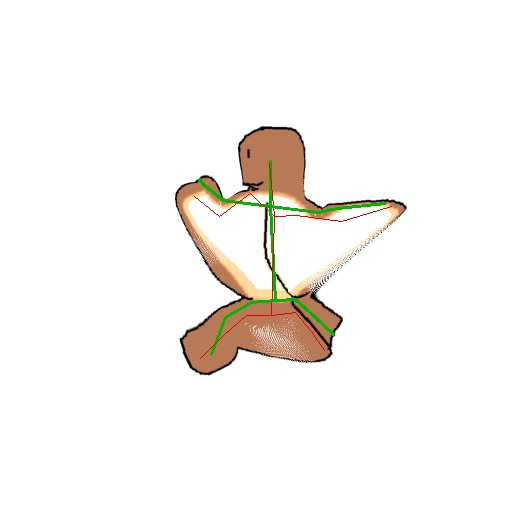

8__bvh_elephant__0_t38.jpg


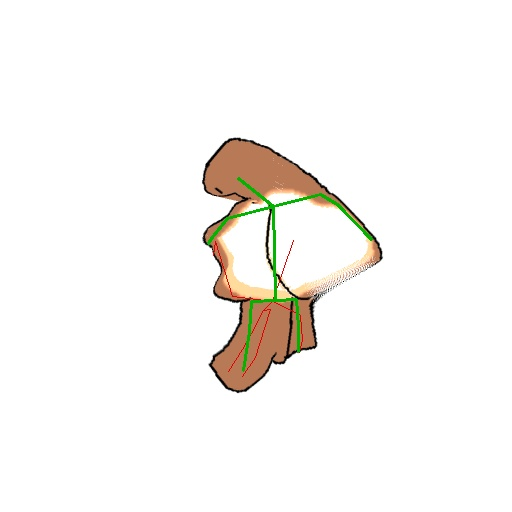

8__bvh_happy_walk__0_t8.jpg


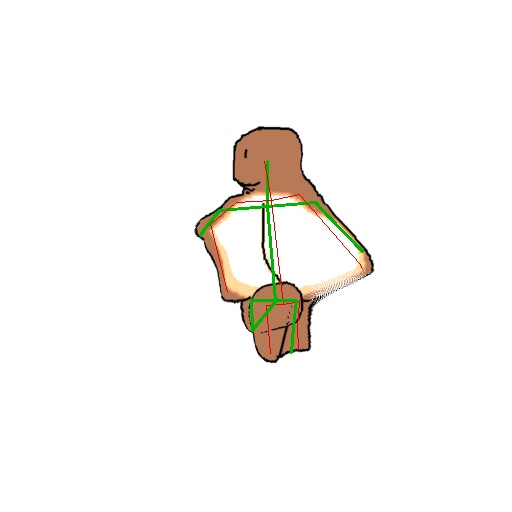

8__bvh_idle__0_t16.jpg


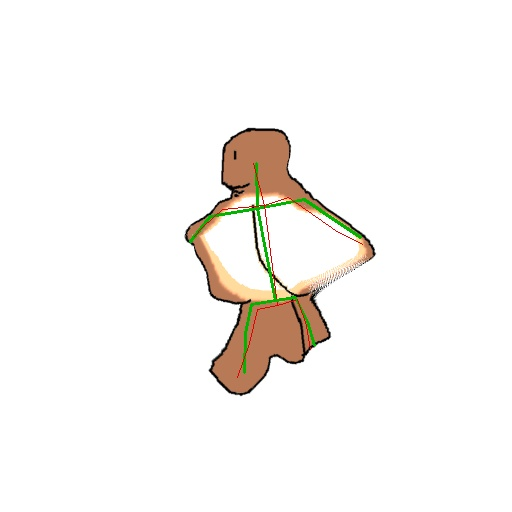

8__bvh_jesse_dance__0_t8.jpg


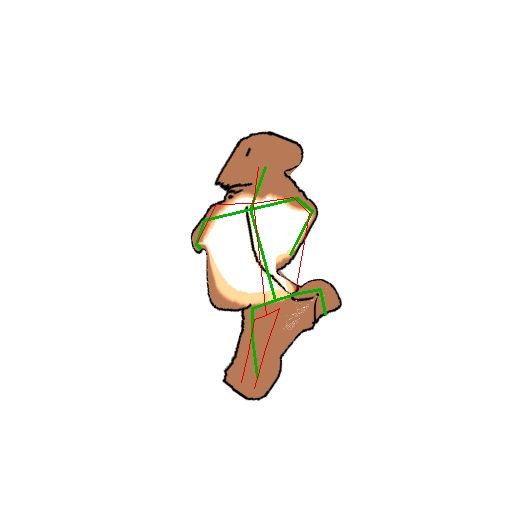

8__bvh_jumping__0_t24.jpg


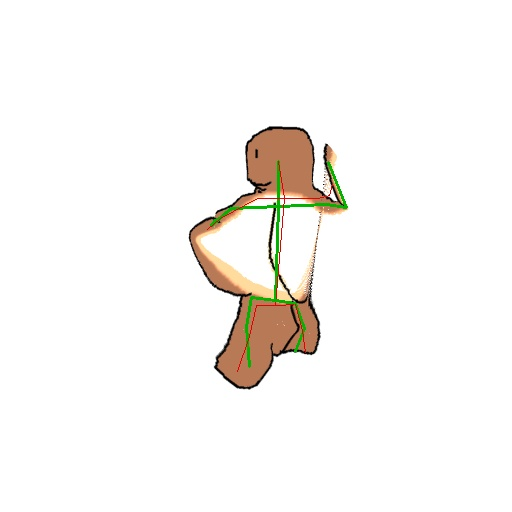

8__bvh_jumping_jacks__0_t16.jpg


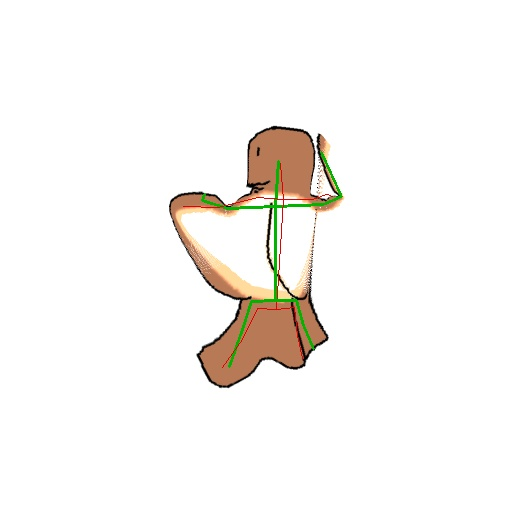

8__bvh_kick_ball__0_t54.jpg


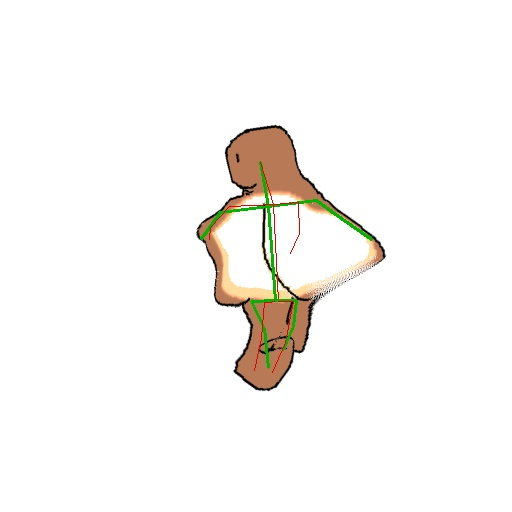

8__bvh_laugh__0_t44.jpg


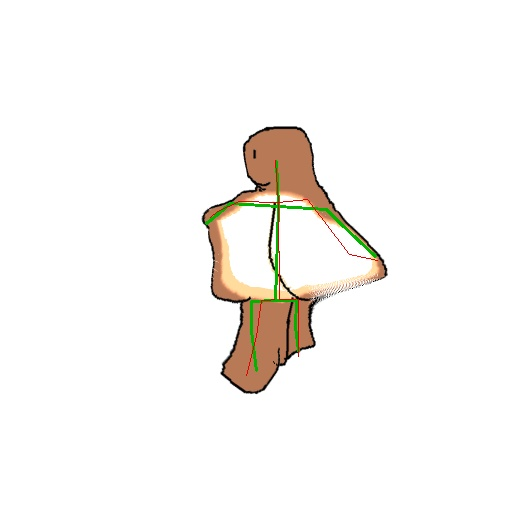

8__bvh_march__0_t42.jpg


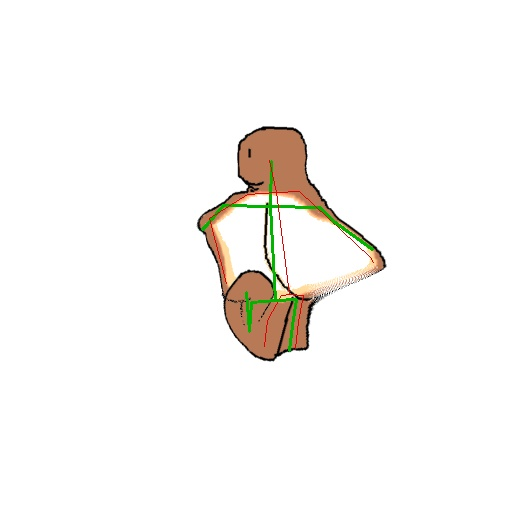

8__bvh_monkey__0_t42.jpg


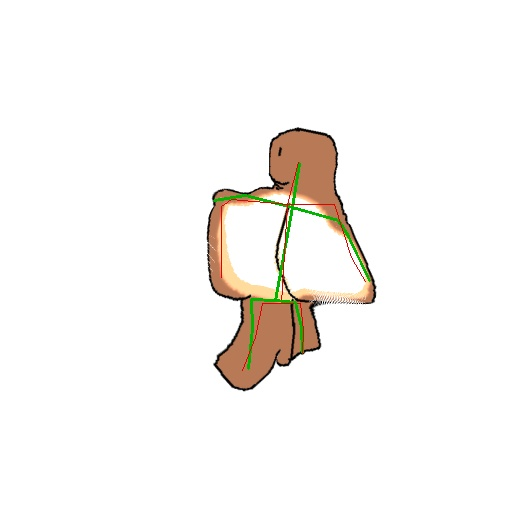

8__bvh_point__0_t32.jpg


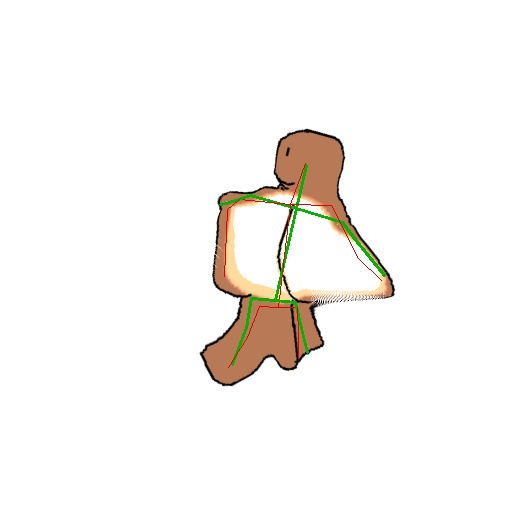

8__bvh_reach_tiptoe__0_t24.jpg


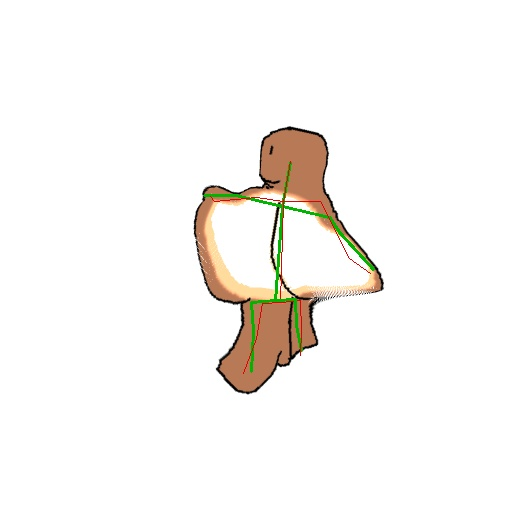

8__bvh_sad_walk__0_t50.jpg


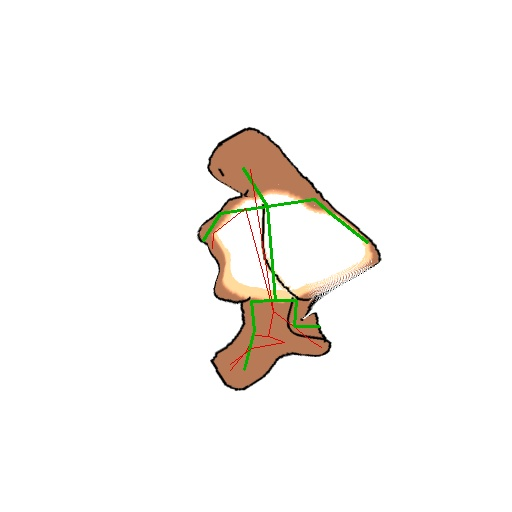

8__bvh_search_ground__0_t26.jpg


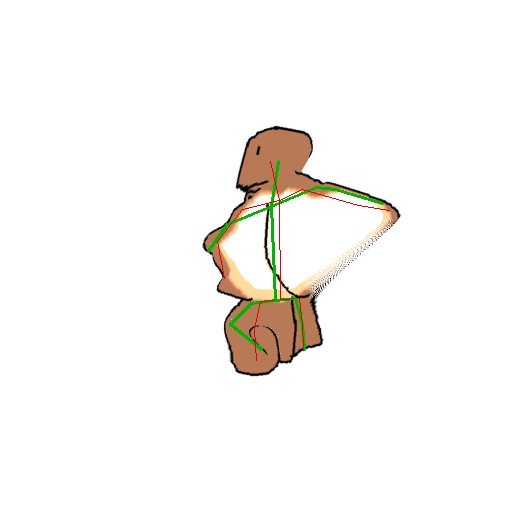

8__bvh_stand_still__0_t6.jpg


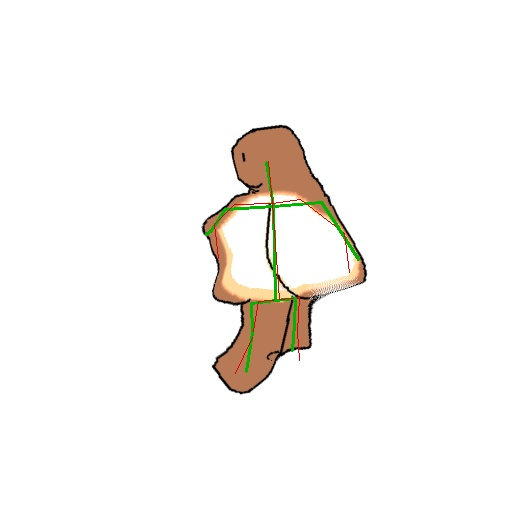

8__bvh_swim__0_t8.jpg


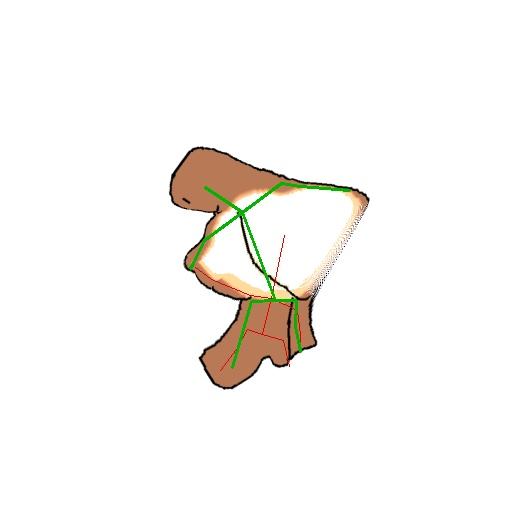

8__bvh_very_happy__0_t16.jpg


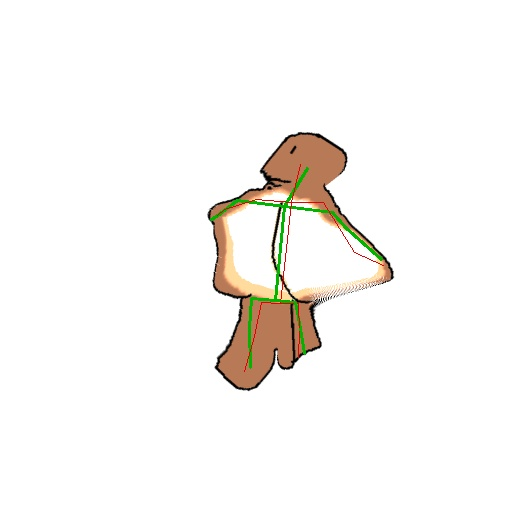

8__bvh_wave_hello__0_t40.jpg


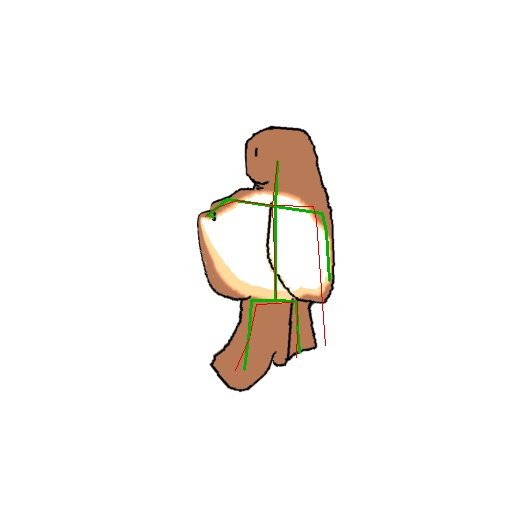

8__bvh_zombie__0_t48.jpg


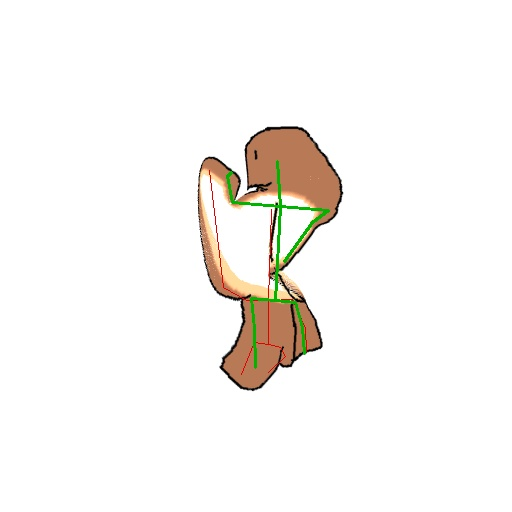

9__bvh_bird__0_t34.jpg


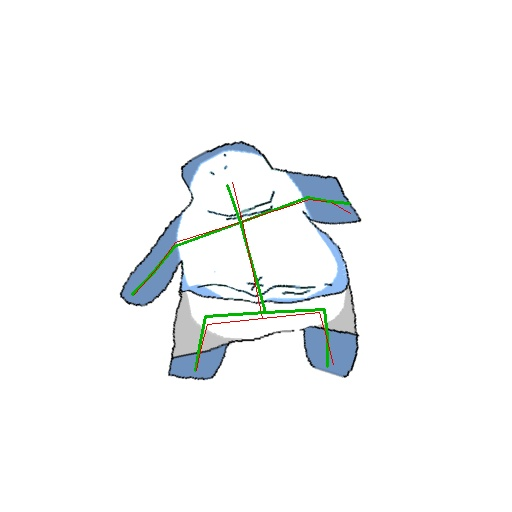

9__bvh_dab__0_t98.jpg


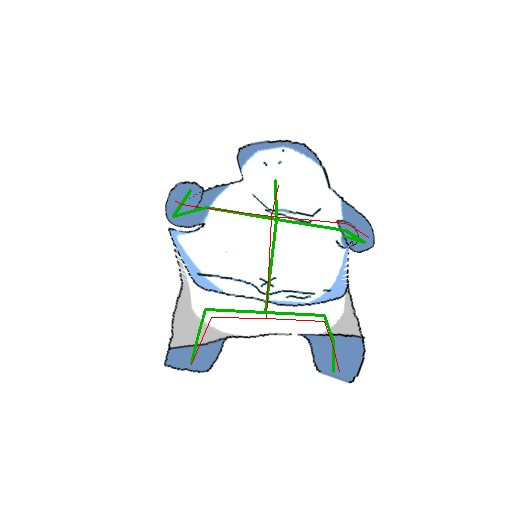

9__bvh_elephant__0_t8.jpg


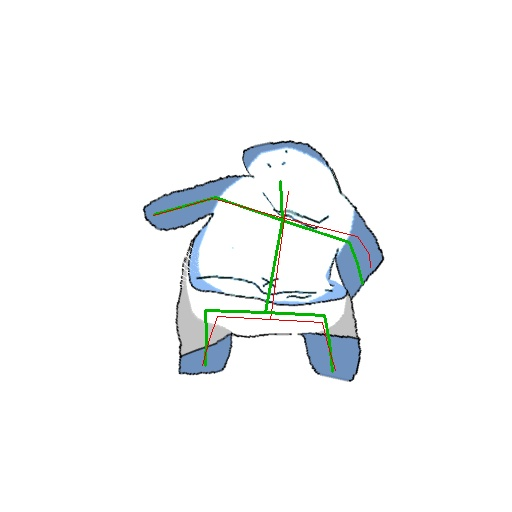

9__bvh_happy_walk__0_t8.jpg


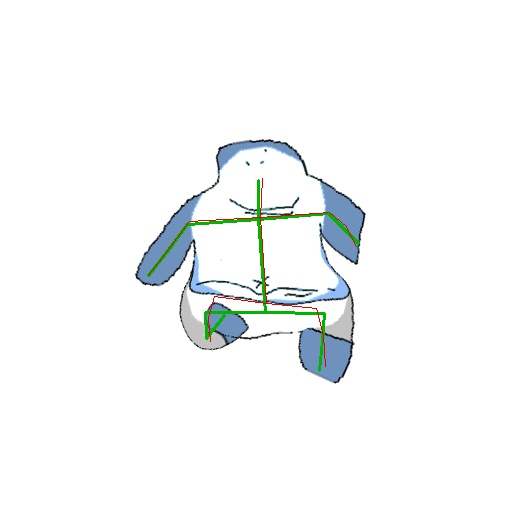

9__bvh_idle__0_t20.jpg


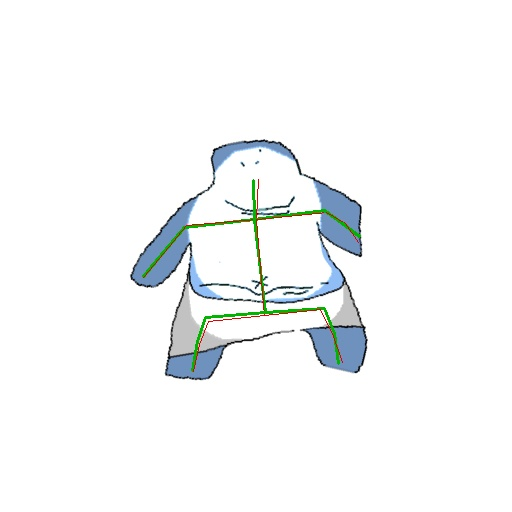

9__bvh_jesse_dance__0_t14.jpg


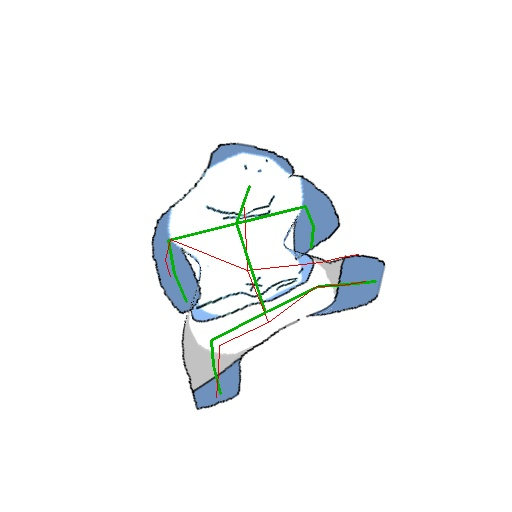

9__bvh_jumping__0_t24.jpg


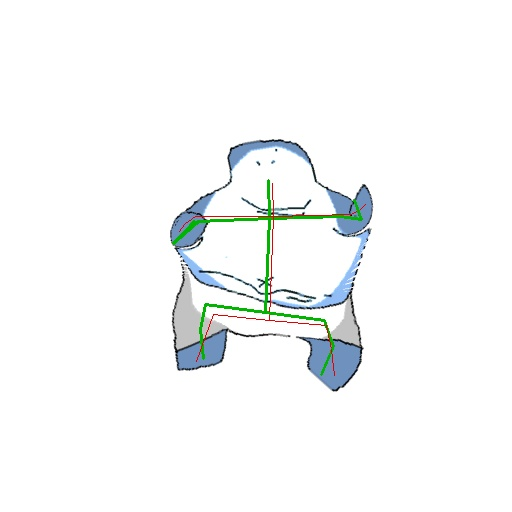

9__bvh_jumping_jacks__0_t62.jpg


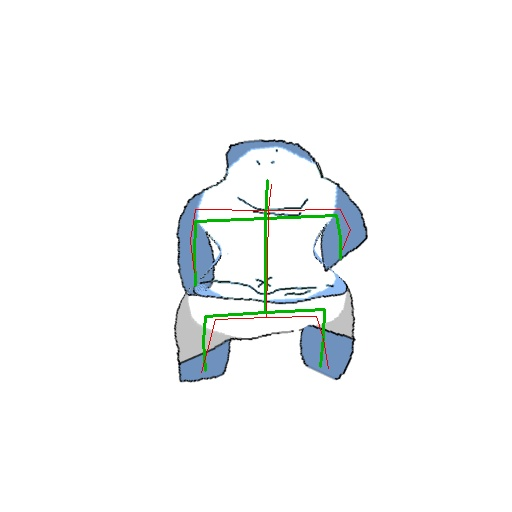

9__bvh_kick_ball__0_t48.jpg


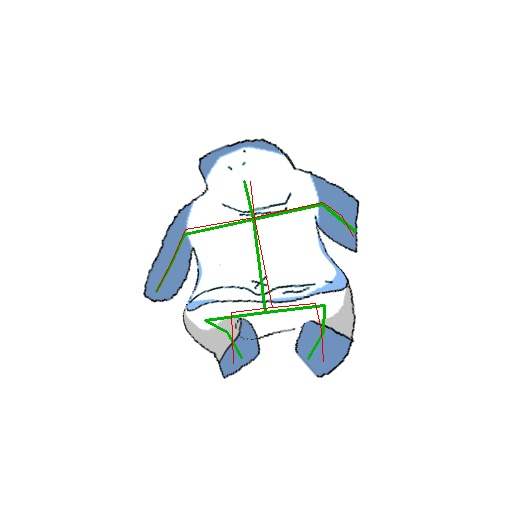

9__bvh_laugh__0_t36.jpg


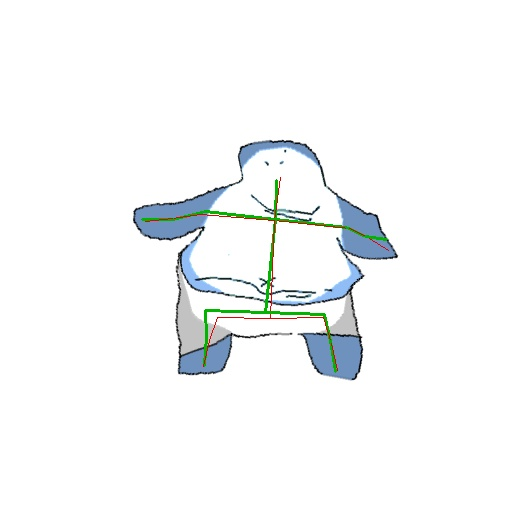

9__bvh_march__0_t42.jpg


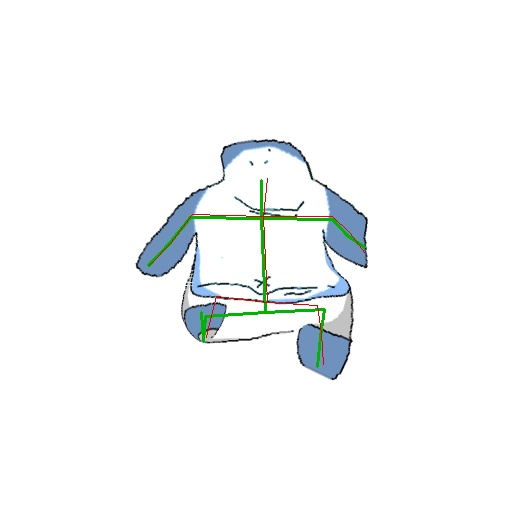

9__bvh_monkey__0_t42.jpg


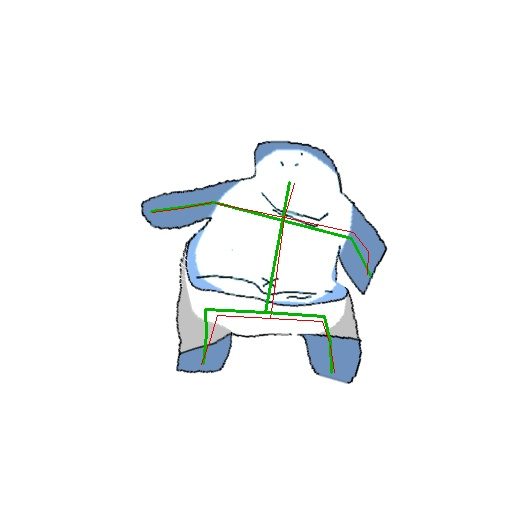

9__bvh_point__0_t16.jpg


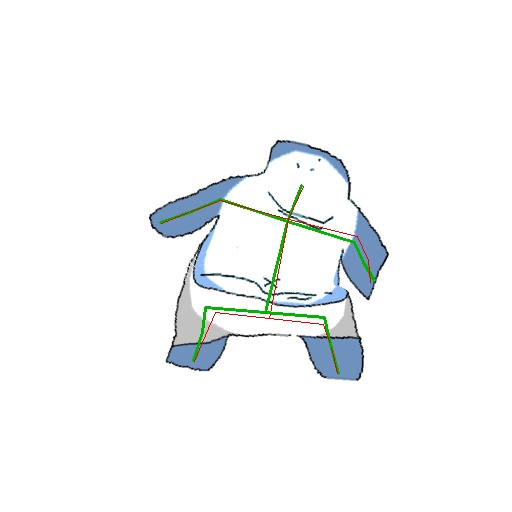

9__bvh_reach_tiptoe__0_t24.jpg


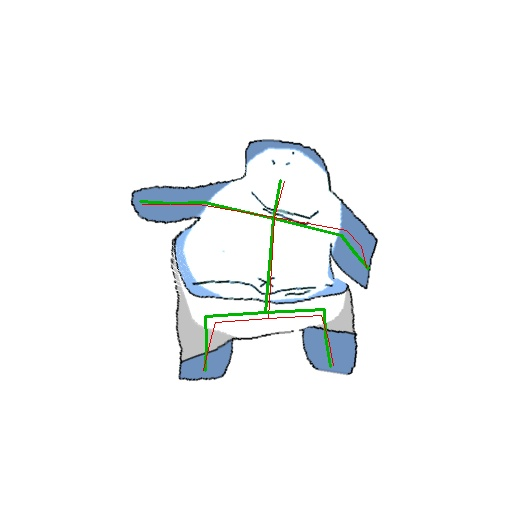

9__bvh_sad_walk__0_t40.jpg


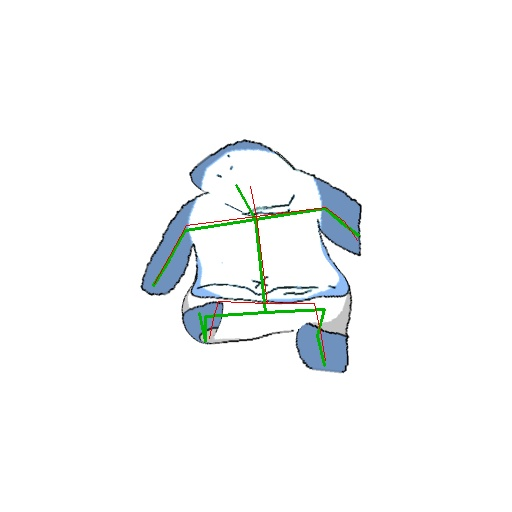

9__bvh_search_ground__0_t24.jpg


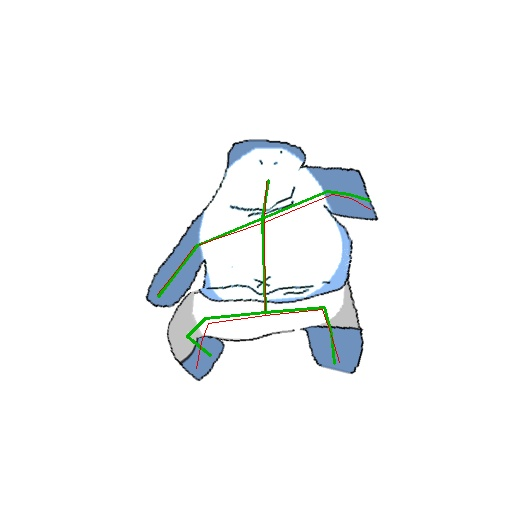

9__bvh_stand_still__0_t8.jpg


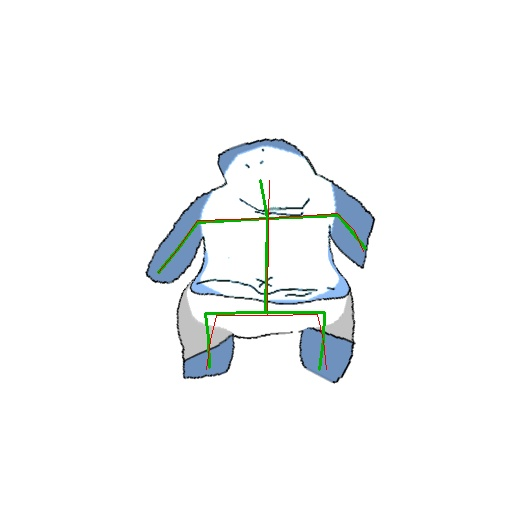

9__bvh_swim__0_t8.jpg


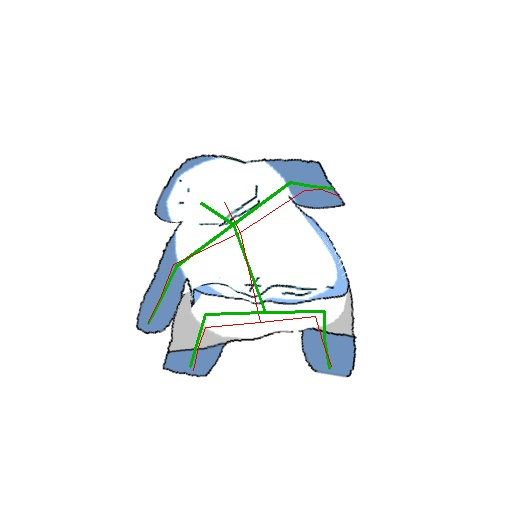

9__bvh_very_happy__0_t24.jpg


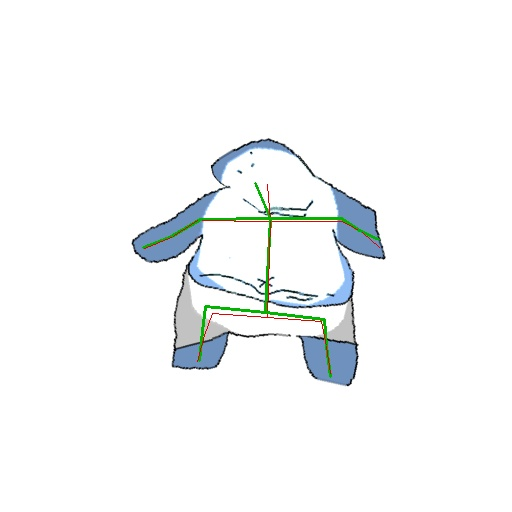

9__bvh_wave_hello__0_t34.jpg


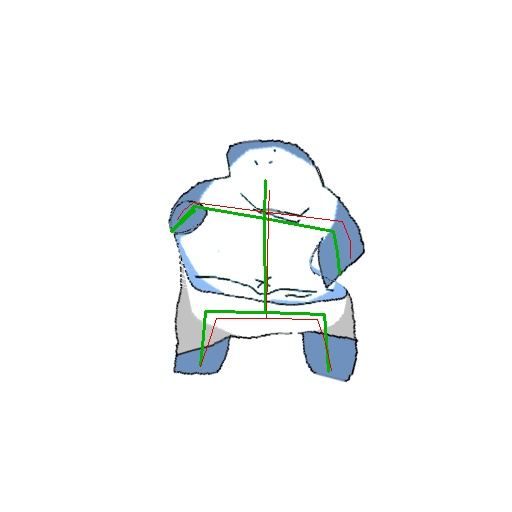

9__bvh_zombie__0_t32.jpg


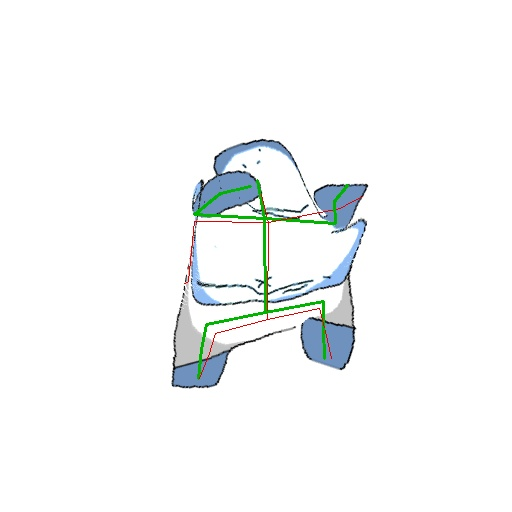

KakaoTalk_20261113_171159582_01__bvh_bird__0_t24.jpg


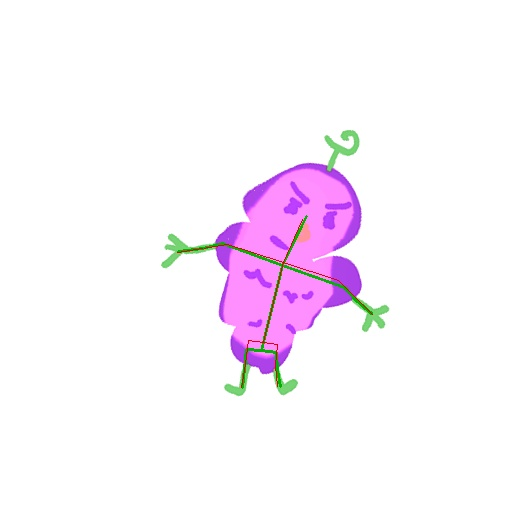

KakaoTalk_20261113_171159582_01__bvh_dab__0_t98.jpg


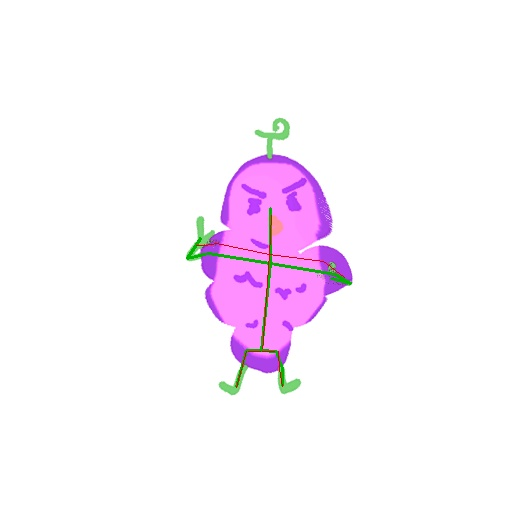

KakaoTalk_20261113_171159582_01__bvh_elephant__0_t44.jpg


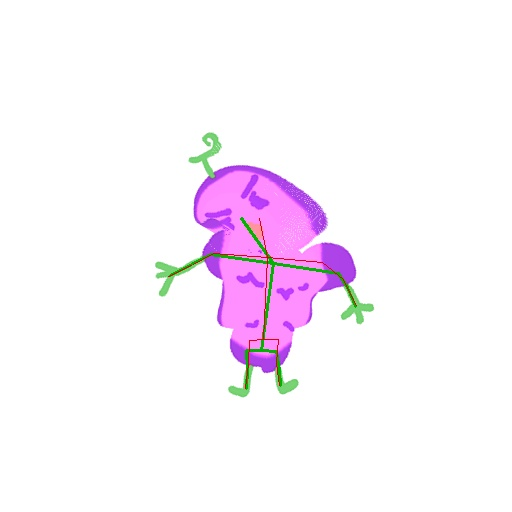

KakaoTalk_20261113_171159582_01__bvh_happy_walk__0_t50.jpg


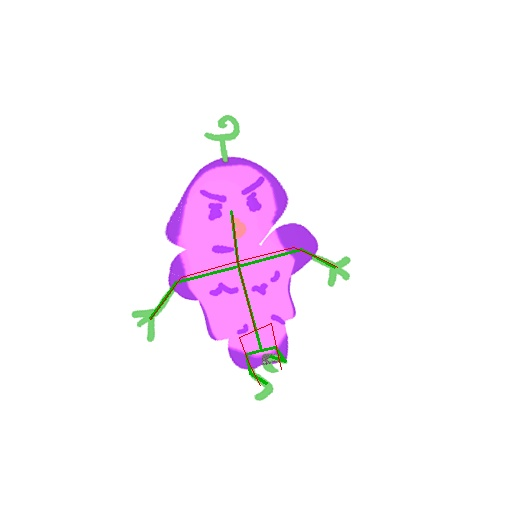

KakaoTalk_20261113_171159582_01__bvh_idle__0_t26.jpg


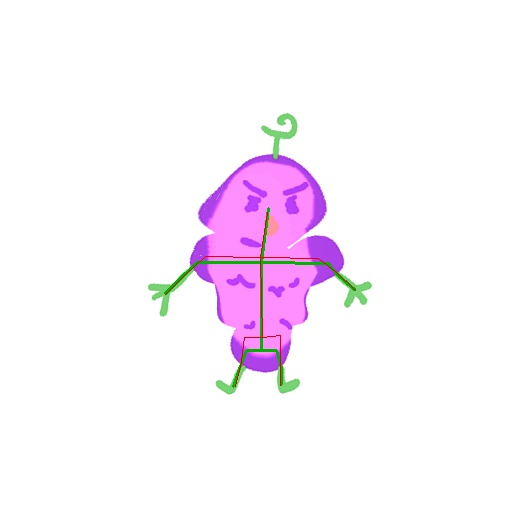

KakaoTalk_20261113_171159582_01__bvh_jesse_dance__0_t14.jpg


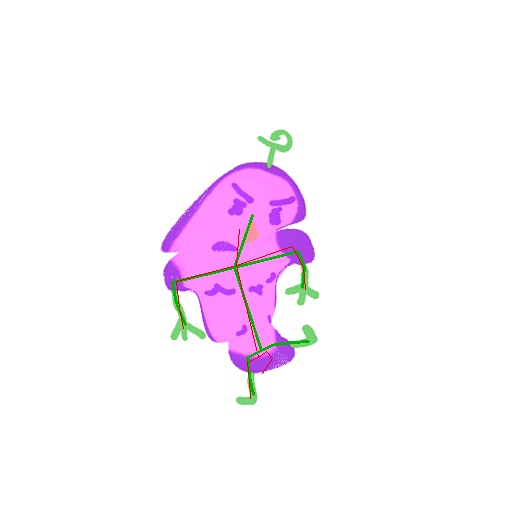

KakaoTalk_20261113_171159582_01__bvh_jumping__0_t20.jpg


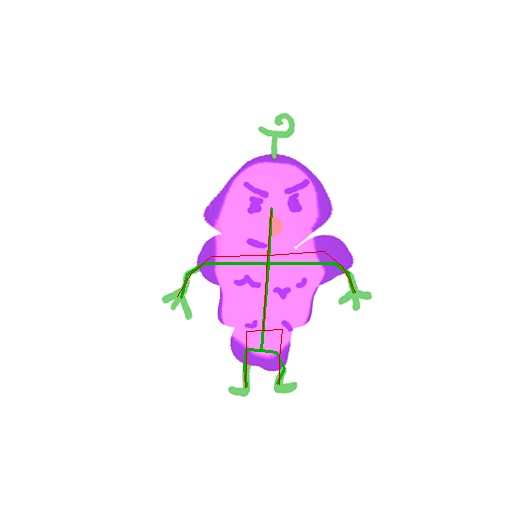

KakaoTalk_20261113_171159582_01__bvh_jumping_jacks__0_t24.jpg


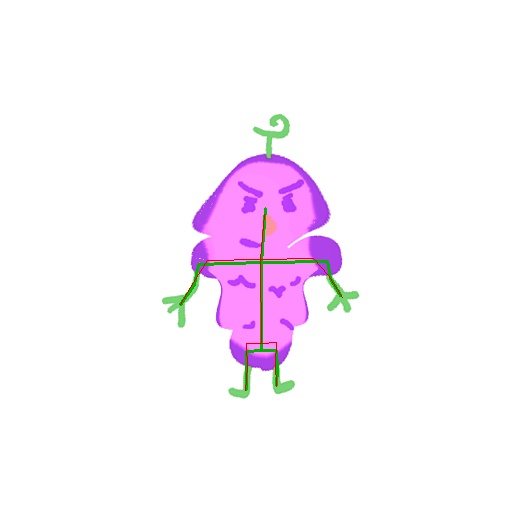

KakaoTalk_20261113_171159582_01__bvh_kick_ball__0_t48.jpg


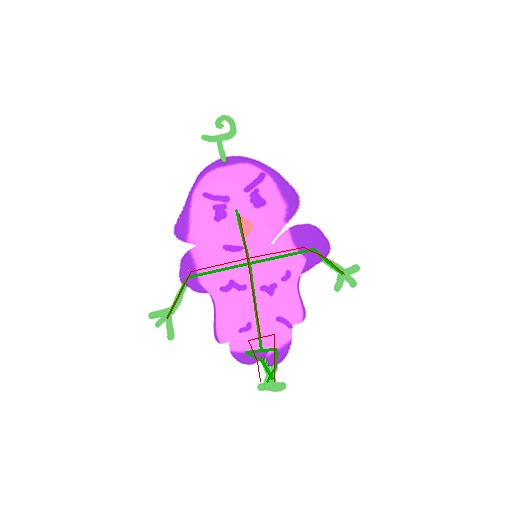

KakaoTalk_20261113_171159582_01__bvh_laugh__0_t26.jpg


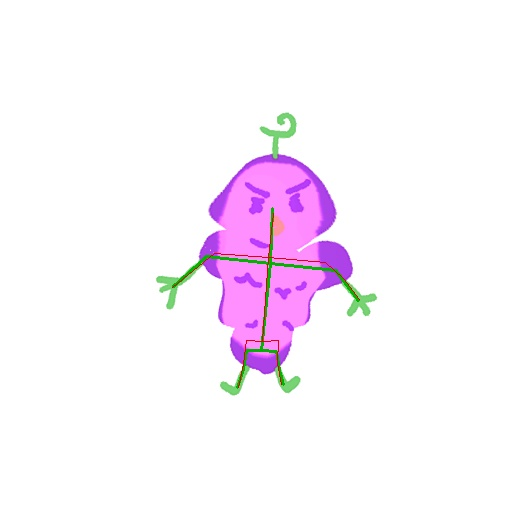

KakaoTalk_20261113_171159582_01__bvh_march__0_t42.jpg


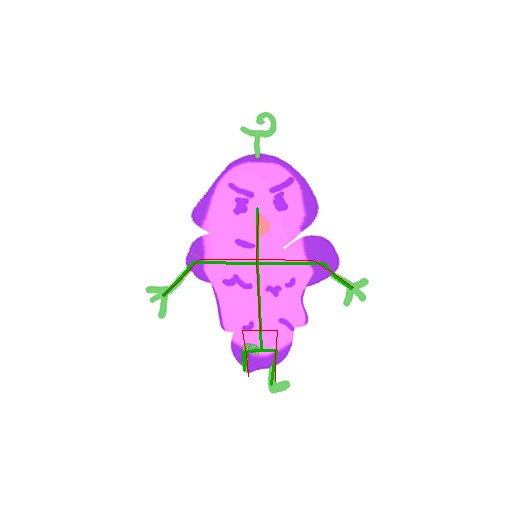

KakaoTalk_20261113_171159582_01__bvh_monkey__0_t38.jpg


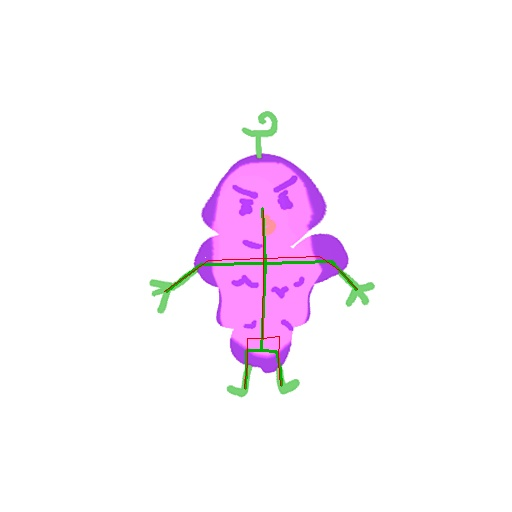

KakaoTalk_20261113_171159582_01__bvh_point__0_t48.jpg


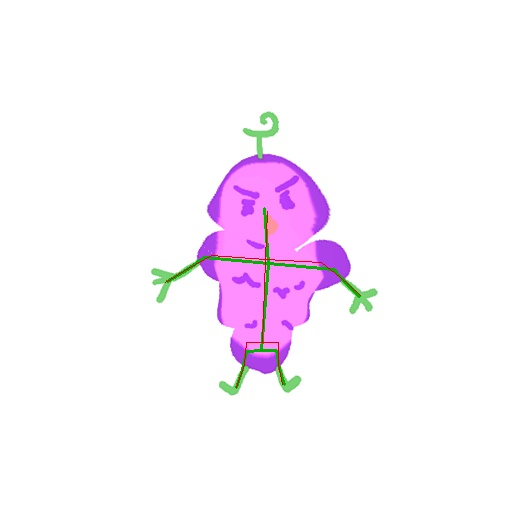

KakaoTalk_20261113_171159582_01__bvh_reach_tiptoe__0_t36.jpg


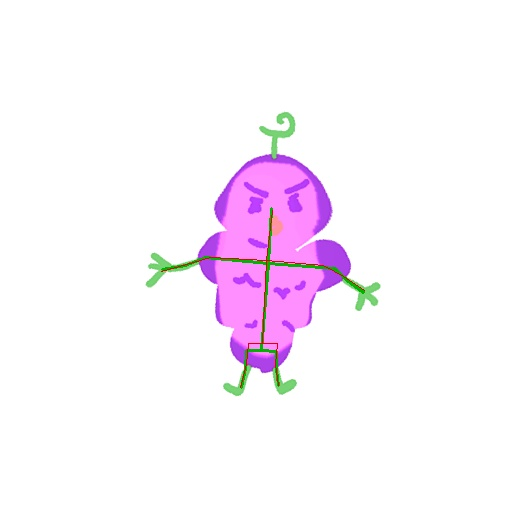

KakaoTalk_20261113_171159582_01__bvh_sad_walk__0_t40.jpg


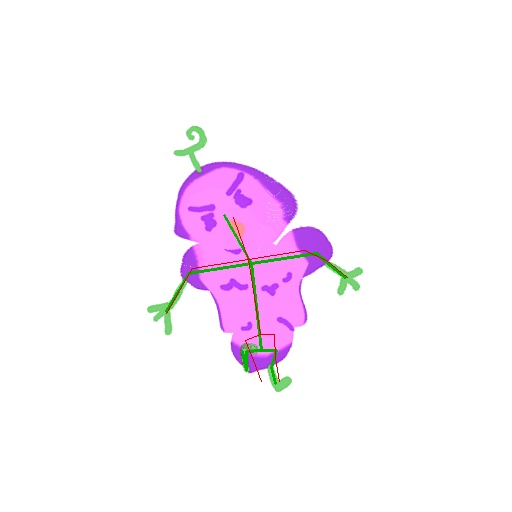

KakaoTalk_20261113_171159582_01__bvh_search_ground__0_t40.jpg


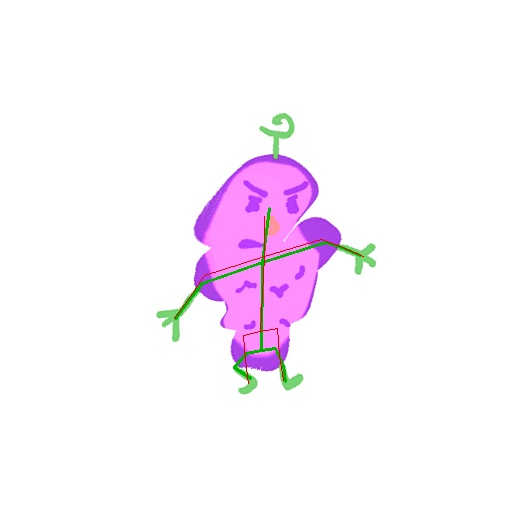

KakaoTalk_20261113_171159582_01__bvh_stand_still__0_t30.jpg


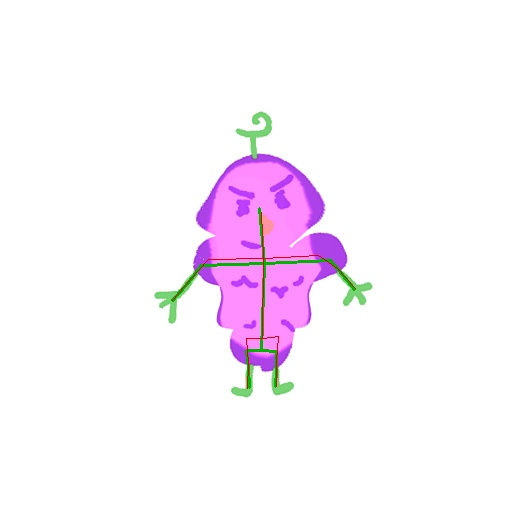

KakaoTalk_20261113_171159582_01__bvh_swim__0_t36.jpg


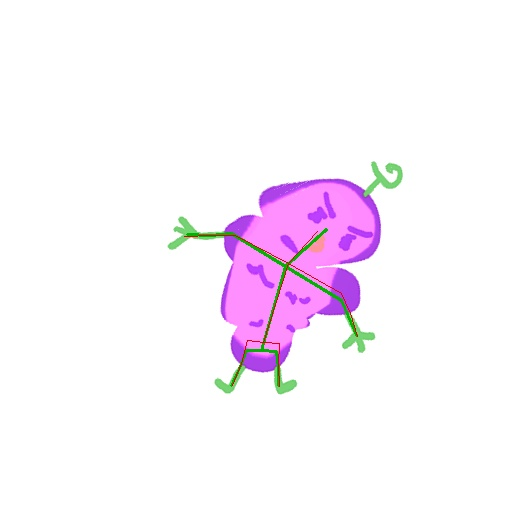

KakaoTalk_20261113_171159582_01__bvh_very_happy__0_t16.jpg


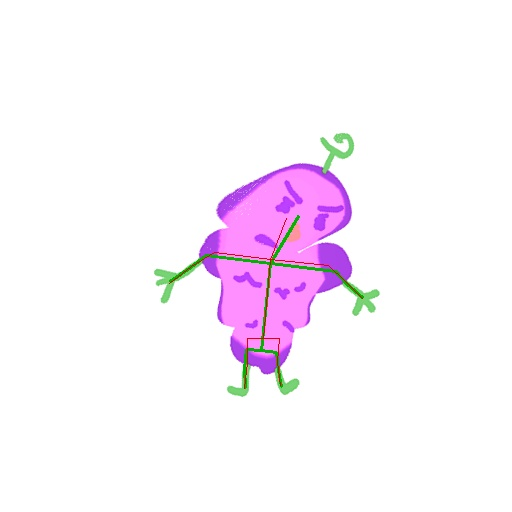

KakaoTalk_20261113_171159582_01__bvh_wave_hello__0_t32.jpg


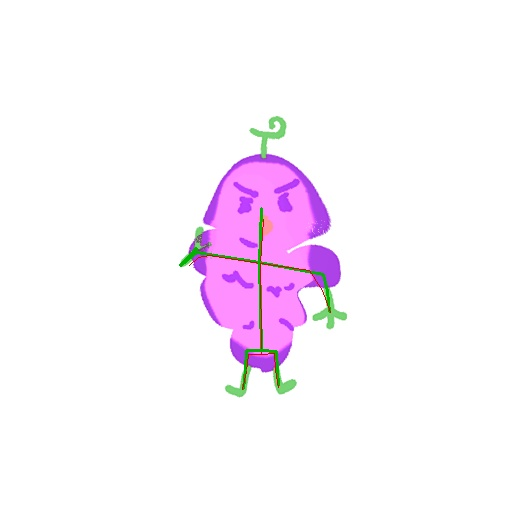

KakaoTalk_20261113_171159582_01__bvh_zombie__0_t56.jpg


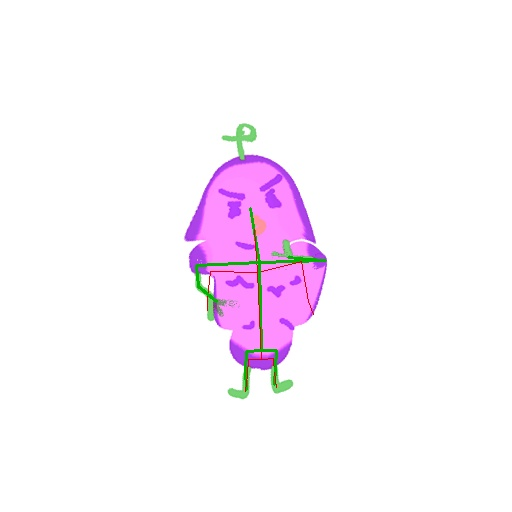

KakaoTalk_20261113_171159582_02__bvh_bird__0_t12.jpg


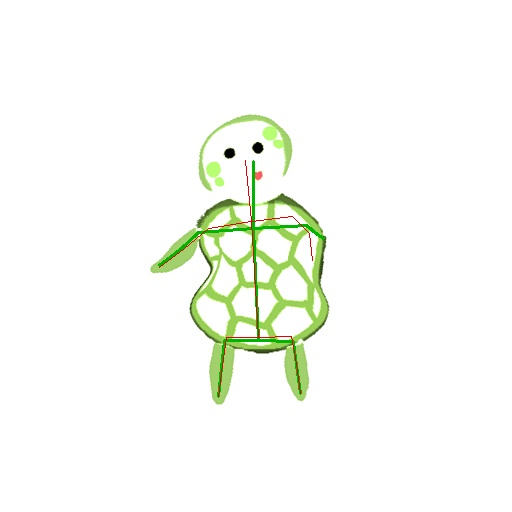

KakaoTalk_20261113_171159582_02__bvh_dab__0_t106.jpg


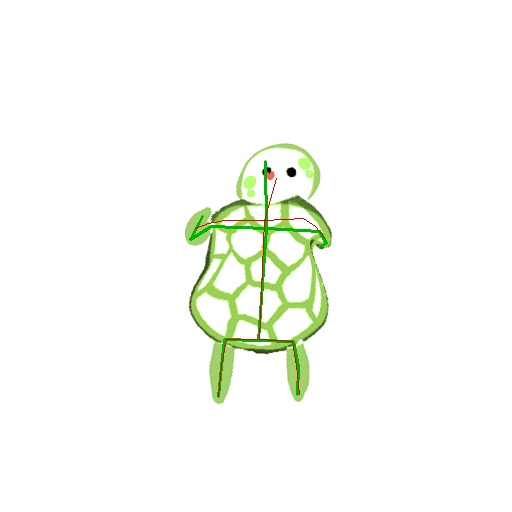

KakaoTalk_20261113_171159582_02__bvh_elephant__0_t42.jpg


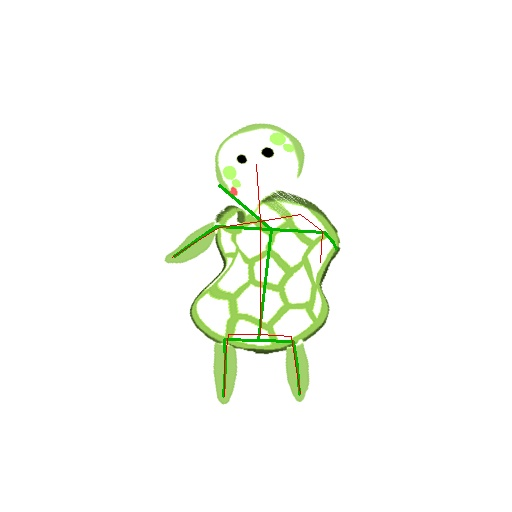

KakaoTalk_20261113_171159582_02__bvh_happy_walk__0_t50.jpg


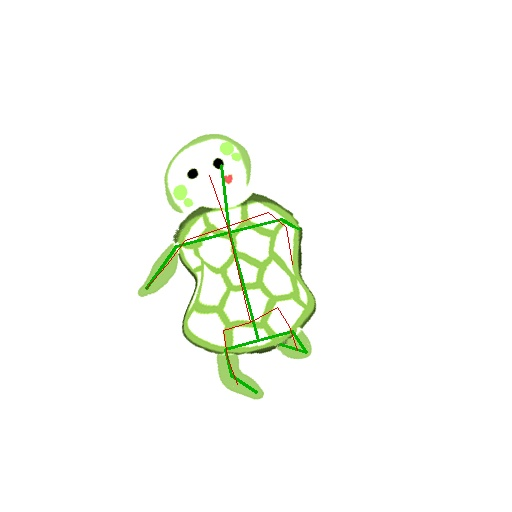

KakaoTalk_20261113_171159582_02__bvh_idle__0_t30.jpg


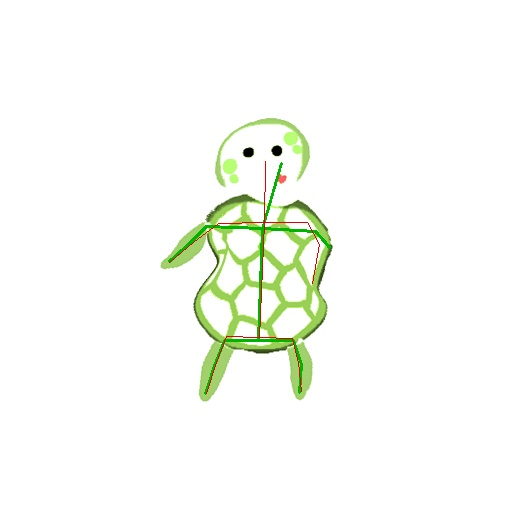

KakaoTalk_20261113_171159582_02__bvh_jesse_dance__0_t38.jpg


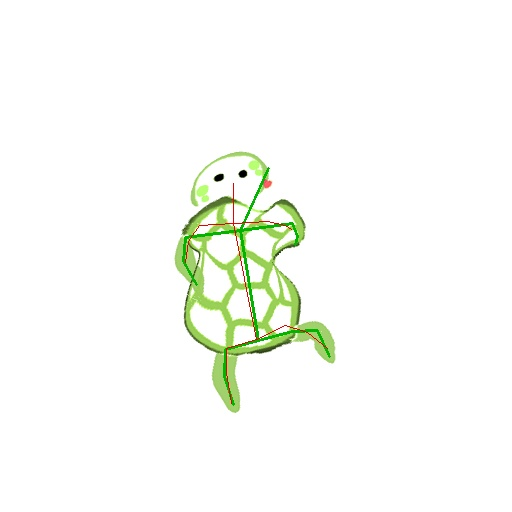

KakaoTalk_20261113_171159582_02__bvh_jumping__0_t24.jpg


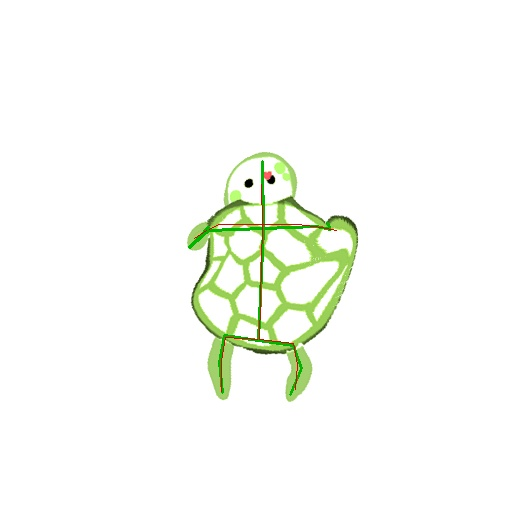

KakaoTalk_20261113_171159582_02__bvh_jumping_jacks__0_t58.jpg


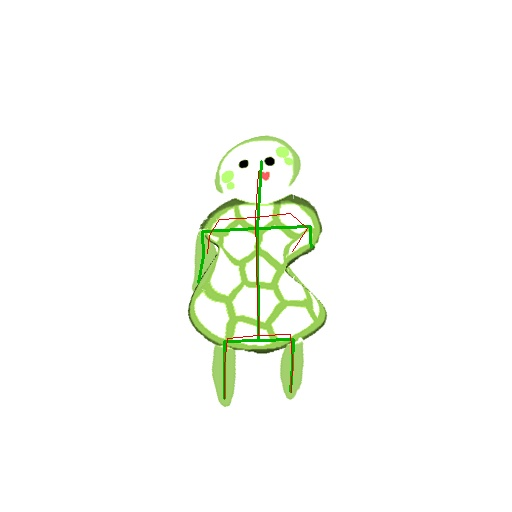

KakaoTalk_20261113_171159582_02__bvh_kick_ball__0_t48.jpg


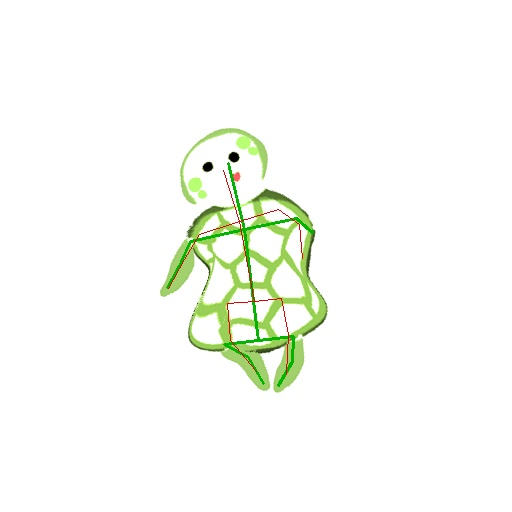

KakaoTalk_20261113_171159582_02__bvh_laugh__0_t22.jpg


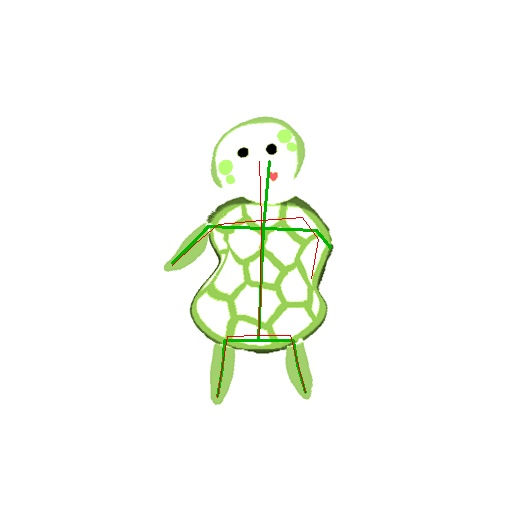

KakaoTalk_20261113_171159582_02__bvh_march__0_t24.jpg


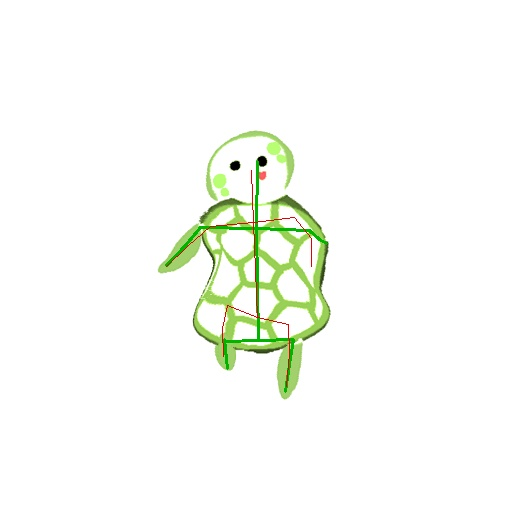

KakaoTalk_20261113_171159582_02__bvh_monkey__0_t54.jpg


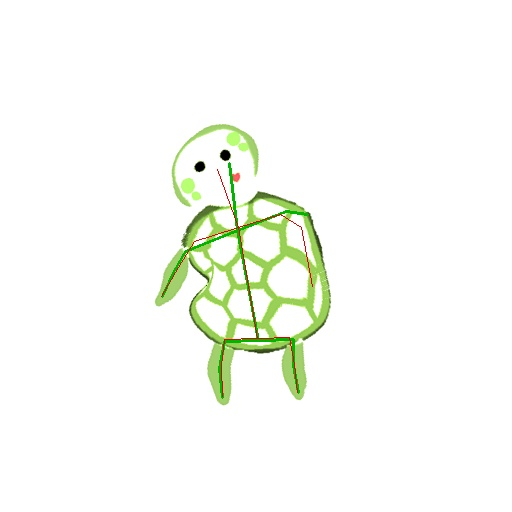

KakaoTalk_20261113_171159582_02__bvh_point__0_t14.jpg


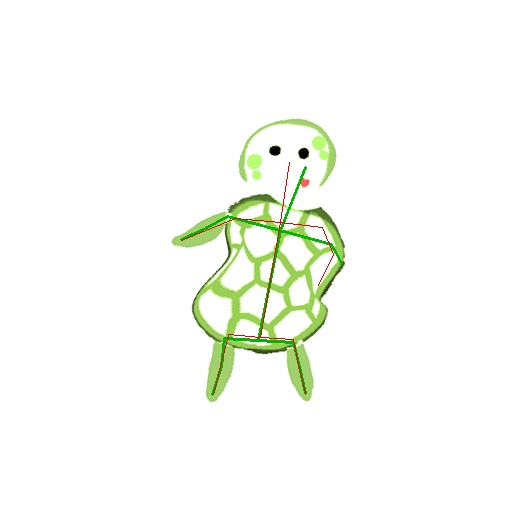

KakaoTalk_20261113_171159582_02__bvh_reach_tiptoe__0_t36.jpg


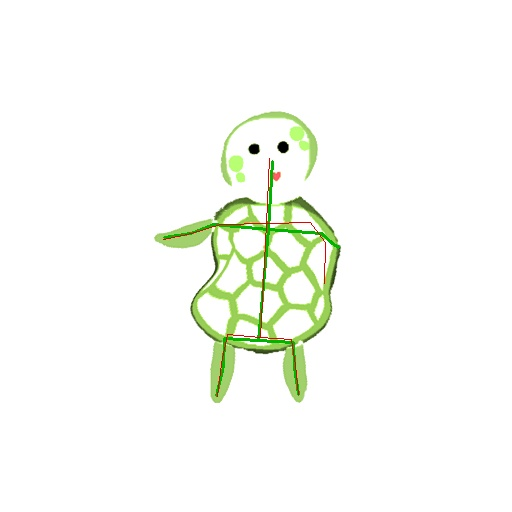

KakaoTalk_20261113_171159582_02__bvh_sad_walk__0_t38.jpg


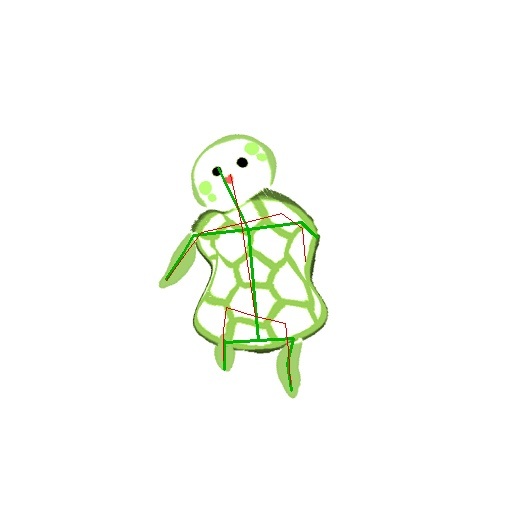

KakaoTalk_20261113_171159582_02__bvh_search_ground__0_t40.jpg


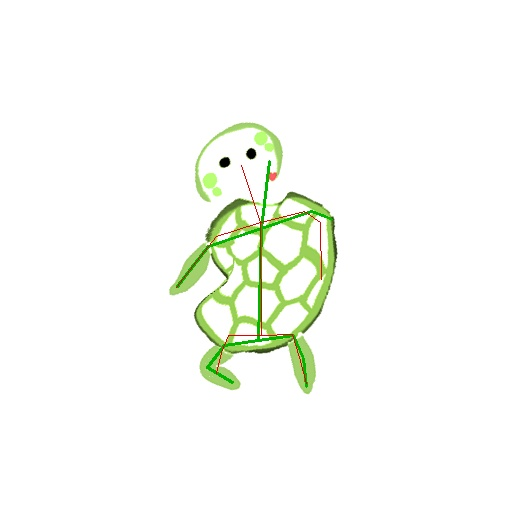

KakaoTalk_20261113_171159582_02__bvh_stand_still__0_t34.jpg


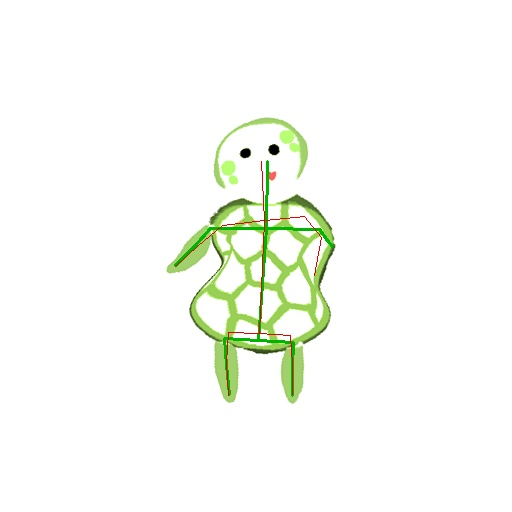

KakaoTalk_20261113_171159582_02__bvh_swim__0_t16.jpg


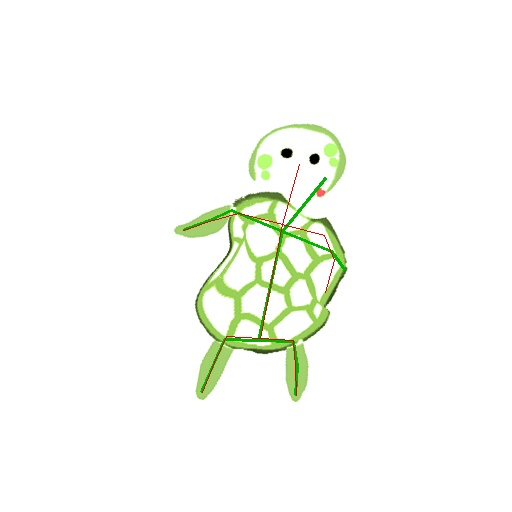

KakaoTalk_20261113_171159582_02__bvh_very_happy__0_t30.jpg


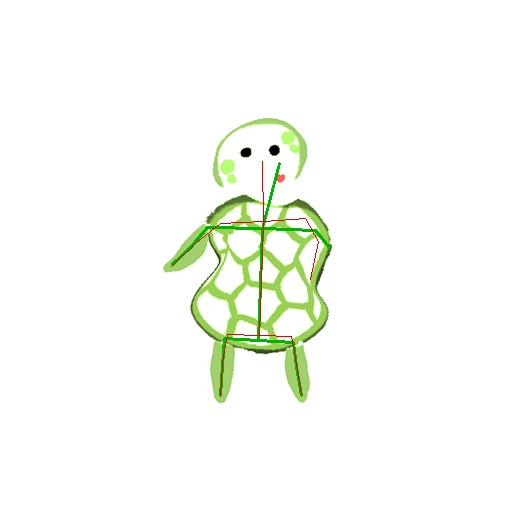

KakaoTalk_20261113_171159582_02__bvh_wave_hello__0_t36.jpg


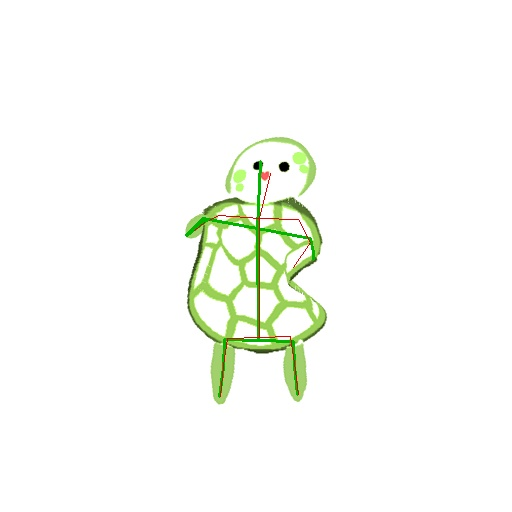

KakaoTalk_20261113_171159582_02__bvh_zombie__0_t32.jpg


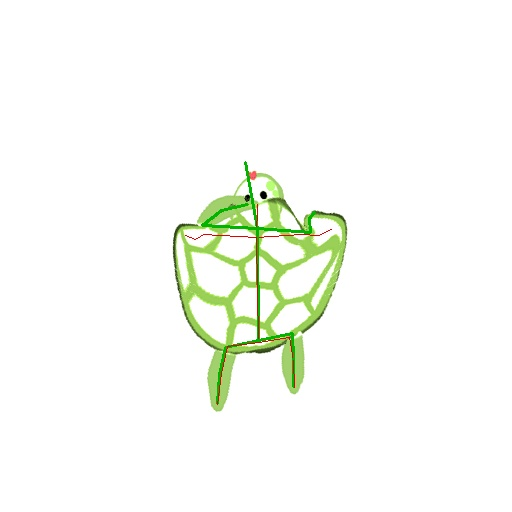

KakaoTalk_20261113_171159582_03__bvh_bird__0_t24.jpg


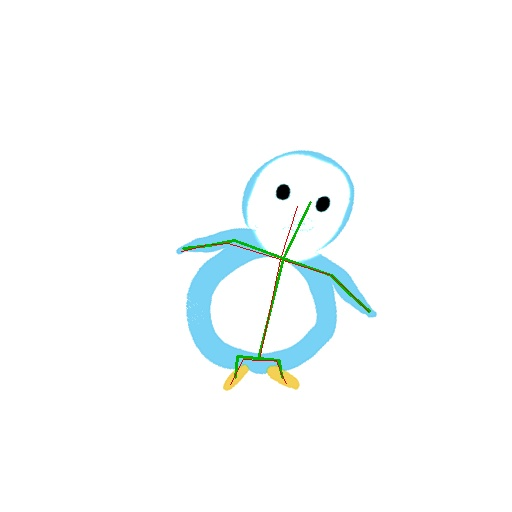

KakaoTalk_20261113_171159582_03__bvh_dab__0_t46.jpg


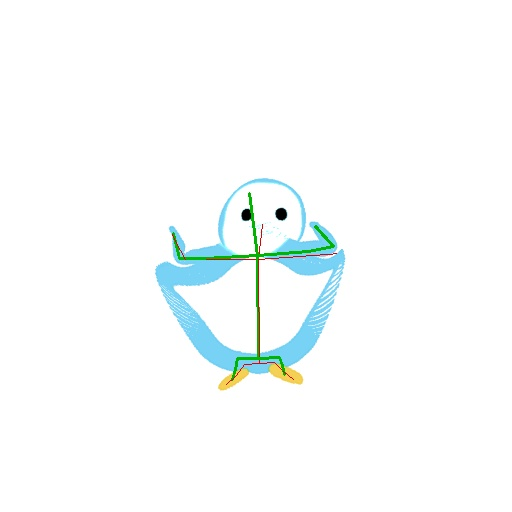

KakaoTalk_20261113_171159582_03__bvh_elephant__0_t42.jpg


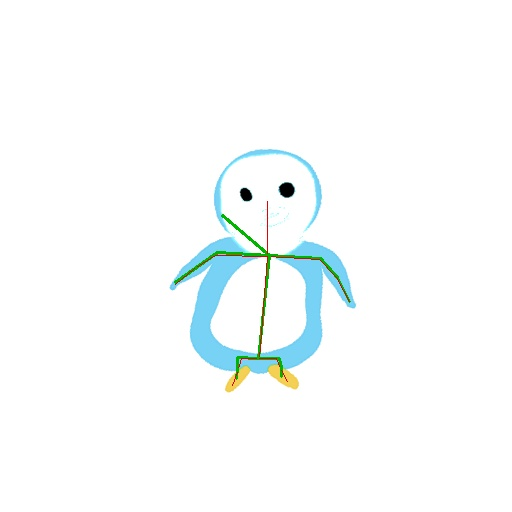

KakaoTalk_20261113_171159582_03__bvh_happy_walk__0_t30.jpg


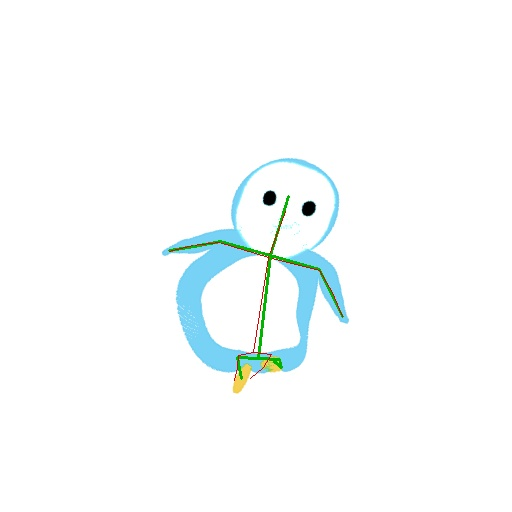

KakaoTalk_20261113_171159582_03__bvh_idle__0_t12.jpg


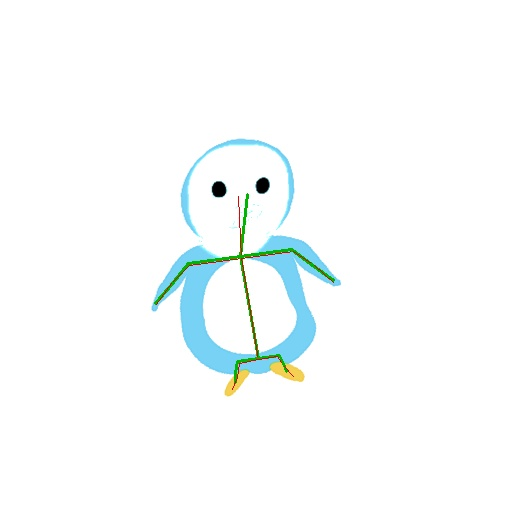

KakaoTalk_20261113_171159582_03__bvh_jesse_dance__0_t34.jpg


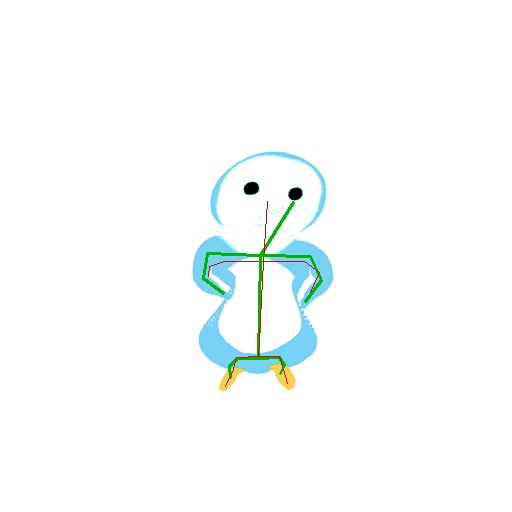

KakaoTalk_20261113_171159582_03__bvh_jumping__0_t24.jpg


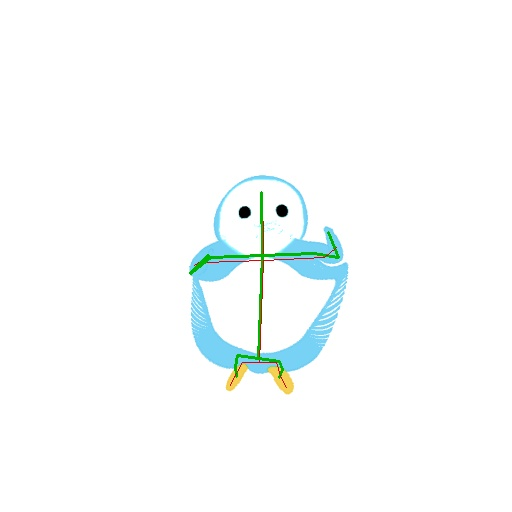

KakaoTalk_20261113_171159582_03__bvh_jumping_jacks__0_t16.jpg


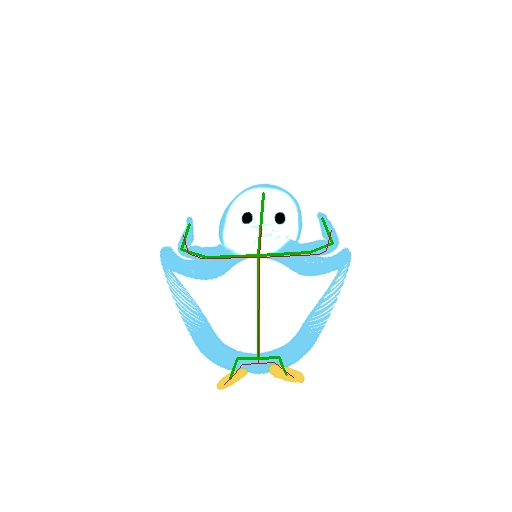

KakaoTalk_20261113_171159582_03__bvh_kick_ball__0_t48.jpg


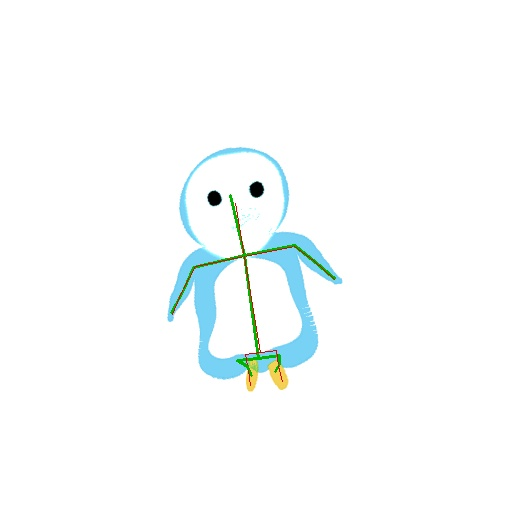

KakaoTalk_20261113_171159582_03__bvh_laugh__0_t14.jpg


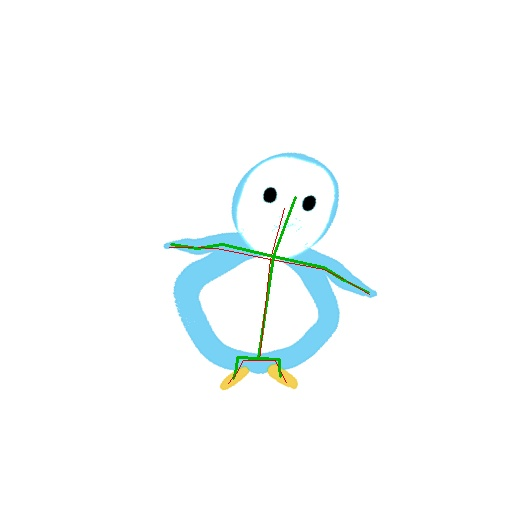

KakaoTalk_20261113_171159582_03__bvh_march__0_t34.jpg


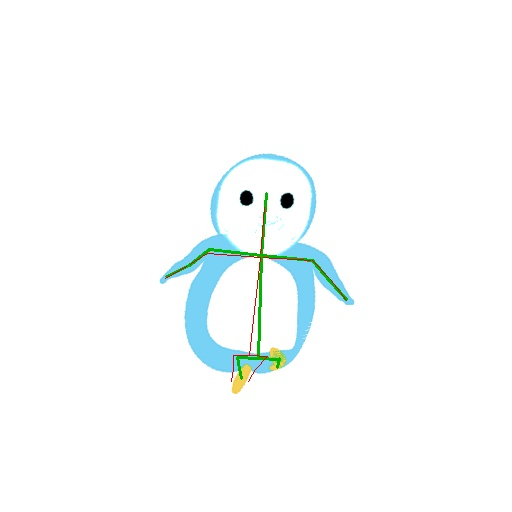

KakaoTalk_20261113_171159582_03__bvh_monkey__0_t32.jpg


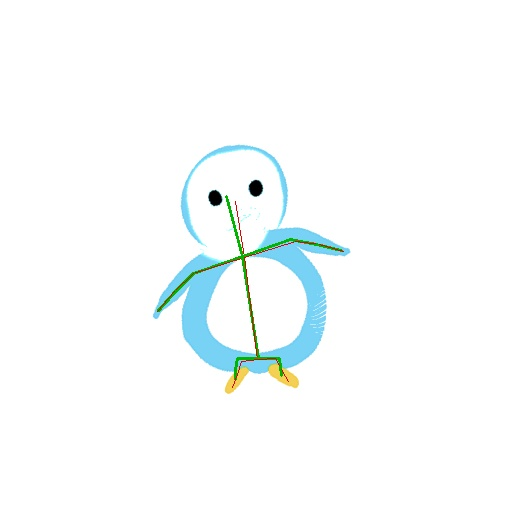

KakaoTalk_20261113_171159582_03__bvh_point__0_t30.jpg


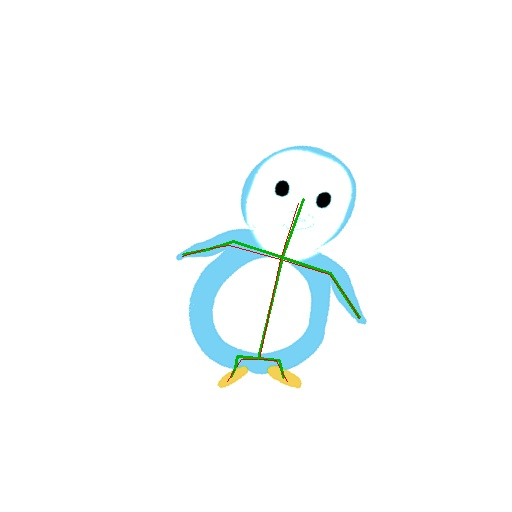

KakaoTalk_20261113_171159582_03__bvh_reach_tiptoe__0_t10.jpg


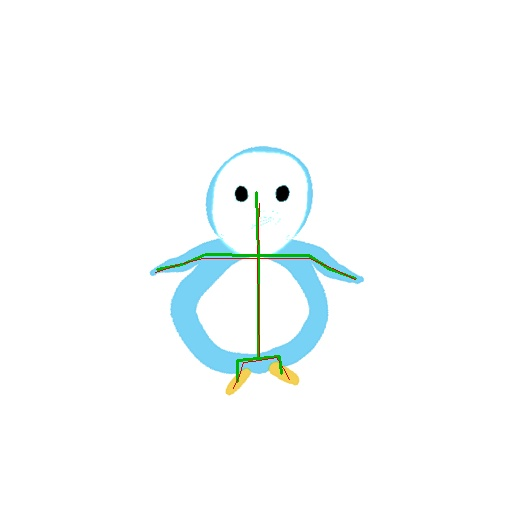

KakaoTalk_20261113_171159582_03__bvh_sad_walk__0_t40.jpg


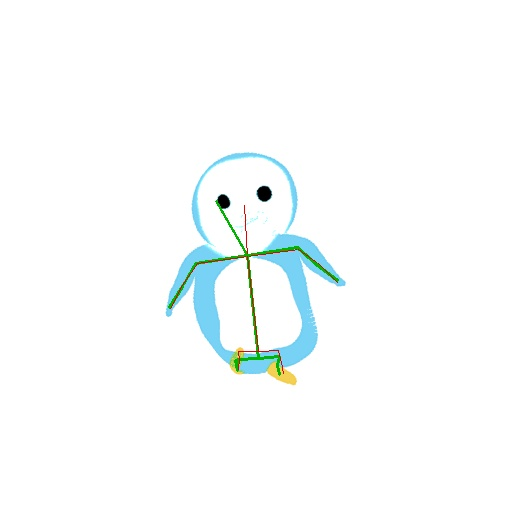

KakaoTalk_20261113_171159582_03__bvh_search_ground__0_t24.jpg


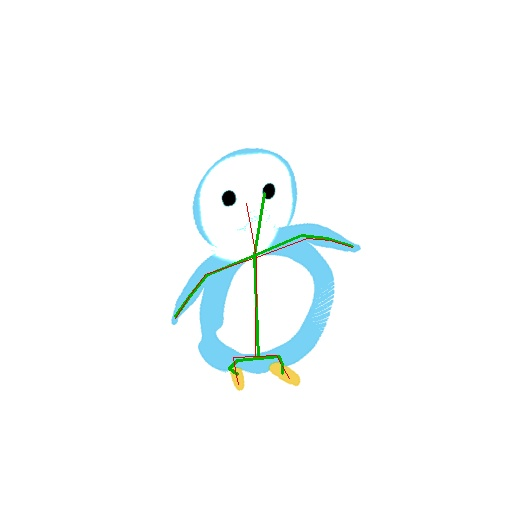

KakaoTalk_20261113_171159582_03__bvh_stand_still__0_t8.jpg


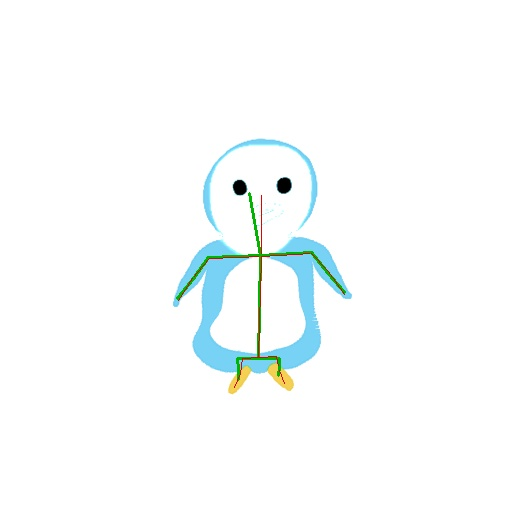

KakaoTalk_20261113_171159582_03__bvh_swim__0_t26.jpg


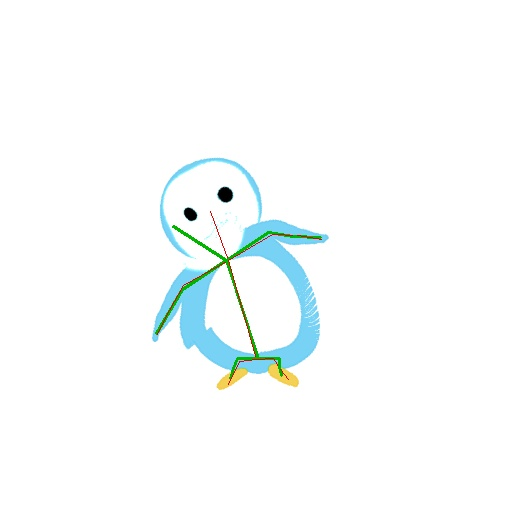

KakaoTalk_20261113_171159582_03__bvh_very_happy__0_t26.jpg


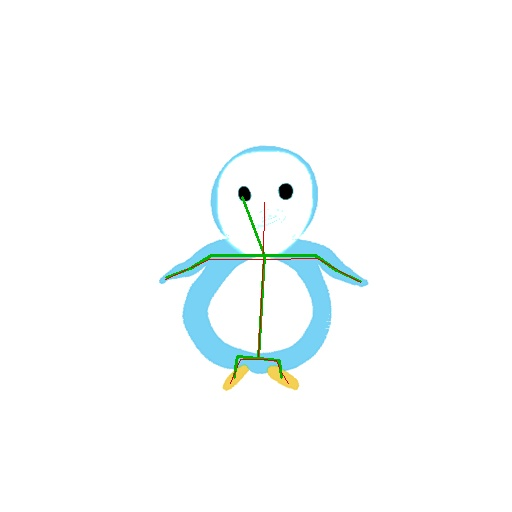

KakaoTalk_20261113_171159582_03__bvh_wave_hello__0_t30.jpg


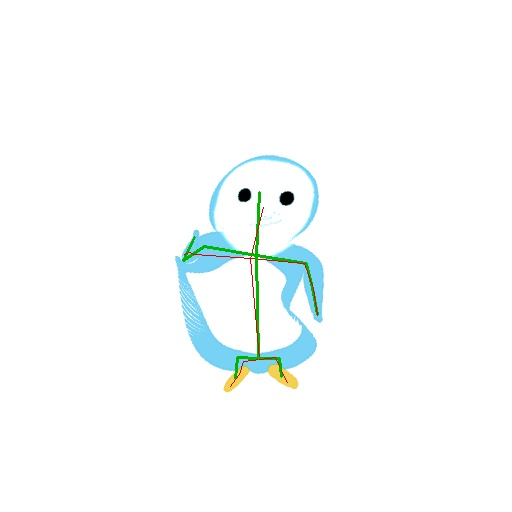

KakaoTalk_20261113_171159582_03__bvh_zombie__0_t32.jpg


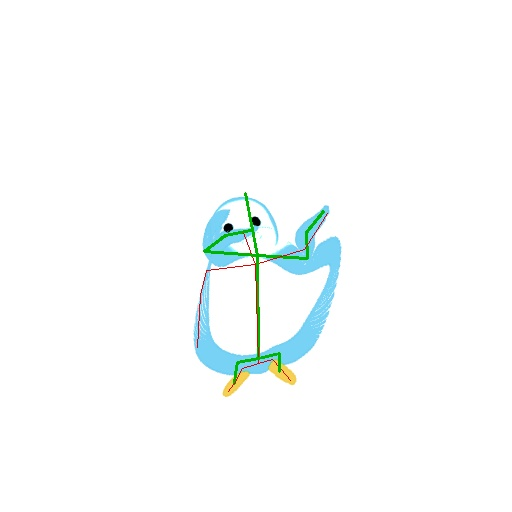

KakaoTalk_20261113_171159582_04__bvh_bird__0_t34.jpg


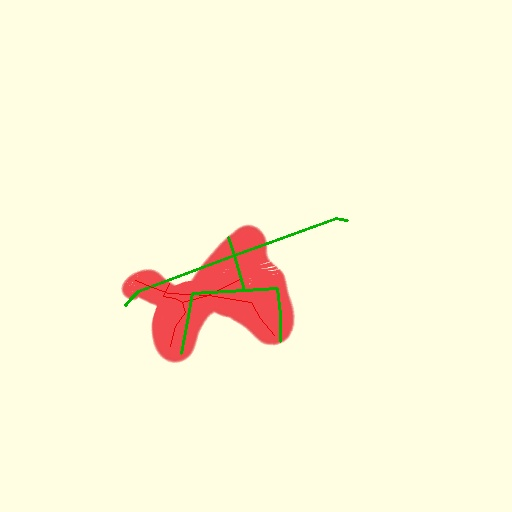

KakaoTalk_20261113_171159582_04__bvh_dab__0_t22.jpg


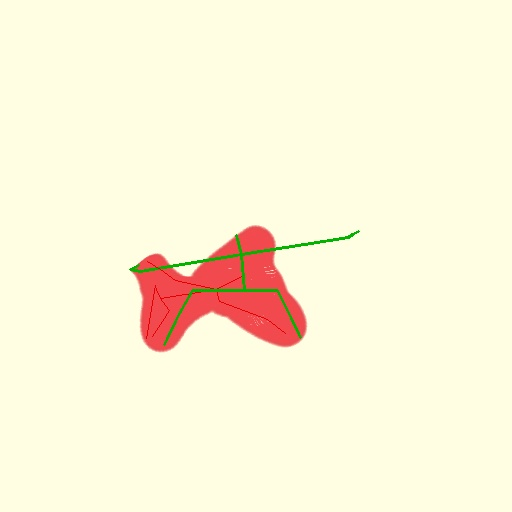

KakaoTalk_20261113_171159582_04__bvh_elephant__0_t30.jpg


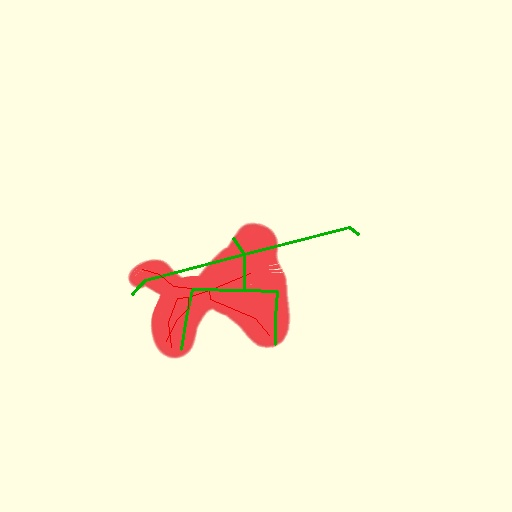

KakaoTalk_20261113_171159582_04__bvh_happy_walk__0_t20.jpg


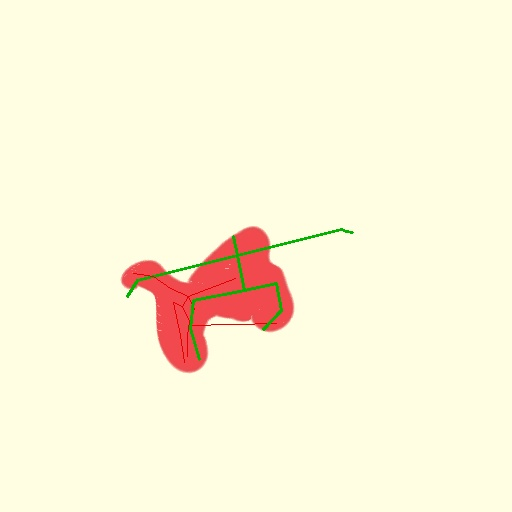

KakaoTalk_20261113_171159582_04__bvh_idle__0_t18.jpg


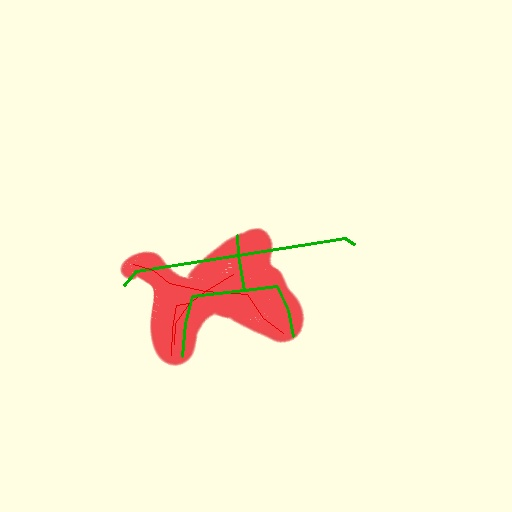

KakaoTalk_20261113_171159582_04__bvh_jesse_dance__0_t130.jpg


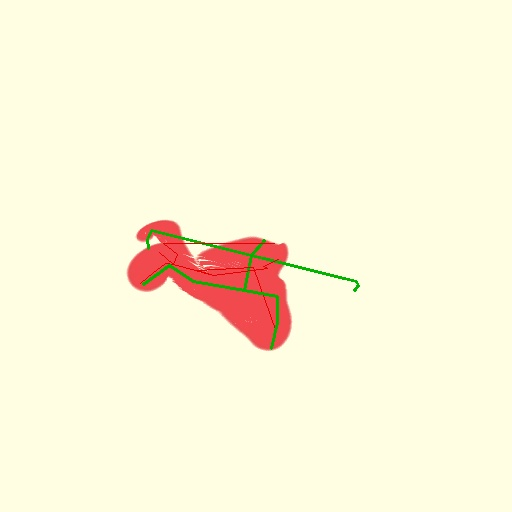

KakaoTalk_20261113_171159582_04__bvh_jumping__0_t4.jpg


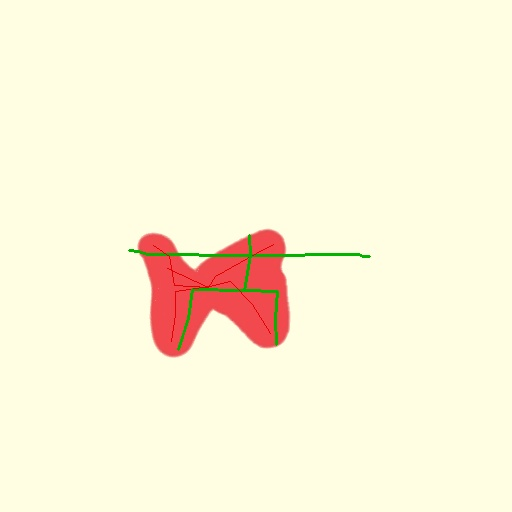

KakaoTalk_20261113_171159582_04__bvh_jumping_jacks__0_t2.jpg


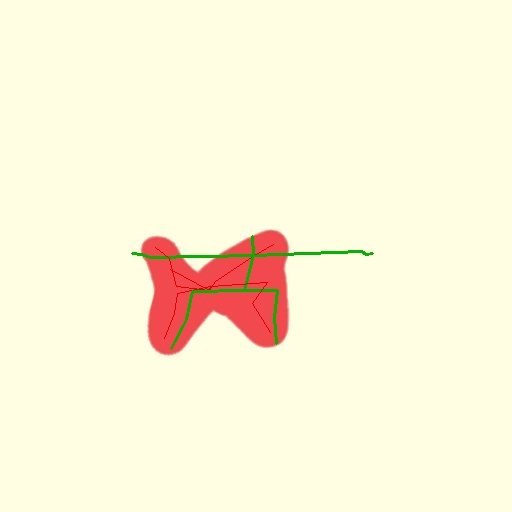

KakaoTalk_20261113_171159582_04__bvh_kick_ball__0_t4.jpg


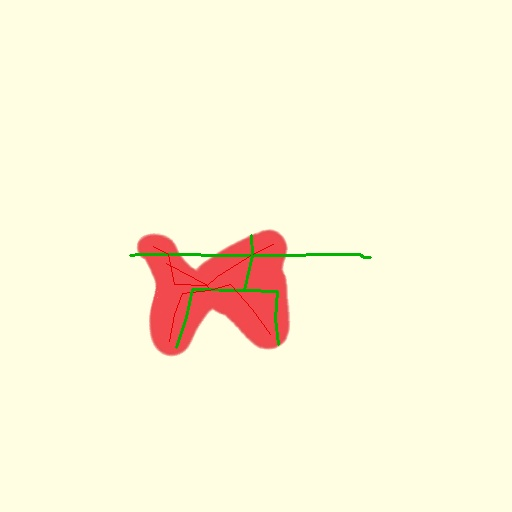

KakaoTalk_20261113_171159582_04__bvh_laugh__0_t12.jpg


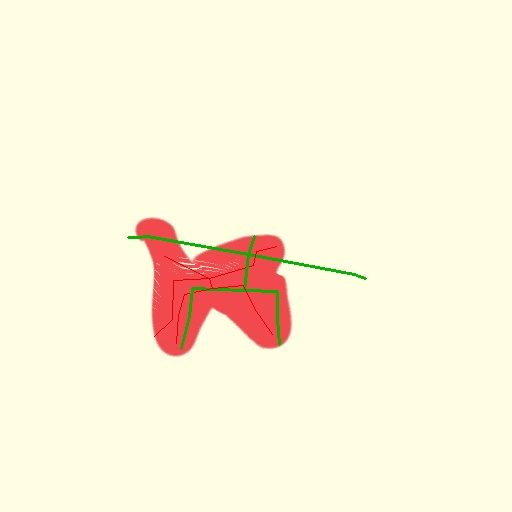

KakaoTalk_20261113_171159582_04__bvh_march__0_t30.jpg


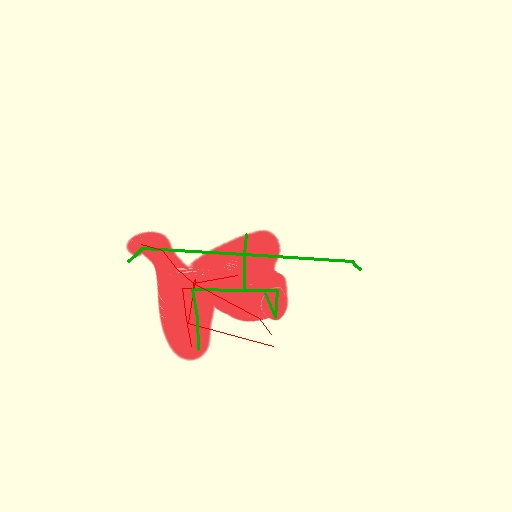

KakaoTalk_20261113_171159582_04__bvh_monkey__0_t30.jpg


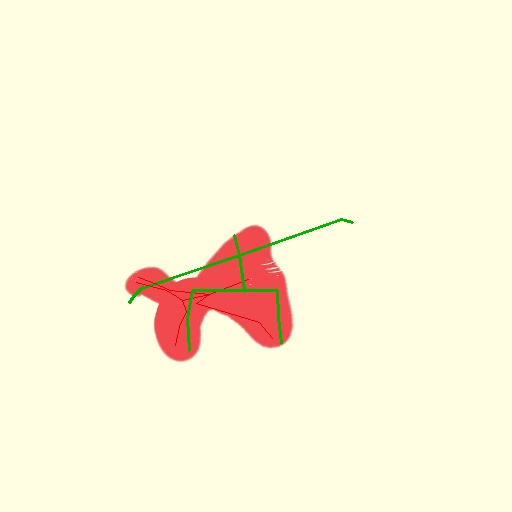

KakaoTalk_20261113_171159582_04__bvh_point__0_t42.jpg


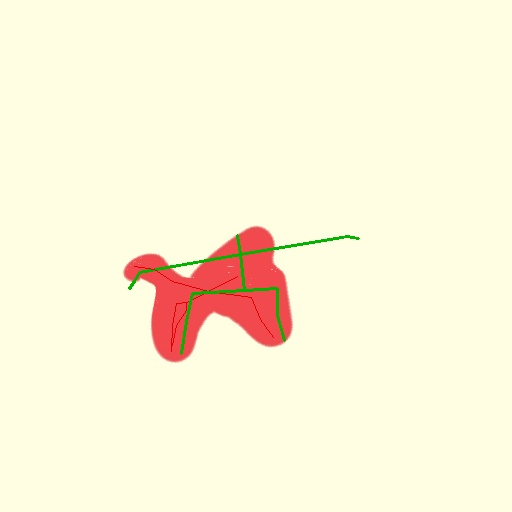

KakaoTalk_20261113_171159582_04__bvh_reach_tiptoe__0_t32.jpg


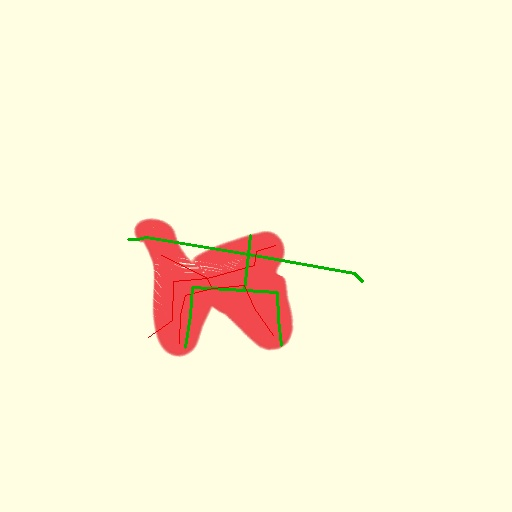

KakaoTalk_20261113_171159582_04__bvh_sad_walk__0_t24.jpg


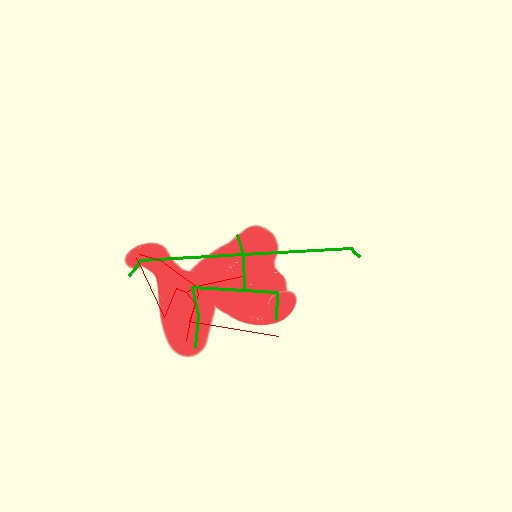

KakaoTalk_20261113_171159582_04__bvh_search_ground__0_t56.jpg


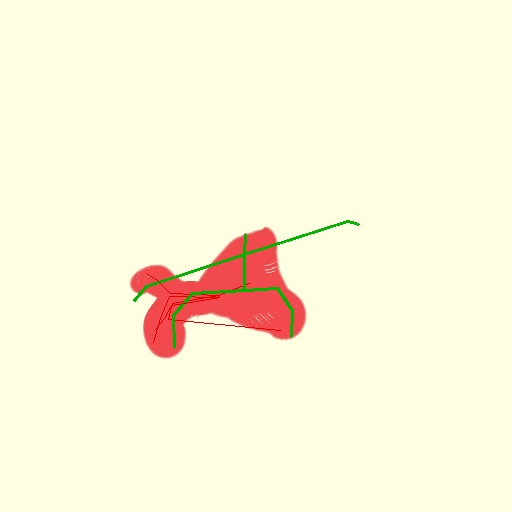

KakaoTalk_20261113_171159582_04__bvh_stand_still__0_t6.jpg


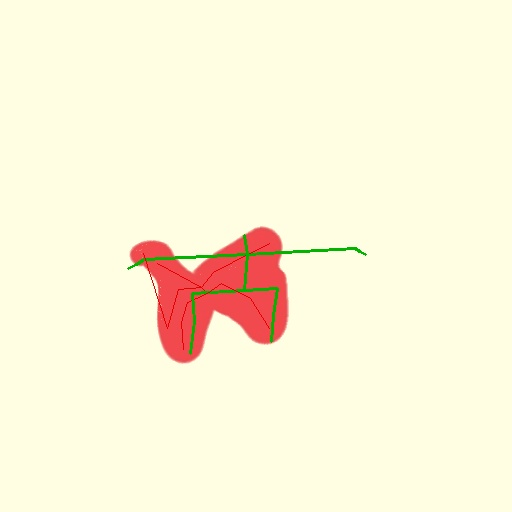

KakaoTalk_20261113_171159582_04__bvh_swim__0_t8.jpg


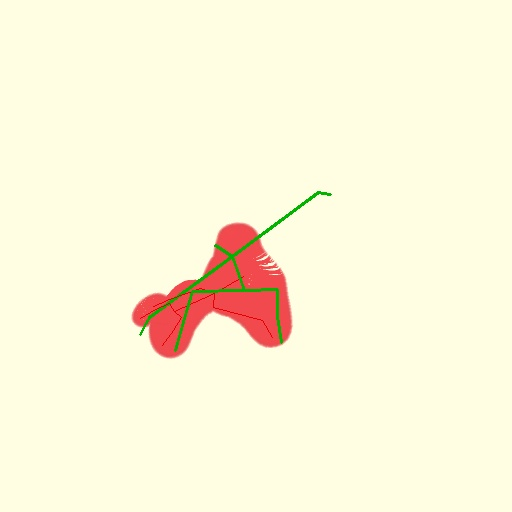

KakaoTalk_20261113_171159582_04__bvh_very_happy__0_t4.jpg


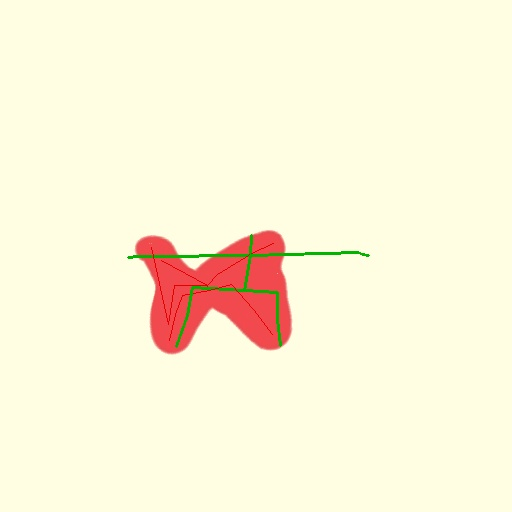

KakaoTalk_20261113_171159582_04__bvh_wave_hello__0_t4.jpg


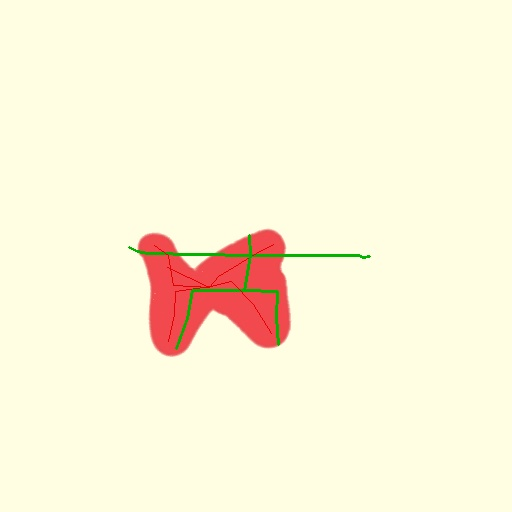

KakaoTalk_20261113_171159582_04__bvh_zombie__0_t372.jpg


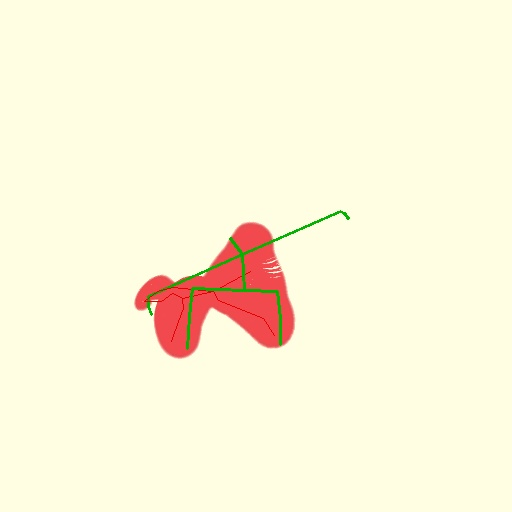

KakaoTalk_20261113_171159582_05__bvh_bird__0_t10.jpg


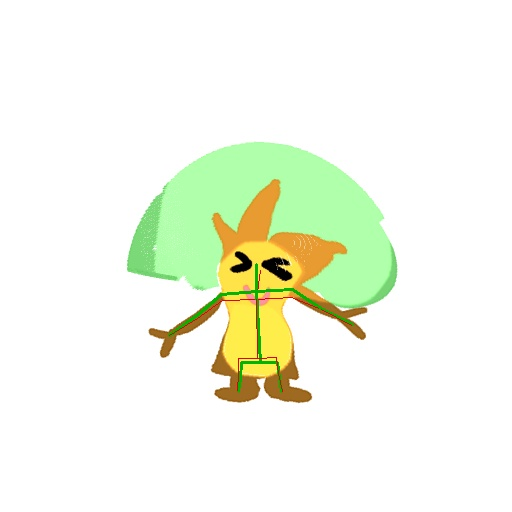

KakaoTalk_20261113_171159582_05__bvh_dab__0_t116.jpg


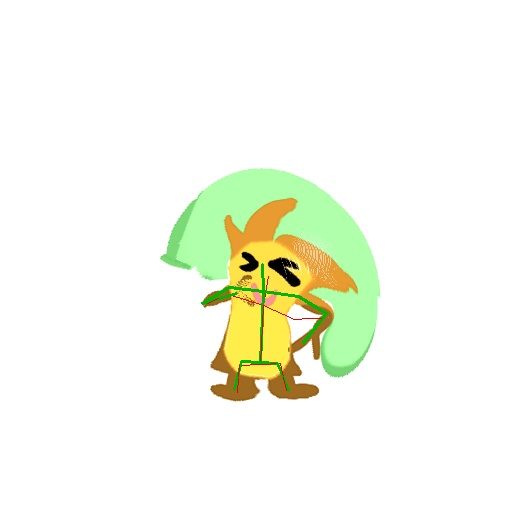

KakaoTalk_20261113_171159582_05__bvh_elephant__0_t40.jpg


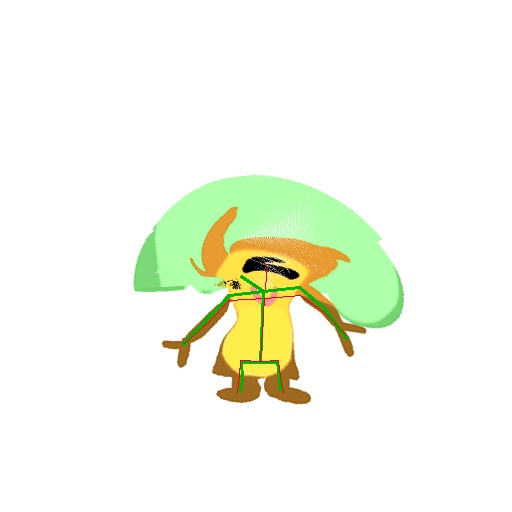

KakaoTalk_20261113_171159582_05__bvh_happy_walk__0_t50.jpg


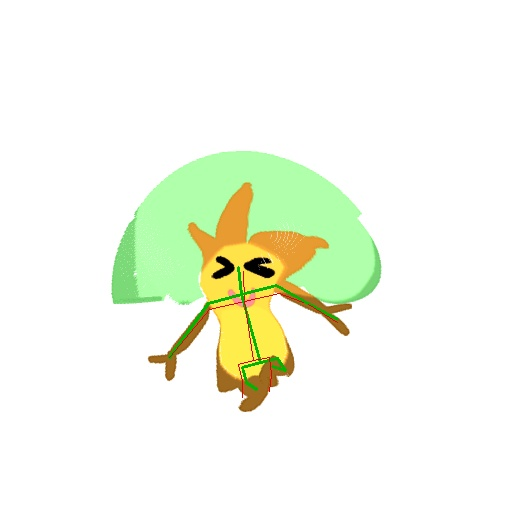

KakaoTalk_20261113_171159582_05__bvh_idle__0_t20.jpg


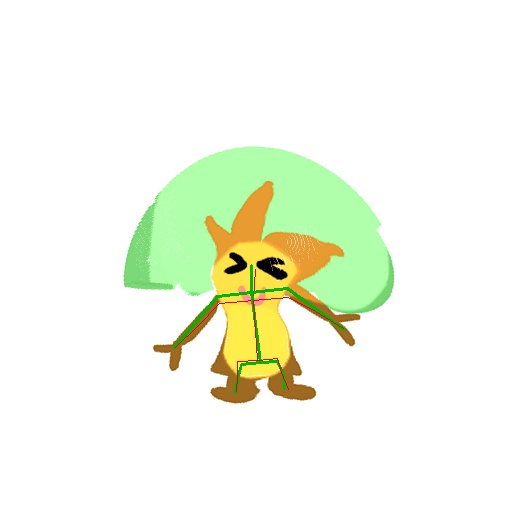

KakaoTalk_20261113_171159582_05__bvh_jesse_dance__0_t16.jpg


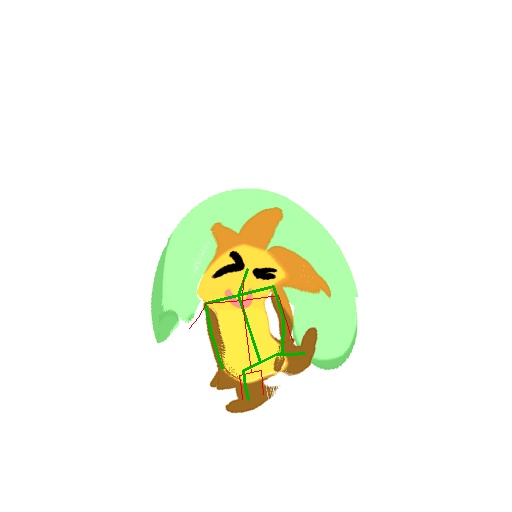

KakaoTalk_20261113_171159582_05__bvh_jumping__0_t24.jpg


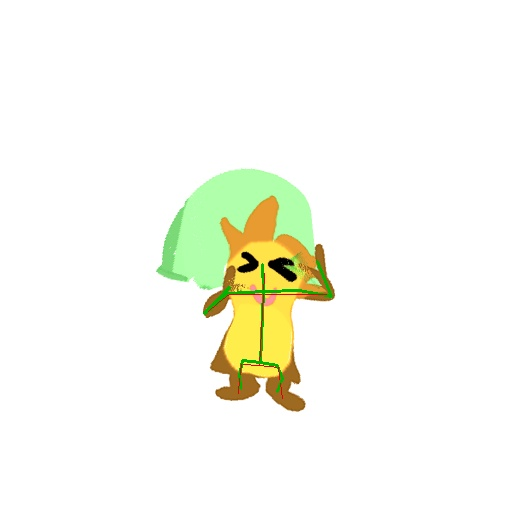

KakaoTalk_20261113_171159582_05__bvh_jumping_jacks__0_t62.jpg


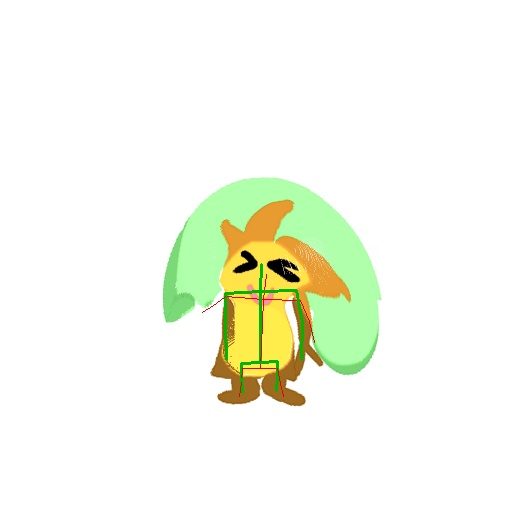

KakaoTalk_20261113_171159582_05__bvh_kick_ball__0_t46.jpg


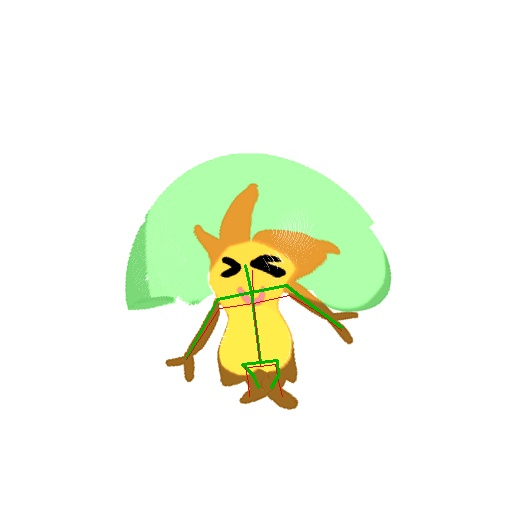

KakaoTalk_20261113_171159582_05__bvh_laugh__0_t44.jpg


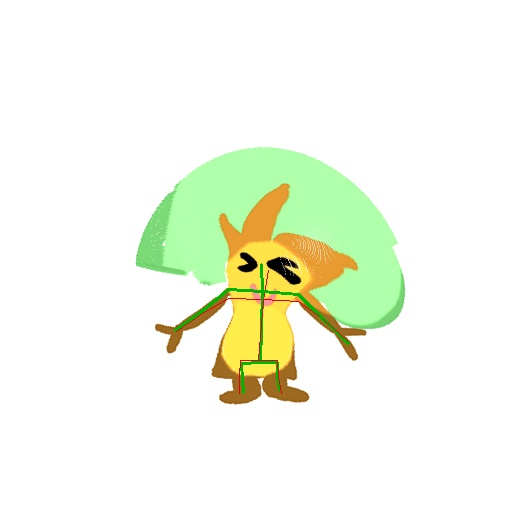

KakaoTalk_20261113_171159582_05__bvh_march__0_t32.jpg


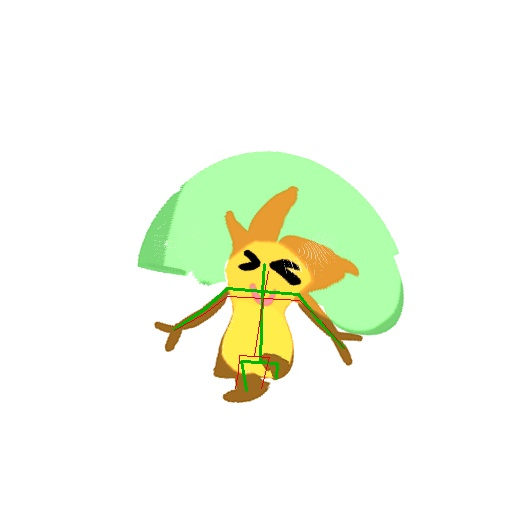

KakaoTalk_20261113_171159582_05__bvh_monkey__0_t14.jpg


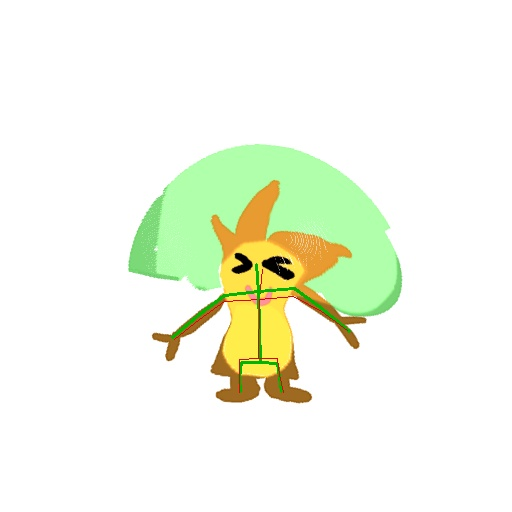

KakaoTalk_20261113_171159582_05__bvh_point__0_t46.jpg


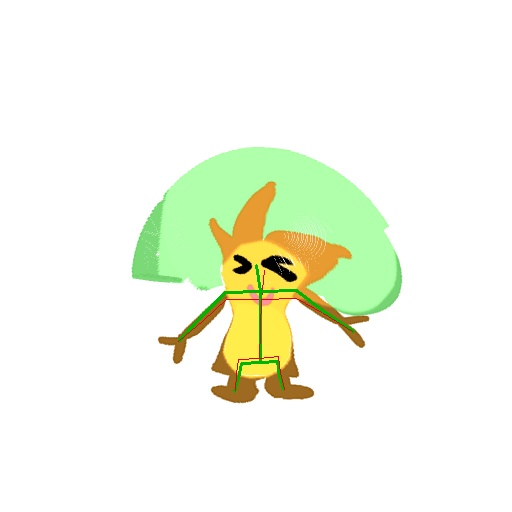

KakaoTalk_20261113_171159582_05__bvh_reach_tiptoe__0_t12.jpg


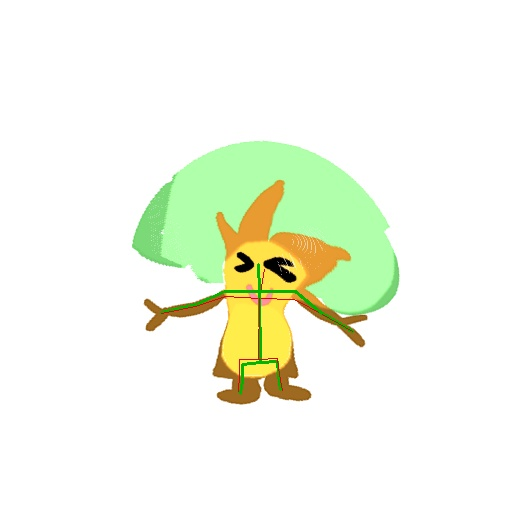

KakaoTalk_20261113_171159582_05__bvh_sad_walk__0_t52.jpg


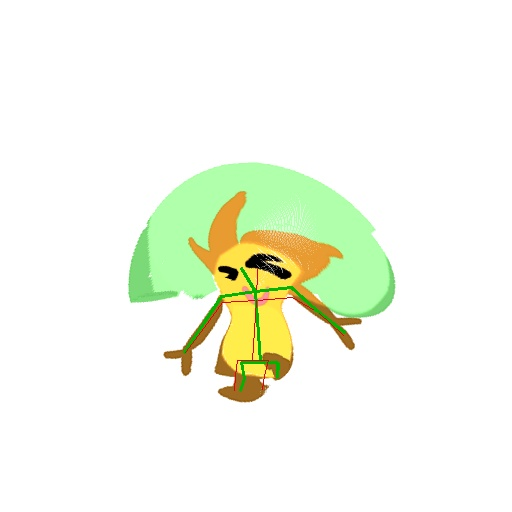

KakaoTalk_20261113_171159582_05__bvh_search_ground__0_t40.jpg


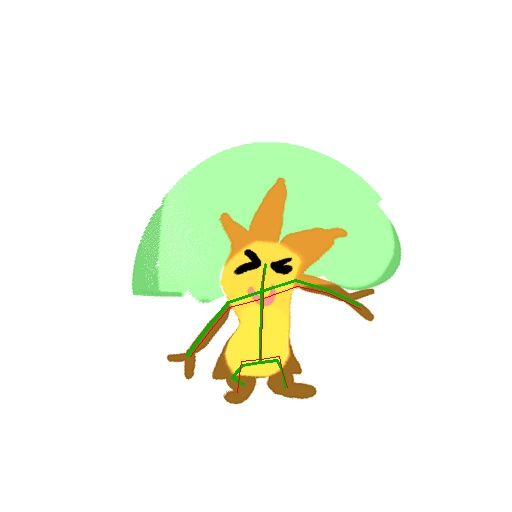

KakaoTalk_20261113_171159582_05__bvh_stand_still__0_t24.jpg


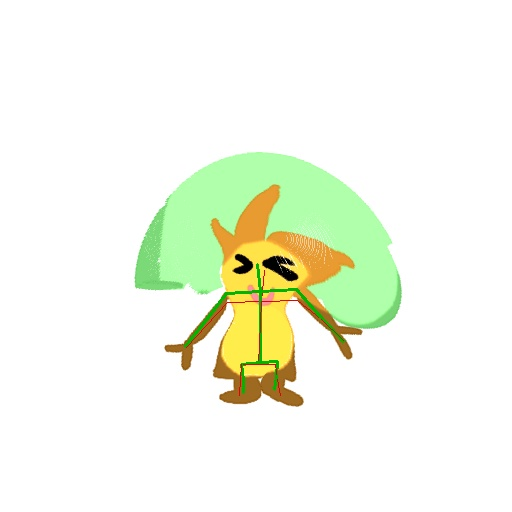

KakaoTalk_20261113_171159582_05__bvh_swim__0_t8.jpg


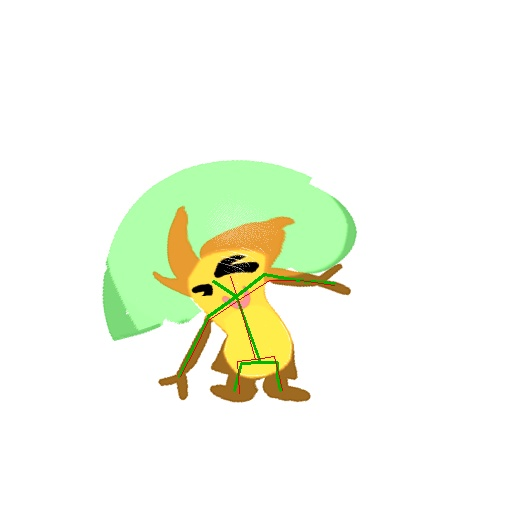

KakaoTalk_20261113_171159582_05__bvh_very_happy__0_t24.jpg


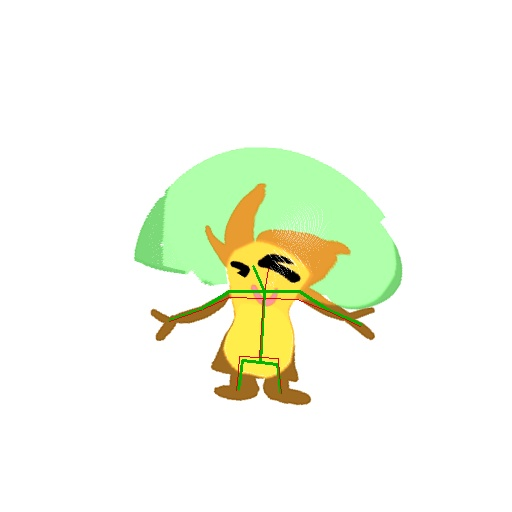

KakaoTalk_20261113_171159582_05__bvh_wave_hello__0_t40.jpg


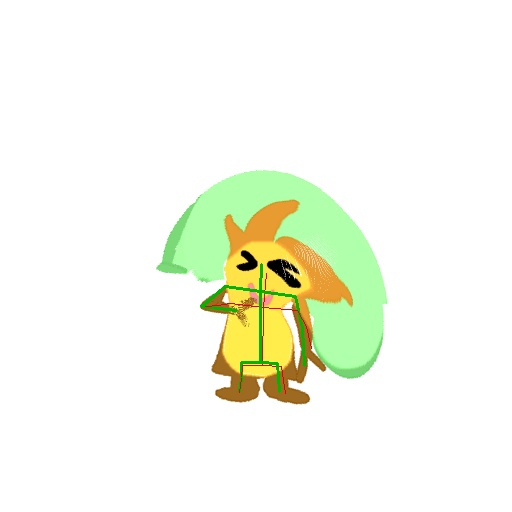

KakaoTalk_20261113_171159582_05__bvh_zombie__0_t46.jpg


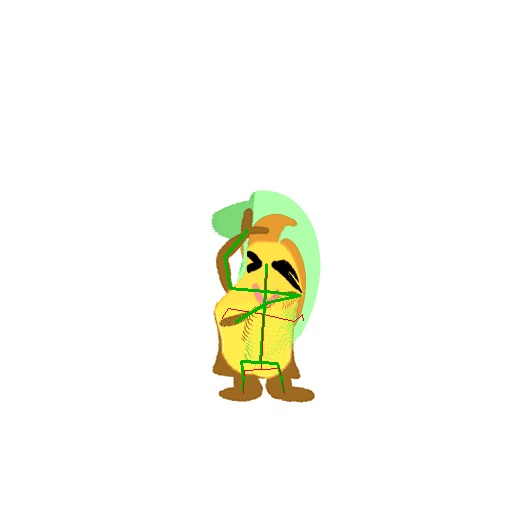

KakaoTalk_20261113_171159582_06__bvh_bird__0_t34.jpg


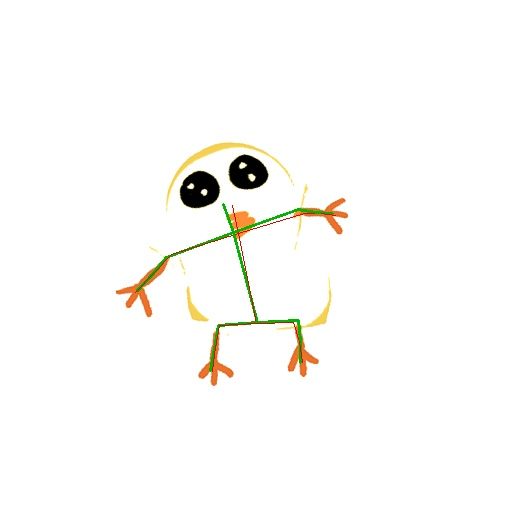

KakaoTalk_20261113_171159582_06__bvh_dab__0_t116.jpg


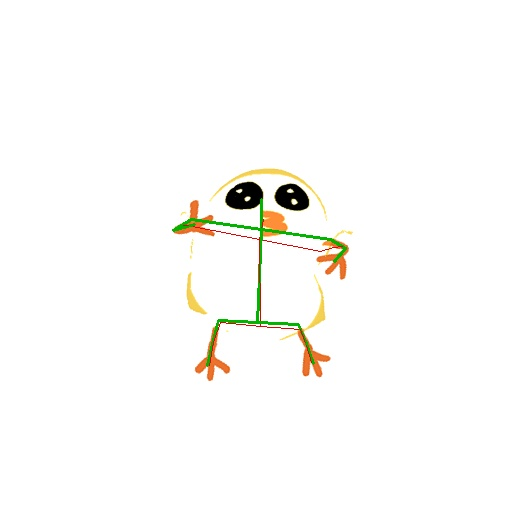

KakaoTalk_20261113_171159582_06__bvh_elephant__0_t36.jpg


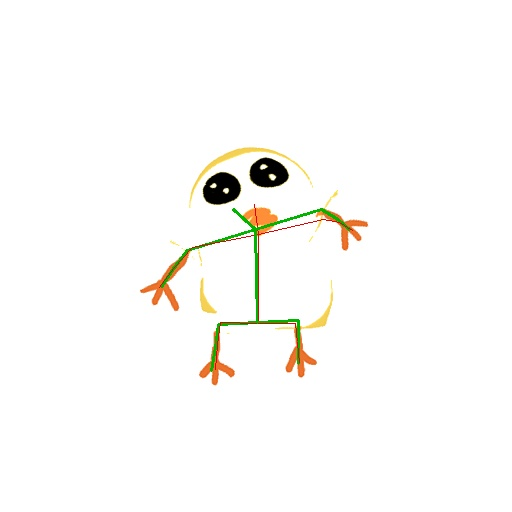

KakaoTalk_20261113_171159582_06__bvh_happy_walk__0_t32.jpg


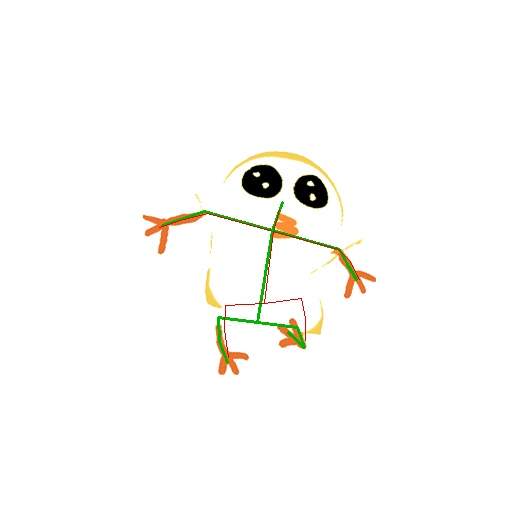

KakaoTalk_20261113_171159582_06__bvh_idle__0_t36.jpg


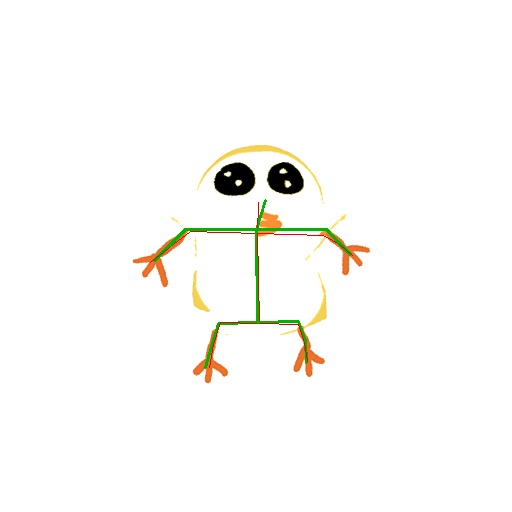

KakaoTalk_20261113_171159582_06__bvh_jesse_dance__0_t14.jpg


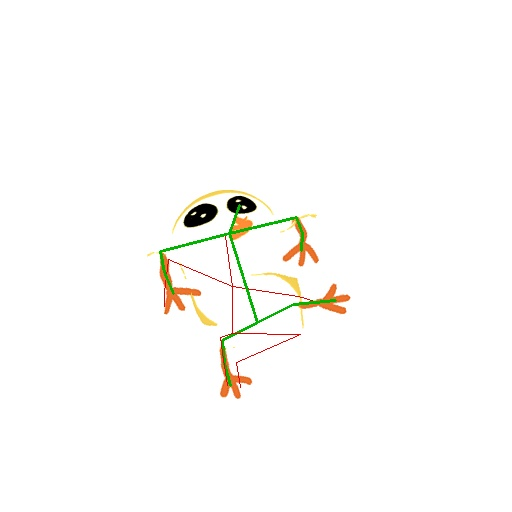

KakaoTalk_20261113_171159582_06__bvh_jumping__0_t32.jpg


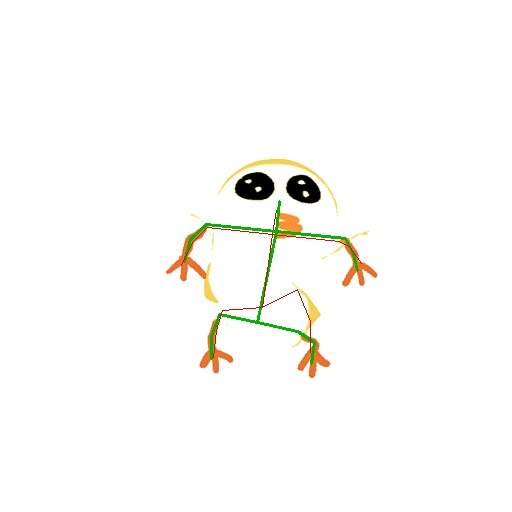

KakaoTalk_20261113_171159582_06__bvh_jumping_jacks__0_t62.jpg


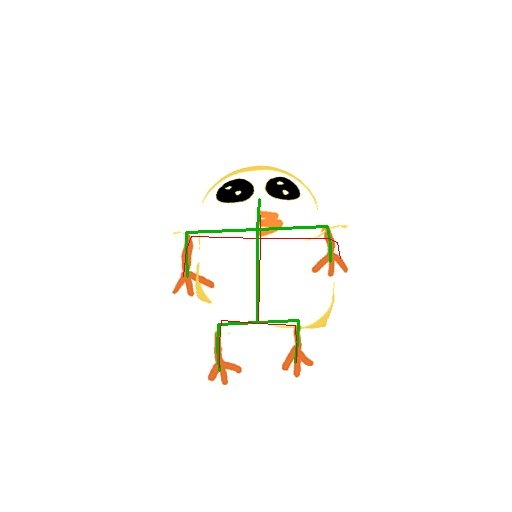

KakaoTalk_20261113_171159582_06__bvh_kick_ball__0_t48.jpg


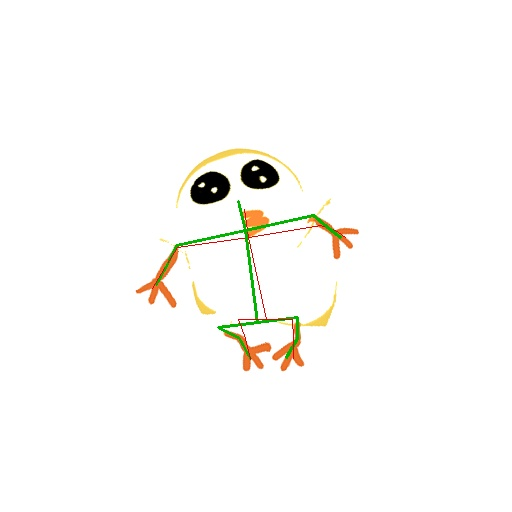

KakaoTalk_20261113_171159582_06__bvh_laugh__0_t44.jpg


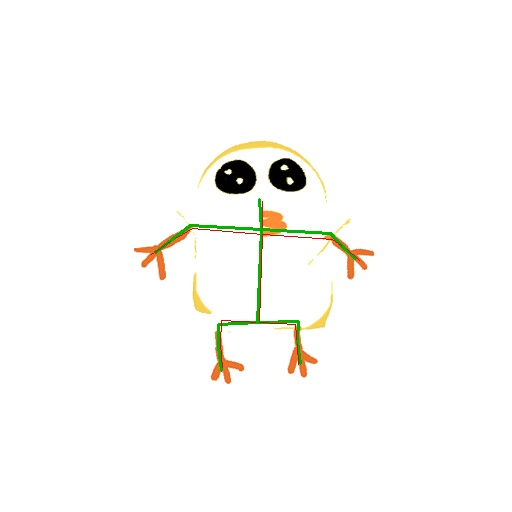

KakaoTalk_20261113_171159582_06__bvh_march__0_t30.jpg


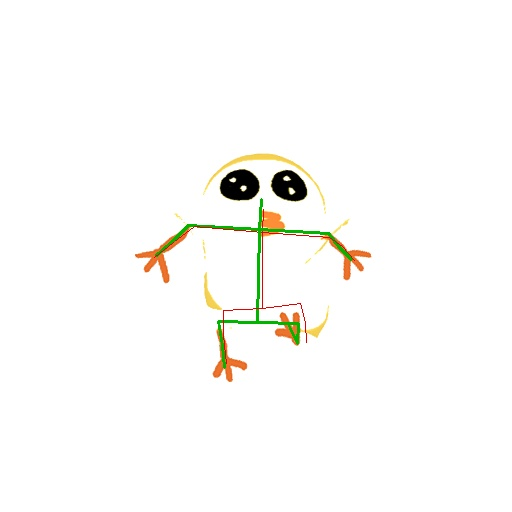

KakaoTalk_20261113_171159582_06__bvh_monkey__0_t42.jpg


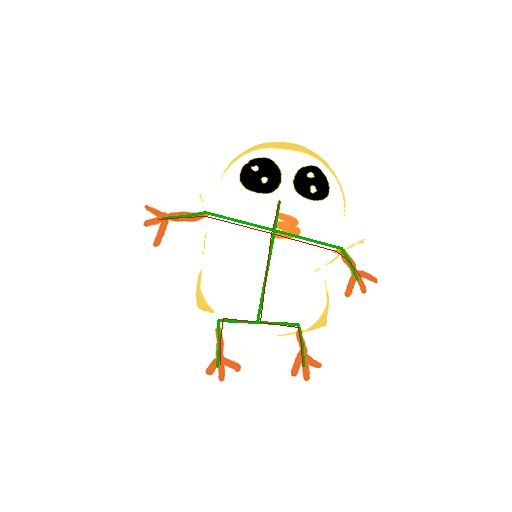

KakaoTalk_20261113_171159582_06__bvh_point__0_t14.jpg


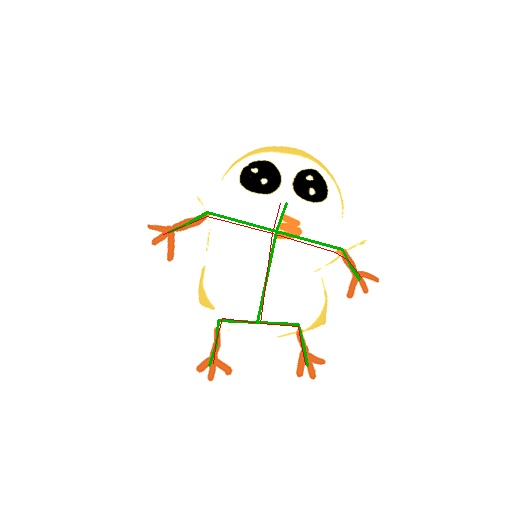

KakaoTalk_20261113_171159582_06__bvh_reach_tiptoe__0_t26.jpg


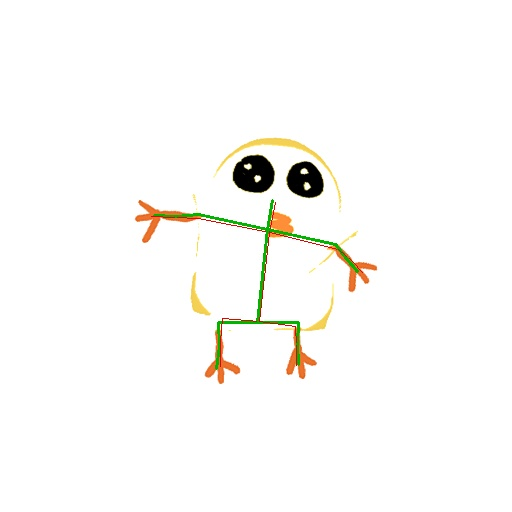

KakaoTalk_20261113_171159582_06__bvh_sad_walk__0_t20.jpg


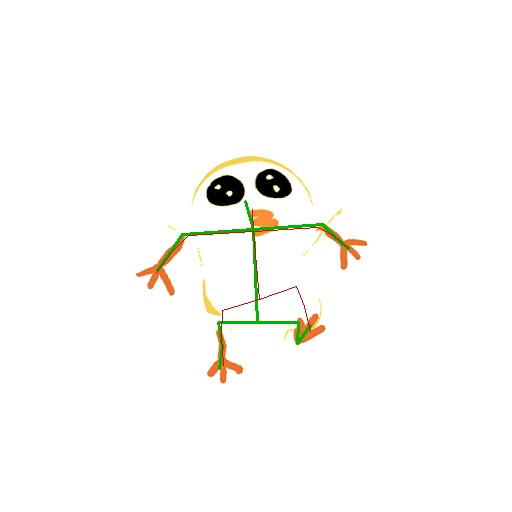

KakaoTalk_20261113_171159582_06__bvh_search_ground__0_t42.jpg


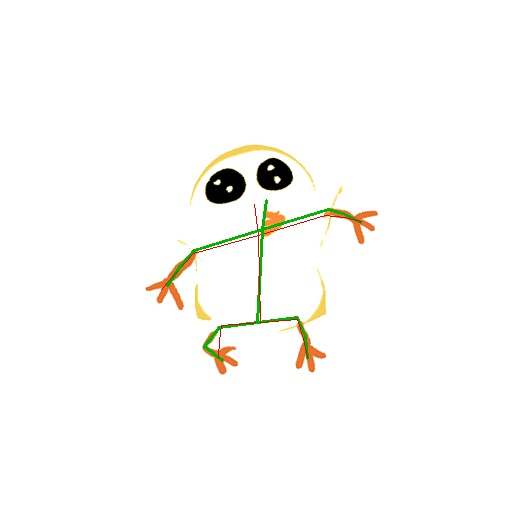

KakaoTalk_20261113_171159582_06__bvh_stand_still__0_t24.jpg


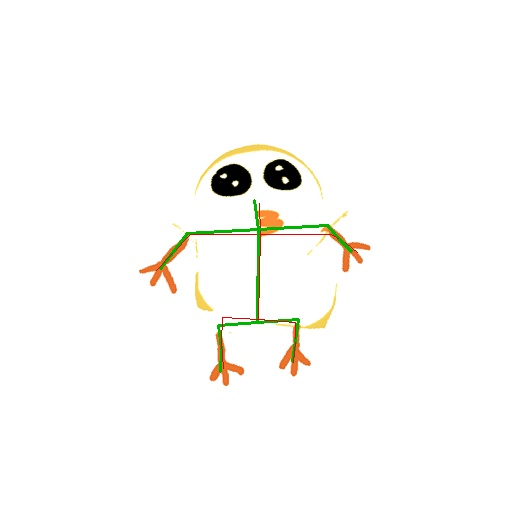

KakaoTalk_20261113_171159582_06__bvh_swim__0_t44.jpg


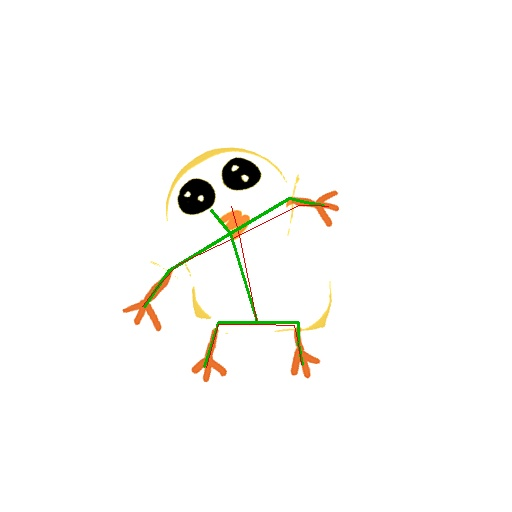

KakaoTalk_20261113_171159582_06__bvh_very_happy__0_t32.jpg


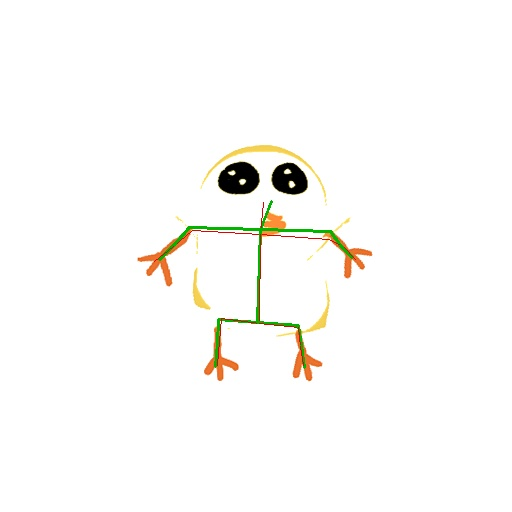

KakaoTalk_20261113_171159582_06__bvh_wave_hello__0_t40.jpg


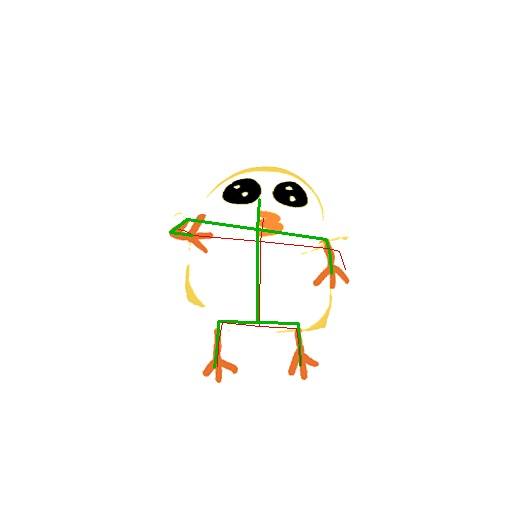

KakaoTalk_20261113_171159582_06__bvh_zombie__0_t28.jpg


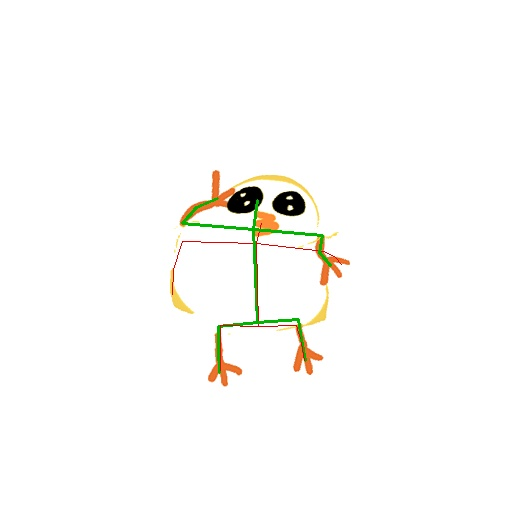

KakaoTalk_20261113_171159582_07__bvh_bird__0_t34.jpg


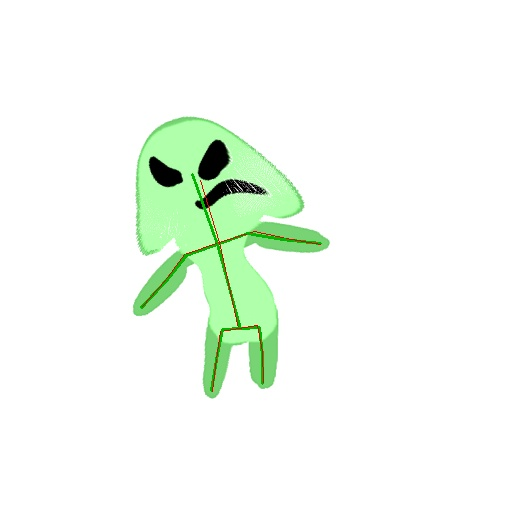

KakaoTalk_20261113_171159582_07__bvh_dab__0_t110.jpg


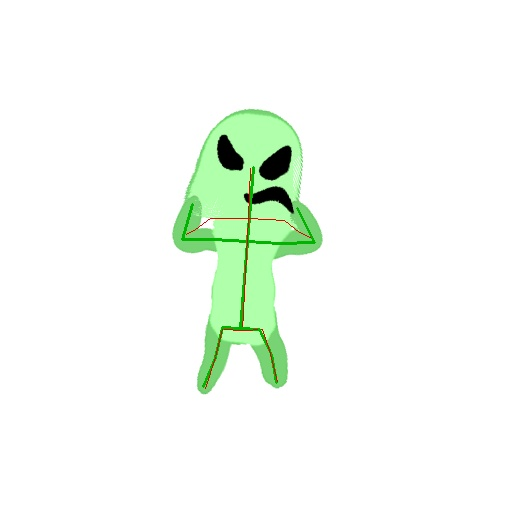

KakaoTalk_20261113_171159582_07__bvh_elephant__0_t8.jpg


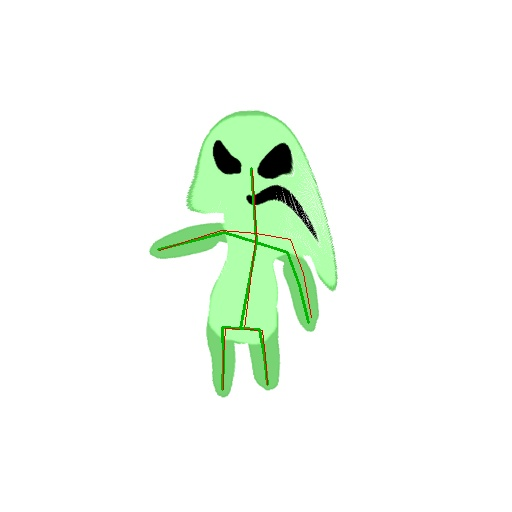

KakaoTalk_20261113_171159582_07__bvh_happy_walk__0_t28.jpg


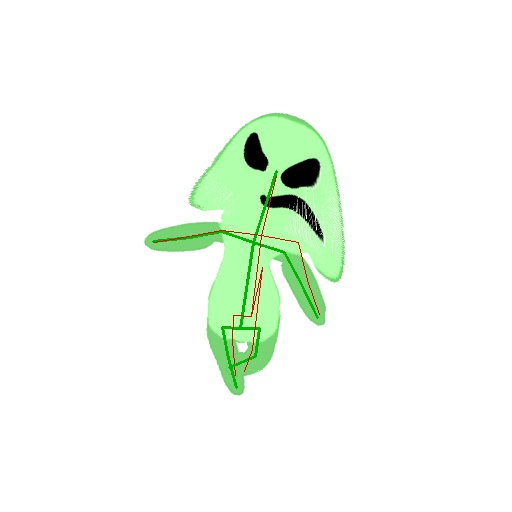

KakaoTalk_20261113_171159582_07__bvh_idle__0_t32.jpg


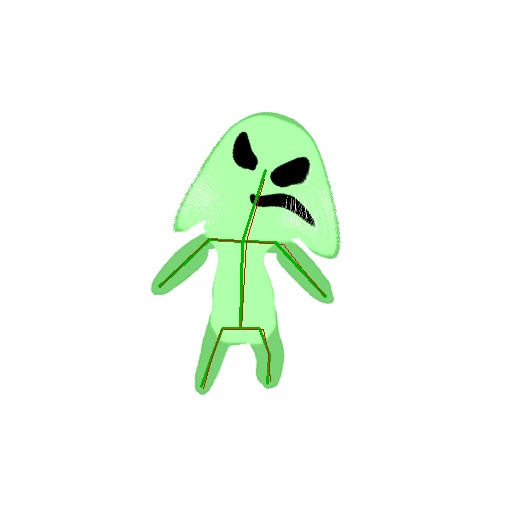

KakaoTalk_20261113_171159582_07__bvh_jesse_dance__0_t130.jpg


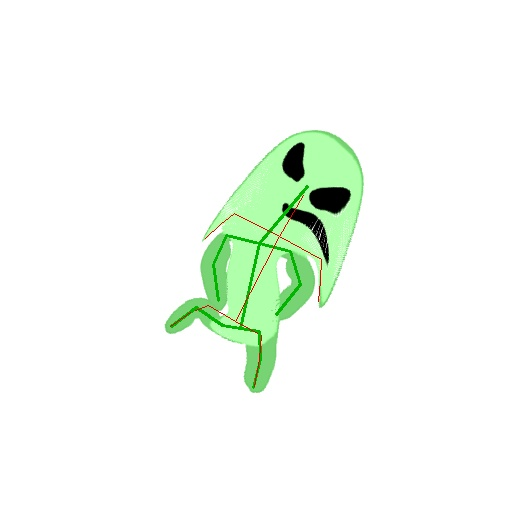

KakaoTalk_20261113_171159582_07__bvh_jumping__0_t24.jpg


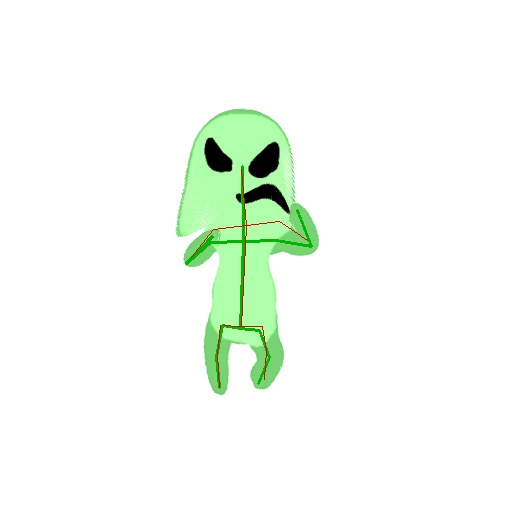

KakaoTalk_20261113_171159582_07__bvh_jumping_jacks__0_t60.jpg


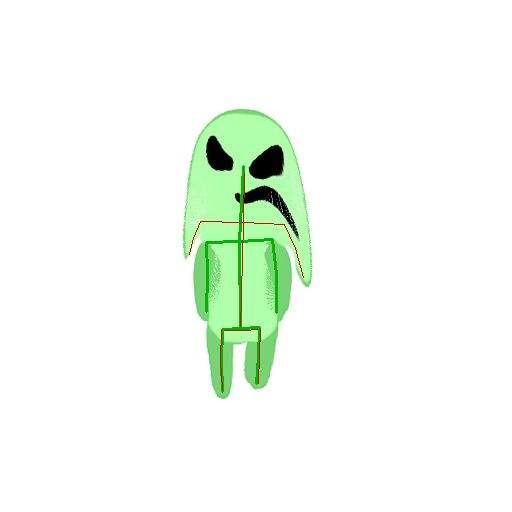

KakaoTalk_20261113_171159582_07__bvh_kick_ball__0_t48.jpg


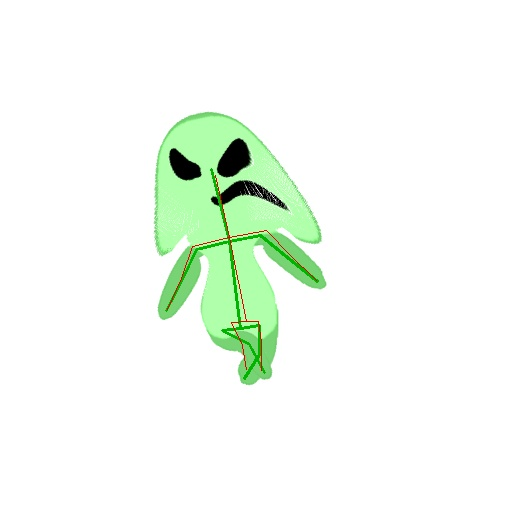

KakaoTalk_20261113_171159582_07__bvh_laugh__0_t16.jpg


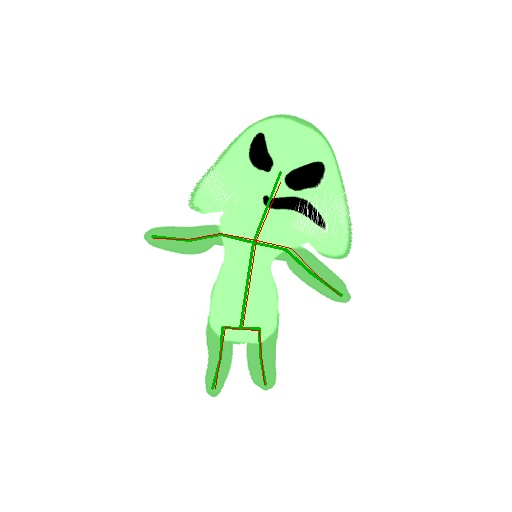

KakaoTalk_20261113_171159582_07__bvh_march__0_t26.jpg


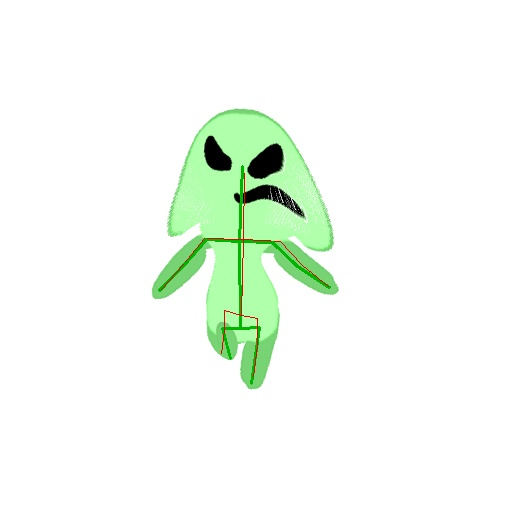

KakaoTalk_20261113_171159582_07__bvh_monkey__0_t8.jpg


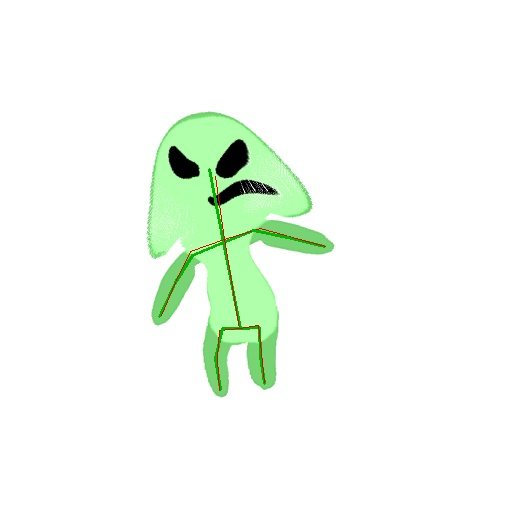

KakaoTalk_20261113_171159582_07__bvh_point__0_t14.jpg


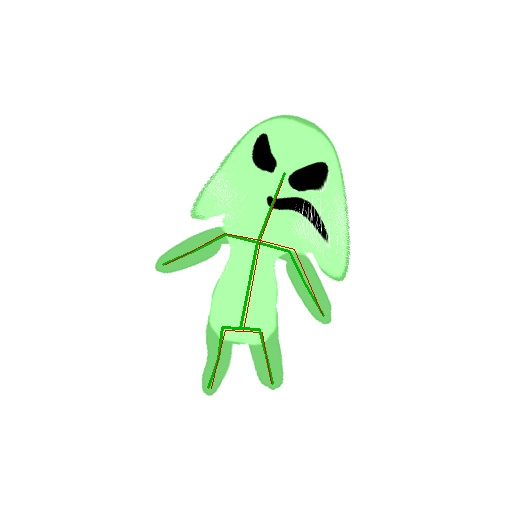

KakaoTalk_20261113_171159582_07__bvh_reach_tiptoe__0_t18.jpg


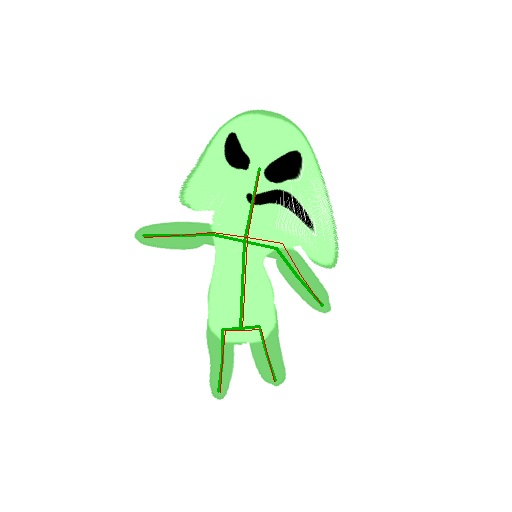

KakaoTalk_20261113_171159582_07__bvh_sad_walk__0_t6.jpg


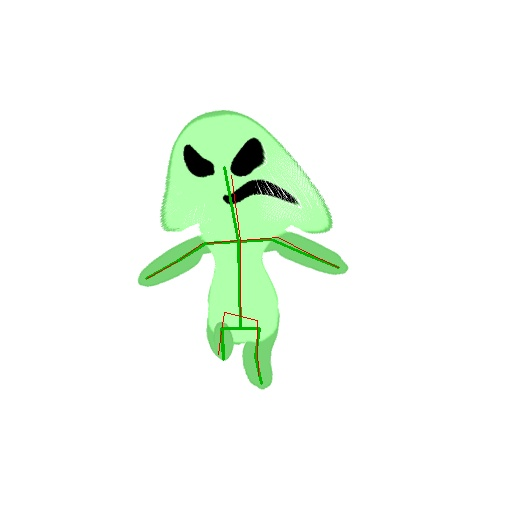

KakaoTalk_20261113_171159582_07__bvh_search_ground__0_t40.jpg


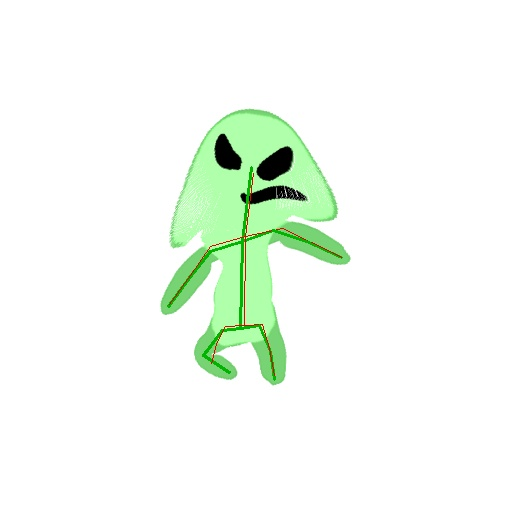

KakaoTalk_20261113_171159582_07__bvh_stand_still__0_t4.jpg


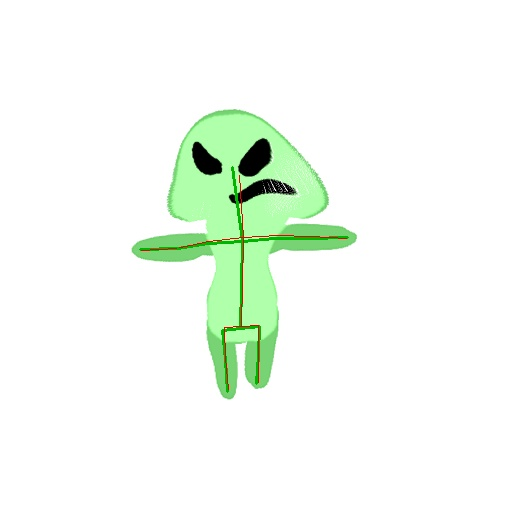

KakaoTalk_20261113_171159582_07__bvh_swim__0_t36.jpg


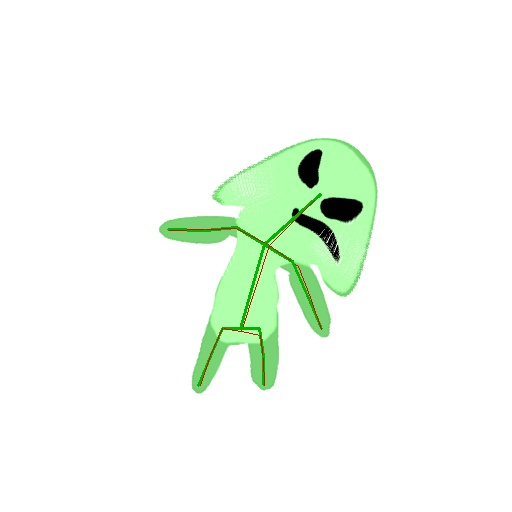

KakaoTalk_20261113_171159582_07__bvh_very_happy__0_t32.jpg


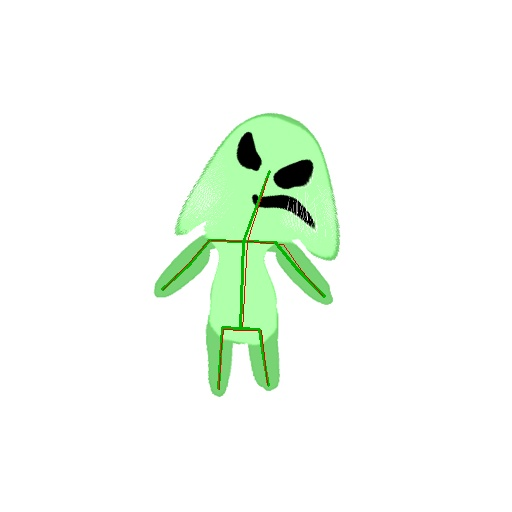

KakaoTalk_20261113_171159582_07__bvh_wave_hello__0_t32.jpg


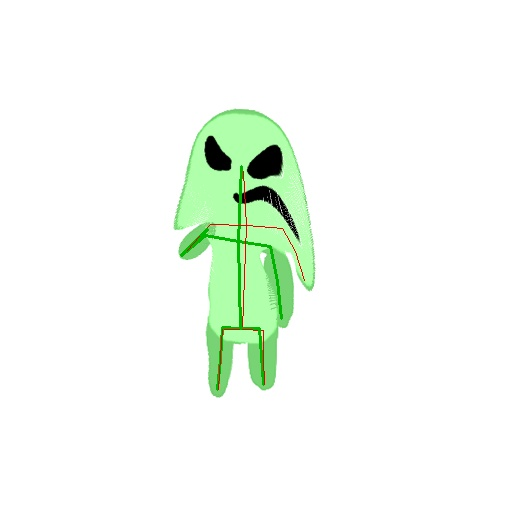

KakaoTalk_20261113_171159582_07__bvh_zombie__0_t48.jpg


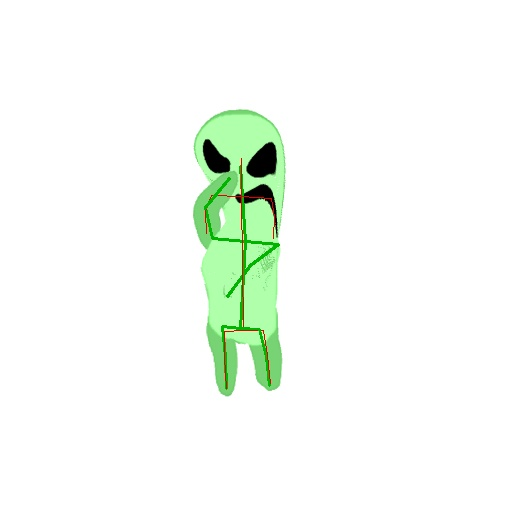

KakaoTalk_20261113_171159582_08__bvh_bird__0_t36.jpg


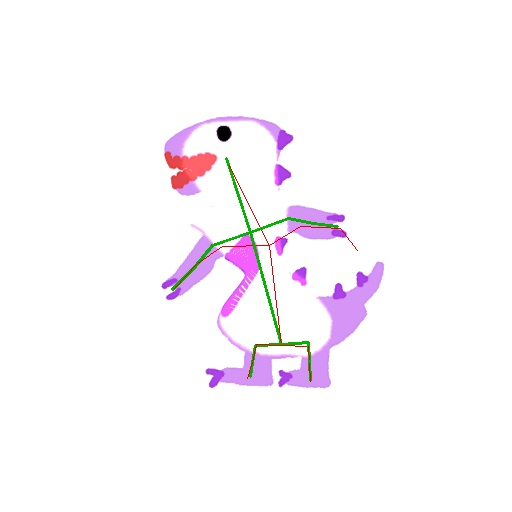

KakaoTalk_20261113_171159582_08__bvh_dab__0_t82.jpg


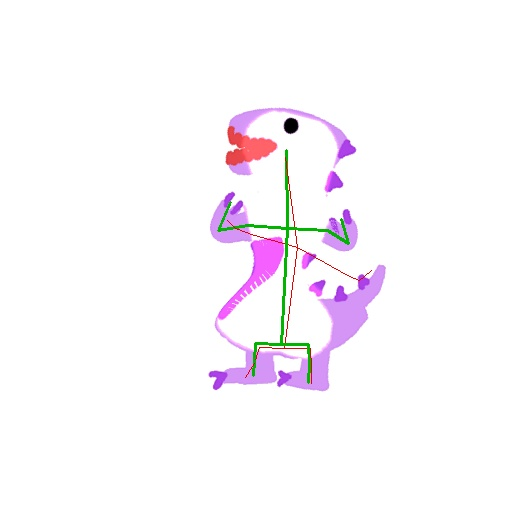

KakaoTalk_20261113_171159582_08__bvh_elephant__0_t36.jpg


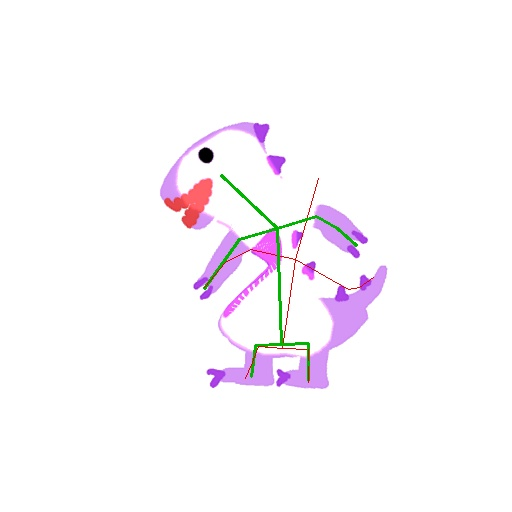

KakaoTalk_20261113_171159582_08__bvh_happy_walk__0_t52.jpg


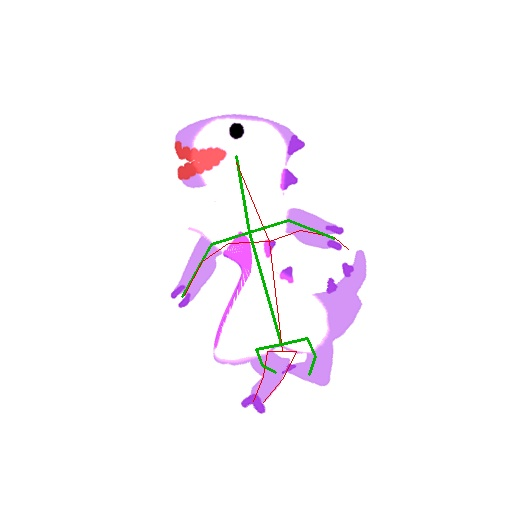

KakaoTalk_20261113_171159582_08__bvh_idle__0_t32.jpg


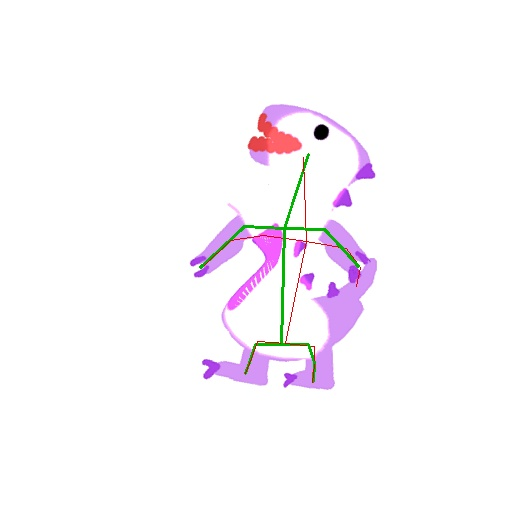

KakaoTalk_20261113_171159582_08__bvh_jesse_dance__0_t46.jpg


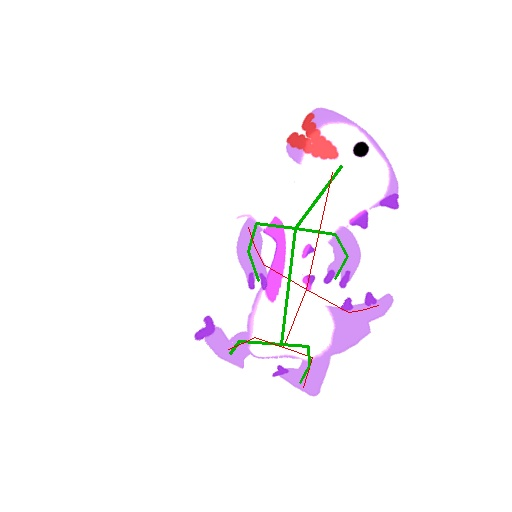

KakaoTalk_20261113_171159582_08__bvh_jumping__0_t24.jpg


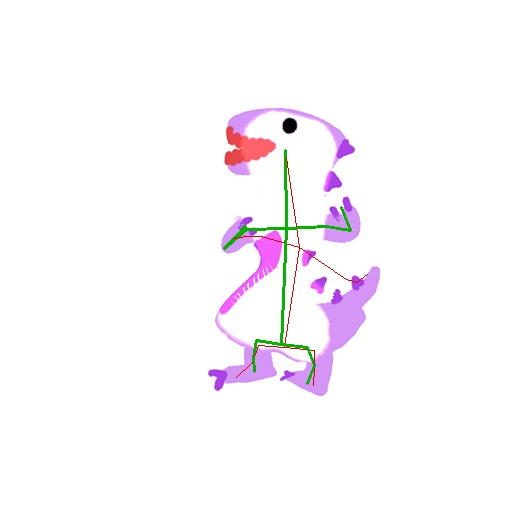

KakaoTalk_20261113_171159582_08__bvh_jumping_jacks__0_t60.jpg


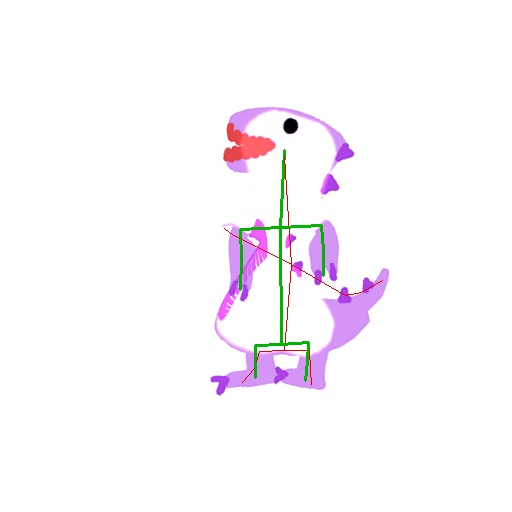

KakaoTalk_20261113_171159582_08__bvh_kick_ball__0_t48.jpg


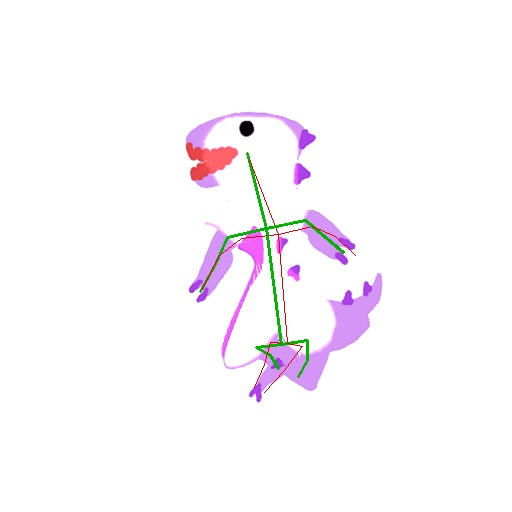

KakaoTalk_20261113_171159582_08__bvh_laugh__0_t50.jpg


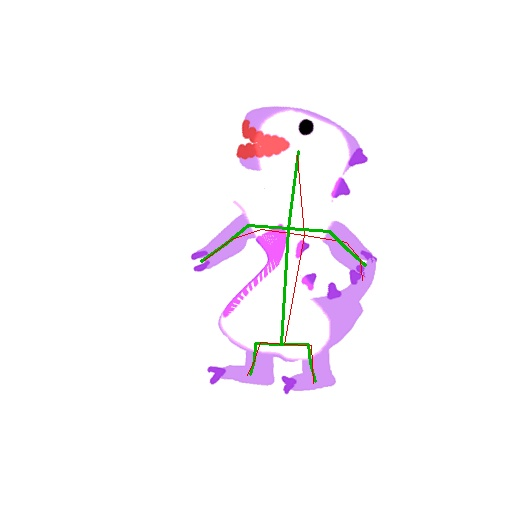

KakaoTalk_20261113_171159582_08__bvh_march__0_t22.jpg


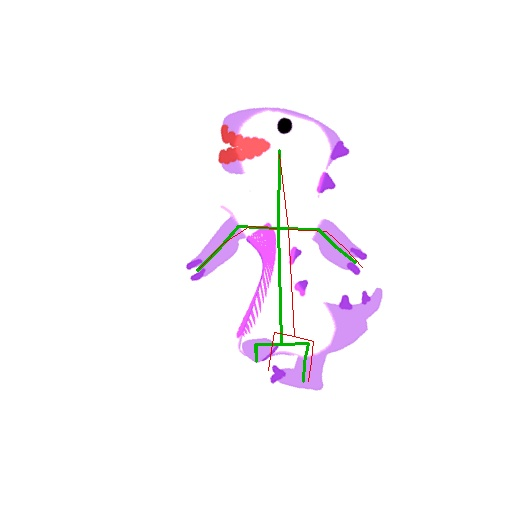

KakaoTalk_20261113_171159582_08__bvh_monkey__0_t10.jpg


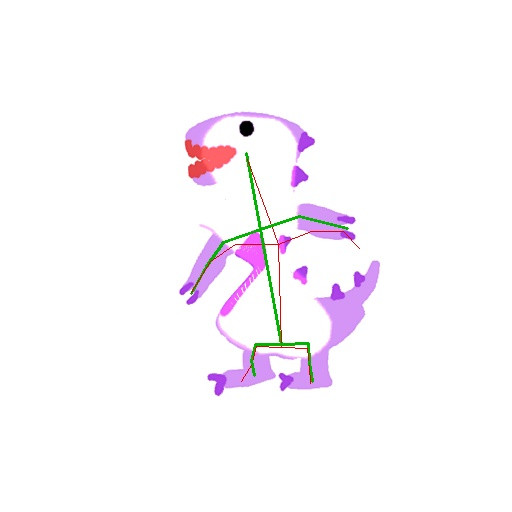

KakaoTalk_20261113_171159582_08__bvh_point__0_t12.jpg


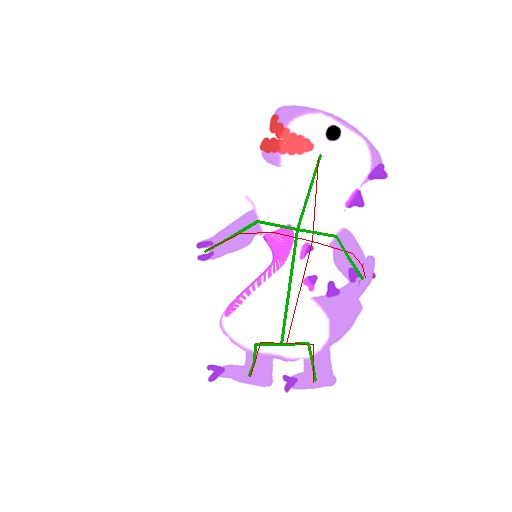

KakaoTalk_20261113_171159582_08__bvh_reach_tiptoe__0_t20.jpg


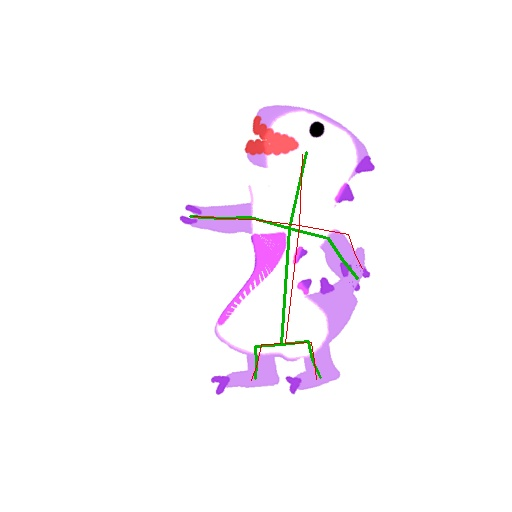

KakaoTalk_20261113_171159582_08__bvh_sad_walk__0_t8.jpg


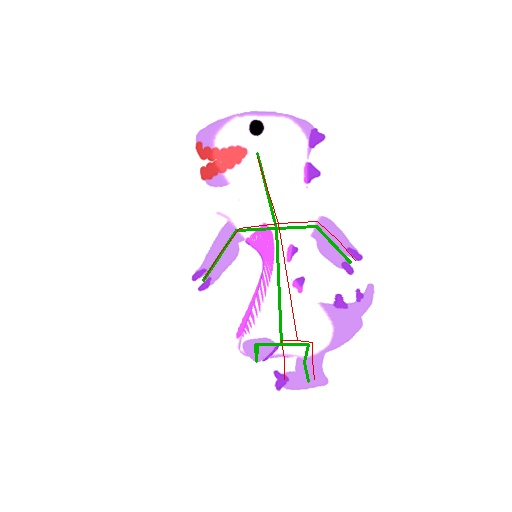

KakaoTalk_20261113_171159582_08__bvh_search_ground__0_t26.jpg


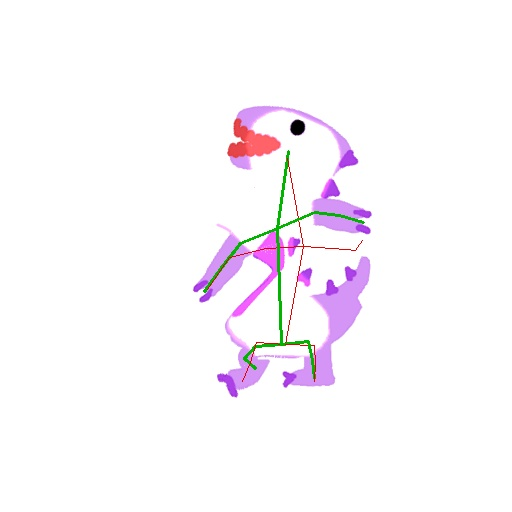

KakaoTalk_20261113_171159582_08__bvh_stand_still__0_t28.jpg


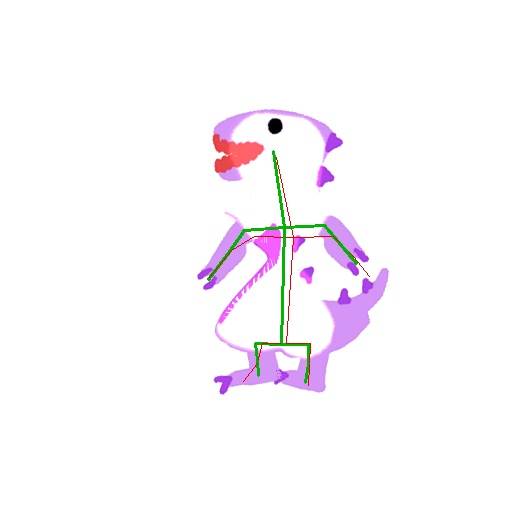

KakaoTalk_20261113_171159582_08__bvh_swim__0_t26.jpg


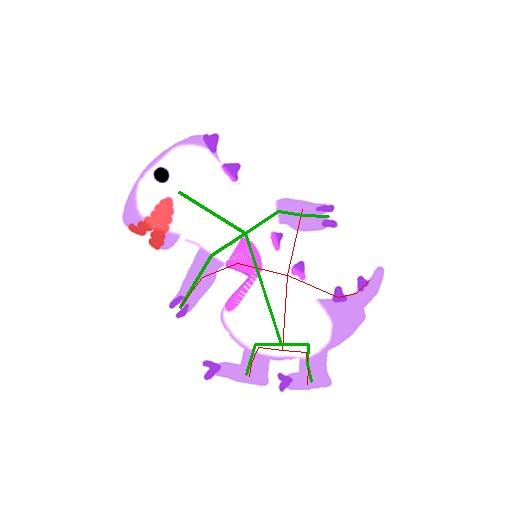

KakaoTalk_20261113_171159582_08__bvh_very_happy__0_t18.jpg


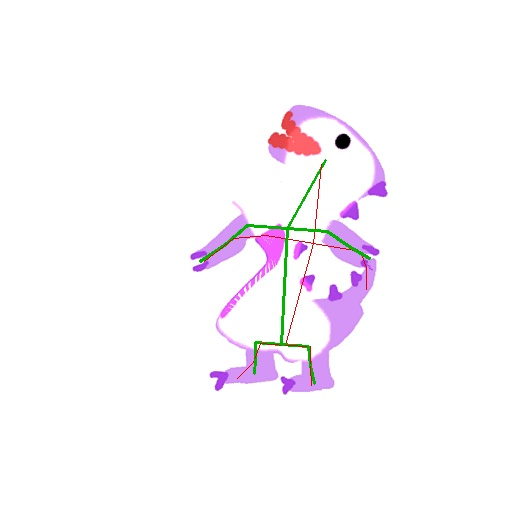

KakaoTalk_20261113_171159582_08__bvh_wave_hello__0_t42.jpg


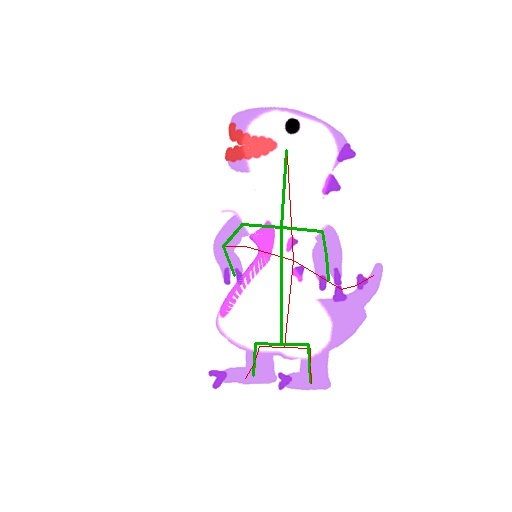

KakaoTalk_20261113_171159582_08__bvh_zombie__0_t32.jpg


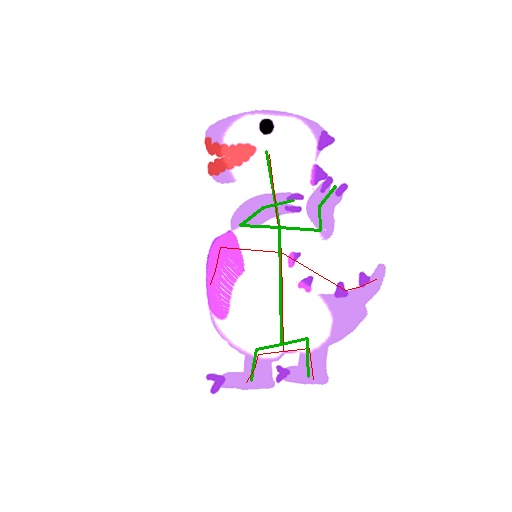

KakaoTalk_20261113_171159582_09__bvh_bird__0_t36.jpg


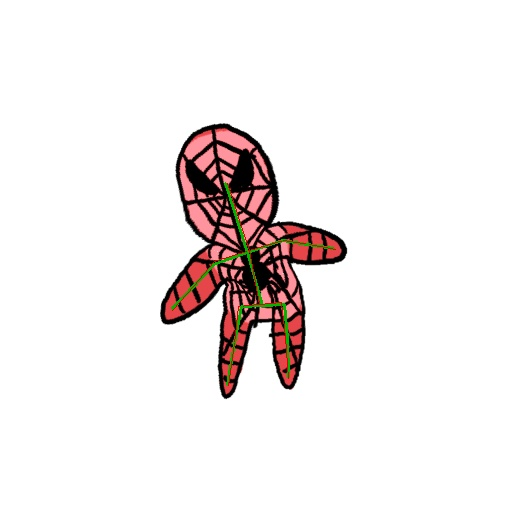

KakaoTalk_20261113_171159582_09__bvh_dab__0_t118.jpg


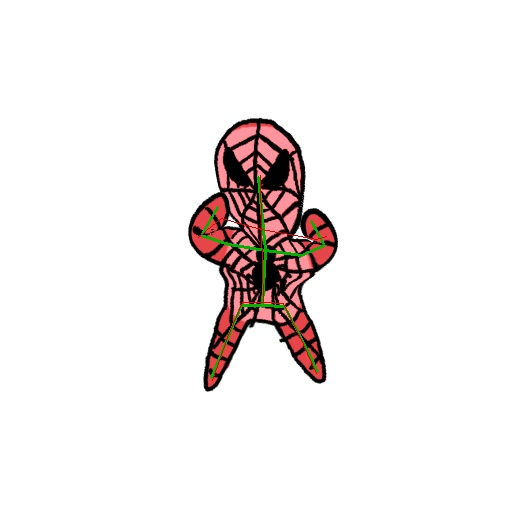

KakaoTalk_20261113_171159582_09__bvh_elephant__0_t40.jpg


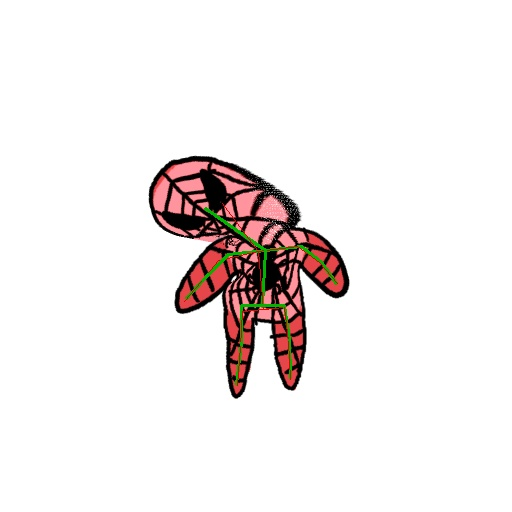

KakaoTalk_20261113_171159582_09__bvh_happy_walk__0_t28.jpg


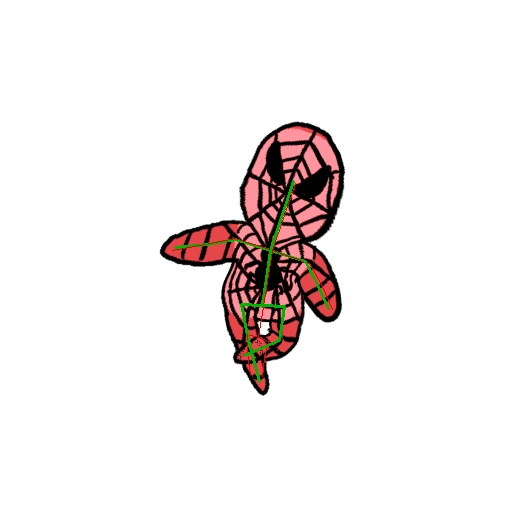

KakaoTalk_20261113_171159582_09__bvh_idle__0_t38.jpg


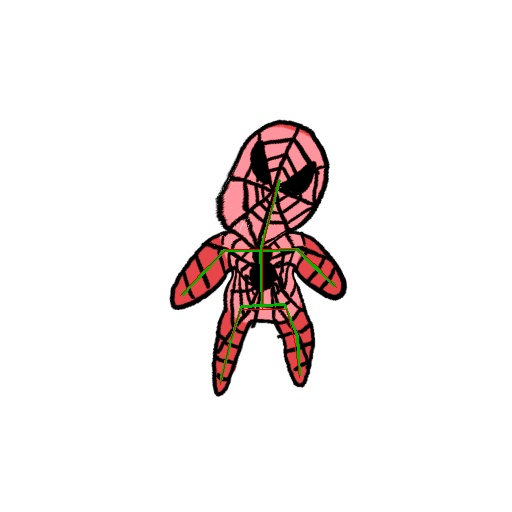

KakaoTalk_20261113_171159582_09__bvh_jesse_dance__0_t130.jpg


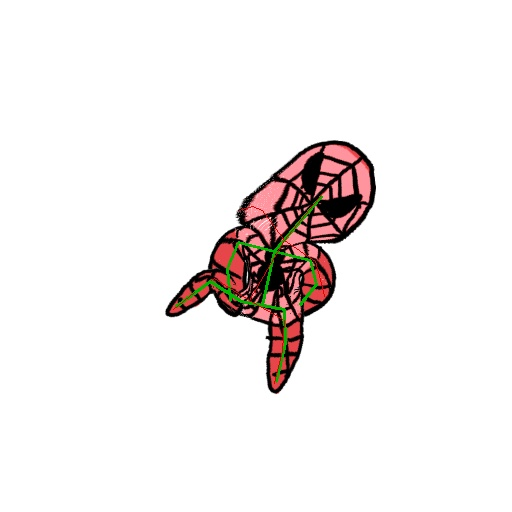

KakaoTalk_20261113_171159582_09__bvh_jumping__0_t24.jpg


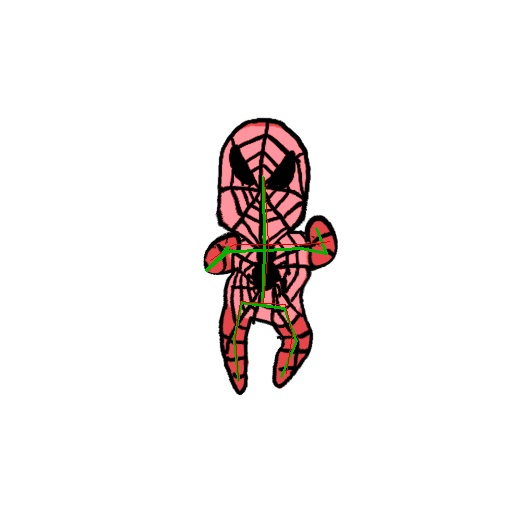

KakaoTalk_20261113_171159582_09__bvh_jumping_jacks__0_t16.jpg


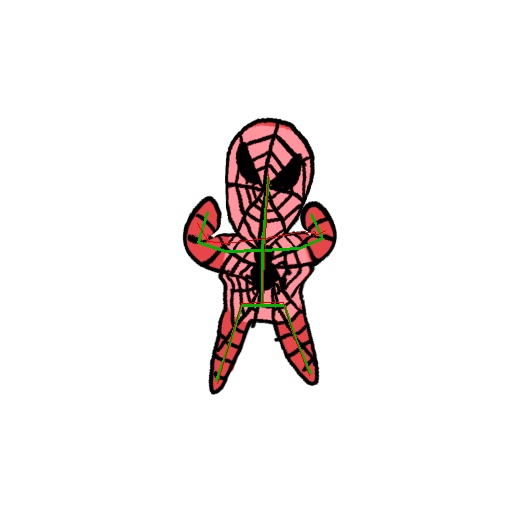

KakaoTalk_20261113_171159582_09__bvh_kick_ball__0_t48.jpg


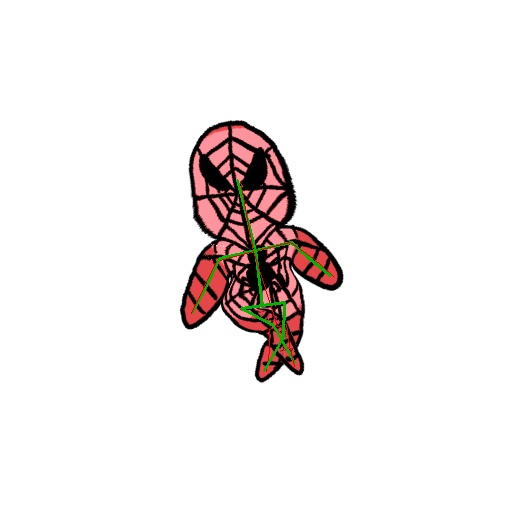

KakaoTalk_20261113_171159582_09__bvh_laugh__0_t24.jpg


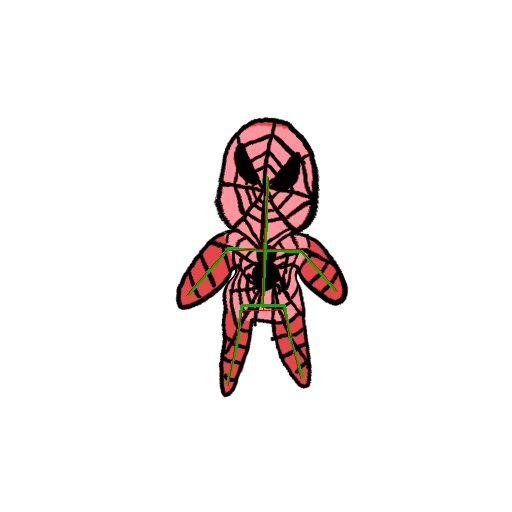

KakaoTalk_20261113_171159582_09__bvh_march__0_t34.jpg


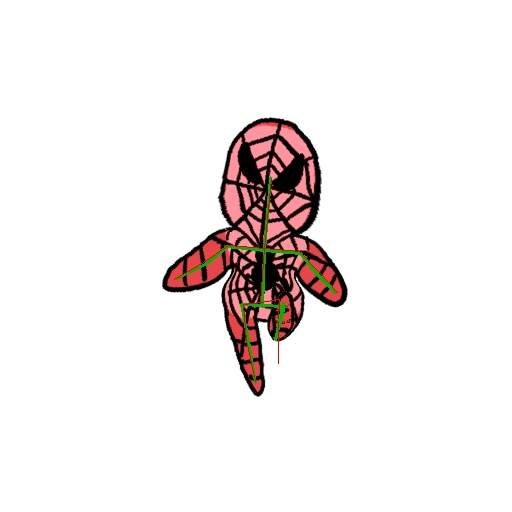

KakaoTalk_20261113_171159582_09__bvh_monkey__0_t8.jpg


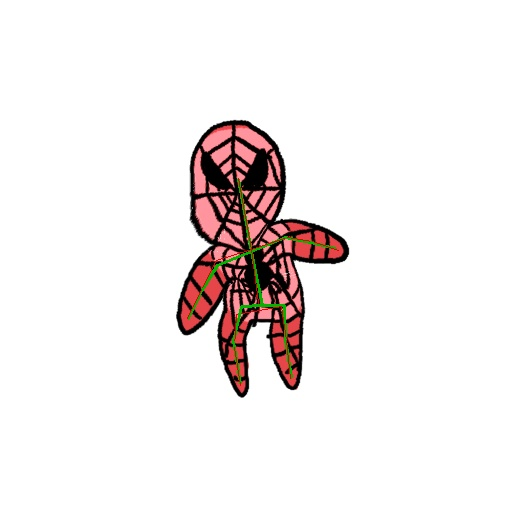

KakaoTalk_20261113_171159582_09__bvh_point__0_t40.jpg


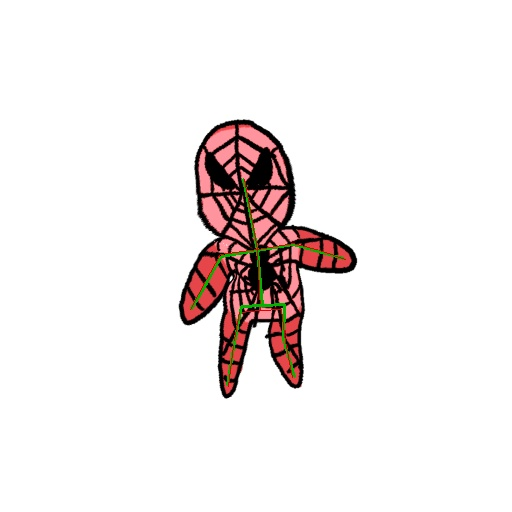

KakaoTalk_20261113_171159582_09__bvh_reach_tiptoe__0_t20.jpg


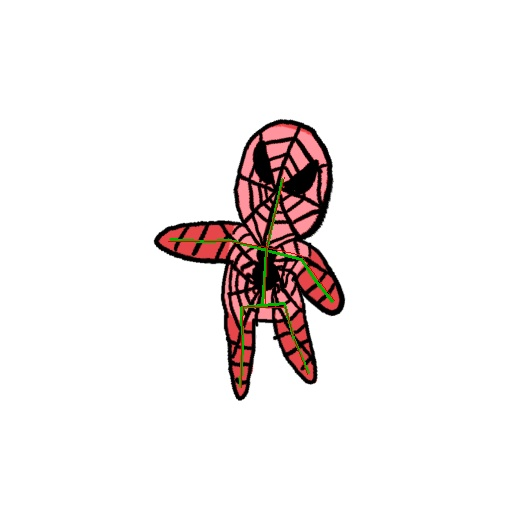

KakaoTalk_20261113_171159582_09__bvh_sad_walk__0_t54.jpg


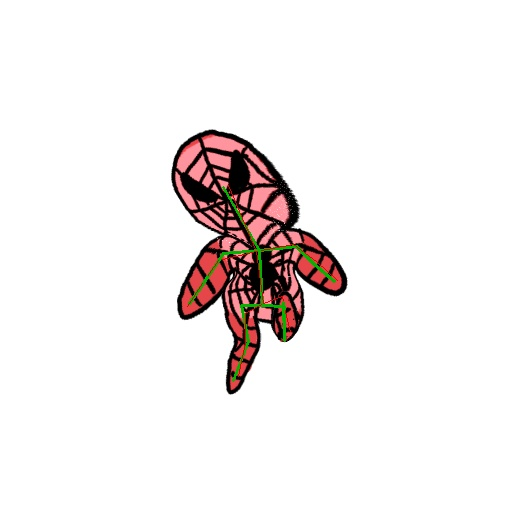

KakaoTalk_20261113_171159582_09__bvh_search_ground__0_t52.jpg


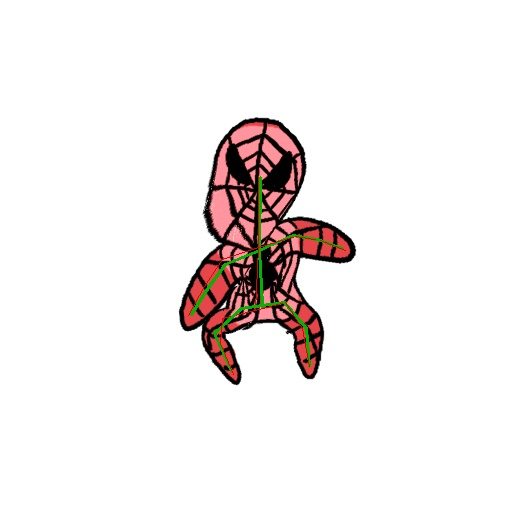

KakaoTalk_20261113_171159582_09__bvh_stand_still__0_t8.jpg


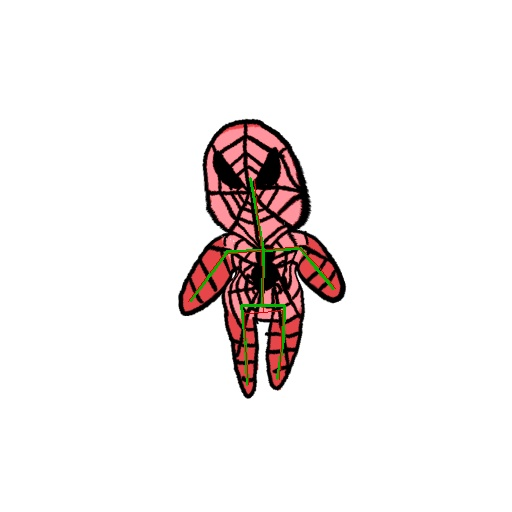

KakaoTalk_20261113_171159582_09__bvh_swim__0_t26.jpg


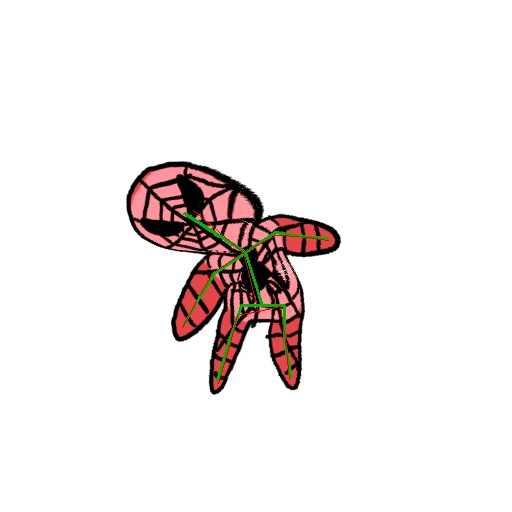

KakaoTalk_20261113_171159582_09__bvh_very_happy__0_t24.jpg


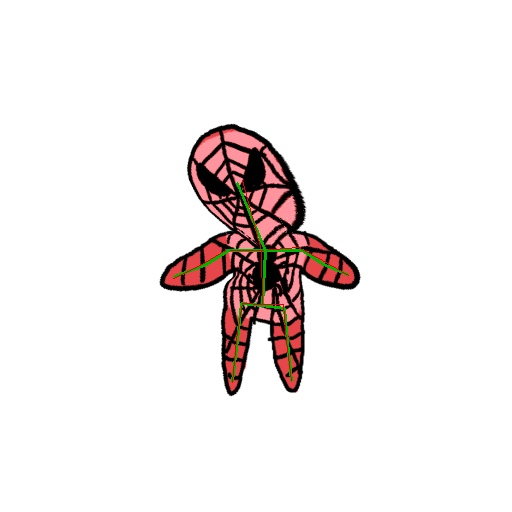

KakaoTalk_20261113_171159582_09__bvh_wave_hello__0_t36.jpg


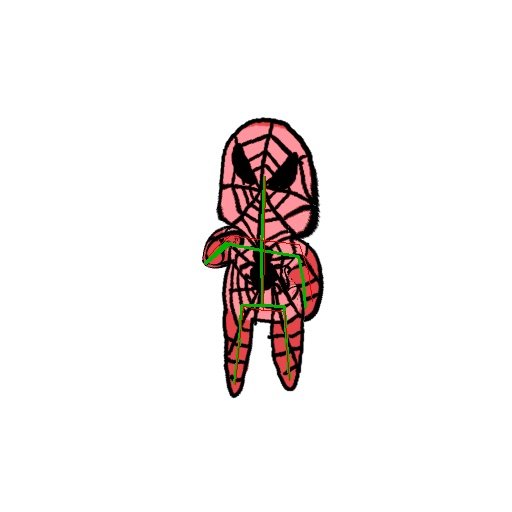

KakaoTalk_20261113_171159582_09__bvh_zombie__0_t22.jpg


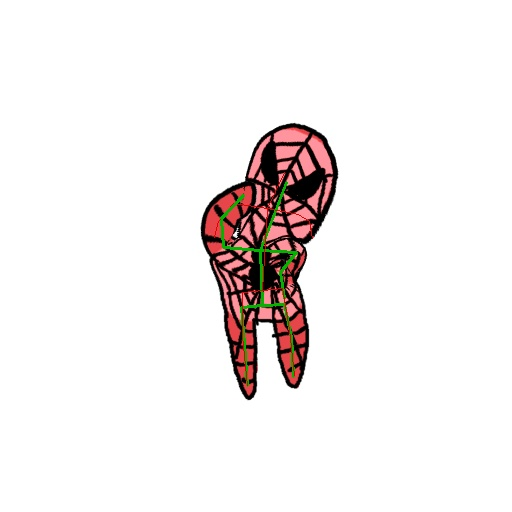

KakaoTalk_20261113_171159582__bvh_bird__0_t36.jpg


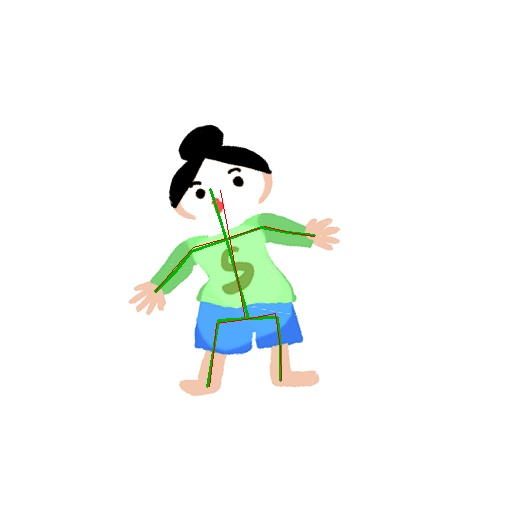

KakaoTalk_20261113_171159582__bvh_dab__0_t106.jpg


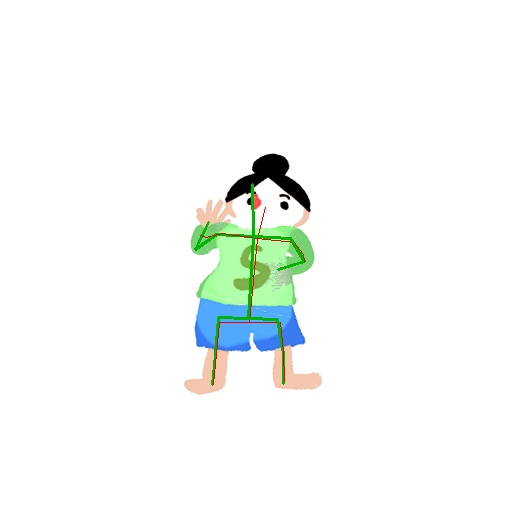

KakaoTalk_20261113_171159582__bvh_elephant__0_t42.jpg


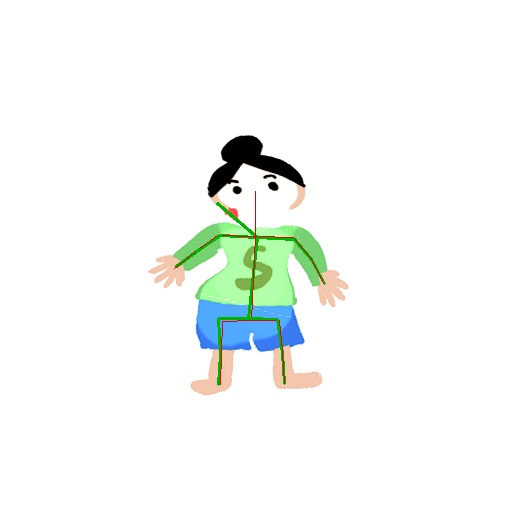

KakaoTalk_20261113_171159582__bvh_happy_walk__0_t8.jpg


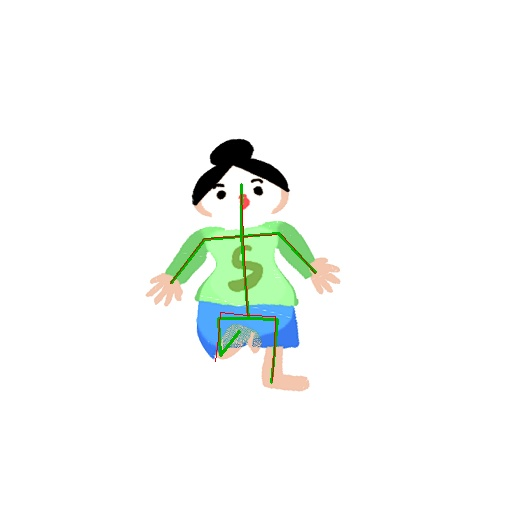

KakaoTalk_20261113_171159582__bvh_idle__0_t34.jpg


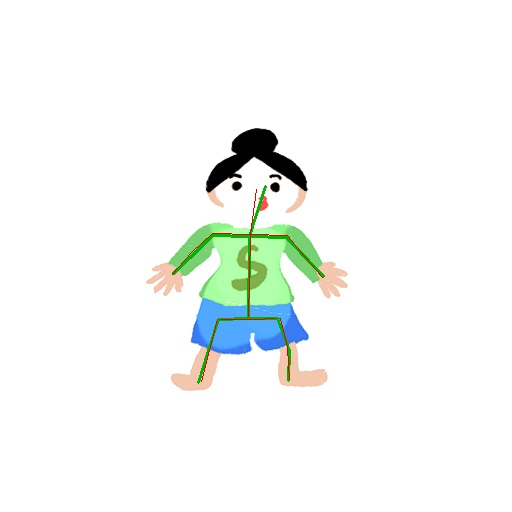

KakaoTalk_20261113_171159582__bvh_jesse_dance__0_t30.jpg


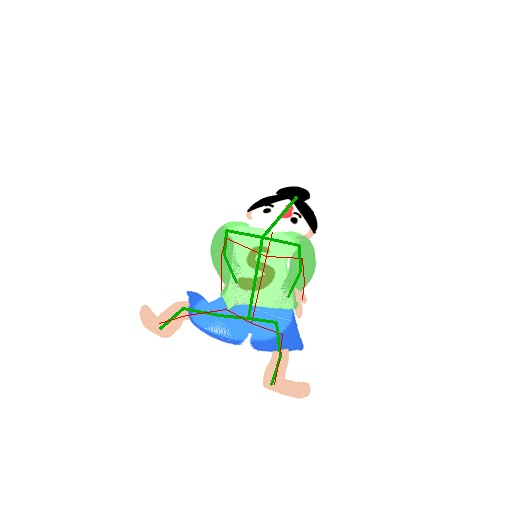

KakaoTalk_20261113_171159582__bvh_jumping__0_t24.jpg


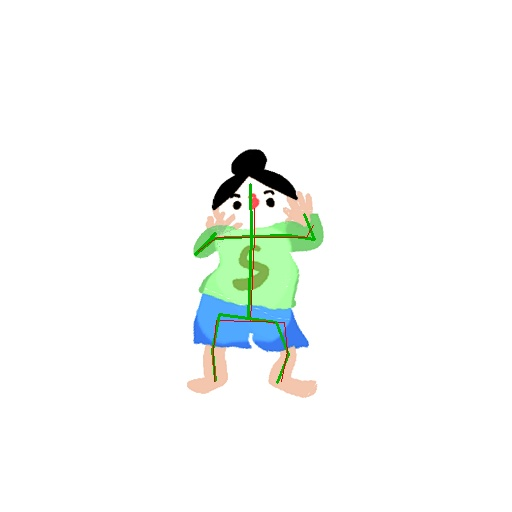

KakaoTalk_20261113_171159582__bvh_jumping_jacks__0_t58.jpg


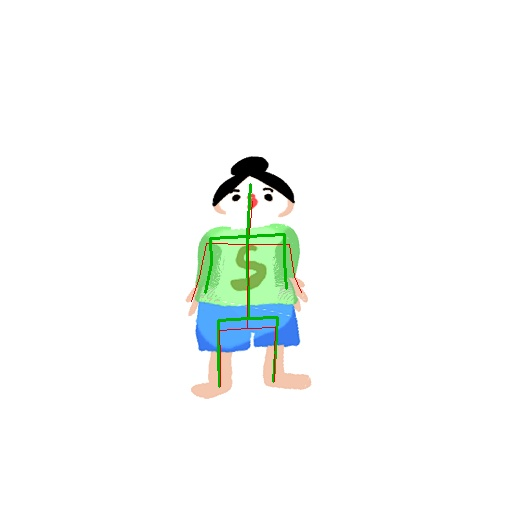

KakaoTalk_20261113_171159582__bvh_kick_ball__0_t48.jpg


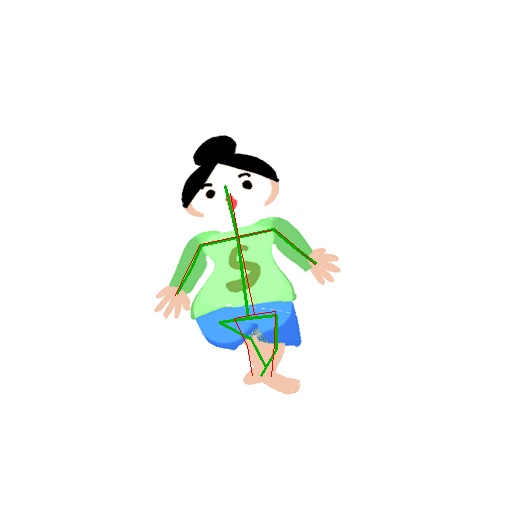

KakaoTalk_20261113_171159582__bvh_laugh__0_t26.jpg


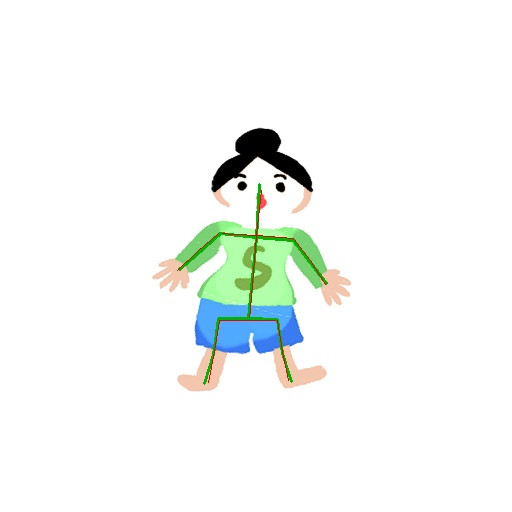

KakaoTalk_20261113_171159582__bvh_march__0_t26.jpg


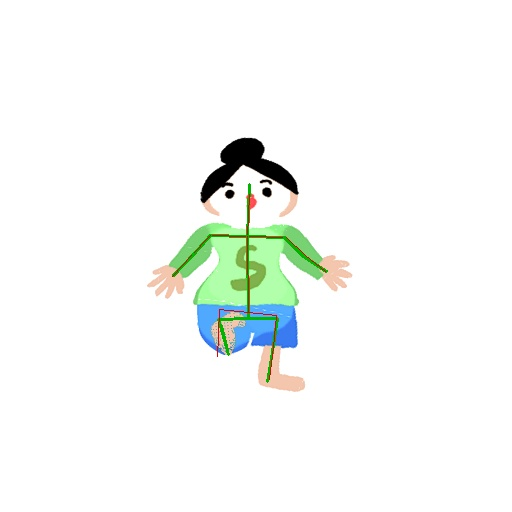

KakaoTalk_20261113_171159582__bvh_monkey__0_t54.jpg


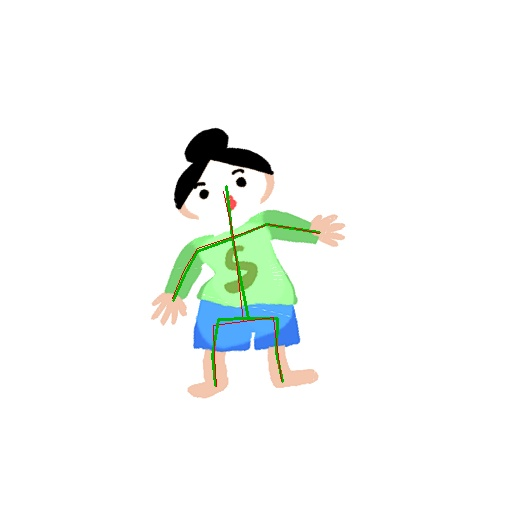

KakaoTalk_20261113_171159582__bvh_point__0_t14.jpg


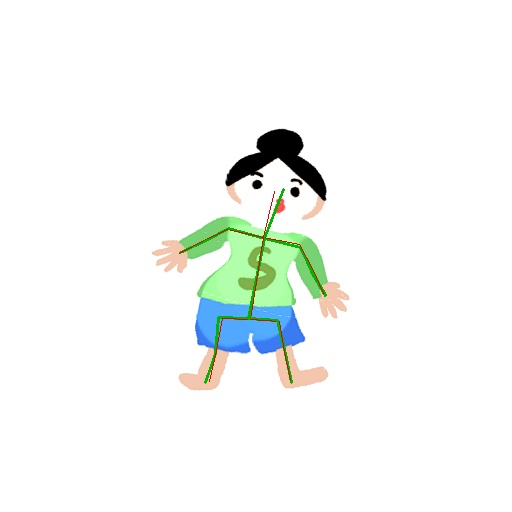

KakaoTalk_20261113_171159582__bvh_reach_tiptoe__0_t34.jpg


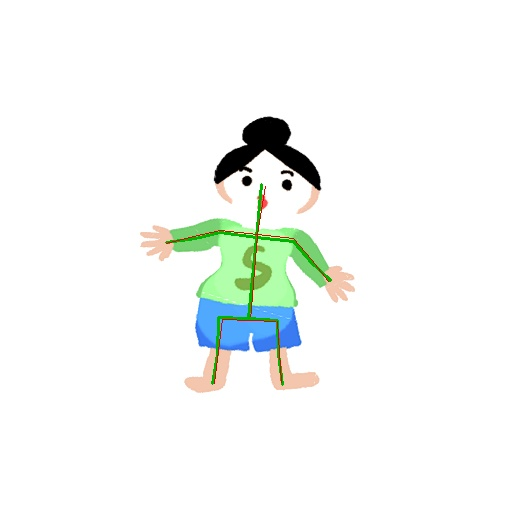

KakaoTalk_20261113_171159582__bvh_sad_walk__0_t54.jpg


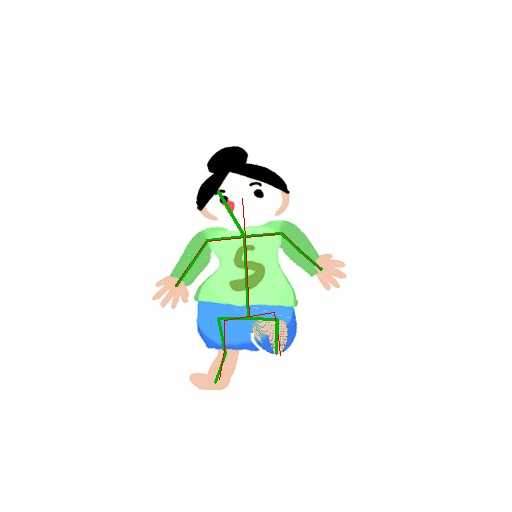

KakaoTalk_20261113_171159582__bvh_search_ground__0_t24.jpg


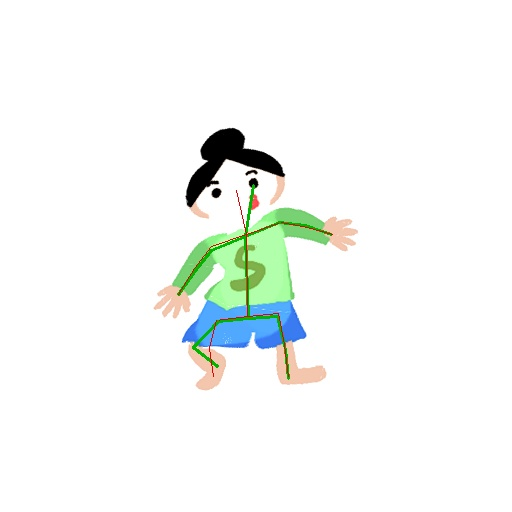

KakaoTalk_20261113_171159582__bvh_stand_still__0_t26.jpg


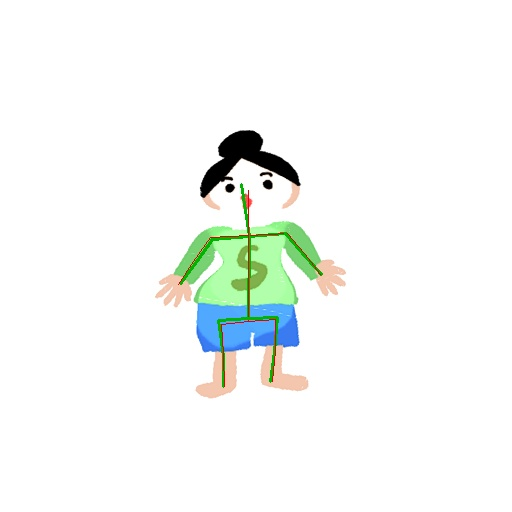

KakaoTalk_20261113_171159582__bvh_swim__0_t26.jpg


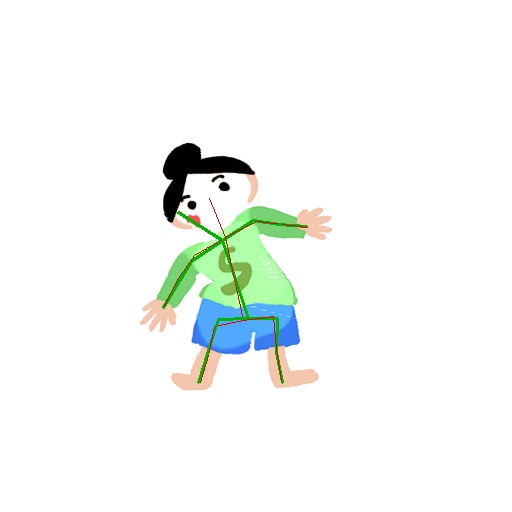

KakaoTalk_20261113_171159582__bvh_very_happy__0_t24.jpg


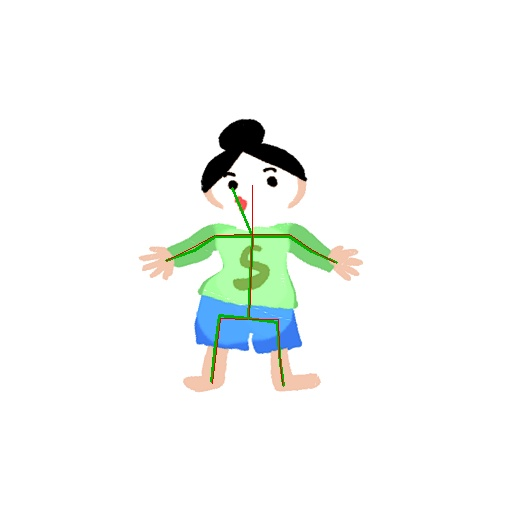

KakaoTalk_20261113_171159582__bvh_wave_hello__0_t34.jpg


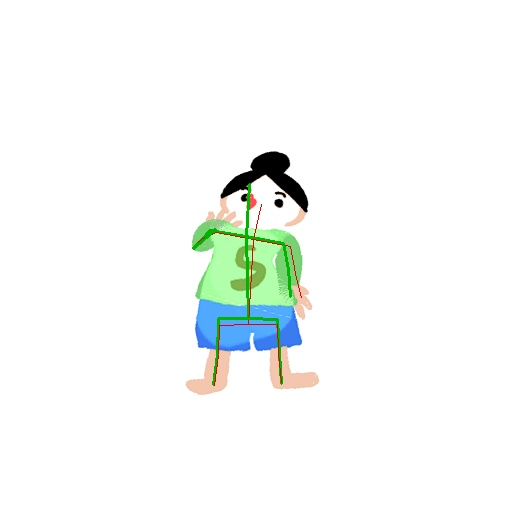

KakaoTalk_20261113_171159582__bvh_zombie__0_t38.jpg


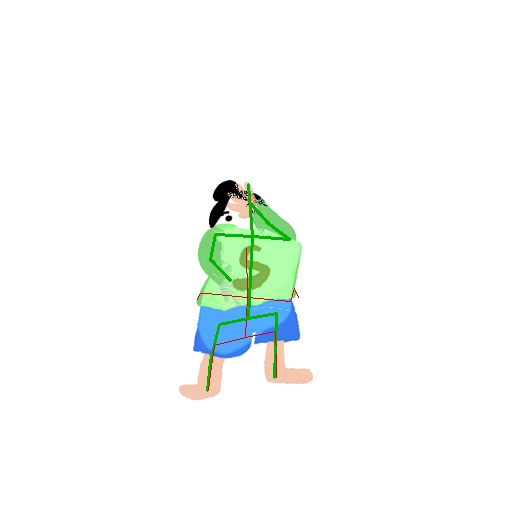

p10__bvh_bird__0_t34.jpg


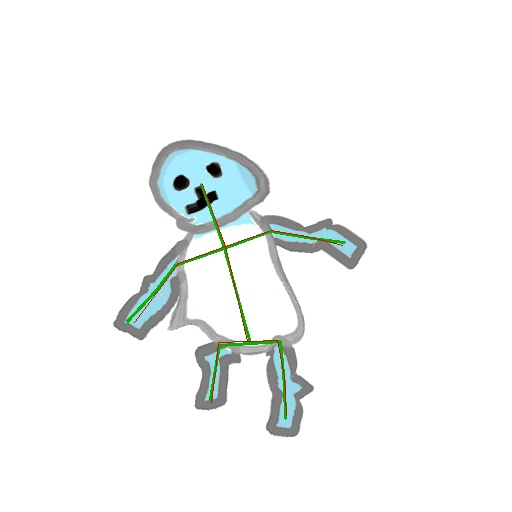

p10__bvh_dab__0_t98.jpg


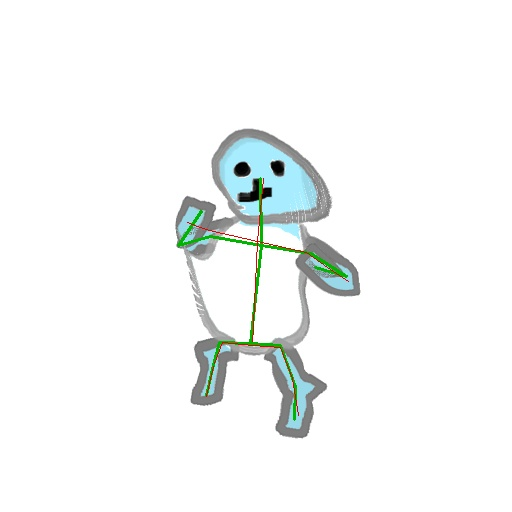

p10__bvh_elephant__0_t42.jpg


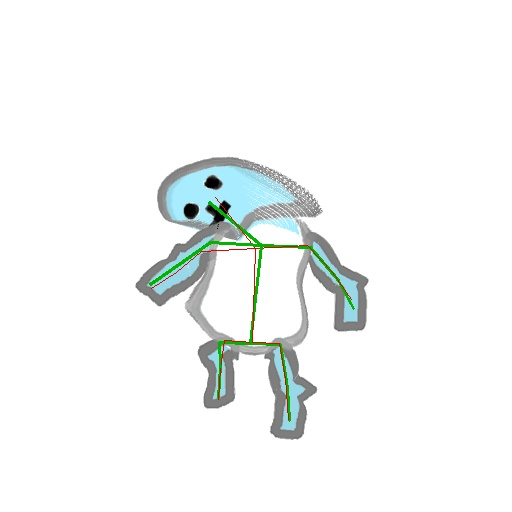

p10__bvh_happy_walk__0_t50.jpg


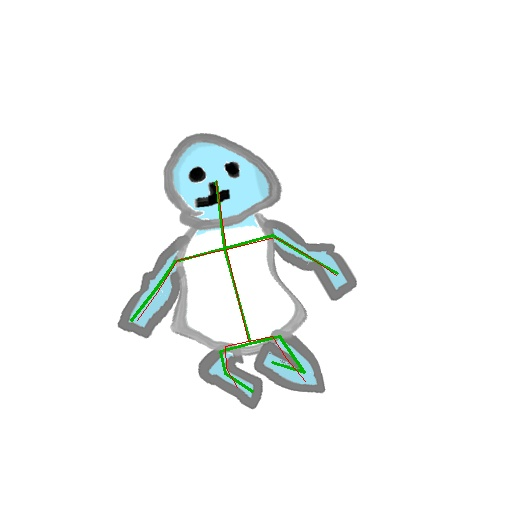

p10__bvh_idle__0_t14.jpg


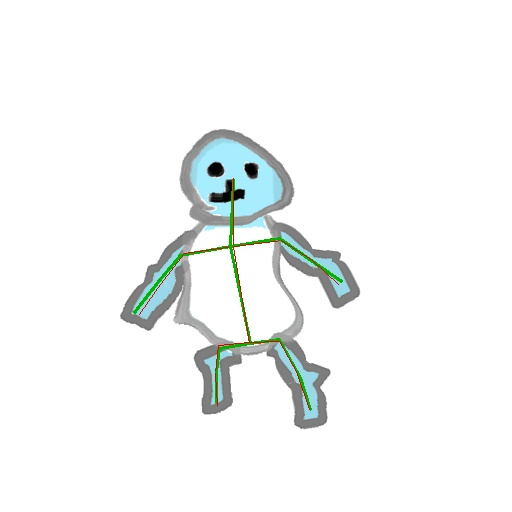

p10__bvh_jesse_dance__0_t10.jpg


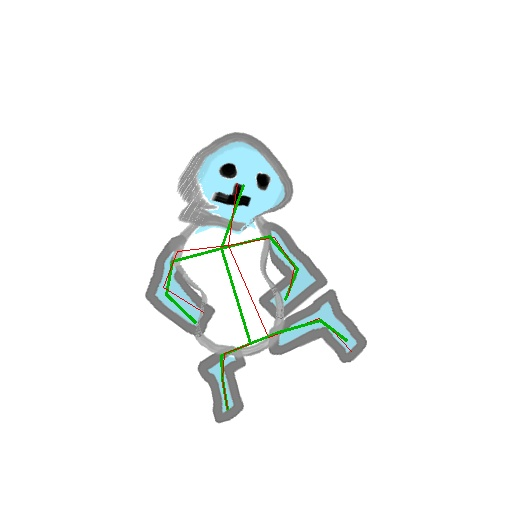

p10__bvh_jumping__0_t24.jpg


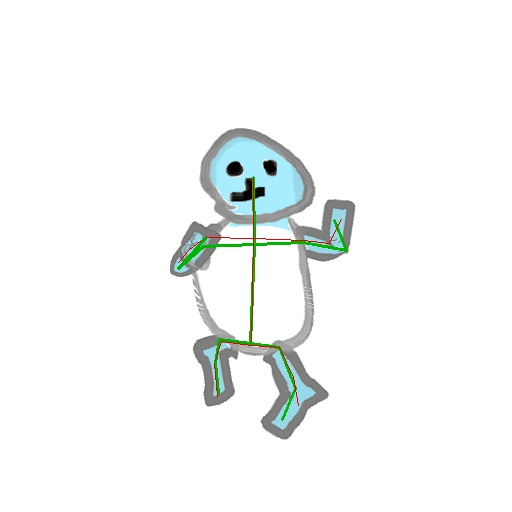

p10__bvh_jumping_jacks__0_t16.jpg


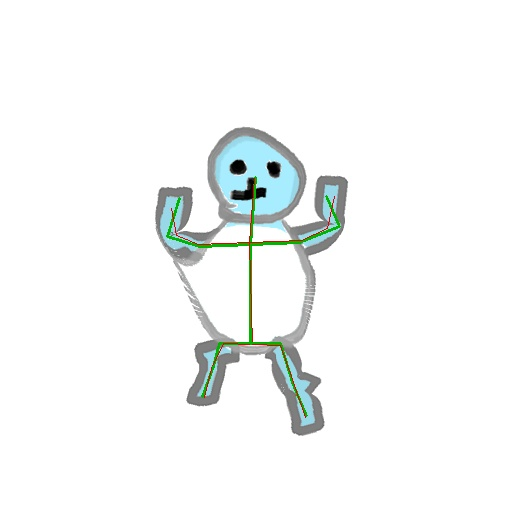

p10__bvh_kick_ball__0_t48.jpg


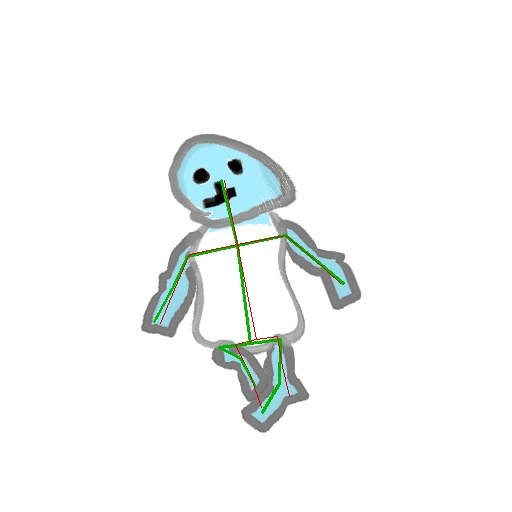

p10__bvh_laugh__0_t32.jpg


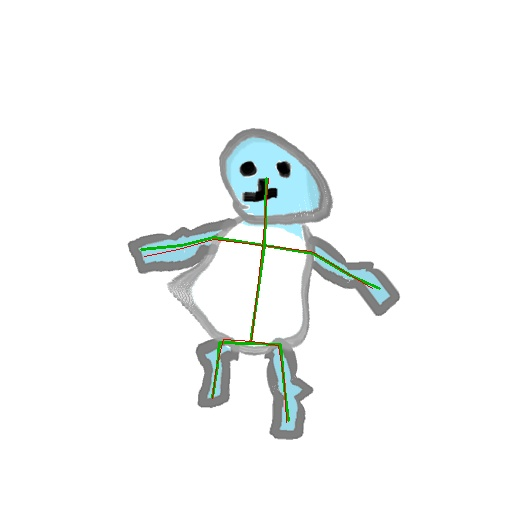

p10__bvh_march__0_t34.jpg


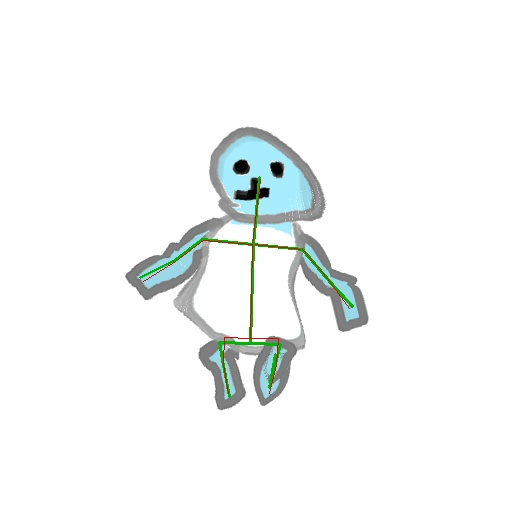

p10__bvh_monkey__0_t8.jpg


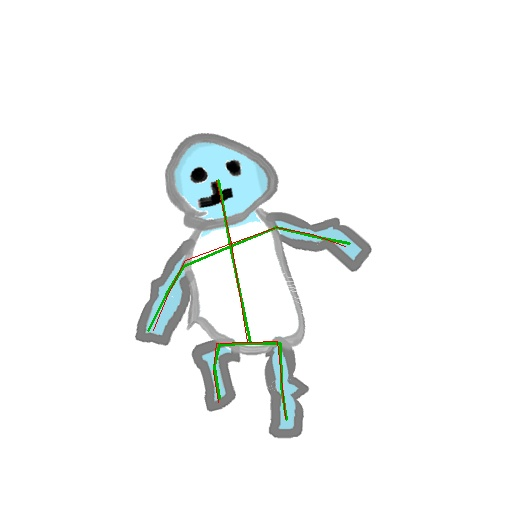

p10__bvh_point__0_t34.jpg


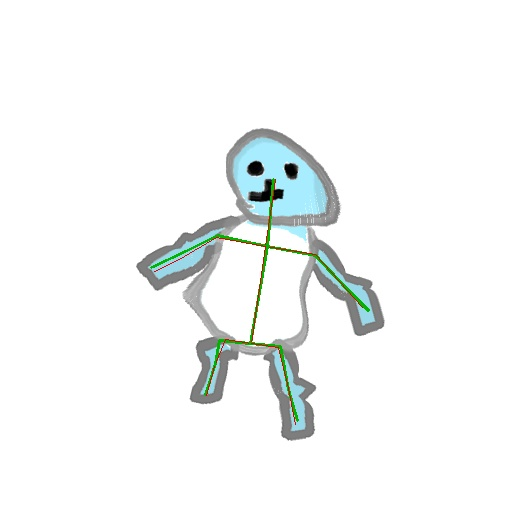

p10__bvh_reach_tiptoe__0_t22.jpg


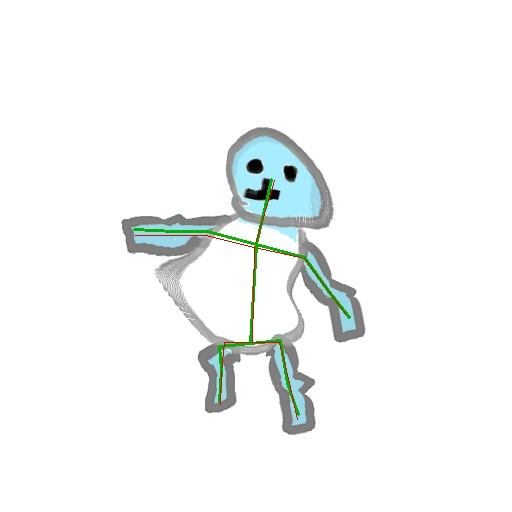

p10__bvh_sad_walk__0_t40.jpg


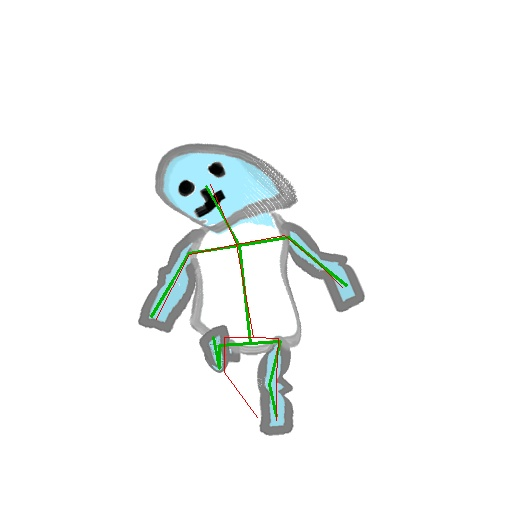

p10__bvh_search_ground__0_t28.jpg


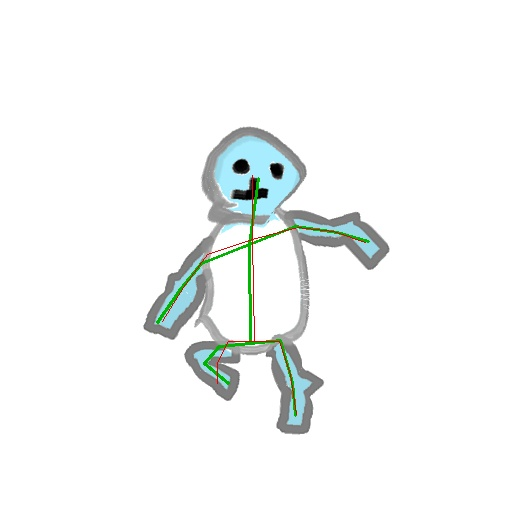

p10__bvh_stand_still__0_t8.jpg


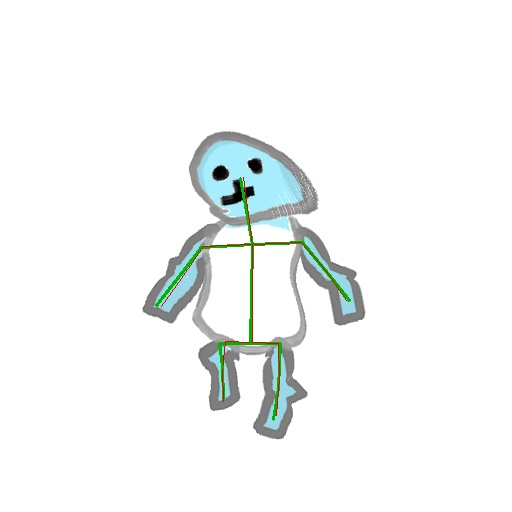

p10__bvh_swim__0_t24.jpg


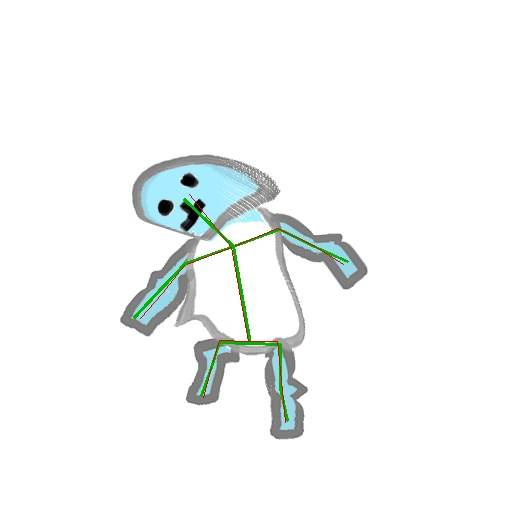

p10__bvh_very_happy__0_t24.jpg


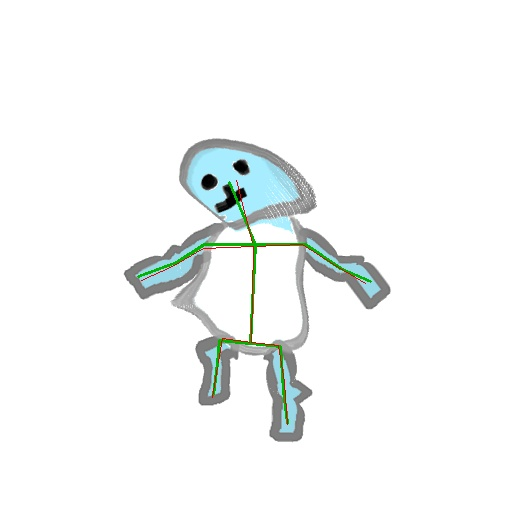

p10__bvh_wave_hello__0_t32.jpg


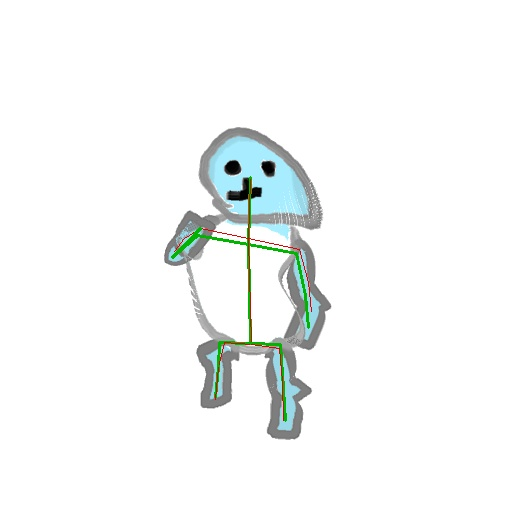

p10__bvh_zombie__0_t60.jpg


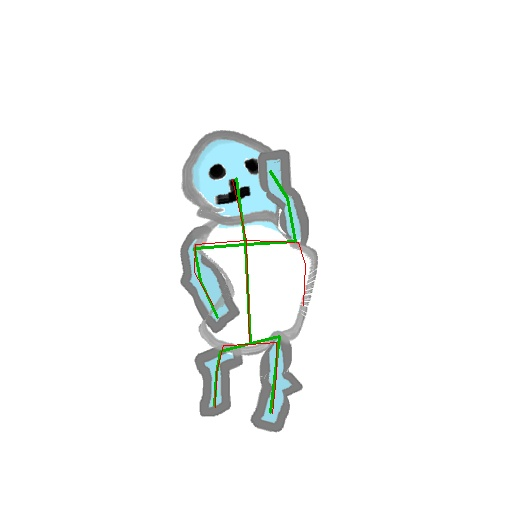

p1__bvh_bird__0_t22.jpg


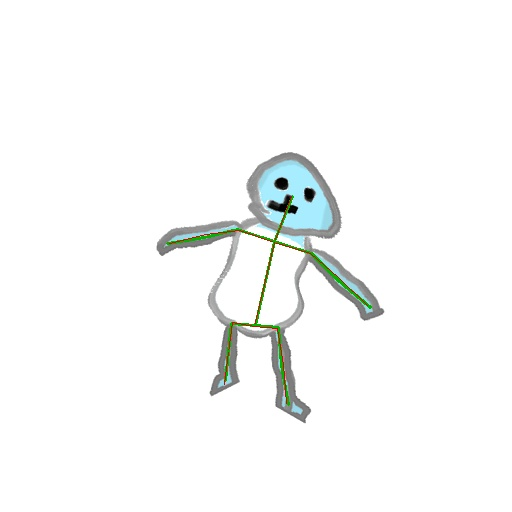

p1__bvh_dab__0_t98.jpg


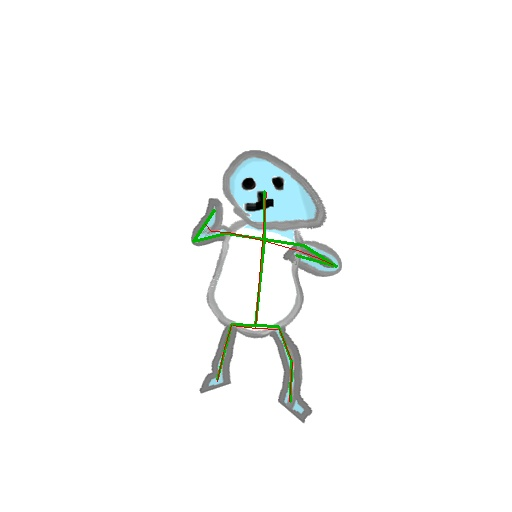

p1__bvh_elephant__0_t40.jpg


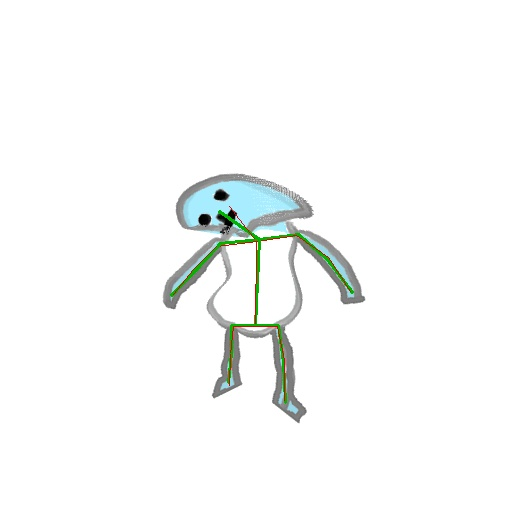

p1__bvh_happy_walk__0_t50.jpg


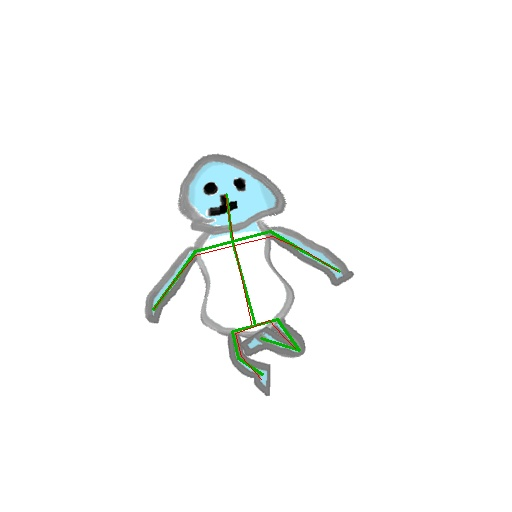

p1__bvh_idle__0_t38.jpg


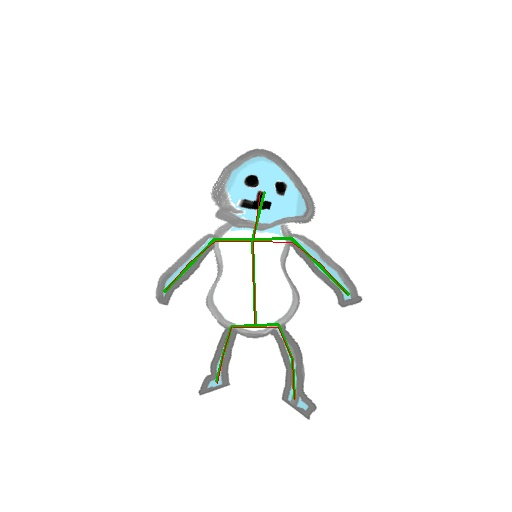

p1__bvh_jesse_dance__0_t66.jpg


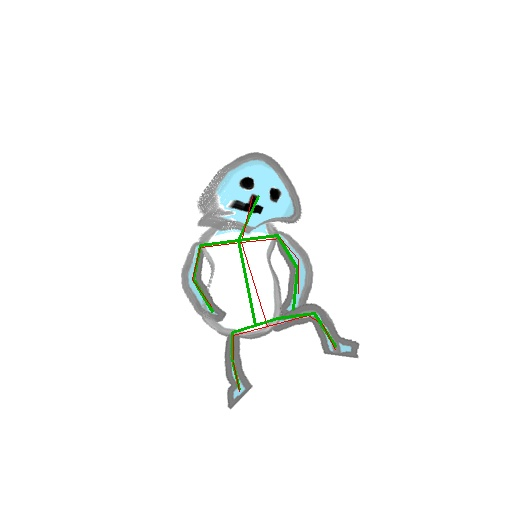

p1__bvh_jumping__0_t24.jpg


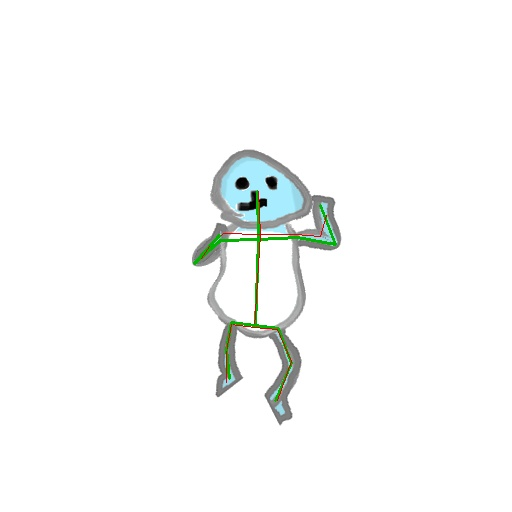

p1__bvh_jumping_jacks__0_t24.jpg


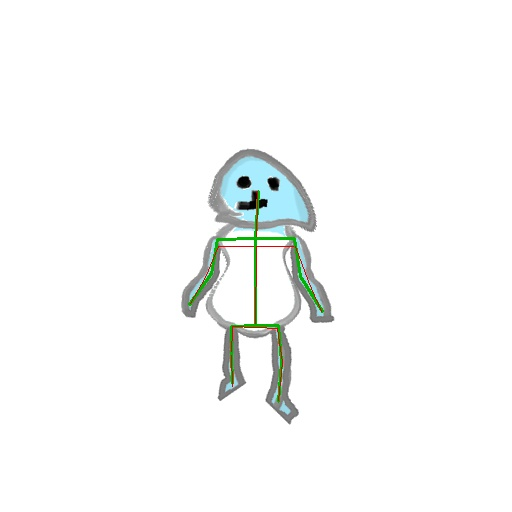

p1__bvh_kick_ball__0_t48.jpg


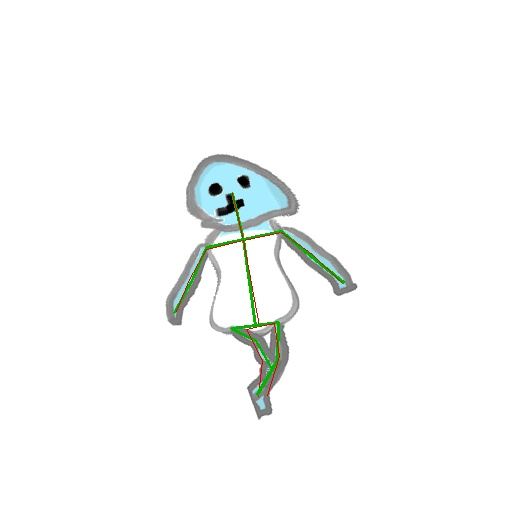

p1__bvh_laugh__0_t38.jpg


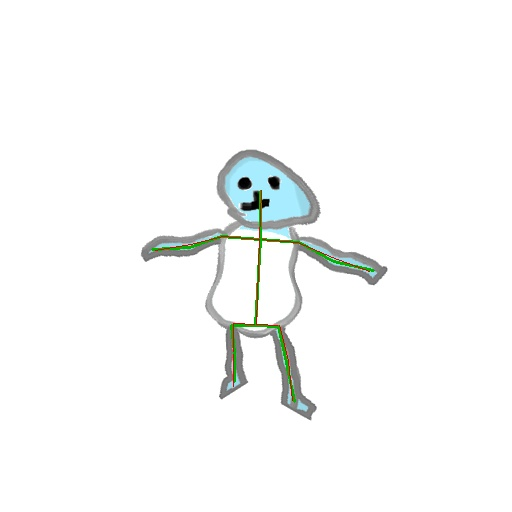

p1__bvh_march__0_t26.jpg


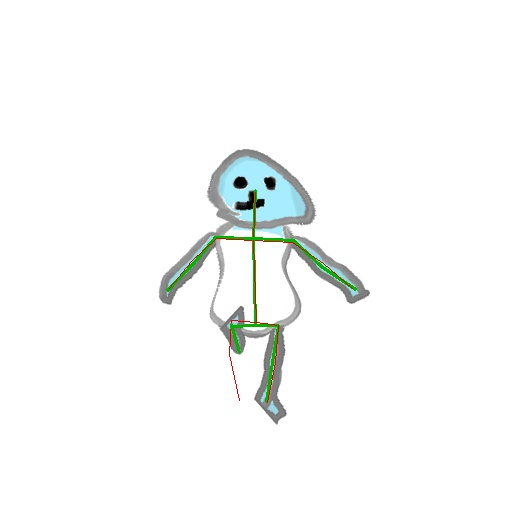

p1__bvh_monkey__0_t54.jpg


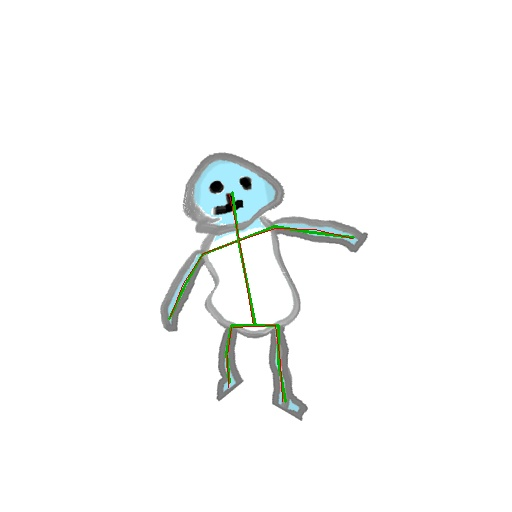

p1__bvh_point__0_t38.jpg


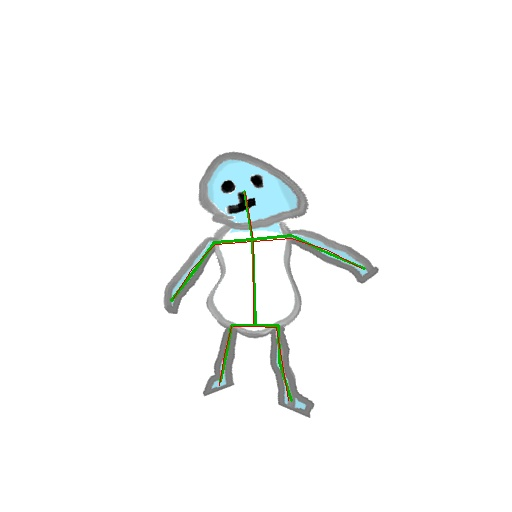

p1__bvh_reach_tiptoe__0_t12.jpg


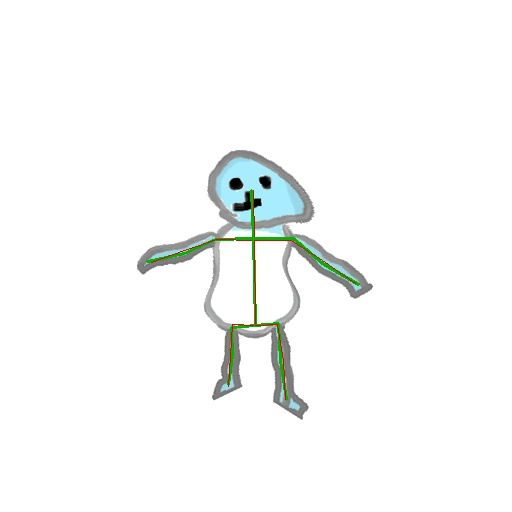

p1__bvh_sad_walk__0_t40.jpg


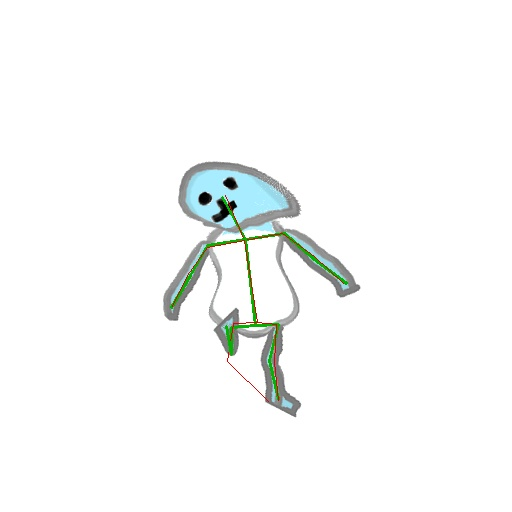

p1__bvh_search_ground__0_t42.jpg


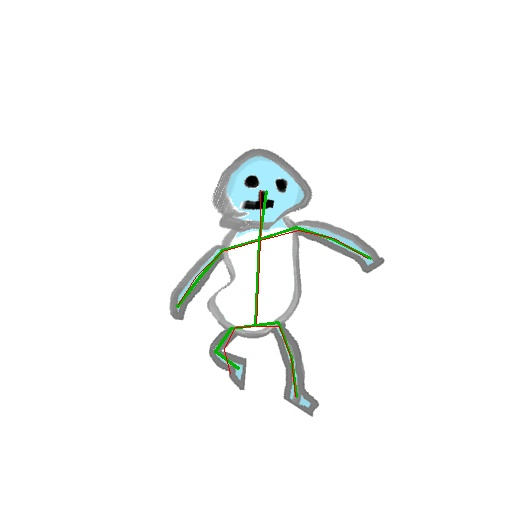

p1__bvh_stand_still__0_t28.jpg


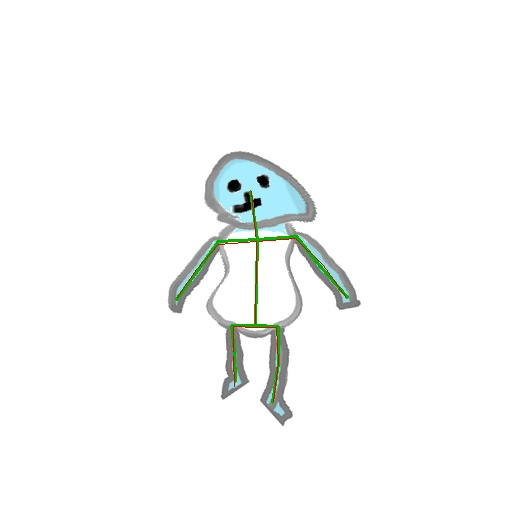

p1__bvh_swim__0_t38.jpg


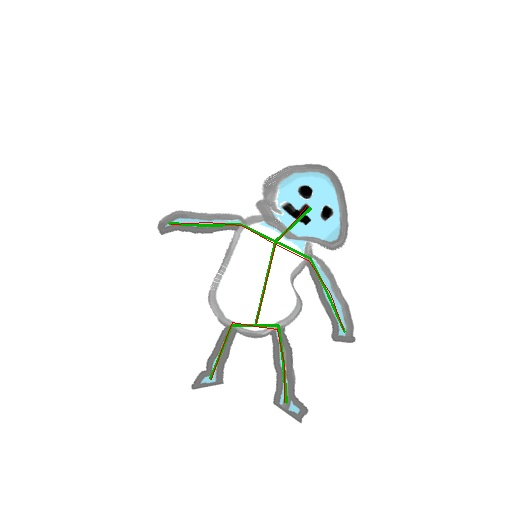

p1__bvh_very_happy__0_t34.jpg


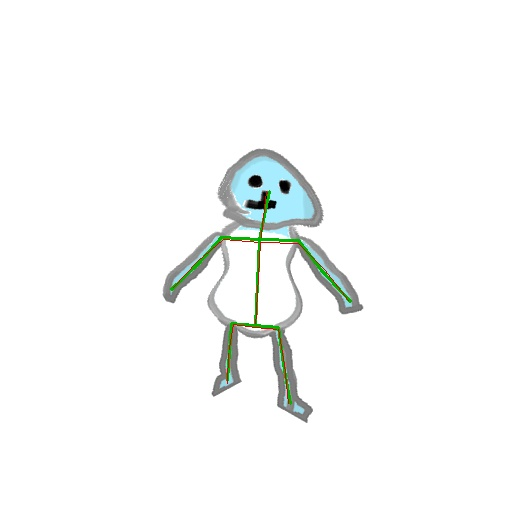

p1__bvh_wave_hello__0_t32.jpg


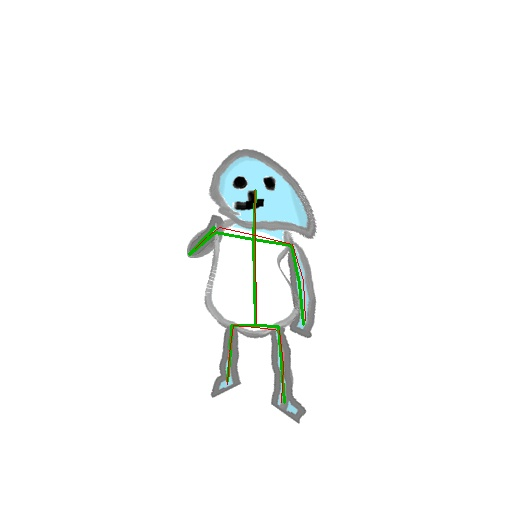

p1__bvh_zombie__0_t46.jpg


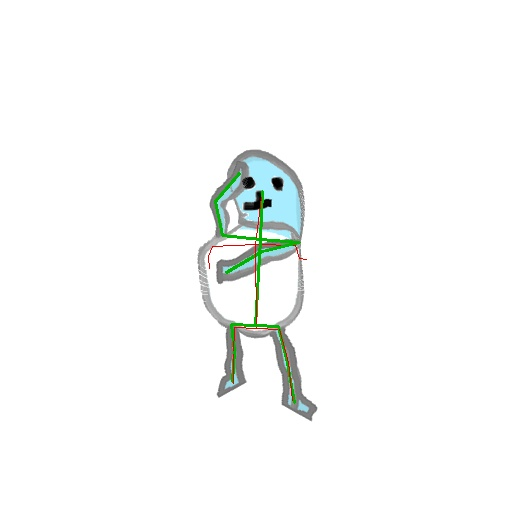

p2__bvh_bird__0_t24.jpg


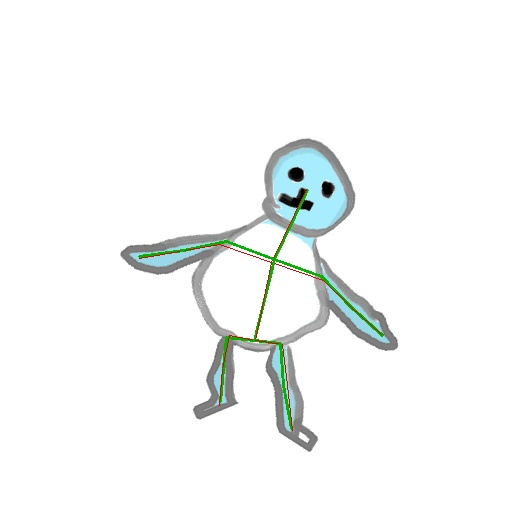

p2__bvh_dab__0_t98.jpg


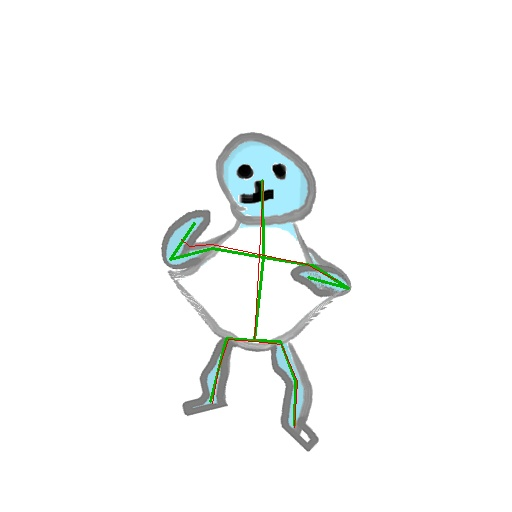

p2__bvh_elephant__0_t42.jpg


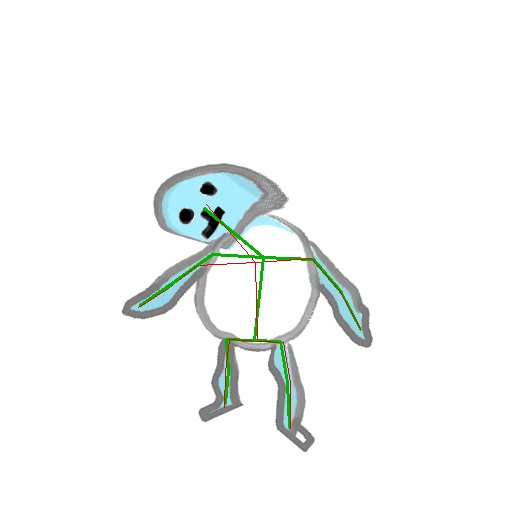

p2__bvh_happy_walk__0_t50.jpg


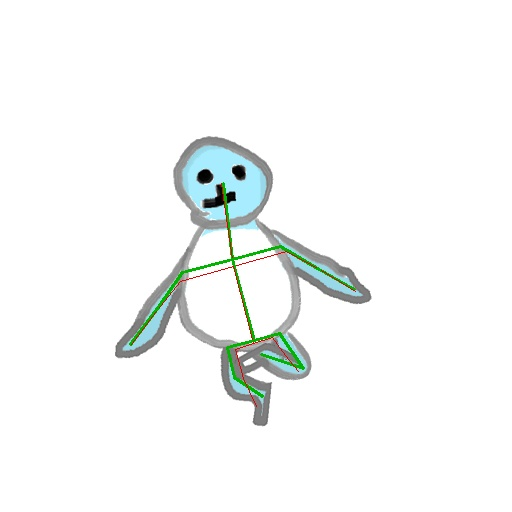

p2__bvh_idle__0_t2.jpg


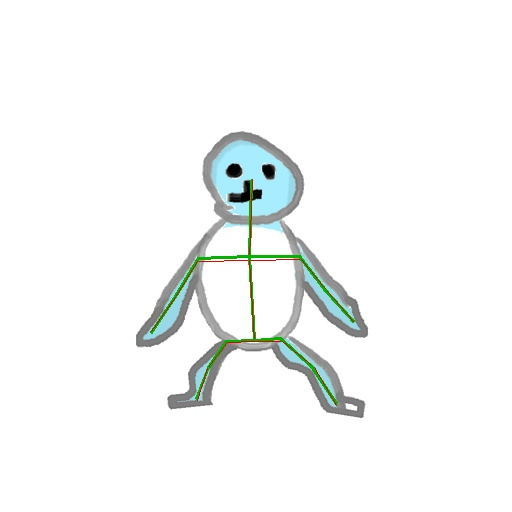

p2__bvh_jesse_dance__0_t30.jpg


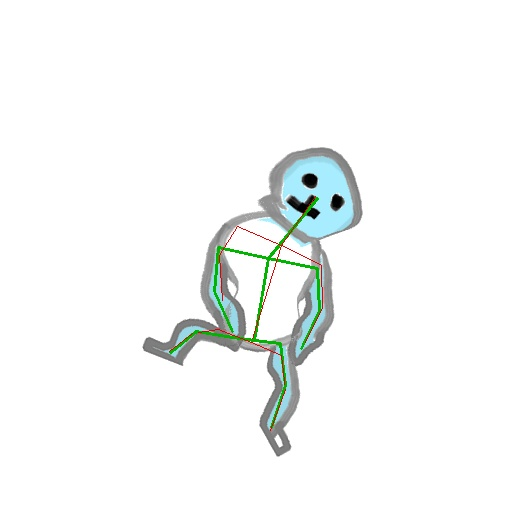

p2__bvh_jumping__0_t24.jpg


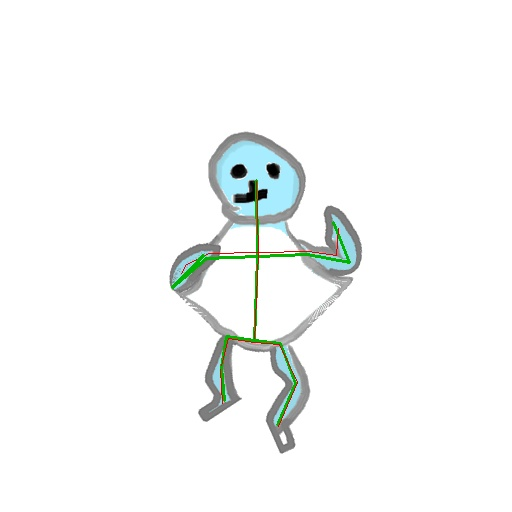

p2__bvh_jumping_jacks__0_t60.jpg


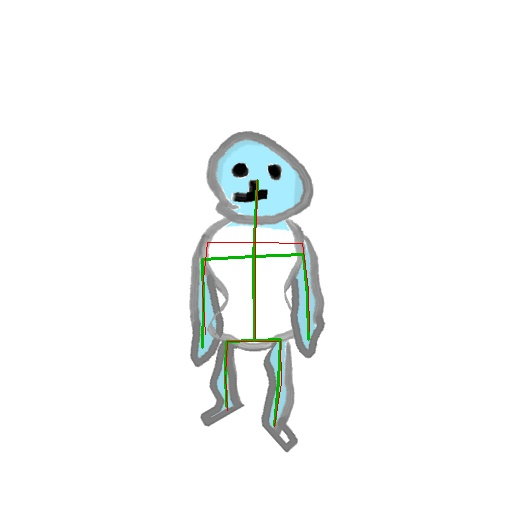

p2__bvh_kick_ball__0_t48.jpg


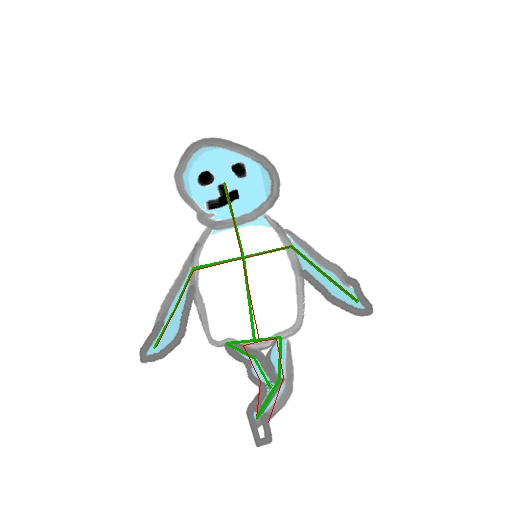

p2__bvh_laugh__0_t36.jpg


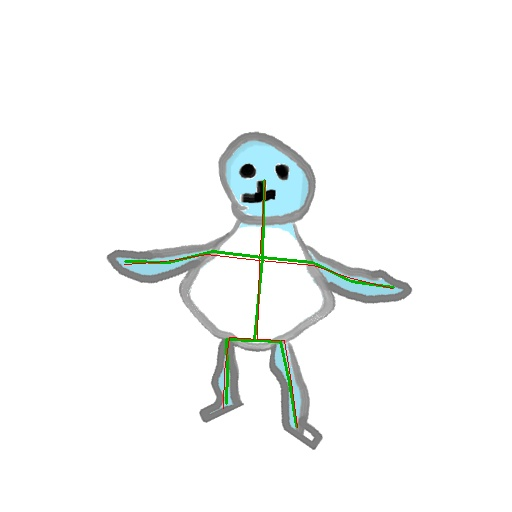

p2__bvh_march__0_t30.jpg


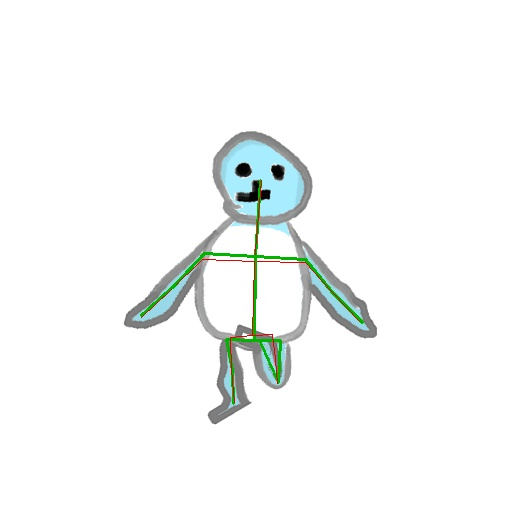

p2__bvh_monkey__0_t54.jpg


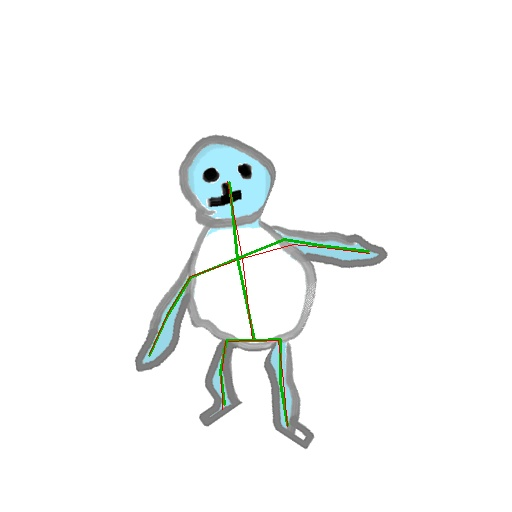

p2__bvh_point__0_t50.jpg


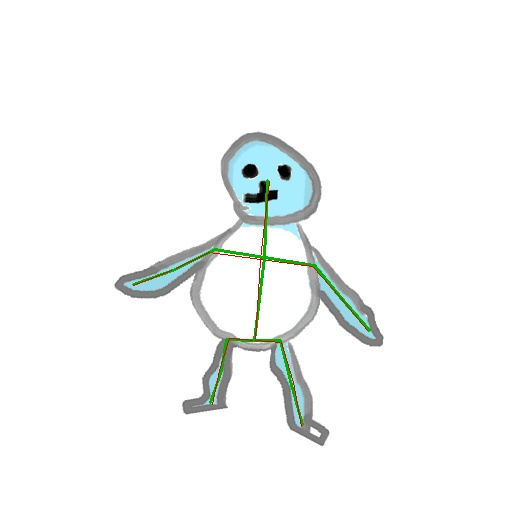

p2__bvh_reach_tiptoe__0_t22.jpg


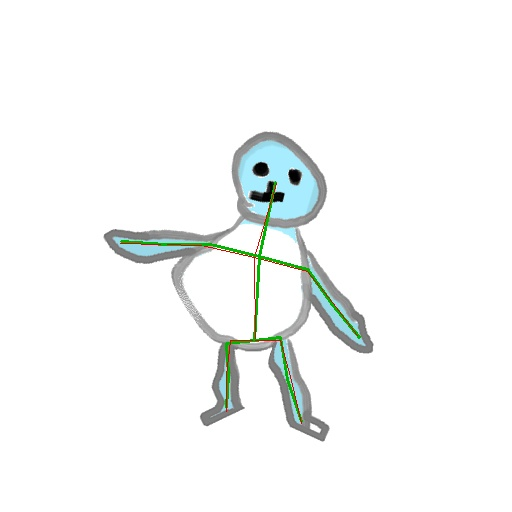

p2__bvh_sad_walk__0_t40.jpg


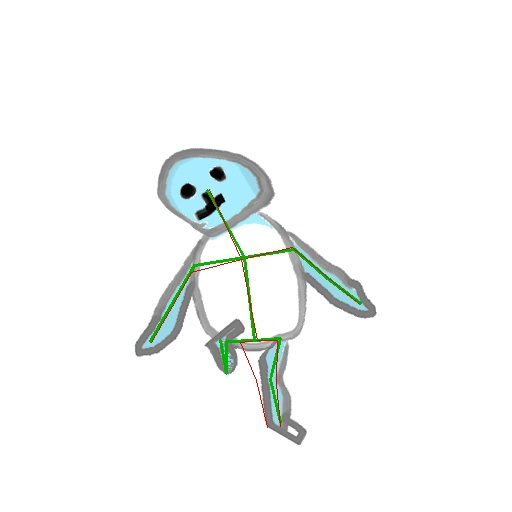

p2__bvh_search_ground__0_t24.jpg


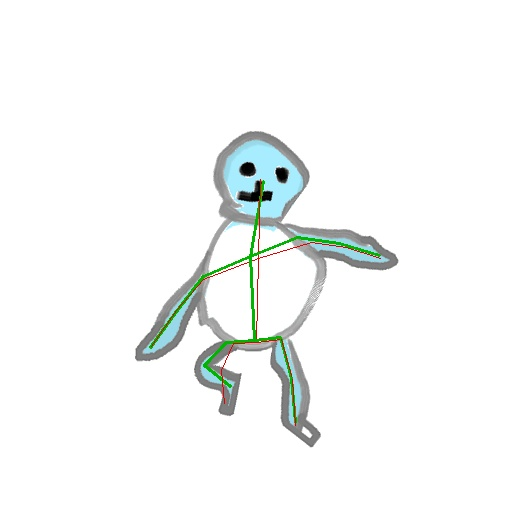

p2__bvh_stand_still__0_t8.jpg


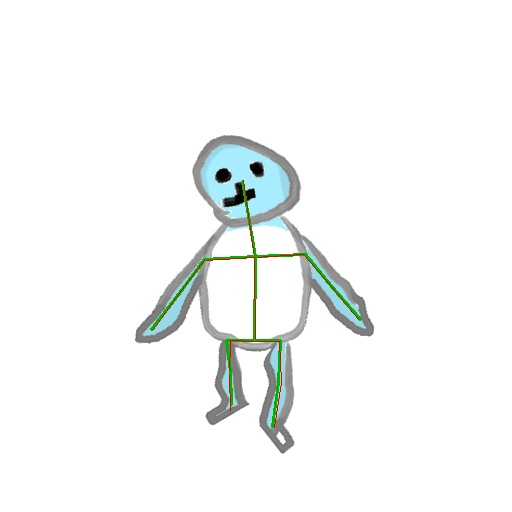

p2__bvh_swim__0_t8.jpg


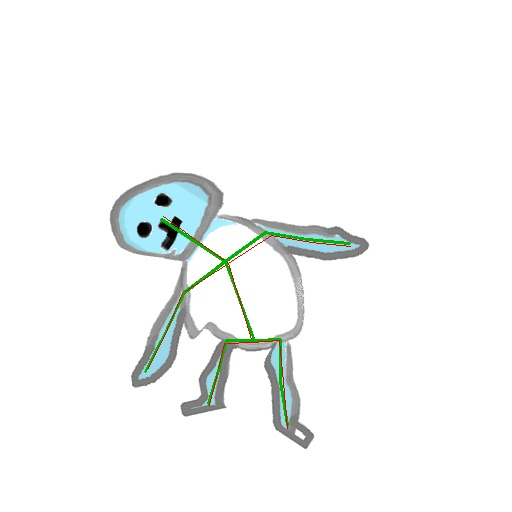

p2__bvh_very_happy__0_t18.jpg


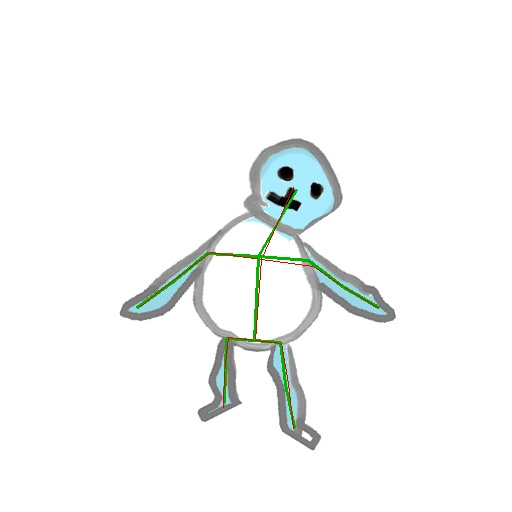

p2__bvh_wave_hello__0_t34.jpg


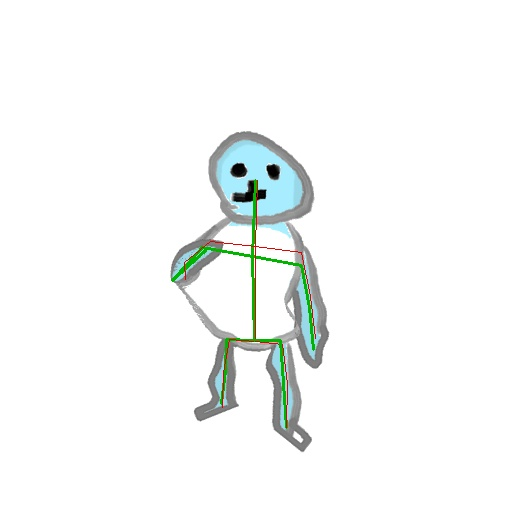

p2__bvh_zombie__0_t44.jpg


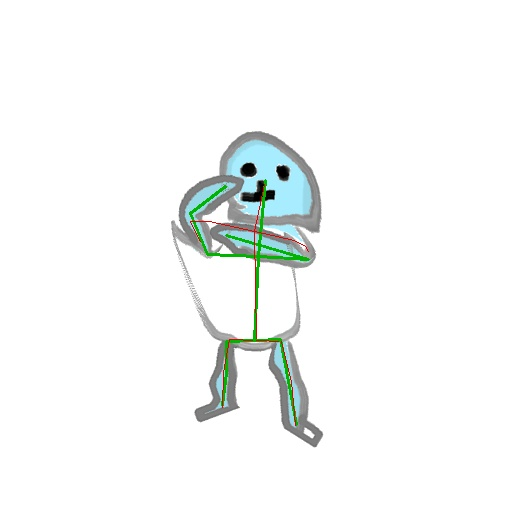

p3__bvh_bird__0_t24.jpg


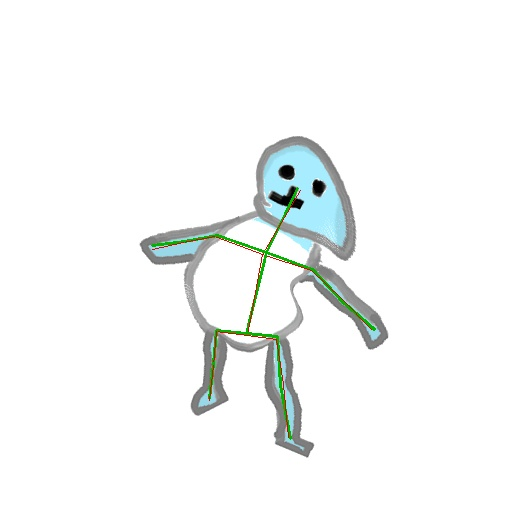

p3__bvh_dab__0_t108.jpg


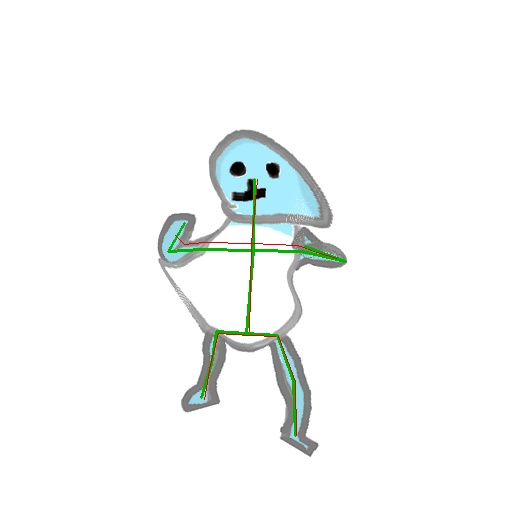

p3__bvh_elephant__0_t42.jpg


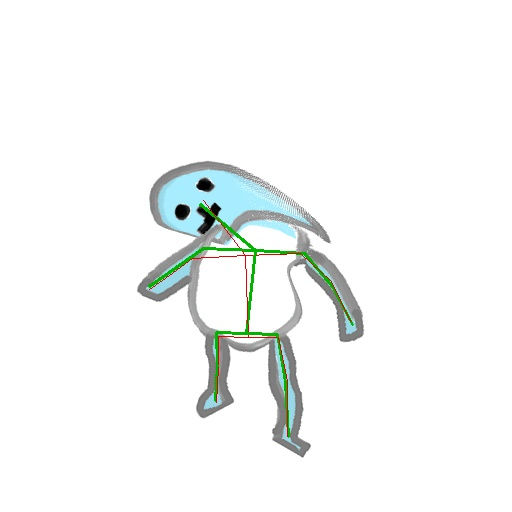

p3__bvh_happy_walk__0_t50.jpg


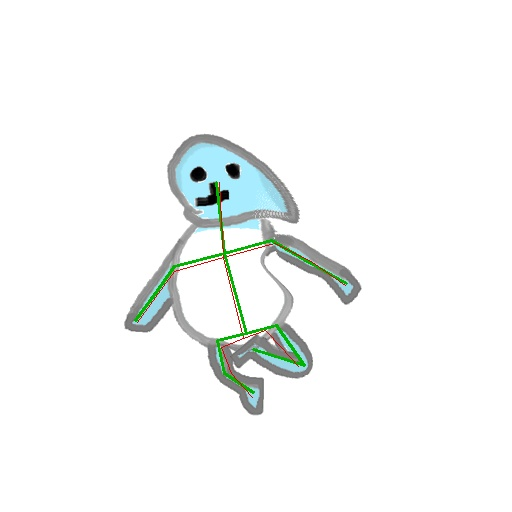

p3__bvh_idle__0_t12.jpg


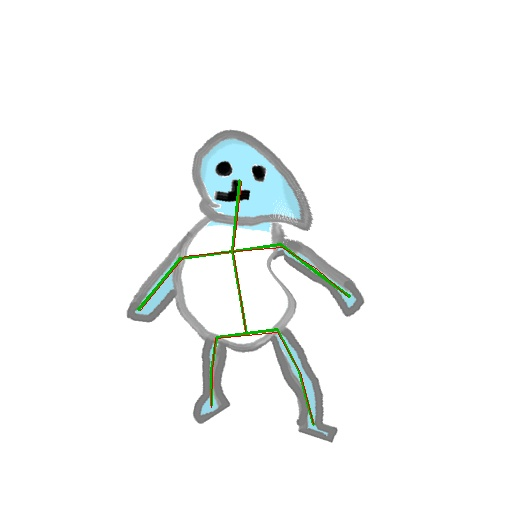

p3__bvh_jesse_dance__0_t66.jpg


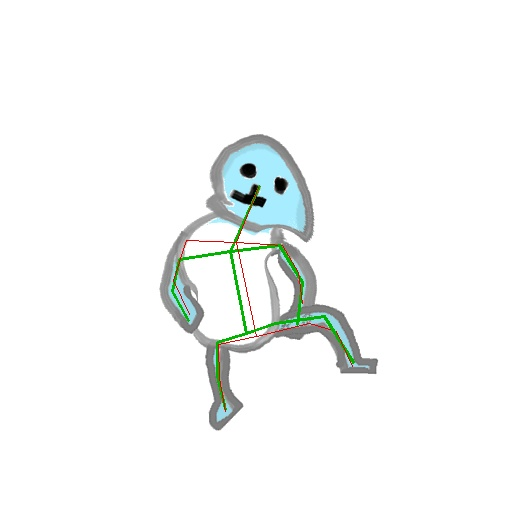

p3__bvh_jumping__0_t24.jpg


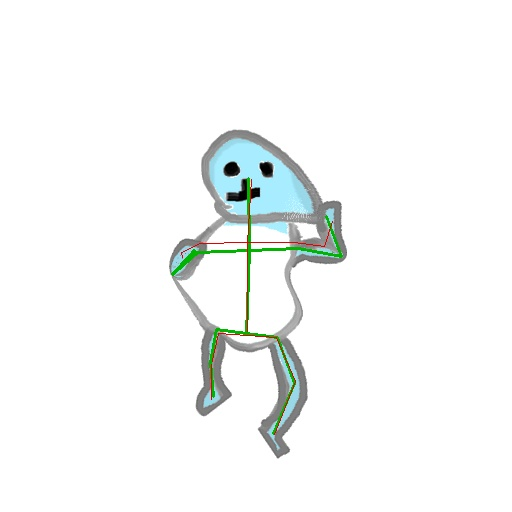

p3__bvh_jumping_jacks__0_t16.jpg


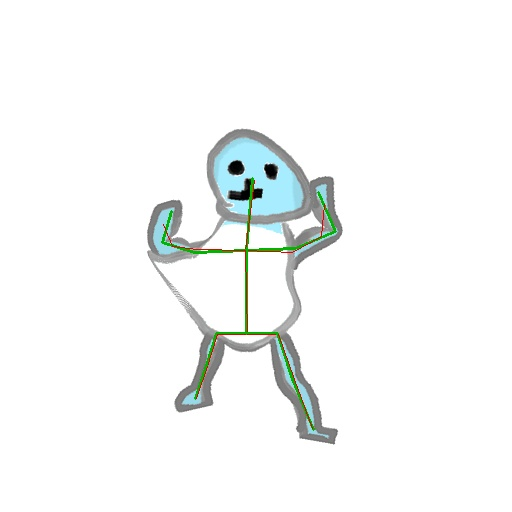

p3__bvh_kick_ball__0_t48.jpg


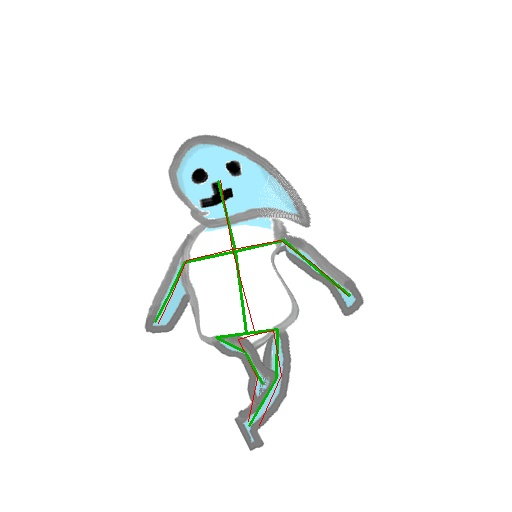

p3__bvh_laugh__0_t34.jpg


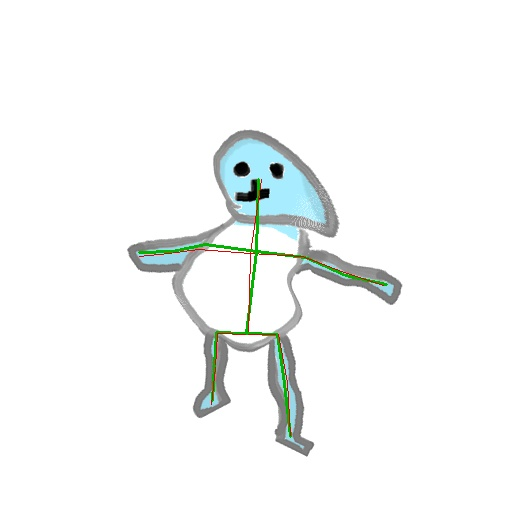

p3__bvh_march__0_t26.jpg


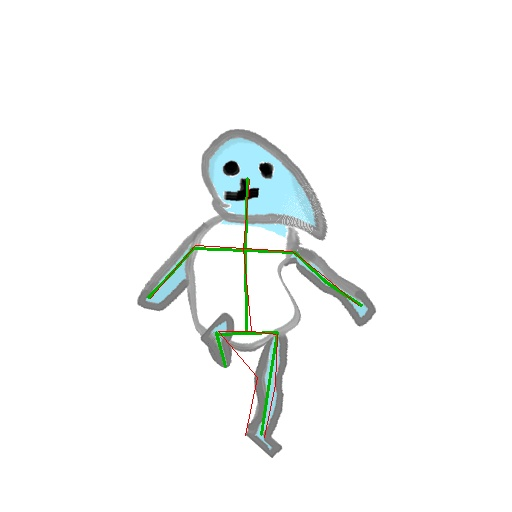

p3__bvh_monkey__0_t54.jpg


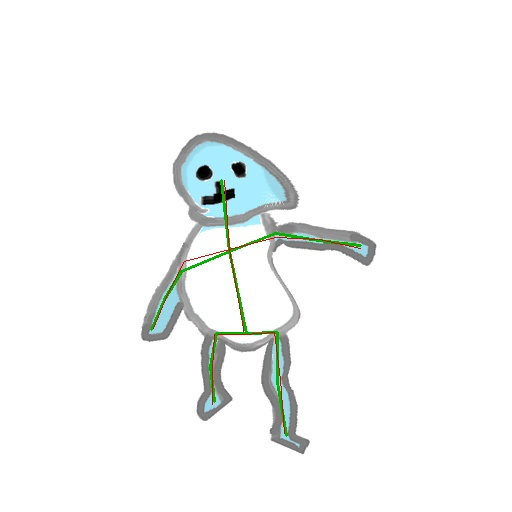

p3__bvh_point__0_t50.jpg


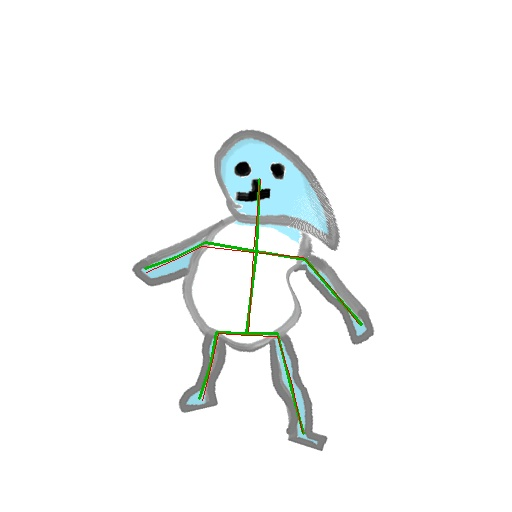

p3__bvh_reach_tiptoe__0_t22.jpg


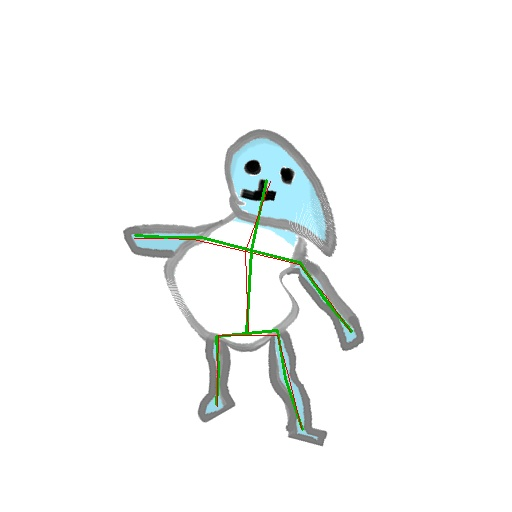

p3__bvh_sad_walk__0_t38.jpg


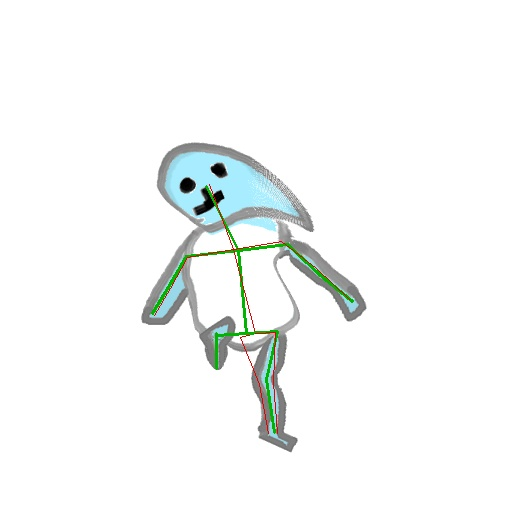

p3__bvh_search_ground__0_t26.jpg


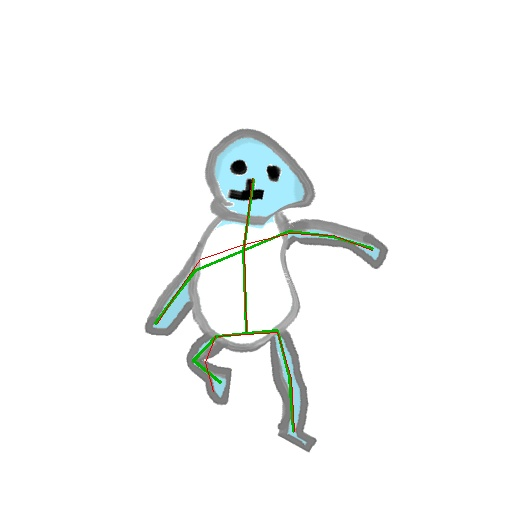

p3__bvh_stand_still__0_t28.jpg


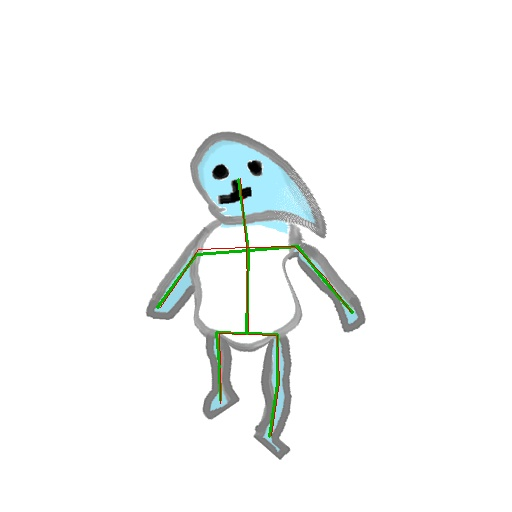

p3__bvh_swim__0_t36.jpg


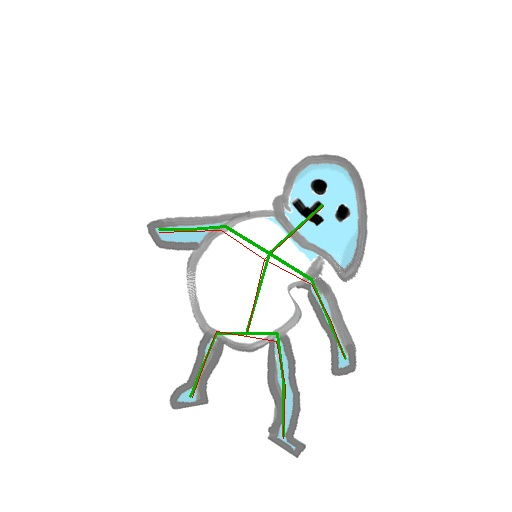

p3__bvh_very_happy__0_t26.jpg


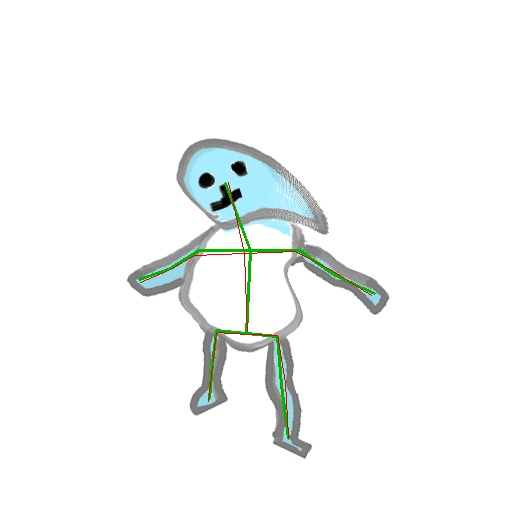

p3__bvh_wave_hello__0_t34.jpg


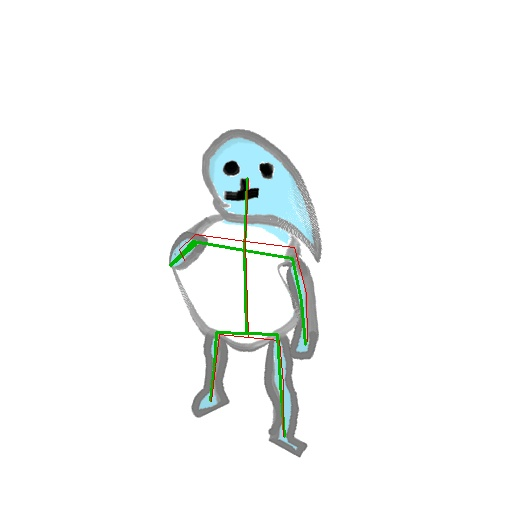

p3__bvh_zombie__0_t50.jpg


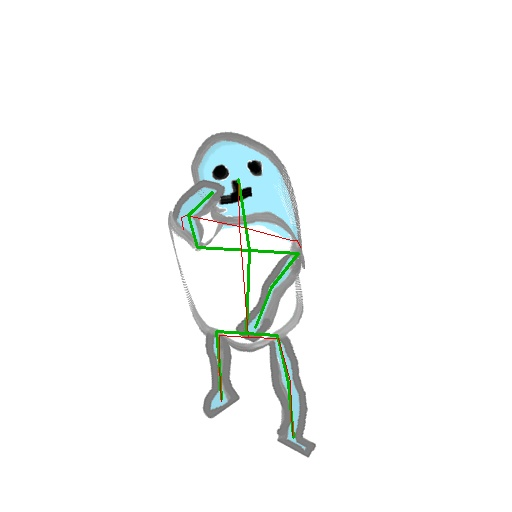

p4__bvh_bird__0_t24.jpg


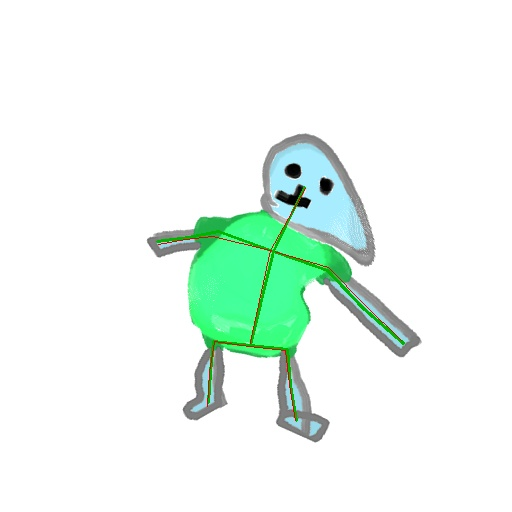

p4__bvh_dab__0_t44.jpg


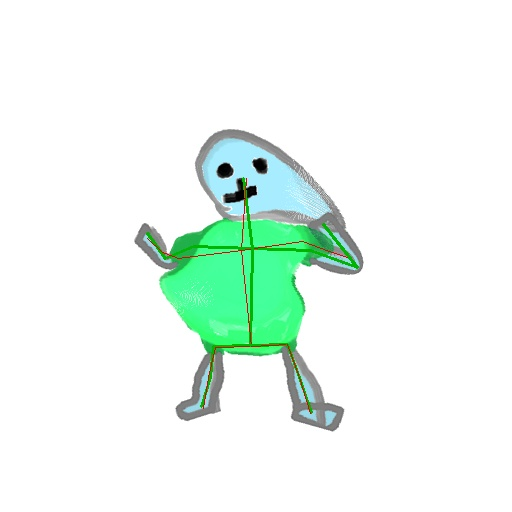

p4__bvh_elephant__0_t44.jpg


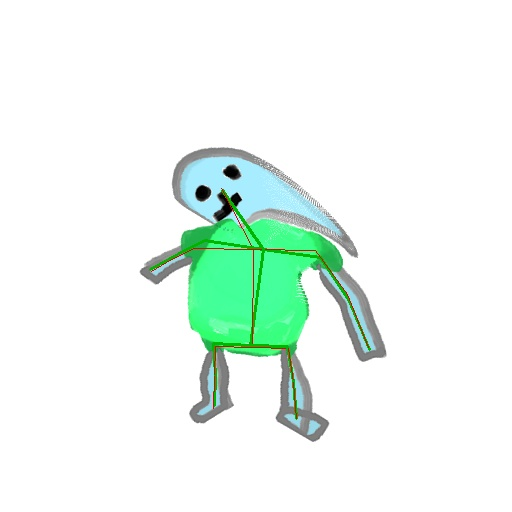

p4__bvh_happy_walk__0_t50.jpg


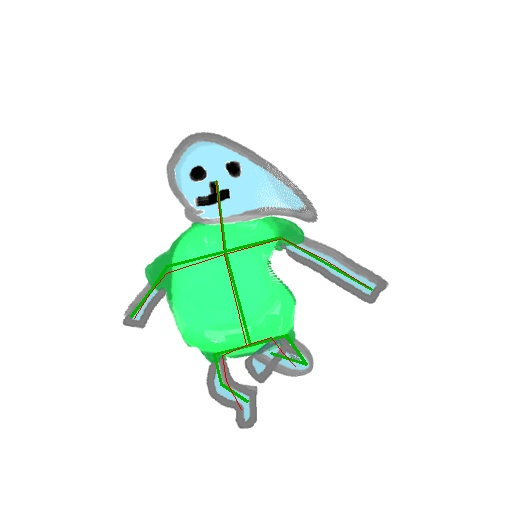

p4__bvh_idle__0_t38.jpg


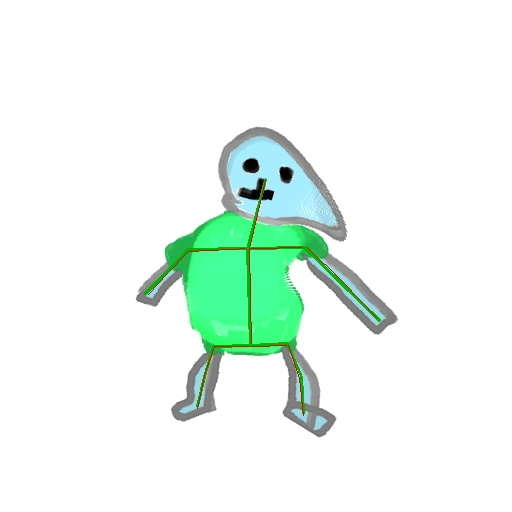

p4__bvh_jesse_dance__0_t10.jpg


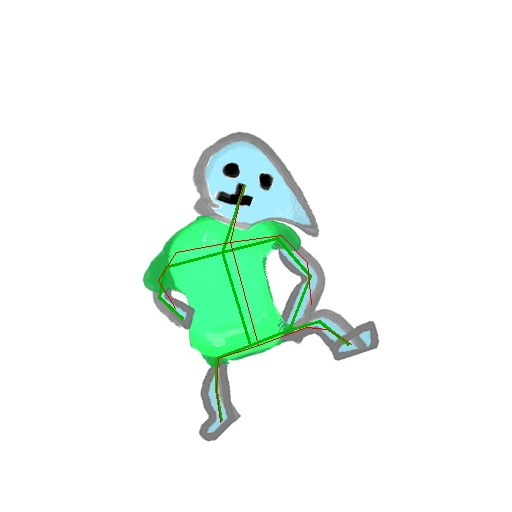

p4__bvh_jumping__0_t24.jpg


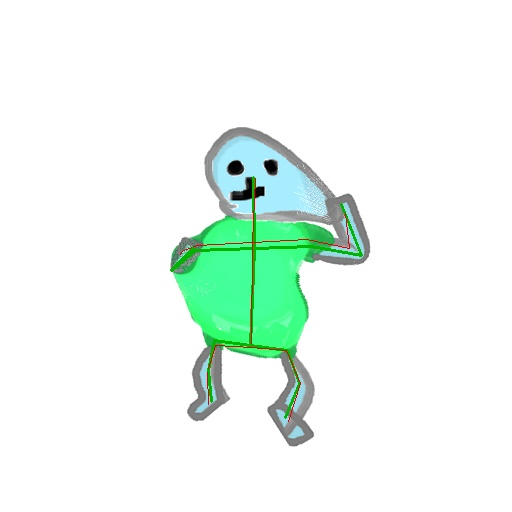

p4__bvh_jumping_jacks__0_t60.jpg


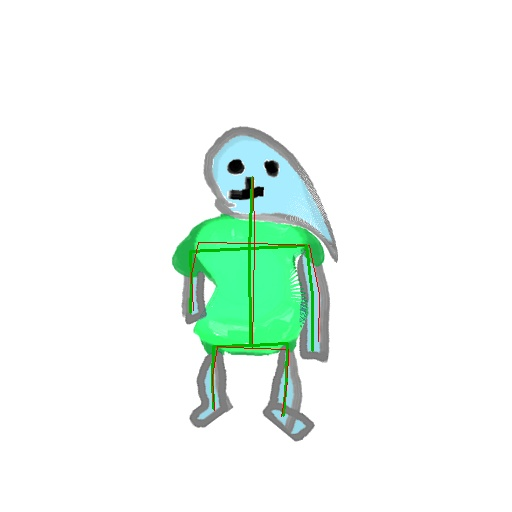

p4__bvh_kick_ball__0_t48.jpg


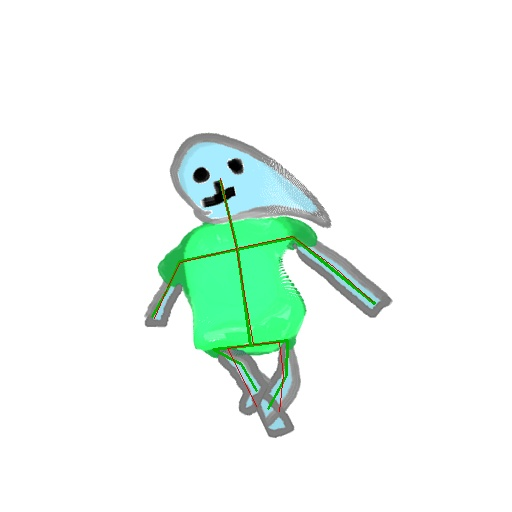

p4__bvh_laugh__0_t36.jpg


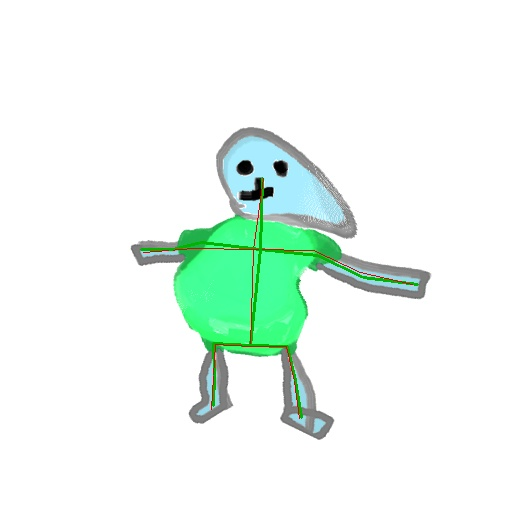

p4__bvh_march__0_t34.jpg


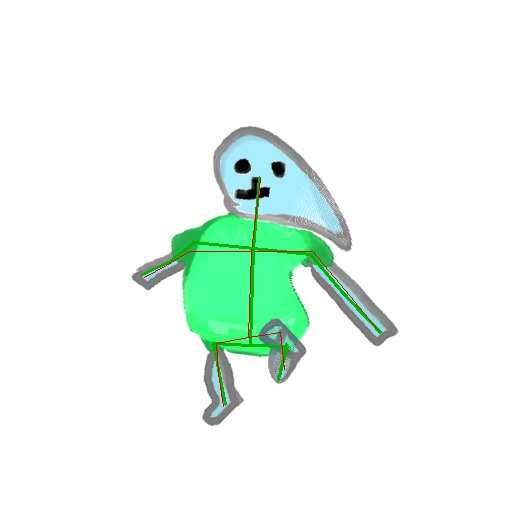

p4__bvh_monkey__0_t44.jpg


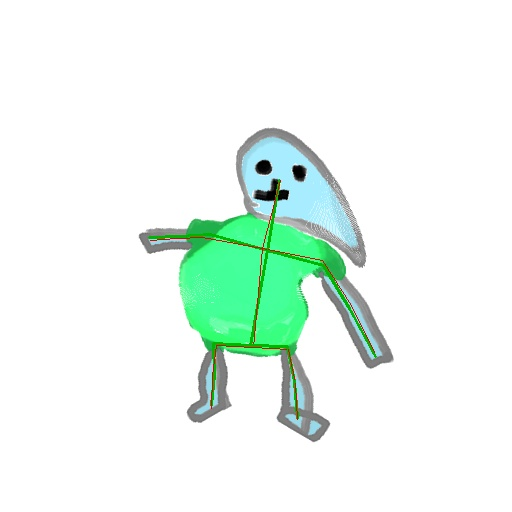

p4__bvh_point__0_t50.jpg


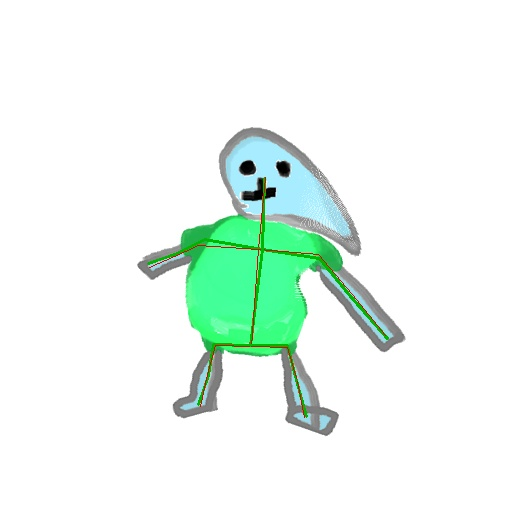

p4__bvh_reach_tiptoe__0_t20.jpg


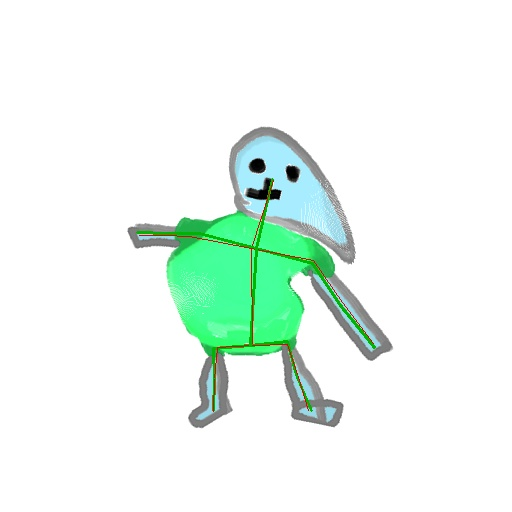

p4__bvh_sad_walk__0_t54.jpg


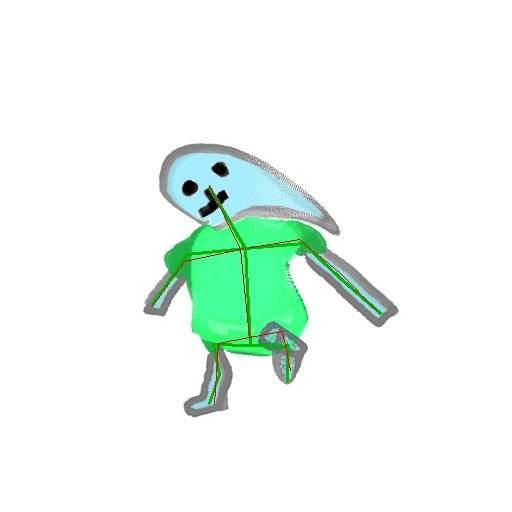

p4__bvh_search_ground__0_t24.jpg


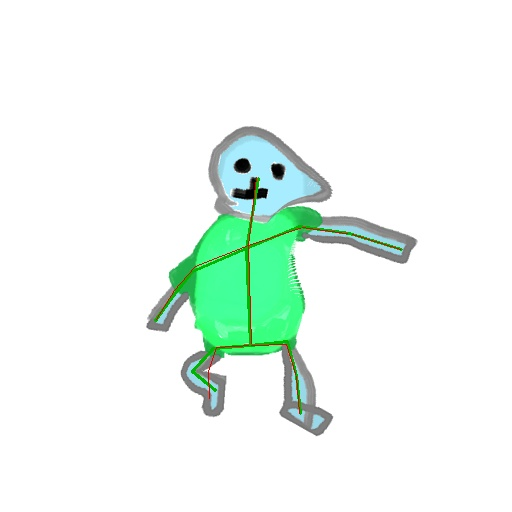

p4__bvh_stand_still__0_t10.jpg


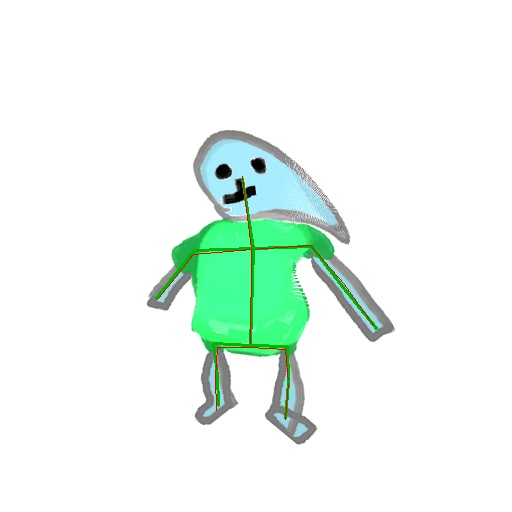

p4__bvh_swim__0_t36.jpg


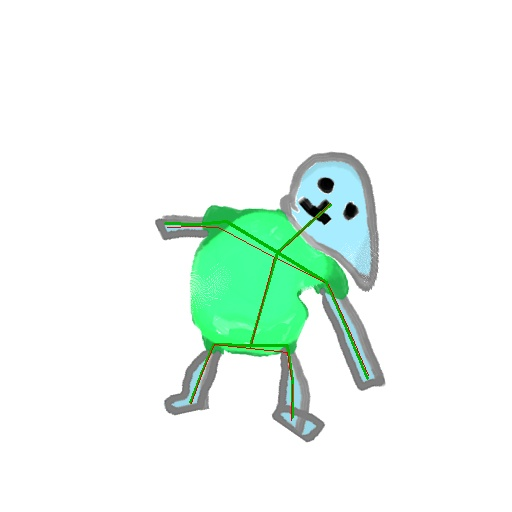

p4__bvh_very_happy__0_t24.jpg


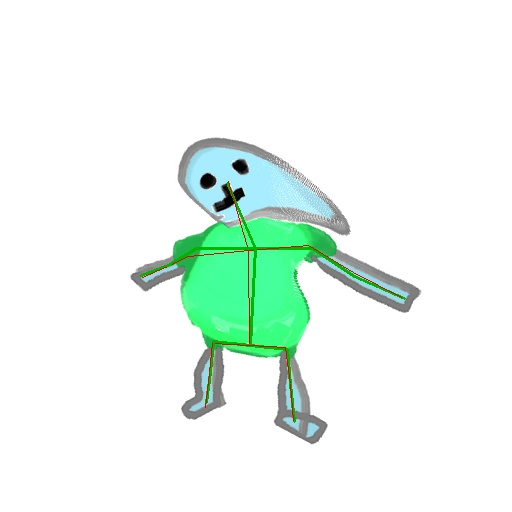

p4__bvh_wave_hello__0_t40.jpg


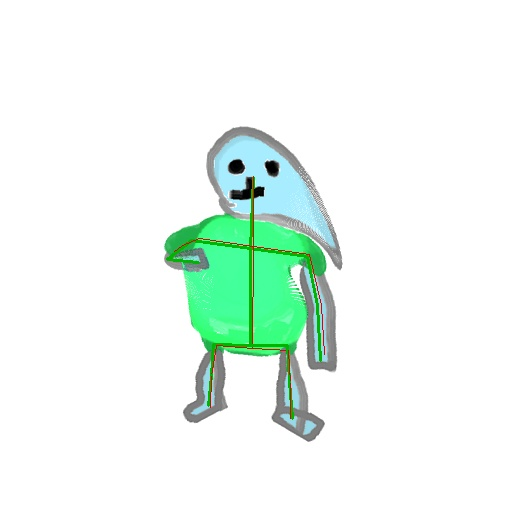

p4__bvh_zombie__0_t24.jpg


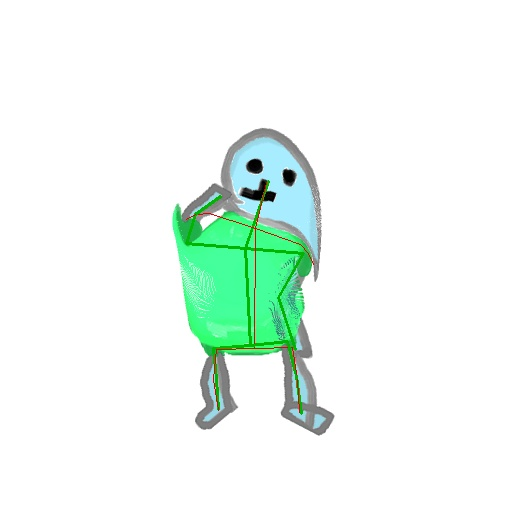

p5__bvh_bird__0_t24.jpg


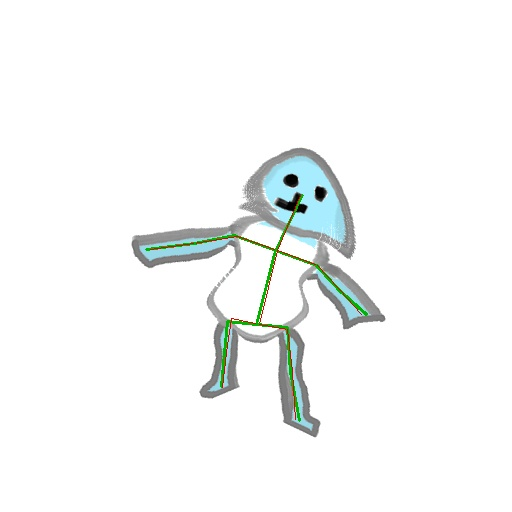

p5__bvh_dab__0_t106.jpg


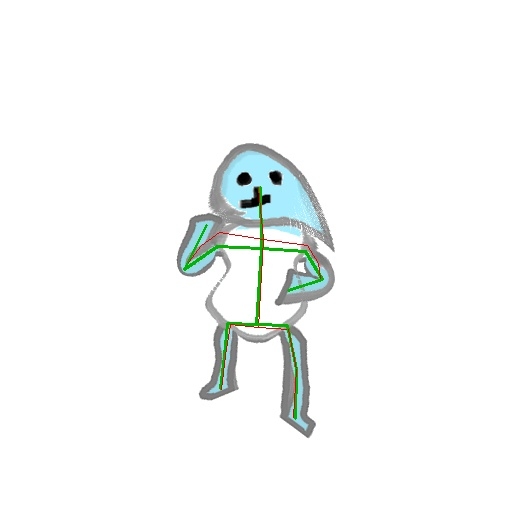

p5__bvh_elephant__0_t42.jpg


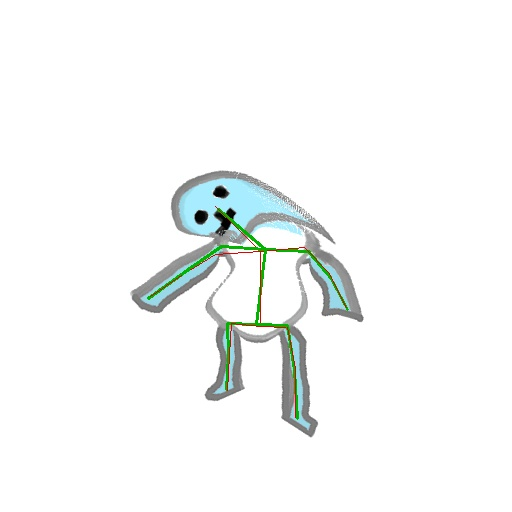

p5__bvh_happy_walk__0_t50.jpg


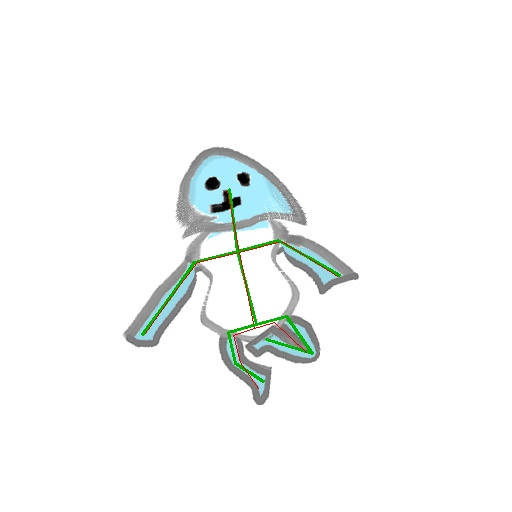

p5__bvh_idle__0_t38.jpg


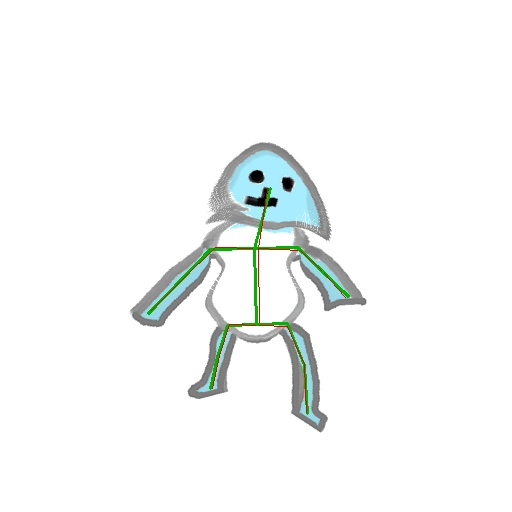

p5__bvh_jesse_dance__0_t14.jpg


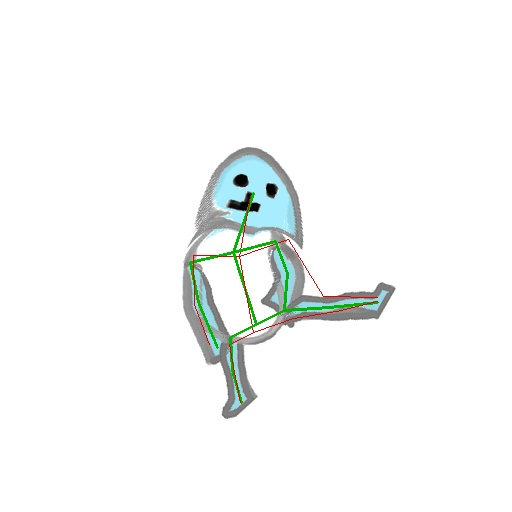

p5__bvh_jumping__0_t24.jpg


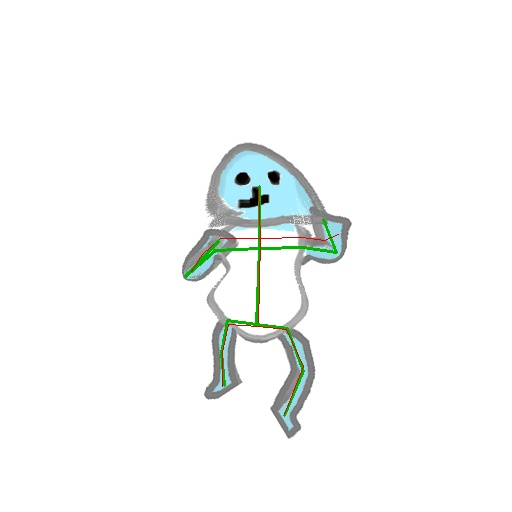

p5__bvh_jumping_jacks__0_t60.jpg


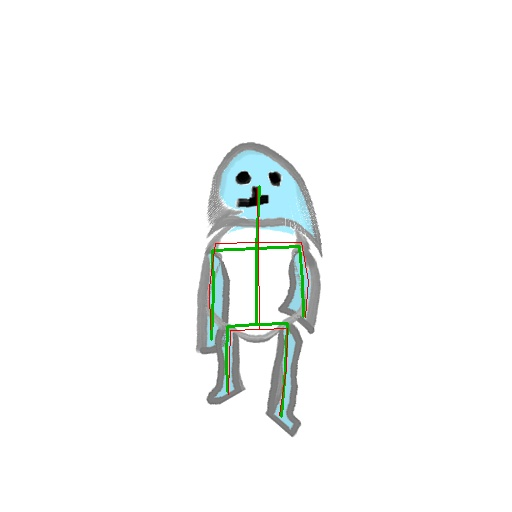

p5__bvh_kick_ball__0_t48.jpg


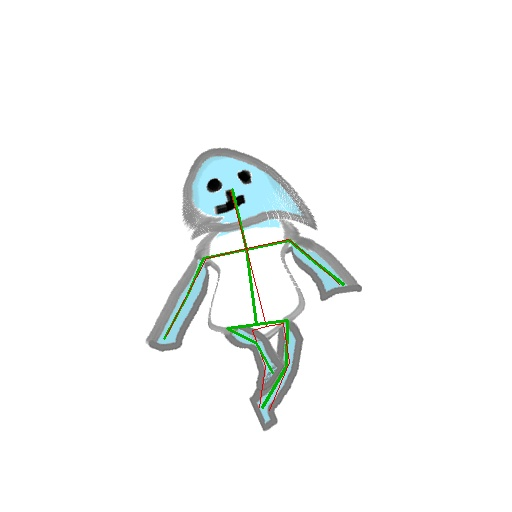

p5__bvh_laugh__0_t18.jpg


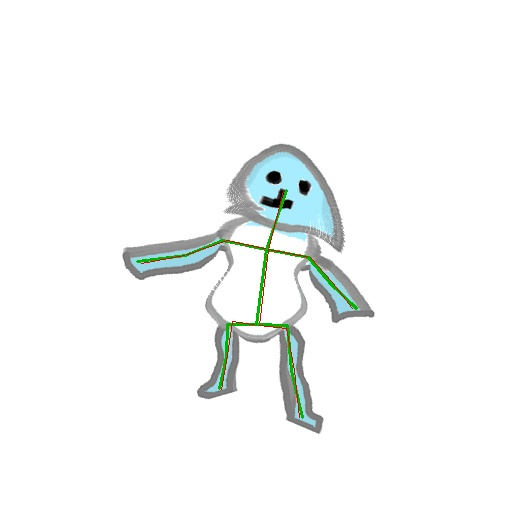

p5__bvh_march__0_t26.jpg


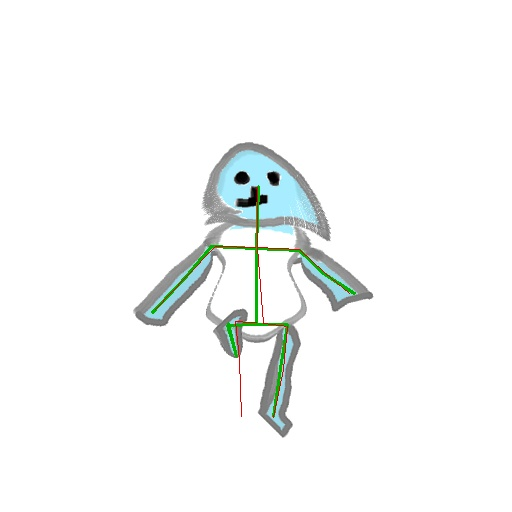

p5__bvh_monkey__0_t54.jpg


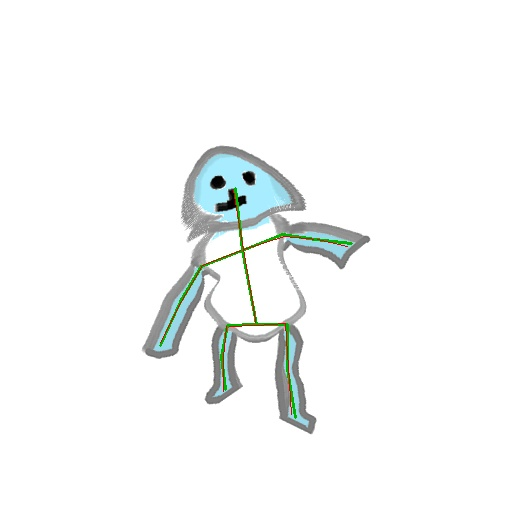

p5__bvh_point__0_t10.jpg


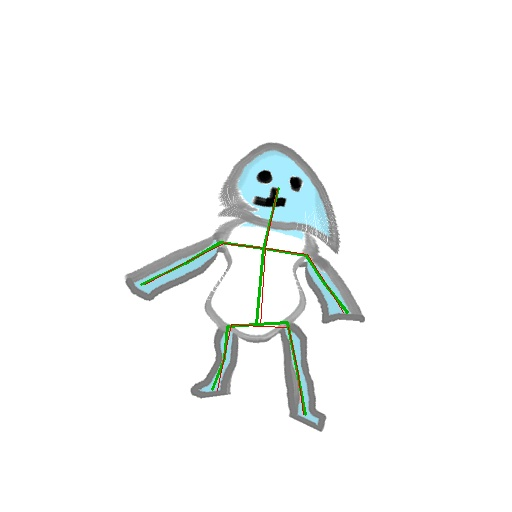

p5__bvh_reach_tiptoe__0_t20.jpg


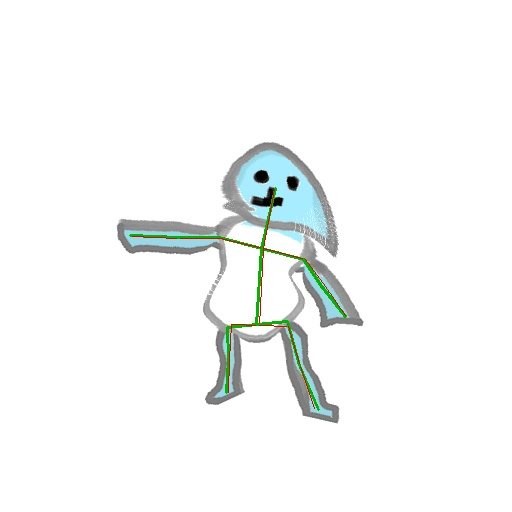

p5__bvh_sad_walk__0_t40.jpg


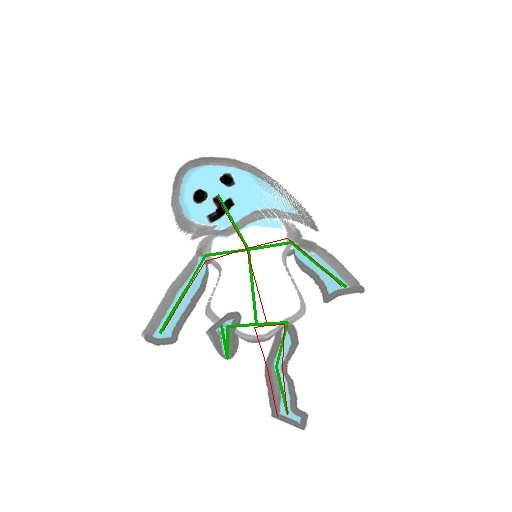

p5__bvh_search_ground__0_t24.jpg


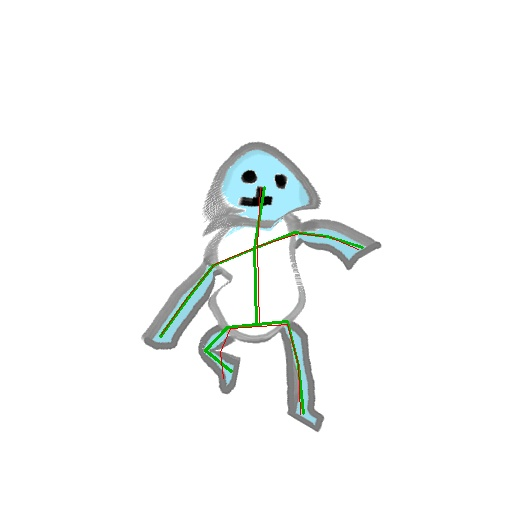

p5__bvh_stand_still__0_t14.jpg


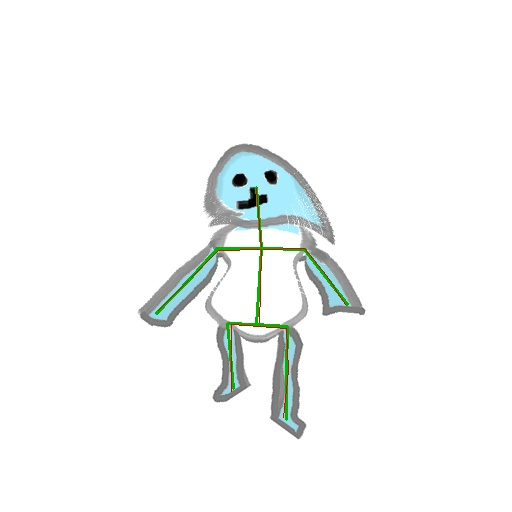

p5__bvh_swim__0_t36.jpg


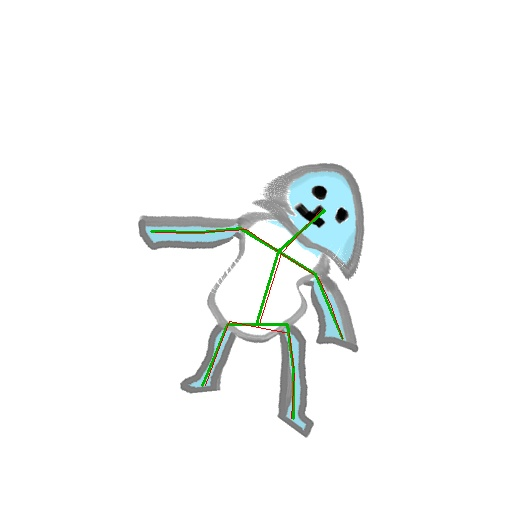

p5__bvh_very_happy__0_t16.jpg


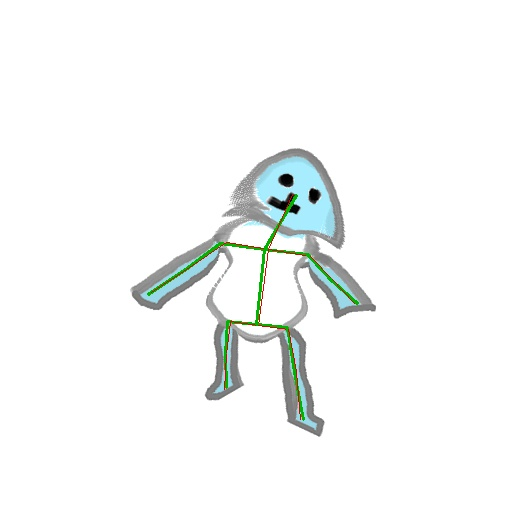

p5__bvh_wave_hello__0_t30.jpg


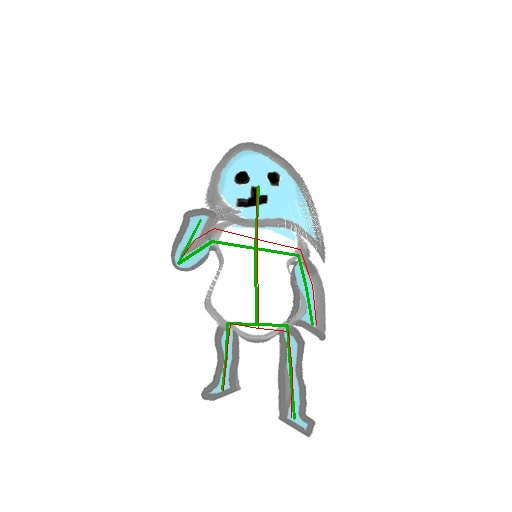

p5__bvh_zombie__0_t32.jpg


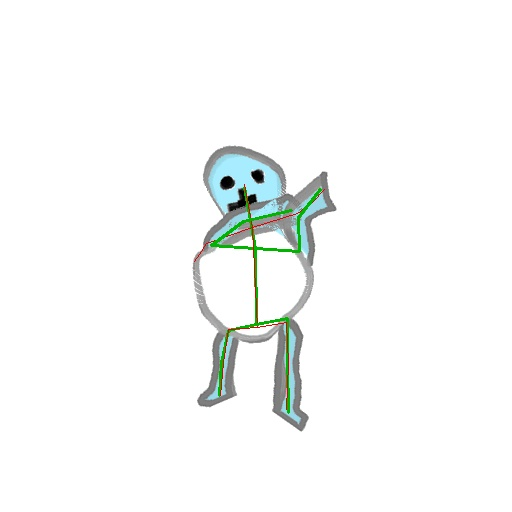

p6__bvh_bird__0_t34.jpg


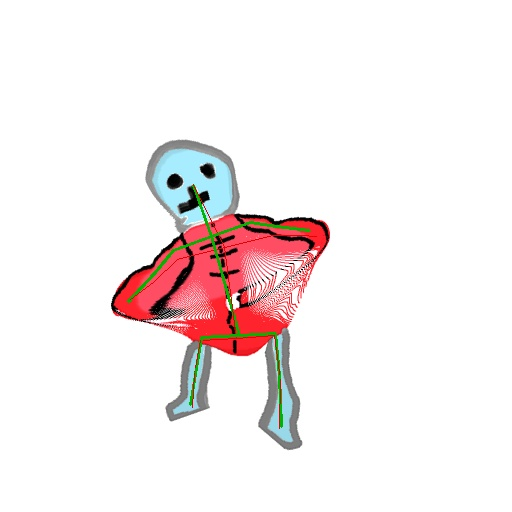

p6__bvh_dab__0_t78.jpg


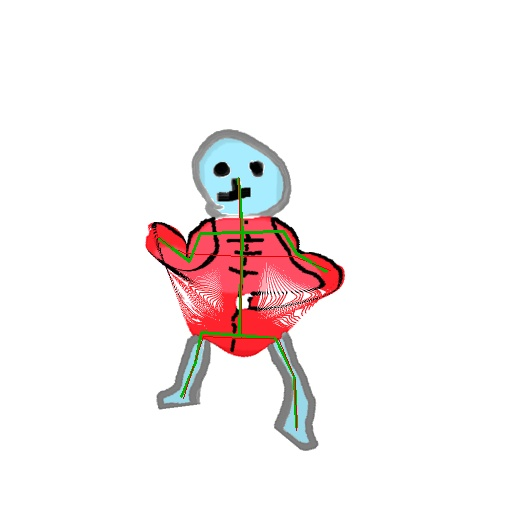

p6__bvh_elephant__0_t42.jpg


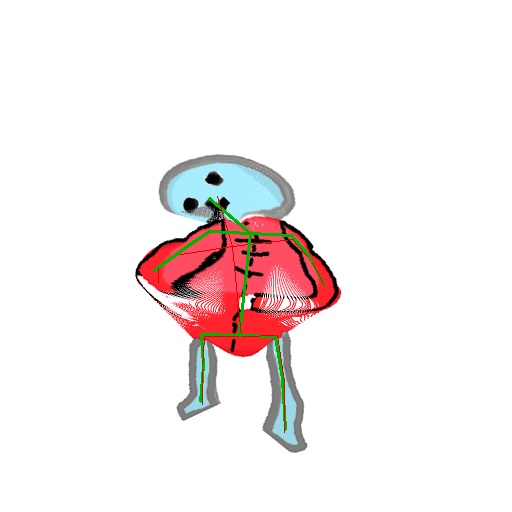

p6__bvh_happy_walk__0_t50.jpg


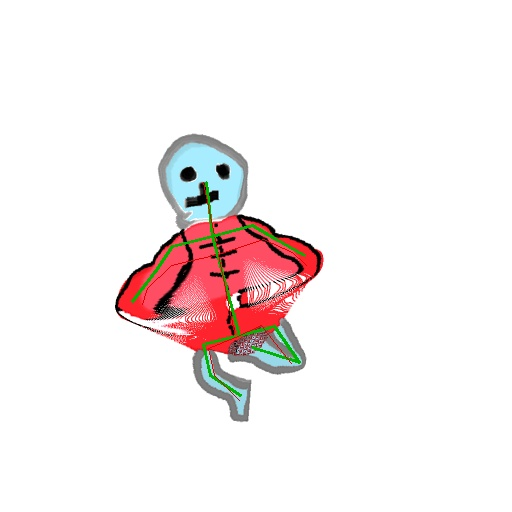

p6__bvh_idle__0_t10.jpg


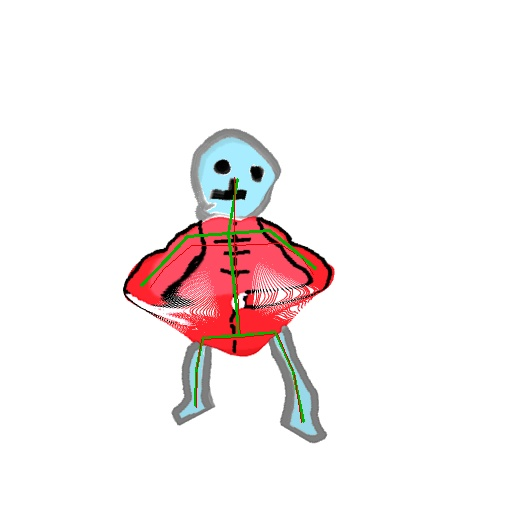

p6__bvh_jesse_dance__0_t140.jpg


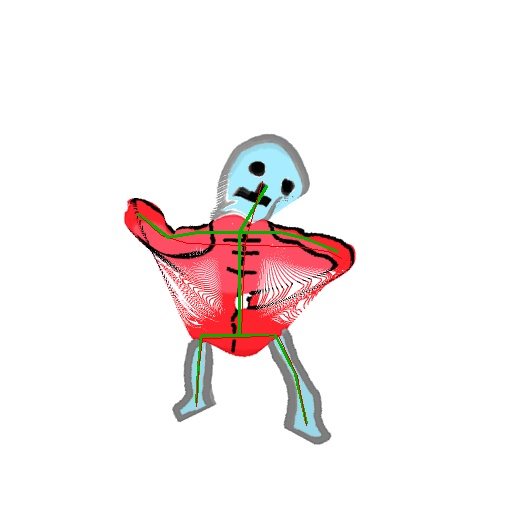

p6__bvh_jumping__0_t18.jpg


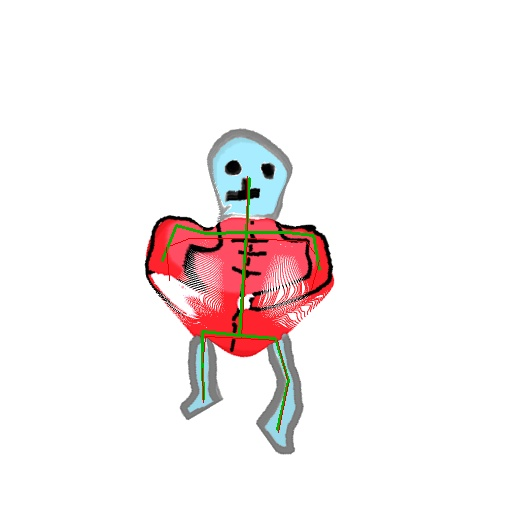

p6__bvh_jumping_jacks__0_t54.jpg


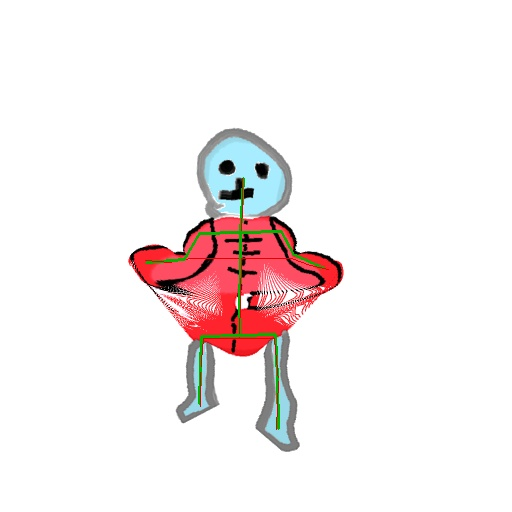

p6__bvh_kick_ball__0_t48.jpg


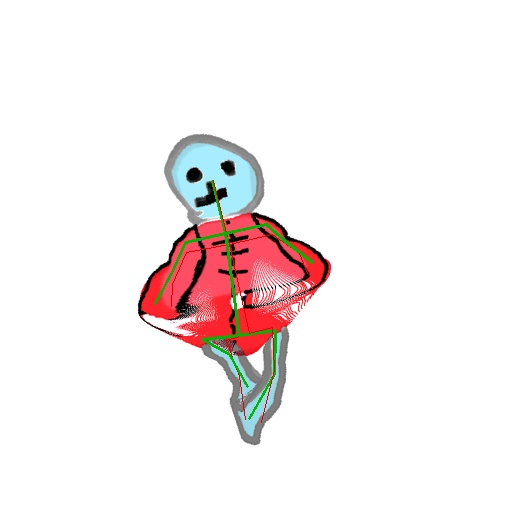

p6__bvh_laugh__0_t38.jpg


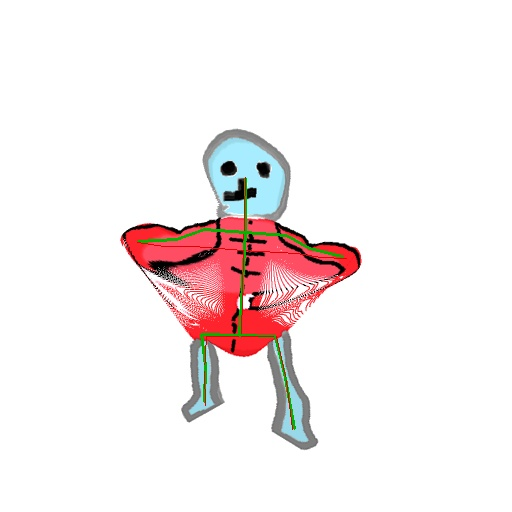

p6__bvh_march__0_t30.jpg


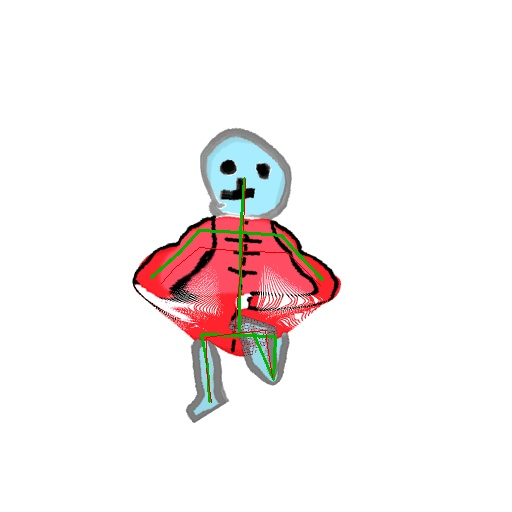

p6__bvh_monkey__0_t54.jpg


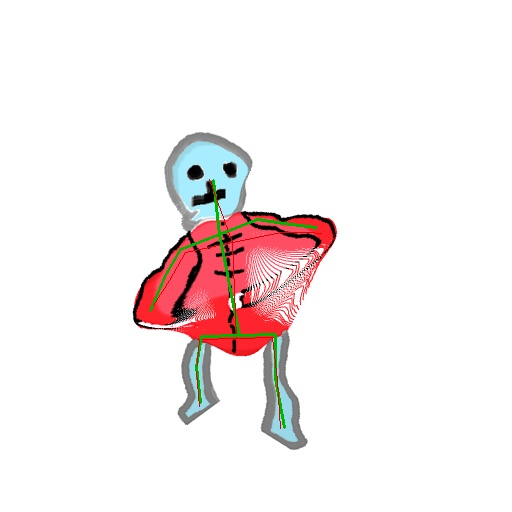

p6__bvh_point__0_t44.jpg


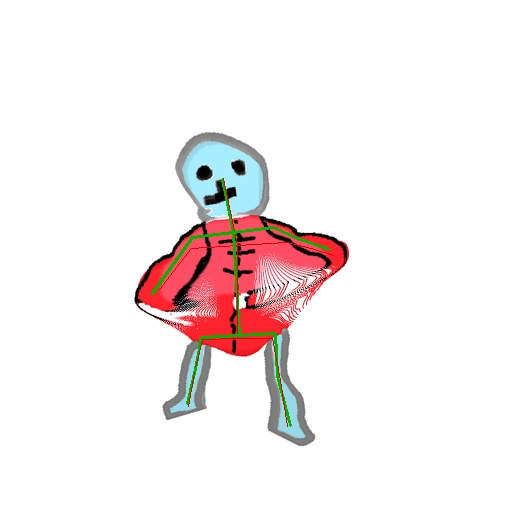

p6__bvh_reach_tiptoe__0_t10.jpg


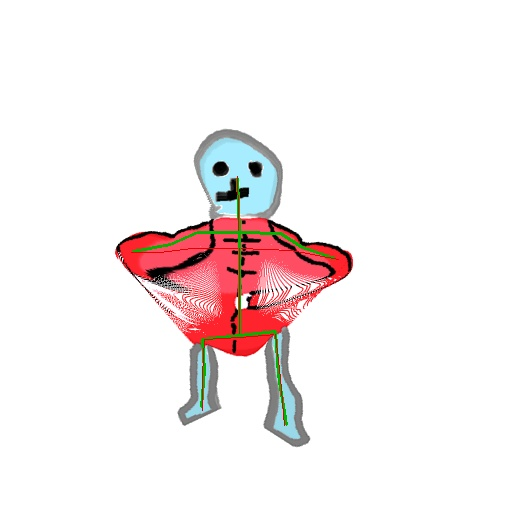

p6__bvh_sad_walk__0_t20.jpg


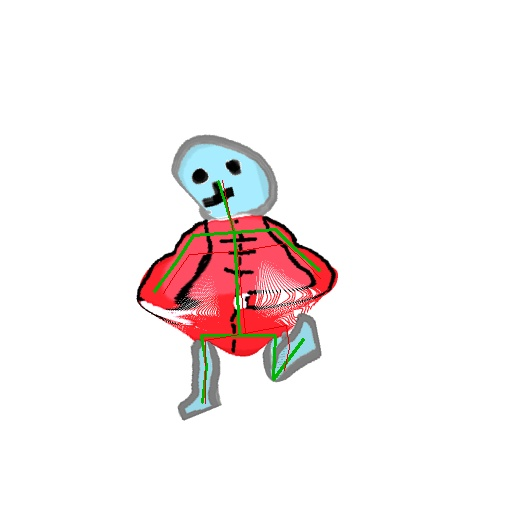

p6__bvh_search_ground__0_t24.jpg


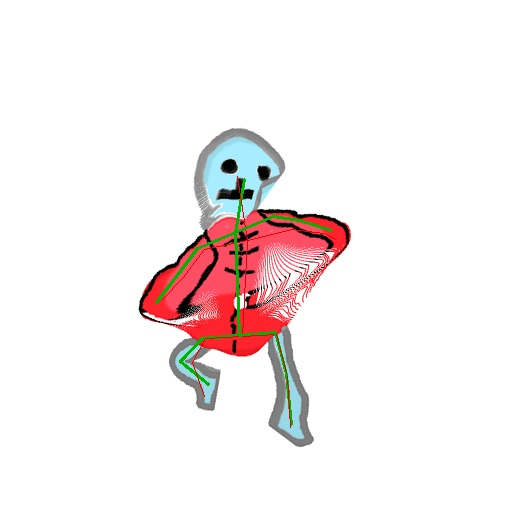

p6__bvh_stand_still__0_t20.jpg


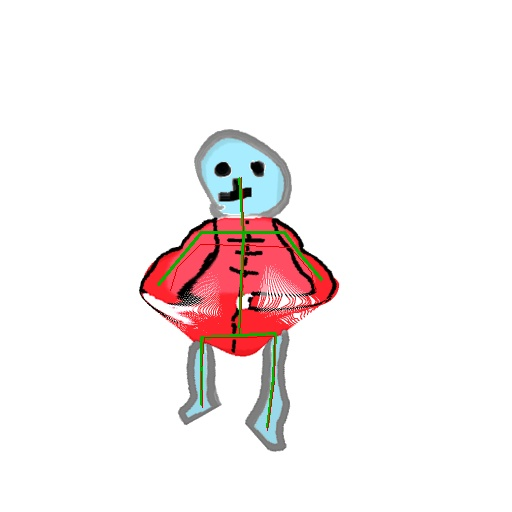

p6__bvh_swim__0_t10.jpg


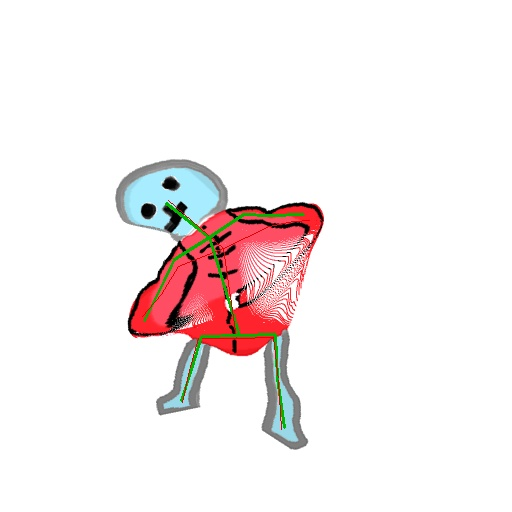

p6__bvh_very_happy__0_t24.jpg


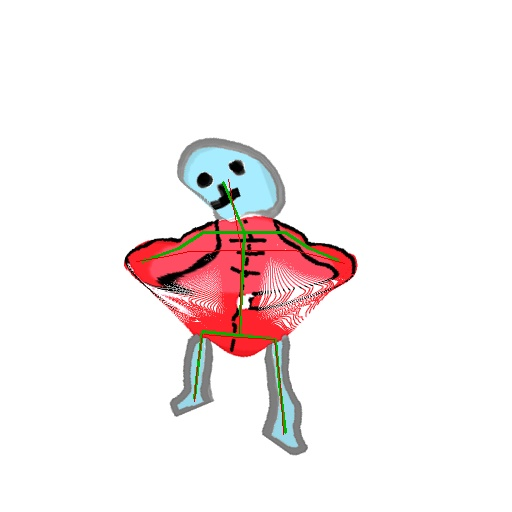

p6__bvh_wave_hello__0_t40.jpg


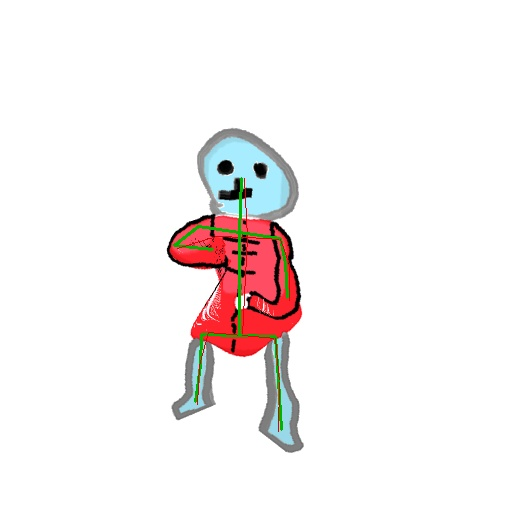

p6__bvh_zombie__0_t42.jpg


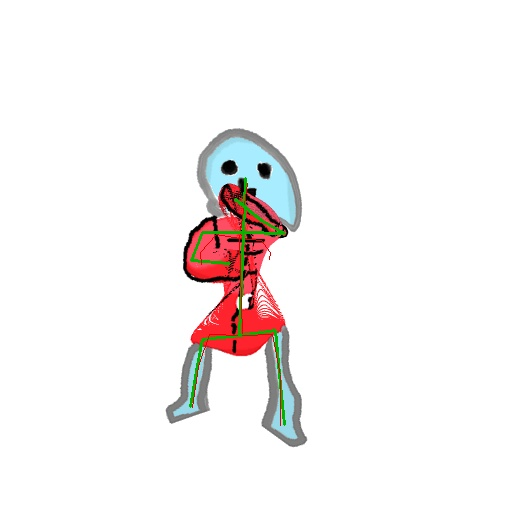

p7__bvh_bird__0_t24.jpg


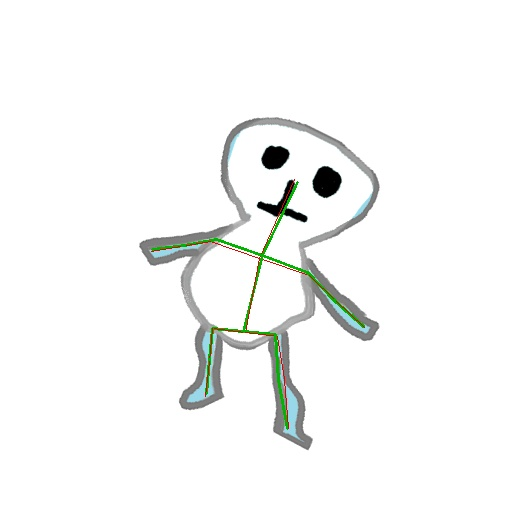

p7__bvh_dab__0_t118.jpg


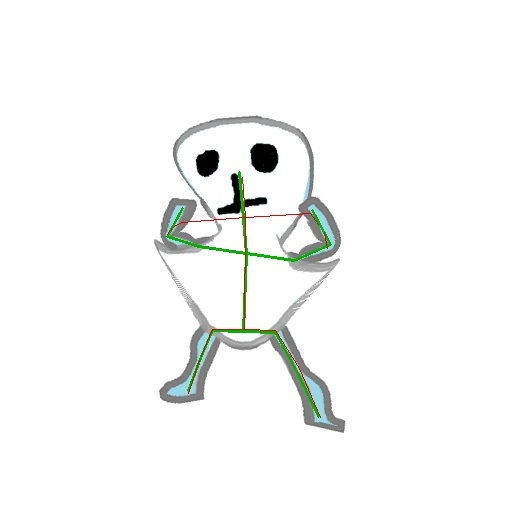

p7__bvh_elephant__0_t42.jpg


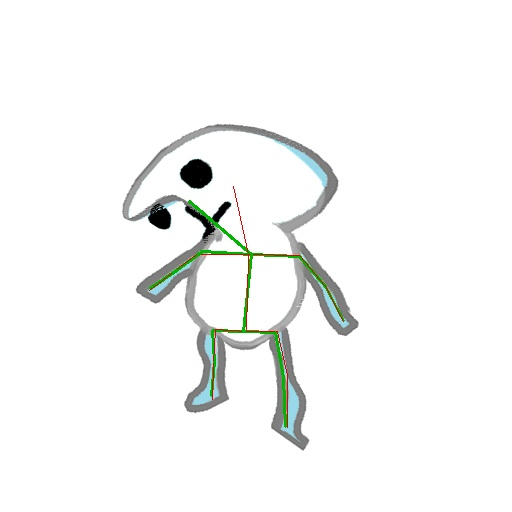

p7__bvh_happy_walk__0_t50.jpg


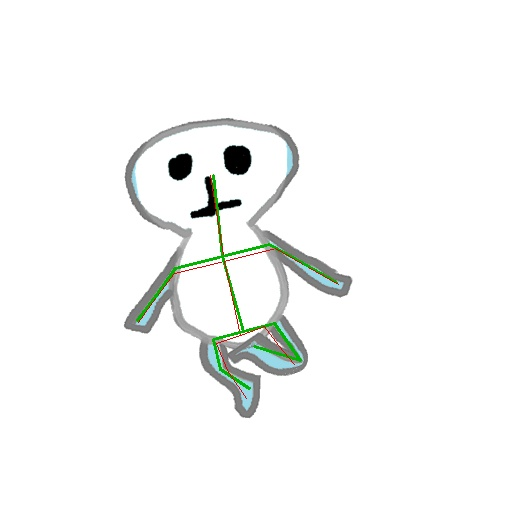

p7__bvh_idle__0_t12.jpg


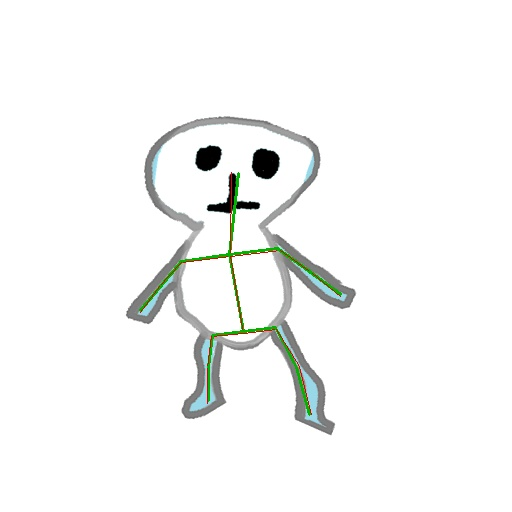

p7__bvh_jesse_dance__0_t12.jpg


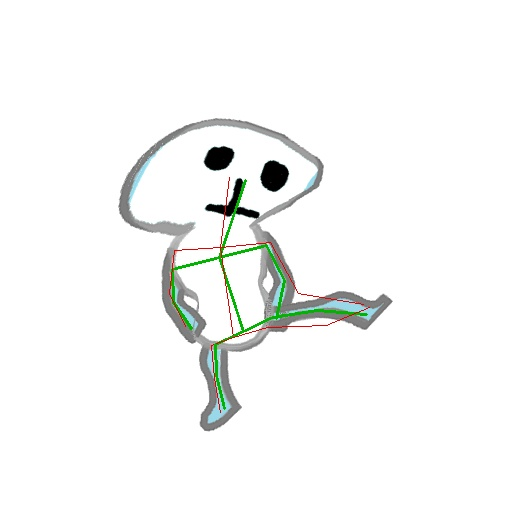

p7__bvh_jumping__0_t24.jpg


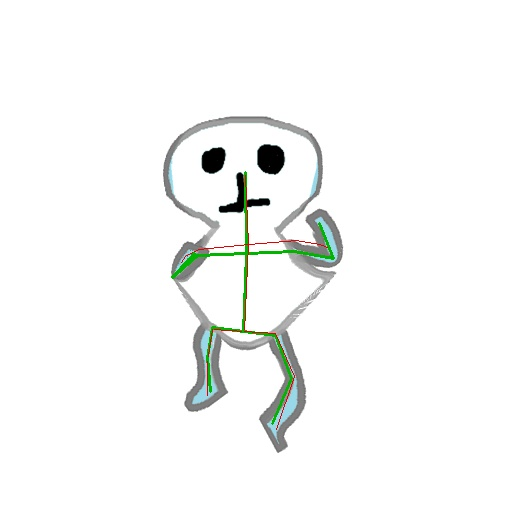

p7__bvh_jumping_jacks__0_t16.jpg


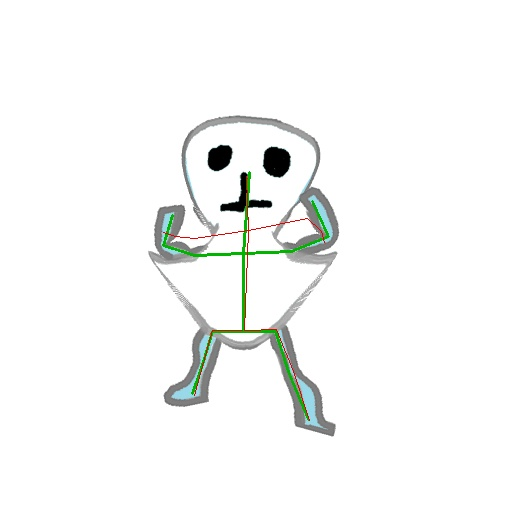

p7__bvh_kick_ball__0_t48.jpg


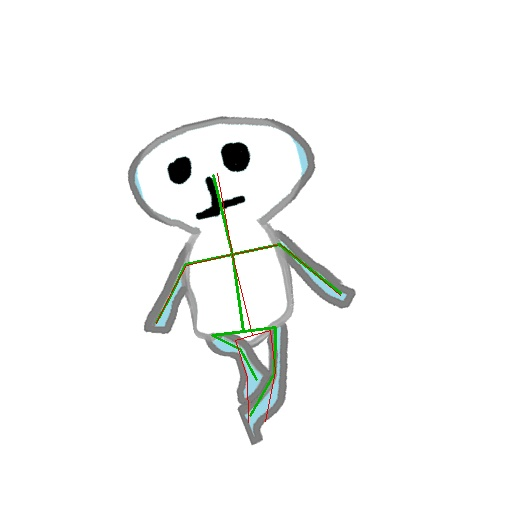

p7__bvh_laugh__0_t40.jpg


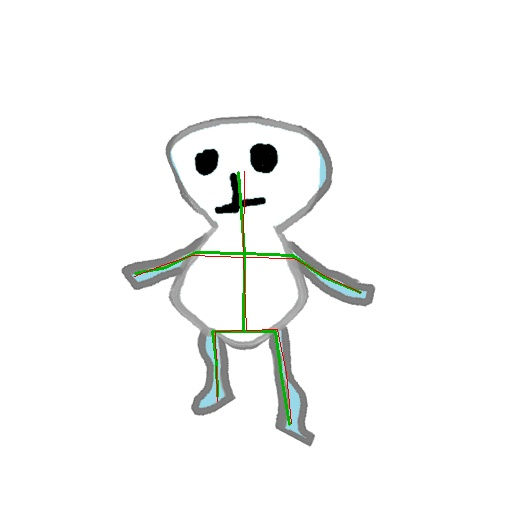

p7__bvh_march__0_t26.jpg


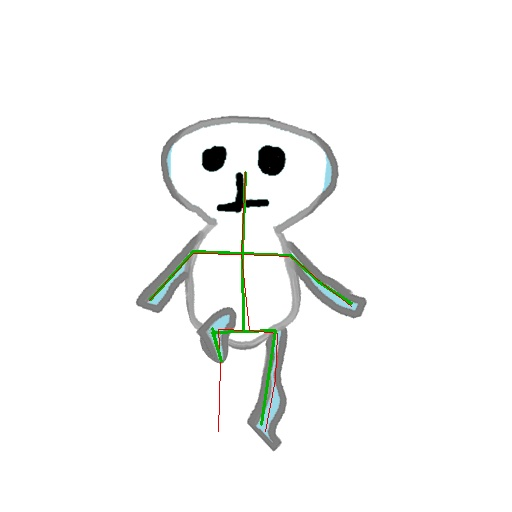

p7__bvh_monkey__0_t44.jpg


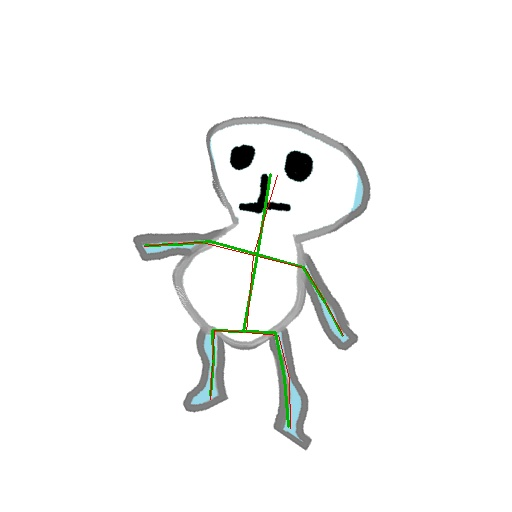

p7__bvh_point__0_t48.jpg


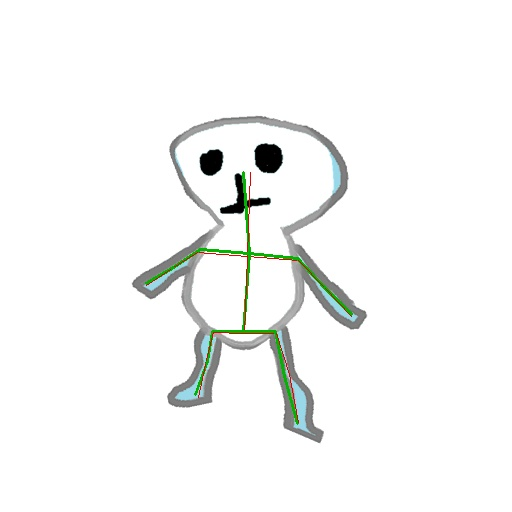

p7__bvh_reach_tiptoe__0_t22.jpg


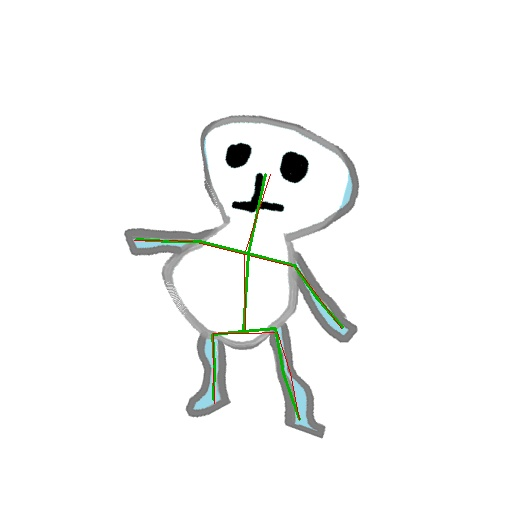

p7__bvh_sad_walk__0_t38.jpg


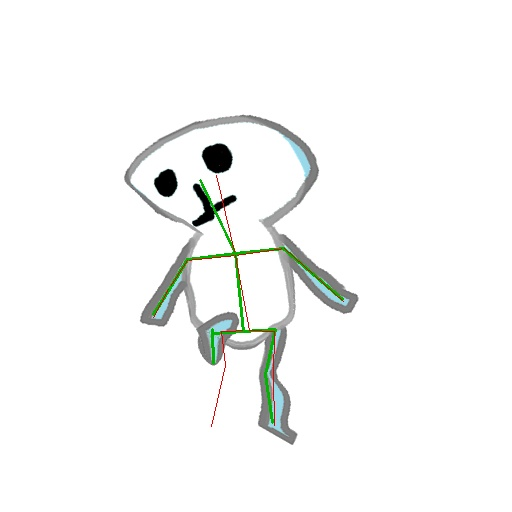

p7__bvh_search_ground__0_t40.jpg


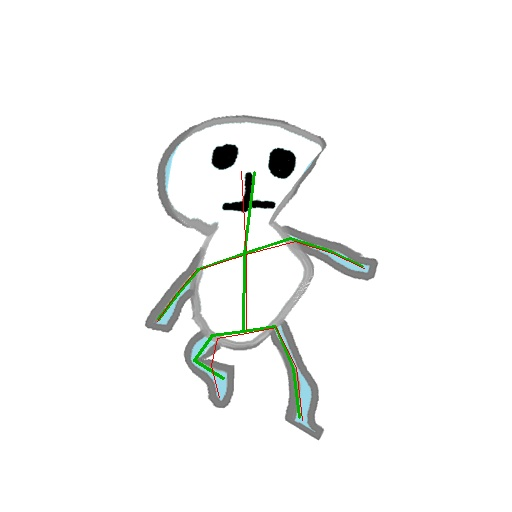

p7__bvh_stand_still__0_t8.jpg


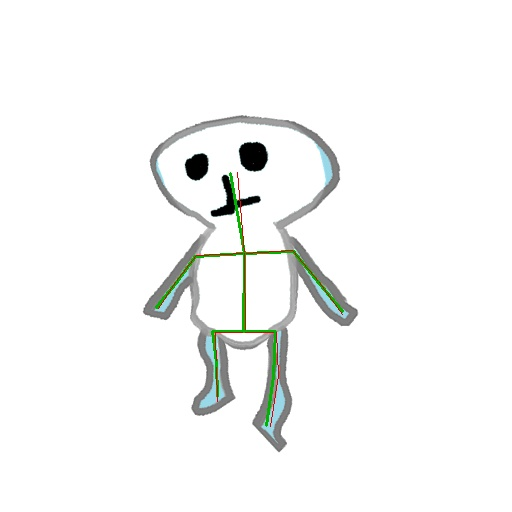

p7__bvh_swim__0_t26.jpg


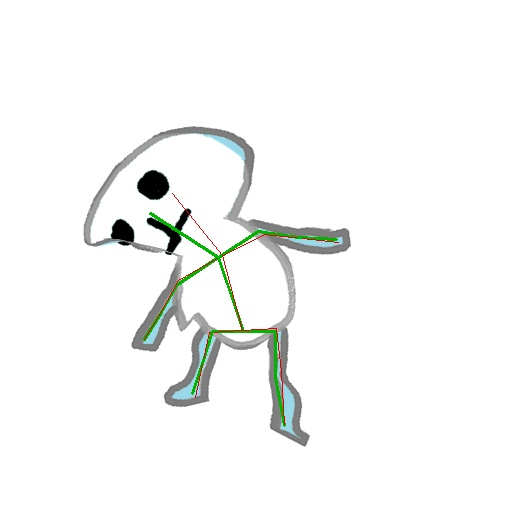

p7__bvh_very_happy__0_t24.jpg


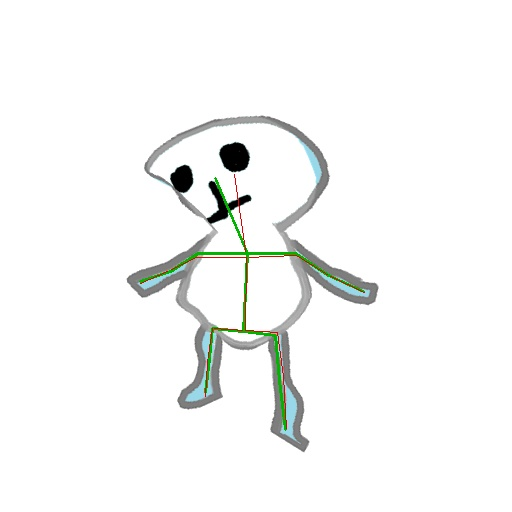

p7__bvh_wave_hello__0_t34.jpg


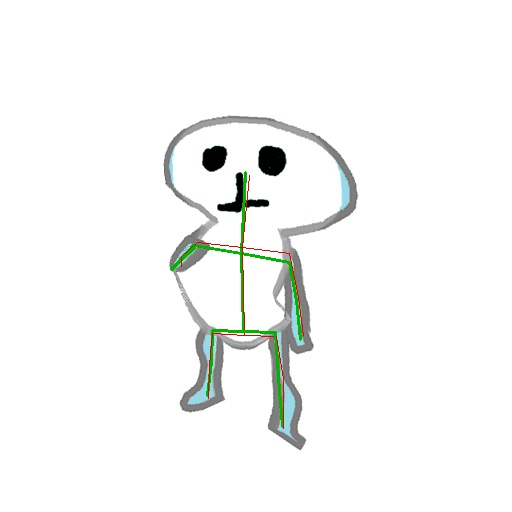

p7__bvh_zombie__0_t48.jpg


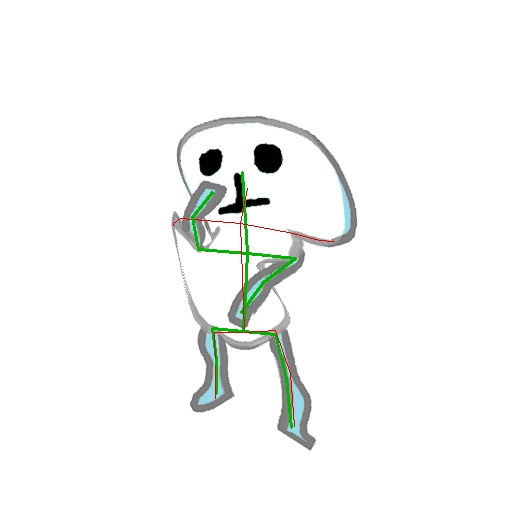

p8__bvh_bird__0_t28.jpg


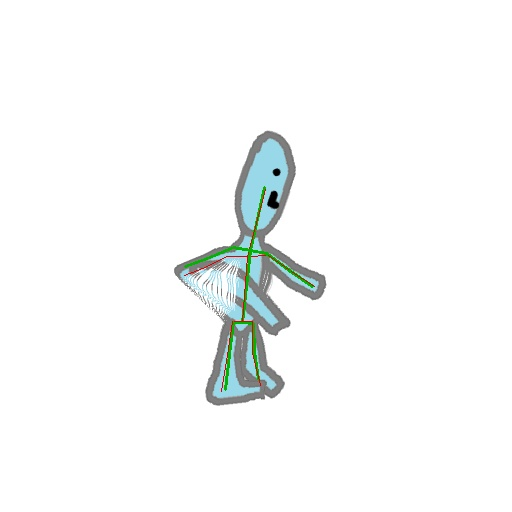

p8__bvh_dab__0_t54.jpg


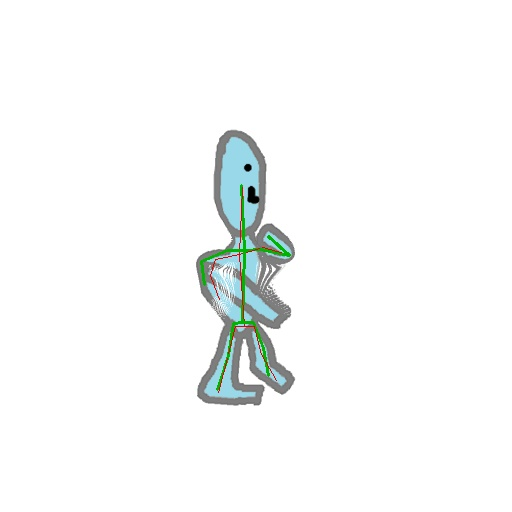

p8__bvh_elephant__0_t42.jpg


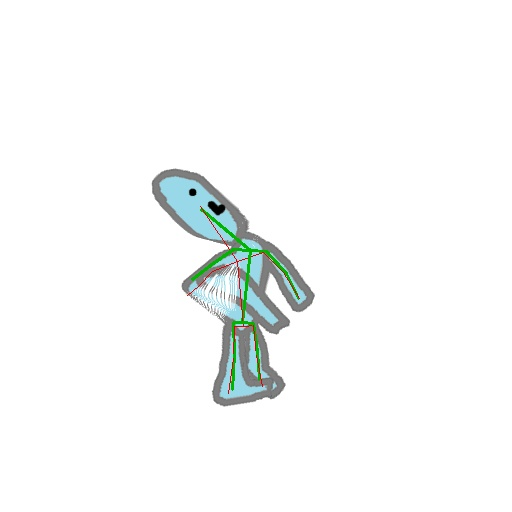

p8__bvh_happy_walk__0_t30.jpg


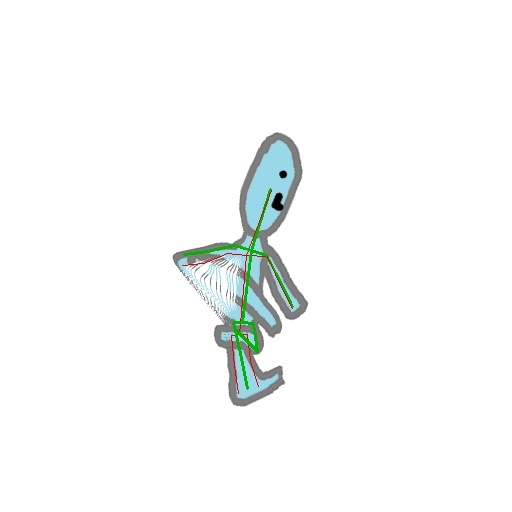

p8__bvh_idle__0_t28.jpg


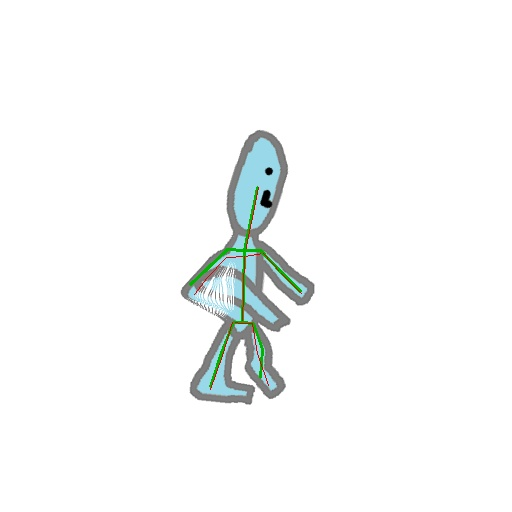

p8__bvh_jesse_dance__0_t130.jpg


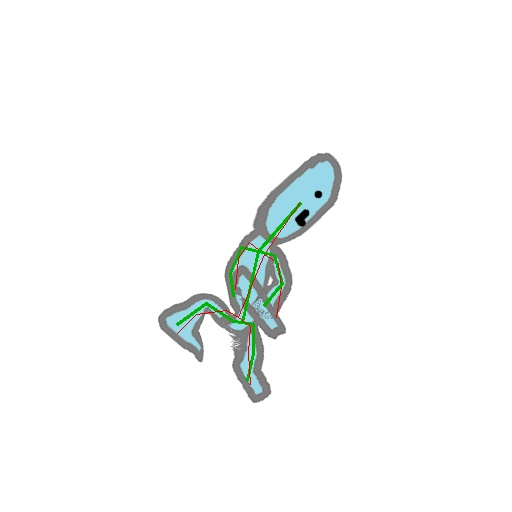

p8__bvh_jumping__0_t32.jpg


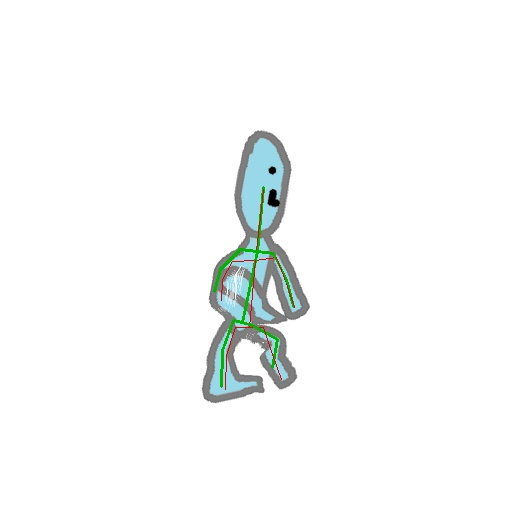

p8__bvh_jumping_jacks__0_t54.jpg


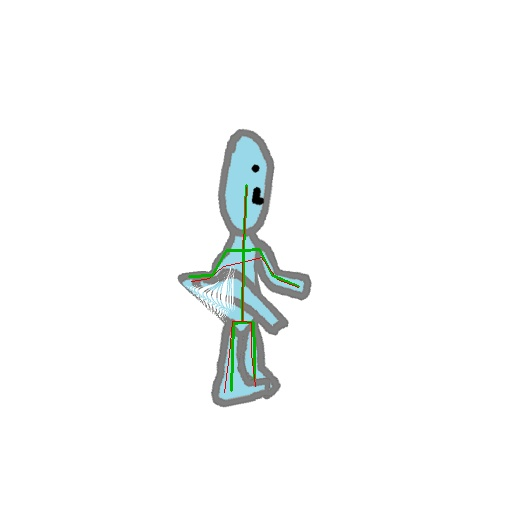

p8__bvh_kick_ball__0_t48.jpg


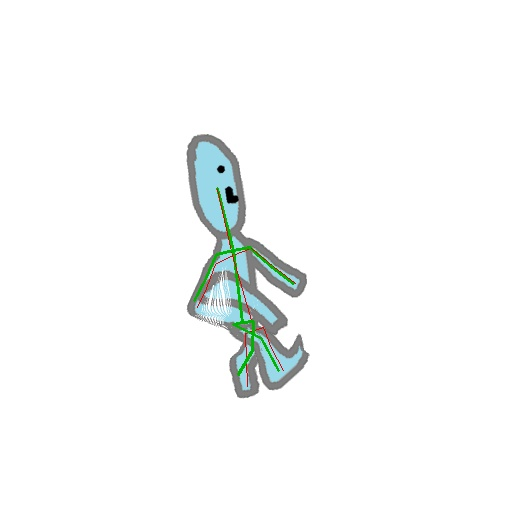

p8__bvh_laugh__0_t44.jpg


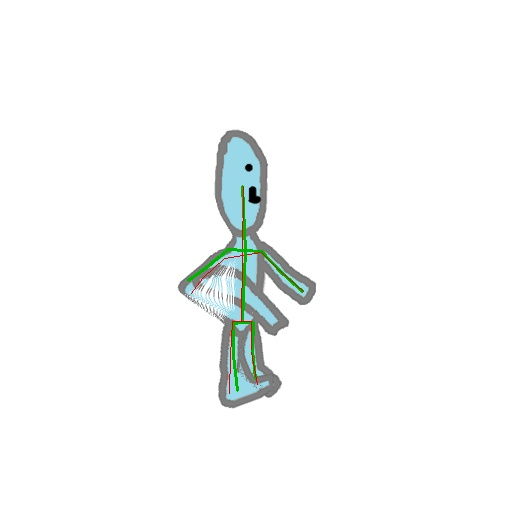

p8__bvh_march__0_t26.jpg


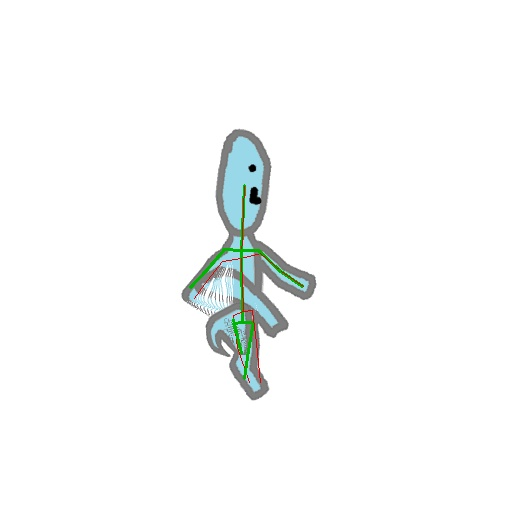

p8__bvh_monkey__0_t16.jpg


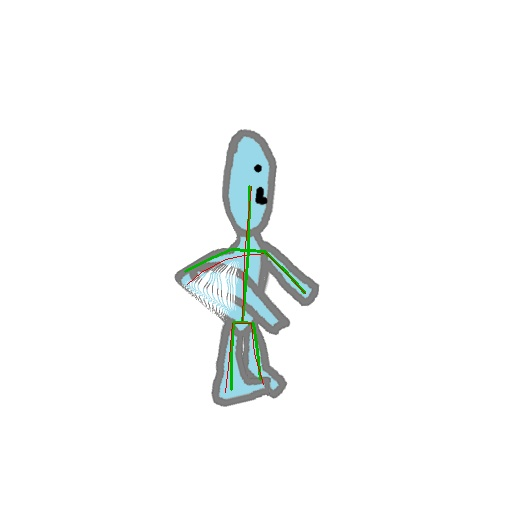

p8__bvh_point__0_t14.jpg


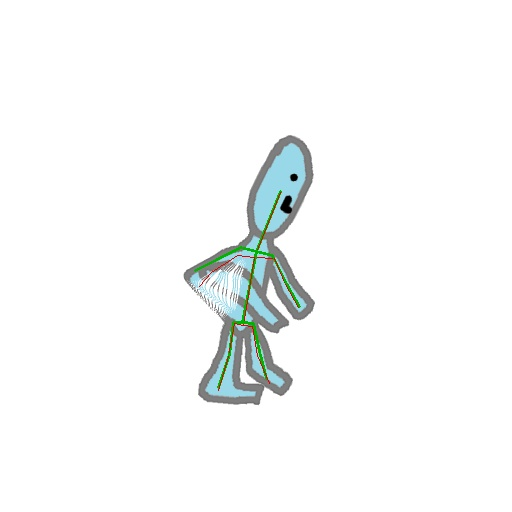

p8__bvh_reach_tiptoe__0_t8.jpg


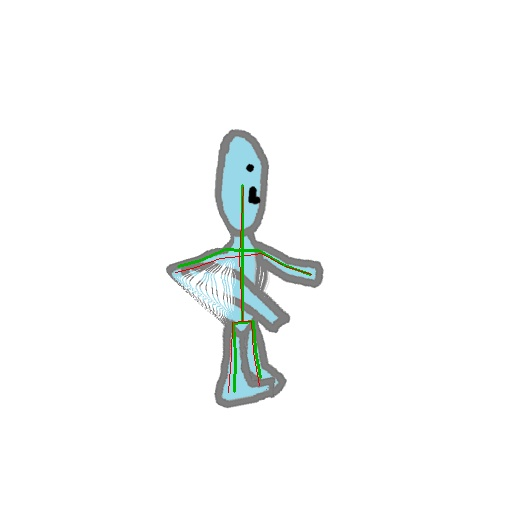

p8__bvh_sad_walk__0_t40.jpg


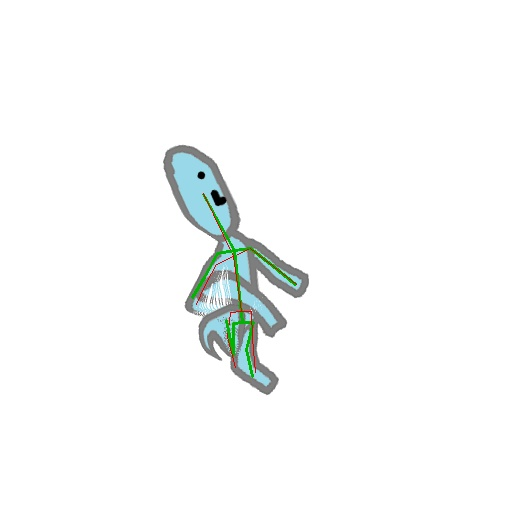

p8__bvh_search_ground__0_t42.jpg


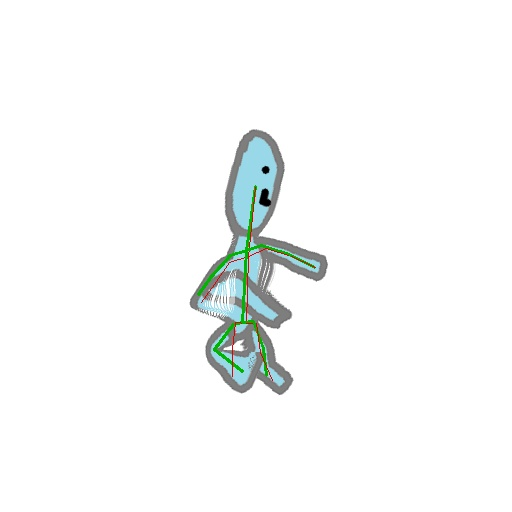

p8__bvh_stand_still__0_t32.jpg


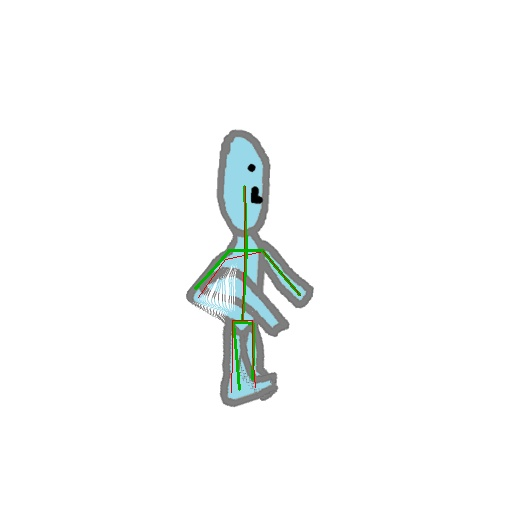

p8__bvh_swim__0_t28.jpg


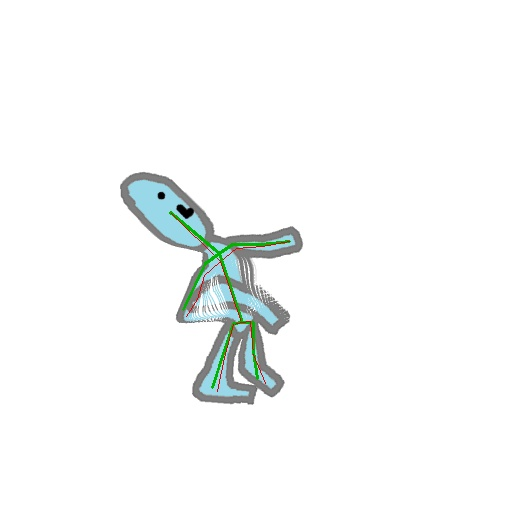

p8__bvh_very_happy__0_t26.jpg


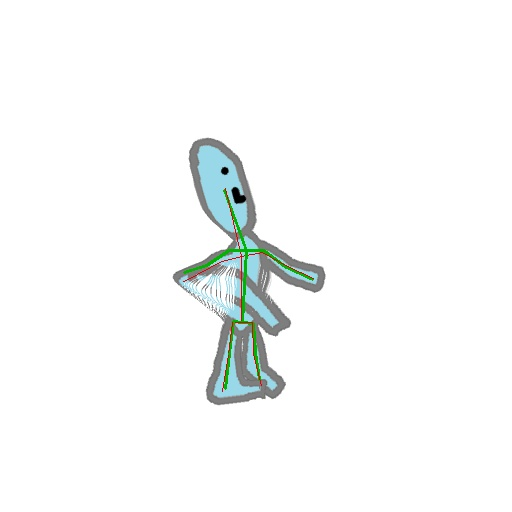

p8__bvh_wave_hello__0_t40.jpg


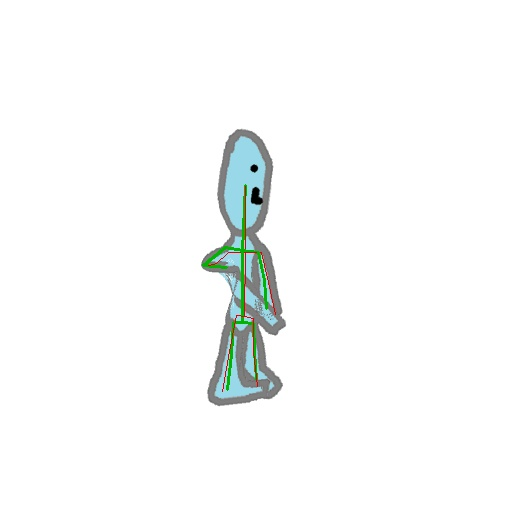

p8__bvh_zombie__0_t62.jpg


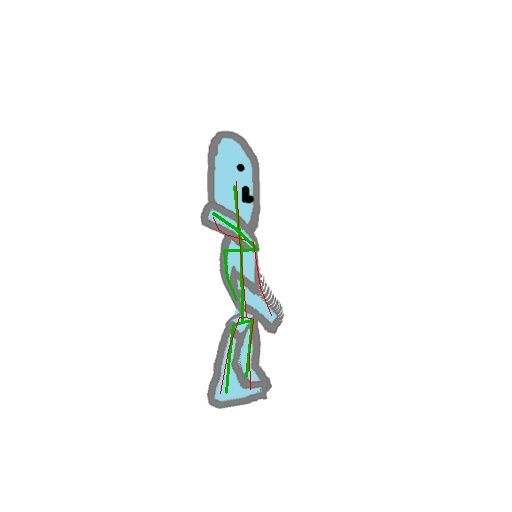

p9__bvh_bird__0_t24.jpg


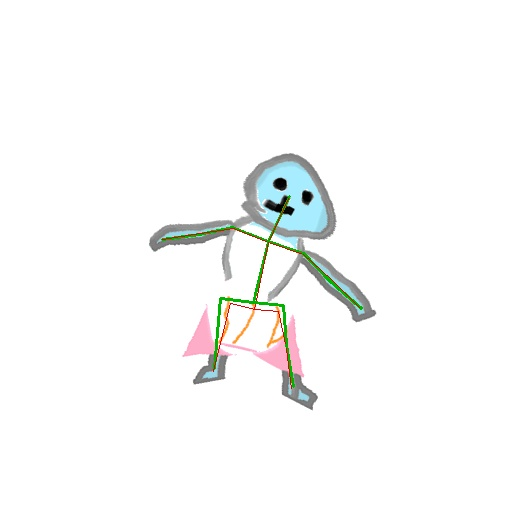

p9__bvh_dab__0_t98.jpg


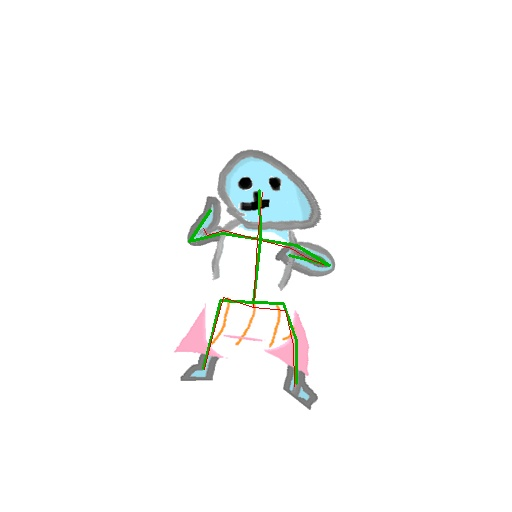

p9__bvh_elephant__0_t10.jpg


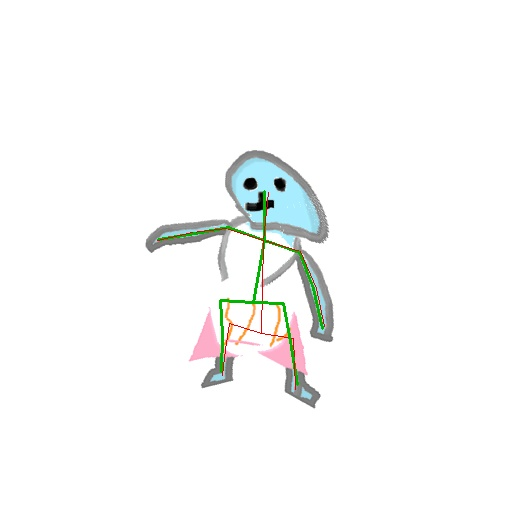

p9__bvh_happy_walk__0_t30.jpg


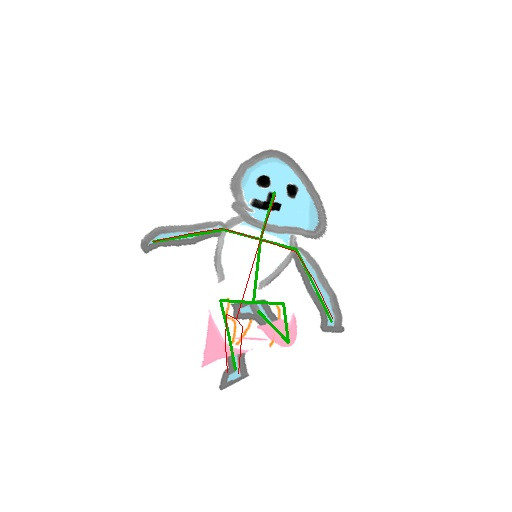

p9__bvh_idle__0_t14.jpg


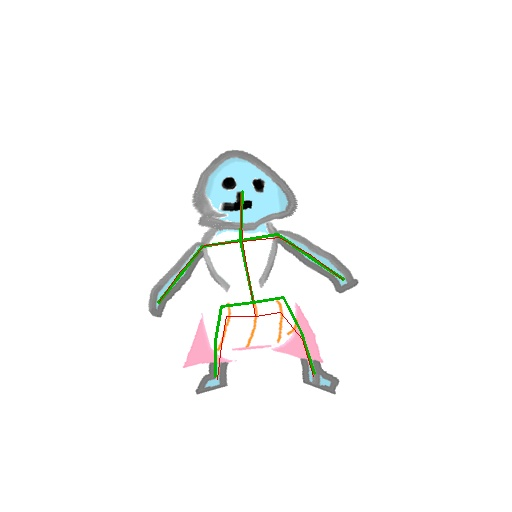

p9__bvh_jesse_dance__0_t14.jpg


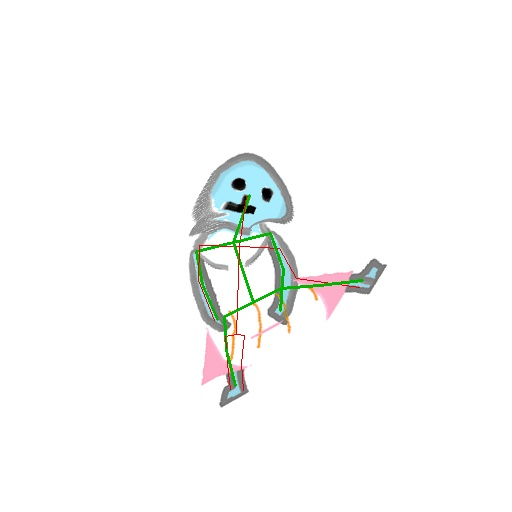

p9__bvh_jumping__0_t62.jpg


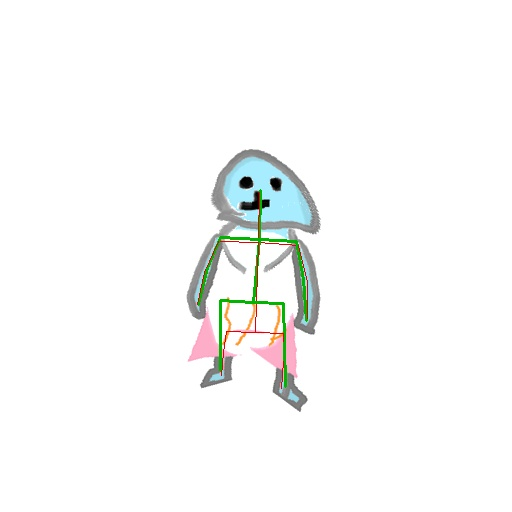

p9__bvh_jumping_jacks__0_t58.jpg


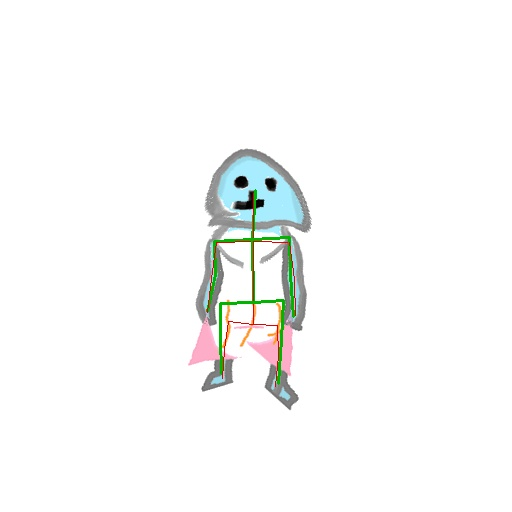

p9__bvh_kick_ball__0_t46.jpg


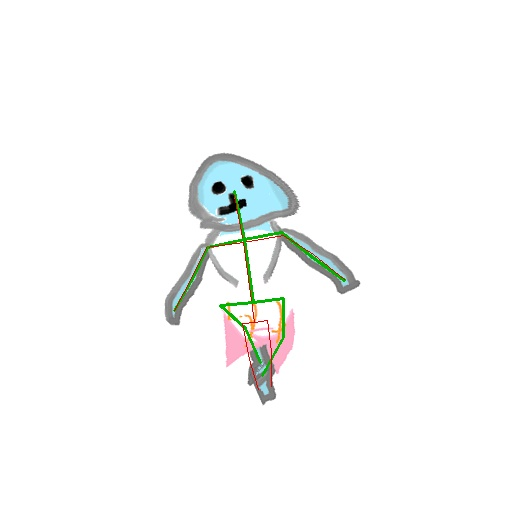

p9__bvh_laugh__0_t24.jpg


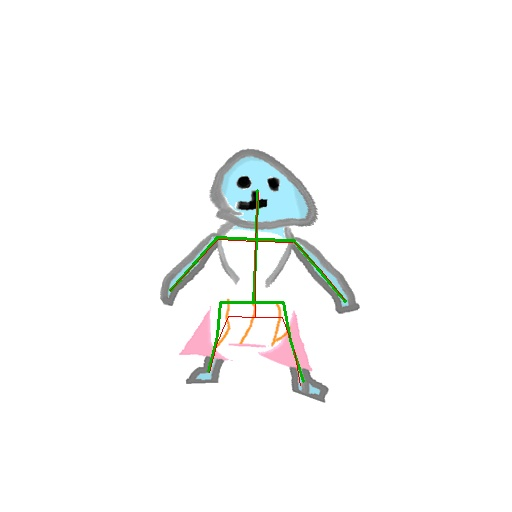

p9__bvh_march__0_t34.jpg


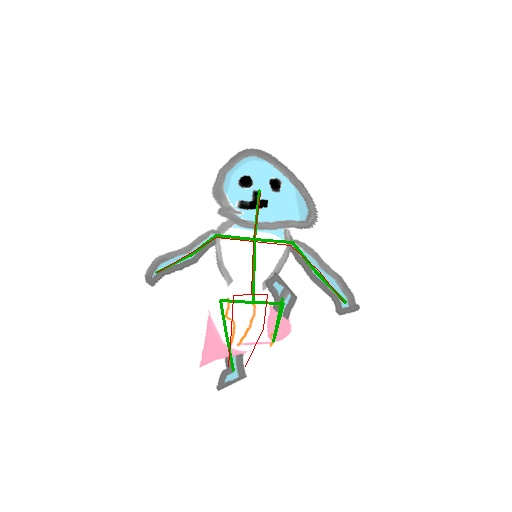

p9__bvh_monkey__0_t44.jpg


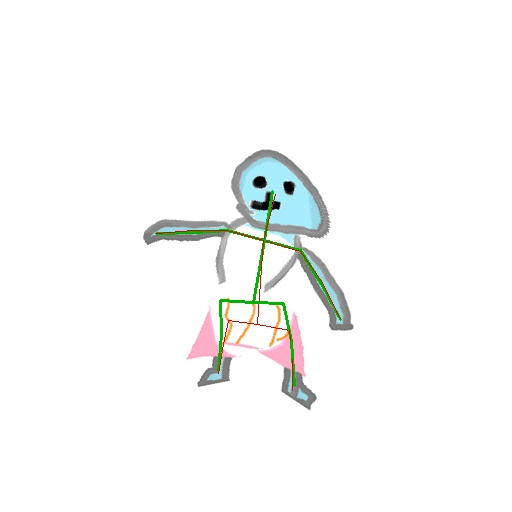

p9__bvh_point__0_t16.jpg


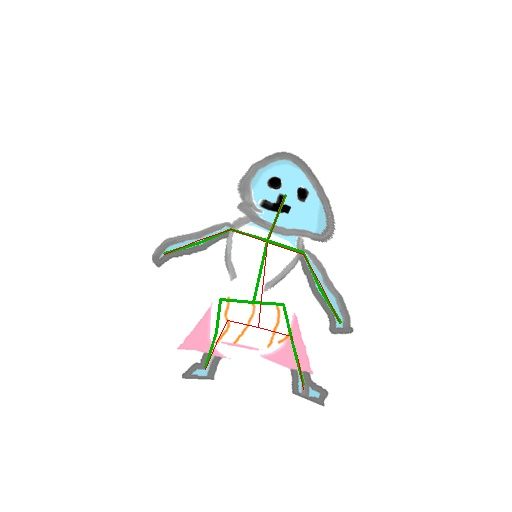

p9__bvh_reach_tiptoe__0_t22.jpg


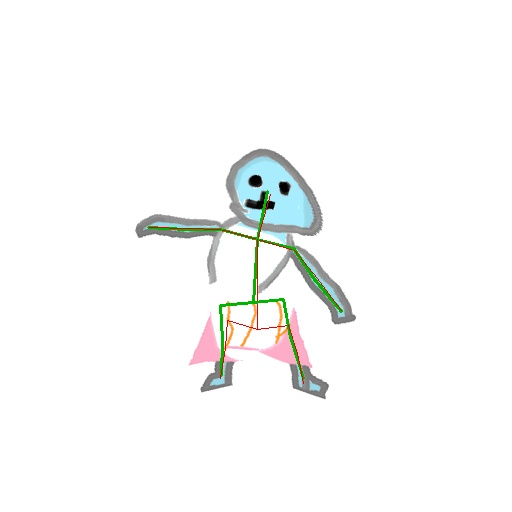

p9__bvh_sad_walk__0_t40.jpg


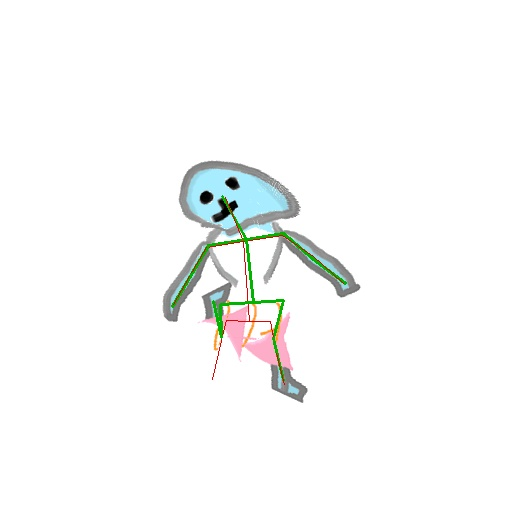

p9__bvh_search_ground__0_t40.jpg


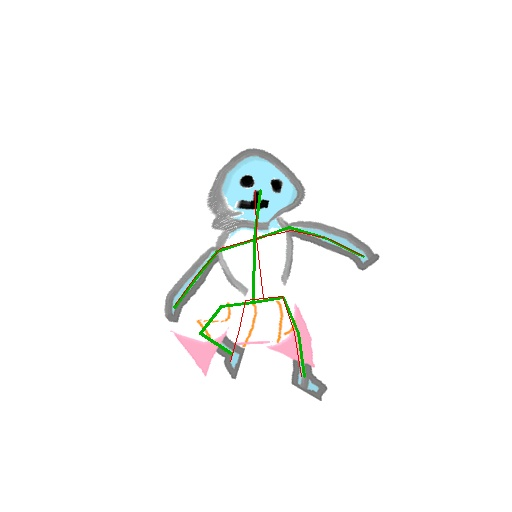

p9__bvh_stand_still__0_t30.jpg


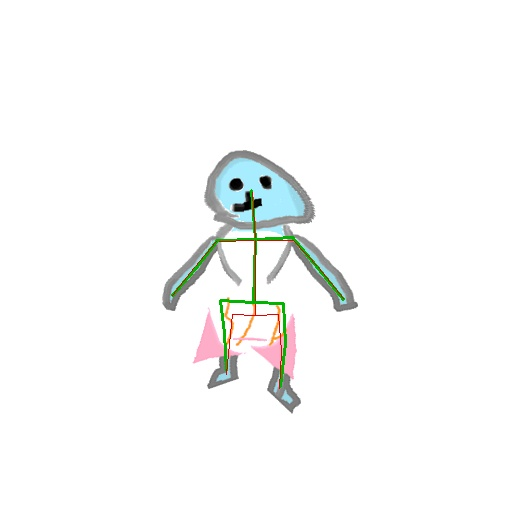

p9__bvh_swim__0_t28.jpg


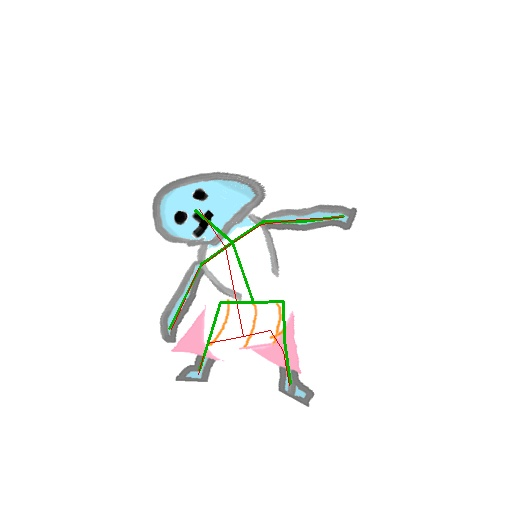

p9__bvh_very_happy__0_t38.jpg


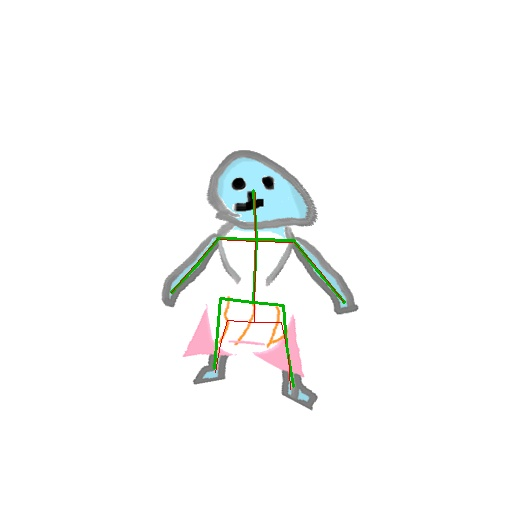

p9__bvh_wave_hello__0_t32.jpg


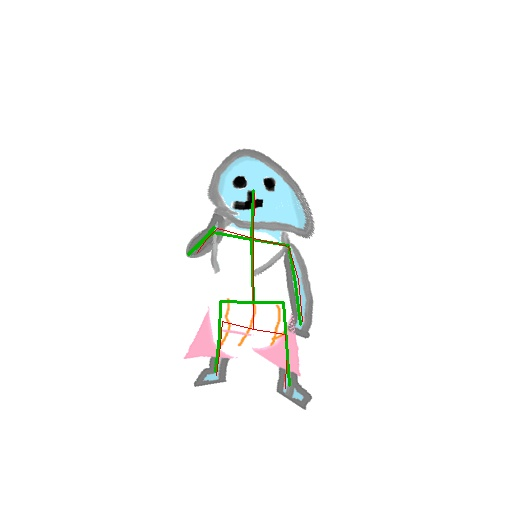

p9__bvh_zombie__0_t26.jpg


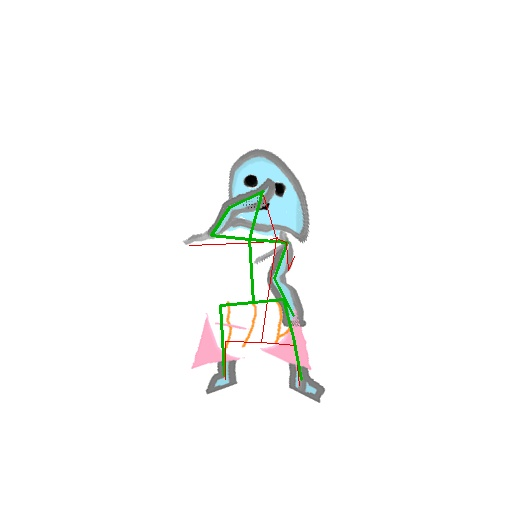

t10__bvh_bird__0_t34.jpg


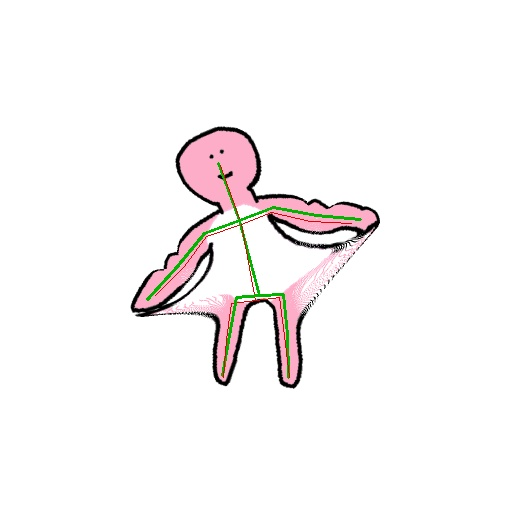

t10__bvh_dab__0_t98.jpg


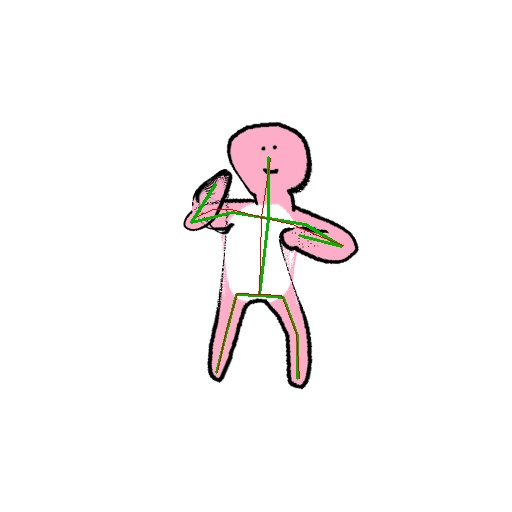

t10__bvh_elephant__0_t42.jpg


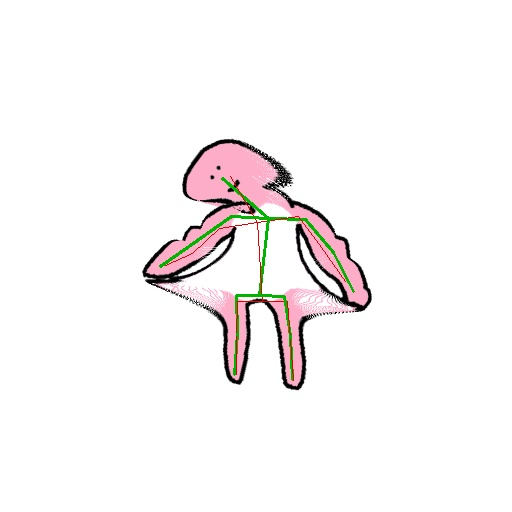

t10__bvh_happy_walk__0_t30.jpg


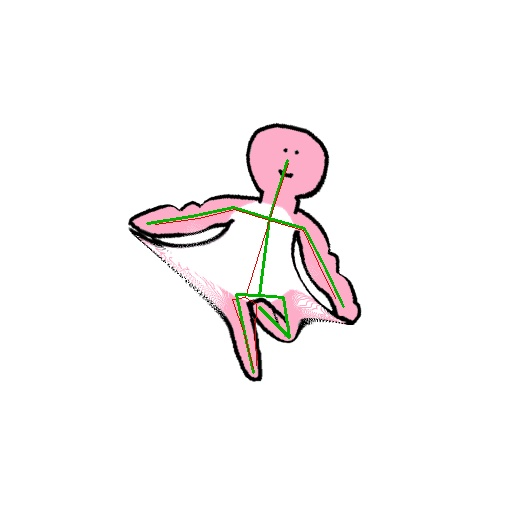

t10__bvh_idle__0_t12.jpg


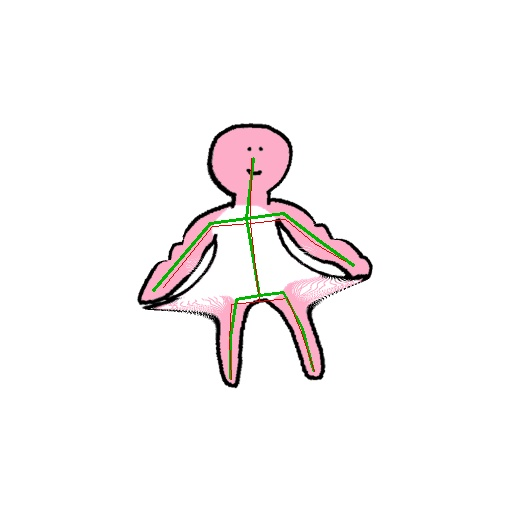

t10__bvh_jesse_dance__0_t30.jpg


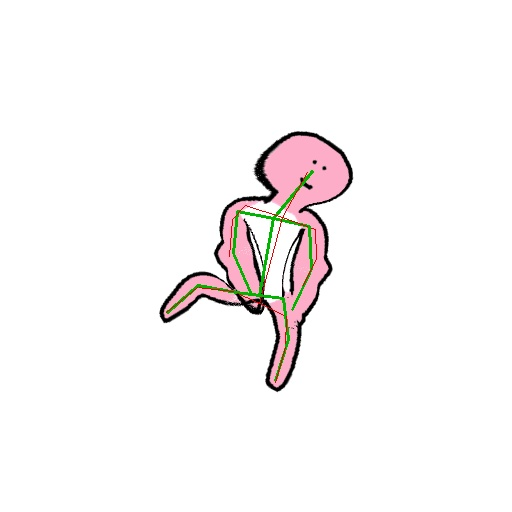

t10__bvh_jumping__0_t24.jpg


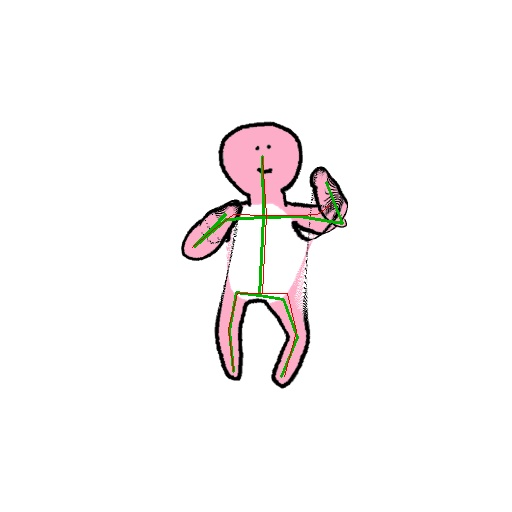

t10__bvh_jumping_jacks__0_t16.jpg


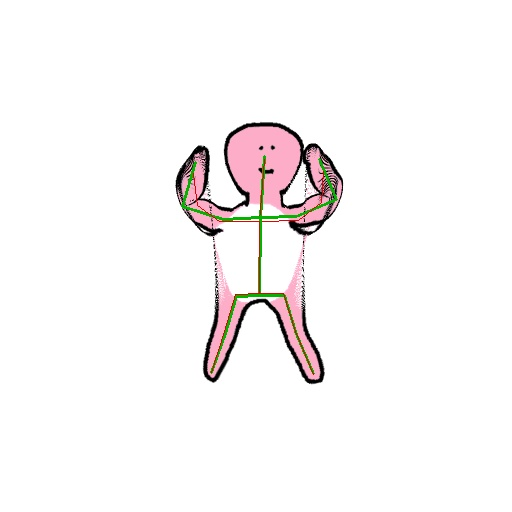

t10__bvh_kick_ball__0_t48.jpg


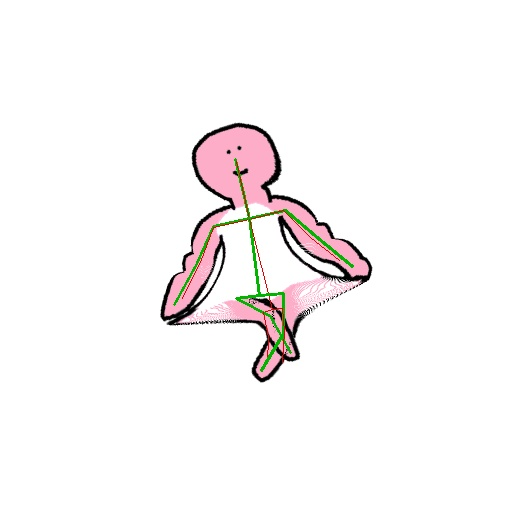

t10__bvh_laugh__0_t14.jpg


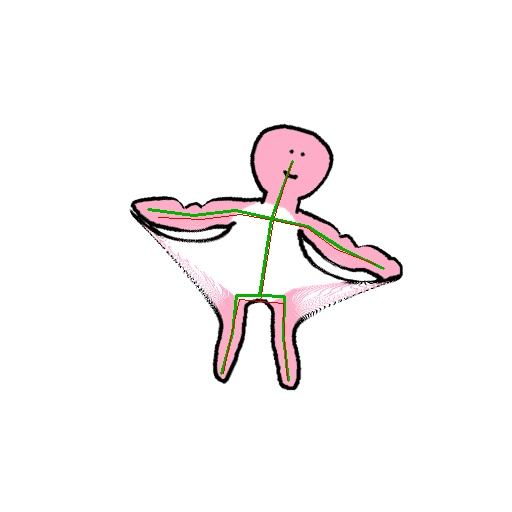

t10__bvh_march__0_t30.jpg


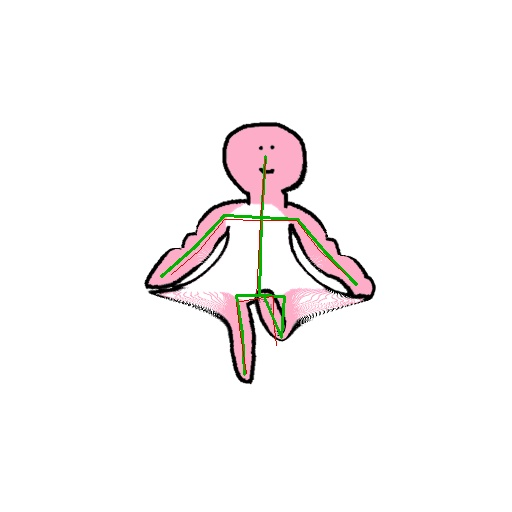

t10__bvh_monkey__0_t8.jpg


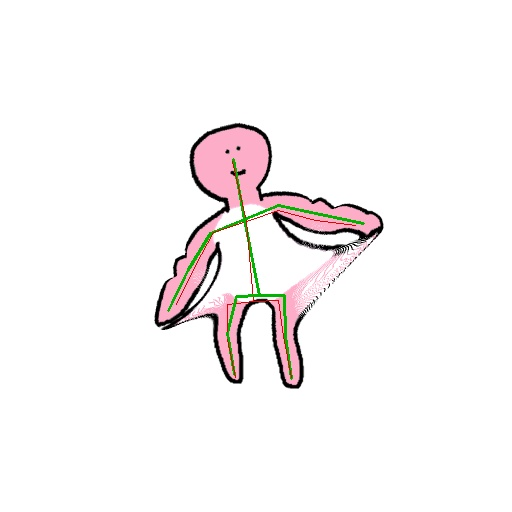

t10__bvh_point__0_t40.jpg


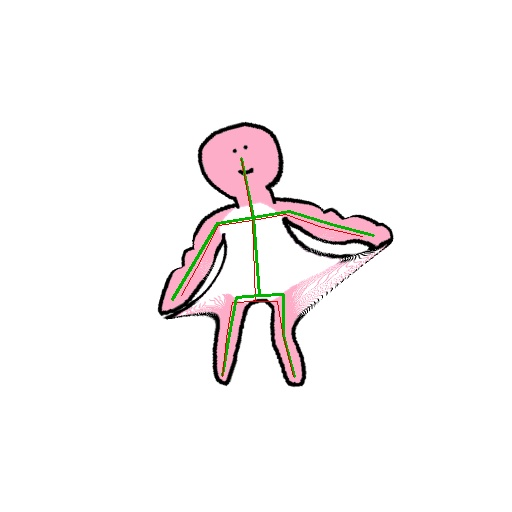

t10__bvh_reach_tiptoe__0_t24.jpg


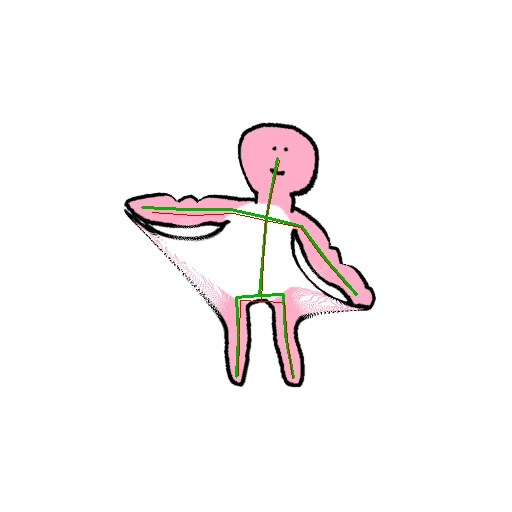

t10__bvh_sad_walk__0_t40.jpg


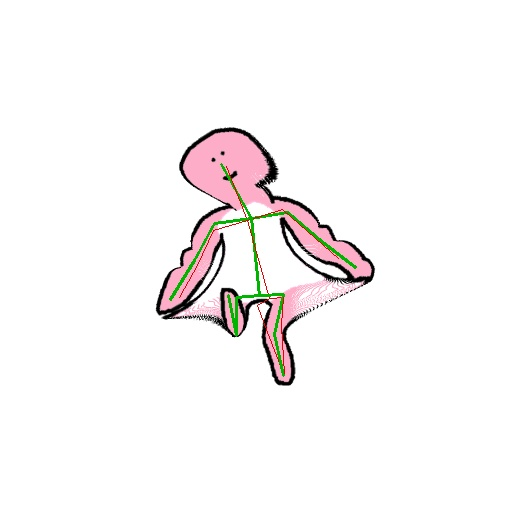

t10__bvh_search_ground__0_t40.jpg


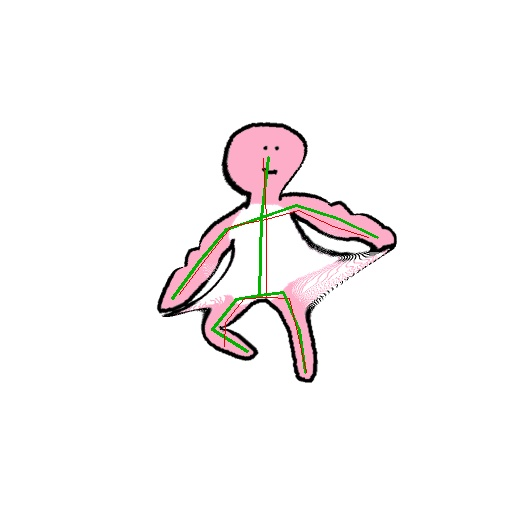

t10__bvh_stand_still__0_t24.jpg


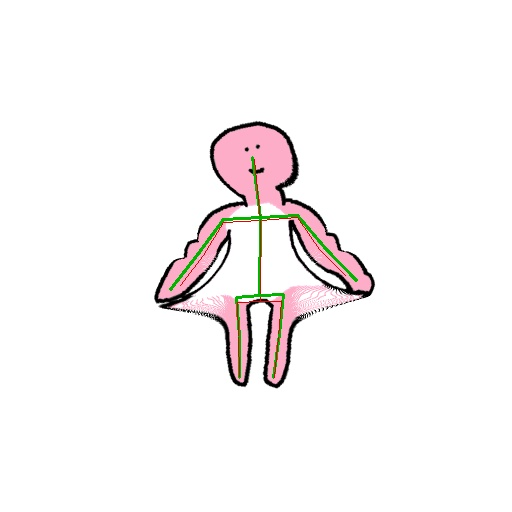

t10__bvh_swim__0_t26.jpg


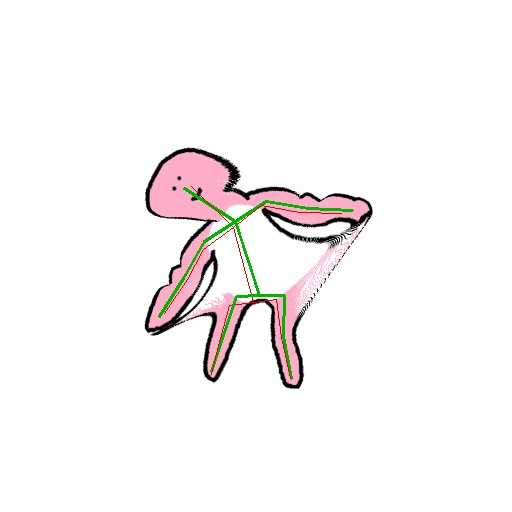

t10__bvh_very_happy__0_t18.jpg


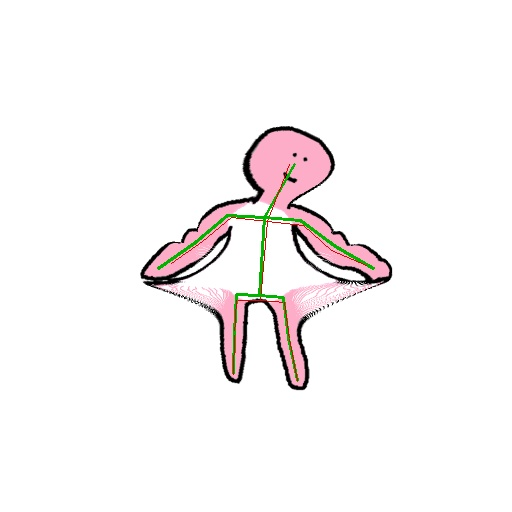

t10__bvh_wave_hello__0_t38.jpg


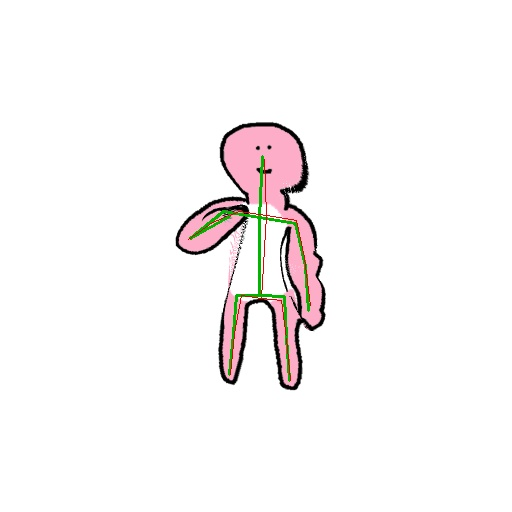

t10__bvh_zombie__0_t46.jpg


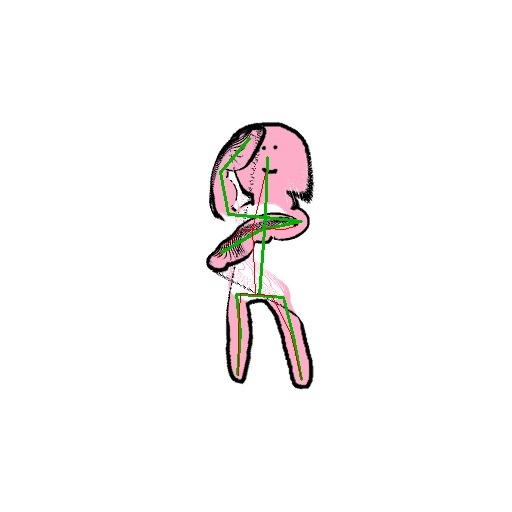

t1__bvh_bird__0_t12.jpg


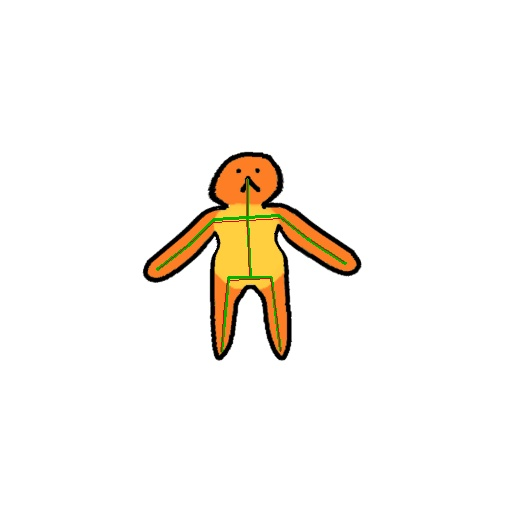

t1__bvh_dab__0_t98.jpg


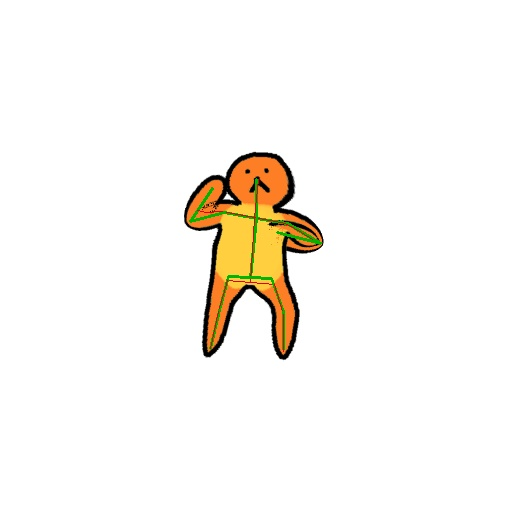

t1__bvh_elephant__0_t40.jpg


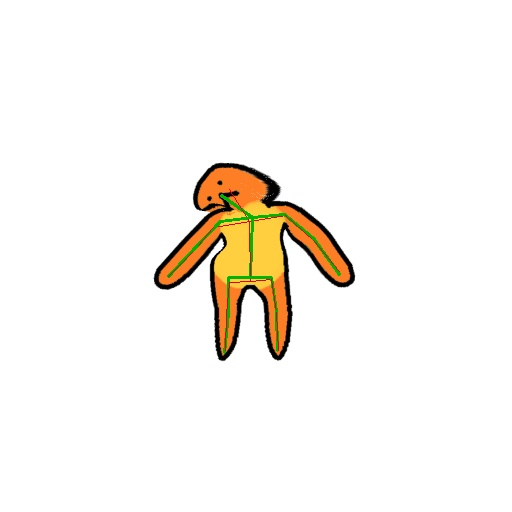

t1__bvh_happy_walk__0_t50.jpg


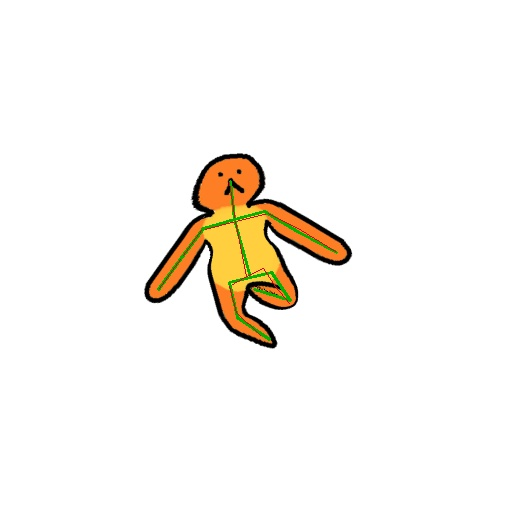

t1__bvh_idle__0_t38.jpg


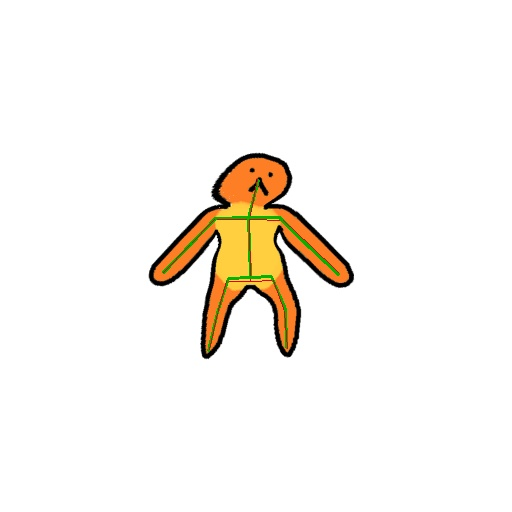

t1__bvh_jesse_dance__0_t30.jpg


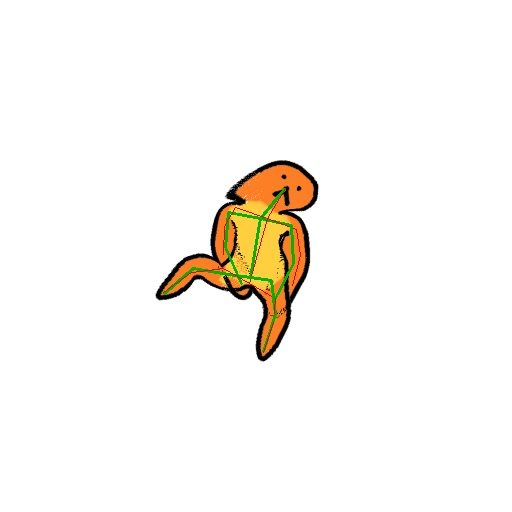

t1__bvh_jumping__0_t24.jpg


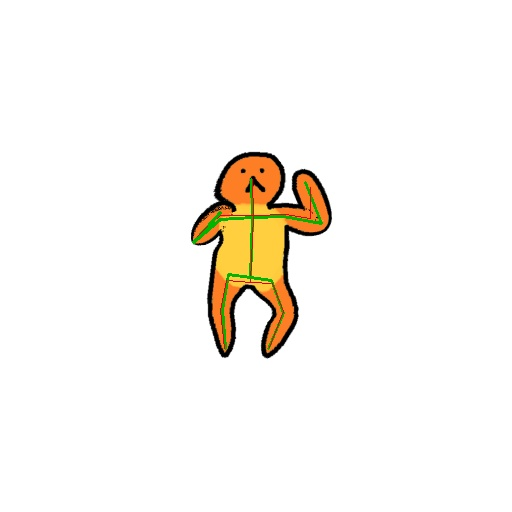

t1__bvh_jumping_jacks__0_t22.jpg


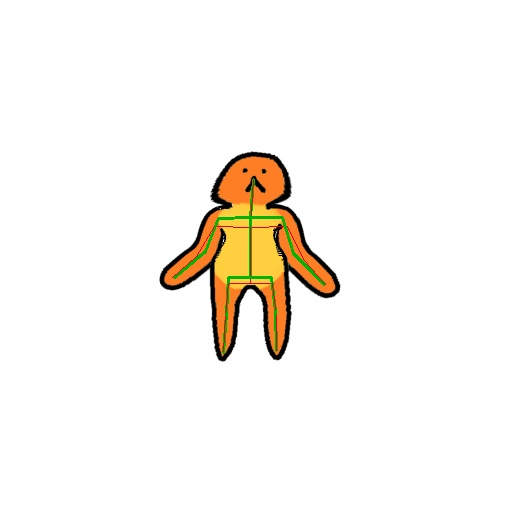

t1__bvh_kick_ball__0_t48.jpg


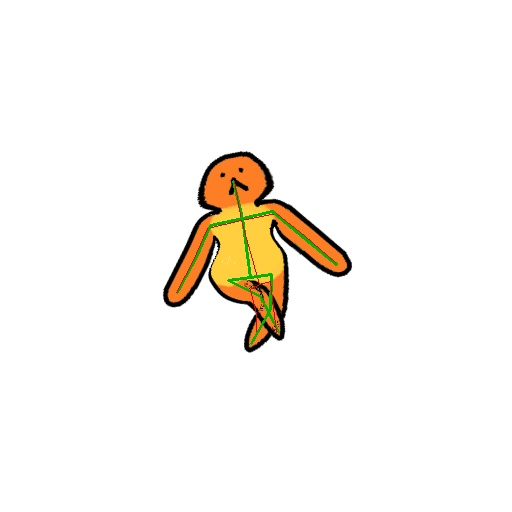

t1__bvh_laugh__0_t46.jpg


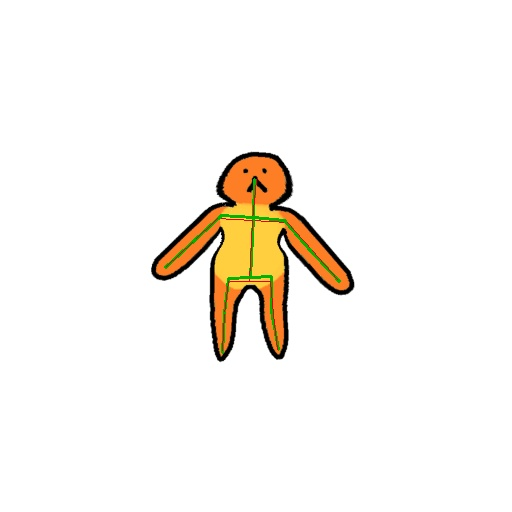

t1__bvh_march__0_t30.jpg


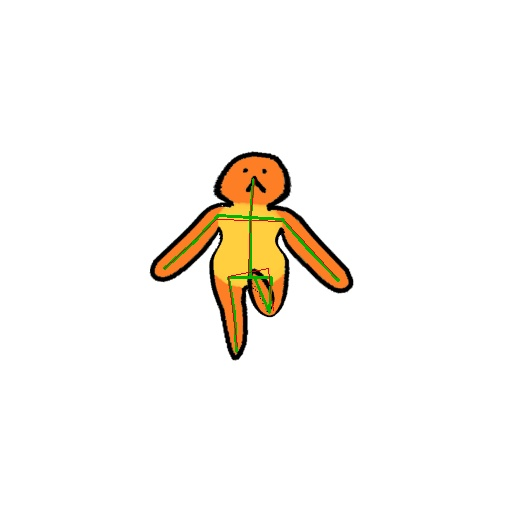

t1__bvh_monkey__0_t40.jpg


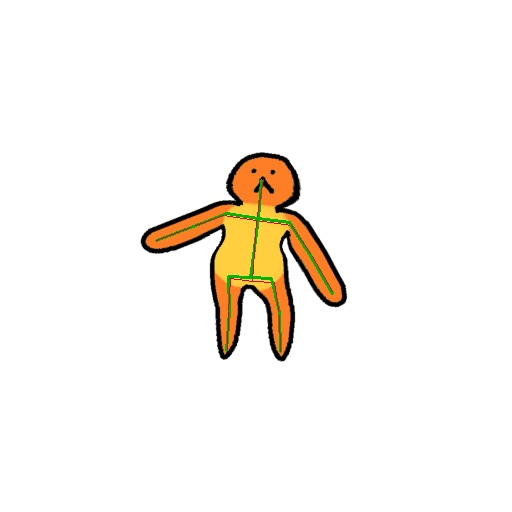

t1__bvh_point__0_t8.jpg


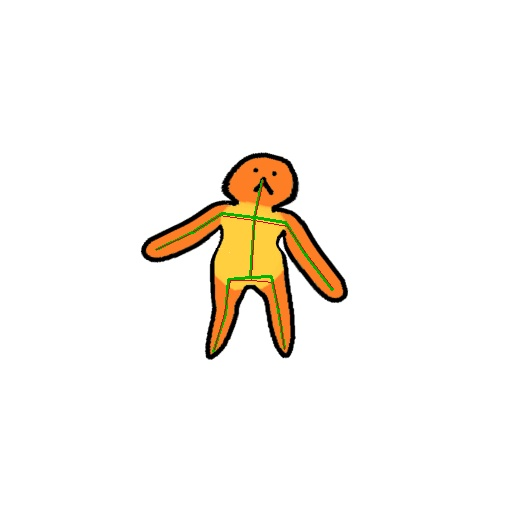

t1__bvh_reach_tiptoe__0_t20.jpg


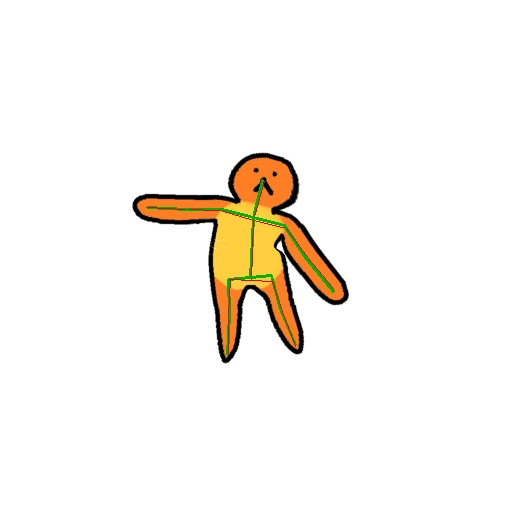

t1__bvh_sad_walk__0_t54.jpg


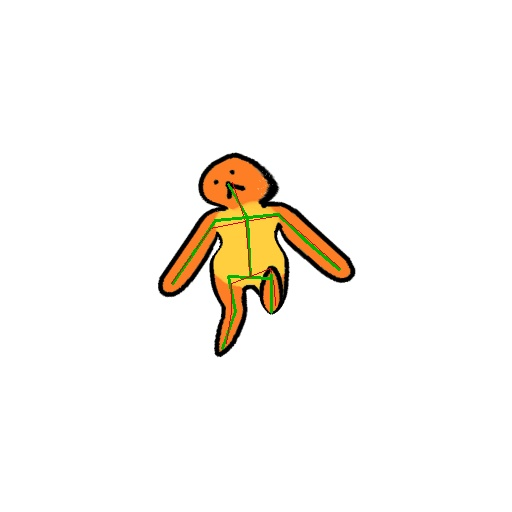

t1__bvh_search_ground__0_t40.jpg


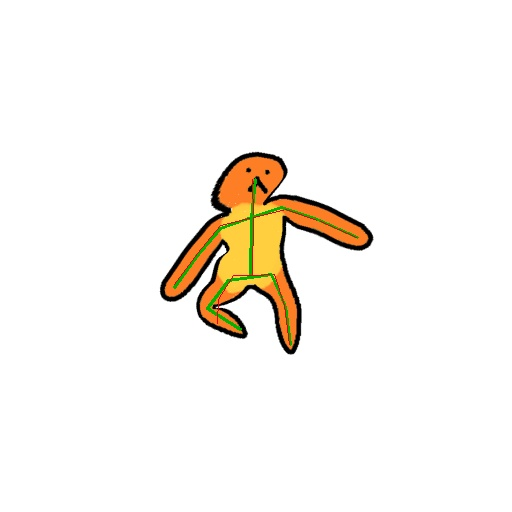

t1__bvh_stand_still__0_t8.jpg


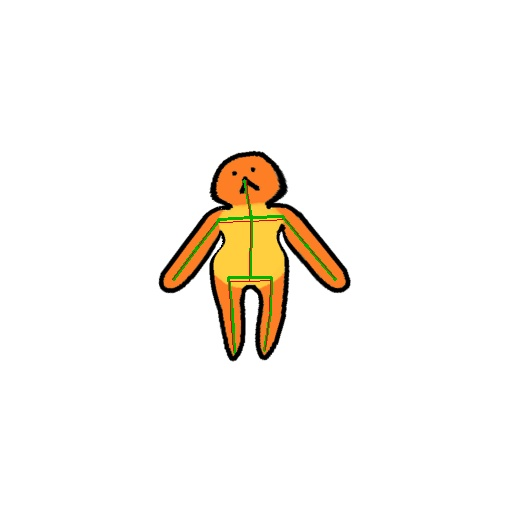

t1__bvh_swim__0_t8.jpg


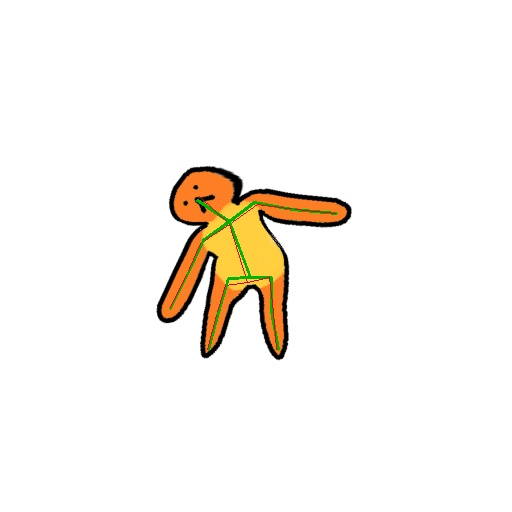

t1__bvh_very_happy__0_t8.jpg


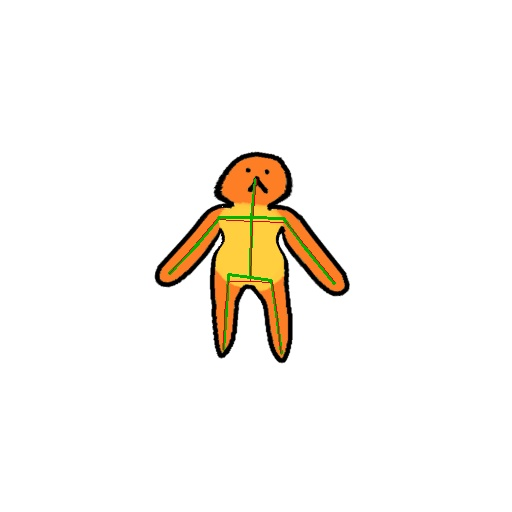

t1__bvh_wave_hello__0_t32.jpg


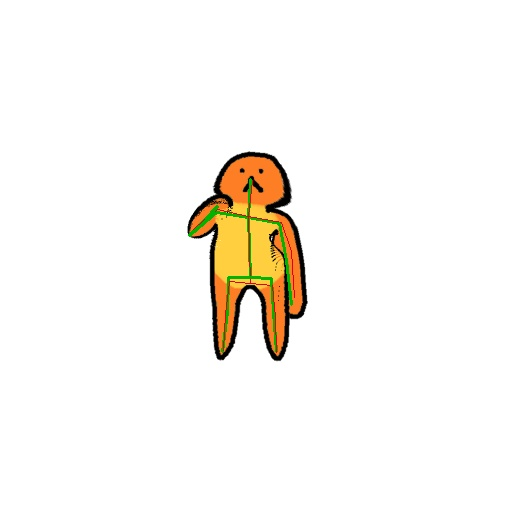

t1__bvh_zombie__0_t46.jpg


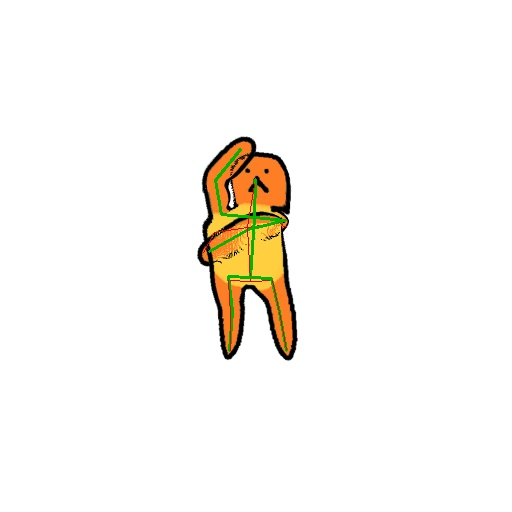

t2__bvh_bird__0_t36.jpg


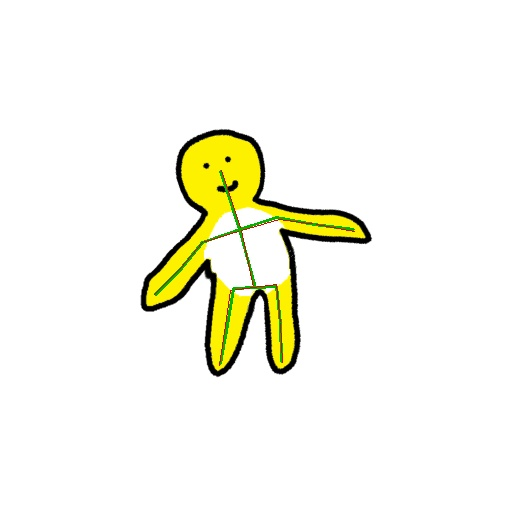

t2__bvh_dab__0_t98.jpg


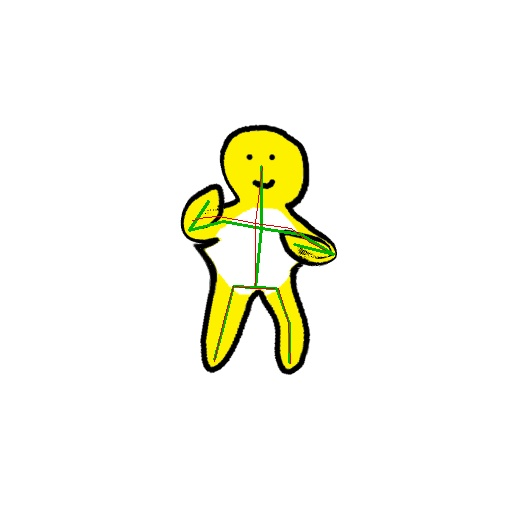

t2__bvh_elephant__0_t42.jpg


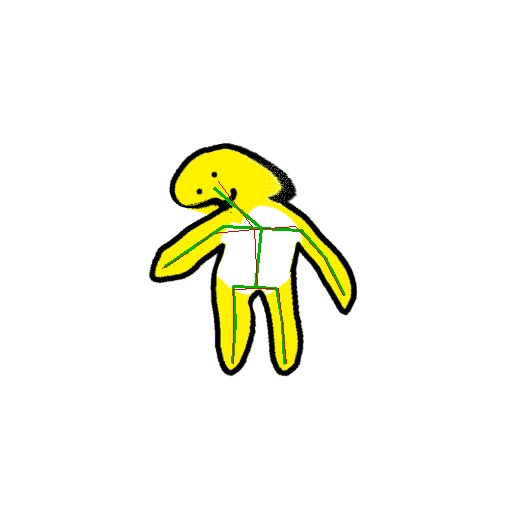

t2__bvh_happy_walk__0_t30.jpg


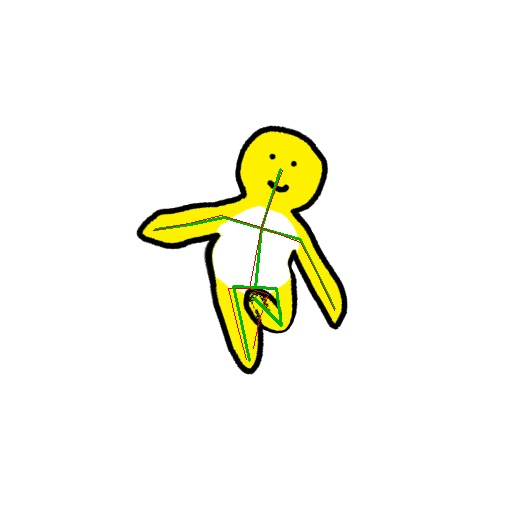

t2__bvh_idle__0_t34.jpg


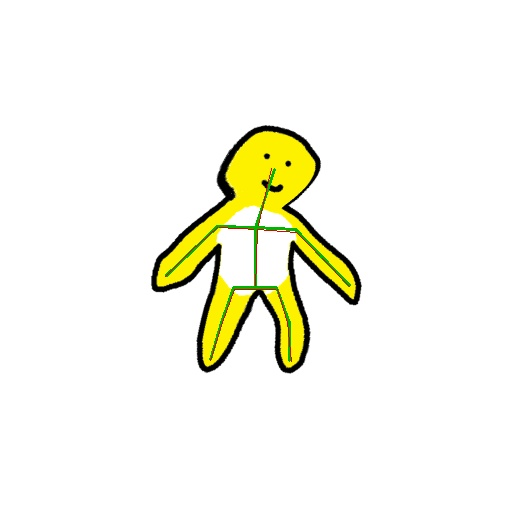

t2__bvh_jesse_dance__0_t16.jpg


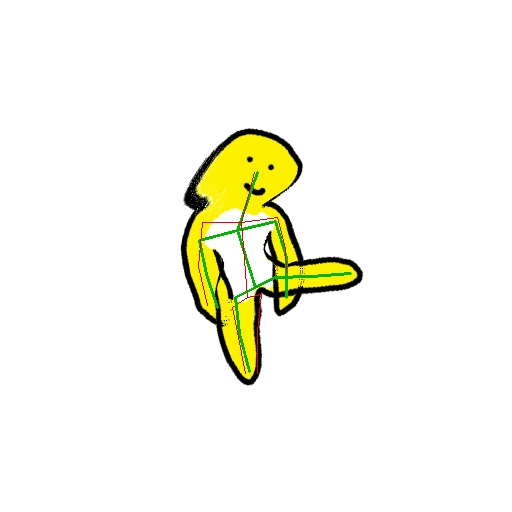

t2__bvh_jumping__0_t24.jpg


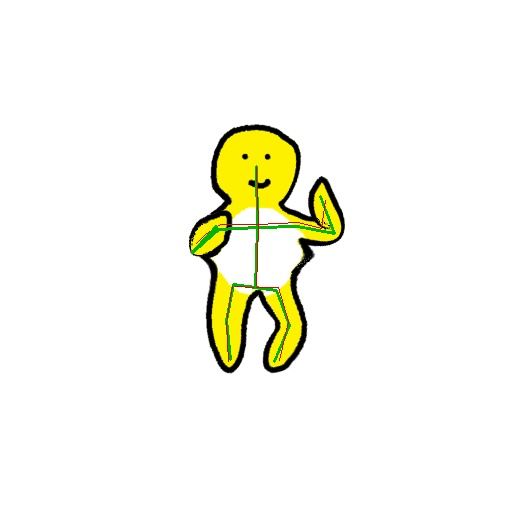

t2__bvh_jumping_jacks__0_t60.jpg


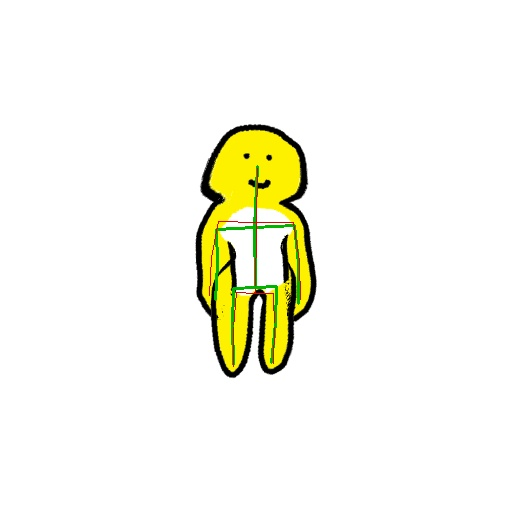

t2__bvh_kick_ball__0_t48.jpg


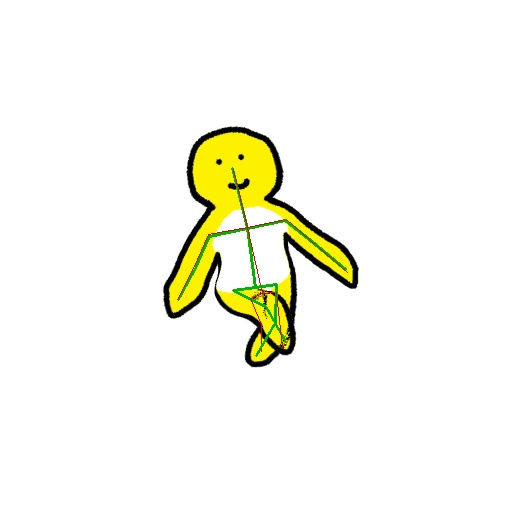

t2__bvh_laugh__0_t42.jpg


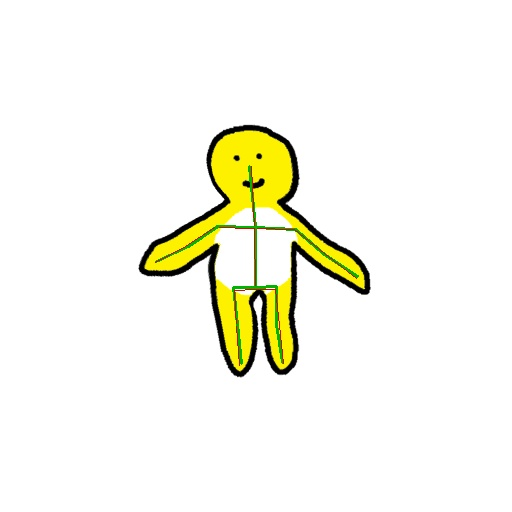

t2__bvh_march__0_t34.jpg


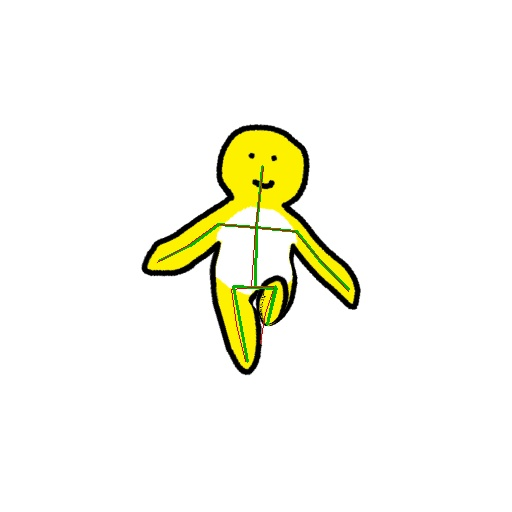

t2__bvh_monkey__0_t54.jpg


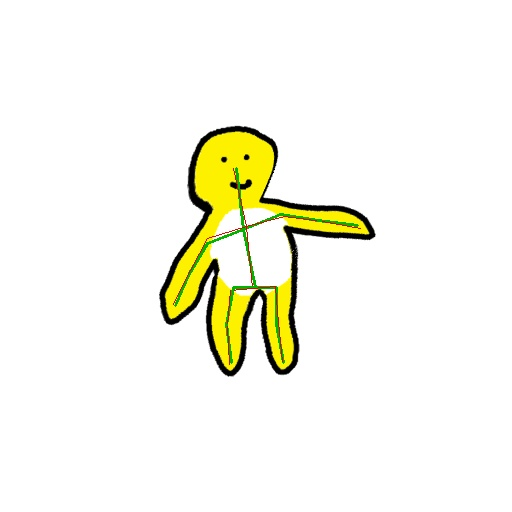

t2__bvh_point__0_t50.jpg


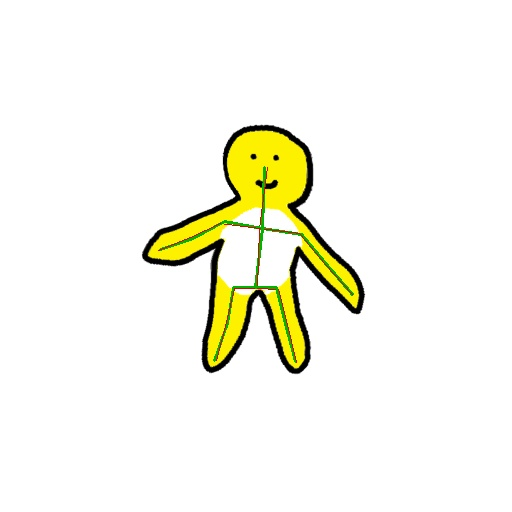

t2__bvh_reach_tiptoe__0_t20.jpg


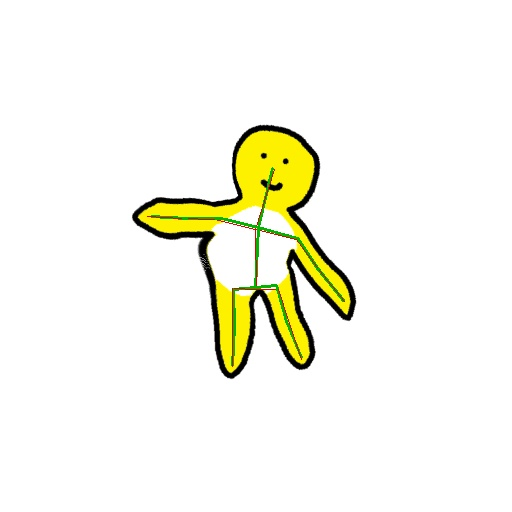

t2__bvh_sad_walk__0_t54.jpg


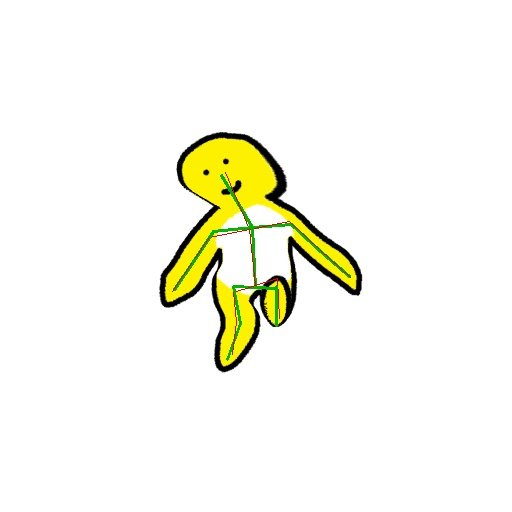

t2__bvh_search_ground__0_t24.jpg


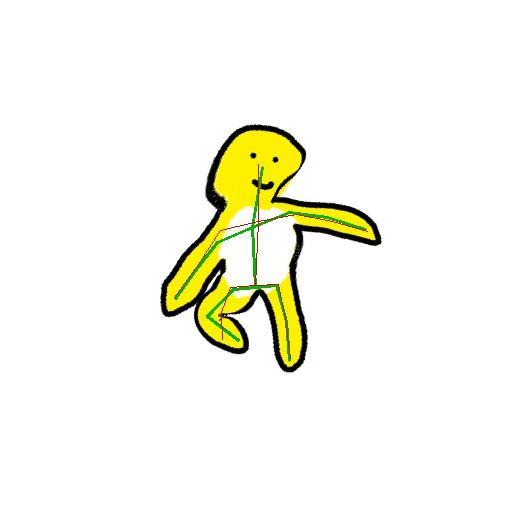

t2__bvh_stand_still__0_t8.jpg


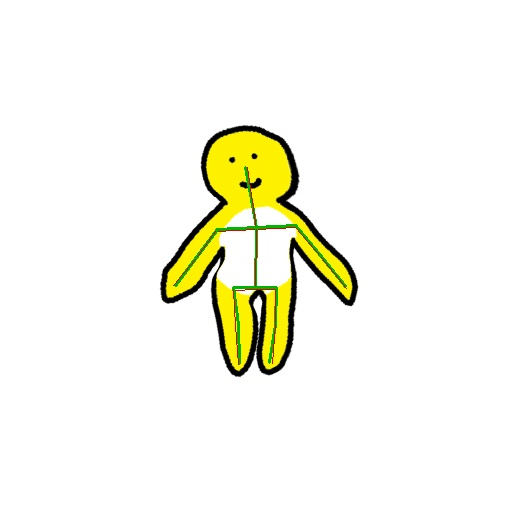

t2__bvh_swim__0_t26.jpg


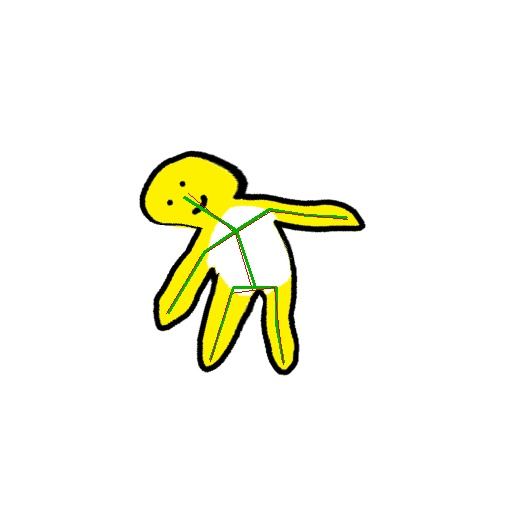

t2__bvh_very_happy__0_t24.jpg


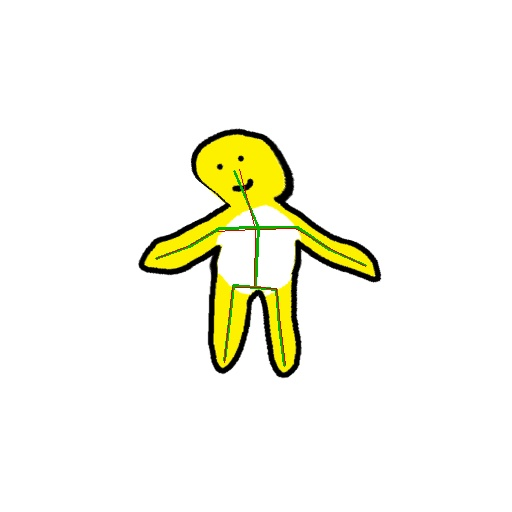

t2__bvh_wave_hello__0_t34.jpg


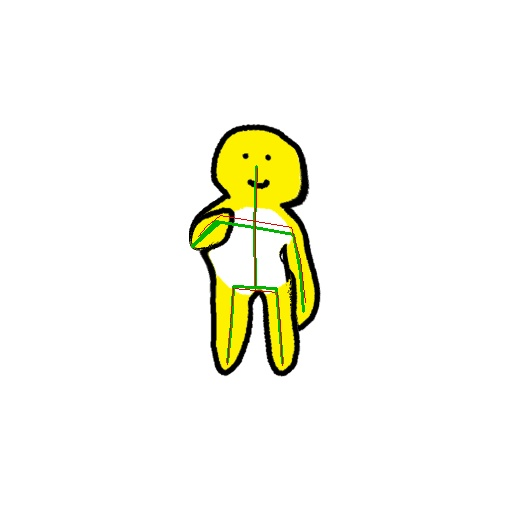

t2__bvh_zombie__0_t48.jpg


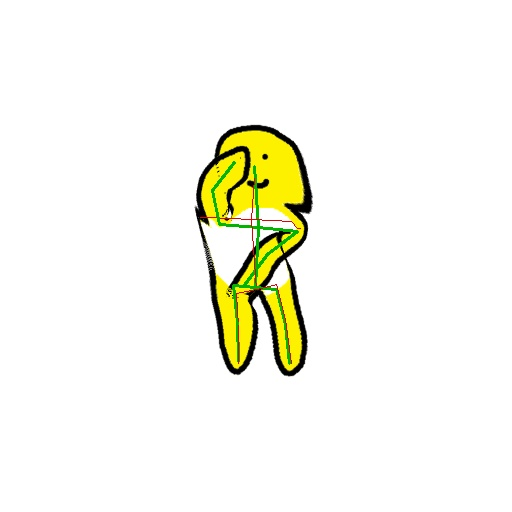

t3__bvh_bird__0_t46.jpg


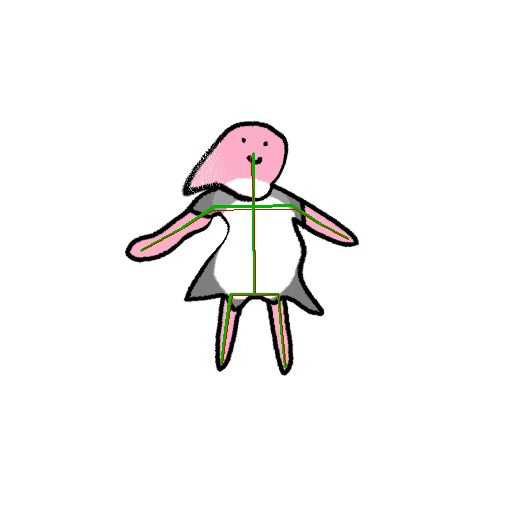

t3__bvh_dab__0_t64.jpg


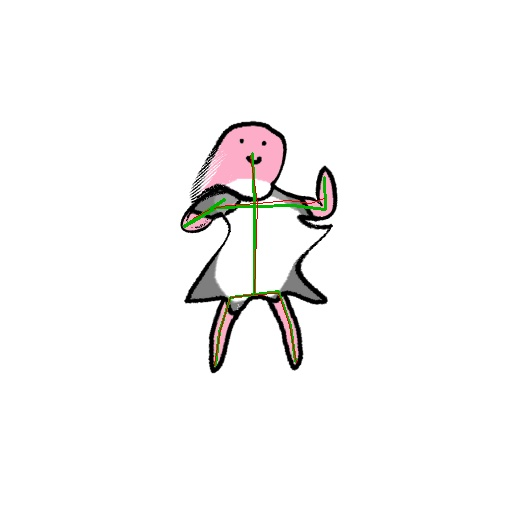

t3__bvh_elephant__0_t38.jpg


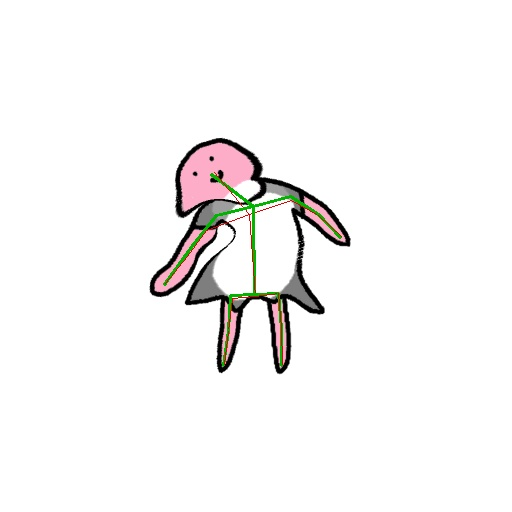

t3__bvh_happy_walk__0_t54.jpg


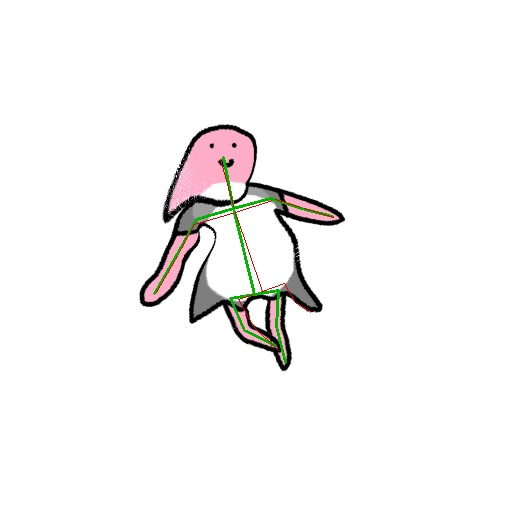

t3__bvh_idle__0_t26.jpg


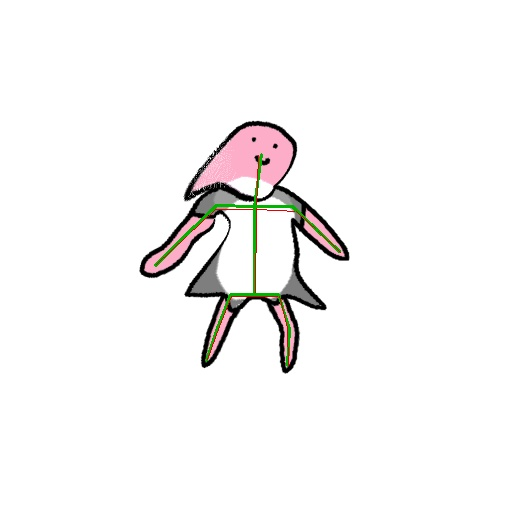

t3__bvh_jesse_dance__0_t34.jpg


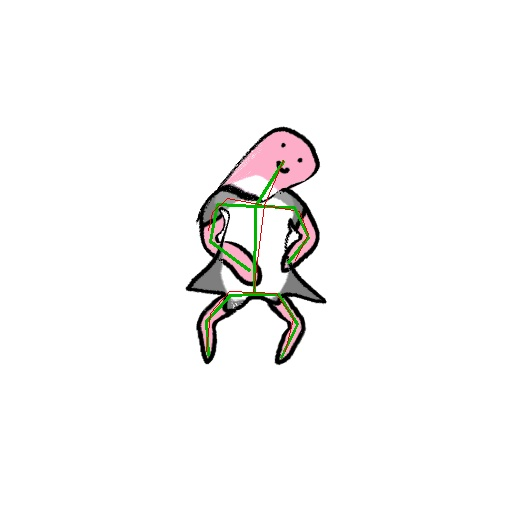

t3__bvh_jumping__0_t24.jpg


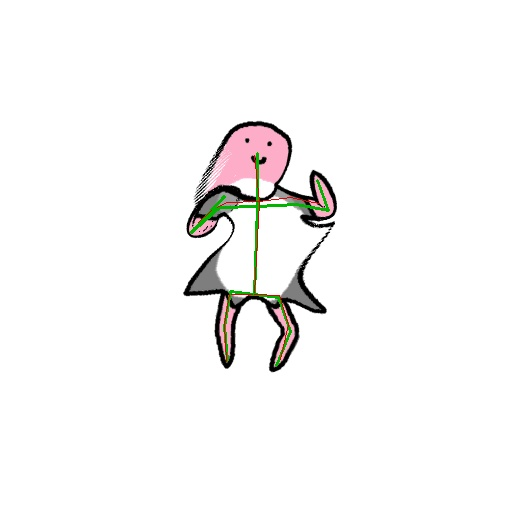

t3__bvh_jumping_jacks__0_t16.jpg


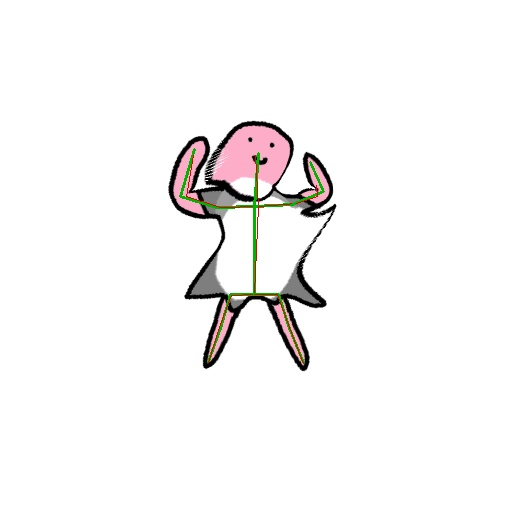

t3__bvh_kick_ball__0_t48.jpg


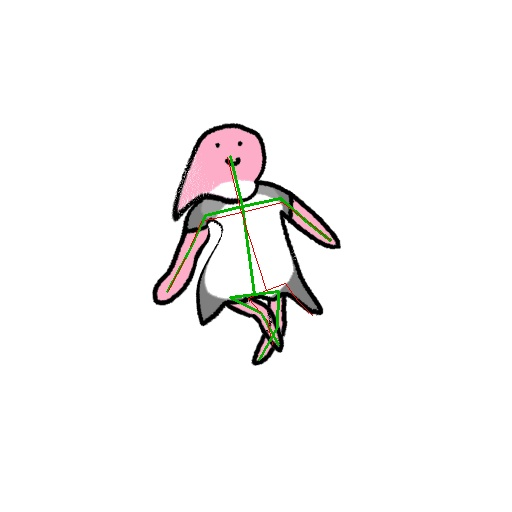

t3__bvh_laugh__0_t12.jpg


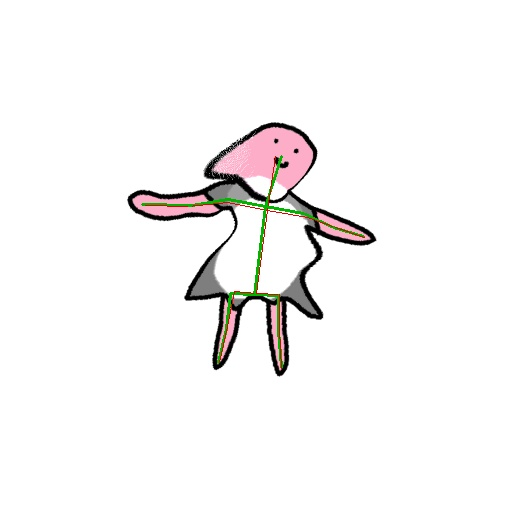

t3__bvh_march__0_t30.jpg


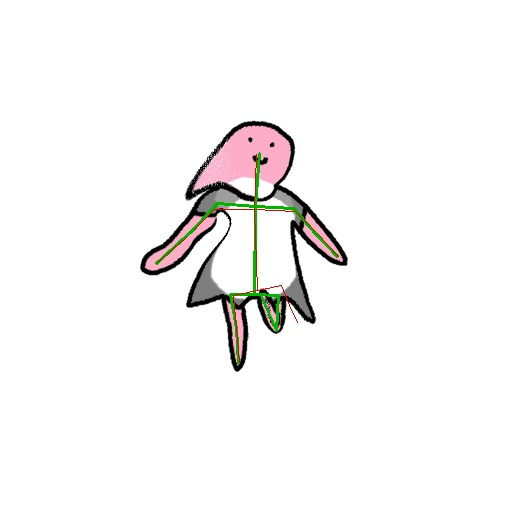

t3__bvh_monkey__0_t28.jpg


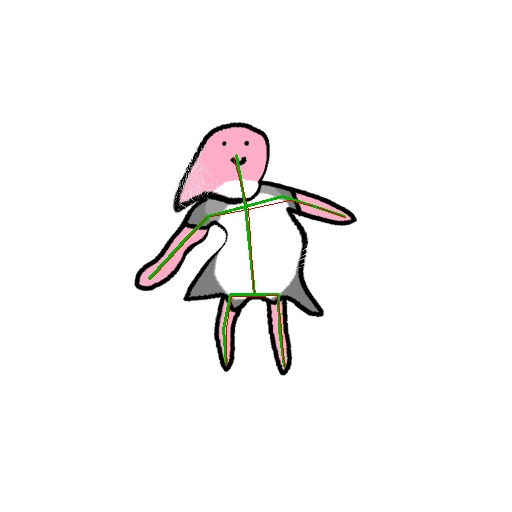

t3__bvh_point__0_t42.jpg


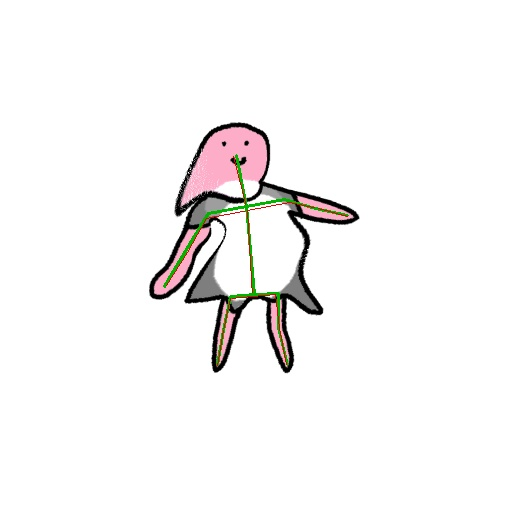

t3__bvh_reach_tiptoe__0_t38.jpg


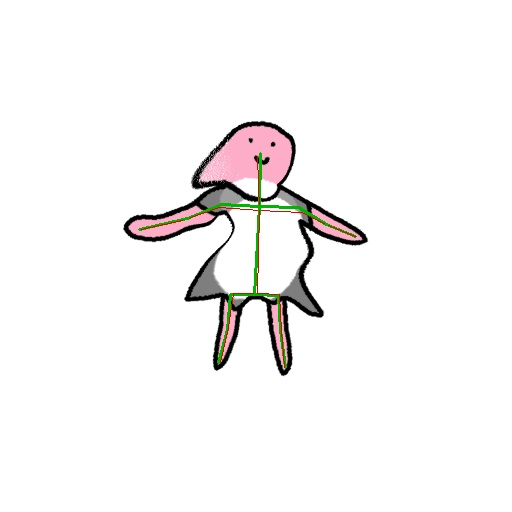

t3__bvh_sad_walk__0_t40.jpg


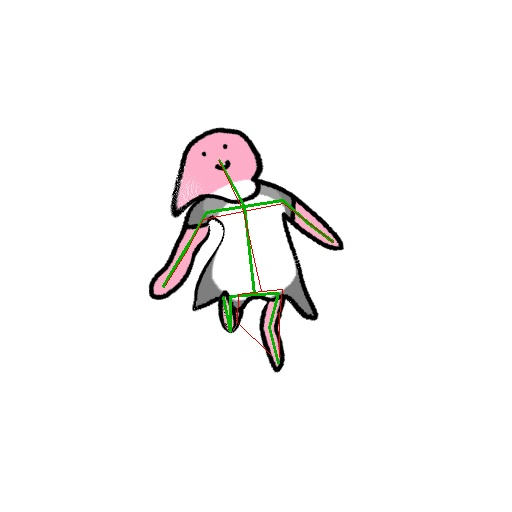

t3__bvh_search_ground__0_t24.jpg


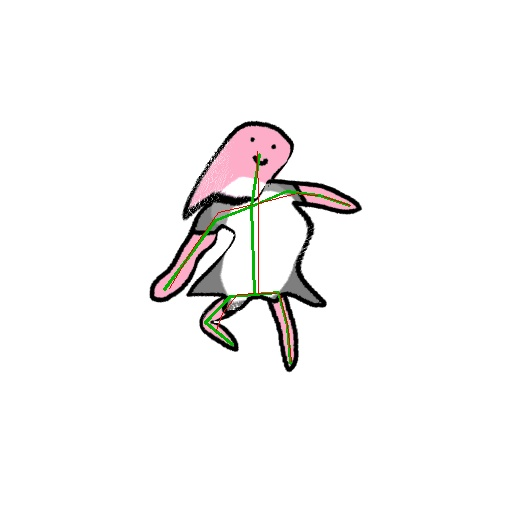

t3__bvh_stand_still__0_t30.jpg


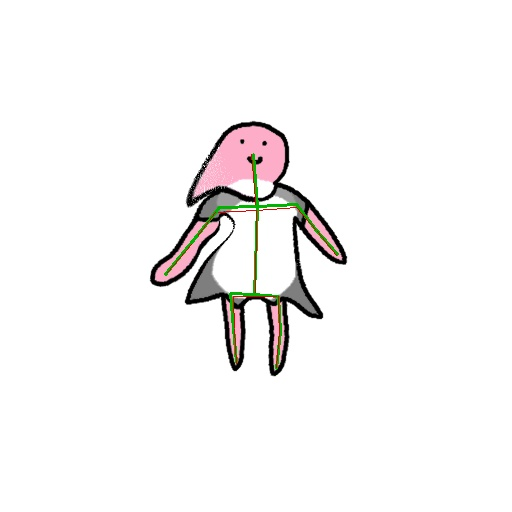

t3__bvh_swim__0_t28.jpg


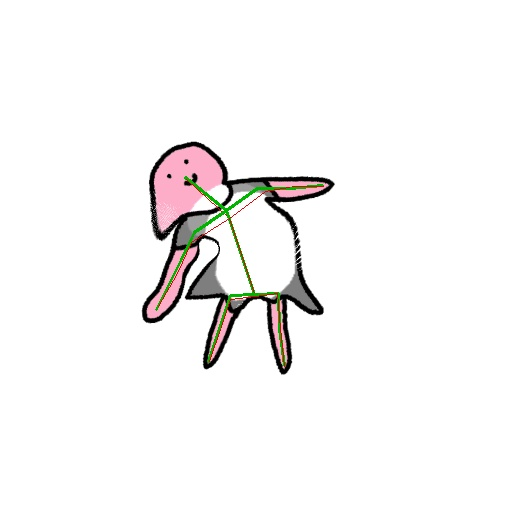

t3__bvh_very_happy__0_t18.jpg


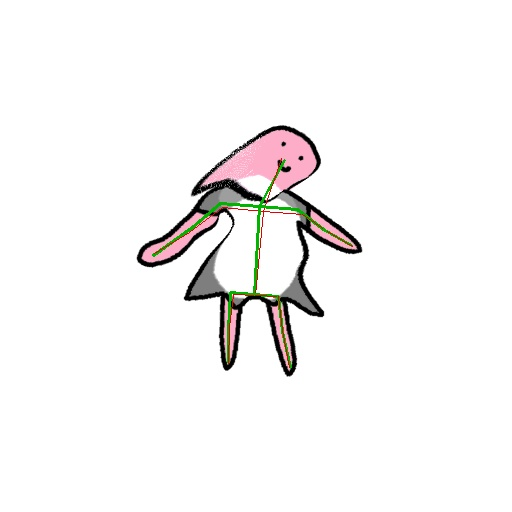

t3__bvh_wave_hello__0_t34.jpg


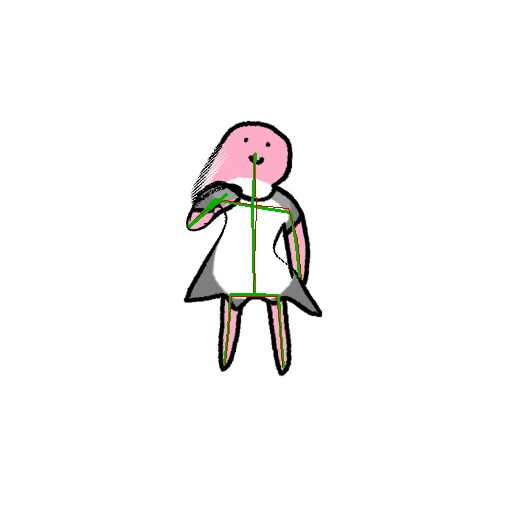

t3__bvh_zombie__0_t36.jpg


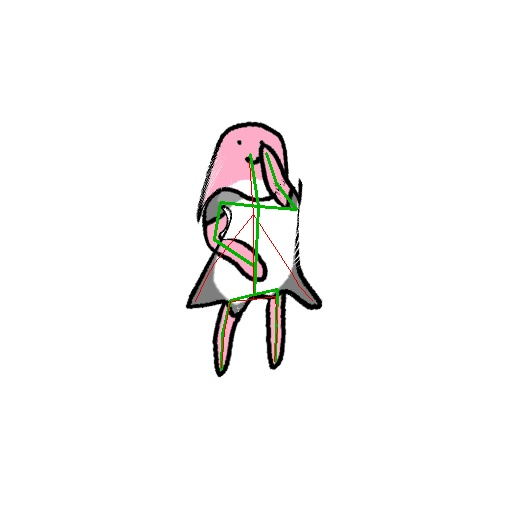

t4__bvh_bird__0_t6.jpg


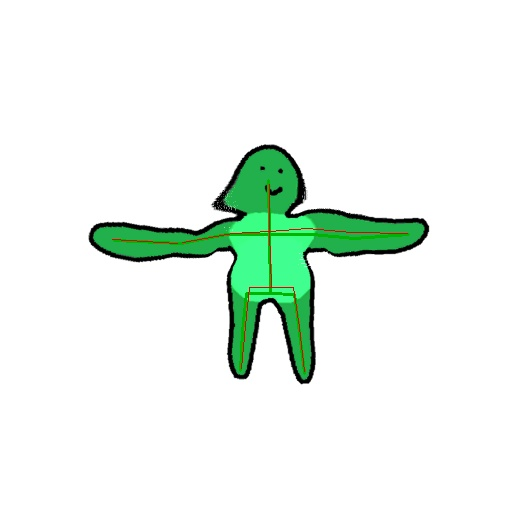

t4__bvh_dab__0_t98.jpg


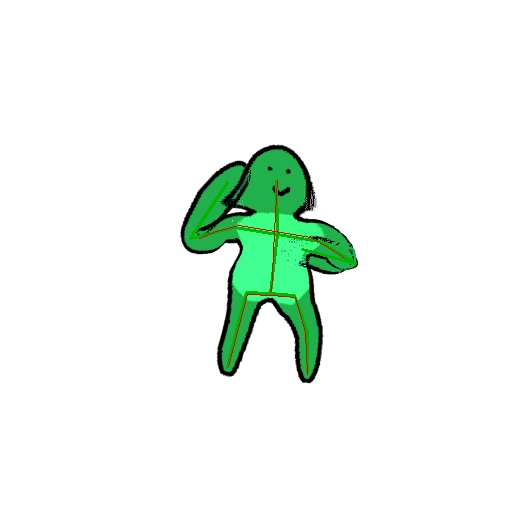

t4__bvh_elephant__0_t42.jpg


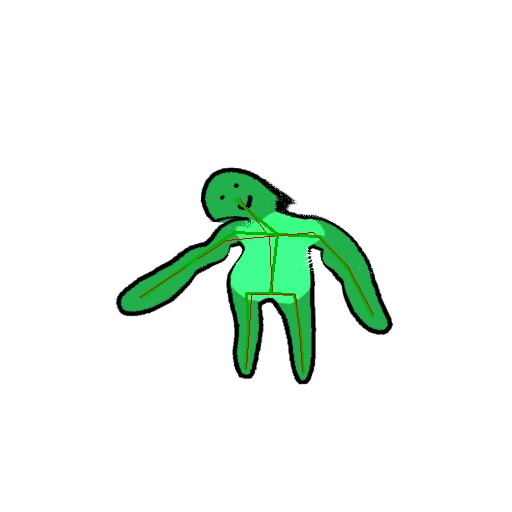

t4__bvh_happy_walk__0_t30.jpg


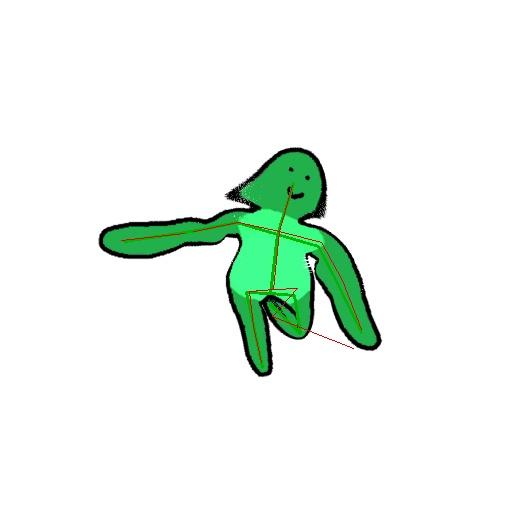

t4__bvh_idle__0_t4.jpg


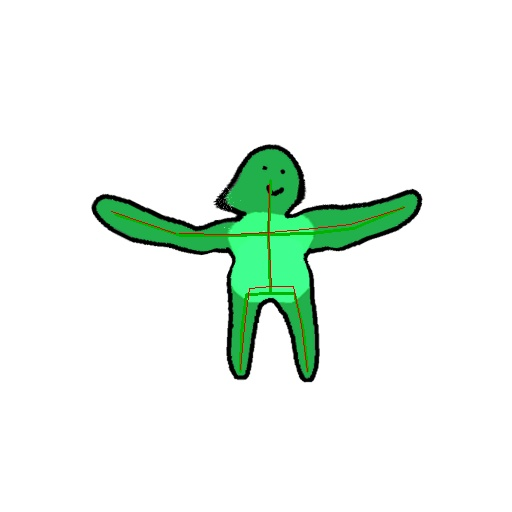

t4__bvh_jesse_dance__0_t12.jpg


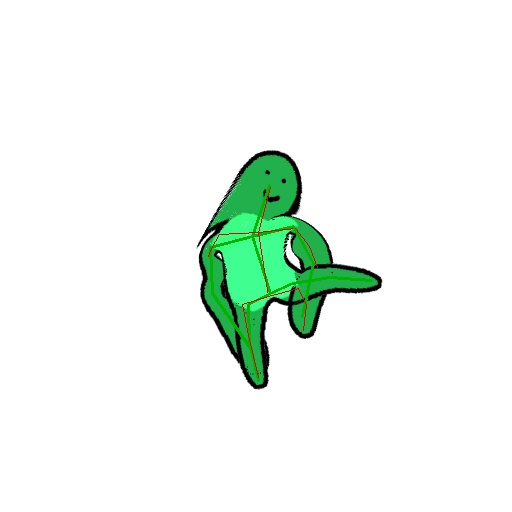

t4__bvh_jumping__0_t24.jpg


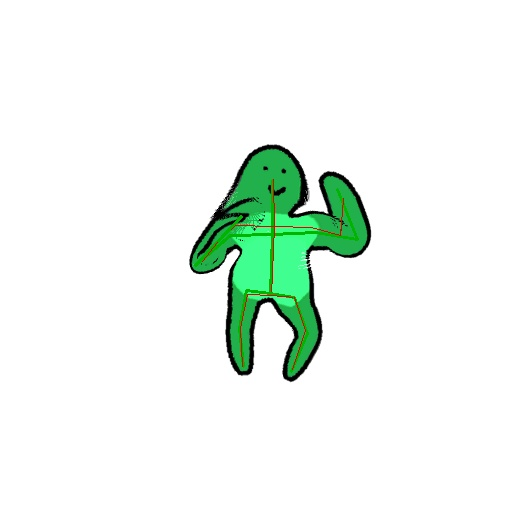

t4__bvh_jumping_jacks__0_t60.jpg


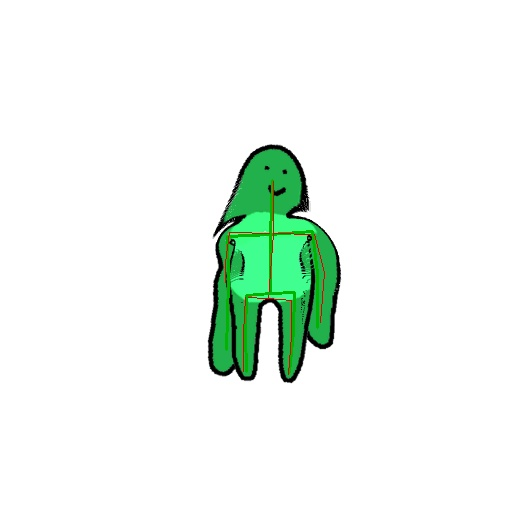

t4__bvh_kick_ball__0_t48.jpg


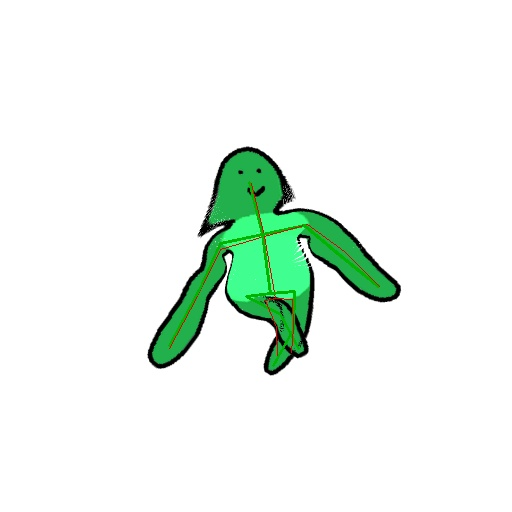

t4__bvh_laugh__0_t38.jpg


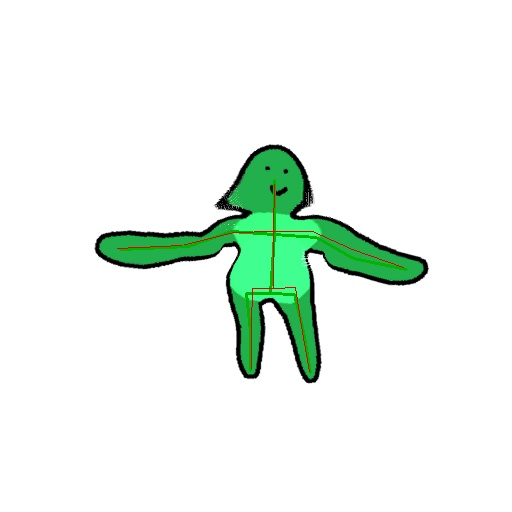

t4__bvh_march__0_t32.jpg


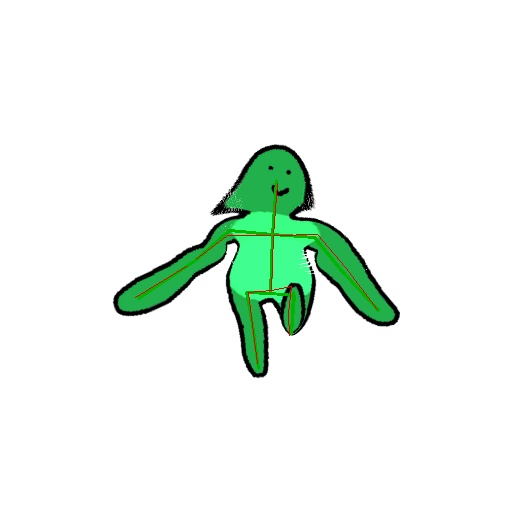

t4__bvh_monkey__0_t54.jpg


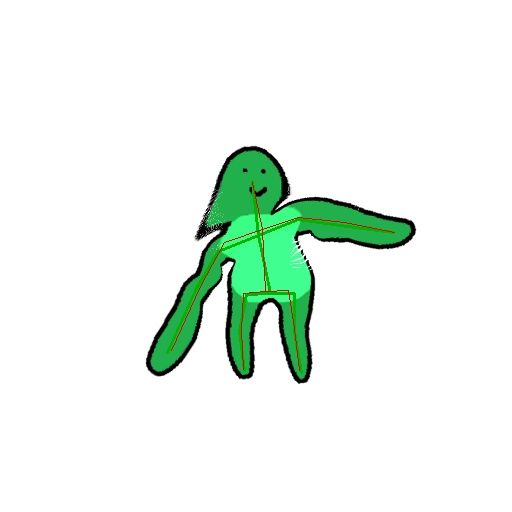

t4__bvh_point__0_t4.jpg


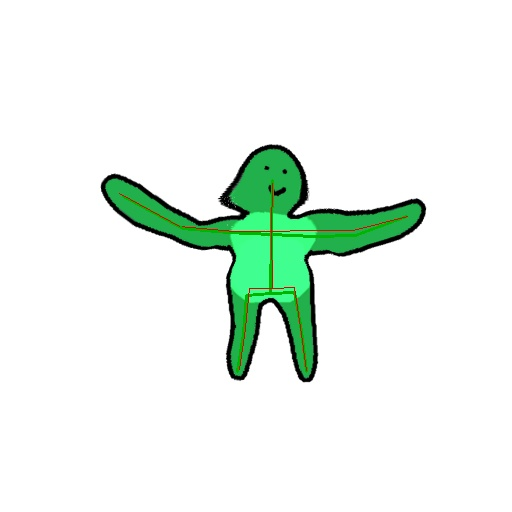

t4__bvh_reach_tiptoe__0_t6.jpg


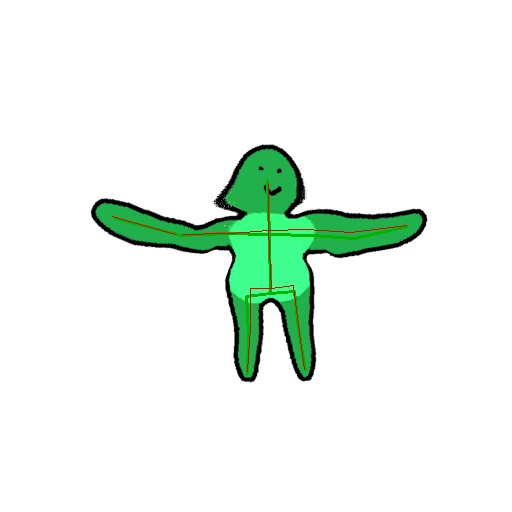

t4__bvh_sad_walk__0_t54.jpg


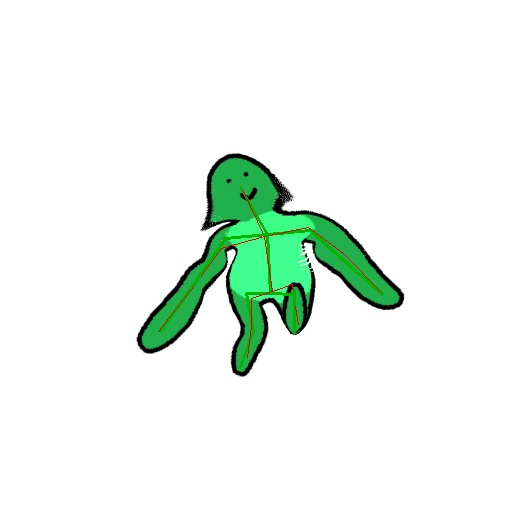

t4__bvh_search_ground__0_t26.jpg


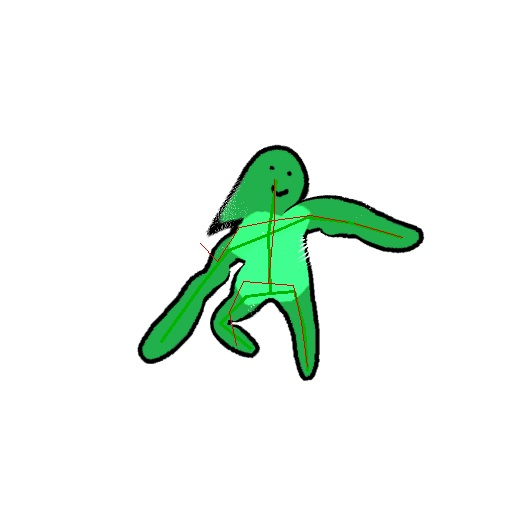

t4__bvh_stand_still__0_t4.jpg


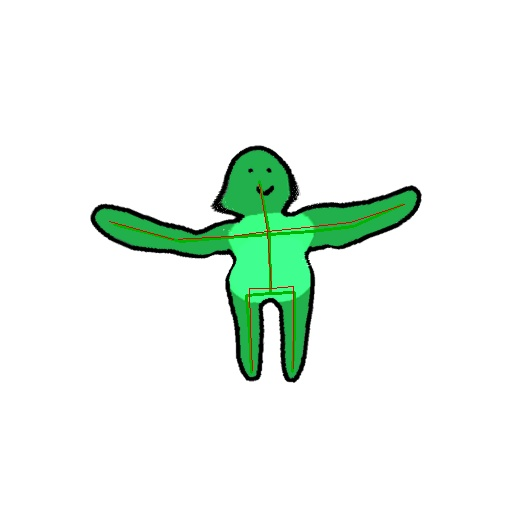

t4__bvh_swim__0_t36.jpg


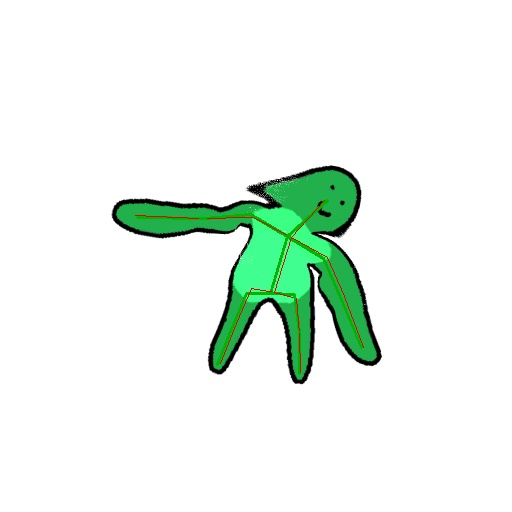

t4__bvh_very_happy__0_t4.jpg


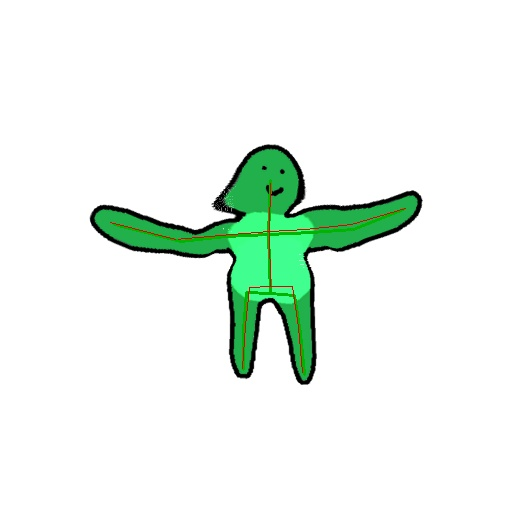

t4__bvh_wave_hello__0_t32.jpg


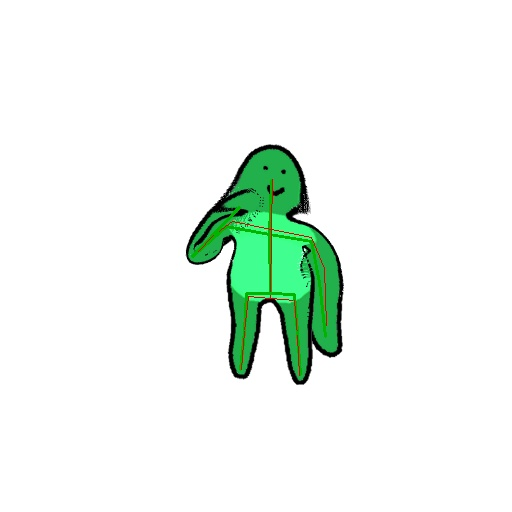

t4__bvh_zombie__0_t56.jpg


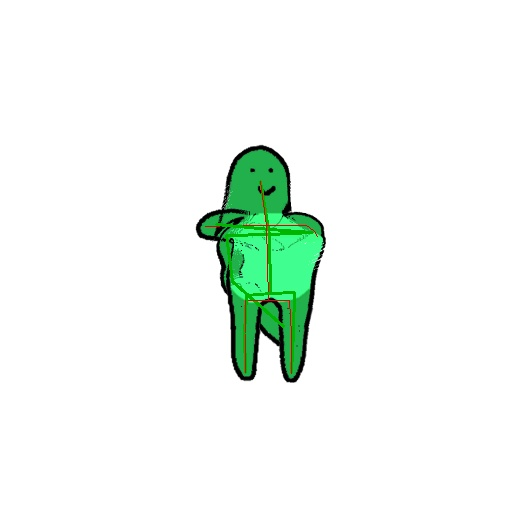

t5__bvh_bird__0_t24.jpg


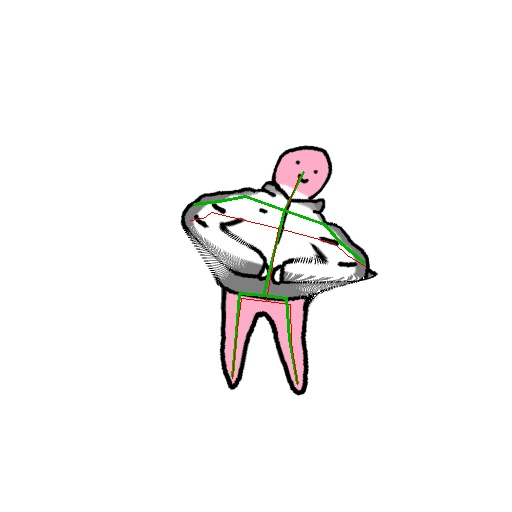

t5__bvh_dab__0_t78.jpg


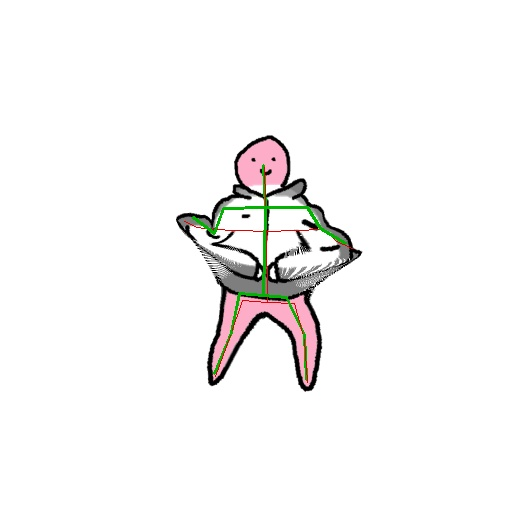

t5__bvh_elephant__0_t40.jpg


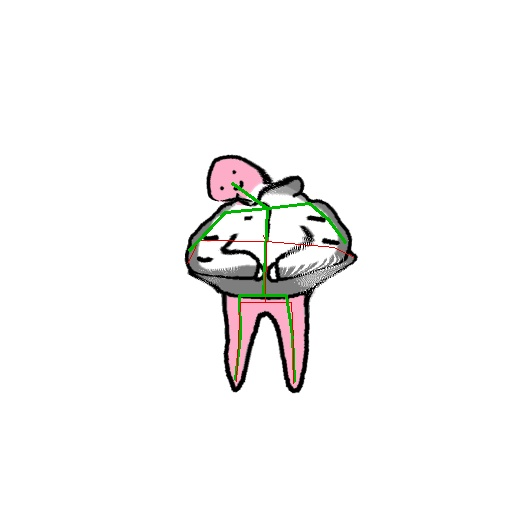

t5__bvh_happy_walk__0_t50.jpg


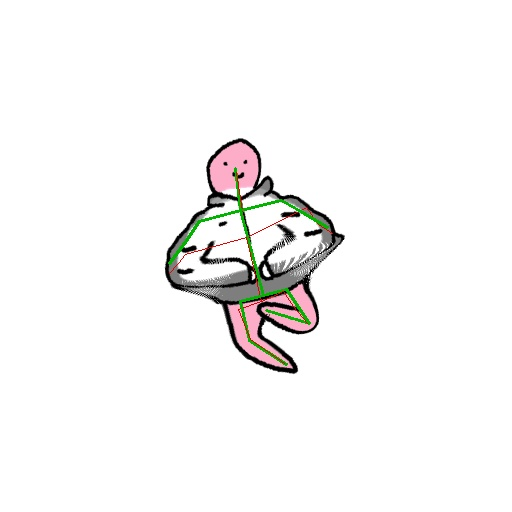

t5__bvh_idle__0_t34.jpg


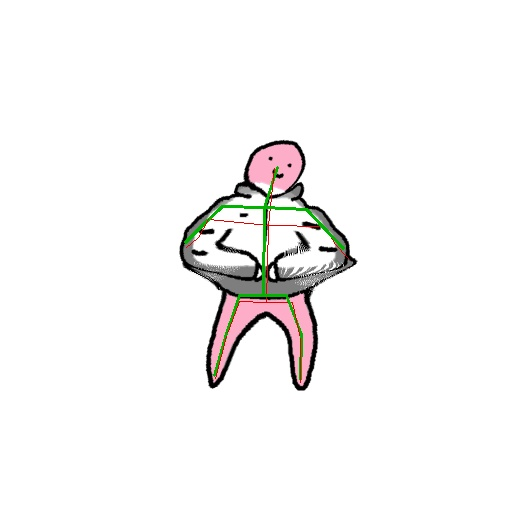

t5__bvh_jesse_dance__0_t20.jpg


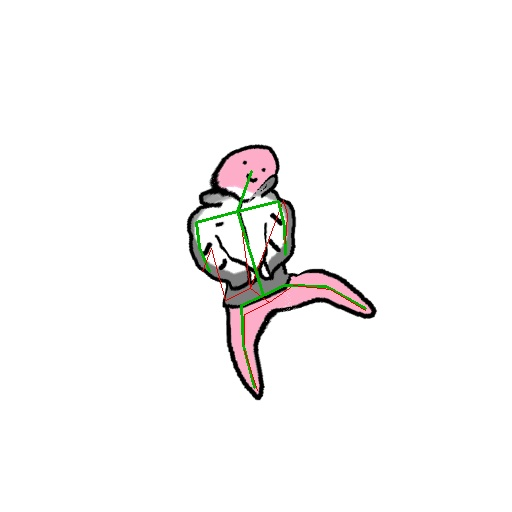

t5__bvh_jumping__0_t8.jpg


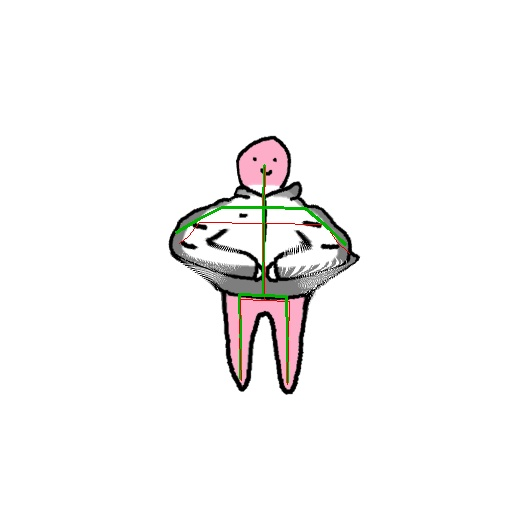

t5__bvh_jumping_jacks__0_t54.jpg


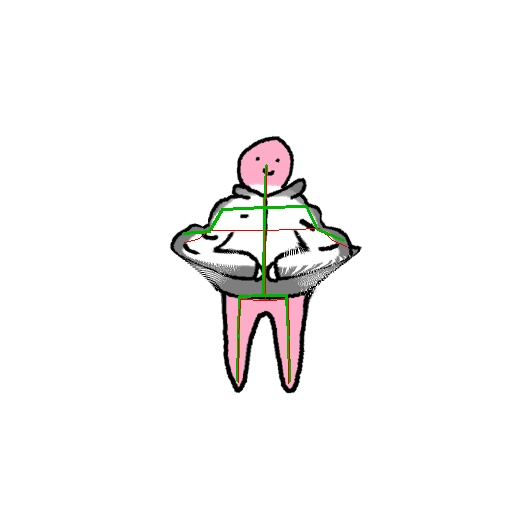

t5__bvh_kick_ball__0_t48.jpg


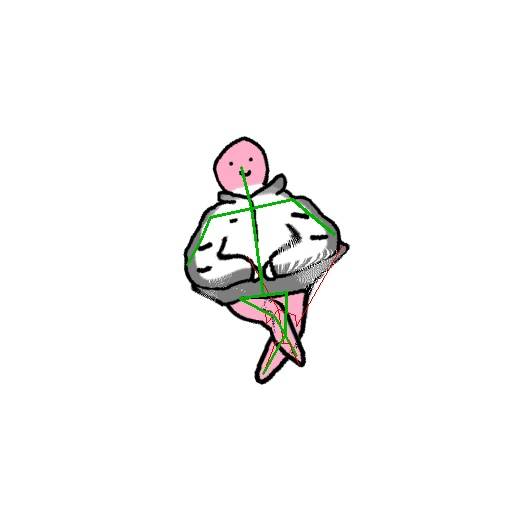

t5__bvh_laugh__0_t42.jpg


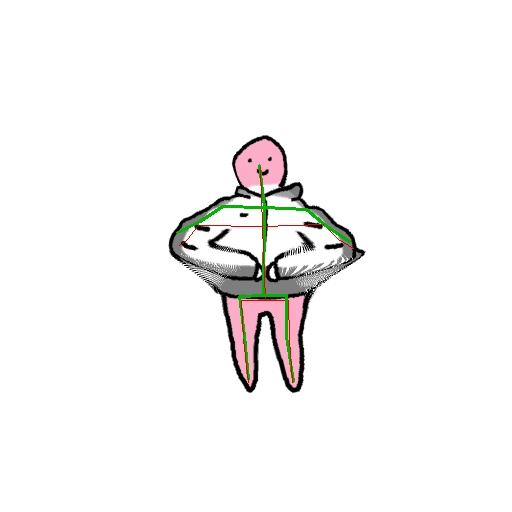

t5__bvh_march__0_t16.jpg


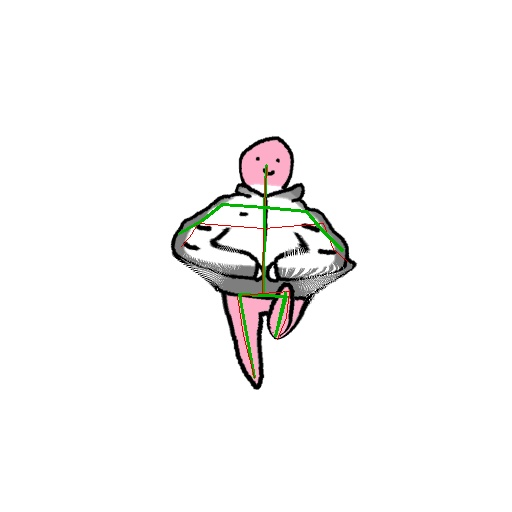

t5__bvh_monkey__0_t16.jpg


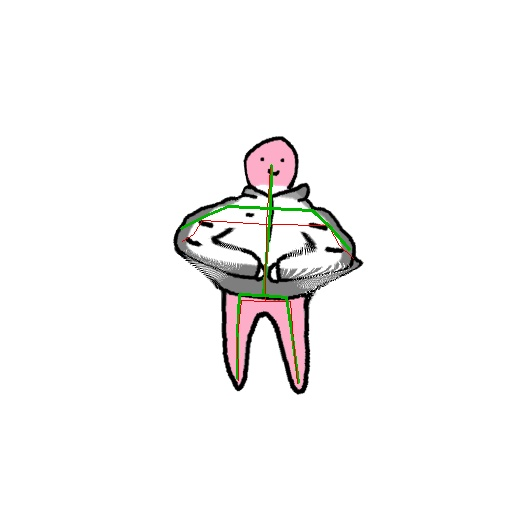

t5__bvh_point__0_t32.jpg


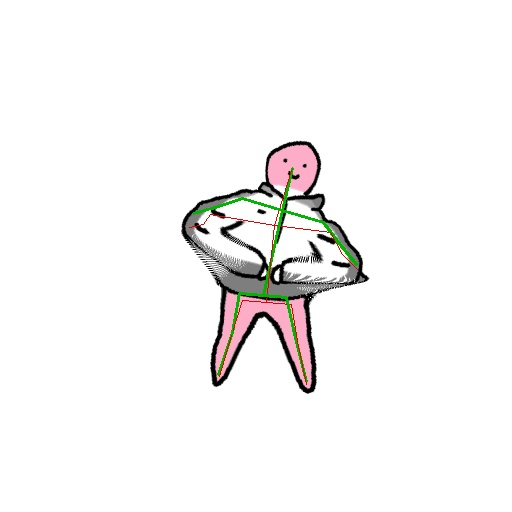

t5__bvh_reach_tiptoe__0_t6.jpg


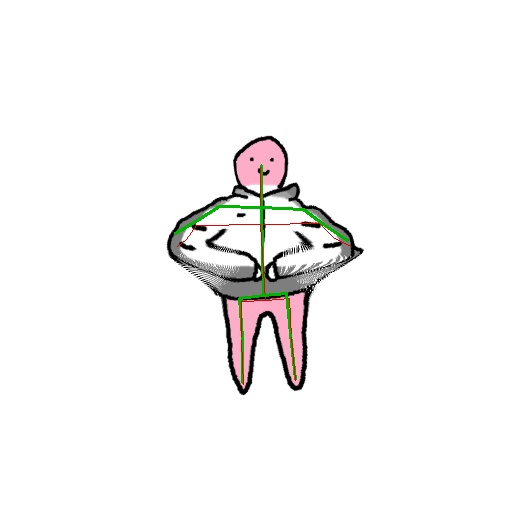

t5__bvh_sad_walk__0_t40.jpg


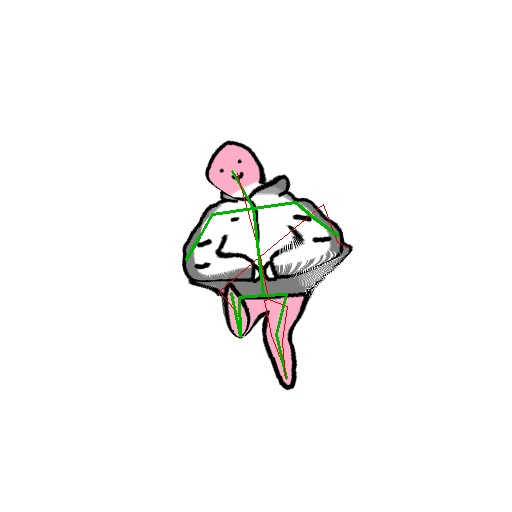

t5__bvh_search_ground__0_t50.jpg


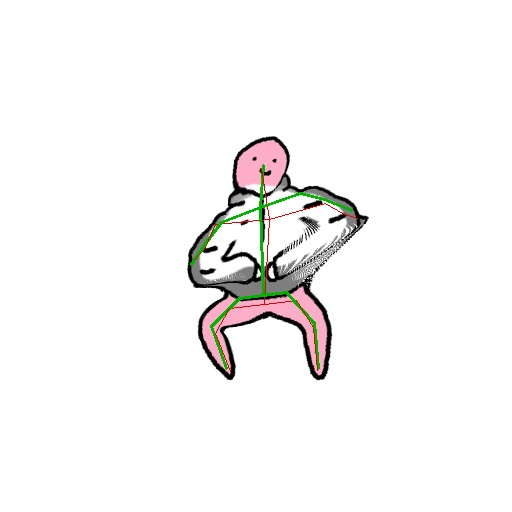

t5__bvh_stand_still__0_t36.jpg


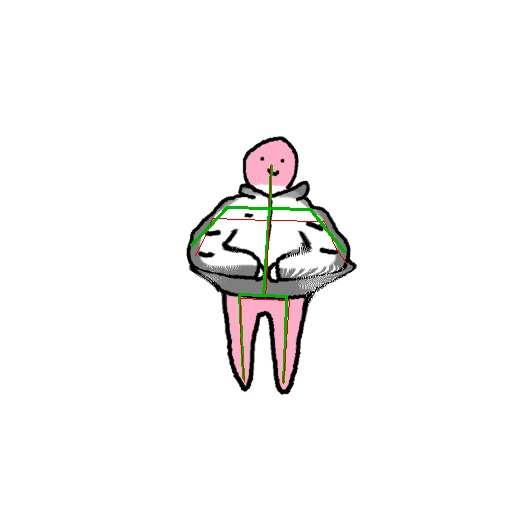

t5__bvh_swim__0_t24.jpg


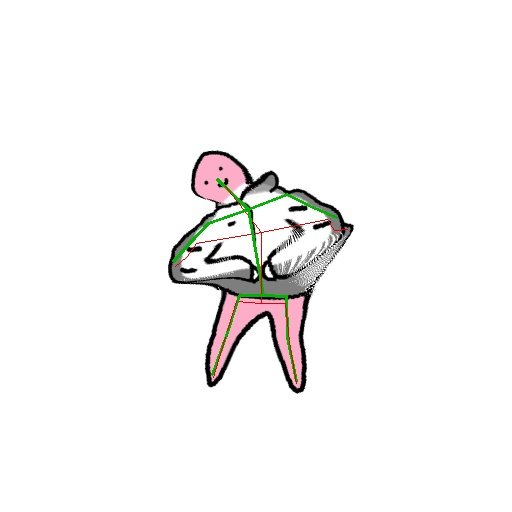

t5__bvh_very_happy__0_t16.jpg


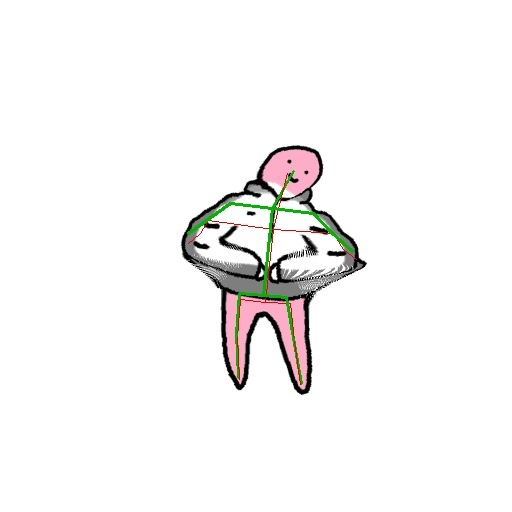

t5__bvh_wave_hello__0_t6.jpg


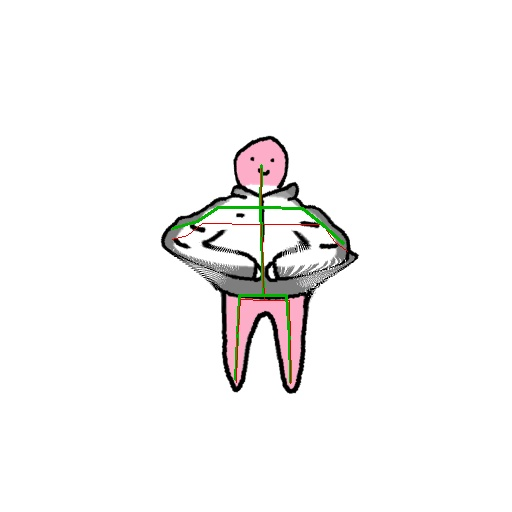

t5__bvh_zombie__0_t254.jpg


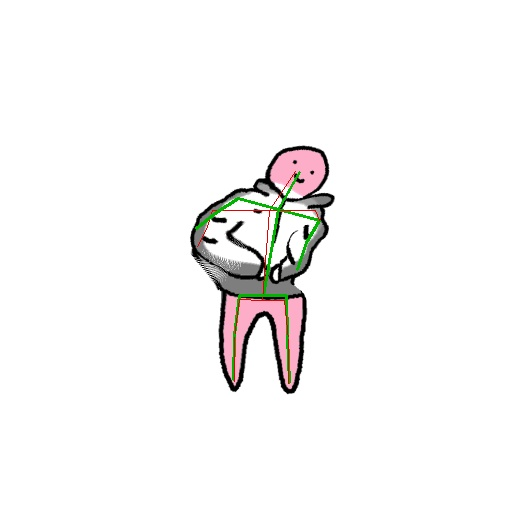

t6__bvh_bird__0_t36.jpg


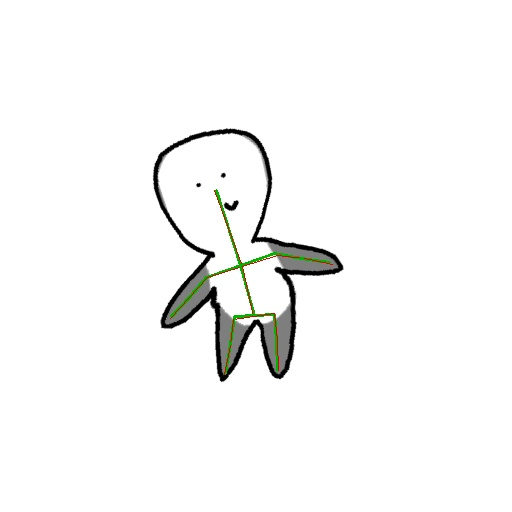

t6__bvh_dab__0_t118.jpg


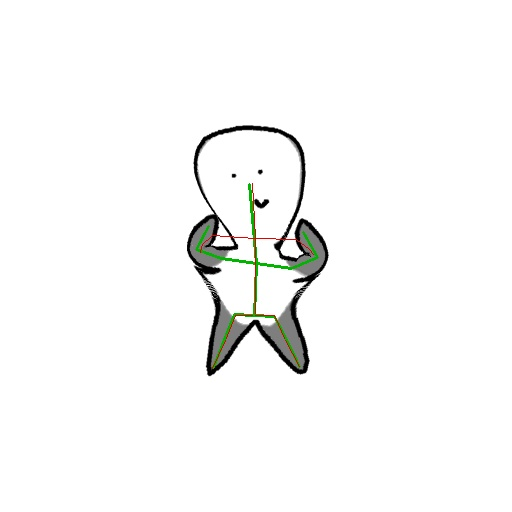

t6__bvh_elephant__0_t42.jpg


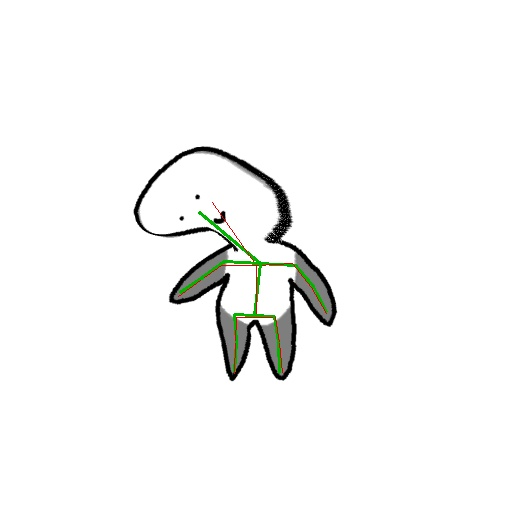

t6__bvh_happy_walk__0_t30.jpg


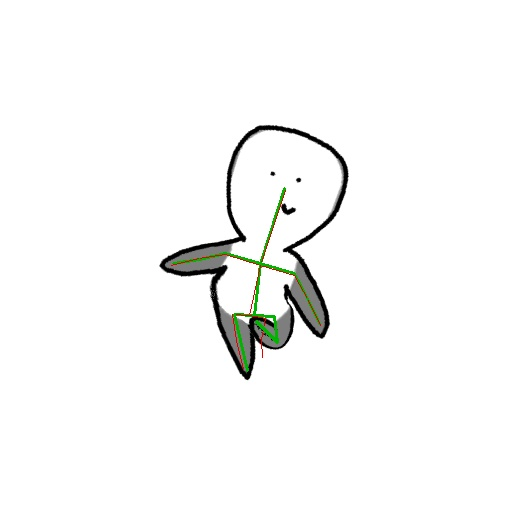

t6__bvh_idle__0_t36.jpg


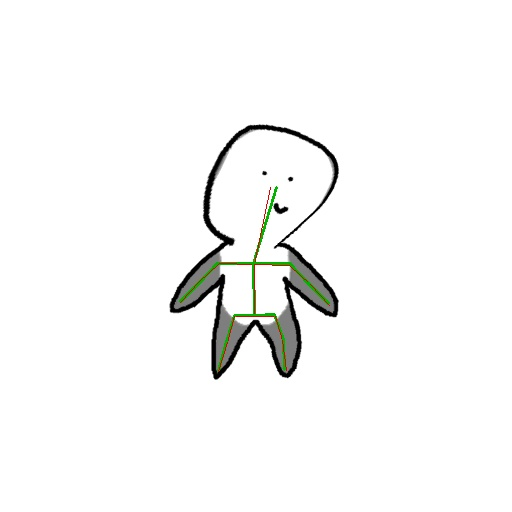

t6__bvh_jesse_dance__0_t12.jpg


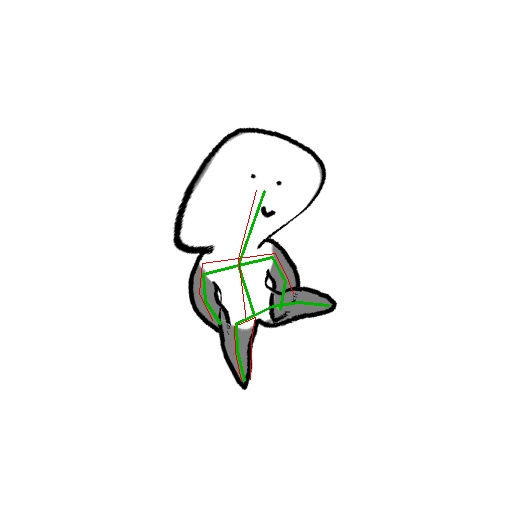

t6__bvh_jumping__0_t24.jpg


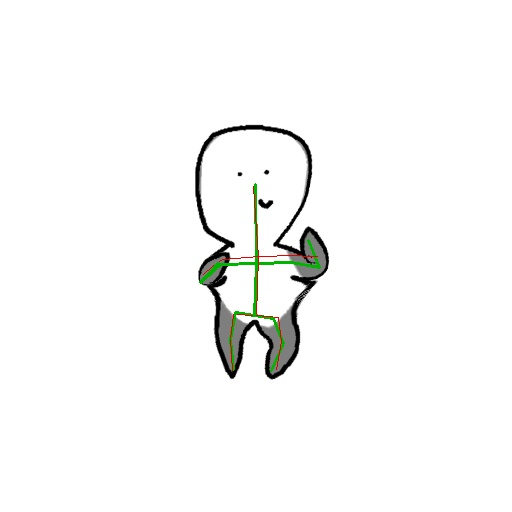

t6__bvh_jumping_jacks__0_t16.jpg


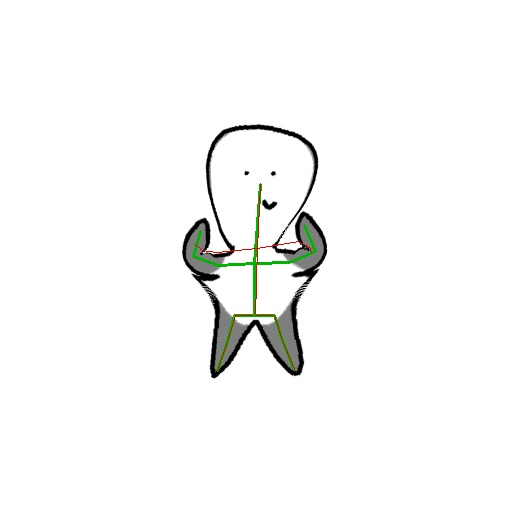

t6__bvh_kick_ball__0_t48.jpg


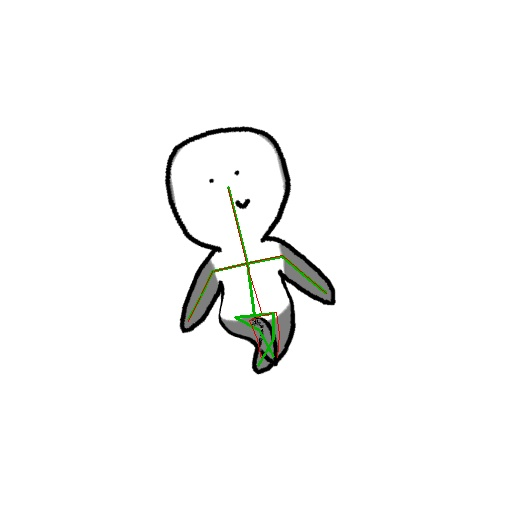

t6__bvh_laugh__0_t14.jpg


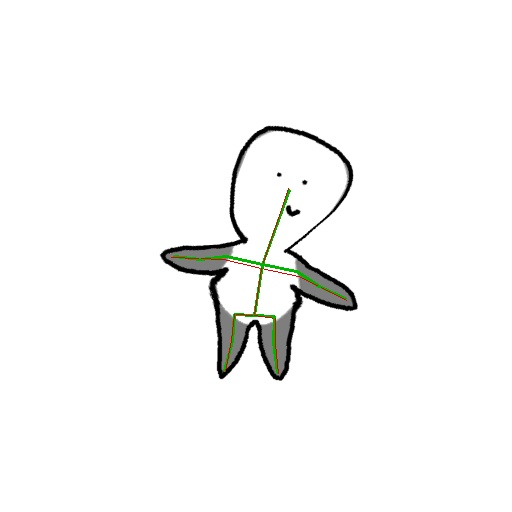

t6__bvh_march__0_t24.jpg


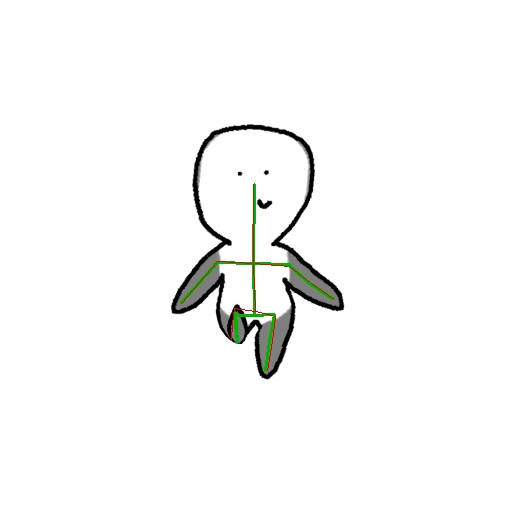

t6__bvh_monkey__0_t54.jpg


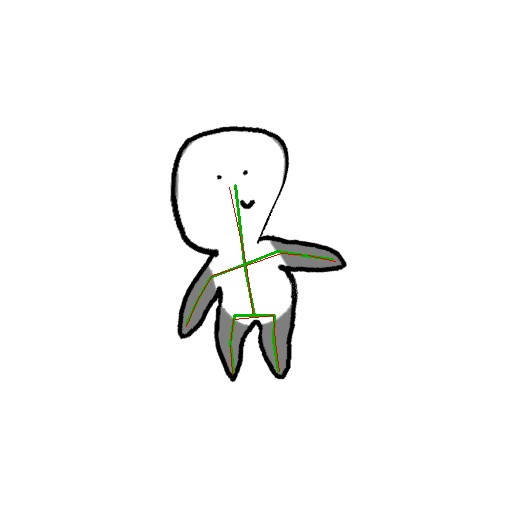

t6__bvh_point__0_t40.jpg


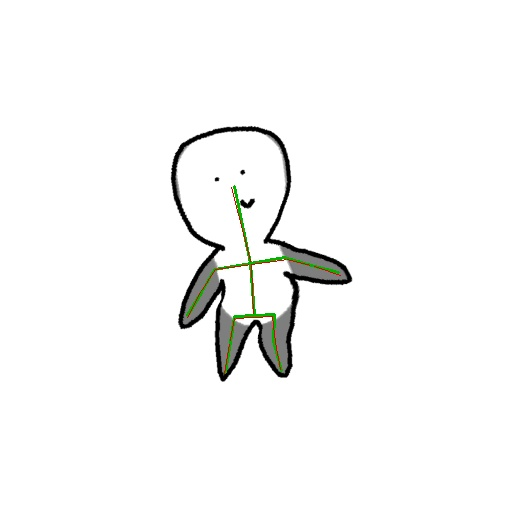

t6__bvh_reach_tiptoe__0_t26.jpg


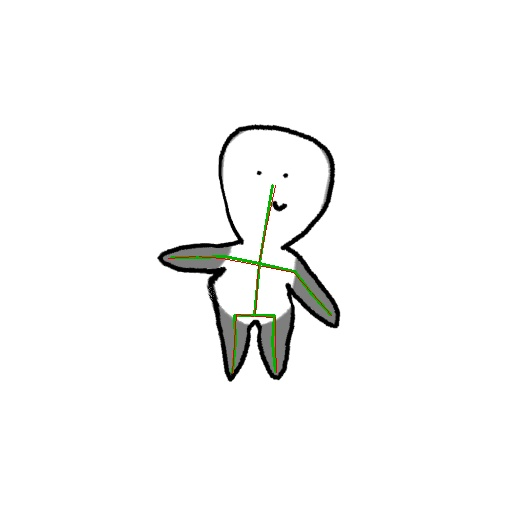

t6__bvh_sad_walk__0_t54.jpg


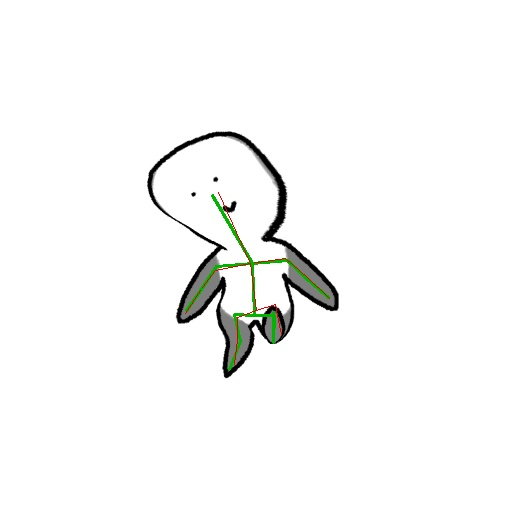

t6__bvh_search_ground__0_t40.jpg


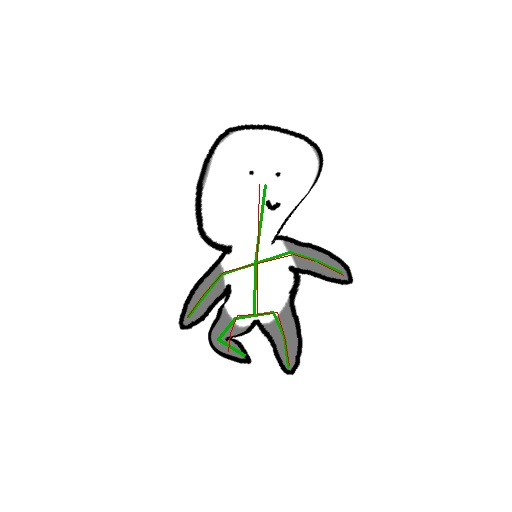

t6__bvh_stand_still__0_t8.jpg


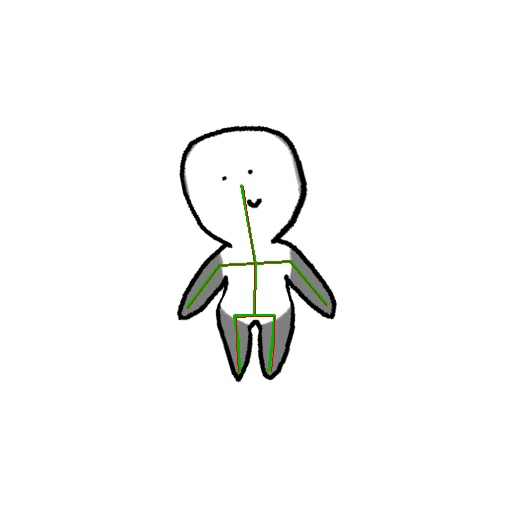

t6__bvh_swim__0_t28.jpg


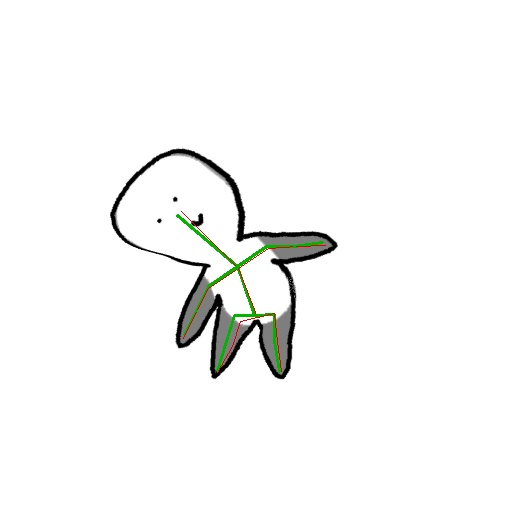

t6__bvh_very_happy__0_t18.jpg


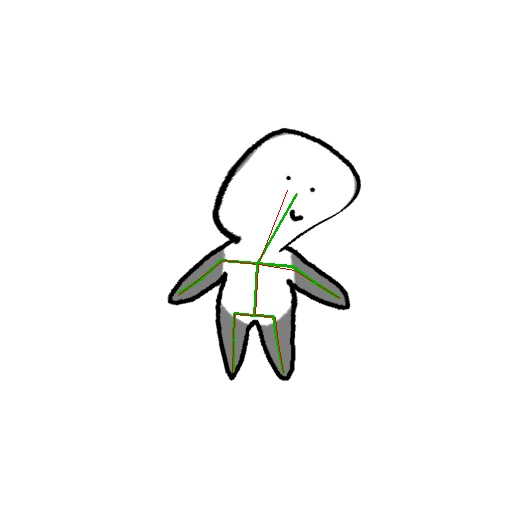

t6__bvh_wave_hello__0_t34.jpg


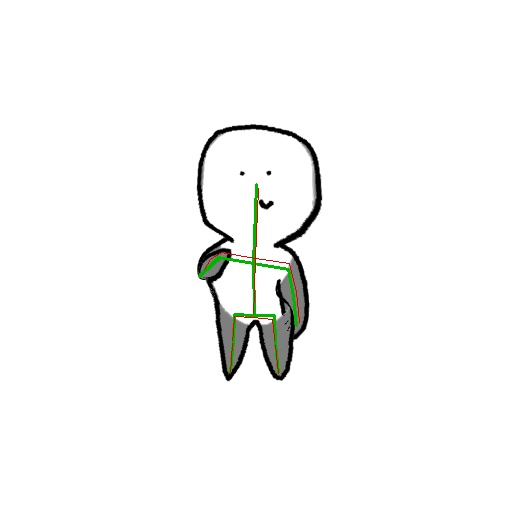

t6__bvh_zombie__0_t48.jpg


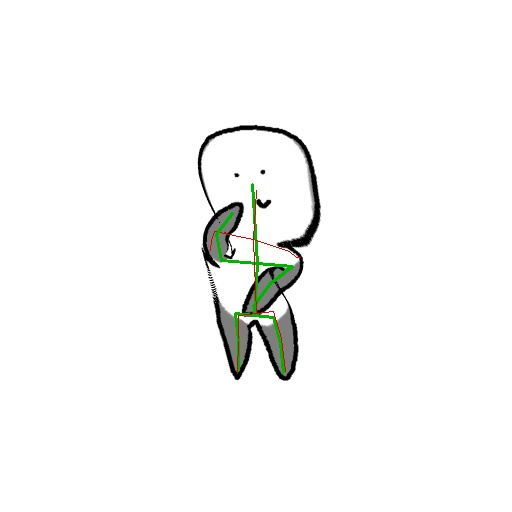

t7__bvh_bird__0_t36.jpg


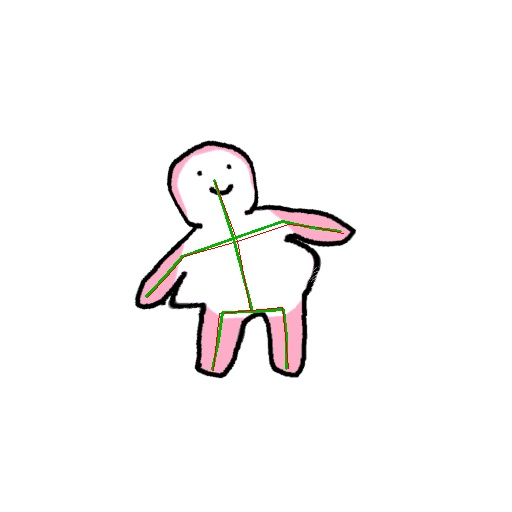

t7__bvh_dab__0_t98.jpg


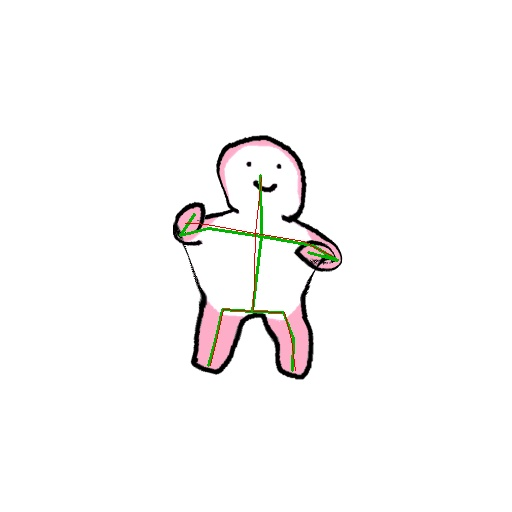

t7__bvh_elephant__0_t42.jpg


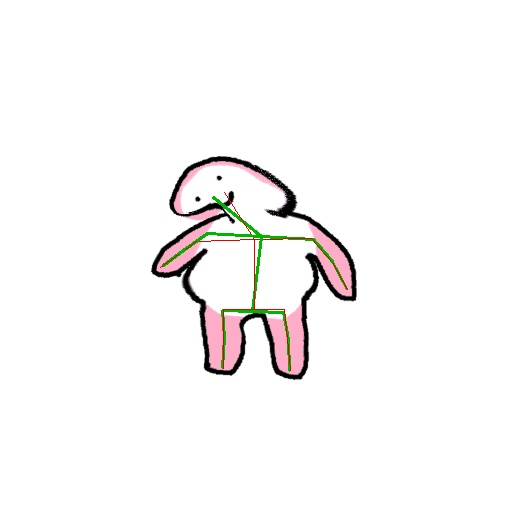

t7__bvh_happy_walk__0_t50.jpg


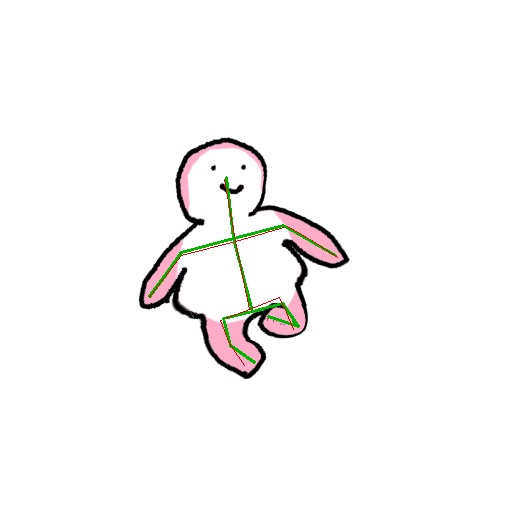

t7__bvh_idle__0_t14.jpg


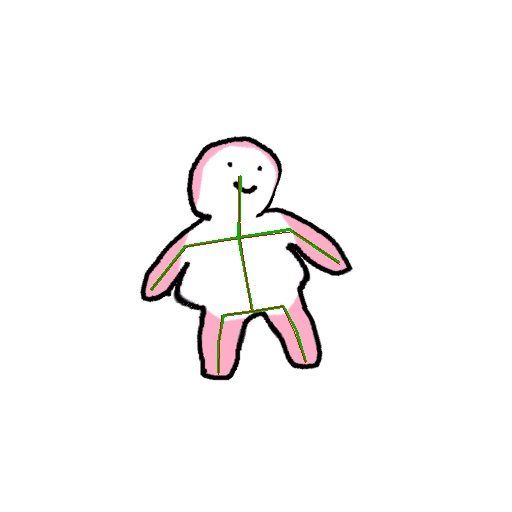

t7__bvh_jesse_dance__0_t16.jpg


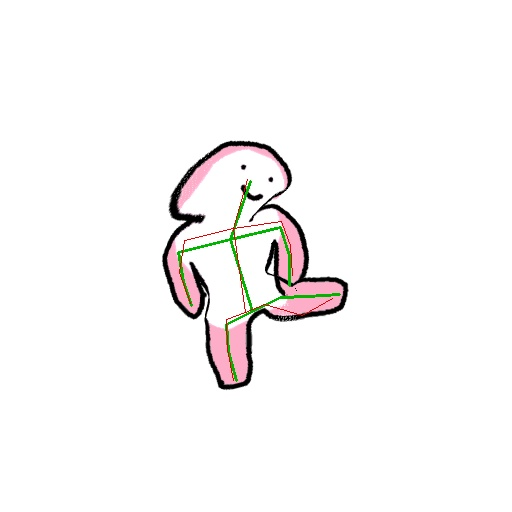

t7__bvh_jumping__0_t24.jpg


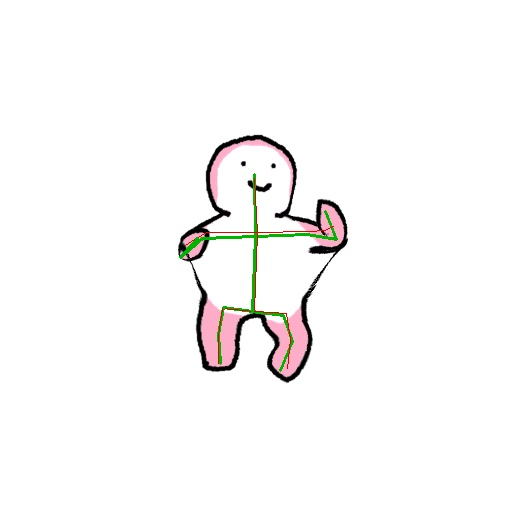

t7__bvh_jumping_jacks__0_t16.jpg


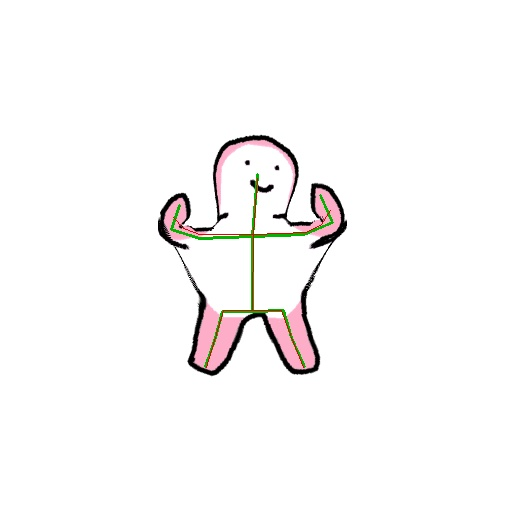

t7__bvh_kick_ball__0_t48.jpg


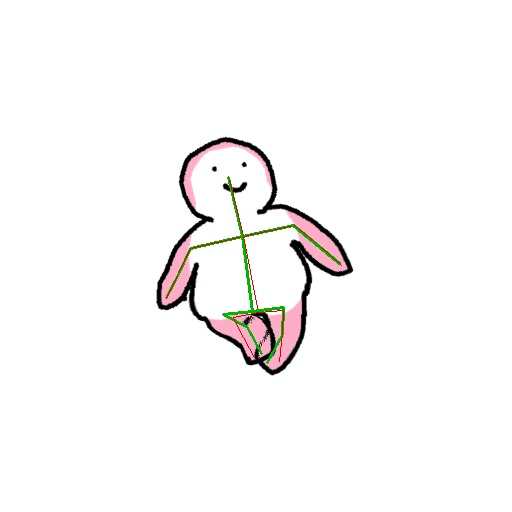

t7__bvh_laugh__0_t14.jpg


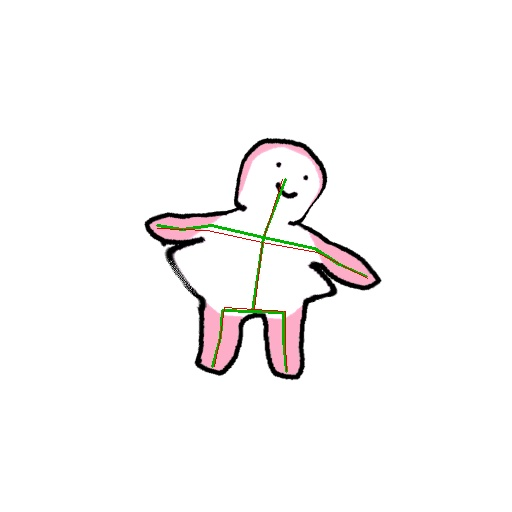

t7__bvh_march__0_t34.jpg


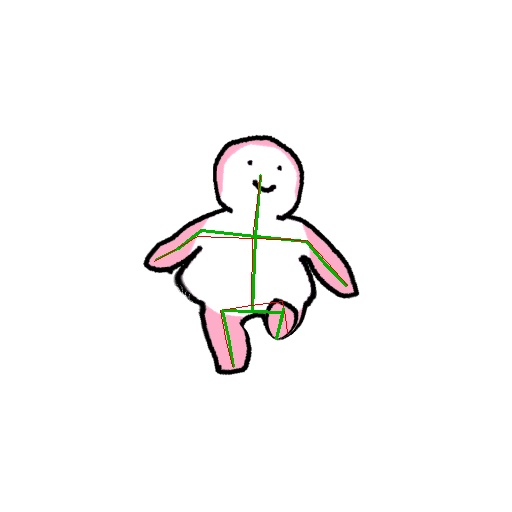

t7__bvh_monkey__0_t54.jpg


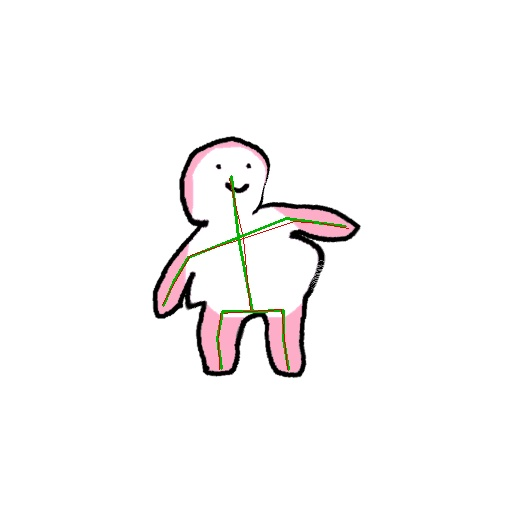

t7__bvh_point__0_t32.jpg


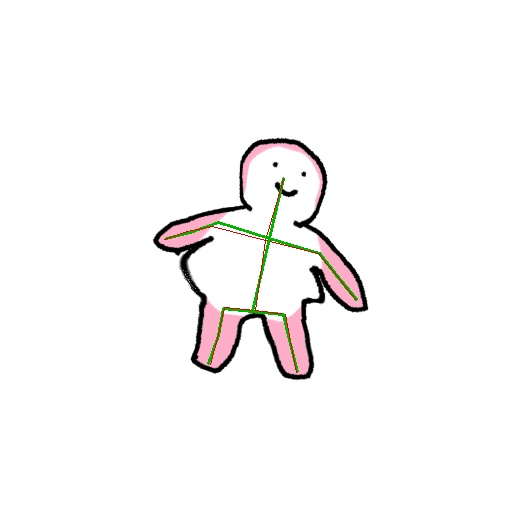

t7__bvh_reach_tiptoe__0_t20.jpg


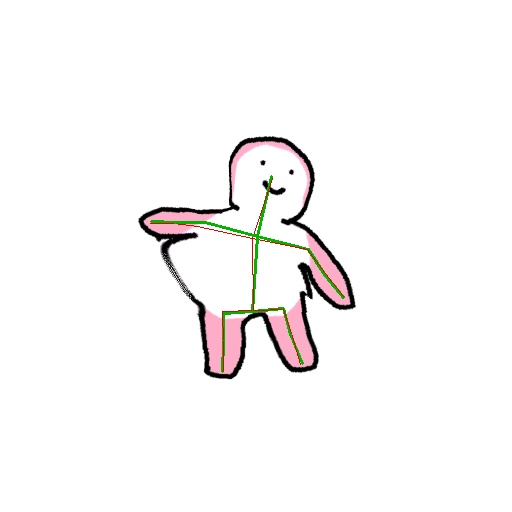

t7__bvh_sad_walk__0_t54.jpg


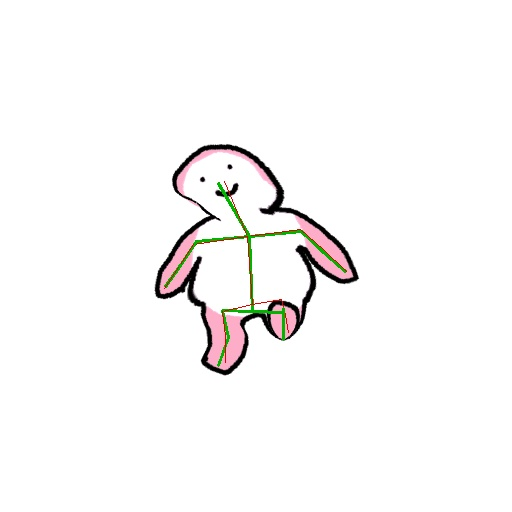

t7__bvh_search_ground__0_t24.jpg


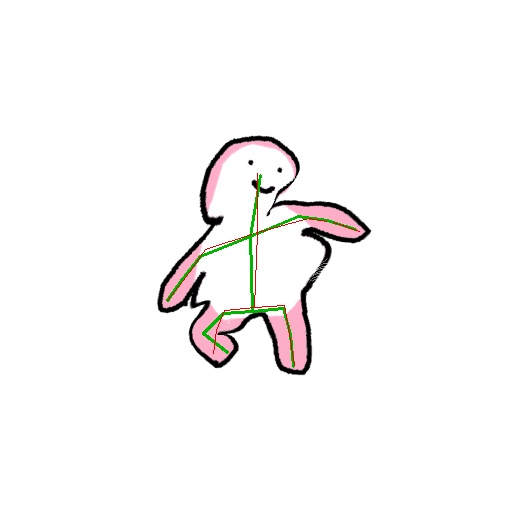

t7__bvh_stand_still__0_t24.jpg


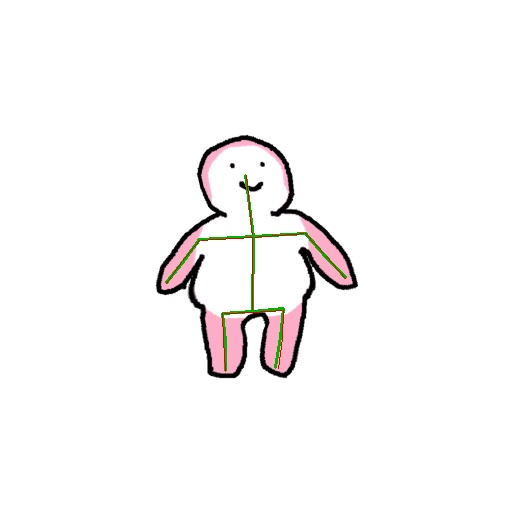

t7__bvh_swim__0_t26.jpg


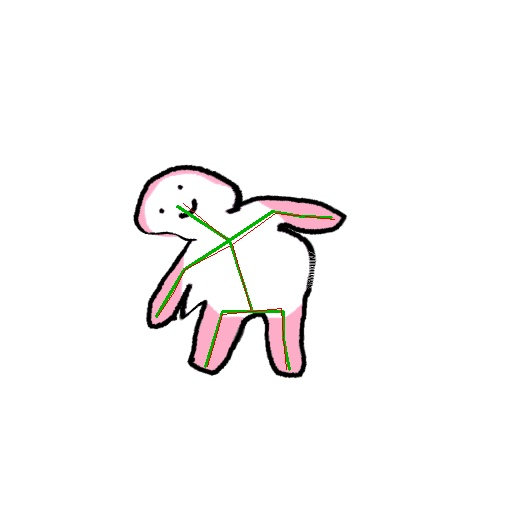

t7__bvh_very_happy__0_t24.jpg


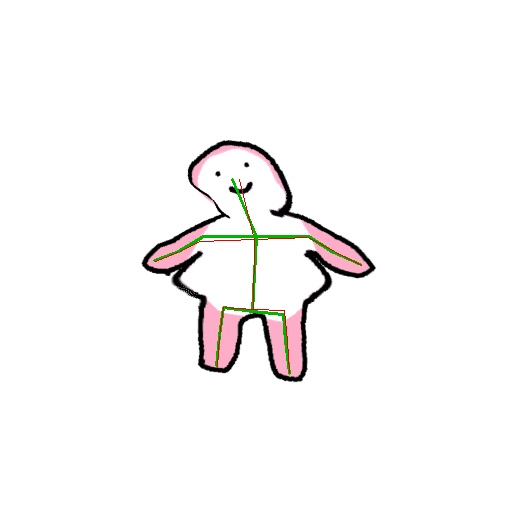

t7__bvh_wave_hello__0_t36.jpg


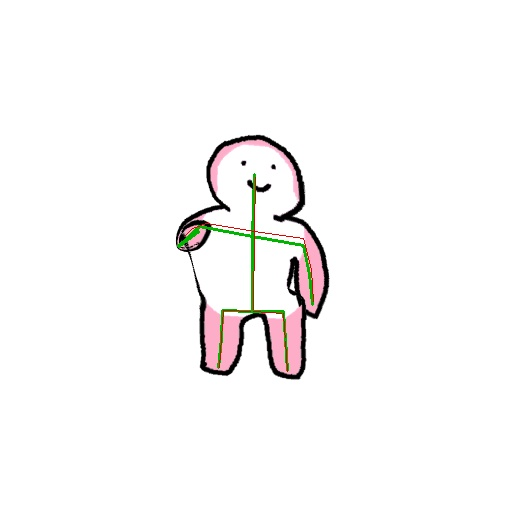

t7__bvh_zombie__0_t46.jpg


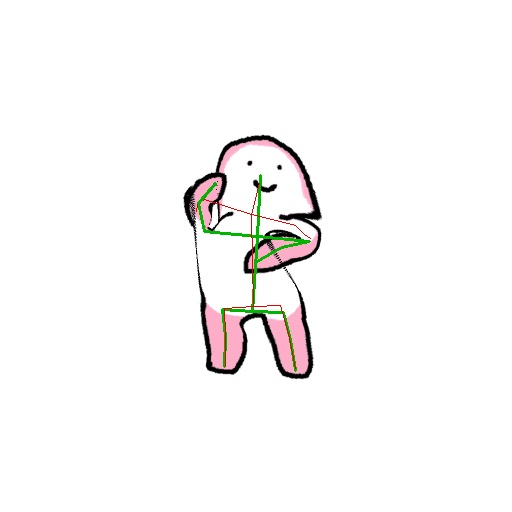

t8__bvh_bird__0_t6.jpg


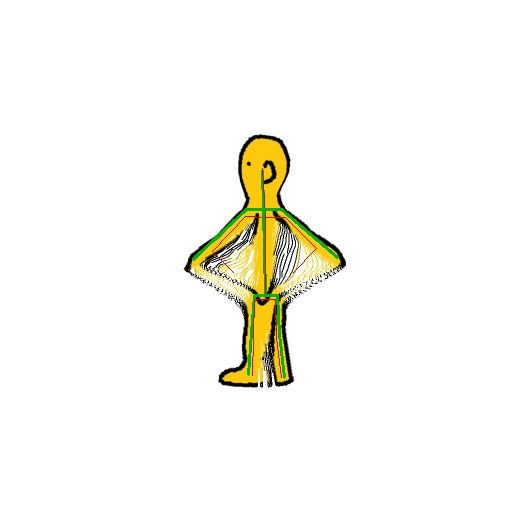

t8__bvh_dab__0_t38.jpg


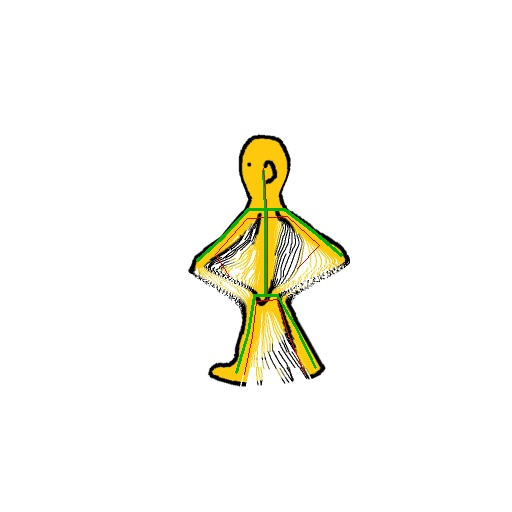

t8__bvh_elephant__0_t28.jpg


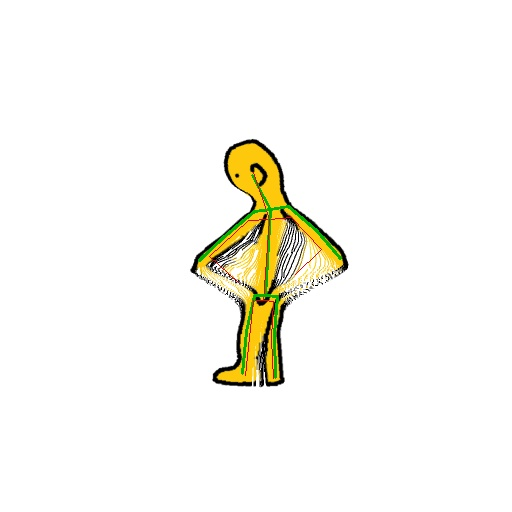

t8__bvh_happy_walk__0_t28.jpg


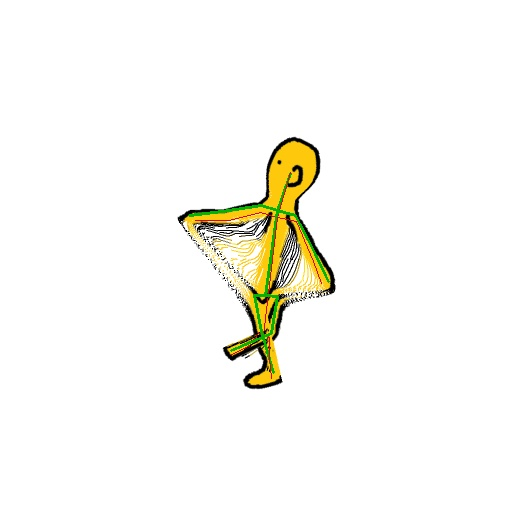

t8__bvh_idle__0_t36.jpg


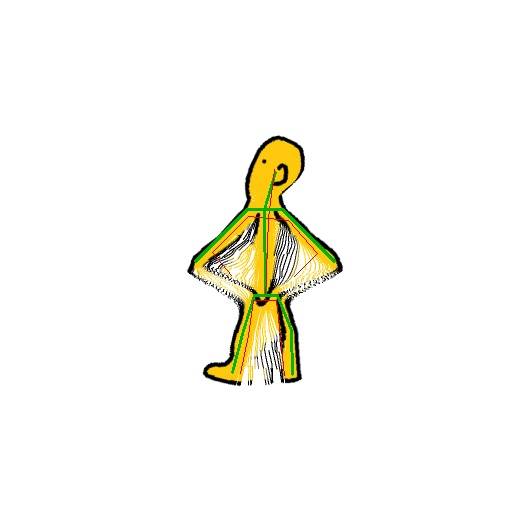

t8__bvh_jesse_dance__0_t16.jpg


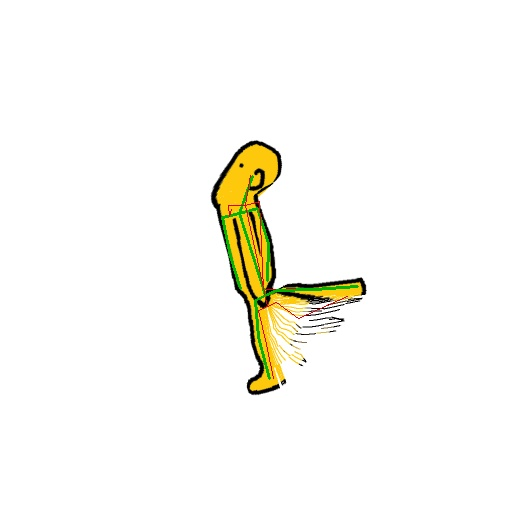

t8__bvh_jumping__0_t16.jpg


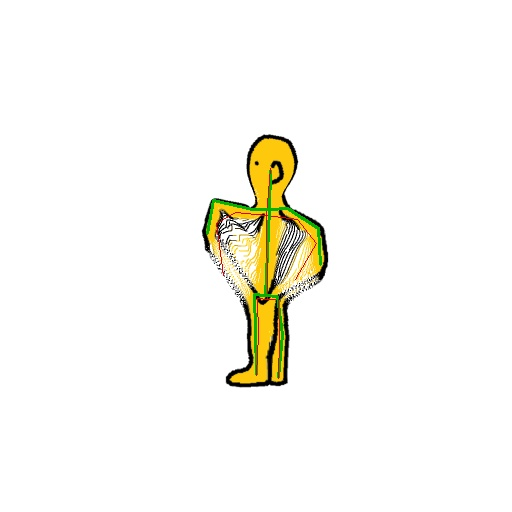

t8__bvh_jumping_jacks__0_t22.jpg


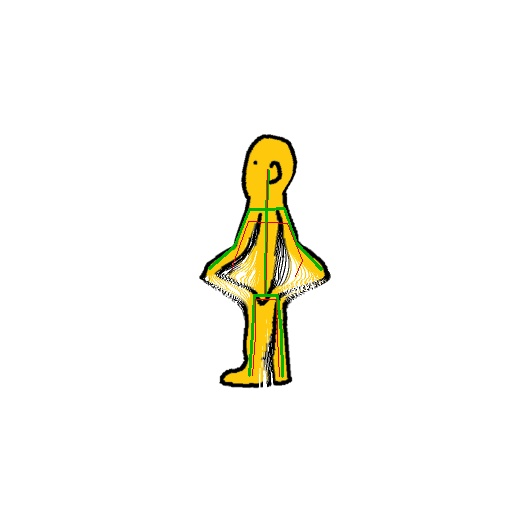

t8__bvh_kick_ball__0_t48.jpg


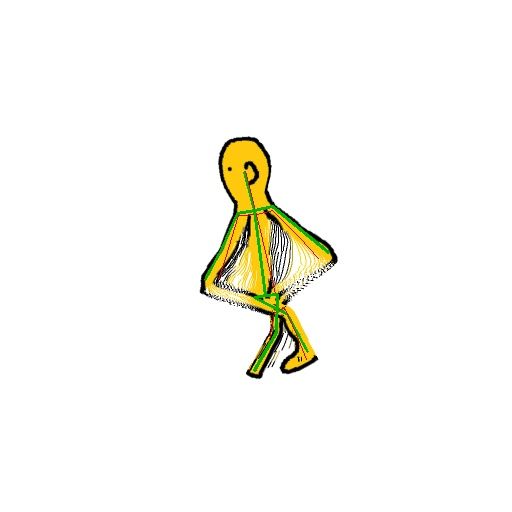

t8__bvh_laugh__0_t24.jpg


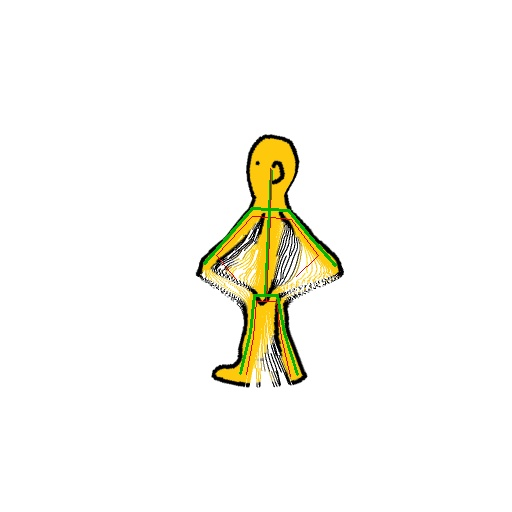

t8__bvh_march__0_t30.jpg


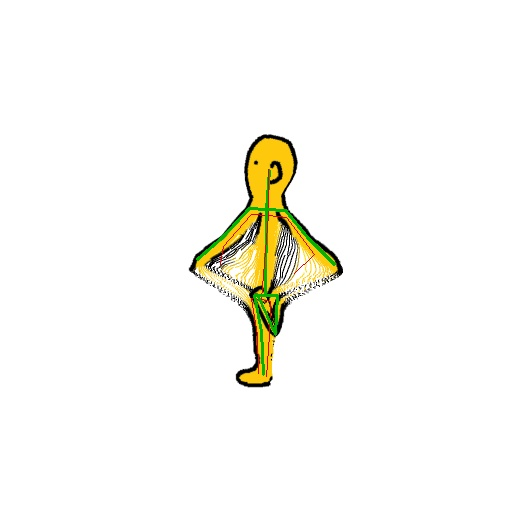

t8__bvh_monkey__0_t12.jpg


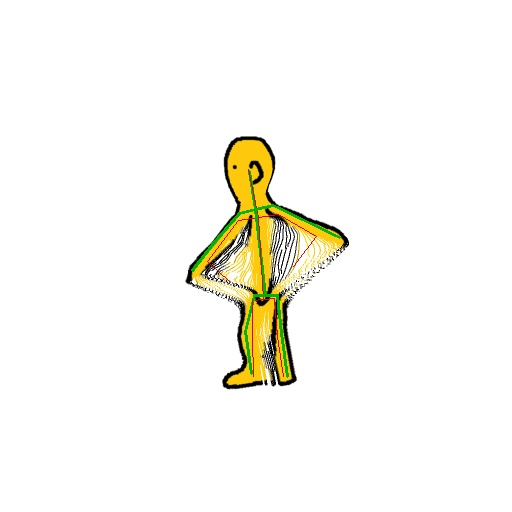

t8__bvh_point__0_t46.jpg


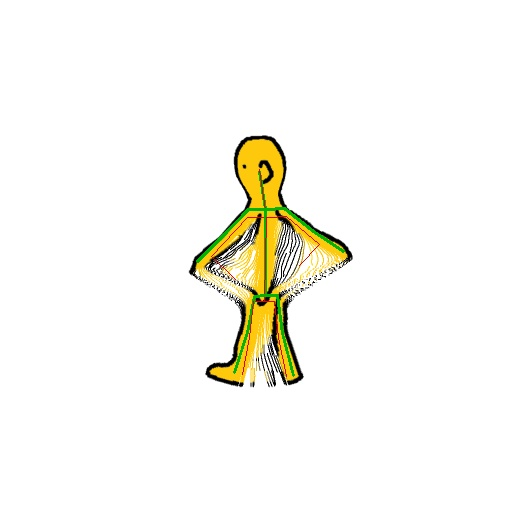

t8__bvh_reach_tiptoe__0_t4.jpg


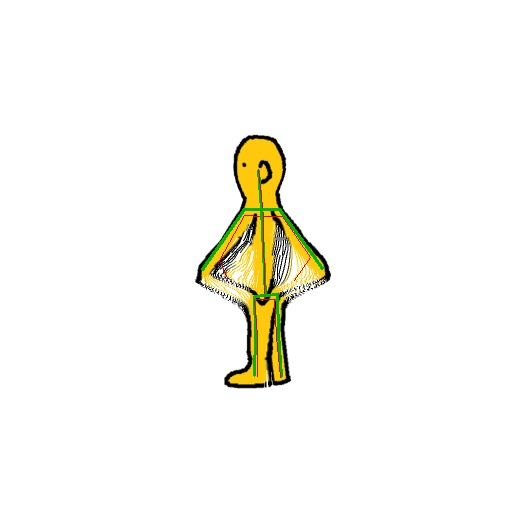

t8__bvh_sad_walk__0_t54.jpg


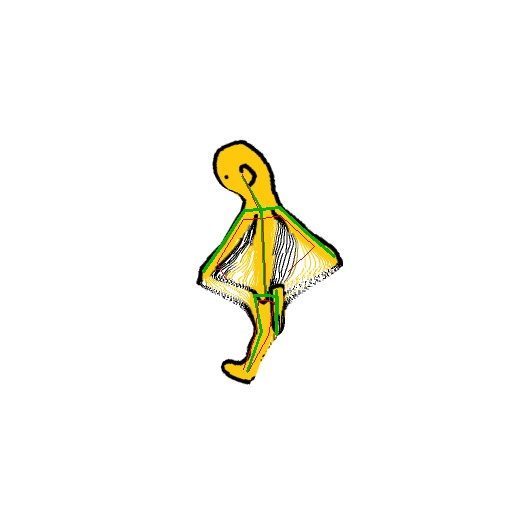

t8__bvh_search_ground__0_t10.jpg


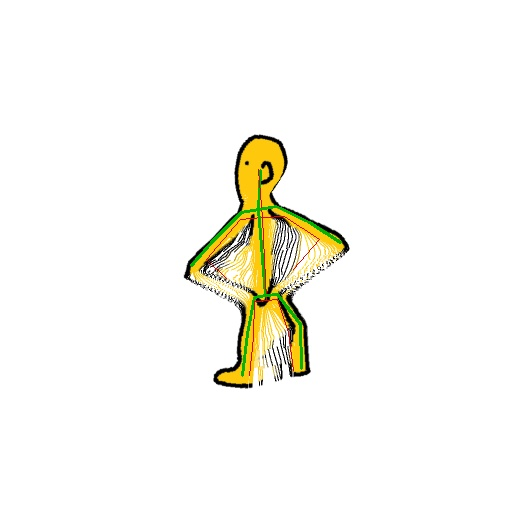

t8__bvh_stand_still__0_t38.jpg


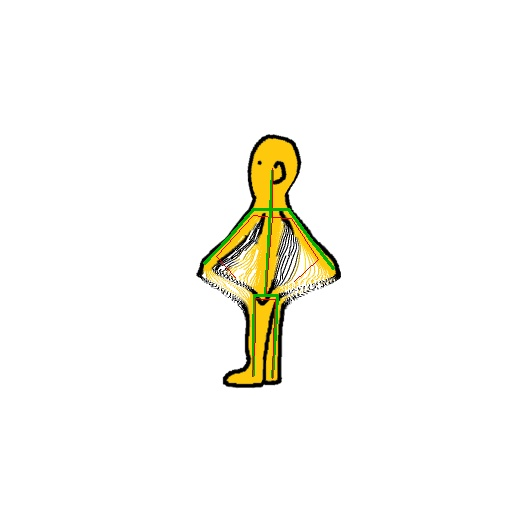

t8__bvh_swim__0_t14.jpg


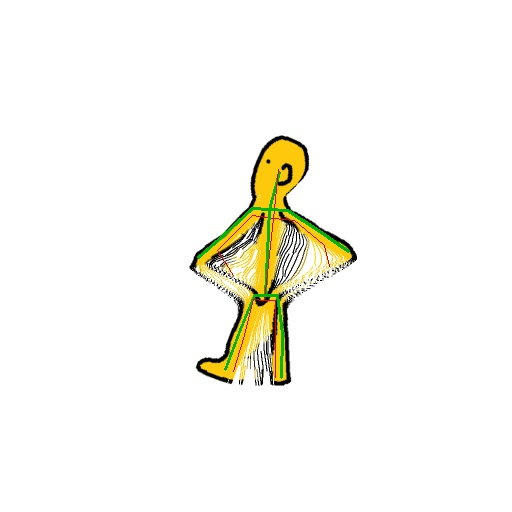

t8__bvh_very_happy__0_t38.jpg


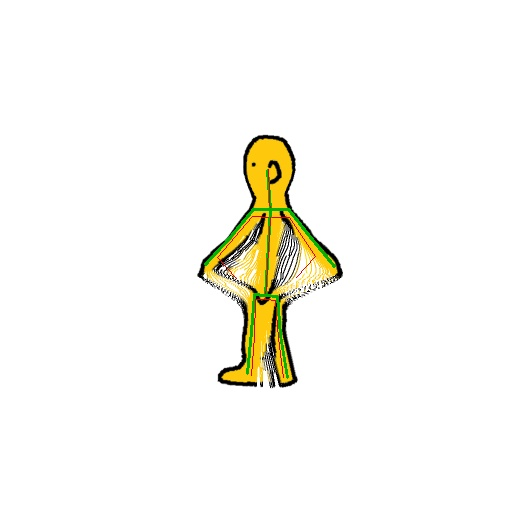

t8__bvh_wave_hello__0_t4.jpg


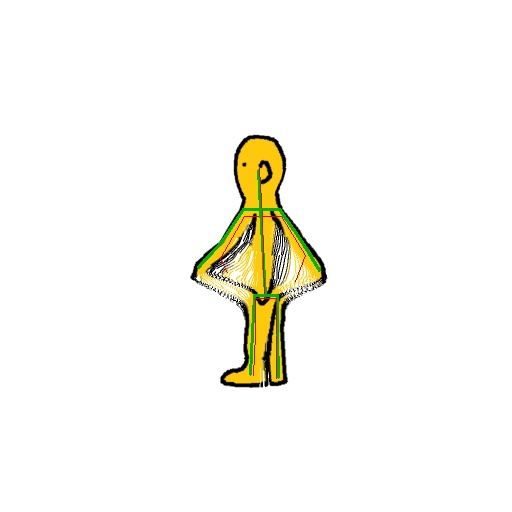

t8__bvh_zombie__0_t34.jpg


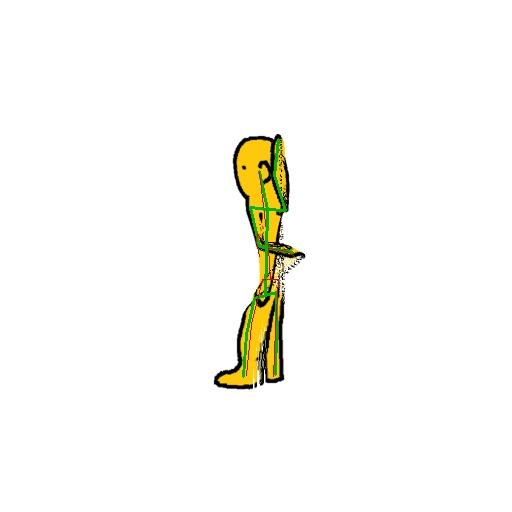

t9__bvh_bird__0_t12.jpg


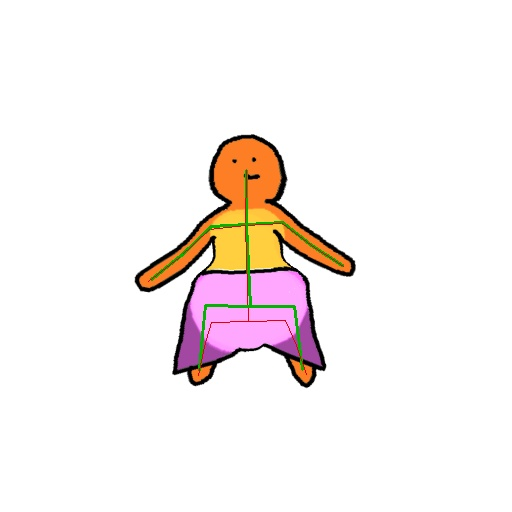

t9__bvh_dab__0_t106.jpg


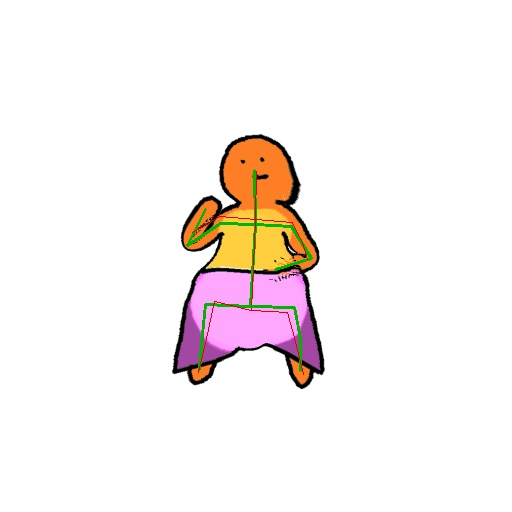

t9__bvh_elephant__0_t40.jpg


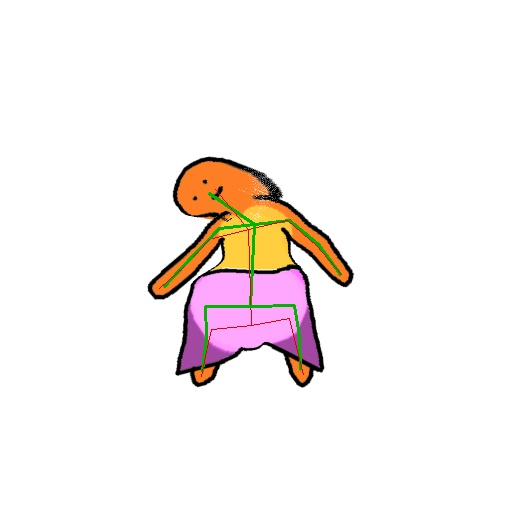

t9__bvh_happy_walk__0_t32.jpg


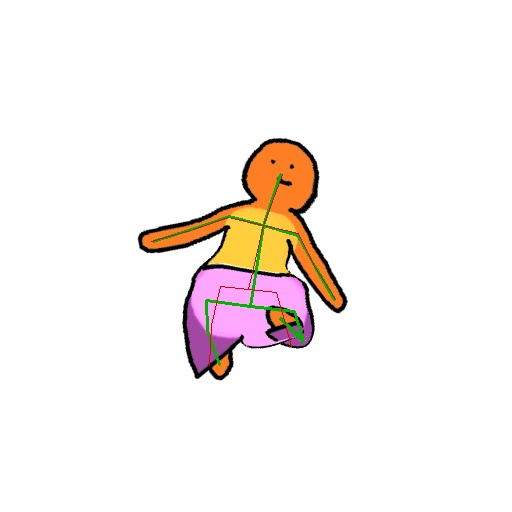

t9__bvh_idle__0_t34.jpg


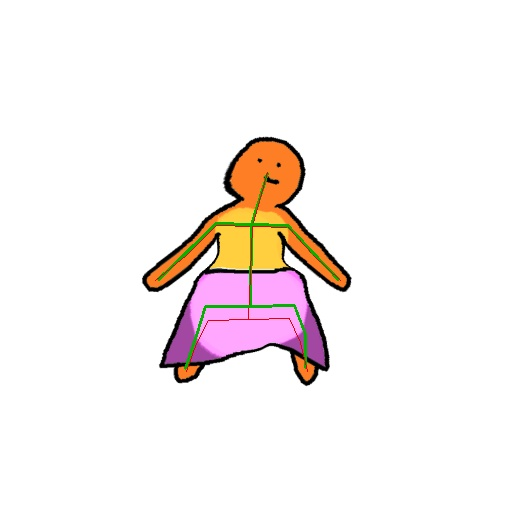

t9__bvh_jesse_dance__0_t30.jpg


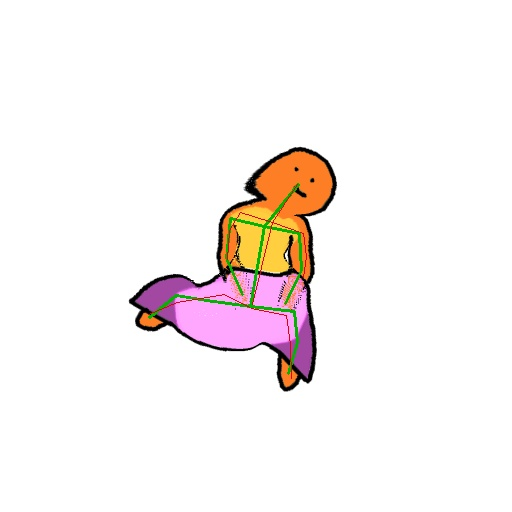

t9__bvh_jumping__0_t24.jpg


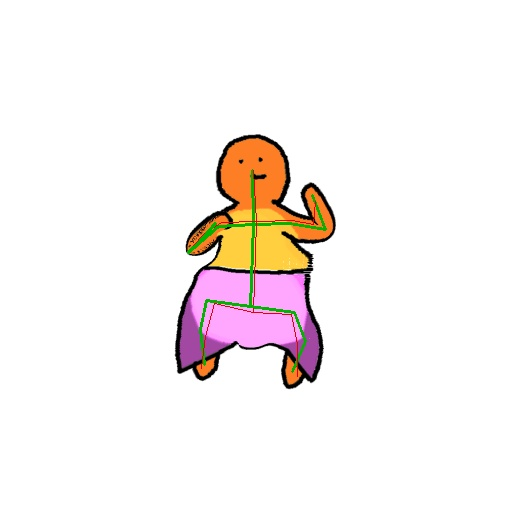

t9__bvh_jumping_jacks__0_t58.jpg


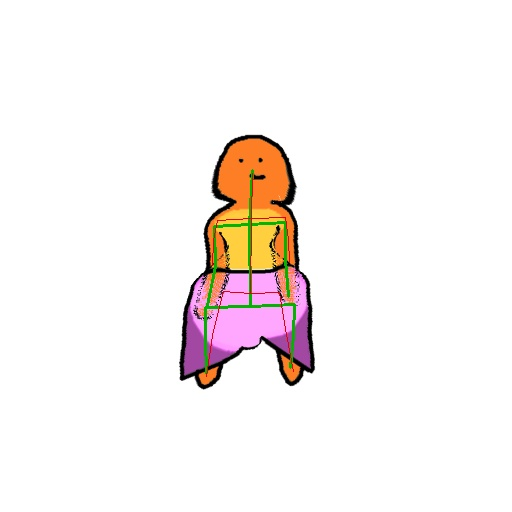

t9__bvh_kick_ball__0_t48.jpg


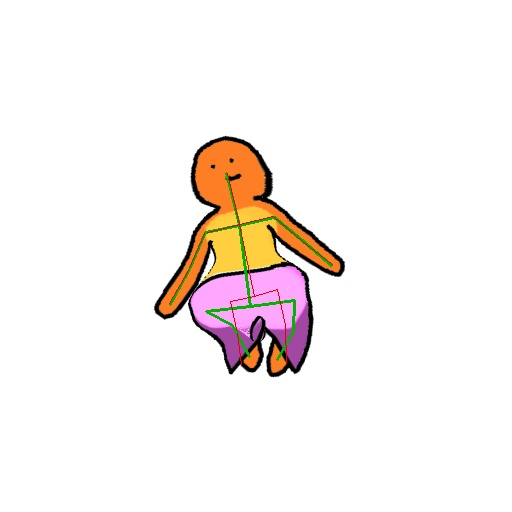

t9__bvh_laugh__0_t46.jpg


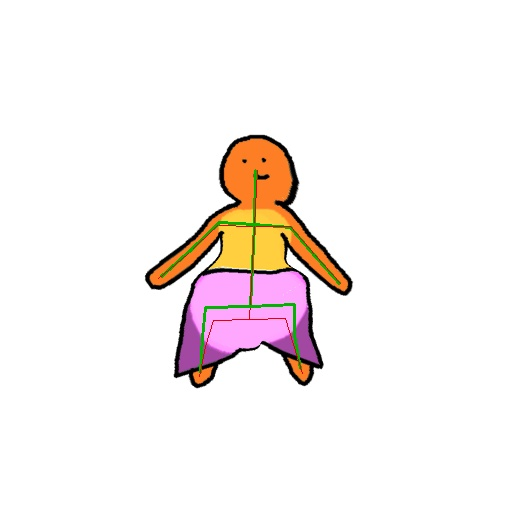

t9__bvh_march__0_t34.jpg


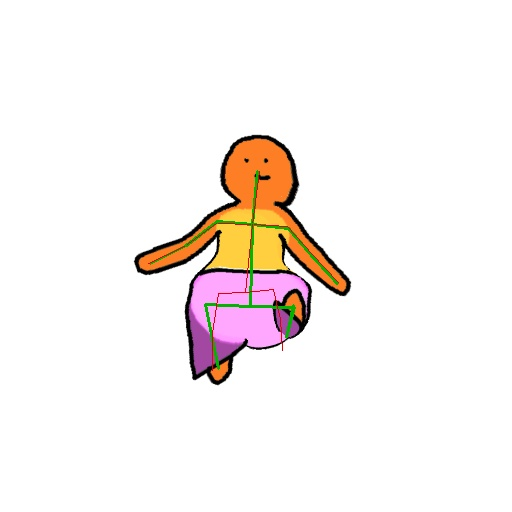

t9__bvh_monkey__0_t54.jpg


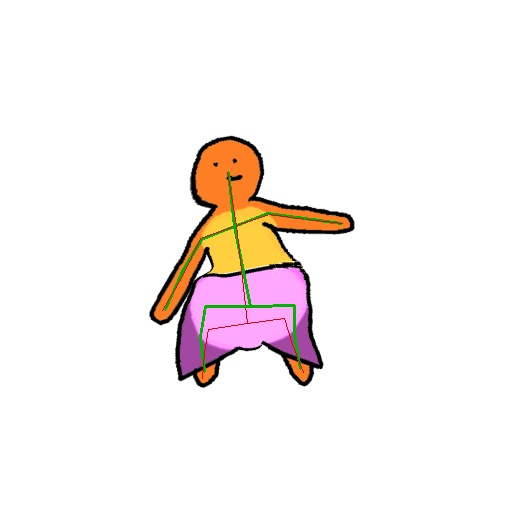

t9__bvh_point__0_t40.jpg


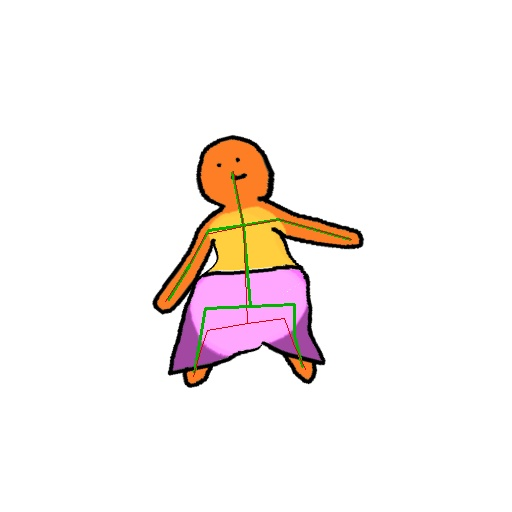

t9__bvh_reach_tiptoe__0_t20.jpg


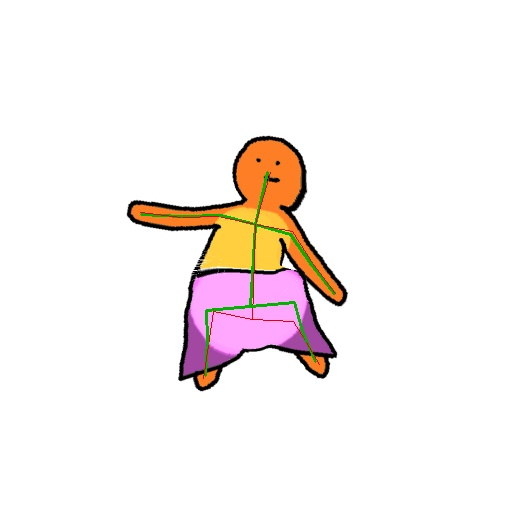

t9__bvh_sad_walk__0_t40.jpg


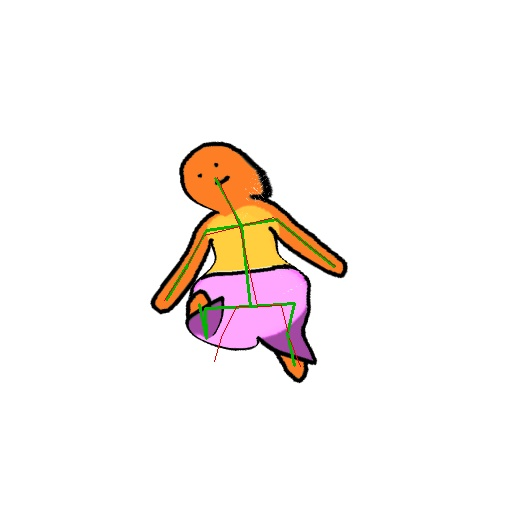

t9__bvh_search_ground__0_t52.jpg


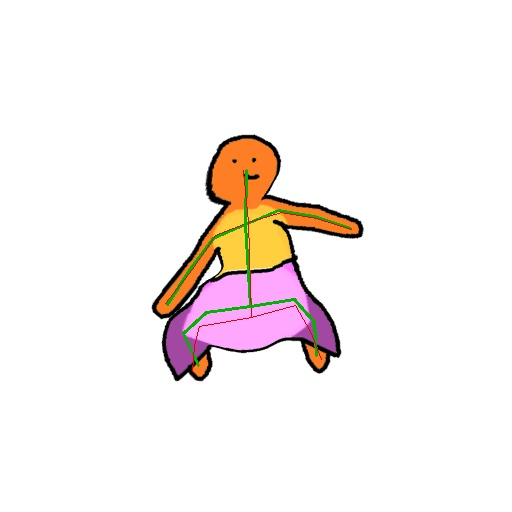

t9__bvh_stand_still__0_t10.jpg


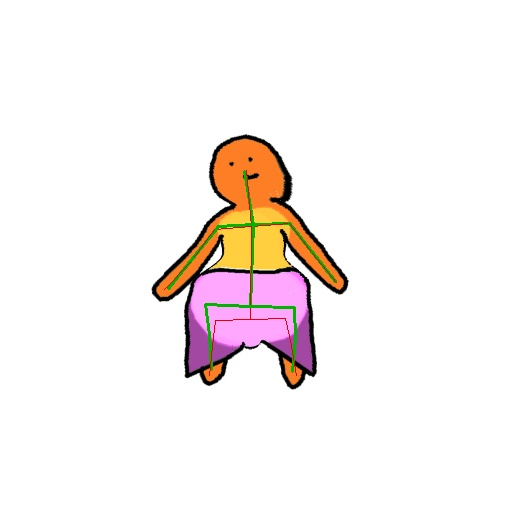

t9__bvh_swim__0_t8.jpg


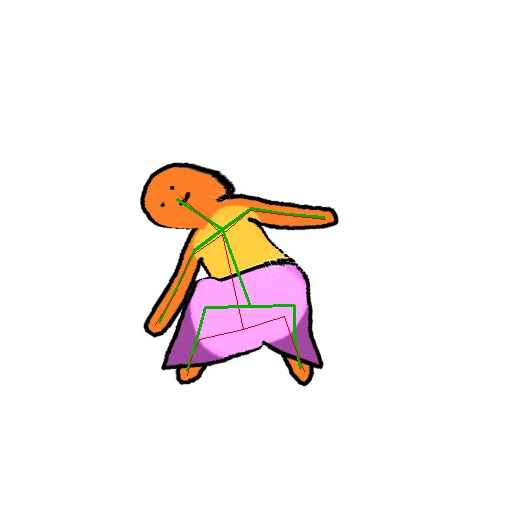

t9__bvh_very_happy__0_t32.jpg


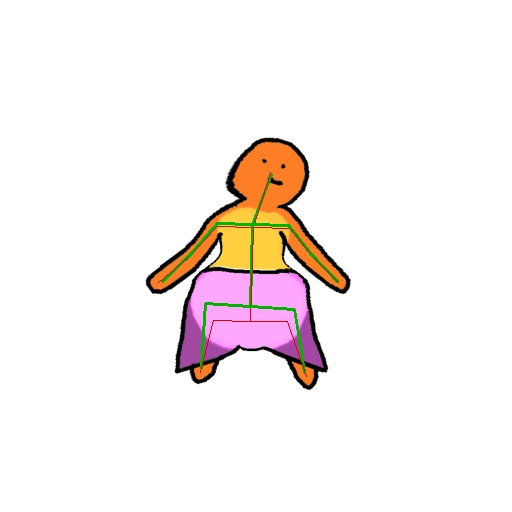

t9__bvh_wave_hello__0_t34.jpg


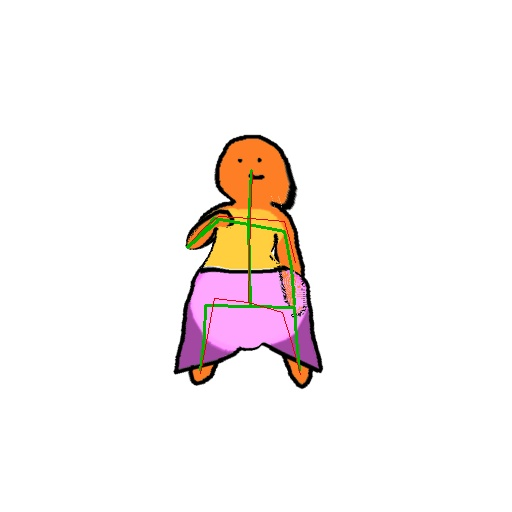

t9__bvh_zombie__0_t26.jpg


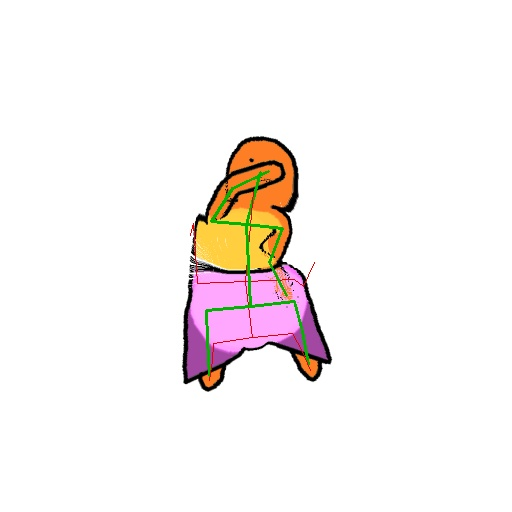

In [19]:
import json, subprocess, glob, os
import pandas as pd
from IPython.display import Image as IImage, display

EVAL_DIR = "/content/eval_motion"
STRIDE = 2           # 몇 프레임마다 측정할지 (1이면 전부, 느림)

specs = [f"{motions[i]['npy']}:{motions[i]['fps']}:{mode_tag(motions[i])}" for i in SELECT]   # 동작별 방식(rel/abs8) 포함
cmd = (PY + ["/content/eval_motion.py", SRC_DIR, EVAL_DIR] + specs + ["--stride", str(STRIDE)]
       + (["--mirror"] if MIRROR else []) + ([] if FOLLOW_ROOT else ["--no-root"]))
r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
print(r.stdout[-4000:])
if r.returncode:
    print(r.stderr[-2000:]); raise SystemExit("평가 실패")

df = pd.read_csv(f"{EVAL_DIR}/summary.csv")
df["재검출 하락"] = (df["rest_pck10"] - df["pck10"]).round(3)          # 동작 때문에 생긴 손상
display(df)
print("\n동작별 평균:")
display(df.groupby(["motion", "mode"])[["rest_pck10", "pck10", "arm_pck10", "worst_frame_pck10", "area_min", "jitter"]].mean().round(3))
print("\n전체 평균:")
display(df[["rest_pck10", "pck10", "arm_pck10", "worst_frame_pck10", "area_min", "area_max", "jitter"]].mean().round(3).to_frame("평균").T)
print("\n관절별 재검출 PCK@0.1:")
display(pd.DataFrame(json.load(open(f"{EVAL_DIR}/per_joint.json"))).T)

print("\n가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)")
for p in sorted(glob.glob(f"{EVAL_DIR}/worst/*__0_*.jpg")):
    print(os.path.basename(p)); display(IImage(p, width=360))

## 평가 2. Meta 모델(서비스 런타임) vs 우리 모델 — 교차 평가
동작을 입힌 프레임은 **관절이 어디 있어야 하는지 정확히 알기 때문에**(뼈대를 동작대로 움직인 위치) 정답 없이도 PCK를 잴 수 있다.
다만 그 정답은 **처음 뼈대를 잡은 모델의 기준**이라, 한 모델이 뼈대와 채점을 둘 다 하면 자기 자신에게 유리하다. 그래서 **뼈대 모델 × 채점 모델 = 2×2**로 교차한다.

| | 채점: Meta | 채점: 우리 |
|---|---|---|
| 뼈대: Meta | ① | ② |
| 뼈대: 우리 | ③ | ④ |

- **같은 열(같은 채점 모델) 비교** ①↔③, ②↔④ → 어느 모델로 뼈대를 잡아야 동작이 잘 따라오나
- **같은 행(같은 뼈대) 비교** ①↔②, ③↔④ → 움직인 그림에서 어느 모델이 관절을 더 잘 찾나
- 두 채점 모두에서 한쪽이 앞서면 확실한 차이. 엇갈리면 자기 편향이 큰 것 → 동작 GIF로 직접 확인
- 배경 분리는 6번 셀 결과(`my_imgs_clean`)를 네 경우 모두 똑같이 사용. 점수는 **15관절**(기존 동작 평가와 같은 기준, Meta의 목·골반은 양 어깨·양 엉덩이 가운데로 계산). 참고용으로 13관절(목·골반 제외) 점수도 함께
- Meta 모델은 TorchServe(MMPose 0.29) 대신 같은 구조·가중치를 MMPose 1.x에서 그대로 불러와 실행
- **6번 셀(그림 업로드·배경 분리)을 먼저 실행한 상태**에서 진행. 동작은 6번 셀의 `SELECT_NAMES` 그대로

### 2-1. Meta 모델 준비

In [21]:
# Meta Animated Drawings 포즈 모델 (서비스 런타임이 TorchServe로 띄우는 것과 같은 파일)
import os, zipfile, urllib.request
MAR = '/content/drawn_humanoid_pose_estimator.mar'
if not os.path.exists('/content/meta_pose/best_AP_epoch_72.pth'):
    urllib.request.urlretrieve('https://github.com/facebookresearch/AnimatedDrawings/releases/download/v0.0.1/drawn_humanoid_pose_estimator.mar', MAR)
    zipfile.ZipFile(MAR).extractall('/content/meta_pose'); os.remove(MAR)
print(sorted(os.listdir('/content/meta_pose')))

['MAR-INF', 'best_AP_epoch_72.pth', 'config.py', 'mmpose_handler.py']


In [22]:
%%writefile /content/meta_res50.py
# Meta 모델(MMPose 0.29의 TopDown + ResNet-50 + TopdownHeatmapSimpleHead)을 MMPose 1.x에서 같은 구조·설정으로 재현
# 원본 config.py 기준: 입력 192x256, 히트맵 48x64, 17관절(COCO 순서), flip_test=True, shift_heatmap=True, post_process='default'
default_scope = 'mmpose'
codec = dict(type='MSRAHeatmap', input_size=(192, 256), heatmap_size=(48, 64), sigma=2)
model = dict(
    type='TopdownPoseEstimator',
    data_preprocessor=dict(type='PoseDataPreprocessor', mean=[123.675, 116.28, 103.53], std=[58.395, 57.12, 57.375], bgr_to_rgb=True),
    backbone=dict(type='ResNet', depth=50),
    head=dict(type='HeatmapHead', in_channels=2048, out_channels=17,
              loss=dict(type='KeypointMSELoss', use_target_weight=True), decoder=codec),
    test_cfg=dict(flip_test=True, flip_mode='heatmap', shift_heatmap=True))
META = dict(from_file='/content/mmpose/configs/_base_/datasets/coco.py')
test_pipeline = [dict(type='LoadImage'), dict(type='GetBBoxCenterScale'),
                 dict(type='TopdownAffine', input_size=codec['input_size']), dict(type='PackPoseInputs')]
train_dataloader = dict(dataset=dict(type='CocoDataset', metainfo=META, pipeline=test_pipeline))
test_dataloader = dict(dataset=dict(type='CocoDataset', metainfo=META, pipeline=test_pipeline))

Writing /content/meta_res50.py


In [23]:
%%writefile /content/convert_meta.py
"""Meta 체크포인트(MMPose 0.x) → 1.x 이름으로 (keypoint_head.* → head.*), 그리고 1.x 모델에 strict 로드로 검증"""
import torch
from mmpose.apis import init_model
c = torch.load('/content/meta_pose/best_AP_epoch_72.pth', map_location='cpu')
sd = {('head.' + k[len('keypoint_head.'):] if k.startswith('keypoint_head.') else k): v for k, v in c['state_dict'].items()}
torch.save({'state_dict': sd}, '/content/meta_res50_mmpose1x.pth')
m = init_model('/content/meta_res50.py', None, device='cpu')
missing, unexpected = m.load_state_dict(sd, strict=False)
missing = [k for k in missing if 'num_batches_tracked' not in k]
assert not missing and not unexpected, f'missing {missing[:5]} | unexpected {unexpected[:5]}'
print(f'ok | 가중치 {len(sd)}개 모두 일치 | 학습 환경 기록: MMPose', c.get('meta', {}).get('mmpose_version', '?'))

Writing /content/convert_meta.py


In [24]:
# 두 모델 준비: 우리 모델 설정 복사 + Meta 모델 변환 (가중치 일치 확인)
!cp /content/drive/MyDrive/yiyagidam/deploy/drawing15_pre.py /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_pre.py
!MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/convert_meta.py

ok | 가중치 338개 모두 일치 | 학습 환경 기록: MMPose ?


### 2-2. 교차 평가 스크립트

In [25]:
%%writefile /content/eval_cross.py
"""동작 입히기 교차 평가: 뼈대(rig) 모델 × 채점(judge) 모델 = 2×2
정답 = 뼈대 모델이 그림에 잡은 관절을 동작대로 움직인 위치 (프레임마다 정확히 알고 있음)
- 같은 채점 모델끼리 비교 → 어느 모델로 뼈대를 잡아야 동작이 잘 따라오나
- 같은 뼈대끼리 비교 → 움직인 그림에서 어느 모델이 관절을 더 잘 찾나
배경 분리 결과(그림 폴더)는 네 경우 모두 같은 그림. 점수는 15관절 (Meta의 목·골반은 양 어깨·양 엉덩이 가운데로 계산), 참고용 13관절 점수도 함께
사용: python eval_cross.py <그림 폴더> <출력 폴더> <npy:fps:mode> [...] [--stride N] [--no-root] [--mirror] [--ours NAME]"""
import os, sys, glob, json, csv
os.environ.setdefault('MPLBACKEND', 'Agg')
import cv2
import numpy as np
sys.path.insert(0, '/content')
import animate_drawing as ad
import eval_motion as em
from mmpose.apis import init_model, inference_topdown

D = '/content/drive/MyDrive/yiyagidam'
C = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/'
J15 = em.J15
ORIG13 = [i for i in range(15) if i not in (1, 8)]
ARMS = [3, 4, 6, 7]
C17 = dict(nose=0, l_sho=5, r_sho=6, l_elb=7, r_elb=8, l_wri=9, r_wri=10, l_hip=11, r_hip=12, l_knee=13, r_knee=14, l_ank=15, r_ank=16)


def to15(k):
    """Meta COCO 17관절 → 우리 15관절 (목 = 양 어깨 중점, 골반 = 양 엉덩이 중점)"""
    g = lambda n: k[C17[n]]
    return np.stack([g('nose'), (g('l_sho') + g('r_sho')) / 2, g('r_sho'), g('r_elb'), g('r_wri'), g('l_sho'), g('l_elb'), g('l_wri'),
                     (g('l_hip') + g('r_hip')) / 2, g('r_hip'), g('r_knee'), g('r_ank'), g('l_hip'), g('l_knee'), g('l_ank')])


def infer15(name, model, img, box):
    r = inference_topdown(model, img, bboxes=np.array([box], np.float32), bbox_format='xyxy')[0]
    k = np.asarray(r.pred_instances.keypoints[0], float)
    return to15(k) if name == 'meta' else k


def judge_box(frame, bg):
    """채점용 사람 영역: 프레임의 그림 픽셀 범위 + 10% (평가 스크립트의 재검출과 같은 방식)"""
    m = em.ink(frame, bg).astype(np.uint8)
    if m.sum() == 0:
        return None, None
    x, y, w, h = cv2.boundingRect(m)
    p = int(max(w, h) * 0.1)
    box = [max(0, x - p), max(0, y - p), min(frame.shape[1], x + w + p), min(frame.shape[0], y + h + p)]
    return box, max(box[2] - box[0], box[3] - box[1])


def main():
    args = sys.argv[1:]
    flags = {a for a in args if a.startswith('--')}
    opt = lambda k, d: (args.pop(args.index(k) + 1), args.remove(k))[0] if k in args else d
    stride = int(opt('--stride', 2)); ours = opt('--ours', 'drawing15_pre')
    flags = {a for a in args if a.startswith('--')}
    pos_args = [a for a in args if not a.startswith('--')]
    src, dst, seqs = pos_args[0], pos_args[1], pos_args[2:]
    os.makedirs(dst, exist_ok=True)
    dev = ad.DEV
    models = {'meta': init_model('/content/meta_res50.py', '/content/meta_res50_mmpose1x.pth', device=dev),
              'ours': init_model(C + f'{ours}.py', f'{D}/deploy/rtmpose-m_{ours}.pth', device=dev)}
    files = sorted(f for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG') for f in glob.glob(os.path.join(src, e)))
    if not files:
        sys.exit(f'평가할 그림이 없음: {src}')
    rows, jerr = [], {}
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        img = cv2.imread(f); h, w = img.shape[:2]
        for rig in models:
            kp = infer15(rig, models[rig], img, [0, 0, w, h])            # 뼈대: 그림 전체를 사람 영역으로 (동작 입히기와 같음)
            for spec in seqs:
                parts = spec.split(':'); npy = parts[0]
                mode = parts[2] if len(parts) > 2 else ('rel' if '--relative' in flags else 'abs0')
                relative = mode == 'rel'; blend_in = 0 if relative else int(mode[3:] or 0)
                motion = os.path.splitext(os.path.basename(npy))[0]
                seq = ad.smooth_seq(np.load(npy))
                rest_frame, rest, fr, bg = em.frames_for(img, kp, seq, relative, '--no-root' not in flags,
                                                         '--mirror' in flags, stride, blend_in)
                base_area = max(em.ink(rest_frame, bg).sum(), 1)
                areas = [em.ink(x, bg).sum() / base_area for _, x, _ in fr]
                boxes = [judge_box(x, bg) for _, x, _ in fr]; b0, s0 = judge_box(rest_frame, bg)
                for judge in models:
                    e0 = np.linalg.norm(infer15(judge, models[judge], rest_frame, b0) - rest, axis=1) / s0
                    E = []
                    for (t, frame, pos), (b, s) in zip(fr, boxes):
                        E.append(np.full(15, np.nan) if b is None else np.linalg.norm(infer15(judge, models[judge], frame, b) - pos, axis=1) / s)
                    E = np.array(E)
                    e13 = E[:, ORIG13]
                    row = dict(image=name, motion=motion, rig=rig, judge=judge, frames=len(fr), mode=mode,
                               rest_pck10=round(float(np.mean(e0 < 0.1)), 3),
                               pck05=round(float(np.nanmean(E < 0.05)), 3), pck10=round(float(np.nanmean(E < 0.1)), 3),
                               arm_pck10=round(float(np.nanmean(E[:, ARMS] < 0.1)), 3),
                               worst_frame_pck10=round(float(np.nanmin(np.nanmean(E < 0.1, axis=1))), 3),
                               pck10_13=round(float(np.nanmean(e13 < 0.1)), 3),          # 참고: 13관절 (목·골반 제외)
                               area_min=round(float(np.min(areas)), 3))
                    rows.append(row)
                    for j in range(15):
                        jerr.setdefault(f'{rig}|{judge}', {}).setdefault(J15[j], []).extend((E[:, j][~np.isnan(E[:, j])] < 0.1).tolist())
                    print(f"{name} | {motion} | 뼈대 {rig:4s} 채점 {judge:4s} | PCK@0.1 {row['pck10']:.2f} (움직이기 전 {row['rest_pck10']:.2f}) | 팔 {row['arm_pck10']:.2f} | 최악 {row['worst_frame_pck10']:.2f}", flush=True)
    with open(f'{dst}/cross_summary.csv', 'w', newline='', encoding='utf-8-sig') as fo:
        wr = csv.DictWriter(fo, fieldnames=list(rows[0])); wr.writeheader(); wr.writerows(rows)
    json.dump({k: {j: round(float(np.mean(v)), 3) for j, v in d.items()} for k, d in jerr.items()},
              open(f'{dst}/cross_per_joint.json', 'w'), ensure_ascii=False, indent=1)
    print('\n=== 2×2 평균 (행 = 뼈대, 열 = 채점) ===')
    for m in ('pck10', 'arm_pck10', 'worst_frame_pck10'):
        print(f'[{m}]          채점 meta   채점 ours')
        for rig in models:
            v = [np.mean([r[m] for r in rows if r['rig'] == rig and r['judge'] == j]) for j in models]
            print(f'  뼈대 {rig:4s}      {v[0]:.3f}      {v[1]:.3f}')


if __name__ == '__main__':
    main()

Writing /content/eval_cross.py


### 2-3. 실행 + 결과
동작 21개(기존 6 + 서비스 15) × 4조합. 그림 12장 기준 L4에서 약 1~1.5시간 (그림 수에 비례). 처음엔 6번의 `SELECT_NAMES`를 2~3개로 줄여 짧게 돌려 보기를 권장.
결과는 Drive `cross_summary_meta_vs_pre.csv`에도 저장.

In [26]:
import subprocess, pandas as pd, json, shutil
CROSS_DIR = "/content/eval_cross"
STRIDE = 5           # 몇 프레임마다 채점할지 (동작 21개 × 4조합이라 간격을 넓힘)
specs = [f"{motions[i]['npy']}:{motions[i]['fps']}:{mode_tag(motions[i])}" for i in SELECT]
cmd = (PY + ["/content/eval_cross.py", SRC_DIR, CROSS_DIR] + specs + ["--stride", str(STRIDE), "--ours", "drawing15_pre"]
       + (["--mirror"] if MIRROR else []) + ([] if FOLLOW_ROOT else ["--no-root"]))
r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
print(r.stdout[-3000:])
if r.returncode:
    print(r.stderr[-2000:]); raise SystemExit("교차 평가 실패")
shutil.copy(f"{CROSS_DIR}/cross_summary.csv", "/content/drive/MyDrive/yiyagidam/cross_summary_meta_vs_pre.csv")

df = pd.read_csv(f"{CROSS_DIR}/cross_summary.csv")
for m, title in (("pck10", "재검출 PCK@0.1 (15관절)"), ("pck10_13", "참고: 재검출 PCK@0.1 (13관절, 목·골반 제외)"), ("arm_pck10", "팔 관절 PCK@0.1"), ("worst_frame_pck10", "최악 프레임 PCK@0.1")):
    print(f"\n{title}  — 행 = 뼈대 모델, 열 = 채점 모델")
    display(df.pivot_table(index="rig", columns="judge", values=m, aggfunc="mean").round(3))
print("\n동작별 PCK@0.1")
display(df.pivot_table(index=["motion", "rig"], columns="judge", values="pck10", aggfunc="mean").round(3))
print("\n관절별 PCK@0.1 (열 = 뼈대|채점)")
display(pd.DataFrame(json.load(open(f"{CROSS_DIR}/cross_per_joint.json"))).round(3))

뼈대 ours 채점 meta | PCK@0.1 0.91 (움직이기 전 1.00) | 팔 0.76 | 최악 0.27
t9 | bvh_zombie | 뼈대 ours 채점 ours | PCK@0.1 0.91 (움직이기 전 1.00) | 팔 0.77 | 최악 0.47
t9 | bvh_bird | 뼈대 ours 채점 meta | PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 1.00
t9 | bvh_bird | 뼈대 ours 채점 ours | PCK@0.1 0.99 (움직이기 전 1.00) | 팔 1.00 | 최악 0.93
t9 | bvh_elephant | 뼈대 ours 채점 meta | PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 1.00
t9 | bvh_elephant | 뼈대 ours 채점 ours | PCK@0.1 0.95 (움직이기 전 1.00) | 팔 1.00 | 최악 0.80
t9 | bvh_happy_walk | 뼈대 ours 채점 meta | PCK@0.1 0.99 (움직이기 전 1.00) | 팔 1.00 | 최악 0.93
t9 | bvh_happy_walk | 뼈대 ours 채점 ours | PCK@0.1 0.98 (움직이기 전 1.00) | 팔 1.00 | 최악 0.93
t9 | bvh_idle | 뼈대 ours 채점 meta | PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 1.00
t9 | bvh_idle | 뼈대 ours 채점 ours | PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 1.00
t9 | bvh_kick_ball | 뼈대 ours 채점 meta | PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 1.00
t9 | bvh_kick_ball | 뼈대 ours 채점 ours | PCK@0.1 0.96 (움직이기 전 1.00) | 팔 1.00 | 최악 0.87
t9 | bvh_laugh | 뼈대 ours

judge,meta,ours
rig,,
meta,0.944,0.959
ours,0.938,0.971



참고: 재검출 PCK@0.1 (13관절, 목·골반 제외)  — 행 = 뼈대 모델, 열 = 채점 모델


judge,meta,ours
rig,,
meta,0.941,0.956
ours,0.936,0.971



팔 관절 PCK@0.1  — 행 = 뼈대 모델, 열 = 채점 모델


judge,meta,ours
rig,,
meta,0.908,0.937
ours,0.908,0.954


... (2 outputs left out)


동작별 PCK@0.1


judge                    meta   ours
motion            rig               
bvh_bird          meta  0.961  0.971
                  ours  0.957  0.986
bvh_dab           meta  0.930  0.957
                  ours  0.917  0.964
bvh_elephant      meta  0.949  0.954
                  ours  0.946  0.970
bvh_happy_walk    meta  0.938  0.952
                  ours  0.935  0.963
bvh_idle          meta  0.958  0.964
                  ours  0.954  0.981
bvh_jesse_dance   meta  0.845  0.930
                  ours  0.833  0.935
bvh_jumping       meta  0.958  0.967
                  ours  0.947  0.974
bvh_jumping_jacks meta  0.949  0.964
                  ours  0.936  0.973
bvh_kick_ball     meta  0.952  0.964
                  ours  0.949  0.974
bvh_laugh         meta  0.962  0.973
                  ours  0.961  0.983
bvh_march         meta  0.920  0.940
                  ours  0.919  0.956
bvh_monkey        meta  0.959  0.970
                  ours  0.955  0.982
bvh_point         meta  0.960  0.966
                  ours  0.959  0.981
bvh_reach_tiptoe  meta  0.966  0.970
                  ours  0.960  0.986
bvh_sad_walk      meta  0.920  0.930
                  ours  0.916  0.951
bvh_search_ground meta  0.957  0.973
                  ours  0.952  0.984
bvh_stand_still   meta  0.956  0.965
                  ours  0.952  0.973
bvh_swim          meta  0.952  0.958
                  ours  0.947  0.972
bvh_very_happy    meta  0.957  0.968
                  ours  0.954  0.980
bvh_wave_hello    meta  0.954  0.963
                  ours  0.941  0.974
bvh_zombie        meta  0.919  0.936
                  ours  0.901  0.943


관절별 PCK@0.1 (열 = 뼈대|채점)


,meta|meta,meta|ours,ours|meta,ours|ours
nose,0.916,0.924,0.913,0.950
neck,0.936,0.970,0.914,0.953
r_sho,0.937,0.964,0.919,0.959
r_elb,0.923,0.950,0.924,0.960
r_wri,0.847,0.884,0.862,0.908
l_sho,0.926,0.953,0.911,0.950
l_elb,0.887,0.936,0.873,0.941
l_wri,0.857,0.894,0.830,0.899
pelvis,0.977,0.977,0.962,0.974
r_hip,0.976,0.984,0.960,0.994
